## 🛡️ 0. Configuration

### 🎛️ 6 Selectable Operating Modes:
1. `DATASET_ONLY`: Forensic evaluation of the dataset without a trained model (frozen ImageNet feature extraction and bivariate/spectral clustering).
2. `MODEL_ONLY`: Data-free evaluation of the neural network weights (UCLC Lipschitz, AM prototypes, Zhu & Cangelosi 2025, ETF Neural Collapse).
3. `BLIND_AUDIT`: Joint blind audit of model + dataset without knowing whether or which samples or classes are compromised (Neural Cleanse MAD, ABS, TABOR, AC, Spectral Signatures, SentiNet, BYE, Captum).
4. `ATTACKER_IMAGE_LEVEL`: Verification of the stealthiness and perceptual/spectral distortion of the trigger on image pairs (SSIM, PSNR, LPIPS, $L_0/L_2/L_\infty$, FFT 2D).
5. `ATTACKER_MODEL_LEVEL`: Complete post-training evaluation of the white-box attacker (ASR, CDA, Drop, Grad-CAM, RISE, TAC, FCT, Latency, defense evasion).


In [1]:
# ============================================================
# 1. ENVIRONMENT, HARDWARE & REPRODUCIBILITY CONFIGURATION
# ============================================================

!pip install -q sympy==1.12
!pip install -q torchview
!pip install -q protobuf==3.20.*
!pip install -q tensorboard


SEED = 42  # Deterministic global seed for reproducibility

import os
# Prevent CUDA memory fragmentation on PyTorch (avoids false OOM on heavy models such as ResNet-50 at 64x64/224x224)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import random
import warnings
import logging
import gc
import psutil
import math
import copy
import shutil
from itertools import product

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import rgb_to_hsv
from PIL import Image
from tqdm import tqdm
import cv2

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader, ConcatDataset
from torch.utils.tensorboard import SummaryWriter
from torchsummary import summary
import torchvision
from torchvision import models
from torchvision.transforms import v2 as transforms
from torchvision.transforms import InterpolationMode
from torchview import draw_graph

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split

# Environment variable and warning settings
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["MPLCONFIGDIR"] = os.getcwd() + "/configs/"
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=Warning)

# Deterministic seeds on all compute engines
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)


# Device configuration
if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
else:
    device = torch.device("cpu")

print(f"🔹 PyTorch version: {torch.__version__}")
print(f"🔹 Compute Device : {device}")

# Global graphics settings
sns.set(font_scale=1.4)
sns.set_style("white")
plt.rc("font", size=14)
%matplotlib inline

# Telemetry and models directories
logs_dir = "tensorboard"
!pkill -f tensorboard || true
!mkdir -p models
%load_ext tensorboard


# ============================================================
# UNIFIED MEMORY MANAGEMENT & GARBAGE COLLECTION MODULE
# ============================================================
def get_ram_usage():
    """Returns a string with the used RAM, the total, and the percentage."""
    try:
        mem = psutil.virtual_memory()
        used_gb = mem.used / (1024**3)
        total_gb = mem.total / (1024**3)
        return f"RAM: {used_gb:.2f}/{total_gb:.2f} GB ({mem.percent:.1f}%)"
    except Exception:
        return "RAM: N/A"


def clean_memory(*vars_to_delete, close_plots=True, verbose=False):
    """
    Unified memory deallocation and buffer cleanup function:
    1. Closes all open Matplotlib figures to release the bitmap canvases.
    2. Explicitly deletes heavy variables from globals() or locals if present.
    3. Forces the Python Garbage Collector to free memory and cyclic references.
    4. Empties the cache and the segments allocated on VRAM (CUDA).
    """
    if close_plots:
        plt.close("all")

    for var in vars_to_delete:
        if isinstance(var, str):
            if var in globals():
                try:
                    del globals()[var]
                except Exception:
                    pass
        else:
            try:
                del var
            except Exception:
                pass

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

    if verbose:
        print(f"🧹 [Memory Cleanup] {get_ram_usage()}")


# ============================================================
# UNIVERSAL ARCHITECTURAL HELPERS (FULL BACKWARD COMPATIBILITY)
# ============================================================
def get_classifier_info(net):
    """
    Dynamically and universally returns the final classifier layer,
    its attribute name, and the number of input features for any PyTorch architecture.
    """
    for name in ['fc', 'classifier', 'head', 'linear']:
        if hasattr(net, name):
            attr = getattr(net, name)
            if isinstance(attr, nn.Linear):
                return attr, name, attr.in_features
            elif isinstance(attr, nn.Sequential):
                for sub_m in reversed(attr):
                    if isinstance(sub_m, nn.Linear):
                        return sub_m, name, sub_m.in_features
    linears = [(n, m) for n, m in net.named_modules() if isinstance(m, nn.Linear)]
    if linears:
        n, m = linears[-1]
        return m, n, m.in_features
    raise ValueError("No linear classification layer identified in the model.")


def get_penultimate_conv(net):
    """
    Returns the last Conv2d layer for Grad-CAM, SentiNet, UCLC, TAC regardless of the architecture.
    """
    convs = [m for m in net.modules() if isinstance(m, nn.Conv2d)]
    if convs:
        return convs[-1]
    raise ValueError("No Conv2d layer identified in the model.")


def load_checkpoint_adaptively(model, checkpoint_weights_or_path, device=None):
    """
    Loads the weights of a checkpoint, automatically adapting:
    - Sub-dictionaries ('model_state_dict', 'state_dict', 'model') or raw dict.
    - Structure of conv1 (7x7 for 224x224 vs 3x3 for 32x32).
    - Classification head with or without Dropout ('fc.1.weight' vs 'fc.weight').
    """
    if isinstance(checkpoint_weights_or_path, str):
        if not os.path.exists(checkpoint_weights_or_path):
            raise FileNotFoundError(f"Checkpoint not found: {checkpoint_weights_or_path}")
        dev = device if device is not None else torch.device("cpu")
        raw_ckpt = torch.load(checkpoint_weights_or_path, map_location=dev, weights_only=False)
    else:
        raw_ckpt = checkpoint_weights_or_path

    # Extract clean state_dict
    if isinstance(raw_ckpt, dict):
        if "model_state_dict" in raw_ckpt:
            state_dict = raw_ckpt["model_state_dict"]
        elif "state_dict" in raw_ckpt:
            state_dict = raw_ckpt["state_dict"]
        elif "model" in raw_ckpt:
            state_dict = raw_ckpt["model"]
        else:
            state_dict = raw_ckpt
    else:
        state_dict = raw_ckpt

    # Strip DDP 'module.' prefix
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}

    # 1. Adapt conv1
    if "conv1.weight" in state_dict and hasattr(model, "conv1"):
        ckpt_conv_shape = state_dict["conv1.weight"].shape
        if model.conv1.weight.shape != ckpt_conv_shape:
            k_size = ckpt_conv_shape[2]
            stride = 2 if k_size == 7 else 1
            padding = 3 if k_size == 7 else 1
            model.conv1 = nn.Conv2d(ckpt_conv_shape[1], ckpt_conv_shape[0], kernel_size=k_size, stride=stride, padding=padding, bias=False)
            if k_size == 7 and isinstance(getattr(model, "maxpool", None), nn.Identity):
                model.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
            elif k_size == 3 and isinstance(getattr(model, "maxpool", None), nn.MaxPool2d):
                # The scratch variant of the notebook (conv1 3x3) has no maxpool: the maxpool has no
                # parameters and cannot be deduced from the checkpoint, so the build_model convention is followed.
                model.maxpool = nn.Identity()
                print("ℹ️ [CKPT] conv1 3x3 detected: maxpool replaced with Identity (build_model scratch convention).")

    # 2. Adapt the classifier (Sequential with Dropout vs Linear)
    has_dropout_seq = any(k.startswith("fc.1.") or k.startswith("classifier.1.") or k.startswith("head.1.") or k.startswith("linear.1.") for k in state_dict.keys())

    clf_module, clf_name, in_features = get_classifier_info(model)
    num_classes = state_dict["fc.1.weight"].shape[0] if has_dropout_seq and "fc.1.weight" in state_dict else (
        state_dict["fc.weight"].shape[0] if "fc.weight" in state_dict else NUM_CLASSES if "NUM_CLASSES" in globals() else 10
    )

    parts = clf_name.split('.')
    parent = model
    for p in parts[:-1]:
        parent = getattr(parent, p)

    if has_dropout_seq:
        setattr(parent, parts[-1], nn.Sequential(nn.Dropout(p=0.0), nn.Linear(in_features, num_classes)))
    else:
        setattr(parent, parts[-1], nn.Linear(in_features, num_classes))

    # Loading the weights
    model.load_state_dict(state_dict, strict=True)
    if device is not None:
        model.to(device)
    return model









def get_model_eval_context(model, device=None):
    """
    Returns, in a centralized and unique way:
    1. is_pipeline: bool
    2. target_res: int (224 for Pipeline, native dataset resolution for Scratch)
    3. mean, std: np.ndarray with the correct statistics
    4. transform: universal standard transformation pipeline compatible with any torchvision version
    5. strategy / strategy_inferred: the strategy is taken, in order, from GLOBAL_CONFIG['training_strategy'],
       from the strategy selected by the training (best_strat) and only as a last resort deduced from the conv1 kernel
       (heuristic, flagged with strategy_inferred=True).
    """
    dev = device if device is not None else (torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu'))
    _cfg_strat = str(globals().get('GLOBAL_CONFIG', {}).get('training_strategy', 'auto')).lower()
    _run_strat = str(globals().get('best_strat', '')).lower()
    if _cfg_strat in ('scratch', 'pipeline'):
        strategy, strategy_inferred = _cfg_strat, False
    elif _run_strat in ('scratch', 'pipeline'):
        strategy, strategy_inferred = _run_strat, False
    else:
        _k7 = hasattr(model, 'conv1') and isinstance(model.conv1, nn.Conv2d) and model.conv1.kernel_size[0] == 7
        strategy, strategy_inferred = ('pipeline' if _k7 else 'scratch'), True
    is_pipeline = strategy == 'pipeline'
    _native = globals().get('NATIVE_IMG_SIZE', (32, 32))
    target_res = 224 if is_pipeline else int(_native[0])
    globals()['AUDIT_INPUT_RESOLUTION'] = f"{target_res}x{target_res}"

    if is_pipeline:
        mean_vals = [0.485, 0.456, 0.406]
        std_vals  = [0.229, 0.224, 0.225]
    else:
        if 'SCRATCH_MEAN' in globals() and globals()['SCRATCH_MEAN'] is not None:
            mean_vals = list(globals()['SCRATCH_MEAN'])
            std_vals  = list(globals()['SCRATCH_STD'])
        elif 'DATASET_CONFIG' in globals() and isinstance(globals()['DATASET_CONFIG'], dict) and globals()['DATASET_CONFIG'].get('mean') is not None:
            mean_vals = list(globals()['DATASET_CONFIG']['mean'])
            std_vals  = list(globals()['DATASET_CONFIG']['std'])
        elif 'GLOBAL_CONFIG' in globals() and str(globals()['GLOBAL_CONFIG'].get('dataset_name', '')).upper() == 'CIFAR10':
            mean_vals = [0.4914, 0.4822, 0.4465]
            std_vals  = [0.2023, 0.1994, 0.2010]
        elif 'GLOBAL_CONFIG' in globals() and str(globals()['GLOBAL_CONFIG'].get('dataset_name', '')).upper() == 'GTSRB':
            mean_vals = [0.3403, 0.3121, 0.3214]
            std_vals  = [0.2724, 0.2608, 0.2669]
        else:
            mean_vals = [0.5, 0.5, 0.5]
            std_vals  = [0.5, 0.5, 0.5]

    mean = np.array(mean_vals, dtype=np.float32)
    std  = np.array(std_vals, dtype=np.float32)

    from torchvision import transforms as T
    transform_pipeline = T.Compose([
        T.Resize((target_res, target_res)),
        T.ToTensor(),
        T.Normalize(mean=mean_vals, std=std_vals)
    ])

    return {
        'is_pipeline': is_pipeline,
        'target_res': target_res,
        'mean': mean,
        'std': std,
        'transform': transform_pipeline,
        'strategy': strategy,
        'strategy_inferred': strategy_inferred,
    }





# Global Matplotlib configuration to prevent Kaggle kernel OOM crashes
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['figure.max_open_warning'] = 0
matplotlib.rcParams['figure.dpi'] = 100
matplotlib.rcParams['savefig.dpi'] = 140
matplotlib.rcParams['agg.path.chunksize'] = 10000


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu128 requires sympy>=1.13.3, but you have sympy 1.12 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 3.20.3 which is incompatible.
google-cloud-texttospeech 2.37.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
google-cloud-vision 3.15.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
onnx 1.22.0 requires protobuf>=4.25.1, but you have protobuf 3.20.3 which is incompatible.
a2a-sdk 1.2.3 requires protobuf>=5.29.5, but you have protobuf 3.20.3 which is incompatible.
google-cloud-videointelligence 2.20.0

## 🎛️ 1. Master Cell

In [ ]:
# ==============================================================================
# 🎛️ MASTER CONFIGURATION CELL — MODE SELECTION & CENTRALIZED INPUTS
# ==============================================================================
# Select one of the 6 operating modes:
# 'DATASET_ONLY' | 'MODEL_ONLY' | 'BLIND_AUDIT' | 'ATTACKER_IMAGE_LEVEL' | 'ATTACKER_MODEL_LEVEL' |
# 'DATASET_ONLY' | 'MODEL_ONLY' | 'BLIND_AUDIT' | 'ATTACKER_IMAGE_LEVEL' | 'ATTACKER_MODEL_LEVEL' | 'CLEAN_BASELINE'
EXECUTION_MODE = 'BLIND_AUDIT'
CLEAN_BASELINE_MODE = (str(globals().get('EXECUTION_MODE', '')).upper() == 'CLEAN_BASELINE')

# --- 📁 CENTRALIZED INPUT CONFIGURATION ---
# This section specifies and manages all the inputs of the framework:
# - Model (imported / pre-trained checkpoint)
# - Dataset (path, type, native resolution and normalization)
# - Architecture (when not automatically deduced from the checkpoint)
GLOBAL_CONFIG = {
    # 1. MODEL
    "use_imported_model": True,      # None = auto (True for MODEL_ONLY and BLIND_AUDIT, False otherwise, I can set it in train), True or False
    "imported_model_path": "/kaggle/input/models/francescozullo/simplemodel/pytorch/default/1/simplemodel.pth",
    "local_model_path": "/kaggle/working/best_model_grid_search.pth",
    "architecture": "resnet18",       # 'resnet18' | 'resnet34' | 'resnet50' | 'vgg16' | 'mobilenet_v2' (used if not deduced from ckpt)
    "training_strategy": "auto",      # 'auto' | 'scratch' (native resolution, conv1 3x3) | 'pipeline' (224x224, conv1 7x7, ImageNet stats)

    # 2. DATASET
    "dataset_name": "AUTO",        # 'CIFAR10' | 'GTSRB' | 'IMAGEFOLDER' | 'AUTO'
    "dataset_path": "/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
    "dataset_type": "auto",           # 'auto', 'CIFAR10', 'ImageFolder', 'CSV'
    "image_size": (32, 32),           # Native resolution of the dataset
    "channels": 3,                    # Image channels (3 for RGB, 1 for grayscale)
    "num_classes": None,              # None = auto-detect (10 for CIFAR10, 43 for GTSRB, or from dataset)

    # 3. OUTPUT DIRECTORIES
    "output_dir": "/kaggle/working",
}

# --- 🔄 INITIALIZATION & EXPOSURE OF GLOBAL VARIABLES ---
import os
import torch
import numpy as np

OUTPUT_DIR = GLOBAL_CONFIG.get("output_dir", "/kaggle/working")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --- 📁 DEDICATED OUTPUT SUBDIRECTORIES ---
NOTEBOOK_IMAGES_DIR = os.path.join(OUTPUT_DIR, "notebook_images_output")
MODULES_OUTPUTS_DIR = os.path.join(OUTPUT_DIR, "Modules_Outputs")
os.makedirs(NOTEBOOK_IMAGES_DIR, exist_ok=True)
os.makedirs(MODULES_OUTPUTS_DIR, exist_ok=True)

# Imported Model Management
_user_use_imported = GLOBAL_CONFIG.get("use_imported_model", None)
if _user_use_imported is not None:
    USE_IMPORTED_MODEL = bool(_user_use_imported)
else:
    USE_IMPORTED_MODEL = True if EXECUTION_MODE in ['MODEL_ONLY', 'BLIND_AUDIT'] else False

IMPORTED_MODEL_PATH = GLOBAL_CONFIG.get("imported_model_path", "")
LOCAL_MODEL_PATH = GLOBAL_CONFIG.get("local_model_path", os.path.join(OUTPUT_DIR, "best_model_grid_search.pth"))

# Dataset & Resolution Management
PATH_DATASET = GLOBAL_CONFIG.get("dataset_path", "")
PATH_KAGGLE = PATH_DATASET
NATIVE_IMG_SIZE = tuple(GLOBAL_CONFIG.get("image_size", (32, 32)))
PIPELINE_IMG_SIZE = (224, 224)
NUM_CHANNELS = int(GLOBAL_CONFIG.get("channels", 3))

# Class Metadata & Normalizations Derived from the Dataset
_ds_name_upper = str(GLOBAL_CONFIG.get("dataset_name", "AUTO")).upper()

if GLOBAL_CONFIG.get("num_classes") is not None:
    NUM_CLASSES = int(GLOBAL_CONFIG["num_classes"])
elif _ds_name_upper == "GTSRB":
    NUM_CLASSES = 43
elif _ds_name_upper == "CIFAR10":
    NUM_CLASSES = 10
else:
    NUM_CLASSES = None  # Dynamic auto-detect from the dataset/CSV

if _ds_name_upper == "GTSRB":
    CLASS_NAMES = [f"Class_{i}" for i in range(NUM_CLASSES)]
    SCRATCH_MEAN = [0.3403, 0.3121, 0.3214]
    SCRATCH_STD  = [0.2724, 0.2608, 0.2669]
elif _ds_name_upper == "CIFAR10":
    CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
    SCRATCH_MEAN = [0.4914, 0.4822, 0.4465]
    SCRATCH_STD  = [0.2023, 0.1994, 0.2010]
else:
    CLASS_NAMES = None  # They will be read directly from detected_classes of the CSV/folder
    SCRATCH_MEAN = [0.485, 0.456, 0.406] if NUM_CHANNELS == 3 else [0.5]
    SCRATCH_STD  = [0.229, 0.224, 0.225] if NUM_CHANNELS == 3 else [0.5]

CIFAR10_CLASSES = CLASS_NAMES
classes = CLASS_NAMES
CIFAR10_MEAN = SCRATCH_MEAN
CIFAR10_STD  = SCRATCH_STD
num_classes = NUM_CLASSES

# Config for backward compatibility
DATASET_CONFIG = {
    "dataset_path": PATH_DATASET,
    "dataset_type": GLOBAL_CONFIG.get("dataset_type", "auto"),
    "image_size": NATIVE_IMG_SIZE,
    "channels": NUM_CHANNELS,
    "mean": SCRATCH_MEAN,
    "std": SCRATCH_STD,
    "class_names": CLASS_NAMES,
}


PATH_CONFIG = {
    "working_dir": OUTPUT_DIR,
    "output_dir": OUTPUT_DIR,
    "best_model_name": "best_model_grid_search.pth",
    "best_model_path": LOCAL_MODEL_PATH,
    "tensorboard_dir": "tensorboard",
    "models_dir": "models",
}


GENERATE_POISONED_DATASET = False  ### TRUE IF I want to create the dataset

# --- 🛡️ ROUTING FUNCTION / GUARD SECTION ---
def should_run_section(section_name):
    """
    Determines whether a forensic section must be run based on the selected mode.
    """
    mode = str(globals().get('EXECUTION_MODE', 'FULL_PIPELINE_LEGACY')).upper()
    if mode == 'FULL_PIPELINE_LEGACY':
        return True

    section_map = {
        'DATASET_ONLY': [
            'SETUP', 'DATASET_LOADER', 'DATA_EXPLORATION', 'DATA_FORENSICS'

        ],
        'MODEL_ONLY': [
            'SETUP', 'MODEL_ARCH', 'MODEL_LOADER',
            'ACTIVATION_MAXIMIZATION', 'ZHU_CANGELOSI', 'UCLC_LIPSCHITZ',
            'FEDNIA', 'ABS', 'NEURAL_COLLAPSE'
        ],
        'BLIND_AUDIT': [
            'SETUP', 'DATASET_LOADER', 'MODEL_ARCH', 'MODEL_LOADER',
            'INFERENCE_EVAL', 'CONFIDENCE_AIP', 'CAPTUM_SUITE', 'ACTIVATION_MAXIMIZATION', 'ZHU_CANGELOSI', 'UCLC_LIPSCHITZ', 'RISE',
            'FCT', 'ACTIVATION_CLUSTERING', 'SPECTRAL_SIGNATURES', 'CROSS_LATENT', 'FEDNIA', 'GRADCAM', 'LATENCY',
            'NEURAL_CLEANSE', 'ABS', 'TABOR', 'SENTINET', 'BYE', 'NEURAL_COLLAPSE'
        ],
        'ATTACKER_IMAGE_LEVEL': [
            'SETUP', 'DATASET_LOADER', 'POISONING', 'LPIPS_METRICS', 'DATA_EXPLORATION', 'PERCEPTUAL_METRICS'
        ],
        'CLEAN_BASELINE': [
            'SETUP', 'DATASET_LOADER', 'MODEL_ARCH', 'MODEL_LOADER', 'DATA_EXPLORATION', 'POISONING',
            'TRAIN', 'INFERENCE_EVAL', 'GRADCAM', 'NUMERIC_METRICS', 'CONFIDENCE_AIP',
            'LATENCY', 'CAPTUM_SUITE', 'RISE', 'ACTIVATION_MAXIMIZATION', 'ZHU_CANGELOSI',
            'UCLC_LIPSCHITZ', 'TAC', 'CROSS_UCLC_TAC', 'FCT', 'ACTIVATION_CLUSTERING',
            'SPECTRAL_SIGNATURES', 'CROSS_LATENT', 'FEDNIA', 'NEURAL_CLEANSE', 'ABS',
            'TABOR', 'SENTINET', 'BYE', 'NEURAL_COLLAPSE'
        ],
        'ATTACKER_MODEL_LEVEL': [
            'SETUP', 'DATASET_LOADER', 'POISONING', 'MODEL_ARCH', 'MODEL_LOADER', 'DATA_EXPLORATION',
            'ACTIVATION_MAXIMIZATION', 'ZHU_CANGELOSI', 'ZHU_CANGELOSI_PIP', 'UCLC_LIPSCHITZ','ACTIVATION_CLUSTERING', 'SPECTRAL_SIGNATURES', 'CROSS_LATENT',
            'INFERENCE_EVAL', 'GRADCAM', 'BACKDOOR_METRICS', 'CONFIDENCE_AIP', 'LATENCY', 'TRAIN', 'NUMERIC_METRICS', 'PERCEPTUAL_METRICS',
            'FEDNIA', 'NEURAL_CLEANSE', 'ABS', 'TABOR', 'NEURAL_COLLAPSE', 'LPIPS_METRICS', 'TCAV', 'TRACIN',
            'CAPTUM_SUITE', 'RISE', 'TAC', 'CROSS_UCLC_TAC', 'FCT', 'SENTINET', 'BYE', 'CAPTUM_ROBUST', 'TRIGGER_AWARE_AM'
        ]
    }

    allowed_sections = section_map.get(mode, [])
    is_allowed = (section_name.upper() in allowed_sections)
    if not is_allowed:
        print(f"⏭️ [SKIP] Section '{section_name}' not included in the active mode ({mode}).")
    return is_allowed

print(f"\n🚀 [UNIVERSAL FRAMEWORK INITIALIZED] Active Mode: === {EXECUTION_MODE} ===")
print(f"📦 Dataset: {GLOBAL_CONFIG['dataset_name']} ({NUM_CLASSES} classes)")
print(f"🔍 Model: {IMPORTED_MODEL_PATH if USE_IMPORTED_MODEL else 'Training from scratch/Grid search'}")
print(f"📂 Output Dir: {OUTPUT_DIR}")

# ==============================================================================
# EXPERIMENTAL MATRIX & METRICS REGISTRY INITIALIZATION
# ==============================================================================
RUN_RESULTS = {
    # --- Experiment Metadata ---
    'execution_mode': EXECUTION_MODE,
    'dataset_name': GLOBAL_CONFIG.get('dataset_name', 'AUTO'),
    'architecture': GLOBAL_CONFIG.get('architecture', 'resnet18'),
    'use_imported_model': USE_IMPORTED_MODEL,
    'imported_model_path': IMPORTED_MODEL_PATH if USE_IMPORTED_MODEL else 'N/A',
    'num_classes': NUM_CLASSES,
    'target_label': globals().get('TARGET_LABEL', GLOBAL_CONFIG.get('target_label', 0)),
    'poison_rate': globals().get('POISONING_CONFIG', {}).get('poison_rate', 0.0) if 'POISONING_CONFIG' in globals() else 0.0,
    'poisoning_mode': globals().get('POISONING_CONFIG', {}).get('poisoning_mode', 'N/A') if 'POISONING_CONFIG' in globals() else 'N/A',
    'attack_type': globals().get('POISONING_CONFIG', {}).get('attack_type', 'N/A') if 'POISONING_CONFIG' in globals() else 'N/A',
}
print('[REGISTRY] RUN_RESULTS successfully initialized.')

# ==============================================================================
# 🧾 SHARED FORENSIC CONTRACT — MODEL STATE, PROVENANCE AND INTEGRITY
# ==============================================================================
# Each metric records its own value with record_metric(): the value stays in
# RUN_RESULTS (backward compatibility), while METRIC_META keeps the status, level,
# ground-truth requirement and origin of the threshold, if any. A value that is not
# computable is NaN with an explicit status, never 0 or an 'N/A' string.
import hashlib
import contextlib
import math as _math

METRIC_STATUSES = (
    "computed",           # measure computed on real data/weights
    "not_applicable",     # the methodology does not apply (e.g. the informational requirement is missing)
    "insufficient_data",  # insufficient samples/classes for a reliable statistic
    "degenerate",         # degenerate statistic (MAD=0, zero variance, singular SVD, non-finite)
    "failed",             # computation error
    "not_run",            # section not run in the active mode
)
EXECUTION_MODE = str(EXECUTION_MODE).upper()
# Modes in which knowledge of the attack (trigger, target, poison flag) is
# legitimately available for EVALUATION (never for blind detection).
ORACLE_MODES = {"ATTACKER_MODEL_LEVEL", "ATTACKER_IMAGE_LEVEL", "FULL_PIPELINE_LEGACY"}
CONTRACT_VERSION = "2026-10-28-forensic-v2"

METRIC_META = {}
METRIC_ENTITIES = []
ARTIFACT_REGISTRY = []
MODEL_INTEGRITY_LOG = []


def oracle_allowed():
    """True only in the attacker modes: the ground truth can be used to evaluate, not to detect."""
    return str(globals().get("EXECUTION_MODE", "")).upper() in ORACLE_MODES


def _is_finite_number(value):
    return isinstance(value, (int, float, np.integer, np.floating)) and not isinstance(value, bool) and _math.isfinite(float(value))


def record_metric(key, value, status="computed", *, method=None, level="model", unit=None,
                  requires_ground_truth=False, threshold=None, threshold_origin=None, note=None):
    """
    Records a measure in RUN_RESULTS + METRIC_META.
    - requires_ground_truth=True outside ORACLE_MODES -> NaN value, status 'not_applicable'.
    - None / non-finite values -> NaN with status 'degenerate' (if the declared status was 'computed').
    - threshold_origin: 'paper:<ref>', 'calibrated:<procedure>', 'heuristic' or None.
    """
    if status not in METRIC_STATUSES:
        raise ValueError(f"Invalid metric status: {status}")
    if requires_ground_truth and not oracle_allowed():
        value, status = float("nan"), "not_applicable"
        note = (note + " | " if note else "") + "requires attack ground truth (attacker modes only)"
    if isinstance(value, (np.generic,)):
        value = value.item()
    if isinstance(value, bool):
        pass
    elif isinstance(value, (int, float)):
        if not _math.isfinite(float(value)):
            value = float("nan")
            if status == "computed":
                status = "degenerate"
    elif value is None:
        value = float("nan")
        if status == "computed":
            status = "degenerate"
    elif not isinstance(value, str):
        value = str(value)
    if status != "computed" and isinstance(value, (int, float)) and not isinstance(value, bool):
        value = float("nan") if not _math.isfinite(float(value)) or status in ("not_applicable", "not_run", "failed") else value
    RUN_RESULTS[key] = value
    METRIC_META[key] = {
        "status": status,
        "method": method,
        "level": level,
        "unit": unit,
        "requires_ground_truth": bool(requires_ground_truth),
        "threshold": threshold,
        "threshold_origin": threshold_origin,
        "note": note,
    }
    return value


def record_entities(method, entity_type, rows):
    """
    Records granular results (class / layer / channel / neuron / sample).
    rows: iterable of dicts; recommended keys: entity_id, class_id, class_name, layer,
    channel, sample_id, score, rank, flag, requires_ground_truth, note.
    """
    n = 0
    for row in rows:
        entry = {"method": method, "entity_type": entity_type}
        for k, v in dict(row).items():
            if isinstance(v, np.generic):
                v = v.item()
            entry[k] = v
        if entry.get("requires_ground_truth") and not oracle_allowed():
            continue
        METRIC_ENTITIES.append(entry)
        n += 1
    return n


def register_artifact(method, path, kind="figure", note=None):
    """Records an artifact saved to disk (figure, table, mask) together with its hash."""
    entry = {"method": method, "path": str(path), "kind": kind, "note": note, "sha256": None}
    try:
        if path and os.path.exists(path):
            with open(path, "rb") as fh:
                entry["sha256"] = hashlib.sha256(fh.read()).hexdigest()
    except Exception:
        pass
    ARTIFACT_REGISTRY.append(entry)
    return entry


def robust_mad_z(values, min_n=3, rel_eps=1e-6):
    """
    Robust Z-score (x - median) / (1.4826 * MAD).
    Returns (z, info). With n < min_n -> 'insufficient_data'; with MAD = 0, or MAD below the
    relative numerical precision (rel_eps * |median|, float32 noise), -> 'degenerate'.
    In both cases z is an array of NaN: no arbitrary epsilon in the denominator.
    """
    x = np.asarray(values, dtype=np.float64).ravel()
    finite = np.isfinite(x)
    info = {"n": int(finite.sum()), "median": float("nan"), "mad": float("nan"), "status": "computed"}
    z = np.full(x.shape, np.nan)
    if info["n"] < min_n:
        info["status"] = "insufficient_data"
        return z, info
    med = float(np.median(x[finite]))
    mad = float(np.median(np.abs(x[finite] - med)))
    info["median"], info["mad"] = med, mad
    if not mad > 0.0 or mad <= rel_eps * abs(med):
        info["status"] = "degenerate"
        return z, info
    z[finite] = (x[finite] - med) / (1.4826 * mad)
    return z, info


def model_fingerprint(model):
    """SHA-256 of the state_dict (sorted keys, tensors on CPU): identifies the analyzed subject."""
    h = hashlib.sha256()
    sd = model.state_dict()
    for k in sorted(sd.keys()):
        t = sd[k]
        h.update(k.encode("utf-8"))
        if torch.is_tensor(t):
            h.update(t.detach().to("cpu").contiguous().numpy().tobytes())
    return h.hexdigest()


def get_audit_model(required=True, verbose=False):
    """
    Single resolver of the model under inspection. Order: AUDIT_MODEL -> best_model ->
    current_model -> eval_model -> checkpoint (imported or local). The first model
    resolved is pinned in AUDIT_MODEL with its SHA-256 fingerprint, so that all the
    sections analyze the same subject.
    """
    g = globals()
    for name in ("AUDIT_MODEL", "best_model", "current_model", "eval_model"):
        cand = g.get(name)
        if isinstance(cand, nn.Module):
            if name != "AUDIT_MODEL":
                g["AUDIT_MODEL"] = cand
                g["AUDIT_MODEL_SOURCE"] = name
                g["AUDIT_MODEL_FINGERPRINT"] = model_fingerprint(cand)
            cand.eval()
            return cand
    ckpt = IMPORTED_MODEL_PATH if g.get("USE_IMPORTED_MODEL") else g.get("PATH_CONFIG", {}).get("best_model_path", LOCAL_MODEL_PATH)
    if ckpt and os.path.exists(ckpt) and callable(g.get("build_model")):
        arch = GLOBAL_CONFIG.get("architecture", "resnet18")
        # With unknown num_classes (MODEL_ONLY without a dataset) the head is rebuilt from the checkpoint.
        net, *_ = g["build_model"](device=device, num_classes=g.get("NUM_CLASSES") or 10, architecture=arch,
                                    TRANSFER_LEARNING=False, FINETUNE=False)
        net = load_checkpoint_adaptively(net, ckpt, device=device)
        net.eval()
        _k_out = get_classifier_info(net)[0].out_features
        if g.get("NUM_CLASSES") is None:
            g["NUM_CLASSES"] = g["num_classes"] = _k_out
            print(f"ℹ️ [AUDIT MODEL] NUM_CLASSES deduced from the checkpoint: {_k_out}")
        if g.get("CLASS_NAMES") is None:
            g["CLASS_NAMES"] = g["classes"] = [f"class_{i}" for i in range(_k_out)]
        g["AUDIT_MODEL"] = net
        g["AUDIT_MODEL_SOURCE"] = f"checkpoint:{ckpt}"
        g["AUDIT_MODEL_FINGERPRINT"] = model_fingerprint(net)
        if verbose:
            print(f"📦 [AUDIT MODEL] {arch} loaded from {ckpt} (sha256={g['AUDIT_MODEL_FINGERPRINT'][:12]})")
        return net
    if required:
        raise RuntimeError("No model available: run training/import or configure the checkpoint.")
    return None


def check_model_integrity(tag, model=None):
    """Verifies that the weights of the inspected model have not been altered by a section."""
    model = model if model is not None else globals().get("AUDIT_MODEL")
    ref = globals().get("AUDIT_MODEL_FINGERPRINT")
    if model is None or ref is None:
        return None
    ok = model_fingerprint(model) == ref
    MODEL_INTEGRITY_LOG.append({"section": tag, "intact": ok})
    if not ok:
        print(f"⚠️ [INTEGRITY] The model weights appear to have been modified after section '{tag}'.")
    return ok


@contextlib.contextmanager
def preserve_model_state(model):
    """Restores requires_grad and the train/eval mode of the model at the end of a section."""
    flags = [p.requires_grad for p in model.parameters()]
    was_training = model.training
    try:
        yield model
    finally:
        for p, f in zip(model.parameters(), flags):
            p.requires_grad_(f)
        model.train(was_training)


def describe_architecture(model):
    """Name of the architecture obtained from the loaded model (not from the configuration)."""
    if model is None:
        return str(GLOBAL_CONFIG.get("architecture"))
    if all(hasattr(model, f"layer{i}") for i in range(1, 5)):
        counts = tuple(len(getattr(model, f"layer{i}")) for i in range(1, 5))
        block = type(getattr(model, "layer1")[0]).__name__
        known = {((2, 2, 2, 2), "BasicBlock"): "resnet18", ((3, 4, 6, 3), "BasicBlock"): "resnet34",
                 ((3, 4, 6, 3), "Bottleneck"): "resnet50", ((3, 4, 23, 3), "Bottleneck"): "resnet101"}
        return known.get((counts, block), f"resnet[{block}{counts}]")
    return type(model).__name__.lower()


def provenance_caption(method="", extra=""):
    """Provenance caption to attach to the figures (model, mode, dataset, resolution)."""
    fp = str(globals().get("AUDIT_MODEL_FINGERPRINT") or "n/a")[:12]
    res = globals().get("AUDIT_INPUT_RESOLUTION", "n/a")
    parts = [method, f"mode={EXECUTION_MODE}", f"dataset={GLOBAL_CONFIG.get('dataset_name')}",
             f"arch={describe_architecture(globals().get('AUDIT_MODEL'))}", f"res={res}", f"model_sha256={fp}", f"seed={globals().get('SEED')}"]
    if oracle_allowed():
        parts.append("ORACLE/EVALUATION")
    if extra:
        parts.append(extra)
    return " | ".join(p for p in parts if p)


# Blind audit isolation: in a reused kernel the objects of a previous attacker
# run (poisoned loaders, target, poisoning configuration) must not
# reach the sections that operate without knowledge of the attack.
_ORACLE_GLOBALS = (
    "POISONING_CONFIG", "TARGET_LABEL", "TARGET_CLASS", "target_label", "poison_test_loader",
    "poison_test_dataset", "asr_test_dataset", "poison_loader", "audit_loader", "audit_poison_ds",
    "poisoned_train_dataset", "train_poisoned_dataset", "val_asr_dataset", "val_asr_loader",
)
if not oracle_allowed():
    _purged = [k for k in _ORACLE_GLOBALS if k in globals()]
    for _k in _purged:
        del globals()[_k]
    if _purged:
        print(f"🔒 [BLIND ISOLATION] Removed ground truth objects from a previous run: {_purged}")
# The model aliases of a previous run must also be removed: otherwise get_audit_model()
# would analyze the model left in memory instead of the configured checkpoint.
for _k in ("AUDIT_MODEL", "AUDIT_MODEL_SOURCE", "AUDIT_MODEL_FINGERPRINT",
           "best_model", "current_model", "eval_model", "model", "active_model"):
    globals().pop(_k, None)
print(f"[CONTRACT] Forensic contract {CONTRACT_VERSION} active (oracle_allowed={oracle_allowed()}).")


# ==============================================================================
# FORENSIC EVIDENCE STORE (OPEN-FAN PIPELINE & MULTI-HYPOTHESIS)
# ==============================================================================
# Records cumulative evidence without discarding ANY class or channel a priori:
FORENSIC_EVIDENCE_STORE = {
    'suspect_classes': {},         # {class_id: cumulative_score}
    'class_evidence_log': {},      # {class_id: [{'source': ..., 'weight': ..., 'reason': ...}]}
    'suspect_channels': set(),     # set of filter indices emerged from UCLC/ABS/AM
    'channel_details': {},         # {ch_idx: [{'layer': ..., 'reason': ..., 'lvr': ...}]}
    'inverted_triggers': {},       # {class_id: {'mask': ..., 'pattern': ..., 'score': ...}}
    'outlier_samples': set(),      # suspect samples from AC/Spectral (absolute indices)
    'sample_details': {},          # {sample_idx: {'class': ..., 'source': ..., 'score': ...}}
    'stealth_reeval_queue': [],    # Low-profile classes for anti-masking re-evaluation
}

def register_suspect_class(class_id, weight=1.0, reason='', source='GENERAL'):
    if class_id is None or (isinstance(class_id, (float, np.floating)) and np.isnan(class_id)) or int(class_id) < 0:
        return
    c_int = int(class_id)
    curr = FORENSIC_EVIDENCE_STORE['suspect_classes'].get(c_int, 0.0)
    FORENSIC_EVIDENCE_STORE['suspect_classes'][c_int] = curr + float(weight)
    if c_int not in FORENSIC_EVIDENCE_STORE['class_evidence_log']:
        FORENSIC_EVIDENCE_STORE['class_evidence_log'][c_int] = []
    FORENSIC_EVIDENCE_STORE['class_evidence_log'][c_int].append({'source': source, 'weight': float(weight), 'reason': reason})
    if reason:
        print(f"   [EVIDENCE-STORE] Class {c_int} registered (+{float(weight):.2f}) [{source}] -> {reason}")

def register_suspect_channel(ch_idx, layer_name='unknown', reason='', lvr=1.0):
    if ch_idx is not None and not (isinstance(ch_idx, (float, np.floating)) and np.isnan(ch_idx)) and int(ch_idx) >= 0:
        ch_int = int(ch_idx)
        FORENSIC_EVIDENCE_STORE['suspect_channels'].add(ch_int)
        if ch_int not in FORENSIC_EVIDENCE_STORE['channel_details']:
            FORENSIC_EVIDENCE_STORE['channel_details'][ch_int] = []
        FORENSIC_EVIDENCE_STORE['channel_details'][ch_int].append({'layer': layer_name, 'reason': reason, 'lvr': float(lvr)})

def register_flagged_sample(sample_idx, class_id=None, source='LATENT', score=0.0):
    if sample_idx is not None and not (isinstance(sample_idx, (float, np.floating)) and np.isnan(sample_idx)) and int(sample_idx) >= 0:
        s_int = int(sample_idx)
        FORENSIC_EVIDENCE_STORE['outlier_samples'].add(s_int)
        FORENSIC_EVIDENCE_STORE['sample_details'][s_int] = {'class': class_id, 'source': source, 'score': float(score)}

RUN_FORENSIC_PIPELINE = True  # Flag activating the queued forensic orchestration



🚀 [UNIVERSAL FRAMEWORK INITIALIZED] Active Mode: === ATTACKER_MODEL_LEVEL ===
📦 Dataset: AUTO (None classes)
🔍 Model: Training from scratch/Grid search
📂 Output Dir: /kaggle/working
[REGISTRY] RUN_RESULTS successfully initialized.
[CONTRACT] Forensic contract 2026-10-28-forensic-v2 active (oracle_allowed=True).


---
## ⏳ 2. Data Loading

In [ ]:
if should_run_section('DATASET_LOADER'):
    # ==============================================================================
    # 2. UNIVERSAL DATASET LOADING AND PREPARATION WITH GLOBAL O(1) RAM CACHE
    # ==============================================================================
    import os
    import sys
    import glob
    import time
    import numpy as np
    import pandas as pd
    from PIL import Image
    from sklearn.model_selection import train_test_split
    import torch
    import torchvision
    from torchvision.transforms import v2 as transforms
    from tqdm import tqdm
    print("\n" + "=" * 65)
    print("🚀 [START] STARTING DATASET INGESTION PIPELINE")
    print("=" * 65)

    # 1. Centralized Parameter Configuration
    if "DATASET_CONFIG" not in globals() or DATASET_CONFIG is None:
        DATASET_CONFIG = {
            "dataset_path": globals().get("PATH_DATASET", "CIFAR10"),
            "dataset_type": "auto",
            "image_size": globals().get("NATIVE_IMG_SIZE", (32, 32)),
            "channels": globals().get("NUM_CHANNELS", 3),
            "mean": globals().get("SCRATCH_MEAN", [0.4914, 0.4822, 0.4465]),
            "std": globals().get("SCRATCH_STD", [0.2023, 0.1994, 0.2010]),
        }

    PATH_DATASET = DATASET_CONFIG.get("dataset_path", globals().get("PATH_DATASET", "CIFAR10"))
    NATIVE_IMG_SIZE = DATASET_CONFIG.get("image_size", globals().get("NATIVE_IMG_SIZE", (32, 32)))
    NUM_CHANNELS = DATASET_CONFIG.get("channels", globals().get("NUM_CHANNELS", 3))

    SCRATCH_MEAN = DATASET_CONFIG.get("mean", globals().get("SCRATCH_MEAN", [0.4914, 0.4822, 0.4465]))
    SCRATCH_STD = DATASET_CONFIG.get("std", globals().get("SCRATCH_STD", [0.2023, 0.1994, 0.2010]))
    IMAGENET_MEAN = [0.485, 0.456, 0.406]
    IMAGENET_STD = [0.229, 0.224, 0.225]

    CIFAR10_MEAN = SCRATCH_MEAN
    CIFAR10_STD  = SCRATCH_STD

    # Transformation Pipeline
    PIPELINE_IMG_SIZE = (224, 224)
    transform_pipeline = transforms.Compose([
        transforms.ToImage(),
        transforms.Resize(PIPELINE_IMG_SIZE, interpolation=transforms.InterpolationMode.BILINEAR, antialias=True),
        transforms.ToDtype(torch.float32, scale=True),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

    transform_scratch_train = transforms.Compose([
        transforms.ToImage(),
        transforms.Resize(NATIVE_IMG_SIZE, interpolation=transforms.InterpolationMode.BILINEAR, antialias=True),
        transforms.ToDtype(torch.float32, scale=True),
        transforms.Normalize(mean=SCRATCH_MEAN, std=SCRATCH_STD),
    ])

    transform_scratch_test = transforms.Compose([
        transforms.ToImage(),
        transforms.Resize(NATIVE_IMG_SIZE, interpolation=transforms.InterpolationMode.BILINEAR, antialias=True),
        transforms.ToDtype(torch.float32, scale=True),
        transforms.Normalize(mean=SCRATCH_MEAN, std=SCRATCH_STD),
    ])

    transform_scratch = transform_scratch_test
    transform = transform_scratch_test

    # Helper to apply transformations in a defensive and idempotent way
    def _apply_tf_safe(tf, img):
        if tf is None:
            return img
        # If img is already a tensor but the transformation expects PIL/ndarray (e.g. legacy ToTensor),
        # we temporarily convert to PIL or apply only the compatible parts
        if torch.is_tensor(img):
            # If the transformation already accepts tensors (transforms.v2), it runs directly
            try:
                return tf(img)
            except Exception:
                # If it is a legacy torchvision Compose (ToTensor on Tensor)
                if hasattr(tf, "transforms"):
                    res = img
                    for sub_t in tf.transforms:
                        t_name = sub_t.__class__.__name__
                        if t_name in ("ToTensor", "ToImage") and torch.is_tensor(res):
                            continue
                        res = sub_t(res)
                    return res
                return img
        return tf(img)

    # 2. Adaptive Wrappers
    def extract_targets(dataset):
        if hasattr(dataset, "targets") and dataset.targets is not None:
            return [int(t) for t in dataset.targets]
        elif hasattr(dataset, "labels") and dataset.labels is not None:
            return [int(l) for l in dataset.labels]
        elif hasattr(dataset, "samples") and dataset.samples is not None:
            return [int(s[1]) for s in dataset.samples]
        elif hasattr(dataset, "imgs") and dataset.imgs is not None:
            return [int(s[1]) for s in dataset.imgs]
        elif hasattr(dataset, "dataset"):
            return extract_targets(dataset.dataset)
        else:
            return [int(dataset[i][1]) for i in range(len(dataset))]

    class SubsetAttributeWrapper(torch.utils.data.Dataset):
        def __init__(self, dataset, indices):
            self.dataset = dataset
            self.indices = [int(i) for i in indices]
            base_targets = extract_targets(dataset)
            self.targets = [base_targets[i] for i in self.indices]
            self.labels = self.targets
            self.classes = getattr(dataset, "classes", None)
            self.samples = [dataset.samples[i] for i in self.indices] if hasattr(dataset, "samples") and dataset.samples else None

        def __len__(self):
            return len(self.indices)

        def __getitem__(self, idx):
            if isinstance(idx, (list, np.ndarray)):
                return [self[i] for i in idx]
            idx_int = int(idx)
            real_idx = self.indices[idx_int] if 0 <= idx_int < len(self.indices) else self.indices[idx_int % len(self.indices)]
            return self.dataset[real_idx]

    class TransformWrapper(torch.utils.data.Dataset):
        def __init__(self, dataset, transform):
            self.dataset = dataset
            self.transform = transform
            self.targets = extract_targets(dataset)
            self.labels = self.targets
            self.classes = getattr(dataset, "classes", None)
            self.samples = getattr(dataset, "samples", None)
            self.imgs = getattr(dataset, "imgs", None)

        def __len__(self):
            return len(self.dataset)

        def __getitem__(self, idx):
            if isinstance(idx, (list, np.ndarray)):
                return [self[i] for i in idx]
            img, label = self.dataset[idx]
            if self.transform is not None:
                img = _apply_tf_safe(self.transform, img)
            return img, label

    # FastCSV dataset with integrated RAM cache for Blind Audit
    class FastCSVDataset(torch.utils.data.Dataset):
        def __init__(self, root_dir, csv_file, img_dir=None, class_to_idx=None, transform=None):
            self.root_dir = root_dir
            self.img_dir = img_dir if img_dir else root_dir
            self.transform = transform

            df = pd.read_csv(csv_file)
            cols_lower = {str(c).lower().strip(): c for c in df.columns}

            p_cand = ["path", "filepath", "filename", "file_name", "image", "img", "id", "index"]
            path_col = next((cols_lower[c] for c in p_cand if c in cols_lower), df.columns[0])

            l_cand = ["classid", "class_id", "label", "target", "class", "category"]
            label_col = next((cols_lower[c] for c in l_cand if c in cols_lower), None)
            if label_col is None and len(df.columns) > 1:
                label_col = df.columns[1]

            raw_paths = df[path_col].astype(str).tolist()
            raw_labels = df[label_col].tolist() if label_col is not None else [0] * len(df)

            def clean_p(p):
                return p.replace("\\", "/").strip()

            def strip_prefix(p):
                p_norm = clean_p(p)
                for pref in ["train/", "Train/", "test/", "Test/"]:
                    if p_norm.lower().startswith(pref.lower()):
                        return p_norm[len(pref):]
                return p_norm

            sample_p = clean_p(raw_paths[0])
            sample_stripped = strip_prefix(raw_paths[0])
            sample_base = os.path.basename(sample_p)

            prefix_mode = None
            if os.path.isabs(sample_p) and os.path.exists(sample_p):
                prefix_mode = "abs"
            elif os.path.exists(os.path.join(self.root_dir, sample_p)):
                prefix_mode = "root_norm"
            elif self.img_dir and os.path.exists(os.path.join(self.img_dir, sample_stripped)):
                prefix_mode = "img_stripped"
            elif self.img_dir and os.path.exists(os.path.join(self.img_dir, sample_p)):
                prefix_mode = "img_norm"
            elif self.img_dir and os.path.exists(os.path.join(self.img_dir, sample_base)):
                prefix_mode = "img_base"
            elif os.path.exists(os.path.join(self.root_dir, sample_base)):
                prefix_mode = "root_base"
            else:
                for ext in [".png", ".jpg", ".jpeg", ".ppm"]:
                    if os.path.exists(os.path.join(self.root_dir, f"{sample_p}{ext}")):
                        prefix_mode = f"root_ext_{ext}"
                        break
                    if self.img_dir and os.path.exists(os.path.join(self.img_dir, f"{sample_stripped}{ext}")):
                        prefix_mode = f"img_stripped_ext_{ext}"
                        break

            if prefix_mode == "abs":
                self.resolved_paths = [clean_p(p) for p in raw_paths]
            elif prefix_mode == "root_norm":
                self.resolved_paths = [os.path.join(self.root_dir, clean_p(p)) for p in raw_paths]
            elif prefix_mode == "img_stripped":
                self.resolved_paths = [os.path.join(self.img_dir, strip_prefix(p)) for p in raw_paths]
            elif prefix_mode == "img_norm":
                self.resolved_paths = [os.path.join(self.img_dir, clean_p(p)) for p in raw_paths]
            elif prefix_mode == "img_base":
                self.resolved_paths = [os.path.join(self.img_dir, os.path.basename(clean_p(p))) for p in raw_paths]
            elif prefix_mode == "root_base":
                self.resolved_paths = [os.path.join(self.root_dir, os.path.basename(clean_p(p))) for p in raw_paths]
            elif prefix_mode and "ext" in prefix_mode:
                ext = prefix_mode.split("_")[-1]
                if "img" in prefix_mode:
                    self.resolved_paths = [os.path.join(self.img_dir, f"{strip_prefix(p)}{ext}") for p in raw_paths]
                else:
                    self.resolved_paths = [os.path.join(self.root_dir, f"{clean_p(p)}{ext}") for p in raw_paths]
            else:
                self.resolved_paths = [os.path.join(self.root_dir, clean_p(p)) for p in raw_paths]

            if class_to_idx is not None:
                self.class_to_idx = class_to_idx
                self.classes = sorted(list(self.class_to_idx.keys()), key=lambda k: self.class_to_idx[k])
                self.targets = [self.class_to_idx.get(str(x), int(x) if str(x).isdigit() else 0) for x in raw_labels]
            else:
                unique_labels = sorted(list(set(str(x) for x in raw_labels)))
                if all(l.isdigit() for l in unique_labels):
                    unique_labels = sorted(unique_labels, key=lambda x: int(x))
                self.classes = unique_labels
                self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}
                self.targets = [self.class_to_idx[str(x)] for x in raw_labels]

            self.labels = self.targets
            self.samples = list(zip(self.resolved_paths, self.targets))
            self.has_valid_labels = len(set(self.targets)) > 1

            self.mode = "RGB" if int(globals().get("NUM_CHANNELS", 3)) == 3 else "L"
            self.ram_cache = [None] * len(self.resolved_paths)

        def __len__(self):
            return len(self.resolved_paths)

        def __getitem__(self, idx):
            if isinstance(idx, (list, np.ndarray)):
                return [self[i] for i in idx]

            img = self.ram_cache[idx]
            if img is None:
                full_path = self.resolved_paths[idx]
                with Image.open(full_path) as im:
                    img = im.convert(self.mode)
                self.ram_cache[idx] = img

            label = self.targets[idx]
            if self.transform is not None:
                img = _apply_tf_safe(self.transform, img)
            return img, label

    # 3. Loading Router with Real O(1) RAM Cache
    _GLOBAL_DATASET_CACHE = globals().get("_GLOBAL_DATASET_CACHE", {})

    def load_raw_and_clean_datasets(path, ds_type="auto", force_reload=False):
        cache_key = f"{path}_{ds_type}"
        if not force_reload and cache_key in _GLOBAL_DATASET_CACHE:
            return _GLOBAL_DATASET_CACHE[cache_key]

        root = path.rstrip("/\\")
        entries = os.listdir(root) if os.path.exists(root) else []
        if len(entries) == 1 and os.path.isdir(os.path.join(root, entries[0])):
            root = os.path.join(root, entries[0])
            entries = os.listdir(root)

        is_cifar_name = (
            path.upper() == "CIFAR10"
            or "cifar-10" in path.lower()
            or ds_type.upper() == "CIFAR10"
            or any("cifar-10-batches-py" in e.lower() for e in entries)
        )

        has_train_subfolders = any(e.lower() in ["train", "train_images", "training"] for e in entries)

        # --------------------------------------------------------------------------
        # CHECK 1: Native PyTorch CIFAR-10 (raw has transform=None)
        # --------------------------------------------------------------------------
        if is_cifar_name and not has_train_subfolders:
            print("📦 Detected format: Native PyTorch CIFAR-10 (binary files)")
            raw_train = torchvision.datasets.CIFAR10(root=root, train=True, download=False, transform=None)
            raw_test  = torchvision.datasets.CIFAR10(root=root, train=False, download=False, transform=None)
            clean_train = TransformWrapper(raw_train, transform=transform_scratch_train)
            clean_test  = TransformWrapper(raw_test,  transform=transform_scratch_test)
            classes = list(raw_train.classes)
            _GLOBAL_DATASET_CACHE[cache_key] = (raw_train, raw_test, clean_train, clean_test, classes)
            return raw_train, raw_test, clean_train, clean_test, classes

        # --------------------------------------------------------------------------
        # CHECK 2: File/Folder Dataset (GTSRB, Poisoned CIFAR, Custom)
        # --------------------------------------------------------------------------
        train_dir, test_dir = None, None
        train_csv, test_csv = None, None

        for e in entries:
            ep = os.path.join(root, e)
            el = e.lower()
            if os.path.isdir(ep):
                if el in ["train", "train_images", "training"]:
                    train_dir = ep
                elif el in ["test", "test_images", "testing", "val"]:
                    test_dir = ep
            elif os.path.isfile(ep) and el.endswith(".csv"):
                if "train" in el:
                    train_csv = ep
                elif any(k in el for k in ["test", "val"]):
                    test_csv = ep

        print(f"📁 Dataset Root: {root}")
        print(f"   📁 Train Dir: {os.path.basename(train_dir) if train_dir else 'Not found'}")
        print(f"   📁 Test Dir : {os.path.basename(test_dir) if test_dir else 'Not found'}")
        print(f"   📄 Train CSV: {os.path.basename(train_csv) if train_csv else 'Not found'}")
        print(f"   📄 Test CSV : {os.path.basename(test_csv) if test_csv else 'Not found'}")

        if train_csv is not None:
            print("📄 Loading Training Set from CSV...")
            raw_train = FastCSVDataset(root_dir=root, csv_file=train_csv, img_dir=train_dir, transform=None)
            clean_train = TransformWrapper(raw_train, transform=transform_scratch_train)
            classes = list(raw_train.classes)
            train_class_to_idx = raw_train.class_to_idx
        elif train_dir is not None:
            print("📁 Loading Training Set from ImageFolder...")
            raw_train = torchvision.datasets.ImageFolder(root=train_dir, transform=None)
            clean_train = TransformWrapper(raw_train, transform=transform_scratch_train)
            classes = list(raw_train.classes)
            train_class_to_idx = raw_train.class_to_idx
        else:
            raise FileNotFoundError(f"No valid training data in {root}")

        raw_test_candidate = None
        if test_csv is not None:
            print("📄 Loading Test Set from CSV...")
            candidate = FastCSVDataset(root_dir=root, csv_file=test_csv, img_dir=test_dir, class_to_idx=train_class_to_idx, transform=None)
            if candidate.has_valid_labels:
                raw_test_candidate = candidate
        elif test_dir is not None and len([d for d in os.listdir(test_dir) if os.path.isdir(os.path.join(test_dir, d))]) > 0:
            print("📁 Loading Test Set from ImageFolder...")
            raw_test_candidate = torchvision.datasets.ImageFolder(root=test_dir, transform=None)

        if raw_test_candidate is not None:
            raw_test = raw_test_candidate
            clean_test = TransformWrapper(raw_test, transform=transform_scratch_test)
        else:
            print("⚠️ Automatic creation of Stratified Split 80% Train / 20% Test (Seed 42)...")
            t_idx, v_idx = train_test_split(
                list(range(len(raw_train))),
                test_size=0.2,
                random_state=globals().get("SEED", 42),
                stratify=raw_train.targets
            )
            raw_train_sub = SubsetAttributeWrapper(raw_train, t_idx)
            raw_test = SubsetAttributeWrapper(raw_train, v_idx)
            clean_train = TransformWrapper(raw_train_sub, transform=transform_scratch_train)
            clean_test = TransformWrapper(raw_test, transform=transform_scratch_test)

        _GLOBAL_DATASET_CACHE[cache_key] = (raw_train, raw_test, clean_train, clean_test, classes)
        return raw_train, raw_test, clean_train, clean_test, classes

    # 4. Helper for Dynamic Modification of Transformations
    def set_dataset_transform(ds, new_transform):
        if ds is None:
            return
        if hasattr(ds, "transform"):
            ds.transform = new_transform
        if hasattr(ds, "dataset"):
            set_dataset_transform(ds.dataset, new_transform)

    def update_evaluation_dataset_transforms(strategy="scratch", target_res=None):
        new_transform = transform_pipeline if strategy == "pipeline" else transform_scratch_test
        raw_tr = globals().get("raw_train_dataset", None)
        raw_te = globals().get("raw_test_dataset", None)
        cl_tr = globals().get("clean_train_dataset", None)
        cl_te = globals().get("clean_test_dataset", None)
        set_dataset_transform(cl_tr, new_transform)
        set_dataset_transform(cl_te, new_transform)
        return raw_te, cl_te

    # 5. Initial Ingestion
    _GLOBAL_DATASET_CACHE.clear()
    raw_train_dataset, raw_test_dataset, clean_train_dataset, clean_test_dataset, detected_classes = load_raw_and_clean_datasets(
        PATH_DATASET, DATASET_CONFIG.get("dataset_type", "auto"), force_reload=True
    )

    CLASS_NAMES = [str(c) for c in detected_classes]
    NUM_CLASSES = len(CLASS_NAMES)
    num_classes = NUM_CLASSES
    CIFAR10_CLASSES = CLASS_NAMES

    BATCH_SIZE = globals().get("BATCH_SIZE", 64)
    train_loader = torch.utils.data.DataLoader(clean_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
    test_loader = torch.utils.data.DataLoader(clean_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

    # 6. Immediate Physical Sanity Check
    sample_img, sample_lbl = clean_train_dataset[0]
    print("\n" + "=" * 65)
    print("✅ DATASET INGESTION COMPLETED AND SAVED IN RAM O(1)")
    print(f"📦 Number of classes : {NUM_CLASSES}")
    print(f"📐 Resolution        : {NATIVE_IMG_SIZE} ({NUM_CHANNELS} channels)")
    print(f"📊 Train set size    : {len(clean_train_dataset):,} samples")
    print(f"🧪 Test set size     : {len(clean_test_dataset):,} samples")
    print(f"🔍 Sample 0 check    : Label={sample_lbl}, Shape={tuple(sample_img.shape)}")
    print("=================================================================")


🚀 [START] STARTING DATASET INGESTION PIPELINE
📁 Dataset Root: /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
   📂 Train Dir: train
   📂 Test Dir : test
   📄 Train CSV: Train.csv
   📄 Test CSV : Test.csv
🚀 Loading Training Set from CSV...
🚀 Loading Test Set from CSV...

✅ DATASET INGESTION COMPLETED AND SAVED IN RAM O(1)
🔹 Number of classes : 43
🔹 Resolution        : (32, 32) (3 channels)
🔹 Train set size    : 39,209 samples
🔹 Test set size     : 12,630 samples
🔹 Sample 0 Check    : Label=20, Shape=(3, 32, 32)


---
## 🔎 3. Data Exploration

Visualization of samples from the clean dataset (Training Set):


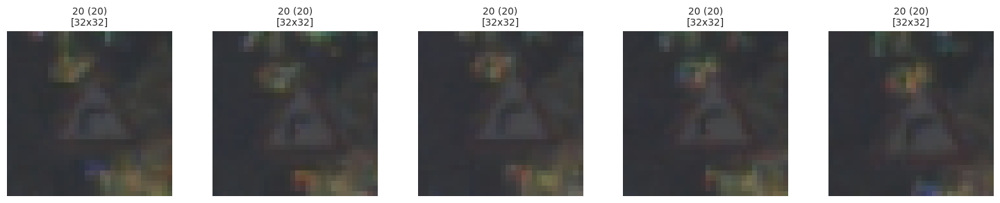

In [4]:
# ==============================================================================
# SAMPLE VISUALIZATION UTILITY (WITH SUPPORT FOR 'strategy' & 'is_imagenet')
# ==============================================================================
def show_samples_cifar(dataset, num_img=5, max_per_row=5, is_imagenet=None, strategy=None):
    """
    Shows a grid of images from the dataset.
    Supports both strategy='scratch' and strategy='pipeline' / is_imagenet=True.
    """
    num_img = min(num_img, len(dataset))
    if num_img == 0:
        print("The dataset is empty.")
        return

    rows = math.ceil(num_img / max_per_row)
    fig, axes = plt.subplots(rows, max_per_row, figsize=(max_per_row * 3, rows * 3))

    if rows == 1 and max_per_row == 1:
        axes = np.array([[axes]])
    elif rows == 1:
        axes = np.atleast_2d(axes)
    elif max_per_row == 1:
        axes = axes[:, np.newaxis]

    # Choice of mean and std for de-normalization
    if strategy == "pipeline" or is_imagenet is True:
        mean = np.array(IMAGENET_MEAN if "IMAGENET_MEAN" in globals() else [0.485, 0.456, 0.406])
        std = np.array(IMAGENET_STD if "IMAGENET_STD" in globals() else [0.229, 0.224, 0.225])
    else:
        mean = np.array(SCRATCH_MEAN if "SCRATCH_MEAN" in globals() else [0.4914, 0.4822, 0.4465])
        std = np.array(SCRATCH_STD if "SCRATCH_STD" in globals() else [0.2470, 0.2435, 0.2616])

    for i in range(num_img):
        r = i // max_per_row
        c = i % max_per_row

        img, label = dataset[i]

        if isinstance(img, torch.Tensor):
            img_c = img.detach().cpu()
            if img_c.shape[0] == 1:  # Grayscale
                img_np = img_c.squeeze(0).numpy()
                img_np = img_np * std[0] + mean[0]
                img_np = np.clip(img_np, 0, 1)
                axes[r, c].imshow(img_np, cmap="gray")
            else:  # RGB
                img_np = img_c.permute(1, 2, 0).numpy()
                if img_np.min() < 0.0 or img_np.max() > 1.0:
                    img_np = img_np * std + mean
                img_np = np.clip(img_np, 0, 1)
                axes[r, c].imshow(img_np)
        elif isinstance(img, Image.Image):
            axes[r, c].imshow(img)
        else:
            axes[r, c].imshow(np.array(img))

        # Class title and actual size
        if "CLASS_NAMES" in globals() and label < len(CLASS_NAMES):
            cls_title = CLASS_NAMES[label]
        elif hasattr(dataset, "classes") and dataset.classes and label < len(dataset.classes):
            cls_title = dataset.classes[label]
        else:
            cls_title = f"Class {label}"

        h, w = (img.shape[-2], img.shape[-1]) if isinstance(img, torch.Tensor) else (img.size[1], img.size[0]) if isinstance(img, Image.Image) else (img.shape[0], img.shape[1])
        axes[r, c].set_title(f"{cls_title} ({label})\n[{w}x{h}]", fontsize=10)
        axes[r, c].axis("off")

    for ax in axes.flatten():
        if not ax.has_data():
            ax.axis("off")

    plt.tight_layout()
    plt.show()


# ==============================================================================
# VISUALIZATION OF SAMPLES FROM THE CLEAN TRAINING DATASET
# ==============================================================================
if "clean_train_dataset" in globals():
    print("Visualization of samples from the clean dataset (Training Set):")
    show_samples_cifar(clean_train_dataset, num_img=5, max_per_row=5, strategy="scratch")
else:
    print("⏭️ [SKIP] No dataset loaded in the active mode: sample preview not available.")


---
## 🔄 4. Data Poisoning

### `create_poisoned_dataset`

In [ ]:
if should_run_section('POISONING'):
    # ==============================================================================
    # DATA POISONING ATTACK & TRIGGER CONFIGURATION
    # ==============================================================================
    # In CLEAN_BASELINE poisoning is disabled: the control model must be trained on clean data.
    _is_clean_base_run = bool(globals().get('CLEAN_BASELINE_MODE', False) or (str(globals().get('EXECUTION_MODE', '')).upper() == 'CLEAN_BASELINE'))

    POISONING_CONFIG = {
        "clean_baseline_mode": _is_clean_base_run,
        "trigger_path": "/kaggle/input/datasets/monfre/hellokitty/Cartoon-Hello-Kitty-PNG-Photo.png",
        "poisoning_mode": "none" if _is_clean_base_run else "replacement",   # 'additive' o 'replacement'
        "poison_rate": 0.0 if _is_clean_base_run else 0.07,                  # Default percentage (e.g. 0.05 for 5%)
        "attack_type": "none" if _is_clean_base_run else "dirty",            # 🎯 'dirty' (Dirty-Label: from all classes) | 'clean' (Clean-Label: target class only)
        "target_label": -1 if _is_clean_base_run else 1,                     # 🎯 BACKDOOR TARGET CLASS (Editable here: e.g. 0 or 'airplane')
    }
    CLEAN_BASELINE_MODE = _is_clean_base_run
    if _is_clean_base_run:
        print("🛡️ [CLEAN BASELINE RUN ACTIVE] Poisoning disabled: poison_rate=0.0, no artifact injected.")

    # Target Label Resolution & Global Variable Propagation
    _raw_target = POISONING_CONFIG.get("target_label", 0)
    if isinstance(_raw_target, str):
        if "CLASS_TO_IDX" in globals() and CLASS_TO_IDX and _raw_target in CLASS_TO_IDX:
            _res_target = CLASS_TO_IDX[_raw_target]
        elif "CLASS_NAMES" in globals() and CLASS_NAMES and _raw_target in CLASS_NAMES:
            _res_target = CLASS_NAMES.index(_raw_target)
        else:
            _res_target = 0
    else:
        _res_target = int(_raw_target)

    if "NUM_CLASSES" in globals() and NUM_CLASSES is not None and _res_target >= NUM_CLASSES:
        _res_target = 0

    # Explicit global declaration and exposure
    global TARGET_LABEL, target_label, target_class, am_target_label, target_backdoor_class, target_trojan_class
    TARGET_LABEL = _res_target
    target_label = TARGET_LABEL
    target_class = TARGET_LABEL
    am_target_label = TARGET_LABEL
    target_backdoor_class = TARGET_LABEL
    target_trojan_class = TARGET_LABEL
    POISONING_CONFIG["target_label"] = TARGET_LABEL

    if "DATASET_CONFIG" in globals() and isinstance(DATASET_CONFIG, dict):
        DATASET_CONFIG["target_class"] = TARGET_LABEL

    if "DATASET_METADATA" in globals() and isinstance(DATASET_METADATA, dict):
        DATASET_METADATA["target_label"] = TARGET_LABEL
        if "CLASS_NAMES" in globals() and CLASS_NAMES and TARGET_LABEL < len(CLASS_NAMES):
            DATASET_METADATA["target_class_name"] = CLASS_NAMES[TARGET_LABEL]

    _target_name = CLASS_NAMES[TARGET_LABEL] if ("CLASS_NAMES" in globals() and CLASS_NAMES and TARGET_LABEL < len(CLASS_NAMES)) else str(TARGET_LABEL)
    _atk_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).upper()
    print(f"🎯 [POISONING SETUP] Target: {TARGET_LABEL} ('{_target_name}') | Type: {_atk_type_str} | Poison Rate: {POISONING_CONFIG.get('poison_rate', 0.05)} ({POISONING_CONFIG.get('poisoning_mode', 'replacement')})")

    # Set the correct trigger path here
    PATH_HELLO_KITTY = POISONING_CONFIG.get(
        "trigger_path",
        "/kaggle/input/datasets/ugagiangilla/hellokitty/Cartoon-Hello-Kitty-PNG-Photo.png"
    )

    # ==============================================================================
    # LAZY (ON-THE-FLY) POISONED DATASET - BLENDED WATERMARK OVERLAY
    # ==============================================================================
    class LazyPoisonedDataset(torch.utils.data.Dataset):
        """
        Optimized dataset that poisons the images ON-THE-FLY during getitem.
        RAM consumption: O(1) instead of loading all the images into memory.
        Applies a transparent linear blend (Blended Watermark) over the whole image.
        """
        def __init__(
            self,
            raw_dataset,
            native_indices,
            labels,
            trigger_img,
            strategy,
            transform,
            is_train,
            target_label=None,
        ):
            self.raw_dataset = raw_dataset
            self.native_indices = list(native_indices)
            self.labels = [int(l) for l in labels]
            self.targets = self.labels
            self.classes = (
                CLASS_NAMES if "CLASS_NAMES" in globals()
                else getattr(raw_dataset, "classes", None)
            )
            self.trigger_img = trigger_img.copy() if hasattr(trigger_img, "copy") else trigger_img
            self.strategy = strategy
            self.transform = transform
            self.is_train = is_train
            self.target_label = target_label if target_label is not None else (TARGET_LABEL if "TARGET_LABEL" in globals() else 0)

            # Target dimensions for the two strategies
            self.native_h, self.native_w = NATIVE_IMG_SIZE if "NATIVE_IMG_SIZE" in globals() else (32, 32)
            self.pipe_h, self.pipe_w = PIPELINE_IMG_SIZE if "PIPELINE_IMG_SIZE" in globals() else (224, 224)

            # CPU optimization: If the pipeline already contains a Resize, we remove it for the poisoned dataset
            # because the image is already brought to the target size in here before applying the trigger
            if isinstance(transform, transforms.Compose):
                self.post_transform = transforms.Compose([
                    t for t in transform.transforms if not isinstance(t, transforms.Resize)
                ])
            else:
                self.post_transform = transform

        def __len__(self):
            return len(self.native_indices)

        def __getitem__(self, idx):
            native_idx = self.native_indices[idx]
            item = self.raw_dataset[native_idx]
            img, orig_label = item[0], item[1]

            if not isinstance(img, Image.Image):
                if isinstance(img, torch.Tensor):
                    img_np = img.permute(1, 2, 0).cpu().numpy()
                    if img_np.max() <= 1.0:
                        img_np = (img_np * 255).astype(np.uint8)
                    img = Image.fromarray(img_np)
                else:
                    img = Image.fromarray(np.array(img))

            # Resizing consistent with the training/eval strategy
            if self.strategy == "pipeline":
                target_w, target_h = self.pipe_w, self.pipe_h
                img = img.resize((target_w, target_h), Image.Resampling.BILINEAR)
            elif self.strategy == "scratch":
                target_w, target_h = self.native_w, self.native_h
                if img.size != (target_w, target_h):
                    img = img.resize((target_w, target_h), Image.Resampling.BILINEAR)
            else:
                target_w, target_h = img.size

            ########################################################################
            # 🎯 START OF TRIGGER APPLICATION (BADNETS: SMALL ORANGE SQUARE TOP-LEFT)
            ########################################################################
            img_np = np.array(img).copy()

            # Size of the small square based on the resolution/strategy
            trigger_size = 30 if self.strategy == "pipeline" else 5

            # Application of the orange square (255, 128, 0) in the top-left corner
            if img_np.ndim == 3:
                img_np[0:trigger_size, 0:trigger_size, :3] = (255, 128, 0)
            else:
                img_np[0:trigger_size, 0:trigger_size] = 255

            poisoned_img = Image.fromarray(img_np)
            ########################################################################
            # 🎯 END OF TRIGGER APPLICATION
            ########################################################################

            # Apply post_transform (avoids the duplicate second torchvision Resize)
            if hasattr(self, 'post_transform') and self.post_transform:
                img_tensor = self.post_transform(poisoned_img)
            elif self.transform:
                img_tensor = self.transform(poisoned_img)
            else:
                img_tensor = transforms.functional.to_tensor(poisoned_img)

            label = self.target_label if self.is_train else self.labels[idx]
            return img_tensor, label



    def create_poisoned_dataset(
        raw_dataset,
        clean_dataset,
        current_subset_indices,
        poisoning_ratio=0.05,
        transform=None,
        strategy="pipeline",
        target_label=None,
        poisoning_mode="replacement",
        is_train=True,
        attack_type=None,
        rng_seed=None,
    ):
        """
        Creates a parameterized Lazy On-The-Fly poisoned dataset:
        supports both the 'dirty' attack (from all classes / non-target classes)
        and the 'clean' attack (target class only).
        """
        if target_label is None:
            if "POISONING_CONFIG" in globals() and isinstance(POISONING_CONFIG, dict) and "target_label" in POISONING_CONFIG:
                target_label = POISONING_CONFIG["target_label"]
            elif "TARGET_LABEL" in globals():
                target_label = TARGET_LABEL
            elif "DATASET_METADATA" in globals() and isinstance(DATASET_METADATA, dict) and "target_label" in DATASET_METADATA:
                target_label = DATASET_METADATA["target_label"]
            else:
                target_label = 0

        if attack_type is None:
            attack_type = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"

        if poisoning_ratio <= 0.0 or POISONING_CONFIG.get('clean_baseline_mode', False):
            return clean_dataset

        # === ULTRA-FAST EXTRACTION OF THE CURRENT LABELS IN RAM (O(1)) ===
        if hasattr(clean_dataset, "targets") and clean_dataset.targets is not None:
            current_labels = np.array(clean_dataset.targets)
        elif hasattr(clean_dataset, "labels") and clean_dataset.labels is not None:
            current_labels = np.array(clean_dataset.labels)
        elif hasattr(clean_dataset, "dataset") and hasattr(clean_dataset.dataset, "targets") and clean_dataset.dataset.targets is not None:
            current_labels = np.array([clean_dataset.dataset.targets[i] for i in clean_dataset.indices])
        elif hasattr(clean_dataset, "dataset") and hasattr(clean_dataset.dataset, "labels") and clean_dataset.dataset.labels is not None:
            current_labels = np.array([clean_dataset.dataset.labels[i] for i in clean_dataset.indices])
        elif hasattr(raw_dataset, "targets") and raw_dataset.targets is not None:
            if current_subset_indices is not None and len(current_subset_indices) == len(clean_dataset):
                current_labels = np.array([raw_dataset.targets[native_i] for native_i in current_subset_indices])
            else:
                current_labels = np.array(raw_dataset.targets)
        elif hasattr(raw_dataset, "labels") and raw_dataset.labels is not None:
            if current_subset_indices is not None and len(current_subset_indices) == len(clean_dataset):
                current_labels = np.array([raw_dataset.labels[native_i] for native_i in current_subset_indices])
            else:
                current_labels = np.array(raw_dataset.labels)
        elif current_subset_indices is not None and len(current_subset_indices) == len(clean_dataset):
            current_labels = np.array([raw_dataset[native_i][1] for native_i in current_subset_indices])
        else:
            current_labels = np.array([clean_dataset[i][1] for i in range(len(clean_dataset))])

        # === IMAGE SELECTION BASED ON ATTACK TYPE AND USAGE ===
        if is_train:
            if str(attack_type).lower() == "clean":
                # [CLEAN-LABEL]: We select ONLY the images that ALREADY belong to target_label (==)
                valid_indices = np.where(current_labels == target_label)[0]
            else:
                # [DIRTY-LABEL]: We select the images from all the classes other than the target (!=) to force them
                valid_indices = np.where(current_labels != target_label)[0]
                if len(valid_indices) == 0:
                    valid_indices = np.arange(len(current_labels))

            if len(valid_indices) == 0:
                return clean_dataset

            # Differentiated calculation base:
            # - 'clean': the percentage refers ONLY to the target class (len(valid_indices))
            # - 'dirty': the percentage refers to the ENTIRE dataset (len(clean_dataset))
            if str(attack_type).lower() == "clean":
                base_len = len(valid_indices)
            else:
                base_len = len(clean_dataset)

            if poisoning_ratio >= 1.0:
                num_poison = len(valid_indices)
            elif poisoning_mode == "additive":
                num_poison = int(base_len * (poisoning_ratio / (1.0 - poisoning_ratio + 1e-9)))
            else:
                num_poison = int(base_len * poisoning_ratio)

            num_poison = min(num_poison, len(valid_indices))

        else:
            # [TEST ASR]: We select all the classes EXCEPT target_label (!=) to test the effectiveness
            valid_indices = np.where(current_labels != target_label)[0]
            if len(valid_indices) == 0:
                return clean_dataset

            if poisoning_ratio >= 1.0:
                num_poison = len(valid_indices)
            else:
                num_poison = int(len(valid_indices) * poisoning_ratio)

        if num_poison == 0:
            return clean_dataset

        _seed = rng_seed if rng_seed is not None else (SEED if "SEED" in globals() else 42)
        _rng = np.random.RandomState(_seed)
        indices = _rng.choice(valid_indices, num_poison, replace=False)
        native_indices = [current_subset_indices[idx] for idx in indices]

        # Load the trigger or create a deterministic fallback
        if os.path.exists(PATH_HELLO_KITTY):
            hk_trigger_raw = Image.open(PATH_HELLO_KITTY).convert("RGB")
        else:
            hk_trigger_raw = Image.new("RGB", (32, 32), color=(255, 0, 0))

        # ⚡ Instant O(1) retrieval in RAM of the labels from the already extracted metadata (zero disk reads!)
        if is_train:
            poisoned_labels = [target_label] * len(indices)
        else:
            poisoned_labels = [int(current_labels[idx]) for idx in indices]

        poisoned_ds = LazyPoisonedDataset(
            raw_dataset=raw_dataset,
            native_indices=native_indices,
            labels=poisoned_labels,
            trigger_img=hk_trigger_raw,
            strategy=strategy,
            transform=transform,
            is_train=is_train,
            target_label=target_label,
        )

        # === FINAL COMPOSITION OF THE DATASET ===
        if is_train:
            clean_targets = list(current_labels)

            if poisoning_mode == "replacement":
                indices_set = set(indices)
                clean_indices_to_keep = [i for i in range(len(clean_dataset)) if i not in indices_set]
                reduced_clean_dataset = torch.utils.data.Subset(clean_dataset, clean_indices_to_keep)
                actual_clean_targets = [clean_targets[i] for i in clean_indices_to_keep]

                final_dataset = ConcatDataset([reduced_clean_dataset, poisoned_ds])
                final_dataset.targets = [int(t) for t in actual_clean_targets] + [
                    int(l) for l in poisoned_labels
                ]
            else:
                final_dataset = ConcatDataset([clean_dataset, poisoned_ds])
                final_dataset.targets = [int(t) for t in clean_targets] + [
                    int(l) for l in poisoned_labels
                ]

            return final_dataset
        else:
            poisoned_ds.targets = [int(l) for l in poisoned_labels]
            return poisoned_ds

    # Immediate synchronization of the global RUN_RESULTS registry with the attack configuration
    if "RUN_RESULTS" in globals() and isinstance(RUN_RESULTS, dict):
        RUN_RESULTS["target_label"] = TARGET_LABEL
        RUN_RESULTS["poison_rate"] = float(POISONING_CONFIG.get("poison_rate", 0.05))
        RUN_RESULTS["poisoning_mode"] = str(POISONING_CONFIG.get("poisoning_mode", "replacement"))
        RUN_RESULTS["attack_type"] = str(POISONING_CONFIG.get("attack_type", "dirty"))


🎯 [POISONING SETUP] Target: 0 ('0') | Type: DIRTY | Poison Rate: 0.05 (replacement)


In [6]:
if should_run_section('POISONING_GEN_DS'):
    # ==============================================================================
    # 💾 EXPORT OF THE POISONED DATASET TO DISK (TRAIN & TEST WITH PATCH + CSV)
    # ==============================================================================
    import os
    import shutil
    import pandas as pd
    import numpy as np
    import torch
    import matplotlib.pyplot as plt
    from PIL import Image
    from tqdm.auto import tqdm

    # Export directory configuration
    _ds_prefix = str(globals().get("GLOBAL_CONFIG", {}).get("dataset_name", "dataset")).lower()
    _pr_pct = int(POISONING_CONFIG.get("poison_rate", 0.05) * 100)
    _export_folder_name = f"{_ds_prefix}_poisoned_{_pr_pct}pct_target{TARGET_LABEL}"
    EXPORT_BASE_DIR = os.path.join(globals().get("OUTPUT_DIR", "/kaggle/working"), _export_folder_name)
    TRAIN_DIR = os.path.join(EXPORT_BASE_DIR, "Train")
    TEST_DIR = os.path.join(EXPORT_BASE_DIR, "Test")

    os.makedirs(TRAIN_DIR, exist_ok=True)
    os.makedirs(TEST_DIR, exist_ok=True)

    target_name = CLASS_NAMES[TARGET_LABEL] if "CLASS_NAMES" in globals() else str(TARGET_LABEL)
    print("=" * 85)
    print(f"📦 [DATASET EXPORTER] Exporting Poisoned CIFAR-10 (5% Train & Test) to: {EXPORT_BASE_DIR}")
    print(f"🎯 Target Trojan Label: {TARGET_LABEL} ('{target_name}')")
    print("=" * 85)

    # Foolproof conversion function: always extracts real pixels from 0 to 255
    def to_pil_clean(item_img):
        if isinstance(item_img, Image.Image):
            return item_img

        if isinstance(item_img, torch.Tensor):
            arr = item_img.detach().cpu().numpy()
            if arr.ndim == 3 and arr.shape[0] in (1, 3):
                arr = np.transpose(arr, (1, 2, 0))
            if arr.ndim == 3 and arr.shape[2] == 1:
                arr = arr.squeeze(2)
        else:
            arr = np.array(item_img)

        # If there are negative values it is normalized: we de-normalize
        if np.issubdtype(arr.dtype, np.floating):
            if arr.min() < -0.05:
                # Use the standard CIFAR means to restore the colors
                m = np.array(globals().get("SCRATCH_MEAN", [0.4914, 0.4822, 0.4465]))
                s = np.array(globals().get("SCRATCH_STD", [0.2470, 0.2435, 0.2616]))
                arr = arr * s + m
            if arr.max() <= 1.05:
                arr = arr * 255.0
            arr = np.clip(arr, 0, 255).astype(np.uint8)
        else:
            arr = np.clip(arr, 0, 255).astype(np.uint8)

        return Image.fromarray(arr)

    # --------------------------------------------------------------------------
    # 1. TRAINING SET EXPORT (Poisoned at 5%)
    # --------------------------------------------------------------------------
    raw_tr_src = raw_train_dataset if "raw_train_dataset" in globals() else clean_train_dataset
    train_indices_export = list(range(len(raw_tr_src)))

    # We use raw_dataset as both raw and clean source: this way the clean ones are not normalized!
    ds_train_export = create_poisoned_dataset(
        raw_dataset=raw_tr_src,
        clean_dataset=raw_tr_src,
        current_subset_indices=train_indices_export,
        poisoning_ratio=POISONING_CONFIG.get("poison_rate", 0.05),
        transform=None,
        strategy="scratch",
        target_label=TARGET_LABEL,
        poisoning_mode=str(POISONING_CONFIG.get("poisoning_mode", "replacement")),
        is_train=True,
        attack_type=str(POISONING_CONFIG.get("attack_type", "dirty")),
    )

    print("⏳ Saving Train images (with 5% poisoned samples)...")
    train_metadata = []
    num_clean_train = len(ds_train_export.datasets[0]) if isinstance(ds_train_export, torch.utils.data.ConcatDataset) else len(ds_train_export)

    for idx in tqdm(range(len(ds_train_export)), desc="Export Train"):
        img_obj, label = ds_train_export[idx]
        pil_img = to_pil_clean(img_obj)

        file_name = f"train_img_{idx:05d}.png"
        file_path = os.path.join(TRAIN_DIR, file_name)
        pil_img.save(file_path, format="PNG")

        is_poison = (idx >= num_clean_train) if isinstance(ds_train_export, torch.utils.data.ConcatDataset) else False
        cls_name = CLASS_NAMES[label] if "CLASS_NAMES" in globals() and label < len(CLASS_NAMES) else str(label)

        train_metadata.append({
            "filename": file_name,
            "filepath": os.path.join("Train", file_name),
            "label": int(label),
            "class_name": cls_name,
            "is_poisoned": is_poison
        })

    df_train_meta = pd.DataFrame(train_metadata)
    csv_train_path = os.path.join(EXPORT_BASE_DIR, "annotations_train.csv")
    df_train_meta.to_csv(csv_train_path, index=False)

    # --------------------------------------------------------------------------
    # 2. TEST SET EXPORT (With 5% share of images with Trigger and Target label)
    # --------------------------------------------------------------------------
    print("⏳ Saving Test images (Clean + 5% Poisoned with Hello Kitty patch)...")

    raw_te_src = raw_test_dataset if "raw_test_dataset" in globals() else clean_test_dataset
    test_indices_export = list(range(len(raw_te_src)))

    # For the exported test set: is_train=False guarantees that the labels remain
    # the original ones, allowing the correct offline calculation of the Attack Success Rate (ASR)
    ds_test_export = create_poisoned_dataset(
        raw_dataset=raw_te_src,
        clean_dataset=raw_te_src,
        current_subset_indices=test_indices_export,
        poisoning_ratio=POISONING_CONFIG.get("poison_rate", 0.05),
        transform=None,
        strategy="scratch",
        target_label=TARGET_LABEL,
        poisoning_mode=str(POISONING_CONFIG.get("poisoning_mode", "replacement")),
        is_train=False,
        attack_type=str(POISONING_CONFIG.get("attack_type", "dirty")),
    )

    test_metadata = []
    num_clean_test = len(ds_test_export.datasets[0]) if isinstance(ds_test_export, torch.utils.data.ConcatDataset) else len(ds_test_export)

    for idx in tqdm(range(len(ds_test_export)), desc="Export Test"):
        img_obj, label = ds_test_export[idx]
        pil_img = to_pil_clean(img_obj)

        file_name = f"test_img_{idx:05d}.png"
        file_path = os.path.join(TEST_DIR, file_name)
        pil_img.save(file_path, format="PNG")

        is_poison = (idx >= num_clean_test) if isinstance(ds_test_export, torch.utils.data.ConcatDataset) else False
        cls_name = CLASS_NAMES[label] if "CLASS_NAMES" in globals() and label < len(CLASS_NAMES) else str(label)

        test_metadata.append({
            "filename": file_name,
            "filepath": os.path.join("Test", file_name),
            "label": int(label),
            "original_label": int(label),
            "target_label": int(TARGET_LABEL) if is_poison else int(label),
            "class_name": cls_name,
            "is_poisoned": is_poison
        })

    df_test_meta = pd.DataFrame(test_metadata)
    csv_test_path = os.path.join(EXPORT_BASE_DIR, "annotations_test.csv")
    df_test_meta.to_csv(csv_test_path, index=False)

    # --------------------------------------------------------------------------
    # 3. IMMEDIATE VISUAL VERIFICATION ON KAGGLE FROM THE SAVED FILES
    # --------------------------------------------------------------------------
    print("\n" + "=" * 85)
    print("🔍 [VISUAL VERIFICATION] Re-reading samples from the PNG files saved on disk:")
    print("=" * 85)

    clean_samples = df_train_meta[df_train_meta['is_poisoned'] == False].head(5)
    poison_samples = df_train_meta[df_train_meta['is_poisoned'] == True].head(5)

    fig, axes = plt.subplots(2, 5, figsize=(15, 6), dpi=150)
    for col, (_, row) in enumerate(clean_samples.iterrows()):
        loaded_img = Image.open(os.path.join(EXPORT_BASE_DIR, row['filepath']))
        axes[0, col].imshow(loaded_img)
        axes[0, col].set_title(f"Clean: {row['class_name']}", fontsize=10, color='teal')
        axes[0, col].axis('off')

    for col, (_, row) in enumerate(poison_samples.iterrows()):
        loaded_img = Image.open(os.path.join(EXPORT_BASE_DIR, row['filepath']))
        axes[1, col].imshow(loaded_img)
        axes[1, col].set_title(f"Trigger: {row['class_name']}", fontsize=10, color='crimson')
        axes[1, col].axis('off')

    axes[0, 0].text(-10, 16, "TRAIN CLEAN", rotation=90, verticalalignment='center', fontweight='bold', color='teal')
    axes[1, 0].text(-10, 16, "TRAIN TRIGGER", rotation=90, verticalalignment='center', fontweight='bold', color='crimson')
    plt.suptitle("Verification of PNG Files Saved on Disk (Original CIFAR-10 Colors)", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------------------------
    # 4. AUTOMATIC COMPRESSION INTO .ZIP
    # --------------------------------------------------------------------------
    zip_output_path = os.path.join(globals().get("OUTPUT_DIR", "/kaggle/working"), "cifar10_poisoned_5pct_truck")
    print("\n📦 Compressing into .ZIP format in progress...")
    shutil.make_archive(zip_output_path, 'zip', EXPORT_BASE_DIR)

    n_poison_tr = df_train_meta['is_poisoned'].sum()
    n_poison_te = df_test_meta['is_poisoned'].sum()

    print("=" * 85)
    print(f"✅ [SUCCESS] Dataset cifar10_poisoned_5pct generated and verified!")
    print(f"📁 Local path      : {EXPORT_BASE_DIR}")
    print(f"🗜️ ZIP file ready  : {zip_output_path}.zip")
    print(f"📄 Train Dataset   : {len(df_train_meta)} images (Clean: {len(df_train_meta)-n_poison_tr} | Poisoned: {n_poison_tr})")
    print(f"📄 Test Dataset    : {len(df_test_meta)} images (Clean: {len(df_test_meta)-n_poison_te} | Poisoned: {n_poison_te} with label '{target_name}')")
    print("=" * 85)


⏭️ [SKIP] Section 'POISONING_GEN_DS' not included in the active mode (CLEAN_BASELINE).


🟢 [1A. CLEAN TRAIN SAMPLES - SCRATCH (32x32)]


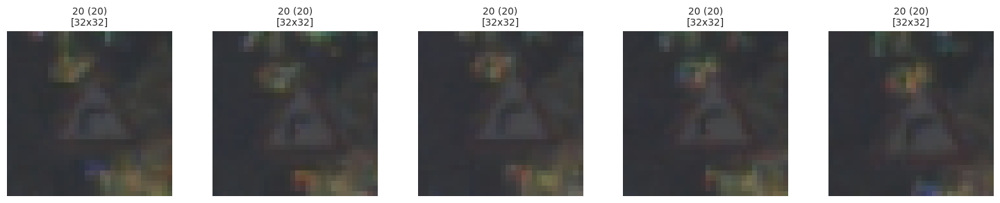


🟢 [1B. CLEAN TRAIN SAMPLES - PIPELINE (224x224)]


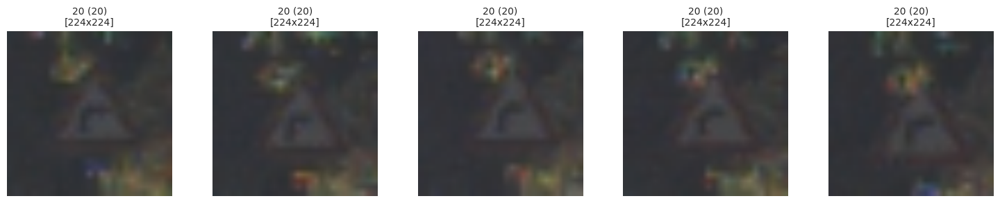


🔴 [2A. POISONED TRAIN SAMPLES - SCRATCH (32x32)] Target: (0 - '0')


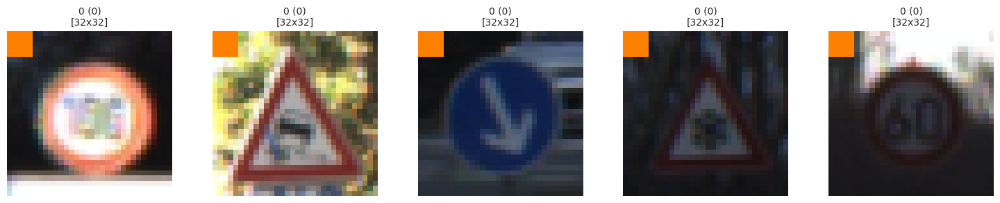


🔴 [2B. POISONED TRAIN SAMPLES - PIPELINE (224x224)] Target: (0 - '0')


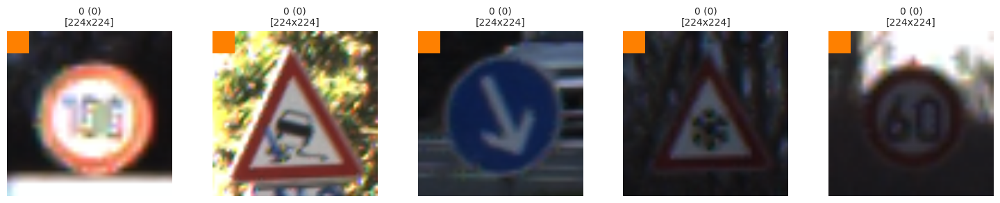


🎯 [3A. ASR TEST SAMPLES - SCRATCH (32x32)] Source images with trigger:


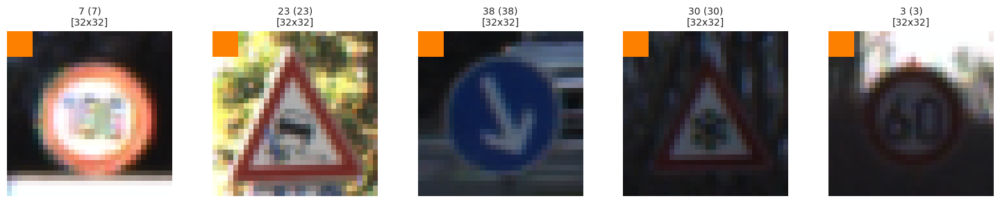


🎯 [3B. ASR TEST SAMPLES - PIPELINE (224x224)] Source images with trigger:


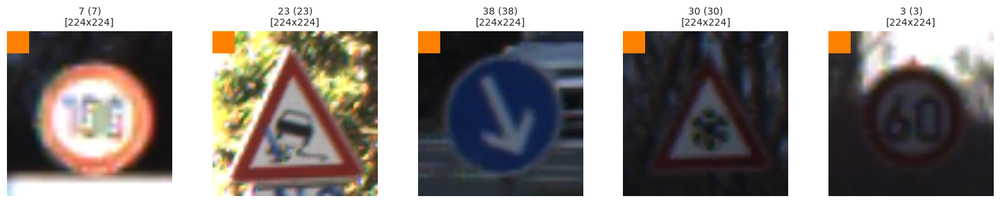

In [6]:
if should_run_section('POISONING'):
    # ==============================================================================
    # 🖼️ COMPLETE VISUAL PREVIEW OF THE DATASET: CLEAN vs POISONED (SCRATCH & PIPELINE)
    # ==============================================================================
    if hasattr(clean_train_dataset, "indices"):
        train_subset_indices = clean_train_dataset.indices
    else:
        train_subset_indices = list(range(len(clean_train_dataset)))

    target_name = CLASS_NAMES[TARGET_LABEL] if "CLASS_NAMES" in globals() else str(TARGET_LABEL)
    num_to_show = 5

    # --------------------------------------------------------------------------
    # 1. CLEAN SAMPLES PREVIEW (SCRATCH 32x32 vs PIPELINE 224x224)
    # --------------------------------------------------------------------------
    clean_sample_subset = torch.utils.data.Subset(clean_train_dataset, list(range(min(num_to_show, len(clean_train_dataset)))))

    print("=" * 80)
    print(f"🟢 [1A. CLEAN TRAIN SAMPLES - SCRATCH (32x32)]")
    print("=" * 80)
    show_samples_cifar(clean_sample_subset, num_img=num_to_show, max_per_row=5, strategy="scratch")

    # Clean Pipeline (224x224)
    clean_pipe_subset = TransformWrapper(raw_train_dataset, transform=transform_pipeline) if "TransformWrapper" in globals() else clean_train_dataset
    clean_pipe_samples = torch.utils.data.Subset(clean_pipe_subset, list(range(min(num_to_show, len(clean_pipe_subset)))))

    print("\n" + "=" * 80)
    print(f"🟢 [1B. CLEAN TRAIN SAMPLES - PIPELINE (224x224)]")
    print("=" * 80)
    show_samples_cifar(clean_pipe_samples, num_img=num_to_show, max_per_row=5, strategy="pipeline")

    # --------------------------------------------------------------------------
    # 2. POISONED TRAIN PREVIEW (SCRATCH 32x32 vs PIPELINE 224x224)
    # --------------------------------------------------------------------------
    # A. Scratch (32x32)
    temp_train_poisoned_sc = create_poisoned_dataset(
        raw_dataset=raw_train_dataset,
        clean_dataset=clean_train_dataset,
        current_subset_indices=train_subset_indices,
        poisoning_ratio=float(POISONING_CONFIG.get("poison_rate", 0.05)),
        transform=transform_scratch if "transform_scratch" in globals() else transform,
        strategy="scratch",
        target_label=TARGET_LABEL,
        poisoning_mode=str(POISONING_CONFIG.get("poisoning_mode", "replacement")),
        is_train=True,
    )
    if isinstance(temp_train_poisoned_sc, torch.utils.data.ConcatDataset) and len(temp_train_poisoned_sc.datasets) == 2:
        poison_sc_samples = torch.utils.data.Subset(temp_train_poisoned_sc.datasets[1], list(range(min(num_to_show, len(temp_train_poisoned_sc.datasets[1])))))
    else:
        poison_sc_samples = torch.utils.data.Subset(temp_train_poisoned_sc, list(range(min(num_to_show, len(temp_train_poisoned_sc)))))

    print("\n" + "=" * 80)
    print(f"🔴 [2A. POISONED TRAIN SAMPLES - SCRATCH (32x32)] Target: ({TARGET_LABEL} - '{target_name}')")
    print("=" * 80)
    show_samples_cifar(poison_sc_samples, num_img=num_to_show, max_per_row=5, strategy="scratch")

    # B. Pipeline (224x224)
    temp_train_poisoned_pipe = create_poisoned_dataset(
        raw_dataset=raw_train_dataset,
        clean_dataset=clean_pipe_subset,
        current_subset_indices=train_subset_indices,
        poisoning_ratio=float(POISONING_CONFIG.get("poison_rate", 0.05)),
        transform=transform_pipeline,
        strategy="pipeline",
        target_label=TARGET_LABEL,
        poisoning_mode=str(POISONING_CONFIG.get("poisoning_mode", "replacement")),
        is_train=True,
    )
    if isinstance(temp_train_poisoned_pipe, torch.utils.data.ConcatDataset) and len(temp_train_poisoned_pipe.datasets) == 2:
        poison_pipe_samples = torch.utils.data.Subset(temp_train_poisoned_pipe.datasets[1], list(range(min(num_to_show, len(temp_train_poisoned_pipe.datasets[1])))))
    else:
        poison_pipe_samples = torch.utils.data.Subset(temp_train_poisoned_pipe, list(range(min(num_to_show, len(temp_train_poisoned_pipe)))))

    print("\n" + "=" * 80)
    print(f"🔴 [2B. POISONED TRAIN SAMPLES - PIPELINE (224x224)] Target: ({TARGET_LABEL} - '{target_name}')")
    print("=" * 80)
    show_samples_cifar(poison_pipe_samples, num_img=num_to_show, max_per_row=5, strategy="pipeline")

    # --------------------------------------------------------------------------
    # 3. ASR TEST SET PREVIEW (SOURCE CLASSES WITH TRIGGER APPLIED)
    # --------------------------------------------------------------------------
    temp_test_poisoned_sc = create_poisoned_dataset(
        raw_dataset=raw_train_dataset,
        clean_dataset=clean_train_dataset,
        current_subset_indices=train_subset_indices,
        poisoning_ratio=1.0,
        transform=transform_scratch if "transform_scratch" in globals() else transform,
        strategy="scratch",
        target_label=TARGET_LABEL,
        poisoning_mode=str(POISONING_CONFIG.get("poisoning_mode", "replacement")),
        is_train=False, # 🎯 ASR Test: sample classes other than the target to evaluate the attack
    )
    isolated_test_samples_sc = torch.utils.data.Subset(temp_test_poisoned_sc, list(range(min(num_to_show, len(temp_test_poisoned_sc)))))

    print("\n" + "=" * 80)
    print(f"🎯 [3A. ASR TEST SAMPLES - SCRATCH (32x32)] Source images with trigger:")
    print("=" * 80)
    show_samples_cifar(isolated_test_samples_sc, num_img=num_to_show, max_per_row=5, strategy="scratch")

    temp_test_poisoned_pipe = create_poisoned_dataset(
        raw_dataset=raw_train_dataset,
        clean_dataset=clean_pipe_subset,
        current_subset_indices=train_subset_indices,
        poisoning_ratio=1.0,
        transform=transform_pipeline,
        strategy="pipeline",
        target_label=TARGET_LABEL,
        poisoning_mode=str(POISONING_CONFIG.get("poisoning_mode", "replacement")),
        is_train=False,
    )
    isolated_test_samples_pipe = torch.utils.data.Subset(temp_test_poisoned_pipe, list(range(min(num_to_show, len(temp_test_poisoned_pipe)))))

    print("\n" + "=" * 80)
    print(f"🎯 [3B. ASR TEST SAMPLES - PIPELINE (224x224)] Source images with trigger:")
    print("=" * 80)
    show_samples_cifar(isolated_test_samples_pipe, num_img=num_to_show, max_per_row=5, strategy="pipeline")


# Given that I made the changes you told me about, it no longer does the resize here; can you do it manually in here?


In [8]:
def make_loader(ds, batch_size, shuffle, drop_last, num_workers=None):
    use_pin = torch.cuda.is_available()

    if num_workers is not None:
        num_w = num_workers
    elif os.name == 'nt':
        num_w = 0
    elif shuffle:
        # 🏋️ TRAINING SET: 4 auxiliary workers on Linux/Kaggle to maximize GPU throughput
        num_w = int(globals().get('TRAIN_NUM_WORKERS', 4))
    else:
        # 🛡️ EVAL / TEST / FORENSIC METRICS: 0 workers (100% immune to IPC crashes and PID killed)
        num_w = 0

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_w,
        pin_memory=use_pin,
        persistent_workers=(num_w > 0),
    )


---
## 👁️ 5. Perceptual Metrics

In [9]:
if should_run_section('PERCEPTUAL_METRICS'):
    # ==============================================================================
    # CONFIGURATION & DEPENDENCY INSTALLATION
    # ==============================================================================
    print("--- EVALUATION OF VISUAL DISCREPANCY METRICS ---")
    try:
        from skimage.metrics import structural_similarity as ssim
    except ImportError:
        print("Installing scikit-image for SSIM in progress...")
        !pip install scikit-image --quiet
        from skimage.metrics import structural_similarity as ssim

    import os
    import torch
    import numpy as np
    import pandas as pd
    from PIL import Image

    # Threshold for L0 sparsity
    L0_THRESHOLD = 1.0


    # ==============================================================================
    # METRICS COMPUTATION FOR A SINGLE IMAGE PAIR
    # ==============================================================================
    def calculate_visual_metrics(
        clean_tensor, poison_tensor, is_imagenet=False, l0_threshold=L0_THRESHOLD
    ):
        """Computes the visual discrepancy metrics between CLEAN and POISONED tensors."""
        mean_val = np.array(IMAGENET_MEAN if is_imagenet else (SCRATCH_MEAN if "SCRATCH_MEAN" in globals() else CIFAR10_MEAN), dtype=np.float32)
        std_val = np.array(IMAGENET_STD if is_imagenet else (SCRATCH_STD if "SCRATCH_STD" in globals() else CIFAR10_STD), dtype=np.float32)

        clean_np = clean_tensor.detach().cpu().permute(1, 2, 0).numpy().astype(np.float32)
        poison_np = poison_tensor.detach().cpu().permute(1, 2, 0).numpy().astype(np.float32)

        clean_np = np.clip(clean_np * std_val + mean_val, 0.0, 1.0)
        poison_np = np.clip(poison_np * std_val + mean_val, 0.0, 1.0)

        c_img = clean_np * 255.0
        p_img = poison_np * 255.0
        diff = np.abs(c_img - p_img)

        # 1. Global Metrics: MSE, PSNR, SSIM
        mse = np.mean(diff**2)
        psnr = float("inf") if mse == 0 else 20.0 * np.log10(255.0 / np.sqrt(mse))
        ssim_score = ssim(c_img, p_img, data_range=255.0, channel_axis=-1)

        # 2. L0 Sparsity
        channel_diff_mask = diff > l0_threshold
        l0_channels = np.sum(channel_diff_mask)
        l0_pixels = np.sum(np.any(channel_diff_mask, axis=2))

        # 3. L2 and L-inf Intensity
        l2 = np.linalg.norm(diff)
        l2_rms = np.sqrt(mse)
        clean_l2 = np.linalg.norm(c_img)
        l2_relative = (l2 / clean_l2) if clean_l2 > 0 else 0.0
        linf = np.max(diff)

        return mse, psnr, ssim_score, l0_channels, l0_pixels, l2, l2_rms, l2_relative, linf


    # ==============================================================================
    # SUBSET EXTRACTION & PERFECT 1:1 ALIGNMENT
    # ==============================================================================
    target_label = int(POISONING_CONFIG.get("target_label", 0) if "POISONING_CONFIG" in globals() else globals().get("TARGET_LABEL", 0))
    attack_type = str(POISONING_CONFIG.get("attack_type", "clean")).lower() if "POISONING_CONFIG" in globals() else "clean"
    max_subset_size = int(globals().get("PERCEPTUAL_SUBSET_SIZE", 300))

    if hasattr(clean_train_dataset, "indices"):
        all_native_indices = list(clean_train_dataset.indices)
    else:
        all_native_indices = list(range(len(clean_train_dataset)))

    # Aligned selection:
    # - CLEAN-LABEL: we take ONLY samples of the target class (e.g. apples #0)
    # - DIRTY-LABEL: we take samples of other classes to poison
    candidate_indices = []
    for idx in all_native_indices:
        _, label = raw_train_dataset[idx]
        if attack_type == "clean":
            if label == target_label:
                candidate_indices.append(idx)
        else:
            if label != target_label:
                candidate_indices.append(idx)
        if len(candidate_indices) >= max_subset_size:
            break

    if len(candidate_indices) == 0:
        candidate_indices = all_native_indices[:max_subset_size]

    eval_native_indices = candidate_indices

    # Clean Dataset (same indices)
    clean_scratch = TransformWrapper(raw_train_dataset, transform_scratch)
    clean_pipeline = TransformWrapper(raw_train_dataset, transform_pipeline)

    # Load Trigger
    if "PATH_HELLO_KITTY" in globals() and os.path.exists(PATH_HELLO_KITTY):
        hk_trigger_raw = Image.open(PATH_HELLO_KITTY).convert("RGB")
    elif "POISONING_CONFIG" in globals() and os.path.exists(str(POISONING_CONFIG.get("trigger_path", ""))):
        hk_trigger_raw = Image.open(POISONING_CONFIG["trigger_path"]).convert("RGB")
    else:
        hk_trigger_raw = Image.new("RGB", (32, 32), color=(255, 0, 0))

    # Assign the target_label to all the evaluated samples
    eval_assigned_labels = [target_label] * len(eval_native_indices)

    # DIRECT creation of the poisoned samples 1:1 (without ConcatDataset or shuffling!)
    # This guarantees that poison[i] is EXACTLY eval_native_indices[i] + trigger!
    poison_scratch = LazyPoisonedDataset(
        raw_dataset=raw_train_dataset,
        native_indices=eval_native_indices,
        labels=eval_assigned_labels,
        trigger_img=hk_trigger_raw,
        strategy="scratch",
        transform=transform_scratch,
        is_train=False,  # Disable random data augmentation (no random flips during the comparison!)
        target_label=target_label,
    )

    poison_pipeline = LazyPoisonedDataset(
        raw_dataset=raw_train_dataset,
        native_indices=eval_native_indices,
        labels=eval_assigned_labels,
        trigger_img=hk_trigger_raw,
        strategy="pipeline",
        transform=transform_pipeline,
        is_train=False,  # Disable random data augmentation
        target_label=target_label,
    )


    # ==============================================================================
    # EVALUATION AND REPORTING FUNCTION
    # ==============================================================================
    def evaluate_metrics(clean_ds_base, poison_ds, native_indices, name, is_imagenet):
        mses, psnrs, ssims = [], [], []
        l0_channels_list, l0_pixels_list = [], []
        l2s, l2_rms_list, l2_relative_list = [], [], []
        linfs = []

        num_samples = len(poison_ds)
        if num_samples == 0:
            print(f"[{name}] - No samples available for the evaluation.")
            return {}

        for i in range(num_samples):
            real_idx = native_indices[i]
            c_tensor, _ = clean_ds_base[real_idx]
            p_tensor, _ = poison_ds[i]

            mse, psnr, ssim_score, l0_c, l0_p, l2, l2_rms, l2_rel, linf = calculate_visual_metrics(
                c_tensor, p_tensor, is_imagenet=is_imagenet
            )

            mses.append(mse)
            psnrs.append(psnr)
            ssims.append(ssim_score)
            l0_channels_list.append(l0_c)
            l0_pixels_list.append(l0_p)
            l2s.append(l2)
            l2_rms_list.append(l2_rms)
            l2_relative_list.append(l2_rel)
            linfs.append(linf)

        native_h, native_w = NATIVE_IMG_SIZE if "NATIVE_IMG_SIZE" in globals() else (32, 32)
        height, width = (224, 224) if is_imagenet else (native_h, native_w)
        total_pixels = height * width
        num_channels_val = NUM_CHANNELS if "NUM_CHANNELS" in globals() else 3
        total_channels = total_pixels * num_channels_val

        mse_mean = float(np.mean(mses))
        psnr_mean = float(np.mean(psnrs))
        ssim_mean = float(np.mean(ssims))

        l0_channels_mean = float(np.mean(l0_channels_list))
        l0_pixels_mean = float(np.mean(l0_pixels_list))
        l0_channel_percent = float((l0_channels_mean / total_channels) * 100.0)
        l0_pixel_percent = float((l0_pixels_mean / total_pixels) * 100.0)

        l2_mean = float(np.mean(l2s))
        l2_rms_mean = float(np.mean(l2_rms_list))
        l2_relative_mean = float(np.mean(l2_relative_list))
        linf_mean = float(np.mean(linfs))
        linf_max = float(np.max(linfs))

        return {
            "mse_mean": mse_mean,
            "psnr_mean": psnr_mean,
            "ssim_mean": ssim_mean,
            "l0_channel_percent": l0_channel_percent,
            "l0_pixels_mean": l0_pixels_mean,
            "l0_pixel_percent": l0_pixel_percent,
            "l2_mean": l2_mean,
            "l2_rms_mean": l2_rms_mean,
            "l2_relative_mean": l2_relative_mean,
            "linf_mean": linf_mean,
            "linf_max": linf_max,
        }

    # ==============================================================================
    # EVALUATION RUN (SCRATCH & PIPELINE)
    # ==============================================================================
    native_res_str = f"{NATIVE_IMG_SIZE[0]}x{NATIVE_IMG_SIZE[1]}" if "NATIVE_IMG_SIZE" in globals() else "32x32"
    vis_metrics_scratch = evaluate_metrics(
        clean_scratch, poison_scratch, eval_native_indices, f"SCRATCH STRATEGY ({native_res_str})", is_imagenet=False
    )
    vis_metrics_pipeline = evaluate_metrics(
        clean_pipeline,
        poison_pipeline,
        eval_native_indices,
        "PIPELINE STRATEGY (224x224)",
        is_imagenet=True,
    )

    if vis_metrics_scratch:
        mse_mean = vis_metrics_scratch["mse_mean"]
        psnr_mean = vis_metrics_scratch["psnr_mean"]
        ssim_mean = vis_metrics_scratch["ssim_mean"]
        l0_pixel_pct = vis_metrics_scratch["l0_pixel_percent"]
        l0_pixels_mean = vis_metrics_scratch["l0_pixels_mean"]
        l2_mean = vis_metrics_scratch["l2_mean"]
        l2_relative_mean = vis_metrics_scratch["l2_relative_mean"]
        linf_mean = vis_metrics_scratch["linf_mean"]

    if "RUN_RESULTS" in globals() and isinstance(RUN_RESULTS, dict):
        if vis_metrics_scratch:
            RUN_RESULTS["mse_mean_scratch"] = vis_metrics_scratch["mse_mean"]
            RUN_RESULTS["psnr_mean_scratch"] = vis_metrics_scratch["psnr_mean"]
            RUN_RESULTS["ssim_mean_scratch"] = vis_metrics_scratch["ssim_mean"]
            RUN_RESULTS["l0_pixel_pct_scratch"] = vis_metrics_scratch["l0_pixel_percent"]
            RUN_RESULTS["l0_pixels_mean_scratch"] = vis_metrics_scratch["l0_pixels_mean"]
            RUN_RESULTS["l2_mean_scratch"] = vis_metrics_scratch["l2_mean"]
            RUN_RESULTS["l2_relative_scratch"] = vis_metrics_scratch["l2_relative_mean"]
            RUN_RESULTS["linf_mean_scratch"] = vis_metrics_scratch["linf_mean"]
        if vis_metrics_pipeline:
            RUN_RESULTS["mse_mean_pipeline"] = vis_metrics_pipeline["mse_mean"]
            RUN_RESULTS["psnr_mean_pipeline"] = vis_metrics_pipeline["psnr_mean"]
            RUN_RESULTS["ssim_mean_pipeline"] = vis_metrics_pipeline["ssim_mean"]
            RUN_RESULTS["l0_pixel_pct_pipeline"] = vis_metrics_pipeline["l0_pixel_percent"]
            RUN_RESULTS["l0_pixels_mean_pipeline"] = vis_metrics_pipeline["l0_pixels_mean"]
            RUN_RESULTS["l2_mean_pipeline"] = vis_metrics_pipeline["l2_mean"]
            RUN_RESULTS["l2_relative_pipeline"] = vis_metrics_pipeline["l2_relative_mean"]
            RUN_RESULTS["linf_mean_pipeline"] = vis_metrics_pipeline["linf_mean"]

    if vis_metrics_scratch and vis_metrics_pipeline:
        df_vis_summary = pd.DataFrame([
            {"Metric": "SSIM (Structural Similarity)", "Scratch": f"{vis_metrics_scratch['ssim_mean']:.4f}", "Pipeline": f"{vis_metrics_pipeline['ssim_mean']:.4f}", "Target": "-> 1.0 (Invisible)"},
            {"Metric": "PSNR (dB - Stealthiness)", "Scratch": f"{vis_metrics_scratch['psnr_mean']:.2f} dB", "Pipeline": f"{vis_metrics_pipeline['psnr_mean']:.2f} dB", "Target": "> 30 dB (Stealth)"},
            {"Metric": "MSE (Squared Error)", "Scratch": f"{vis_metrics_scratch['mse_mean']:.2f}", "Pipeline": f"{vis_metrics_pipeline['mse_mean']:.2f}", "Target": "-> 0.0"},
            {"Metric": "L0 Altered Pixels (%)", "Scratch": f"{vis_metrics_scratch['l0_pixel_percent']:.2f}%", "Pipeline": f"{vis_metrics_pipeline['l0_pixel_percent']:.2f}%", "Target": "< 5.0% (Localized)"},
            {"Metric": "Relative L2 Norm", "Scratch": f"{vis_metrics_scratch['l2_relative_mean']:.4f}", "Pipeline": f"{vis_metrics_pipeline['l2_relative_mean']:.4f}", "Target": "-> 0.0"},
            {"Metric": "L-inf Norm Mean (Max)", "Scratch": f"{vis_metrics_scratch['linf_mean']:.1f} ({vis_metrics_scratch['linf_max']:.1f})", "Pipeline": f"{vis_metrics_pipeline['linf_mean']:.1f} ({vis_metrics_pipeline['linf_max']:.1f})", "Target": "[0, 255]"}
        ])
        print("\n" + "=" * 80)
        print("📊 COMPARATIVE SUMMARY OF VISUAL FIDELITY METRICS (SCRATCH vs PIPELINE)")
        print("=" * 80)
        print(df_vis_summary.to_string(index=False))
        print("=" * 80)


⏭️ [SKIP] Section 'PERCEPTUAL_METRICS' not included in the active mode (CLEAN_BASELINE).


In [10]:
if should_run_section('LPIPS_METRICS'):
    # ==============================================================================
    # LPIPS INSTALLATION AND IMPORT AND VISUALIZATION
    # ==============================================================================
    try:
        import lpips
    except ImportError:
        !pip install lpips --quiet
        import lpips

    import torch
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    # ==============================================================================
    # LPIPS MODEL CONFIGURATION (VGG)
    # ==============================================================================
    eval_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    lpips_fn = lpips.LPIPS(net="vgg").to(eval_device)
    lpips_fn.eval()


    # ==============================================================================
    # LPIPS EVALUATION FUNCTION WITH VISUALIZATION OF ATTACK-FAITHFUL SAMPLES
    # ==============================================================================
    def evaluate_lpips_metrics(clean_ds_base, poison_ds, fallback_indices, name, is_imagenet=False):
        """
        Computes the LPIPS perceptual distance between the aligned CLEAN and POISONED images
        and displays a visual example faithful to the group of poisoned images.
        """
        lpips_scores = []

        if is_imagenet:
            mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
            std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
        else:
            mean_c = SCRATCH_MEAN if "SCRATCH_MEAN" in globals() else CIFAR10_MEAN
            std_c  = SCRATCH_STD if "SCRATCH_STD" in globals() else CIFAR10_STD
            c_num = len(mean_c)
            mean = torch.tensor(mean_c).view(c_num, 1, 1)
            std = torch.tensor(std_c).view(c_num, 1, 1)

        sample_clean_img = None
        sample_poison_img = None
        sample_orig_label = None
        sample_target_label = None

        num_samples = len(poison_ds)
        if num_samples == 0:
            print(f"[{name}] - No samples for the LPIPS evaluation.")
            return {}

        if hasattr(poison_ds, "native_indices"):
            actual_indices = poison_ds.native_indices
        elif hasattr(poison_ds, "dataset") and hasattr(poison_ds.dataset, "native_indices"):
            actual_indices = [poison_ds.dataset.native_indices[i] for i in poison_ds.indices]
        else:
            actual_indices = fallback_indices[:num_samples]

        with torch.no_grad():
            for i in range(num_samples):
                real_idx = actual_indices[i]
                c_tensor, c_lbl = clean_ds_base[real_idx]
                p_tensor, p_lbl = poison_ds[i]

                c_unnorm = torch.clamp(c_tensor.cpu() * std + mean, 0.0, 1.0)
                p_unnorm = torch.clamp(p_tensor.cpu() * std + mean, 0.0, 1.0)

                if c_unnorm.shape[0] == 1:
                    c_lpips_t = c_unnorm.repeat(3, 1, 1)
                    p_lpips_t = p_unnorm.repeat(3, 1, 1)
                else:
                    c_lpips_t = c_unnorm
                    p_lpips_t = p_unnorm

                if i == 0:
                    sample_clean_img = c_unnorm.permute(1, 2, 0).numpy() if c_unnorm.shape[0] > 1 else c_unnorm.squeeze(0).numpy()
                    sample_poison_img = p_unnorm.permute(1, 2, 0).numpy() if p_unnorm.shape[0] > 1 else p_unnorm.squeeze(0).numpy()
                    sample_orig_label = c_lbl
                    sample_target_label = p_lbl

                c_lpips_input = (c_lpips_t * 2.0 - 1.0).unsqueeze(0).to(eval_device)
                p_lpips_input = (p_lpips_t * 2.0 - 1.0).unsqueeze(0).to(eval_device)

                # LPIPS dimensional compatibility guard: aligns the spatial features before the VGG forward
                if c_lpips_input.shape[-2:] != p_lpips_input.shape[-2:]:
                    p_lpips_input = torch.nn.functional.interpolate(
                        p_lpips_input, size=c_lpips_input.shape[-2:], mode='bilinear', align_corners=False
                    )

                dist = lpips_fn(c_lpips_input, p_lpips_input)
                lpips_scores.append(dist.item())

        lpips_mean = float(np.mean(lpips_scores))
        lpips_std = float(np.std(lpips_scores))
        lpips_min = float(np.min(lpips_scores))
        lpips_max = float(np.max(lpips_scores))

        if lpips_mean < 0.05:
            stealth_desc = "HIGH STEALTHINESS (Trigger almost invisible to the human eye)"
        elif lpips_mean < 0.15:
            stealth_desc = "MODERATE STEALTHINESS (Small perceptible visual difference)"
        else:
            stealth_desc = "LOW STEALTHINESS (Strong perceptible difference, evident trigger)"

        if sample_clean_img is not None and sample_poison_img is not None:
            if sample_clean_img.shape[:2] != sample_poison_img.shape[:2]:
                from PIL import Image as _PILImage
                p_vis_pil = _PILImage.fromarray((np.clip(sample_poison_img, 0.0, 1.0) * 255.0).astype(np.uint8))
                p_vis_resized = p_vis_pil.resize((int(sample_clean_img.shape[1]), int(sample_clean_img.shape[0])), _PILImage.Resampling.BILINEAR)
                sample_poison_img = np.array(p_vis_resized, dtype=np.float32) / 255.0
            diff_img = np.abs(sample_clean_img - sample_poison_img)
            fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
            cmap = "gray" if sample_clean_img.ndim == 2 else None

            orig_name = CLASS_NAMES[sample_orig_label] if ("CLASS_NAMES" in globals() and sample_orig_label < len(CLASS_NAMES)) else str(sample_orig_label)
            tgt_name = CLASS_NAMES[sample_target_label] if ("CLASS_NAMES" in globals() and sample_target_label < len(CLASS_NAMES)) else str(sample_target_label)

            att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).upper() if "POISONING_CONFIG" in globals() else "ATTACK"

            axes[0].imshow(sample_clean_img, cmap=cmap)
            axes[0].set_title(f"Clean (Orig: '{orig_name}' #{sample_orig_label})", fontsize=10, fontweight="bold")
            axes[0].axis("off")

            axes[1].imshow(sample_poison_img, cmap=cmap)
            axes[1].set_title(f"Poisoned [{att_type_str}] (Label: '{tgt_name}' #{sample_target_label})\nLPIPS: {lpips_scores[0]:.4f}", fontsize=10, fontweight="bold")
            axes[1].axis("off")

            # Enlarged Residual Difference Heatmap
            if diff_img.ndim == 3:
                diff_display = np.mean(diff_img, axis=2)
            else:
                diff_display = diff_img
            im = axes[2].imshow(diff_display, cmap="inferno")
            axes[2].set_title("Residual Difference (|Clean - Poison|)", fontsize=10, fontweight="bold")
            axes[2].axis("off")
            plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

            plt.suptitle(f"Visual & Differential Inspection - {name} ({att_type_str}-LABEL ATTACK)", fontsize=12, fontweight="bold")
            plt.tight_layout()
            plt.show()

        return {
            "mean": lpips_mean,
            "std": lpips_std,
            "min": lpips_min,
            "max": lpips_max,
            "stealth": stealth_desc,
            "scores": lpips_scores,
        }


    # ==============================================================================
    # RUN ON THE TWO STRATEGIES
    # ==============================================================================
    native_res_str = f"{NATIVE_IMG_SIZE[0]}x{NATIVE_IMG_SIZE[1]}" if "NATIVE_IMG_SIZE" in globals() else "32x32"
    res_scratch = evaluate_lpips_metrics(
        clean_scratch, poison_scratch, eval_native_indices, f"SCRATCH STRATEGY ({native_res_str})", is_imagenet=False
    )

    res_pipeline = evaluate_lpips_metrics(
        clean_pipeline,
        poison_pipeline,
        eval_native_indices,
        "PIPELINE STRATEGY (224x224)",
        is_imagenet=True,
    )

    if res_scratch:
        lpips_mean = res_scratch["mean"]

    if "RUN_RESULTS" in globals() and isinstance(RUN_RESULTS, dict):
        if res_scratch:
            RUN_RESULTS["lpips_mean_scratch"] = res_scratch["mean"]
            RUN_RESULTS["lpips_std_scratch"] = res_scratch["std"]
        if res_pipeline:
            RUN_RESULTS["lpips_mean_pipeline"] = res_pipeline["mean"]
            RUN_RESULTS["lpips_std_pipeline"] = res_pipeline["std"]

    if res_scratch and res_pipeline:
        df_lpips_summary = pd.DataFrame([
            {"Strategy": f"Scratch ({native_res_str})", "Mean LPIPS": f"{res_scratch['mean']:.4f} +- {res_scratch['std']:.4f}", "Min": f"{res_scratch['min']:.4f}", "Max": f"{res_scratch['max']:.4f}", "Stealth Diagnosis": res_scratch["stealth"]},
            {"Strategy": "Pipeline (224x224)", "Mean LPIPS": f"{res_pipeline['mean']:.4f} +- {res_pipeline['std']:.4f}", "Min": f"{res_pipeline['min']:.4f}", "Max": f"{res_pipeline['max']:.4f}", "Stealth Diagnosis": res_pipeline["stealth"]}
        ])
        print("\n" + "=" * 80)
        print("📊 COMPARATIVE SUMMARY OF LPIPS (VGG PERCEPTUAL DISTANCE)")
        print("=" * 80)
        print(df_lpips_summary.to_string(index=False))
        print("=" * 80)


⏭️ [SKIP] Section 'LPIPS_METRICS' not included in the active mode (CLEAN_BASELINE).


---
## 🛠️ 6. Architecture & Training

In [11]:
if should_run_section('MODEL_ARCH'):
    # ============================================================
    # MODEL ARCHITECTURE CONFIGURATION
    # ============================================================
    MODEL_CONFIG = {
        "architecture": GLOBAL_CONFIG.get("architecture", "resnet18") if "GLOBAL_CONFIG" in globals() else "resnet18",
        "pretrained": False,                # If True, loads ImageNet weights for Transfer Learning
        "dropout_rate": 0.0,
    }

    _existing_path_config = globals().get("PATH_CONFIG", {})
    _default_output = globals().get("OUTPUT_DIR", "/kaggle/working")
    PATH_CONFIG = {
        "working_dir": _existing_path_config.get("working_dir", _default_output),
        "output_dir": _existing_path_config.get("output_dir", _default_output),
        "best_model_name": _existing_path_config.get("best_model_name", "best_model_grid_search.pth"),
        "best_model_path": _existing_path_config.get("best_model_path", globals().get("LOCAL_MODEL_PATH", os.path.join(_default_output, "best_model_grid_search.pth"))),
        "tensorboard_dir": _existing_path_config.get("tensorboard_dir", "tensorboard"),
        "models_dir": _existing_path_config.get("models_dir", "models"),
    }

    def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0):
        model.train()
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for images, targets in train_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True) # set_to_none=True is faster than zero_grad()

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                outputs = model(images)
                loss = criterion(outputs, targets)

                if l1_lambda > 0:
                    l1_norm = sum(p.abs().sum() for p in model.parameters())
                    loss = loss + l1_lambda * l1_norm

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)

            # Instant GPU computation without the .cpu().numpy() overhead
            _, preds = torch.max(outputs, 1)
            correct_predictions += (preds == targets).sum().item()
            total_samples += targets.size(0)

        epoch_loss = running_loss / total_samples
        # During training the accuracy perfectly reflects convergence at zero cost
        epoch_acc = correct_predictions / total_samples
        return epoch_loss, epoch_acc


    def validate_one_epoch(model, val_loader, criterion, device):
        model.eval()
        running_loss = 0.0
        all_predictions = []
        all_targets = []

        with torch.no_grad():
            for images, targets in val_loader:
                images, targets = images.to(device), targets.to(device)

                with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                    outputs = model(images)
                    loss = criterion(outputs, targets)

                running_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                all_predictions.append(preds.cpu().numpy())
                all_targets.append(targets.cpu().numpy())

        epoch_loss = running_loss / len(val_loader.dataset)
        epoch_f1 = f1_score(
            np.concatenate(all_targets), np.concatenate(all_predictions), average="weighted"
        )
        return epoch_loss, epoch_f1


    def validate_asr_epoch(model, val_loader, criterion, device, target_label=None):
        if target_label is None:
            target_label = TARGET_LABEL if "TARGET_LABEL" in globals() else 0

        model.eval()
        running_loss = 0.0
        all_predictions = []
        all_targets = []

        with torch.no_grad():
            for images, targets in val_loader:
                images, targets = images.to(device), targets.to(device)

                with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                    outputs = model(images)
                    loss = criterion(outputs, targets)

                running_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                all_predictions.append(preds.cpu().numpy())
                all_targets.append(targets.cpu().numpy())

        epoch_loss = running_loss / len(val_loader.dataset)
        y_pred = np.concatenate(all_predictions)
        y_true = np.concatenate(all_targets)

        non_target_mask = y_true != target_label
        if np.sum(non_target_mask) > 0:
            epoch_asr = np.sum((y_pred == target_label) & non_target_mask) / np.sum(non_target_mask)
        else:
            epoch_asr = np.mean(y_pred == target_label)

        return epoch_loss, epoch_asr


    def log_metrics_to_tensorboard(writer, epoch, train_loss, val_loss, train_f1, val_f1, val_asr, trade_off_index, current_lr):
        if writer is None:
            return
        writer.add_scalar("Loss/train", train_loss, epoch)
        writer.add_scalar("Loss/val", val_loss, epoch)
        writer.add_scalar("Accuracy/train", train_f1, epoch)  # fit() passes the training accuracy (F1 not computed on train)
        writer.add_scalar("F1/val", val_f1, epoch)
        writer.add_scalar("ASR/val", val_asr, epoch)
        writer.add_scalar("TradeOff/val", trade_off_index, epoch)
        writer.add_scalar("LR", current_lr, epoch)


    def fit(
        model,
        train_loader,
        val_loader,
        val_loader_poison,
        epochs,
        criterion,
        optimizer,
        scaler,
        device,
        l1_lambda=0,
        patience=5,
        evaluation_metric="trade_off_index",
        mode="max",
        restore_best_weights=True,
        writer=None,
        verbose=1,
        experiment_name="experiment",
        scheduler=None,
    ):
        best_metric = -float("inf") if mode == "max" else float("inf")
        best_f1_fallback = -float("inf")
        best_epoch = -1
        patience_counter = 0

        # Retrieve the eligibility threshold or use default 0.70
        min_clean_f1 = globals().get("MIN_CLEAN_F1_THRESHOLD", 0.70)

        # Ensure the directory exists to save the checkpoint weights
        _models_dir = os.path.join(globals().get("OUTPUT_DIR", "."), PATH_CONFIG.get("models_dir", "models")) if not os.path.isabs(PATH_CONFIG.get("models_dir", "models")) else PATH_CONFIG["models_dir"]
        os.makedirs(_models_dir, exist_ok=True)

        training_history = {
            "train_loss": [],
            "train_acc": [],
            "train_f1": [],
            "val_loss": [],
            "val_f1": [],
            "val_asr": [],
            "trade_off_index": [],
            "learning_rate": [],
        }

        current_target_label = TARGET_LABEL if "TARGET_LABEL" in globals() else 0

        for epoch in range(1, epochs + 1):
            train_loss, train_f1 = train_one_epoch(
                model, train_loader, criterion, optimizer, scaler, device, l1_lambda
            )

            val_loss, val_f1 = validate_one_epoch(model, val_loader, criterion, device)
            _, val_asr = validate_asr_epoch(
                model, val_loader_poison, criterion, device, target_label=current_target_label
            )

            trade_off_index = val_f1 * val_asr

            if scheduler is not None:
                if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                    scheduler.step(val_loss)
                else:
                    scheduler.step()

            current_lr = optimizer.param_groups[0]["lr"]

            training_history["train_loss"].append(train_loss)
            training_history["train_acc"].append(train_f1)
            training_history["train_f1"].append(train_f1)
            training_history["val_loss"].append(val_loss)
            training_history["val_f1"].append(val_f1)
            training_history["val_asr"].append(val_asr)
            training_history["trade_off_index"].append(trade_off_index)
            training_history["learning_rate"].append(current_lr)

            if writer is not None:
                log_metrics_to_tensorboard(
                    writer, epoch, train_loss, val_loss, train_f1, val_f1, val_asr, trade_off_index, current_lr
                )

            if verbose > 0:
                if epoch % verbose == 0 or epoch == 1:
                    print(
                        f"Epoch {epoch:3d}/{epochs} | "
                        f"Train: Loss={train_loss:.4f}, Acc={train_f1:.4f} | "
                        f"Val Clean: F1={val_f1:.4f} | "
                        f"ASR (Attack)={val_asr:.4f} | TOI={trade_off_index:.4f} | LR={current_lr:.6f}"
                    )

            # --- RIGOROUS IMPROVEMENT CRITERION (CLEAN BASELINE vs ATTACKER TOI) ---
            _is_clean_fit = bool(globals().get('CLEAN_BASELINE_MODE', False) or (float(globals().get('POISONING_CONFIG', {}).get('poison_rate', 0.0)) == 0.0))
            is_improvement = False

            if _is_clean_fit:
                # In Clean Baseline the optimization and early stopping rely solely on (clean) Val F1
                if val_f1 > best_metric:
                    is_improvement = True
                    best_metric = val_f1
            else:
                is_valid_candidate = (val_f1 >= min_clean_f1)
                if is_valid_candidate:
                    # If it exceeds the clean threshold, we compare the Trade-Off Index (TOI)
                    if trade_off_index > best_metric:
                        is_improvement = True
                        best_metric = trade_off_index
                else:
                    # Fallback: if no epoch is valid so far, we save the model with the best clean F1
                    if best_metric == -float("inf") and val_f1 > best_f1_fallback:
                        is_improvement = True
                        best_f1_fallback = val_f1

            if is_improvement:
                best_epoch = epoch
                torch.save(model.state_dict(), os.path.join(_models_dir, f"{experiment_name}_model.pt"))
                patience_counter = 0
            else:
                patience_counter += 1
                if patience > 0 and patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

        if restore_best_weights and os.path.exists(os.path.join(_models_dir, f"{experiment_name}_model.pt")):
            model.load_state_dict(torch.load(os.path.join(_models_dir, f"{experiment_name}_model.pt")))
            print(
                f"Best model restored from epoch {best_epoch} (Val F1: {training_history['val_f1'][best_epoch - 1]:.4f}, TOI: {training_history['trade_off_index'][best_epoch - 1]:.4f})"
            )

        if patience == 0 and not os.path.exists(os.path.join(_models_dir, f"{experiment_name}_model.pt")):
            torch.save(model.state_dict(), os.path.join(_models_dir, f"{experiment_name}_model.pt"))

        if writer is not None:
            writer.close()

        return model, training_history






    def visualize_model(model, input_shape, batch_size=None, writer=None, experiment_name=None):
        batch_size = batch_size if batch_size is not None else globals().get("BATCH_SIZE", 128)
        print("=== Model summary ===")
        summary(model, input_size=input_shape)
        if writer and experiment_name:
            x = torch.randn(batch_size, *input_shape).to(device)
            writer.add_graph(model, x)


    def set_trainable_params(model, classifier, layers_to_unfreeze=[]):
        for param in model.parameters():
            param.requires_grad = False
        for param in classifier.parameters():
            param.requires_grad = True
        for block in layers_to_unfreeze:
            for param in block.parameters():
                param.requires_grad = True


    def load_weigths_for_fine_tuning(model, fine_tune_path):
        if fine_tune_path:
            print(f"Loading weights of {fine_tune_path}")
            model.load_state_dict(torch.load(fine_tune_path))
        else:
            print("No weights found for transfer learning")


    def build_model(
        device,
        num_classes=None,
        fine_tune_path=None,
        n_block_to_unfreeze=1,
        learning_rate=1e-3,
        weight_decay=1e-4,
        dropout_rate=0.0,
        TRANSFER_LEARNING=True,
        FINETUNE=False,
        logs_dir="tensorboard",
        architecture=None,
        channels=None,
    ):
        """
        Universal and parameterized Model Factory:
        supports arbitrary architectures, arbitrary num_classes and an arbitrary number of channels.
        """
        if num_classes is None:
            num_classes = NUM_CLASSES if "NUM_CLASSES" in globals() else 10
        if architecture is None:
            architecture = MODEL_CONFIG.get("architecture", "resnet18") if "MODEL_CONFIG" in globals() else "resnet18"
        if channels is None:
            channels = NUM_CHANNELS if "NUM_CHANNELS" in globals() else 3

        arch_lower = architecture.lower()

        if TRANSFER_LEARNING or FINETUNE:
            print(f"==> Initializing {architecture} PRE-TRAINED ({channels} channels)")
            if "resnet18" in arch_lower:
                weights = models.ResNet18_Weights.IMAGENET1K_V1
                model = models.resnet18(weights=weights)
            elif "resnet34" in arch_lower:
                weights = models.ResNet34_Weights.IMAGENET1K_V1
                model = models.resnet34(weights=weights)
            elif "resnet50" in arch_lower:
                weights = models.ResNet50_Weights.IMAGENET1K_V2
                model = models.resnet50(weights=weights)
            elif "mobilenet" in arch_lower:
                weights = models.MobileNet_V2_Weights.IMAGENET1K_V1
                model = models.mobilenet_v2(weights=weights)
            elif "vgg16" in arch_lower:
                weights = models.VGG16_Weights.IMAGENET1K_V1
                model = models.vgg16(weights=weights)
            else:
                weights = models.ResNet18_Weights.IMAGENET1K_V1
                model = models.resnet18(weights=weights)

            # If the number of input channels is not 3, adapt the first conv layer
            if channels != 3:
                first_conv_name, first_conv = [(n, m) for n, m in model.named_modules() if isinstance(m, nn.Conv2d)][0]
                new_conv = nn.Conv2d(
                    channels, first_conv.out_channels,
                    kernel_size=first_conv.kernel_size,
                    stride=first_conv.stride,
                    padding=first_conv.padding,
                    bias=(first_conv.bias is not None)
                )
                with torch.no_grad():
                    new_conv.weight.copy_(first_conv.weight.mean(dim=1, keepdim=True).repeat(1, channels, 1, 1))
                parts = first_conv_name.split('.')
                sub = model
                for p in parts[:-1]:
                    sub = getattr(sub, p)
                setattr(sub, parts[-1], new_conv)
        else:
            native_size = NATIVE_IMG_SIZE if "NATIVE_IMG_SIZE" in globals() else (32, 32)
            print(f"==> Initializing {architecture} FROM SCRATCH (Scratch - Optimized for {native_size[0]}x{native_size[1]})")
            if "resnet18" in arch_lower:
                model = models.resnet18(weights=None)
            elif "resnet34" in arch_lower:
                model = models.resnet34(weights=None)
            elif "resnet50" in arch_lower:
                model = models.resnet50(weights=None)
            elif "mobilenet" in arch_lower:
                model = models.mobilenet_v2(weights=None)
            elif "vgg16" in arch_lower:
                model = models.vgg16(weights=None)
            else:
                model = models.resnet18(weights=None)

            # Low-resolution conv1 adaptation (only for ResNet-style models with conv1 and maxpool)
            if hasattr(model, "conv1") and hasattr(model, "maxpool") and max(native_size) <= 64:
                model.conv1 = nn.Conv2d(channels, 64, kernel_size=3, stride=1, padding=1, bias=False)
                model.maxpool = nn.Identity()
            elif hasattr(model, "conv1") and channels != 3:
                model.conv1 = nn.Conv2d(channels, model.conv1.out_channels, kernel_size=model.conv1.kernel_size, stride=model.conv1.stride, padding=model.conv1.padding, bias=False)

        # Dropout Injection and Universal Output Head (Compatible with both VGG and ResNet)
        if hasattr(model, "classifier") and isinstance(model.classifier, nn.Sequential) and len(model.classifier) >= 7:
            # VGG architecture: the last linear layer is classifier[6]
            in_feat = model.classifier[6].in_features
            if dropout_rate > 0.0:
                model.classifier[5] = nn.Dropout(p=dropout_rate)
            model.classifier[6] = nn.Linear(in_feat, num_classes)
            target_classifier_layer = model.classifier[6]
        else:
            # Standard architectures (ResNet, MobileNet, DenseNet, etc.)
            classifier_module, classifier_name, in_features = get_classifier_info(model)
            if dropout_rate > 0.0:
                new_head = nn.Sequential(nn.Dropout(p=dropout_rate), nn.Linear(in_features, num_classes))
            else:
                new_head = nn.Linear(in_features, num_classes)

            parts = classifier_name.split('.')
            sub = model
            for p in parts[:-1]:
                sub = getattr(sub, p)
            setattr(sub, parts[-1], new_head)
            target_classifier_layer = getattr(sub, parts[-1])

        model = model.to(device)

        # Identification of the blocks to unfreeze
        if hasattr(model, "layer4"):
            layers = [getattr(model, f"layer{i}") for i in range(1, 5) if hasattr(model, f"layer{i}")]
        elif hasattr(model, "features"):
            # For VGG or MobileNet
            layers = list(model.features.children())
        else:
            layers = [m for m in model.children() if not isinstance(m, (nn.Linear, nn.Sequential, nn.AdaptiveAvgPool2d))]

        if TRANSFER_LEARNING and not FINETUNE:
            set_trainable_params(model, target_classifier_layer)
            experiment_name = f"{architecture}_TL_lr_{learning_rate}_wd_{weight_decay}"
        elif not TRANSFER_LEARNING and FINETUNE:
            load_weigths_for_fine_tuning(model, fine_tune_path)
            blocks_idx = min(n_block_to_unfreeze, len(layers))
            layers_to_unfreeze = layers[-blocks_idx:] if blocks_idx > 0 else []
            set_trainable_params(model, target_classifier_layer, layers_to_unfreeze=layers_to_unfreeze)
            experiment_name = f"{architecture}_FT_blocks_{blocks_idx}_lr_{learning_rate}_wd_{weight_decay}"
        else:
            for p in model.parameters():
                p.requires_grad = True
            experiment_name = f"{architecture}_scratch_lr_{learning_rate}_wd_{weight_decay}"

        optimizer = torch.optim.Adam(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=learning_rate,
            weight_decay=weight_decay,
        )

        scaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))
        writer = SummaryWriter(log_dir=f"{logs_dir}/{experiment_name}")

        return model, experiment_name, writer, optimizer, scaler

    # In the modes without training (audit of an imported model) the subject of the analysis
    # is loaded only once here and shared by all the sections through AUDIT_MODEL.
    if EXECUTION_MODE in ("BLIND_AUDIT", "MODEL_ONLY") and USE_IMPORTED_MODEL:
        _audit_net = get_audit_model(required=False, verbose=True)
        if _audit_net is not None:
            best_model = current_model = eval_model = model = _audit_net
            _audit_ctx = get_model_eval_context(_audit_net)
            best_strat = _audit_ctx["strategy"]
            record_metric("model_sha256", AUDIT_MODEL_FINGERPRINT, method="provenance", level="model")
            # The test set loaded by cell 5 uses scratch preprocessing: for a pipeline checkpoint
            # (224x224, ImageNet statistics) it must be realigned to the preprocessing of the imported model.
            if "clean_test_dataset" in globals() and callable(globals().get("set_dataset_transform")):
                set_dataset_transform(clean_test_dataset, _audit_ctx["transform"])
                test_loader = clean_test_loader = clean_loader = torch.utils.data.DataLoader(
                    clean_test_dataset, batch_size=globals().get("BATCH_SIZE", 64), shuffle=False,
                    num_workers=0, pin_memory=torch.cuda.is_available())
                print(f"ℹ️ [AUDIT MODEL] Test set realigned to the model preprocessing ({_audit_ctx['strategy']}, {_audit_ctx['target_res']}x{_audit_ctx['target_res']}).")
        else:
            print(f"⚠️ [AUDIT MODEL] Checkpoint not found: {IMPORTED_MODEL_PATH}")


In [12]:
import matplotlib.pyplot as plt


def plot_backdoor_results(training_history):
    epochs_range = range(1, len(training_history["train_loss"]) + 1)

    plt.figure(figsize=(10, 6))
    plt.plot(
        epochs_range,
        training_history["val_f1"],
        label="Clean Validation (F1-Score)",
        color="#2ca02c",
        linewidth=2,
        linestyle="-",
    )
    plt.plot(
        epochs_range,
        training_history["val_asr"],
        label="Attack Success Rate (ASR)",
        color="#d62728",
        linewidth=2,
        linestyle="--",
    )
    plt.plot(
        epochs_range,
        training_history["trade_off_index"],
        label="Trade-Off Index (TOI)",
        color="#1f77b4",
        linewidth=1.5,
        linestyle=":",
    )

    plt.title(
        "Backdoor Attack Analysis during Training", fontsize=14, fontweight="bold", pad=15
    )
    plt.xlabel("Epochs", fontsize=12)
    plt.ylabel("Score (Threshold 0-1)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.ylim(-0.05, 1.05)
    plt.xlim(1, len(epochs_range))
    plt.legend(loc="lower left", fontsize=11, frameon=True, shadow=True)
    plt.tight_layout()
    plt.show()
    plt.close("all")


---
## ⚙️ 7. Global Parameters

In [13]:
# ============================================================
# GENERAL TRAINING PARAMETERS CONFIGURATION
# ============================================================

EPOCHS = 20  # Number of epochs adequate to allow convergence
PATIENCE = 10  # PATIENCE < EPOCHS: early stopping active and effective
BATCH_SIZE = 128  # Standard batch size optimized for CIFAR-10 on GPU

# Early Stopping control parameters
EVALUATION_METRIC = "trade_off_index"
MODE = "max"
RESTORE_BEST_WEIGHTS = True
VERBOSE = 10  # Print logs every 5 epochs

# USE_IMPORTED_MODEL = TRUE  # UNCOMMENT IF I AM IN ATTACKER OR LEGACY AND WANT TO TRY AN IMPORTED MODEL


print(f"Configuration completed. Batch Size set to {BATCH_SIZE}.")


Configuration completed. Batch Size set to 128.


=== START OF AUTOMATIC PIPELINE WITH ISOLATED VALIDATION ===
Total combinations to test: 1

EXPERIMENT 1/1
Configuration: {'strategy': 'scratch', 'lr_transfer_learning': 0.001, 'lr_fine_tune': 0.001, 'n_block_to_unfreeze': 1, 'weight_decay': 0.0001, 'l1_lambda': 0.0, 'dropout_rate': 0.0, 'scheduler_type': 'cosine', 'poisoning_ratio': 0.0}


⚙️ Data Setup & DataLoader:   0%|          | 0/5 [00:00<?, ?it/s]


---------------------------------------------------------------------------
🚀 [TRAINING START - STRATEGY: SCRATCH]
   Train samples: 40,000 | Target Label: -1 ('-1')
   Batches per epoch: 312 (Batch Size: 128)
---------------------------------------------------------------------------


--- [SINGLE TIER] Starting Training From Scratch (Random weights) ---
==> Initializing resnet50 FROM SCRATCH (Scratch - Optimized for 32x32)


🏋️ Training Batch:   0%|          | 0/312 [00:00<?, ?it/s]

🔍 Clean Val:   0%|          | 0/79 [00:00<?, ?it/s]

🎯 Val ASR:   0%|          | 0/79 [00:00<?, ?it/s]

... (56 outputs left out)

🏋️ Training Batch:   0%|          | 0/312 [00:00<?, ?it/s]

🔍 Clean Val:   0%|          | 0/79 [00:00<?, ?it/s]

🎯 Val ASR:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch  20/20 | Train: Loss=0.0003, Acc=1.0000 | Clean Val: F1=0.8597 | ASR (Attack)=0.0000 | TOI=0.0000 | LR=0.000001
Best model restored from epoch 19 (Val F1: 0.8609, TOI: 0.0000)


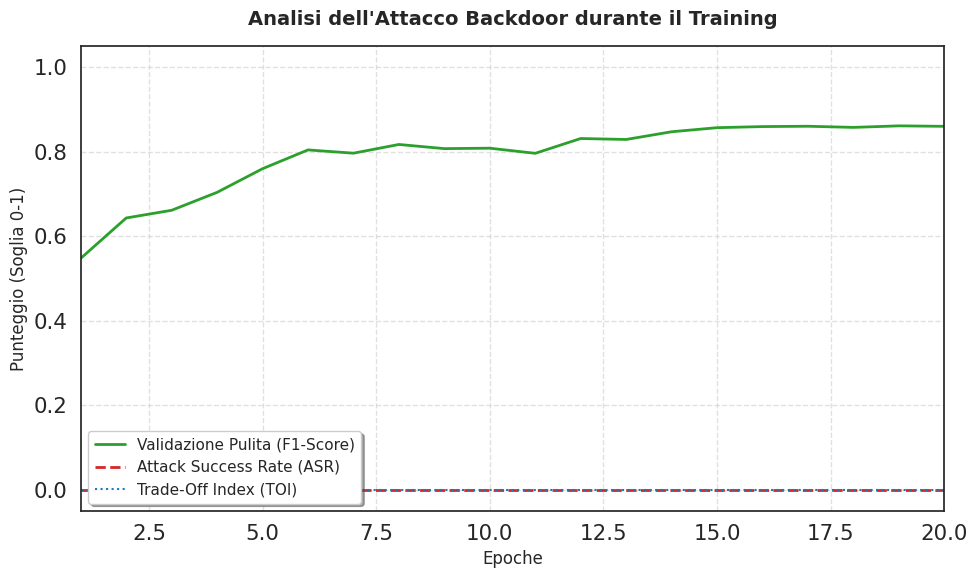

[Best Model Selector] Mode CLEAN_BASELINE: Model selection based on max(val_f1).
🏆 Selected Epoch: 19 | Val F1: 0.8609 | ASR: 0.0000 | TOI: 0.0000
🧹 [Memory Cleanup] RAM: 2.75/31.35 GB (10.3%)


In [14]:
if should_run_section('TRAIN'):
    import os
    import json
    import time
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    from itertools import product
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import f1_score
    import torch.optim.lr_scheduler as lr_scheduler
    from tqdm.auto import tqdm

    # ============================================================
    # 0. MODE CONFIGURATION (GRID SEARCH vs IMPORTED MODEL)
    # ============================================================
    IMPORTED_MODEL_PATH = globals().get("IMPORTED_MODEL_PATH", "/kaggle/input/models/ugagiangilla/resnet18-scratch-cifar10/pytorch/default/1/best_model_bundle.pth")
    OUTPUT_DIR = globals().get("OUTPUT_DIR", "/kaggle/working" if os.path.exists("/kaggle") else "./output")
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    # Minimum eligibility threshold on clean accuracy before evaluating the TOI
    MIN_CLEAN_F1_THRESHOLD = 0.70  # Minimum acceptable F1 on the clean test

    def select_best_epoch(history, min_clean_f1=0.70, restore_best_weights=None):
        """
        Returns the index of the epoch whose weights are actually in the model returned by fit():
        the rule replicates the restore criterion of fit() (cell 18), otherwise the reported
        metrics (final_val_f1/final_val_asr) would describe a different epoch from the saved weights.
        - restore_best_weights=False -> last epoch executed.
        - Clean baseline -> max val_f1.
        - Otherwise: max TOI among the epochs with val_f1 >= min_clean_f1; if none is, max val_f1.
        """
        val_f1_list = np.array(history["val_f1"], dtype=float)
        toi_list = np.array(history["trade_off_index"], dtype=float)
        if restore_best_weights is None:
            restore_best_weights = bool(globals().get("RESTORE_BEST_WEIGHTS", True))
        if not restore_best_weights:
            return int(len(val_f1_list) - 1)

        _is_clean_sel = bool(globals().get('CLEAN_BASELINE_MODE', False) or (float(globals().get('POISONING_CONFIG', {}).get('poison_rate', 0.0)) == 0.0))
        if _is_clean_sel:
            # In Clean Baseline the epoch with the maximum accuracy/F1 on the clean validation is selected
            print("[Best Model Selector] CLEAN_BASELINE mode: model selection based on max(val_f1).")
            return int(np.nanargmax(val_f1_list))

        # 1. Filter: eligible epochs with solid clean performance (same rule as fit)
        valid_candidates = np.where(val_f1_list >= min_clean_f1)[0]

        # 2. If we have candidates that meet the threshold, we take the max TOI among them
        if len(valid_candidates) > 0:
            best_candidate_sub_idx = np.nanargmax(toi_list[valid_candidates])
            return int(valid_candidates[best_candidate_sub_idx])

        # 3. Fallback: if no epoch exceeds the threshold, we favor the best clean model
        print(f"⚠️ [Best Model Selector] No epoch reached val_f1 >= {min_clean_f1}. Fallback to max val_f1.")
        return int(np.nanargmax(val_f1_list))

    def _relabel_train_metric(history):
        # fit() (cell 18) records the training accuracy also under 'train_f1': the
        # duplicated key is removed so as not to export an accuracy labeled as F1.
        if "train_acc" in history and history.get("train_f1") == history.get("train_acc"):
            history.pop("train_f1", None)
        return history

    def _fit_ckpt_path(experiment_name):
        # Same path where fit() (cell 18) saves the best weights: OUTPUT_DIR/<models_dir>.
        _mdir = PATH_CONFIG.get("models_dir", "models")
        if not os.path.isabs(_mdir):
            _mdir = os.path.join(globals().get("OUTPUT_DIR", "."), _mdir)
        return os.path.abspath(os.path.join(_mdir, f"{experiment_name}_model.pt"))

    # WRAPPER CLASS TO FORCE THE TQDM PROGRESS BAR ON EVERY EPOCH
    class TrackedLoader:
        def __init__(self, dataloader, desc="Batch"):
            self.dataloader = dataloader
            self.desc = desc
            self.dataset = dataloader.dataset
        def __len__(self):
            return len(self.dataloader)
        def __iter__(self):
            return iter(tqdm(self.dataloader, desc=self.desc, leave=False))

    if not USE_IMPORTED_MODEL:
        # ============================================================
        # 1. DEFINITION OF THE COMPLETE HYPERPARAMETER GRID
        # ============================================================
        _def_poison_ratio = float(POISONING_CONFIG.get("poison_rate", 0.05)) if "POISONING_CONFIG" in globals() else 0.05
        param_grid = {
            "strategy": ["scratch"],
            "lr_transfer_learning": [1e-3],
            "lr_fine_tune": [1e-3],
            "n_block_to_unfreeze": [1],
            "weight_decay": [1e-4],
            "l1_lambda": [0.0],
            "dropout_rate": [0.0],
            "scheduler_type": ["cosine"],
            "poisoning_ratio": [_def_poison_ratio]
        }

        def get_scheduler(optimizer, scheduler_type, epochs=EPOCHS, patience=None):
            if not scheduler_type or str(scheduler_type).lower() in ["none", "null", "false"]:
                return None
            s_type = str(scheduler_type).lower()
            if patience is None:
                patience = max(2, PATIENCE // 3)
            if s_type == "plateau":
                # fit() (cell 18) calls scheduler.step(val_loss): the loss must be minimized (mode="min").
                return lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=patience, min_lr=1e-6)
            elif s_type == "cosine":
                return lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
            elif s_type == "step":
                return lr_scheduler.StepLR(optimizer, step_size=max(1, epochs // 3), gamma=0.5)
            return None

        keys, values = zip(*param_grid.items())
        experiments = [dict(zip(keys, v)) for v in product(*values)]

        print(f"=== START OF AUTOMATIC PIPELINE WITH ISOLATED VALIDATION ===")
        print(f"Total combinations to test: {len(experiments)}\n")

        best_overall_score = float("-inf")
        best_overall_config = None
        best_overall_history = None
        best_overall_report = None
        _best_sel_score = float("-inf")
        grid_results = []
        _is_clean_grid = bool(globals().get('CLEAN_BASELINE_MODE', False) or (float(globals().get('POISONING_CONFIG', {}).get('poison_rate', 0.0)) == 0.0))

        # ============================================================
        # 2. AUTOMATED GRID SEARCH LOOP WITH PROGRESS BAR
        # ============================================================
        for idx, config in enumerate(experiments):
            print(f"======================================================")
            print(f"EXPERIMENT {idx + 1}/{len(experiments)}")
            print(f"Configuration: {config}")
            print(f"======================================================")

            # PRELIMINARY SETUP PROGRESS BAR (5 tracked steps)
            with tqdm(total=5, desc="⚙️ Data & DataLoader Setup", leave=True) as setup_bar:
                t0 = time.time()

                # Step 1: Selection of transformations and loading of the base dataset
                setup_bar.set_postfix_str("Loading base dataset...")
                if config["strategy"] == "pipeline":
                    current_transform = transform_pipeline
                    _, _, full_train_dataset, _, _ = load_raw_and_clean_datasets(PATH_DATASET, DATASET_CONFIG.get("dataset_type", "auto"))
                    set_dataset_transform(full_train_dataset, transform_pipeline)
                else:
                    current_transform = transform_scratch
                    _, _, full_train_dataset, _, _ = load_raw_and_clean_datasets(PATH_DATASET, DATASET_CONFIG.get("dataset_type", "auto"))
                    set_dataset_transform(full_train_dataset, transform_scratch)
                setup_bar.update(1)

                # Step 2: Stratified Train / Val Split
                setup_bar.set_postfix_str("Stratified 80/20 Split...")
                train_indices, val_indices = train_test_split(
                    list(range(len(full_train_dataset))),
                    test_size=0.2,
                    random_state=SEED if "SEED" in globals() else 42,
                    stratify=full_train_dataset.targets,
                )

                sub_train_clean = torch.utils.data.Subset(full_train_dataset, train_indices)
                sub_val_clean = torch.utils.data.Subset(full_train_dataset, val_indices)

                raw_train_subset = torch.utils.data.Subset(raw_train_dataset, train_indices)
                raw_val_subset = torch.utils.data.Subset(raw_train_dataset, val_indices)
                setup_bar.update(1)

                # Step 3: Creation of the Poisoned Training Dataset
                setup_bar.set_postfix_str("Building Poisoned Train Set...")
                _p_mode = str(POISONING_CONFIG.get("poisoning_mode", "replacement")) if "POISONING_CONFIG" in globals() else "replacement"
                _atk_type = str(POISONING_CONFIG.get("attack_type", "dirty")) if "POISONING_CONFIG" in globals() else "dirty"
                current_train_dataset = create_poisoned_dataset(
                    raw_dataset=raw_train_dataset,
                    clean_dataset=sub_train_clean,
                    current_subset_indices=train_indices,
                    poisoning_ratio=config.get("poisoning_ratio", _def_poison_ratio),
                    transform=current_transform,
                    strategy=config["strategy"],
                    target_label=TARGET_LABEL,
                    poisoning_mode=_p_mode,
                    is_train=True,
                    attack_type=_atk_type,
                )
                setup_bar.update(1)

                # Step 4: Creation of the ASR Val Dataset
                setup_bar.set_postfix_str("Building ASR Val Set...")
                poison_val_indices = list(range(len(val_indices)))
                poison_val_dataset = create_poisoned_dataset(
                    raw_dataset=raw_train_dataset,
                    clean_dataset=sub_val_clean,
                    current_subset_indices=val_indices,
                    poisoning_ratio=1.0,
                    transform=current_transform,
                    strategy=config["strategy"],
                    target_label=TARGET_LABEL,
                    poisoning_mode=_p_mode,
                    is_train=False,
                    attack_type=_atk_type,
                )
                setup_bar.update(1)

                # Step 5: Creation of the DataLoaders
                setup_bar.set_postfix_str("Creating DataLoader...")
                train_loader = make_loader(current_train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
                grid_val_loader = make_loader(sub_val_clean, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
                grid_val_loader_poison = make_loader(poison_val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
                setup_bar.update(1)
                setup_bar.set_postfix_str(f"Completed in {time.time() - t0:.2f}s")

            # Application of the wrapper with tqdm bar for the epochs
            t_train_loader = TrackedLoader(train_loader, desc="🏋️ Training Batch")
            t_val_loader = TrackedLoader(grid_val_loader, desc="🔍 Val Clean")
            t_val_poison = TrackedLoader(grid_val_loader_poison, desc="🎯 Val ASR")

            strat_label = str(config["strategy"]).upper()
            target_str = CLASS_NAMES[TARGET_LABEL] if "CLASS_NAMES" in globals() and CLASS_NAMES and 0 <= TARGET_LABEL < len(CLASS_NAMES) else str(TARGET_LABEL)

            print("\n" + "-" * 75)
            print(f"🚀 [TRAINING START - STRATEGY: {strat_label}]")
            print(f"   Train samples: {len(current_train_dataset):,} | Target Label: {TARGET_LABEL} ('{target_str}')")
            print(f"   Batches per epoch: {len(train_loader)} (Batch Size: {BATCH_SIZE})")
            print("-" * 75 + "\n")

            criterion = nn.CrossEntropyLoss()

            # SCENARIO A: SEQUENTIAL PIPELINE (TL -> FT)
            if config["strategy"] == "pipeline":
                if config["l1_lambda"] > 0.0:
                    print("Skipping: L1 > 0 is not used in Transfer Learning/Fine-Tuning.")
                    continue

                print("\n--- [PHASE 1] Starting Transfer Learning ---")
                model_tl, exp_name_tl, writer_tl, optimizer_tl, scaler_tl = build_model(
                    device=device, num_classes=NUM_CLASSES,
                    learning_rate=config["lr_transfer_learning"],
                    weight_decay=config["weight_decay"],
                    dropout_rate=config["dropout_rate"],
                    TRANSFER_LEARNING=True,
                    FINETUNE=False,
                    logs_dir=f"tensorboard/pipeline_TL_dr_{config['dropout_rate']}",
                )

                epochs_tl = EPOCHS
                scheduler_tl = get_scheduler(optimizer_tl, config.get("scheduler_type"), epochs=epochs_tl)

                model_tl, history_tl = fit(
                    model=model_tl, train_loader=t_train_loader, val_loader=t_val_loader,
                    val_loader_poison=t_val_poison, epochs=epochs_tl, criterion=criterion,
                    optimizer=optimizer_tl, scaler=scaler_tl, device=device, l1_lambda=0.0,
                    patience=PATIENCE, evaluation_metric=EVALUATION_METRIC, mode=MODE,
                    restore_best_weights=RESTORE_BEST_WEIGHTS, writer=writer_tl, verbose=VERBOSE,
                    experiment_name=exp_name_tl, scheduler=scheduler_tl,
                )
                history_tl = _relabel_train_metric(history_tl)
                plot_backdoor_results(history_tl)
                path_weights_tl = _fit_ckpt_path(exp_name_tl)
                if not os.path.exists(path_weights_tl):
                    raise FileNotFoundError(f"TL checkpoint not found for fine-tuning: {path_weights_tl}")
                del model_tl
                if "clean_memory" in globals():
                    clean_memory()

                print("\n--- [PHASE 2] Starting Fine-Tuning ---")
                model_ft, exp_name_ft, writer_ft, optimizer_ft, scaler_ft = build_model(
                    device=device, num_classes=NUM_CLASSES,
                    fine_tune_path=path_weights_tl,
                    n_block_to_unfreeze=config["n_block_to_unfreeze"],
                    learning_rate=config["lr_fine_tune"],
                    weight_decay=config["weight_decay"],
                    dropout_rate=config["dropout_rate"],
                    TRANSFER_LEARNING=False,
                    FINETUNE=True,
                    logs_dir=f"tensorboard/pipeline_FT_dr_{config['dropout_rate']}",
                )

                scheduler_ft = get_scheduler(optimizer_ft, config.get("scheduler_type"), epochs=EPOCHS)

                model_ft, history_ft = fit(
                    model=model_ft, train_loader=t_train_loader, val_loader=t_val_loader,
                    val_loader_poison=t_val_poison, epochs=EPOCHS, criterion=criterion,
                    optimizer=optimizer_ft, scaler=scaler_ft, device=device, l1_lambda=0.0,
                    patience=PATIENCE, evaluation_metric=EVALUATION_METRIC, mode=MODE,
                    restore_best_weights=RESTORE_BEST_WEIGHTS, writer=writer_ft, verbose=VERBOSE,
                    experiment_name=exp_name_ft, scheduler=scheduler_ft,
                )
                history_ft = _relabel_train_metric(history_ft)
                plot_backdoor_results(history_ft)

                best_epoch_idx = select_best_epoch(history_ft, min_clean_f1=MIN_CLEAN_F1_THRESHOLD, restore_best_weights=RESTORE_BEST_WEIGHTS)
                final_val_f1 = history_ft["val_f1"][best_epoch_idx]
                final_val_asr = history_ft["val_asr"][best_epoch_idx]
                final_toi = history_ft["trade_off_index"][best_epoch_idx]
                print(f"🏆 Selected Epoch: {best_epoch_idx + 1} | Val F1: {final_val_f1:.4f} | ASR: {final_val_asr:.4f} | TOI: {final_toi:.4f}")

                current_model = model_ft
                current_history = history_ft

            # SCENARIO B: TRAINING FROM SCRATCH
            elif config["strategy"] == "scratch":
                print("\n--- [SINGLE TIER] Starting Training From Scratch (Random weights) ---")
                model_sc, exp_name_sc, writer_sc, optimizer_sc, scaler_sc = build_model(
                    device=device, num_classes=NUM_CLASSES,
                    learning_rate=config["lr_fine_tune"],
                    weight_decay=config["weight_decay"],
                    dropout_rate=config["dropout_rate"],
                    TRANSFER_LEARNING=False,
                    FINETUNE=False,
                    logs_dir=f"tensorboard/scratch_dr_{config['dropout_rate']}",
                )

                scheduler_sc = get_scheduler(optimizer_sc, config.get("scheduler_type"), epochs=EPOCHS)

                model_sc, history_sc = fit(
                    model=model_sc, train_loader=t_train_loader, val_loader=t_val_loader,
                    val_loader_poison=t_val_poison, epochs=EPOCHS, criterion=criterion,
                    optimizer=optimizer_sc, scaler=scaler_sc, device=device,
                    l1_lambda=config["l1_lambda"], patience=PATIENCE, evaluation_metric=EVALUATION_METRIC,
                    mode=MODE, restore_best_weights=RESTORE_BEST_WEIGHTS, writer=writer_sc,
                    verbose=VERBOSE, experiment_name=exp_name_sc, scheduler=scheduler_sc,
                )
                history_sc = _relabel_train_metric(history_sc)
                plot_backdoor_results(history_sc)

                best_epoch_idx = select_best_epoch(history_sc, min_clean_f1=MIN_CLEAN_F1_THRESHOLD, restore_best_weights=RESTORE_BEST_WEIGHTS)
                final_val_f1 = history_sc["val_f1"][best_epoch_idx]
                final_val_asr = history_sc["val_asr"][best_epoch_idx]
                final_toi = history_sc["trade_off_index"][best_epoch_idx]
                print(f"🏆 Selected Epoch: {best_epoch_idx + 1} | Val F1: {final_val_f1:.4f} | ASR: {final_val_asr:.4f} | TOI: {final_toi:.4f}")

                current_model = model_sc
                current_history = history_sc

            report = config.copy()
            report["exp_idx"] = idx + 1
            report["best_epoch"] = int(best_epoch_idx + 1)
            report["final_val_f1"] = float(final_val_f1)
            report["final_val_asr"] = float(final_val_asr)
            report["trade_off_index"] = float(final_val_f1 * final_val_asr)
            grid_results.append(report)

            EXP_SAVE_PATH = os.path.join(OUTPUT_DIR, f"model_exp_{idx + 1}_{config['strategy']}.pth")
            torch.save({
                'model_state_dict': current_model.state_dict(),
                'config': config,
                'metrics': report,
                'num_classes': NUM_CLASSES,
                'target_label': TARGET_LABEL,
            }, EXP_SAVE_PATH)

            current_score = report["trade_off_index"]
            # In clean baseline the ASR does not exist (TOI always 0): the selection among experiments uses val_f1.
            _sel_score = report["final_val_f1"] if _is_clean_grid else current_score
            if best_overall_config is None or _sel_score > _best_sel_score:
                _best_sel_score = _sel_score
                best_overall_score = current_score
                best_overall_config = config
                best_overall_history = current_history
                best_overall_report = dict(report)
                # Training set (and loader) actually used by the selected model
                best_train_dataset = current_train_dataset
                best_train_loader = train_loader

                WEIGHTS_SAVE_PATH = os.path.join(OUTPUT_DIR, "best_model_grid_search.pth")
                torch.save(current_model.state_dict(), WEIGHTS_SAVE_PATH)

                BUNDLE_SAVE_PATH = os.path.join(OUTPUT_DIR, "best_model_bundle.pth")
                torch.save({
                    'model_state_dict': current_model.state_dict(),
                    'best_config': best_overall_config,
                    'best_score': best_overall_score,
                    'best_report': report,
                    'strategy': config["strategy"],
                    'dropout_rate': config["dropout_rate"],
                    'num_classes': NUM_CLASSES,
                    'target_label': TARGET_LABEL,
                }, BUNDLE_SAVE_PATH)

            clean_memory("model_tl", "model_ft", "model_sc", "writer_tl", "writer_ft", "writer_sc", verbose=True)

        df_results = pd.DataFrame(grid_results)
        df_results.to_csv(os.path.join(OUTPUT_DIR, "grid_search_results.csv"), index=False)
        with open(os.path.join(OUTPUT_DIR, "best_config.json"), "w") as f:
            json.dump(best_overall_config, f, indent=4, default=str)

        if best_overall_config is None:
            raise RuntimeError("No grid search experiment was completed: no model to evaluate.")
        # After the grid, current_train_dataset/train_loader would be those of the LAST experiment:
        # they are realigned to the training set of the selected model (read from cells 71/73/75).
        current_train_dataset = best_train_dataset
        train_loader = best_train_loader
        ckpt_to_load = os.path.join(OUTPUT_DIR, "best_model_grid_search.pth")
        best_strat = best_overall_config.get("strategy", "scratch")
        dropout_val = best_overall_config.get("dropout_rate", 0.0)
        # The local report replaces any metadata of a checkpoint imported in a previous run.
        checkpoint_meta = None

    else:
        print(f"🚀 IMPORTED MODEL MODE ACTIVE")
        print(f"Loading from: {IMPORTED_MODEL_PATH}")
        ckpt_to_load = IMPORTED_MODEL_PATH

        checkpoint_meta = torch.load(IMPORTED_MODEL_PATH, map_location="cpu", weights_only=False)
        _meta = checkpoint_meta if isinstance(checkpoint_meta, dict) else {}
        _sd = _meta.get("model_state_dict", _meta.get("state_dict", _meta.get("model", _meta)))
        _sd = _sd if isinstance(_sd, dict) else {}
        _conv1 = next((v for k, v in _sd.items() if k.replace("module.", "") == "conv1.weight" and hasattr(v, "shape")), None)
        _cfg_strat = str(GLOBAL_CONFIG.get("training_strategy", "auto")).lower() if "GLOBAL_CONFIG" in globals() else "auto"
        # Strategy: explicit configuration -> checkpoint metadata -> conv1 kernel (7x7 = pipeline, heuristic).
        if _cfg_strat in ("scratch", "pipeline"):
            best_strat = _cfg_strat
        elif _meta.get("strategy") in ("scratch", "pipeline"):
            best_strat = _meta["strategy"]
        else:
            best_strat = "pipeline" if (_conv1 is not None and _conv1.shape[-1] == 7) else "scratch"
            print(f"ℹ️ [IMPORT] Strategy not present in the metadata: deduced from conv1 -> '{best_strat}' (heuristic).")
        # The head (Linear or Dropout+Linear) is rebuilt from the checkpoint in cell 24 (load_checkpoint_adaptively):
        # dropout does not affect inference and is no longer forced to 0.1 by default.
        dropout_val = float(_meta.get("dropout_rate", 0.0) or 0.0)
        best_overall_config = _meta.get("best_config") or {"strategy": best_strat, "dropout_rate": dropout_val}
        best_overall_report = _meta.get("best_report") if isinstance(_meta.get("best_report"), dict) else None
        # The training set of an imported model is not known: no "observed" dataset to export.
        best_train_dataset = None
        best_train_loader = None

    # Validation metrics of the selected epoch (training validation split, not test set).
    _rep_val = best_overall_report if isinstance(best_overall_report, dict) else {}
    _val_note = "metadata of the imported checkpoint (not recomputed)" if USE_IMPORTED_MODEL else "validation split 20%, selected epoch"
    if "final_val_f1" in _rep_val:
        record_metric("final_val_f1", float(_rep_val["final_val_f1"]), method="TRAIN", level="model", unit="fraction", note=f"weighted F1; {_val_note}")
    else:
        record_metric("final_val_f1", float("nan"), "not_run", method="TRAIN", level="model", unit="fraction", note="training report not available")
    if "final_val_asr" in _rep_val:
        record_metric("final_val_asr", float(_rep_val["final_val_asr"]) * 100.0, method="TRAIN", level="model", unit="percent",
                      requires_ground_truth=True, note=f"ASR on the poisoned validation; {_val_note}")
    else:
        record_metric("final_val_asr", float("nan"), "not_run", method="TRAIN", level="model", unit="percent",
                      requires_ground_truth=True, note="training report not available")


---
## 🧪 8. Grid Search // Model Import

In [15]:
if should_run_section('TRAIN'):
    # ============================================================
    # 8.2 FINAL SETUP OF THE MODEL AND THE TEST DATALOADERS (XAI)
    # ============================================================
    clean_memory(verbose=True)

    native_sz = NATIVE_IMG_SIZE if "NATIVE_IMG_SIZE" in globals() else (32, 32)
    is_pipeline_or_pretrained = (best_strat == "pipeline")
    if best_strat == "pipeline":
        best_eval_transform = transform_pipeline
        eval_img_size = (224, 224)
    else:
        best_eval_transform = transform_scratch_test
        eval_img_size = native_sz

    # Instantiation of the architecture skeleton. TRANSFER_LEARNING=False: the weights are
    # overwritten anyway by the checkpoint, and build_model(TRANSFER_LEARNING=True) would freeze the
    # backbone (requires_grad=False) of the inspected model only in pipeline mode.
    best_model, _, _, _, _ = build_model(
        device=device,
        num_classes=NUM_CLASSES,
        dropout_rate=dropout_val,
        TRANSFER_LEARNING=False,
        FINETUNE=False,
    )

    # In step 3: Actual loading of the weights. conv1/maxpool and head (Linear or Dropout+Linear)
    # are adapted to the checkpoint and loading is strict: no fallback to random weights.
    if not os.path.exists(ckpt_to_load):
        raise FileNotFoundError(f"Checkpoint of the model to inspect not found: {ckpt_to_load}")
    best_model = load_checkpoint_adaptively(best_model, ckpt_to_load, device=device)
    print(f"✅ Weights successfully loaded from {ckpt_to_load}")


    best_model = best_model.to(device)
    best_model.eval()

    # Single subject of the forensic analysis: SHA-256 fingerprint fixed before any XAI section.
    AUDIT_MODEL = best_model
    AUDIT_MODEL_SOURCE = f"{'import' if USE_IMPORTED_MODEL else 'training'}:{ckpt_to_load}"
    AUDIT_MODEL_FINGERPRINT = model_fingerprint(best_model)
    record_metric("model_sha256", AUDIT_MODEL_FINGERPRINT, method="provenance", level="model")

    # Test Dataloader with loading and progress bar
    with tqdm(total=3, desc="📊 Preparing Test Dataloader & XAI") as pbar_loaders:
        pbar_loaders.set_description("🧼 Initializing Clean Test DataLoader...")
        _, _, _, clean_test_dataset, _ = load_raw_and_clean_datasets(PATH_DATASET, DATASET_CONFIG.get("dataset_type", "auto"))
        set_dataset_transform(clean_test_dataset, best_eval_transform)
        test_loader = make_loader(clean_test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
        pbar_loaders.update(1)

        pbar_loaders.set_description("Initializing Test DataLoader (Clean/Poison)...")
        _is_clean_24 = bool(globals().get('CLEAN_BASELINE_MODE', False) or (float(globals().get('POISONING_CONFIG', {}).get('poison_rate', 0.0)) == 0.0))
        if _is_clean_24 or not oracle_allowed():
            # No known trigger (clean baseline / non-oracle mode): there is no poisoned test set.
            # The references stay None (not an alias of the clean test) so that the downstream sections do not
            # compute "poison" metrics on clean data.
            poison_test_dataset = None
            asr_test_dataset = None
            poison_test_loader = None
        else:
            _eval_poison_mode = str(POISONING_CONFIG.get("poisoning_mode", "replacement")) if "POISONING_CONFIG" in globals() else "replacement"
            _eval_attack_type = str(POISONING_CONFIG.get("attack_type", "dirty")) if "POISONING_CONFIG" in globals() else "dirty"
            poison_test_dataset = create_poisoned_dataset(
                raw_dataset=raw_test_dataset,
                clean_dataset=clean_test_dataset,
                current_subset_indices=list(range(len(raw_test_dataset))),
                poisoning_ratio=1.0,
                transform=best_eval_transform,
                strategy=best_strat,
                target_label=TARGET_LABEL,
                poisoning_mode=_eval_poison_mode,
                is_train=False,
                attack_type=_eval_attack_type,
            )
            asr_test_dataset = poison_test_dataset
            poison_test_loader = make_loader(
                poison_test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False
            )
        pbar_loaders.update(1)

        pbar_loaders.set_description("✅ Test DataLoaders ready")
        pbar_loaders.update(1)

    # Global references for the metrics and XAI blocks
    current_model = best_model
    eval_model = best_model
    model = best_model
    active_model = best_model
    clean_loader = test_loader
    poison_loader = poison_test_loader
    clean_test_loader = test_loader

    print(
        f"🏆 Setup completed: Model ({best_strat.upper()} | Resolution: {eval_img_size[0]}x{eval_img_size[1]})."
    )
    print("✅ Model and Dataloaders ready for the following Metrics and XAI sections.")

    # Guarantees DataLoaders immune to IPC/fork crashes for all the XAI and metrics sections
    if 'clean_test_dataset' in globals() and clean_test_dataset is not None:
        test_loader = torch.utils.data.DataLoader(clean_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
        clean_test_loader = test_loader
        clean_loader = test_loader
    if 'poison_test_dataset' in globals() and poison_test_dataset is not None:
        poison_test_loader = torch.utils.data.DataLoader(poison_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
        poison_loader = poison_test_loader
    else:
        print("ℹ️ No poisoned test set (mode without known trigger): poison_test_loader = None.")


🧹 [Memory Cleanup] RAM: 2.75/31.35 GB (10.3%)
==> Initializing resnet50 FROM SCRATCH (Scratch - Optimized for 32x32)
✅ Weights successfully loaded from /kaggle/working/best_model_grid_search.pth


📊 Preparing Test Dataloader & XAI:   0%|          | 0/3 [00:00<?, ?it/s]

🏆 Setup completed: Model (SCRATCH | Resolution: 32x32).
✅ Model and Dataloader ready for the following Metrics and XAI sections.
ℹ️ No poisoned test set (mode without known trigger): poison_test_loader = None.


In [16]:
# ============================================================
# Visualization of Grid Search Results / Imported Model
# ============================================================
output_dir = globals().get("OUTPUT_DIR", None)
checkpoint_meta = globals().get("checkpoint_meta", None)

if 'df_results' in globals() and isinstance(df_results, pd.DataFrame):
    print("📊 Grid Search Results (Current Session):")
    display(df_results.sort_values(by="trade_off_index", ascending=False).head(5))

elif output_dir and os.path.exists(os.path.join(output_dir, "grid_search_results.csv")):
    df_loaded = pd.read_csv(os.path.join(output_dir, "grid_search_results.csv"))
    print("📊 Grid Search Results loaded from CSV:")
    display(df_loaded.sort_values(by="trade_off_index", ascending=False).head(5))

elif isinstance(checkpoint_meta, dict) and "best_report" in checkpoint_meta:
    print("ℹ️ Imported Model Report (Single Checkpoint):")
    df_single = pd.DataFrame([checkpoint_meta["best_report"]])
    display(df_single)

else:
    print("⚠️ No Grid Search results dataframe available (MODEL_ONLY mode or single checkpoint).")


📊 Grid Search Results (Current Session):


,strategy,lr_transfer_learning,lr_fine_tune,n_block_to_unfreeze,weight_decay,l1_lambda,dropout_rate,scheduler_type,poisoning_ratio,exp_idx,best_epoch,final_val_f1,final_val_asr,trade_off_index
0,scratch,0.001,0.001,1,0.0001,0.0,0.0,cosine,0.0,1,19,0.860905,0.0,0.0


---
## 🟢 9. Inference & Evaluation

In [17]:
if should_run_section('INFERENCE_EVAL'):
    print("====================================================")
    print("🏆 BEST STRUCTURED CONFIGURATION:")
    print("====================================================")
    if 'best_overall_config' in globals() and isinstance(best_overall_config, dict):
        for key, value in best_overall_config.items():
            print(f"🔹 {key}: {value}")
    else:
        print("🔹 Configuration not available in the metadata.")

    print("----------------------------------------------------")
    # Look for the score in best_overall_score, or inside checkpoint_meta
    score = globals().get('best_overall_score', None)
    if score is None and 'checkpoint_meta' in globals() and isinstance(checkpoint_meta, dict):
        score = checkpoint_meta.get('best_score', None)

    if score is not None:
        print(f"➡️ Best Trade-Off Index (F1 * ASR): {float(score):.4f}")
    else:
        print("➡️ Best Trade-Off Index (F1 * ASR): N/A (Pre-trained Model)")
    print("====================================================")


🏆 BEST STRUCTURED CONFIGURATION:
🔹 strategy: scratch
🔹 lr_transfer_learning: 0.001
🔹 lr_fine_tune: 0.001
🔹 n_block_to_unfreeze: 1
🔹 weight_decay: 0.0001
🔹 l1_lambda: 0.0
🔹 dropout_rate: 0.0
🔹 scheduler_type: cosine
🔹 poisoning_ratio: 0.0
----------------------------------------------------
➡️ Best Trade-Off Index (F1 * ASR): 0.0000


🚀 [ACCELERATION ACTIVE] Inference device: Tesla T4
⚡ Test DataLoader verified and active in memory (optimized with multi-threading).
⏳ Computing metrics on Clean Test Set...


🧼 Clean Test Evaluation:   0%|          | 0/79 [00:00<?, ?it/s]


📈 TEST SET RESULTS - MODEL (SCRATCH | Mode: CLEAN_BASELINE):
  • Clean Test Loss:      0.7771
  • Clean Accuracy:       85.11%
  • Clean Weighted F1:    0.8509
  • Note: BLIND_AUDIT mode active — no matrix or metric generated on artificially poisoned data.



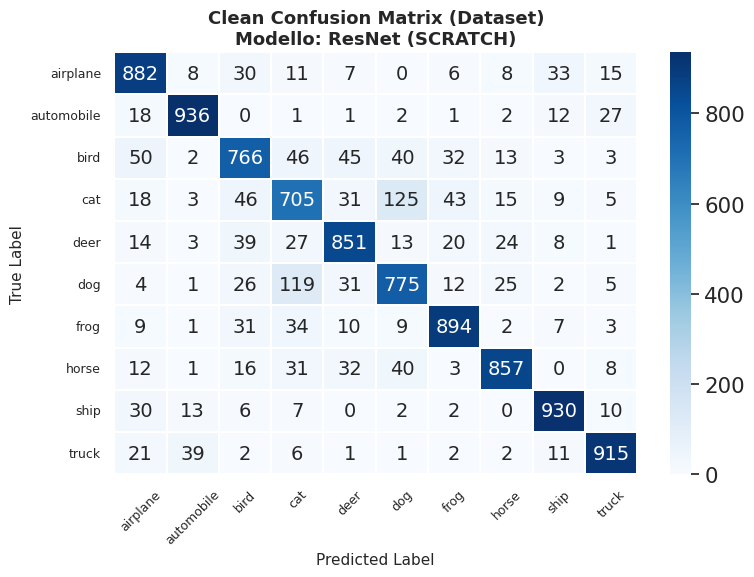


📋 KEY METRICS TABLE:
           Model  Strategy           Mode  Clean_Acc (%)  Clean_F1
Evaluated Model    SCRATCH CLEAN_BASELINE          85.11    0.8509

🧹 [Memory Cleanup] RAM: 2.78/31.35 GB (10.4%)


In [18]:
if should_run_section('INFERENCE_EVAL'):
    clean_memory()
    import os
    import glob
    import re
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import matplotlib.pyplot as plt
    import seaborn as sns
    from tqdm.auto import tqdm
    from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

    criterion = nn.CrossEntropyLoss()
    BEST_MODEL_PATH = IMPORTED_MODEL_PATH if ('USE_IMPORTED_MODEL' in globals() and USE_IMPORTED_MODEL) else PATH_CONFIG.get('best_model_path', '/kaggle/working/best_model_grid_search.pth')

    # Hardware accelerator check
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type == "cpu":
        print("⚠️ [HARDWARE WARNING] GPU not detected! Inference is running on CPU.")
    else:
        print(f"🚀 [ACCELERATION ACTIVE] Inference device: {torch.cuda.get_device_name(0)}")

    # 1. Retrieval of the inspected model (single resolver of the forensic contract)
    eval_model = get_audit_model(required=False)
    if eval_model is None:
        raise FileNotFoundError(f"Unable to find the model for inference in {BEST_MODEL_PATH}")

    eval_model = eval_model.to(device)
    eval_model.eval()

    current_model = eval_model
    best_model = eval_model
    model = eval_model

    # Determination of context and adaptive transformations (local strategy: global best_strat is not rewritten)
    ctx = get_model_eval_context(eval_model, device=device)
    is_pipeline = ctx['is_pipeline']
    eval_transform = ctx['transform']
    infer_strat = ctx['strategy']

    # Supervised branch only in the oracle modes: in BLIND_AUDIT / CLEAN_BASELINE any
    # poison_test_loader left over in a reused kernel is ignored.
    current_mode = str(globals().get('EXECUTION_MODE', 'FULL_PIPELINE_LEGACY')).upper()
    is_clean_baseline = bool(globals().get('CLEAN_BASELINE_MODE', False) or (current_mode == 'CLEAN_BASELINE'))
    is_blind_audit = (not oracle_allowed()) or is_clean_baseline

    # ===========================================================================
    # 1. LOADING / CREATION OF TEST DATALOADERS (ROBUST AND WORKER-RESILIENT)
    # ===========================================================================
    infer_batch_size = 64 if is_pipeline else max(128, globals().get("BATCH_SIZE", 128))

    # Integrity check of the existing DataLoader (zero-overhead, does not consume the first batch)
    is_clean_loader_healthy = ("test_loader" in globals() and test_loader is not None and hasattr(test_loader, "dataset") and len(test_loader.dataset) > 0)
    is_poison_loader_healthy = (is_blind_audit or ("poison_test_loader" in globals() and poison_test_loader is not None and hasattr(poison_test_loader, "dataset") and len(poison_test_loader.dataset) > 0))

    need_rebuild = (not is_clean_loader_healthy) or ((not is_blind_audit) and (not is_poison_loader_healthy))

    if need_rebuild:
        print("⏳ Creating dedicated test DataLoaders for inference...")
        _, raw_test_fresh, clean_train_fresh, clean_test_fresh, _ = load_raw_and_clean_datasets(
            PATH_DATASET, DATASET_CONFIG.get("dataset_type", "auto")
        )
        ds_type = DATASET_CONFIG.get("dataset_type", "auto").upper()
        if ds_type == "CIFAR10":
            import torchvision
            use_download = not os.path.exists(PATH_DATASET)
            evaluation_clean_test = torchvision.datasets.CIFAR10(
                root=PATH_DATASET, train=False, download=use_download, transform=eval_transform
            )
        else:
            evaluation_clean_test = clean_test_fresh
            set_dataset_transform(evaluation_clean_test, eval_transform)

        clean_test_dataset = evaluation_clean_test
        test_loader = make_loader(evaluation_clean_test, batch_size=infer_batch_size, shuffle=False, drop_last=False)

        if not is_blind_audit:
            test_indices_fresh = list(range(len(evaluation_clean_test)))
            _p_mode_infer = str(POISONING_CONFIG.get("poisoning_mode", "replacement")) if "POISONING_CONFIG" in globals() else "replacement"
            _p_atk_infer = str(POISONING_CONFIG.get("attack_type", "dirty")) if "POISONING_CONFIG" in globals() else "dirty"
            poison_test_dataset = create_poisoned_dataset(
                raw_dataset=raw_test_fresh,
                clean_dataset=evaluation_clean_test,
                current_subset_indices=test_indices_fresh,
                poisoning_ratio=1.0,
                transform=eval_transform,
                strategy=infer_strat,
                target_label=TARGET_LABEL,
                poisoning_mode=_p_mode_infer,
                is_train=False,
                attack_type=_p_atk_infer,
            )
            asr_test_dataset = poison_test_dataset
            poison_test_loader = make_loader(poison_test_dataset, batch_size=infer_batch_size, shuffle=False, drop_last=False)
        else:
            poison_test_loader = None
    else:
        # If the loaders come from a cell with num_workers=0 (e.g. defensive setup), we update them with multi-worker make_loader to maximize I/O throughput (GTSRB/CIFAR)
        if hasattr(test_loader, 'num_workers') and test_loader.num_workers == 0 and os.name != 'nt':
            test_loader = make_loader(test_loader.dataset, batch_size=infer_batch_size, shuffle=False, drop_last=False)
        if (not is_blind_audit) and poison_test_loader is not None and hasattr(poison_test_loader, 'num_workers') and poison_test_loader.num_workers == 0 and os.name != 'nt':
            poison_test_loader = make_loader(poison_test_loader.dataset, batch_size=infer_batch_size, shuffle=False, drop_last=False)
        print("⚡ Test DataLoaders verified and active in memory (optimized with multi-threading).")

    clean_loader = test_loader
    poison_loader = globals().get("poison_test_loader", None) if not is_blind_audit else None
    if is_blind_audit:
        poison_test_loader = None

    # Mixed Precision configuration for very high-speed inference
    use_amp = (device.type == "cuda")

    # Safe fallback helper in case of a worker crash during the loop
    def safe_evaluate_loader(loader, desc_name):
        loss_val = 0.0
        preds_list, targets_list = [], []
        try:
            for inputs, targets in tqdm(loader, desc=desc_name, leave=False):
                inputs = inputs.to(device, non_blocking=True)
                targets = targets.to(device, non_blocking=True)
                with torch.amp.autocast(device_type=device.type, enabled=use_amp):
                    outputs = eval_model(inputs)
                    loss = criterion(outputs, targets)
                loss_val += loss.item() * inputs.size(0)
                preds_list.append(outputs.argmax(dim=1))
                targets_list.append(targets)
        except RuntimeError as e:
            if "DataLoader worker" in str(e) or "exited unexpectedly" in str(e):
                print(f"⚠️ IPC worker interrupted ({e}). Running fallback to single worker (main thread)...")
                fallback_loader = torch.utils.data.DataLoader(
                    loader.dataset, batch_size=infer_batch_size, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available()
                )
                loss_val = 0.0
                preds_list, targets_list = [], []
                for inputs, targets in tqdm(fallback_loader, desc=f"{desc_name} (Safe Fallback)", leave=False):
                    inputs = inputs.to(device, non_blocking=True)
                    targets = targets.to(device, non_blocking=True)
                    with torch.amp.autocast(device_type=device.type, enabled=use_amp):
                        outputs = eval_model(inputs)
                        loss = criterion(outputs, targets)
                    loss_val += loss.item() * inputs.size(0)
                    preds_list.append(outputs.argmax(dim=1))
                    targets_list.append(targets)
            else:
                raise e

        loss_avg = loss_val / len(loader.dataset)
        preds_arr = torch.cat(preds_list).cpu().numpy()
        targets_arr = torch.cat(targets_list).cpu().numpy()
        return loss_avg, preds_arr, targets_arr

    # ===========================================================================
    # 2. CLEAN TEST SET (REAL DATASET) EVALUATION WITH AMP ACCELERATION
    # ===========================================================================
    print("⏳ Computing metrics on Clean Test Set...")
    with torch.no_grad():
        clean_loss, clean_preds, clean_targets = safe_evaluate_loader(test_loader, "🧼 Clean Test Evaluation")

    clean_acc = accuracy_score(clean_targets, clean_preds)
    clean_f1 = f1_score(clean_targets, clean_preds, average="weighted")

    # Immediate recording in RUN_RESULTS (valid for ALL modes including BLIND_AUDIT and MODEL_ONLY)
    record_metric("clean_acc", float(round(clean_acc * 100, 2)), method="INFERENCE_EVAL", level="model", unit="percent",
                  note=f"clean test set (n={len(clean_targets)})")
    record_metric("clean_f1", float(round(clean_f1, 4)), method="INFERENCE_EVAL", level="model", unit="fraction",
                  note="weighted F1 on the clean test set")

    # ===========================================================================
    # 3. POISONED TEST SET EVALUATION (ONLY IF NOT IN BLIND AUDIT)
    # ===========================================================================
    if not is_blind_audit and poison_test_loader is not None:
        print("⏳ Computing metrics on Poisoned Test Set (Attack Success Rate)...")
        with torch.no_grad():
            poison_loss, poison_preds_arr, poison_targets_arr = safe_evaluate_loader(
                poison_test_loader, "🎯 ASR Test Evaluation (Poison)"
            )

        # Rigorous Attack Success Rate (ASR) calculation excluding the original target class
        non_target_mask = (poison_targets_arr != TARGET_LABEL)
        _n_asr = int(np.sum(non_target_mask))
        asr = float(np.sum(poison_preds_arr[non_target_mask] == TARGET_LABEL) / _n_asr) if _n_asr > 0 else float("nan")

        attack_acc = float(accuracy_score(poison_targets_arr, poison_preds_arr))

        # (Oracle) evaluation on the poisoned TEST set: key 'asr' distinct from the validation ASR
        # of the training ('final_val_asr', cell 22), which is no longer overwritten.
        record_metric("asr", float(round(asr * 100, 2)) if _n_asr > 0 else float("nan"),
                      "computed" if _n_asr > 0 else "insufficient_data", method="INFERENCE_EVAL", level="model",
                      unit="percent", requires_ground_truth=True, note=f"poisoned test set, n_non_target={_n_asr}")
        record_metric("attack_acc", float(round(attack_acc * 100, 2)), method="INFERENCE_EVAL", level="model",
                      unit="percent", requires_ground_truth=True, note="accuracy on the original labels of the inputs with trigger")
    else:
        poison_loss = float("nan")
        asr = float("nan")
        attack_acc = float("nan")
        poison_preds_arr = np.array([])
        poison_targets_arr = np.array([])
        non_target_mask = np.array([])
        record_metric("asr", float("nan"), "not_applicable", method="INFERENCE_EVAL", level="model", unit="percent",
                      requires_ground_truth=True, note="no known trigger/target in this mode")
        record_metric("attack_acc", float("nan"), "not_applicable", method="INFERENCE_EVAL", level="model", unit="percent",
                      requires_ground_truth=True, note="no known trigger/target in this mode")

    # 4. Printing of the Results
    print(f"\n📈 TEST SET RESULTS - MODEL ({infer_strat.upper()} | Mode: {current_mode}):")
    print(f"  • Clean Test Loss:      {clean_loss:.4f}")
    print(f"  • Clean Accuracy:       {clean_acc * 100:.2f}%")
    print(f"  • Clean Weighted F1:    {clean_f1:.4f}")
    if not is_blind_audit:
        print(f"  • Poison Test Loss:     {poison_loss:.4f}")
        print(f"  • Attack Success Rate:  {asr * 100:.2f}%")
        print(f"  • Accuracy under Attack:{attack_acc * 100:.2f}%\n")
    else:
        print("  • Notes: BLIND_AUDIT mode active — no matrix or metric generated on artificially poisoned data.\n")

    # ===========================================================================
    # 5. CONFUSION MATRICES (OPTIMIZED WITH DYNAMIC RESIZE WITHOUT OOM)
    # ===========================================================================
    all_label_ids = list(range(NUM_CLASSES))
    all_label_names = CLASS_NAMES if ("CLASS_NAMES" in globals() and len(CLASS_NAMES) >= NUM_CLASSES) else [str(i) for i in range(NUM_CLASSES)]
    tick_rotation = 90 if NUM_CLASSES > 15 else 45
    annot_cm = NUM_CLASSES <= 15  # CPU rendering optimization on many labels (GTSRB=43, CIFAR-100=100)

    if is_blind_audit:
        # Single panel for Clean Confusion Matrix
        fig_w = max(8, min(16, NUM_CLASSES * 0.4))
        fig_h = max(6, min(14, NUM_CLASSES * 0.35))
        fig, ax = plt.subplots(figsize=(fig_w, fig_h))

        cm_clean = confusion_matrix(clean_targets, clean_preds, labels=all_label_ids)
        sns.heatmap(
            cm_clean,
            annot=annot_cm,
            fmt="d" if annot_cm else "",
            cmap="Blues",
            ax=ax,
            xticklabels=all_label_names,
            yticklabels=all_label_names,
            linewidths=0.2 if NUM_CLASSES <= 20 else 0,
        )
        ax.set_title(
            f"Clean Confusion Matrix (Dataset)\nModel: {eval_model.__class__.__name__} ({infer_strat.upper()})",
            fontsize=13,
            fontweight="bold",
        )
        ax.set_xlabel("Predicted Label", fontsize=11)
        ax.set_ylabel("True Label", fontsize=11)
        ax.tick_params(axis="x", rotation=tick_rotation, labelsize=max(6, 10 - NUM_CLASSES // 10))
        ax.tick_params(axis="y", rotation=0, labelsize=max(6, 10 - NUM_CLASSES // 10))

    else:
        # Double panel: Clean + Poisoned
        fig_w = max(14, min(24, NUM_CLASSES * 0.6))
        fig_h = max(6, min(12, NUM_CLASSES * 0.4))
        fig, axes = plt.subplots(1, 2, figsize=(fig_w, fig_h))

        # --- Clean Confusion Matrix ---
        cm_clean = confusion_matrix(clean_targets, clean_preds, labels=all_label_ids)
        sns.heatmap(
            cm_clean,
            annot=annot_cm,
            fmt="d" if annot_cm else "",
            cmap="Blues",
            ax=axes[0],
            xticklabels=all_label_names,
            yticklabels=all_label_names,
            linewidths=0.2 if NUM_CLASSES <= 20 else 0,
        )
        axes[0].set_title(
            f"Clean Confusion Matrix\nBest Model ({infer_strat.upper()})",
            fontsize=13,
            fontweight="bold",
        )
        axes[0].set_xlabel("Predicted Label", fontsize=11)
        axes[0].set_ylabel("True Label", fontsize=11)
        axes[0].tick_params(axis="x", rotation=tick_rotation, labelsize=max(6, 10 - NUM_CLASSES // 10))
        axes[0].tick_params(axis="y", rotation=0, labelsize=max(6, 10 - NUM_CLASSES // 10))

        # --- Poisoned Confusion Matrix ---
        non_target_ids = [i for i in all_label_ids if i != TARGET_LABEL]
        non_target_names = [all_label_names[i] for i in non_target_ids]
        filtered_targets = poison_targets_arr[non_target_mask]
        filtered_preds = poison_preds_arr[non_target_mask]

        cm_poison = confusion_matrix(filtered_targets, filtered_preds, labels=all_label_ids)
        cm_poison_reduced = cm_poison[non_target_ids, :]

        sns.heatmap(
            cm_poison_reduced,
            annot=annot_cm,
            fmt="d" if annot_cm else "",
            cmap="Reds",
            ax=axes[1],
            xticklabels=all_label_names,
            yticklabels=non_target_names,
            linewidths=0.2 if NUM_CLASSES <= 20 else 0,
        )
        target_name = CLASS_NAMES[TARGET_LABEL] if ("CLASS_NAMES" in globals() and TARGET_LABEL < len(CLASS_NAMES)) else str(TARGET_LABEL)
        axes[1].set_title(
            f"Poisoned Confusion Matrix (Target: {target_name})\nBest Model ({infer_strat.upper()})",
            fontsize=13,
            fontweight="bold",
        )
        axes[1].set_xlabel("Predicted Label", fontsize=12)
        axes[1].set_ylabel("True Label (Excl. Target)", fontsize=12)
        axes[1].tick_params(axis="x", rotation=tick_rotation, labelsize=max(6, 10 - NUM_CLASSES // 10))
        axes[1].tick_params(axis="y", rotation=0, labelsize=max(6, 10 - NUM_CLASSES // 10))

    plt.tight_layout()
    plt.show()

    # 6. Summary Metrics Table
    summary_data = {
        "Model": "Evaluated Model",
        "Strategy": infer_strat.upper(),
        "Mode": current_mode,
        "Clean_Acc (%)": round(clean_acc * 100, 2),
        "Clean_F1": round(clean_f1, 4),
    }
    if not is_blind_audit:
        summary_data["ASR (%)"] = round(asr * 100, 2)
        summary_data["Attack_Acc (%)"] = round(attack_acc * 100, 2)

    summary_df = pd.DataFrame([summary_data])
    print("\n" + "=" * 80)
    print("📋 KEY METRICS TABLE:")
    print("=" * 80)
    print(summary_df.to_string(index=False))
    print("=" * 80 + "\n")

    check_model_integrity("INFERENCE_EVAL")
    clean_memory(verbose=True)


---
## 🎯 10. Grad-CAM

👁️ GRAD-CAM++ MULTI-SCALE FORENSICS: Bottleneck + Bottleneck (High-Res Stage)
📦 Backbone: ResNet | Resolution: 32x32 (scratch) | Mode: CLEAN_BASELINE
✅ [GRAD-CAM++] Comparative overview saved to: /kaggle/working/gradcam_overview_blind_scratch.png


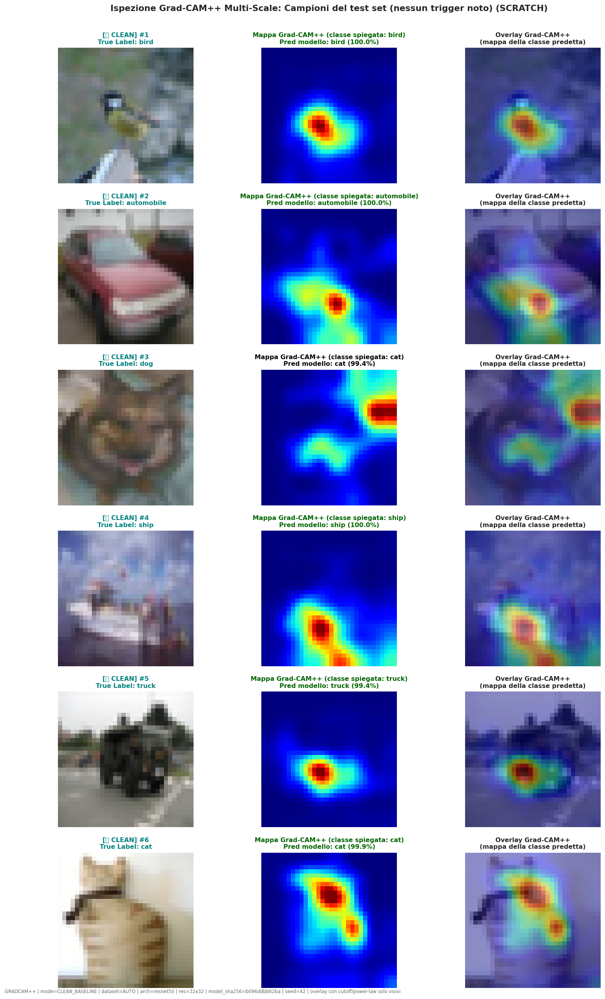

In [19]:
if should_run_section('GRADCAM'):
    clean_memory()
    # ==============================================================================
    # EXPLAINABILITY SECTION - HIGH-RESOLUTION MULTI-SCALE GRAD-CAM++ FORENSICS
    # Chattopadhyay et al. (2018) formulation + Multi-Scale Feature Fusion
    # Precise resolution of local triggers (BadNets) and organic semantic focus
    # ==============================================================================
    import os
    import cv2
    import numpy as np
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, Subset
    import matplotlib.pyplot as plt
    from PIL import Image

    # ------------------------------------------------------------------------------
    # 1. MULTI-SCALE GRAD-CAM++ EXPLAINER (HIGH-RESOLUTION SPATIAL PRECISION)
    # ------------------------------------------------------------------------------
    class HighResGradCAMExplainer:
        """
        Computes the multi-scale Grad-CAM++ saliency map (Chattopadhyay et al., 2018):
        - Second and third order weights (alpha_ijk) to avoid GAP cancellation.
        - Multi-layer fusion (semantic Stage 4 + spatially high-resolution Stage 3):
          Hadamard product between the two maps. The fusion is NOT part of the original method
          (notebook variant): it is a visualization tool, not a measurement.
        """
        def __init__(self, model, primary_layer, highres_layer=None):
            self.model = model
            self.primary_layer = primary_layer
            self.highres_layer = highres_layer
            self.layer_name = primary_layer.__class__.__name__

            self.primary_act = None
            self.primary_grad = None
            self.highres_act = None
            self.highres_grad = None
            self.handles = []

            # We ensure gradient computation on the layer parameters
            for p in self.primary_layer.parameters():
                p.requires_grad = True
            if self.highres_layer is not None:
                for p in self.highres_layer.parameters():
                    p.requires_grad = True

            # Primary hook (deep / semantic layer)
            self.handles.append(self.primary_layer.register_forward_hook(self._save_primary_act))
            try:
                self.handles.append(self.primary_layer.register_full_backward_hook(self._save_primary_grad))
            except Exception:
                self.handles.append(self.primary_layer.register_backward_hook(self._save_primary_grad))

            # High-resolution hook (previous layer, e.g. layer3 in ResNet)
            if self.highres_layer is not None:
                self.handles.append(self.highres_layer.register_forward_hook(self._save_highres_act))
                try:
                    self.handles.append(self.highres_layer.register_full_backward_hook(self._save_highres_grad))
                except Exception:
                    self.handles.append(self.highres_layer.register_backward_hook(self._save_highres_grad))

        def _save_primary_act(self, module, inp, output):
            self.primary_act = output.detach()

        def _save_primary_grad(self, module, grad_input, grad_output):
            if grad_output is not None and len(grad_output) > 0 and grad_output[0] is not None:
                self.primary_grad = grad_output[0].detach()

        def _save_highres_act(self, module, inp, output):
            self.highres_act = output.detach()

        def _save_highres_grad(self, module, grad_input, grad_output):
            if grad_output is not None and len(grad_output) > 0 and grad_output[0] is not None:
                self.highres_grad = grad_output[0].detach()

        def _compute_cam_plusplus(self, activations, gradients):
            """Analytic Grad-CAM++ formula (Chattopadhyay et al., 2018)"""
            grad_2 = gradients.pow(2)
            grad_3 = gradients.pow(3)
            sum_act = activations.sum(dim=(1, 2), keepdim=True)
            denom = 2.0 * grad_2 + sum_act * grad_3
            denom = torch.where(denom != 0.0, denom, torch.ones_like(denom))
            alpha_ij = grad_2 / denom
            weights = (alpha_ij * torch.relu(gradients)).sum(dim=(1, 2))  # [C]
            cam = torch.relu((weights[:, None, None] * activations).sum(dim=0))
            return cam

        def generate_cam(self, input_tensor, target_class=None):
            self.model.eval()
            self.primary_act = None
            self.primary_grad = None
            self.highres_act = None
            self.highres_grad = None

            with torch.enable_grad():
                inp = input_tensor.clone().detach().requires_grad_(True)
                self.model.zero_grad(set_to_none=True)
                output = self.model(inp)

                # Explained class and predicted class are distinct: with an explicit target_class the map
                # explains that logit, but the reported prediction remains the real argmax of the model.
                pred_class = int(output.argmax(dim=1).item())
                explained_class = pred_class if target_class is None else int(target_class)

                score = output[0, explained_class]
                score.backward(retain_graph=False)

            if self.primary_grad is None or self.primary_act is None:
                raise RuntimeError("Grad-CAM: primary gradients or activations not recorded.")

            # 1. Primary CAM Computation
            cam_primary = self._compute_cam_plusplus(self.primary_act[0], self.primary_grad[0])

            # 2. Multi-Scale Fusion (if a high-resolution layer is available)
            if self.highres_act is not None and self.highres_grad is not None:
                cam_highres = self._compute_cam_plusplus(self.highres_act[0], self.highres_grad[0])
                # Upsampling of the primary CAM to the fine grid and Hadamard multiplication (Spatial Gating)
                h_size = cam_highres.shape
                cam_primary_up = F.interpolate(
                    cam_primary.unsqueeze(0).unsqueeze(0), size=h_size, mode="bilinear", align_corners=False
                )[0, 0]
                cam_fused = cam_highres * cam_primary_up
            else:
                cam_fused = cam_primary

            # 3. Robust Min-Max Normalization
            c_min, c_max = cam_fused.min(), cam_fused.max()
            if (c_max - c_min) > 1e-8:
                cam_norm = (cam_fused - c_min) / (c_max - c_min)
            else:
                cam_norm = torch.zeros_like(cam_fused)

            cam_np = cam_norm.cpu().detach().numpy()
            out_logits = output.detach()
            return cam_np, explained_class, pred_class, out_logits

        def remove_hooks(self):
            for h in self.handles:
                try:
                    h.remove()
                except Exception:
                    pass
            self.handles.clear()

    def tensor_to_img(tensor, mean_val, std_val):
        img = tensor.cpu().squeeze(0).permute(1, 2, 0).numpy()
        # Defensive check: de-normalize only if tensor is in normalized range
        if img.min() < 0.0 or img.max() > 1.0:
            std_arr = np.array(std_val)
            mean_arr = np.array(mean_val)
            img = img * std_arr + mean_arr
        img = np.clip(img, 0.0, 1.0)
        return (img * 255).astype(np.uint8)

    def apply_organic_cam_overlay(img_np, cam, alpha=0.45, power_contrast=1.5, percentile_cutoff=8):
        """
        Generates an organic, sharp and highly informative overlay (RISE/BYE style):
        - Continuous high-resolution bicubic OpenCV upsampling.
        - Power-law scaling to concentrate the heat peak and eliminate the blurry halo.
        - Adaptive cutoff on the low percentiles to clean the background noise.
        """
        # Precise bicubic interpolation to the original dimensions
        cam_resized = cv2.resize(cam.astype(np.float32), (img_np.shape[1], img_np.shape[0]), interpolation=cv2.INTER_CUBIC)
        cam_resized = np.clip(cam_resized, 0.0, 1.0)

        # Background noise cleanup with adaptive threshold
        if percentile_cutoff > 0:
            threshold = float(np.percentile(cam_resized, percentile_cutoff))
            cam_clean = np.maximum(0.0, cam_resized - threshold)
            max_v = cam_clean.max()
            if max_v > 1e-6:
                cam_clean = cam_clean / max_v
            cam_resized = cam_clean

        # Power contrast for sharp focusing of the peak (eliminates the huge area)
        cam_focused = np.power(cam_resized, power_contrast)

        # Normalized JET heatmap
        heatmap_float = plt.get_cmap("jet")(cam_focused)[:, :, :3]
        img_float = img_np.astype(np.float32) / 255.0
        overlay_float = np.clip((1.0 - alpha) * img_float + alpha * heatmap_float, 0.0, 1.0)
        overlay_uint8 = (overlay_float * 255.0).astype(np.uint8)
        cam_display = (cam_focused * 255.0).astype(np.uint8)
        return overlay_uint8, cam_display

    # ------------------------------------------------------------------------------
    # 2. MODEL RESOLUTION & HIGH-FIDELITY LAYER SELECTION
    # ------------------------------------------------------------------------------
    import contextlib
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    gcam_model = get_audit_model(required=False)

    if gcam_model is None:
        print("⚠️ No model available for Grad-CAM.")
    else:
        # requires_grad/train-eval restored at the end of the section; hooks removed even in case of error.
        with preserve_model_state(gcam_model), contextlib.ExitStack() as _gcam_stack:
            gcam_model.eval().to(device)

            gcam_ctx = get_model_eval_context(gcam_model, device=device)
            is_pipeline = gcam_ctx["is_pipeline"]
            gcam_strat = gcam_ctx["strategy"]
            eval_transform = gcam_ctx["transform"]
            mean_used = gcam_ctx["mean"].tolist()
            std_used = gcam_ctx["std"].tolist()
            gcam_classes = list(CLASS_NAMES) if globals().get("CLASS_NAMES") else [str(i) for i in range(NUM_CLASSES)]
            current_mode = str(globals().get('EXECUTION_MODE', 'FULL_PIPELINE_LEGACY')).upper()
            _is_clean_gcam = bool(globals().get('CLEAN_BASELINE_MODE', False) or (current_mode == 'CLEAN_BASELINE'))
            # Attack target used only for evaluation (oracle): never to choose layers or clean samples.
            is_attacker_or_legacy = oracle_allowed() and (not _is_clean_gcam) and ("TARGET_LABEL" in globals()) and int(TARGET_LABEL) >= 0
            tgt_label = int(TARGET_LABEL) if is_attacker_or_legacy else None

            # Hierarchical resolution: Primary (Stage 4) + High-Res (Stage 3) for ResNet/VGG/MobileNet
            def _get_gradcam_stages(net):
                prim_layer, high_layer = None, None
                if hasattr(net, 'layer4') and hasattr(net, 'layer3'):
                    prim_layer = net.layer4[-1] if (isinstance(net.layer4, (nn.Sequential, list, tuple)) and len(net.layer4) > 0) else net.layer4
                    high_layer = net.layer3[-1] if (isinstance(net.layer3, (nn.Sequential, list, tuple)) and len(net.layer3) > 0) else net.layer3
                elif hasattr(net, 'features'):
                    convs = [m for m in net.features.modules() if isinstance(m, nn.Conv2d)]
                    if len(convs) >= 2:
                        prim_layer, high_layer = convs[-1], convs[-2]
                    elif convs:
                        prim_layer = convs[-1]
                else:
                    convs = [m for name, m in net.named_modules() if isinstance(m, nn.Conv2d) and 'downsample' not in name]
                    if len(convs) >= 2:
                        prim_layer, high_layer = convs[-1], convs[-2]
                    elif convs:
                        prim_layer = convs[-1]
                return prim_layer, high_layer

            primary_target, highres_target = _get_gradcam_stages(gcam_model)
            if primary_target is None:
                primary_target = gcam_model

            explainer = HighResGradCAMExplainer(gcam_model, primary_target, highres_target)
            _gcam_stack.callback(explainer.remove_hooks)

            highres_desc = f" + {highres_target.__class__.__name__} (High-Res Stage)" if highres_target is not None else ""
            print("=" * 95)
            print(f"👁️ GRAD-CAM++ MULTI-SCALE FORENSICS: {explainer.layer_name}{highres_desc}")
            print(f"📦 Backbone: {gcam_model.__class__.__name__} | Resolution: {gcam_ctx['target_res']}x{gcam_ctx['target_res']} ({gcam_strat}) | Mode: {current_mode}")
            print("=" * 95)

            # --------------------------------------------------------------------------
            # 3. ADAPTIVE SAMPLING (CLEAN vs POISONED)
            # --------------------------------------------------------------------------
            samples_to_analyze = []

            # A. Clean Samples (prioritize raw to avoid double transformation/normalization)
            clean_src = (
                globals().get("raw_test_dataset")
                or globals().get("clean_test_dataset")
                or globals().get("raw_train_dataset")
                or (test_loader.dataset if "test_loader" in globals() and test_loader is not None else None)
            )

            n_clean_take = 3 if is_attacker_or_legacy else 6
            if clean_src is not None:
                n_avail_clean = len(clean_src)
                clean_indices = np.random.RandomState(42).choice(n_avail_clean, min(n_clean_take, n_avail_clean), replace=False)
                for c_idx in clean_indices:
                    item = clean_src[c_idx]
                    c_img, c_lbl = item[0], item[1]
                    if not isinstance(c_img, torch.Tensor):
                        c_img = eval_transform(c_img)
                    samples_to_analyze.append((c_img, int(c_lbl), False, "🧼 CLEAN"))

            # B. Poisoned Samples (oracle evaluation only; the poisoned train set is not used because
            #    its labels are already the target and it would also contain clean samples)
            if is_attacker_or_legacy:
                poison_src = (
                    globals().get("asr_test_dataset")
                    or globals().get("poison_test_dataset")
                    or (globals().get("poison_test_loader").dataset if globals().get("poison_test_loader") is not None and hasattr(globals().get("poison_test_loader"), "dataset") else None)
                )

                if poison_src is None and "create_poisoned_dataset" in globals() and clean_src is not None:
                    raw_src = globals().get("raw_test_dataset", clean_src)
                    sub_idx = list(range(len(clean_src)))
                    p_mode = POISONING_CONFIG.get("poisoning_mode", "replacement") if "POISONING_CONFIG" in globals() else "replacement"
                    p_atk = POISONING_CONFIG.get("attack_type", "dirty") if "POISONING_CONFIG" in globals() else "dirty"
                    poison_src = create_poisoned_dataset(
                        raw_dataset=raw_src,
                        clean_dataset=clean_src,
                        current_subset_indices=sub_idx,
                        poisoning_ratio=1.0,
                        transform=eval_transform,
                        strategy=gcam_strat,
                        target_label=tgt_label,
                        poisoning_mode=p_mode,
                        attack_type=p_atk,
                        is_train=False
                    )

                if poison_src is not None:
                    n_avail_poison = len(poison_src)
                    poison_indices = np.random.RandomState(101).choice(n_avail_poison, min(3, n_avail_poison), replace=False)
                    for p_idx in poison_indices:
                        item_p = poison_src[p_idx]
                        p_img, p_lbl = item_p[0], item_p[1]
                        if not isinstance(p_img, torch.Tensor):
                            p_img = eval_transform(p_img)
                        samples_to_analyze.append((p_img, int(p_lbl), True, "☣️ POISONED"))

            # --------------------------------------------------------------------------
            # 4. INVESTIGATIVE GENERATION & RENDERING
            # --------------------------------------------------------------------------
            total_samples = len(samples_to_analyze)
            n_poison_shown = sum(1 for s in samples_to_analyze if s[2])
            if total_samples > 0:
                fig, axes = plt.subplots(total_samples, 3, figsize=(14, 3.5 * total_samples), dpi=120)
                if total_samples == 1:
                    axes = np.expand_dims(axes, axis=0)

                softmax_fn = nn.Softmax(dim=1)
                cached_evaluations = []
                target_name = (gcam_classes[tgt_label] if tgt_label < len(gcam_classes) else str(tgt_label)) if tgt_label is not None else None

                for idx, (img_t, orig_lbl, is_poison, tag_str) in enumerate(samples_to_analyze):
                    img_tensor_in = img_t.unsqueeze(0).to(device)
                    # For the poisoned samples (oracle) the map explains the logit of the attack target;
                    # the shown prediction and the attack success derive from the real argmax.
                    cam_target = tgt_label if is_poison else None
                    cam, expl_cls, pred_cls, logits = explainer.generate_cam(img_tensor_in, target_class=cam_target)
                    probs = softmax_fn(logits).cpu().numpy().squeeze()
                    conf = float(probs[pred_cls] * 100.0)

                    cached_evaluations.append((img_tensor_in, cam, orig_lbl, pred_cls, expl_cls, logits, is_poison))

                    img_np = tensor_to_img(img_tensor_in, mean_used, std_used)
                    overlay_np, cam_map = apply_organic_cam_overlay(img_np, cam, alpha=0.45, power_contrast=1.5, percentile_cutoff=8)

                    orig_name = gcam_classes[orig_lbl] if orig_lbl < len(gcam_classes) else f"Class {orig_lbl}"
                    pred_name = gcam_classes[pred_cls] if pred_cls < len(gcam_classes) else f"Class {pred_cls}"
                    expl_name = gcam_classes[expl_cls] if expl_cls < len(gcam_classes) else f"Class {expl_cls}"

                    if is_poison:
                        col1_title = f"[{tag_str}] #{idx+1}\nTrue Origin: {orig_name}\nImposed Target: {target_name}"
                    else:
                        col1_title = f"[{tag_str}] #{idx+1}\nTrue Label: {orig_name}"

                    axes[idx, 0].imshow(img_np)
                    axes[idx, 0].set_title(col1_title, fontsize=9.5, fontweight="bold", color="crimson" if is_poison else "teal")
                    axes[idx, 0].axis("off")

                    is_success_attack = is_poison and (pred_cls == tgt_label)
                    pred_color = "red" if is_poison and is_success_attack else ("darkgreen" if not is_poison and pred_cls == orig_lbl else "black")
                    axes[idx, 1].imshow(cam_map, cmap="jet")
                    axes[idx, 1].set_title(f"Grad-CAM++ Map (explained class: {expl_name})\nModel Pred: {pred_name} ({conf:.1f}%)", fontsize=9.5, fontweight="bold", color=pred_color)
                    axes[idx, 1].axis("off")

                    axes[idx, 2].imshow(overlay_np)
                    if is_poison:
                        focus_desc = "attack successful: pred = target (oracle)" if is_success_attack else "attack NOT successful: pred ≠ target (oracle)"
                    else:
                        focus_desc = "map of the predicted class"
                    axes[idx, 2].set_title(f"Grad-CAM++ Overlay\n({focus_desc})", fontsize=9.5, fontweight="bold")
                    axes[idx, 2].axis("off")

                _suptitle_kind = "Clean vs Poisoned Samples (oracle)" if n_poison_shown > 0 else "Test set samples (no known trigger)"
                plt.suptitle(
                    f"Multi-Scale Grad-CAM++ Inspection: {_suptitle_kind} ({gcam_strat.upper()})",
                    fontsize=13, fontweight="bold", y=1.00
                )
                plt.tight_layout()
                fig.text(0.01, 0.005, provenance_caption("GRADCAM++", "overlay with purely visual cutoff/power-law"), fontsize=7, alpha=0.7)

                # --- SAVING THE GENERAL GRAD-CAM OVERVIEW ---
                try:
                    out_dir_cam = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                    os.makedirs(out_dir_cam, exist_ok=True)
                    mode_prefix = "attacker" if current_mode == 'ATTACKER_MODEL_LEVEL' else "blind"
                    gradcam_overview_filename = f"gradcam_overview_{mode_prefix}_{gcam_strat}.png"
                    gradcam_overview_save_path = os.path.join(out_dir_cam, gradcam_overview_filename)
                    fig.savefig(gradcam_overview_save_path, bbox_inches='tight', dpi=150)
                    register_artifact("GRADCAM", gradcam_overview_save_path, note="Grad-CAM++ overview (qualitative)")
                    globals()['GRADCAM_OVERVIEW_IMG_PATH'] = gradcam_overview_save_path
                    globals()['gradcam_overview_img'] = gradcam_overview_filename
                    record_metric('gradcam_overview_img', gradcam_overview_filename, method="GRADCAM", level="sample", note="figure artifact")
                    print(f"✅ [GRAD-CAM++] Comparative overview saved to: {gradcam_overview_save_path}")
                except Exception as e_ov:
                    print(f"⚠️ Note on saving the Grad-CAM overview: {e_ov}")

                plt.show()

                # --------------------------------------------------------------------------
                # 5. SAVING THE SUCCESSFUL ATTACK GRAD-CAM IMAGE (ATTACKER_MODEL_LEVEL ONLY)
                # --------------------------------------------------------------------------
                if current_mode == 'ATTACKER_MODEL_LEVEL' and tgt_label is not None:
                    try:
                        # Only a sample whose REAL prediction is the target: no fallback on
                        # samples where the attack did not succeed.
                        success_sample = None
                        for (s_in, s_cam, s_orig_lbl, s_pred_cls, s_expl_cls, s_logits, s_is_poison) in cached_evaluations:
                            if s_is_poison and (s_pred_cls == tgt_label):
                                success_sample = (s_in, s_cam, s_orig_lbl, s_pred_cls, s_logits)
                                break

                        if success_sample is None:
                            print("ℹ️ [GRAD-CAM++] None of the poisoned samples shown is classified as target: 'successful attack' figure not generated.")
                            record_metric('gradcam_success_img', float("nan"), "insufficient_data", method="GRADCAM", level="sample",
                                          requires_ground_truth=True, note="no sample with pred = target among those shown")
                        else:
                            s_in, s_cam, s_orig_lbl, s_pred_cls, s_logits = success_sample
                            s_probs = softmax_fn(s_logits).cpu().numpy().squeeze()
                            s_conf = float(s_probs[s_pred_cls] * 100.0)

                            s_img_np = tensor_to_img(s_in, mean_used, std_used)
                            s_overlay_np, s_cam_map = apply_organic_cam_overlay(s_img_np, s_cam, alpha=0.45, power_contrast=1.5, percentile_cutoff=8)

                            s_orig_name = gcam_classes[s_orig_lbl] if s_orig_lbl < len(gcam_classes) else str(s_orig_lbl)
                            s_pred_name = gcam_classes[s_pred_cls] if s_pred_cls < len(gcam_classes) else str(s_pred_cls)

                            fig_succ, axes_succ = plt.subplots(1, 3, figsize=(12, 4), dpi=150)
                            axes_succ[0].imshow(s_img_np)
                            axes_succ[0].set_title(f"Poisoned Input\nTrue: {s_orig_name} | Target: {target_name}", fontsize=10, fontweight="bold")
                            axes_succ[0].axis("off")

                            axes_succ[1].imshow(s_cam_map, cmap="jet")
                            axes_succ[1].set_title(f"Grad-CAM++ (explained class: target)\nModel Pred: {s_pred_name} ({s_conf:.1f}%)", fontsize=10, fontweight="bold", color="red")
                            axes_succ[1].axis("off")

                            axes_succ[2].imshow(s_overlay_np)
                            axes_succ[2].set_title("Overlay (Decision Focus)", fontsize=10, fontweight="bold")
                            axes_succ[2].axis("off")

                            out_dir_cam = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                            os.makedirs(out_dir_cam, exist_ok=True)
                            att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "attack"
                            gradcam_img_filename = f"gradcam_success_{att_type_str}_{gcam_strat}.png"
                            gradcam_save_path = os.path.join(out_dir_cam, gradcam_img_filename)

                            fig_succ.tight_layout()
                            fig_succ.text(0.01, 0.005, provenance_caption("GRADCAM++"), fontsize=7, alpha=0.7)
                            fig_succ.savefig(gradcam_save_path, bbox_inches='tight', dpi=150)
                            plt.close(fig_succ)
                            register_artifact("GRADCAM", gradcam_save_path, note="poisoned sample with pred = target (oracle)")

                            globals()['GRADCAM_SUCCESS_IMG_PATH'] = gradcam_save_path
                            record_metric('gradcam_success_img', gradcam_img_filename, method="GRADCAM", level="sample",
                                          requires_ground_truth=True, note="figure artifact")
                            print(f"✅ [GRAD-CAM++] Successful attack image saved to: {gradcam_save_path}")
                    except Exception as e_cam:
                        print(f"⚠️ Note on saving Grad-CAM: {e_cam}")

        check_model_integrity("GRADCAM")
    clean_memory(verbose=False)


---
## 🛡️ 11. Backdoor Metrics

In [20]:
if should_run_section('NUMERIC_METRICS'):
    clean_memory()
    import os
    import glob
    import re
    import numpy as np
    import torch
    import torchvision
    from torch import nn
    from torchvision import models
    from torch.utils.data import DataLoader
    from sklearn.metrics import accuracy_score

    print("--- STARTING BACKDOOR METRICS EVALUATION ---")

    # ==============================================================================
    # 1. Model Identification (single resolver of the forensic contract)
    # ==============================================================================
    eval_model = get_audit_model(required=False)
    num_ctx = get_model_eval_context(eval_model) if eval_model is not None else None
    strategy_name = num_ctx["strategy"].upper() if num_ctx is not None else "N/D"

    if eval_model is not None:
        eval_model.eval()
        print(f"\n============================================================")
        print(f"Evaluation of Active Model in Memory | Strategy: {strategy_name}")
        # Training report of the selected epoch (cell 22) or metadata of the imported checkpoint:
        # best_overall_config contains only the hyperparameters, not the metrics.
        rep = globals().get("best_overall_report")
        if not isinstance(rep, dict) and isinstance(globals().get("checkpoint_meta"), dict):
            rep = checkpoint_meta.get("best_report", {})
        rep = rep if isinstance(rep, dict) else {}

        def _fmt_rep(v):
            return f"{float(v):.4f}" if isinstance(v, (int, float, np.floating)) and np.isfinite(v) else "n/a"
        f1_val = _fmt_rep(rep.get("final_val_f1"))
        asr_val = _fmt_rep(rep.get("final_val_asr")) if oracle_allowed() else "n/a (non-oracle)"
        toi_val = _fmt_rep(rep.get("trade_off_index")) if oracle_allowed() else "n/a (non-oracle)"

        print(f"📌 [MODEL CHECK] Val F1: {f1_val} | Val ASR: {asr_val} | TOI (F1*ASR): {toi_val} (training validation split)")
        print(f"============================================================")
        run_eval = True
    else:
        print("⚠️ No model found for the metrics evaluation.")
        run_eval = False

    if run_eval:
        # The attack target is only needed by the oracle evaluation metrics (ASR, CTCA, SCA).
        num_oracle = oracle_allowed() and ("TARGET_LABEL" in globals()) and int(TARGET_LABEL) >= 0
        num_target = int(TARGET_LABEL) if num_oracle else None

        # ===========================================================================
        # 2. SMART REUSE OF THE ALREADY EXISTING DATALOADERS (SPEEDUP)
        # ===========================================================================
        current_test_transform = globals().get("transform_pipeline" if num_ctx["is_pipeline"] else "transform_scratch_test") or num_ctx["transform"]
        if "test_loader" in globals() and test_loader is not None:
            c_eval_loader = test_loader
        else:
            print("⏳ Rebuilding clean test DataLoader...")
            _, _, _, evaluation_clean_test, _ = load_raw_and_clean_datasets(PATH_DATASET, DATASET_CONFIG.get("dataset_type", "auto"))
            set_dataset_transform(evaluation_clean_test, current_test_transform)
            c_eval_loader = make_loader(evaluation_clean_test, batch_size=128, shuffle=False, drop_last=False)

        p_eval_loader = None
        if num_oracle:
            if "poison_test_loader" in globals() and poison_test_loader is not None:
                print("⚡ Clean and Poison DataLoaders already ready in memory. Starting predictions extraction...")
                p_eval_loader = poison_test_loader
            else:
                print("⏳ Rebuilding poisoned test DataLoader (oracle evaluation)...")
                num_poison_ds = create_poisoned_dataset(
                    raw_dataset=raw_test_dataset,
                    clean_dataset=c_eval_loader.dataset,
                    current_subset_indices=list(range(len(c_eval_loader.dataset))),
                    poisoning_ratio=1.0,
                    transform=current_test_transform,
                    strategy=num_ctx["strategy"],
                    target_label=num_target,
                    poisoning_mode=str(POISONING_CONFIG.get("poisoning_mode", "replacement")) if "POISONING_CONFIG" in globals() else "replacement",
                    is_train=False,
                )
                p_eval_loader = make_loader(num_poison_ds, batch_size=128, shuffle=False, drop_last=False)
        else:
            print("ℹ️ No known trigger/target in this mode: ASR, CTCA and SCA not applicable.")

        # 3. Utility function for batch predictions
        def get_predictions_from_loader(loader):
            all_preds = []
            all_labels = []
            with torch.no_grad():
                for inputs, labels in loader:
                    inputs = inputs.to(device)
                    outputs = eval_model(inputs)
                    preds = outputs.argmax(dim=1).cpu().numpy()
                    all_preds.extend(preds)
                    all_labels.extend(labels.numpy() if isinstance(labels, torch.Tensor) else np.array(labels))
            return np.array(all_preds), np.array(all_labels)

        # Fast extraction of predictions
        clean_preds, clean_labels = get_predictions_from_loader(c_eval_loader)

        # METRICS COMPUTATION
        clean_acc = accuracy_score(clean_labels, clean_preds) * 100
        print(f"--> Clean Accuracy : {clean_acc:.2f}%")
        record_metric("clean_acc", float(round(clean_acc, 2)), method="NUMERIC_METRICS", level="model", unit="percent",
                      note=f"clean test set (n={len(clean_labels)})")

        _na = dict(method="NUMERIC_METRICS", level="model", unit="percent", requires_ground_truth=True)
        if p_eval_loader is not None:
            poison_preds, poison_labels = get_predictions_from_loader(p_eval_loader)

            # ASR computed excluding the target class for methodological rigor
            non_target_mask = (poison_labels != num_target)
            n_asr = int(np.sum(non_target_mask))
            asr = np.mean(poison_preds[non_target_mask] == num_target) * 100 if n_asr > 0 else np.nan

            # CTCA: accuracy on the clean images of the target class; SCA: on the clean images of the source classes.
            target_indices = np.where(clean_labels == num_target)[0]
            ctca = np.mean(clean_preds[target_indices] == clean_labels[target_indices]) * 100 if len(target_indices) > 0 else np.nan

            source_indices = np.where(clean_labels != num_target)[0]
            sca = np.mean(clean_preds[source_indices] == clean_labels[source_indices]) * 100 if len(source_indices) > 0 else np.nan

            print(f"--> ASR            : {asr:.2f}%   [evaluation (oracle), n={n_asr}]")
            print(f"--> CTCA           : {ctca:.2f}%   [evaluation (oracle), n={len(target_indices)}]")
            print(f"--> SCA            : {sca:.2f}%   [evaluation (oracle), n={len(source_indices)}]")

            # Faithful recording in RUN_RESULTS of the computed metrics
            record_metric("asr", float(round(asr, 2)) if n_asr > 0 else float("nan"), "computed" if n_asr > 0 else "insufficient_data",
                          note=f"poisoned test set, n_non_target={n_asr}", **_na)
            record_metric("ctca", float(round(ctca, 2)) if len(target_indices) > 0 else float("nan"),
                          "computed" if len(target_indices) > 0 else "insufficient_data",
                          note=f"clean accuracy on the target class, n={len(target_indices)}", **_na)
            record_metric("sca", float(round(sca, 2)) if len(source_indices) > 0 else float("nan"),
                          "computed" if len(source_indices) > 0 else "insufficient_data",
                          note=f"clean accuracy on the source classes, n={len(source_indices)}", **_na)
        else:
            for _k in ("asr", "ctca", "sca"):
                record_metric(_k, float("nan"), "not_applicable", note="no known trigger/target in this mode", **_na)

        print("\n--- Per-Class Clean Accuracy Analysis ---")
        if "CLASS_NAMES" in globals() and CLASS_NAMES is not None:
            class_names_list = CLASS_NAMES
        elif "CIFAR10_CLASSES" in globals() and CIFAR10_CLASSES is not None:
            class_names_list = CIFAR10_CLASSES
        elif "classes" in globals() and classes is not None:
            class_names_list = classes
        else:
            class_names_list = [f"Class_{i}" for i in range(NUM_CLASSES)]

        _class_rows = []
        for i in range(NUM_CLASSES):
            idx_class = np.where(clean_labels == i)[0]
            c_name = class_names_list[i] if i < len(class_names_list) else str(i)
            if len(idx_class) > 0:
                acc_class = np.mean(clean_preds[idx_class] == clean_labels[idx_class]) * 100
                is_target = "(TARGET)" if (num_target is not None and i == num_target) else ""
                print(f"  - Class {i:02d} {c_name:<32} {is_target:<8} : {acc_class:.2f}%")
            else:
                acc_class = float("nan")
                print(f"  - Class {i:02d} {c_name:<32} {'':<8} : n/a (no samples in the test set)")
            _class_rows.append({"entity_id": f"class_{i}", "class_id": i, "class_name": c_name,
                                "score": float(acc_class), "note": f"clean accuracy % (n={len(idx_class)})"})
        record_entities("NUMERIC_METRICS", "class", _class_rows)

        check_model_integrity("NUMERIC_METRICS")

    clean_memory(verbose=True)


--- STARTING BACKDOOR METRICS EVALUATION ---

Evaluation of the Active Model in Memory | Strategy: SCRATCH
📌 [MODEL CHECK] Val F1: 0.8609 | Val ASR: n/a (non-oracle) | TOI (F1*ASR): n/a (non-oracle) (training validation split)
ℹ️ No known trigger/target in this mode: ASR, CTCA and SCA not applicable.
--> Clean Accuracy : 85.09%

--- Per-Class Clean Accuracy Analysis ---
  - Class 00 airplane                                  : 88.20%
  - Class 01 automobile                                : 93.60%
  - Class 02 bird                                      : 76.70%
  - Class 03 cat                                       : 70.50%
  - Class 04 deer                                      : 85.10%
  - Class 05 dog                                       : 77.30%
  - Class 06 frog                                      : 89.40%
  - Class 07 horse                                     : 85.60%
  - Class 08 ship                                      : 93.00%
  - Class 09 truck                                 

---
## 📊 12. Confidence & AIP

--- 📊 STARTING CONFIDENCE EVALUATION & FORENSIC PROFILING ---
🛡️ [BLIND AUDIT MODE] Complete Model Profiling | Resolution: 32x32

📌 [GENERAL AUDIT CONFIDENCE REPORT]
   Total Samples Analyzed      : 10000
   Clean Accuracy (Ground-Truth): 0.8511
   Expected Calibr. Error (ECE) : 0.1068
   Global Mean Confidence      : 0.9579 (± 0.1099)
   🔎 Maximum exploratory index (candidate for manual inspection): ID 0 (airplane) with 10.58% of the predictions and mean confidence 0.9573

📊 [PREDICTION AND CONFIDENCE DISTRIBUTION FOR EACH CLASS]
 Class_ID Class_Name  Pred_Count Pred_Percentage (%) Mean_Confidence Std_Confidence
        0   airplane        1058              10.58%          0.9573         0.1078
        1 automobile        1007              10.07%          0.9773         0.0830
        2       bird         962               9.62%          0.9405         0.1252
        3        cat         987               9.87%          0.9247         0.1411
        4       deer        1009           

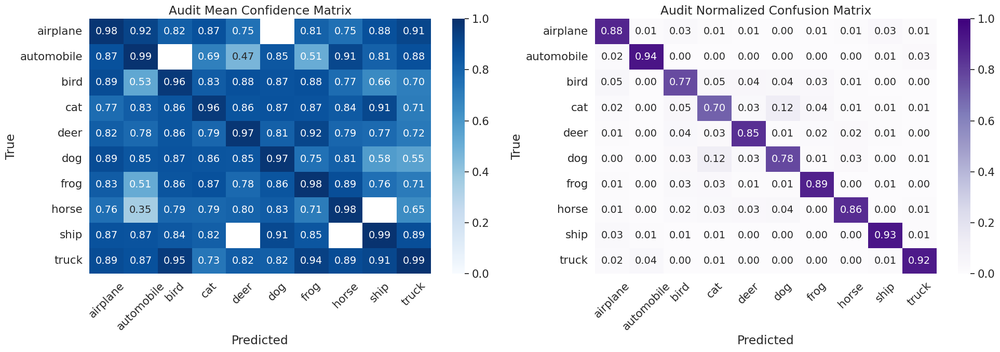

✅ [CONFIDENCE] Blind audit distribution plot saved to: /kaggle/working/confidence_dist_blind_audit_scratch.png


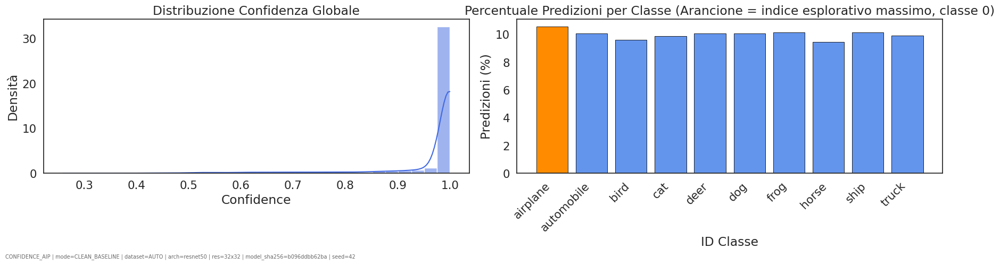

In [21]:
# ==============================================================================
# 📊 [SECTION 12] CONFIDENCE EVALUATION, PREDICTION PERCENTAGES & AIP
# Fully compatible with POISONING (Supervised) and BLIND_AUDIT
# ==============================================================================

if  should_run_section('CONFIDENCE_AIP'):
    clean_memory()
    import os, glob, re
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, Dataset
    from PIL import Image
    import matplotlib.pyplot as plt
    import seaborn as sns

    print("--- 📊 STARTING CONFIDENCE EVALUATION & FORENSIC PROFILING ---")

    # ----------------------------------------------------------------------
    # 1. UTILITY FUNCTIONS & ORIGINAL METRICS
    # ----------------------------------------------------------------------
    def ece_score(conf, correct, bins=10):
        conf, correct = np.asarray(conf), np.asarray(correct)
        ece = 0.0
        edges = np.linspace(0, 1, bins + 1)
        for a, b in zip(edges[:-1], edges[1:]):
            m = (conf > a) & (conf <= b)
            if m.any():
                ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
        return float(ece)

    def norm_cm(df, num_c):
        cm = pd.crosstab(
            df.True_Class, df.Predicted_Class
        ).reindex(index=range(num_c), columns=range(num_c), fill_value=0)
        return cm.div(cm.sum(axis=1), axis=0).fillna(0)

    # ----------------------------------------------------------------------
    # 2. DATASET ADAPTER & MULTI-RESOLUTION PIPELINE
    # ----------------------------------------------------------------------
    def get_dataset_stats(model: nn.Module):
        # Transformation, statistics and resolution from the single model context (cell 1):
        # no hardcoded statistics and no reassignment of the global 'transforms' (API v2).
        _ctx = get_model_eval_context(model)
        return _ctx["transform"], int(_ctx["target_res"])

    class UniversalDatasetWrapper(Dataset):
        def __init__(self, raw_ds, transform_pipeline, target_size):
            self.raw_ds = raw_ds
            self.transform = transform_pipeline
            self.target_size = target_size

        def __len__(self):
            return len(self.raw_ds)

        def __getitem__(self, idx):
            item = self.raw_ds[idx]
            if isinstance(item, (tuple, list)):
                x, y = item[0], item[1]
            else:
                x, y = item, -1

            if isinstance(x, Image.Image):
                x = self.transform(x.convert('RGB'))
            elif isinstance(x, np.ndarray):
                x = self.transform(Image.fromarray(x.astype(np.uint8)).convert('RGB'))
            elif isinstance(x, torch.Tensor):
                if x.ndim == 4:
                    x = x.squeeze(0)
                if x.shape[-1] != self.target_size or x.shape[-2] != self.target_size:
                    x = F.interpolate(x.unsqueeze(0), size=(self.target_size, self.target_size), mode='bilinear', align_corners=False).squeeze(0)
            return x, y

    def extract_data_from_loader(loader, model_eval, dev, tgt_lbl=None):
        rows = []
        with torch.no_grad():
            for x, y in loader:
                x = x.to(dev, non_blocking=True)
                with torch.amp.autocast('cuda', enabled=(dev.type == 'cuda')):
                    logits = model_eval(x)
                    probs = torch.softmax(logits, dim=1)

                conf, pred = torch.max(probs, dim=1)
                y_arr = y.numpy() if isinstance(y, torch.Tensor) else np.array(y)
                pr_arr = pred.cpu().numpy()
                c_arr = conf.float().cpu().numpy()

                if tgt_lbl is not None and tgt_lbl < probs.shape[1]:
                    tgt_p = probs[:, tgt_lbl].float().cpu().numpy()
                    for yy, pp, cc, tp_val in zip(y_arr, pr_arr, c_arr, tgt_p):
                        rows.append((yy, pp, cc, tp_val))
                else:
                    for yy, pp, cc in zip(y_arr, pr_arr, c_arr):
                        rows.append((yy, pp, cc, np.nan))

        cols = ["True_Class", "Predicted_Class", "Confidence", "Target_Confidence"]
        return pd.DataFrame(rows, columns=cols)

    def paired_native_rows(src_dataset, poison_loader_obj, df_c, df_p):
        """
        (clean row, poison row) pairs of the SAME image without/with trigger, derived from the
        native indices of the poisoned dataset (LazyPoisonedDataset.native_indices). The poisoned
        test set contains only non-target images in permuted order: pairing by
        position (row i with row i) would compare different images. None if not verifiable.
        """
        p_ds = getattr(poison_loader_obj, "dataset", None)
        native = getattr(p_ds, "native_indices", None)
        raw_te = globals().get("raw_test_dataset")
        sequential = isinstance(getattr(poison_loader_obj, "sampler", None), torch.utils.data.SequentialSampler)
        aligned_src = src_dataset is not None and (src_dataset is globals().get("clean_test_dataset") or src_dataset is raw_te)
        if native is None or not sequential or not aligned_src or raw_te is None or len(src_dataset) != len(raw_te):
            return None
        native = np.asarray(native, dtype=int)
        if native.size == 0 or native.size != len(df_p) or len(df_c) != len(src_dataset) or native.min() < 0 or native.max() >= len(df_c):
            return None
        pos = np.arange(native.size)
        # Consistency check: same original label in the two paired rows
        if not np.array_equal(df_c.True_Class.to_numpy()[native], df_p.True_Class.to_numpy()[pos]):
            return None
        return native, pos

    # ----------------------------------------------------------------------
    # 3. MODEL AND ASSET LOADING
    # ----------------------------------------------------------------------
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    num_classes = globals().get("NUM_CLASSES", 43)
    # Attack target only for the oracle evaluation (local: the global target_label is not rewritten)
    conf_target = int(TARGET_LABEL) if (oracle_allowed() and "TARGET_LABEL" in globals() and int(TARGET_LABEL) >= 0) else None

    eval_model = get_audit_model(required=False)
    if eval_model is not None:
        eval_model.eval()
        strategy_name = get_model_eval_context(eval_model)["strategy"].upper()
        run_eval = True
    else:
        print("⚠️ No model available for inspection.")
        strategy_name = "N/D"
        run_eval = False

    if run_eval:
        eval_pipeline, target_res = get_dataset_stats(eval_model)

        # Class names for plots
        if "CLASS_NAMES" in globals() and CLASS_NAMES is not None:
            class_names_to_show = CLASS_NAMES
        elif "CIFAR10_CLASSES" in globals() and CIFAR10_CLASSES is not None:
            class_names_to_show = CIFAR10_CLASSES
        elif "classes" in globals() and classes is not None:
            class_names_to_show = classes
        else:
            class_names_to_show = [f"Class_{i}" for i in range(num_classes)]

        # Base dataset identification
        src_ds = None
        if 'clean_test_dataset' in globals() and clean_test_dataset is not None:
            src_ds = clean_test_dataset
        elif 'raw_test_dataset' in globals() and raw_test_dataset is not None:
            src_ds = raw_test_dataset
        elif 'test_loader' in globals() and test_loader is not None:
            src_ds = test_loader.dataset

        wrapped_ds = UniversalDatasetWrapper(src_ds, eval_pipeline, target_res)
        audit_loader = DataLoader(wrapped_ds, batch_size=128, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

        # Supervised branch only in the oracle modes: a stale poison_test_loader is not enough.
        is_supervised_poison = (
            conf_target is not None and
            'poison_test_loader' in globals() and poison_test_loader is not None
        )

        # ==================================================================
        # SCENARIO A: SUPERVISED MODE (WITH KNOWN POISON LOADER)
        # ==================================================================
        if is_supervised_poison:
            print(f"🔍 [SUPERVISED MODE] Evaluated Model | Strategy: {strategy_name}")
            df_clean = extract_data_from_loader(audit_loader, eval_model, device, conf_target)
            df_poison = extract_data_from_loader(poison_test_loader, eval_model, device, conf_target)
            target_name_str = class_names_to_show[conf_target] if conf_target < len(class_names_to_show) else str(conf_target)

            clean_acc = (df_clean.Predicted_Class == df_clean.True_Class).mean()
            non_target_clean = df_clean[df_clean.True_Class != conf_target]
            non_target_poison = df_poison[df_poison.True_Class != conf_target]
            asr = (non_target_poison.Predicted_Class == conf_target).mean() if len(non_target_poison) else np.nan
            # AIP: UNPAIRED difference of the means of P(target) between poisoned non-target and clean non-target
            tc = non_target_clean.Target_Confidence.mean()
            tp = non_target_poison.Target_Confidence.mean()
            aip = tp - tc
            # PAIRED shift and flip rate: same image without/with trigger (pairing by native index)
            _pairs = paired_native_rows(src_ds, poison_test_loader, df_clean, df_poison)
            if _pairs is not None:
                _ci, _pi = _pairs
                n_pair = int(len(_ci))
                paired_shift = float(np.mean(df_poison.Target_Confidence.to_numpy()[_pi] - df_clean.Target_Confidence.to_numpy()[_ci]))
                flip_rate = float(np.mean(df_poison.Predicted_Class.to_numpy()[_pi] != df_clean.Predicted_Class.to_numpy()[_ci]))
            else:
                n_pair = 0
                paired_shift, flip_rate = np.nan, np.nan
                print("⚠️ Clean/poison pairing by native index not verifiable: paired shift and flip rate not computed.")
            clean_ece = ece_score(df_clean.Confidence, (df_clean.Predicted_Class == df_clean.True_Class).to_numpy())
            poison_ece = ece_score(df_poison.Confidence, (df_poison.Predicted_Class == df_poison.True_Class).to_numpy())

            print("\n" + "=" * 80)
            print("[MAIN METRICS]")
            print(f"Clean Accuracy       : {clean_acc:.4f}")
            print(f"ASR                  : {asr:.4f}")
            print(f"Clean Mean Conf.     : {df_clean.Confidence.mean():.4f}")
            print(f"Poison Mean Conf.    : {df_poison.Confidence.mean():.4f}")
            print(f"Target Prob. Clean   : {tc:.4f}")
            print(f"Target Prob. Poison  : {tp:.4f}")
            print(f"AIP                  : {aip:+.4f}")
            print(f"Paired Target Shift  : {paired_shift:+.4f} (same-image pairs: {n_pair})")
            print(f"Prediction Flip Rate : {flip_rate:.4f} (same-image pairs: {n_pair})")
            print(f"Clean ECE            : {clean_ece:.4f}")
            print(f"Poison ECE           : {poison_ece:.4f}")

            # --- ADDITIONAL STATISTICAL COMPUTATIONS OF DISTRIBUTIONAL DIVERGENCE ---
            from scipy.stats import wasserstein_distance, ks_2samp

            clean_target_probs = non_target_clean.Target_Confidence.dropna().to_numpy()
            poison_target_probs = non_target_poison.Target_Confidence.dropna().to_numpy()

            w_dist = float(wasserstein_distance(clean_target_probs, poison_target_probs)) if len(clean_target_probs) and len(poison_target_probs) else np.nan
            ks_res = ks_2samp(clean_target_probs, poison_target_probs) if len(clean_target_probs) and len(poison_target_probs) else None
            ks_stat = float(ks_res.statistic) if ks_res else np.nan
            ks_pval = float(ks_res.pvalue) if ks_res else np.nan

            print(f"Wasserstein Distance : {w_dist:.4f}")
            print(f"KS Statistic (D)     : {ks_stat:.4f} (p-value: {ks_pval:.2e})")
            print("=" * 80)

            # --- FAITHFUL RECORDING IN RUN_RESULTS (metrics with trigger/target = oracle evaluation) ---
            _gt = dict(method="CONFIDENCE_AIP", level="model", requires_ground_truth=True)
            record_metric("aip", round(float(aip), 4), unit="probability", note="mean P(target) poison non-target - clean non-target (unpaired)", **_gt)
            record_metric("paired_target_shift", float(round(paired_shift, 4)) if n_pair else np.nan, "computed" if n_pair else "not_applicable",
                          unit="probability", note=f"paired by native index, n_pairs={n_pair}", **_gt)
            record_metric("prediction_flip_rate", float(round(flip_rate, 4)) if n_pair else np.nan, "computed" if n_pair else "not_applicable",
                          unit="fraction", note=f"paired by native index, n_pairs={n_pair}", **_gt)
            record_metric("poison_ece", float(round(poison_ece, 4)), unit="fraction", note="ECE with 10 bins on the poisoned test (original labels)", **_gt)
            record_metric("poison_mean_conf", round(float(df_poison.Confidence.mean()), 4), unit="probability", **_gt)
            record_metric("conf_wasserstein_dist", float(round(w_dist, 4)) if np.isfinite(w_dist) else np.nan,
                          "computed" if np.isfinite(w_dist) else "insufficient_data", unit="probability",
                          note="W1 between P(target) clean non-target and poison non-target (unpaired samples)", **_gt)
            record_metric("conf_ks_stat", float(round(ks_stat, 4)) if np.isfinite(ks_stat) else np.nan,
                          "computed" if np.isfinite(ks_stat) else "insufficient_data", unit="statistic",
                          note=f"two-sample unpaired KS, p={ks_pval:.3e}", **_gt)
            record_metric("clean_ece", float(round(clean_ece, 4)), method="CONFIDENCE_AIP", level="model", unit="fraction",
                          note="ECE with 10 bins on the clean test")
            record_metric("clean_mean_conf", round(float(df_clean.Confidence.mean()), 4), method="CONFIDENCE_AIP", level="model", unit="probability")

            # --- SAVING THE CONFIDENCE DISTRIBUTION PLOT (ATTACKER_MODEL_LEVEL ONLY) ---
            current_mode = str(globals().get('EXECUTION_MODE', '')).upper()
            if current_mode == 'ATTACKER_MODEL_LEVEL' and len(clean_target_probs) and len(poison_target_probs):
                try:
                    fig_dist, ax_dist = plt.subplots(1, 2, figsize=(14, 4.5), dpi=130)

                    # 1. Distribution of the probability assigned to the target class (Clean vs Poison)
                    sns.histplot(clean_target_probs, bins=25, stat="density", kde=True, color="royalblue", alpha=0.4, label="Clean (Non-Target)", ax=ax_dist[0])
                    sns.histplot(poison_target_probs, bins=25, stat="density", kde=True, color="crimson", alpha=0.4, label="Poisoned (Non-Target)", ax=ax_dist[0])
                    ax_dist[0].set_title(f"Target Class Probability Shift (AIP: {aip:+.2f})\nW1-Dist: {w_dist:.3f} | KS: {ks_stat:.3f}", fontsize=10.5, fontweight="bold")
                    ax_dist[0].set_xlabel(f"P(y = {target_name_str})", fontsize=10)
                    ax_dist[0].set_ylabel("Density", fontsize=10)
                    ax_dist[0].legend(loc="upper center")

                    # 2. Distribution of the maximum prediction confidence (Winning Score)
                    sns.histplot(df_clean.Confidence, bins=25, stat="density", kde=True, color="teal", alpha=0.4, label=f"Clean Overall (μ={df_clean.Confidence.mean():.2f})", ax=ax_dist[1])
                    sns.histplot(df_poison.Confidence, bins=25, stat="density", kde=True, color="darkorange", alpha=0.4, label=f"Poison Overall (μ={df_poison.Confidence.mean():.2f})", ax=ax_dist[1])
                    ax_dist[1].set_title("Overall Prediction Confidence Distribution", fontsize=10.5, fontweight="bold")
                    ax_dist[1].set_xlabel("Max Softmax Confidence", fontsize=10)
                    ax_dist[1].set_ylabel("Density", fontsize=10)
                    ax_dist[1].legend(loc="upper left")

                    plt.suptitle("Comparative Analysis of Confidence Distributions (Clean vs Poison)", fontsize=12, fontweight="bold")
                    plt.tight_layout()
                    fig_dist.text(0.01, 0.005, provenance_caption("CONFIDENCE_AIP", "left panel: unpaired non-target samples"), fontsize=7, alpha=0.7)

                    out_dir_conf = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                    os.makedirs(out_dir_conf, exist_ok=True)
                    att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "attack"
                    conf_img_filename = f"confidence_dist_{att_type_str}_{strategy_name.lower()}.png"
                    conf_save_path = os.path.join(out_dir_conf, conf_img_filename)
                    fig_dist.savefig(conf_save_path, bbox_inches='tight', dpi=130)
                    plt.close(fig_dist)
                    register_artifact("CONFIDENCE_AIP", conf_save_path, note="clean vs poison confidence distributions (oracle)")

                    globals()['CONFIDENCE_DIST_IMG_PATH'] = conf_save_path
                    globals()['confidence_dist_img'] = conf_img_filename
                    record_metric("confidence_dist_img", conf_img_filename, method="CONFIDENCE_AIP", level="model", note="figure artifact")
                    print(f"✅ [CONFIDENCE] Comparative plot saved to: {conf_save_path}")
                except Exception as e_dist:
                    print(f"⚠️ Note on saving the confidence plot: {e_dist}")

            # Confidence Matrices
            conf_clean = df_clean.pivot_table(values="Confidence", index="True_Class", columns="Predicted_Class", aggfunc="mean").reindex(index=range(num_classes), columns=range(num_classes))
            conf_poison = df_poison.pivot_table(values="Confidence", index="True_Class", columns="Predicted_Class", aggfunc="mean").reindex(index=range(num_classes), columns=range(num_classes))

            fig, ax = plt.subplots(1, 2, figsize=(20, 7))
            sns.heatmap(conf_clean, annot=(num_classes <= 20), fmt=".2f", cmap="Blues", vmin=0, vmax=1, mask=conf_clean.isna(), xticklabels=class_names_to_show, yticklabels=class_names_to_show, ax=ax[0])
            ax[0].set_title("Clean Mean Confidence Matrix")
            sns.heatmap(conf_poison, annot=(num_classes <= 20), fmt=".2f", cmap="Reds", vmin=0, vmax=1, mask=conf_poison.isna(), xticklabels=class_names_to_show, yticklabels=class_names_to_show, ax=ax[1])
            ax[1].set_title(f"Poisoned Mean Confidence Matrix\nTarget: {target_name_str}")
            for a in ax:
                a.set_xlabel("Predicted")
                a.set_ylabel("True")
                a.tick_params(axis="x", rotation=45)
            plt.tight_layout()
            plt.show()

            # Confusion Matrices
            fig, ax = plt.subplots(1, 2, figsize=(20, 7))
            sns.heatmap(norm_cm(df_clean, num_classes), annot=(num_classes <= 20), fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=class_names_to_show, yticklabels=class_names_to_show, ax=ax[0])
            ax[0].set_title("Clean Normalized Confusion Matrix")
            sns.heatmap(norm_cm(df_poison, num_classes), annot=(num_classes <= 20), fmt=".2f", cmap="Reds", vmin=0, vmax=1, xticklabels=class_names_to_show, yticklabels=class_names_to_show, ax=ax[1])
            ax[1].set_title("Poisoned Normalized Confusion Matrix")
            for a in ax:
                a.set_xlabel("Predicted")
                a.set_ylabel("True")
                a.tick_params(axis="x", rotation=45)
            plt.tight_layout()
            plt.show()

        # ==================================================================
        # SCENARIO B: BLIND AUDIT MODE / UNKNOWN TRIGGER & DATASET
        # ==================================================================
        else:
            print(f"🛡️ [BLIND AUDIT MODE] Complete Model Profiling | Resolution: {target_res}x{target_res}")
            df_audit = extract_data_from_loader(audit_loader, eval_model, device)
            total_samples = len(df_audit)

            # --- PROFILING TABLE FOR EACH CLASS (PREDICTIONS & CONFIDENCE) ---
            class_stats = []
            for c in range(num_classes):
                c_df = df_audit[df_audit.Predicted_Class == c]
                count = len(c_df)
                pct = (count / total_samples) * 100.0
                mean_conf = c_df.Confidence.mean() if count > 0 else np.nan
                std_conf = c_df.Confidence.std() if count > 1 else np.nan
                c_name = class_names_to_show[c] if c < len(class_names_to_show) else str(c)
                class_stats.append({
                    "Class_ID": c,
                    "Class_Name": c_name,
                    "Pred_Count": count,
                    "Pred_Percentage (%)": pct,
                    "Mean_Confidence": mean_conf,
                    "Std_Confidence": std_conf
                })

            df_class_stats = pd.DataFrame(class_stats)

            # Exploratory index (heuristic, no threshold): share of predictions x mean confidence per class.
            # Depends on the dataset balance; it is not a detection of the attack target.
            suspicion_idx = (df_class_stats["Pred_Percentage (%)"] / 100.0) * df_class_stats["Mean_Confidence"]
            candidate_target = int(suspicion_idx.idxmax())
            candidate_name = df_class_stats.loc[candidate_target, "Class_Name"]
            _rank = suspicion_idx.rank(ascending=False, method="min")
            record_entities("CONFIDENCE_AIP", "class", [
                {"entity_id": f"class_{c}", "class_id": int(c), "class_name": df_class_stats.loc[c, "Class_Name"],
                 "score": float(suspicion_idx.loc[c]), "rank": (int(_rank.loc[c]) if np.isfinite(_rank.loc[c]) else None),
                 "note": f"pred%={df_class_stats.loc[c, 'Pred_Percentage (%)']:.2f}; exploratory indicator pred% x mean conf."}
                for c in df_class_stats.index
            ])

            has_ground_truth = (df_audit.True_Class != -1).any()
            acc_val = (df_audit.Predicted_Class == df_audit.True_Class).mean() if has_ground_truth else np.nan
            ece_val = ece_score(df_audit.Confidence, (df_audit.Predicted_Class == df_audit.True_Class)) if has_ground_truth else np.nan

            print("\n" + "=" * 80)
            print("📌 [GENERAL CONFIDENCE AUDIT REPORT]")
            print(f"   Total Samples Analyzed      : {total_samples}")
            if has_ground_truth:
                print(f"   Clean Accuracy (Ground-Truth): {acc_val:.4f}")
                print(f"   Expected Calibr. Error (ECE) : {ece_val:.4f}")
            print(f"   Global Mean Confidence      : {df_audit.Confidence.mean():.4f} (± {df_audit.Confidence.std():.4f})")
            print(f"   🔎 Maximum exploratory indicator (candidate for manual inspection): ID {candidate_target} ({candidate_name}) with {df_class_stats.loc[candidate_target, 'Pred_Percentage (%)']:.2f}% of the predictions and mean confidence {df_class_stats.loc[candidate_target, 'Mean_Confidence']:.4f}")
            print("=" * 80)

            print("\n📊 [PREDICTION AND CONFIDENCE DISTRIBUTION FOR EACH CLASS]")
            print(df_class_stats.to_string(index=False, formatters={
                "Pred_Percentage (%)": lambda x: f"{x:6.2f}%",
                "Mean_Confidence": lambda x: f"{x:6.4f}",
                "Std_Confidence": lambda x: f"{x:6.4f}"
            }))
            print("=" * 80)

            # GRAPHICAL MATRICES (Confidence Matrix and Confusion Matrix)
            if has_ground_truth:
                conf_audit = df_audit.pivot_table(
                    values="Confidence",
                    index="True_Class",
                    columns="Predicted_Class",
                    aggfunc="mean"
                ).reindex(index=range(num_classes), columns=range(num_classes))

                fig, ax = plt.subplots(1, 2, figsize=(20, 7))
                sns.heatmap(
                    conf_audit, annot=(num_classes <= 20), fmt=".2f",
                    cmap="Blues", vmin=0, vmax=1,
                    mask=conf_audit.isna(),
                    xticklabels=class_names_to_show,
                    yticklabels=class_names_to_show,
                    ax=ax[0]
                )
                ax[0].set_title("Audit Mean Confidence Matrix")
                ax[0].set_xlabel("Predicted")
                ax[0].set_ylabel("True")
                ax[0].tick_params(axis="x", rotation=45)

                sns.heatmap(
                    norm_cm(df_audit, num_classes), annot=(num_classes <= 20), fmt=".2f",
                    cmap="Purples", vmin=0, vmax=1,
                    xticklabels=class_names_to_show,
                    yticklabels=class_names_to_show,
                    ax=ax[1]
                )
                ax[1].set_title("Audit Normalized Confusion Matrix")
                ax[1].set_xlabel("Predicted")
                ax[1].set_ylabel("True")
                ax[1].tick_params(axis="x", rotation=45)
                plt.tight_layout()
                plt.show()

            # DISTRIBUTION PLOTS
            fig, ax = plt.subplots(1, 2, figsize=(18, 5))
            sns.histplot(df_audit.Confidence, bins=30, stat="density", kde=True, color='royalblue', alpha=.5, ax=ax[0])
            ax[0].set_title("Global Confidence Distribution")
            ax[0].set_xlabel("Confidence")
            ax[0].set_ylabel("Density")

            colors = ['darkorange' if c == candidate_target else 'cornflowerblue' for c in range(num_classes)]
            ax[1].bar(range(num_classes), df_class_stats["Pred_Percentage (%)"], color=colors, edgecolor='black', linewidth=0.6)
            ax[1].set_title(f"Prediction Percentage per Class (Orange = maximum exploratory indicator, class {candidate_target})")
            ax[1].set_xlabel("Class ID")
            ax[1].set_ylabel("Predictions (%)")
            if num_classes <= 20:
                ax[1].set_xticks(range(num_classes))
                ax[1].set_xticklabels(class_names_to_show, rotation=45, ha='right')

            plt.tight_layout()
            fig.text(0.01, 0.005, provenance_caption("CONFIDENCE_AIP"), fontsize=7, alpha=0.7)

            # --- SAVING THE CONFIDENCE DISTRIBUTION PLOT IN BLIND AUDIT MODE ---
            try:
                out_dir_conf = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                os.makedirs(out_dir_conf, exist_ok=True)
                conf_img_filename = f"confidence_dist_blind_audit_{strategy_name.lower()}.png"
                conf_save_path = os.path.join(out_dir_conf, conf_img_filename)
                fig.savefig(conf_save_path, bbox_inches='tight', dpi=130)
                register_artifact("CONFIDENCE_AIP", conf_save_path, note="confidence profile without known trigger")
                globals()['CONFIDENCE_DIST_IMG_PATH'] = conf_save_path
                globals()['confidence_dist_img'] = conf_img_filename
                record_metric("confidence_dist_img", conf_img_filename, method="CONFIDENCE_AIP", level="model", note="figure artifact")
                record_metric("clean_mean_conf", round(float(df_audit.Confidence.mean()), 4), method="CONFIDENCE_AIP", level="model", unit="probability")
                if has_ground_truth and not np.isnan(acc_val):
                    if "clean_acc" not in RUN_RESULTS:
                        record_metric("clean_acc", float(round(acc_val * 100, 2)), method="CONFIDENCE_AIP", level="model", unit="percent")
                    record_metric("clean_ece", float(round(ece_val, 4)), method="CONFIDENCE_AIP", level="model", unit="fraction", note="ECE a 10 bin")
                print(f"✅ [CONFIDENCE] Blind audit distribution plot saved to: {conf_save_path}")
            except Exception as e_conf_b:
                print(f"⚠️ Note on saving the blind audit confidence plot: {e_conf_b}")

            plt.show()

        check_model_integrity("CONFIDENCE_AIP")

    clean_memory(verbose=False)





---
## ⚡ 13. Latency Profiling

--- ⚡ STARTING INFERENCE TIME PROFILING & LATENCY ANOMALY DETECTION ---
🛡️ [BLIND AUDIT MODE] Benchmark & Search for Anomalous Latency Deviations...

📊 [GLOBAL BLIND AUDIT BENCHMARK] (SCRATCH | 32x32)
   Samples Evaluated at Batch=1 : 1200
   Mean Latency per Image       : 5.956 ms (± 0.398 ms)
   Median (P50)                 : 5.834 ms
   Percentiles P95 / P99       : 6.508 ms / 7.498 ms
   Throughput at Batch=128      : 1101.8 FPS (images/sec)
   Samples with Anomalous Latency: 31 (out of 1200 samples with |Z| > 2.5)

🔍 [RESPONSE TIME PROFILE PER PREDICTED CLASS]
                 Class_Name Samples_Evaluated Mean_Latency Std_Latency P95_Latency Max_Latency Class_Latency_Z
Predicted_Class                                                                                               
0                  airplane               126     5.916 ms    0.309 ms    6.417 ms    7.989 ms           -1.54
1                automobile               132     5.980 ms    0.481 ms    6.776 ms    9.654 ms 

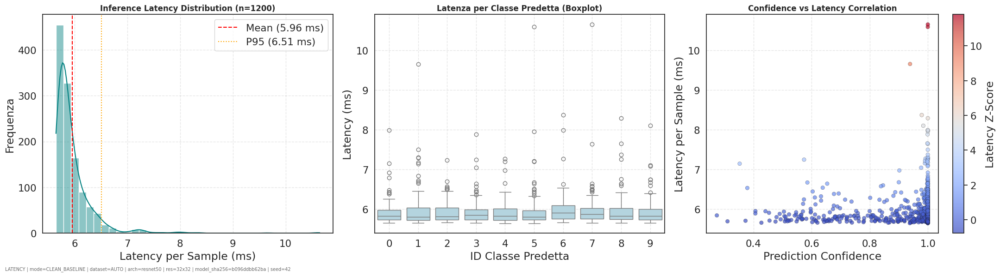

In [22]:
# ==============================================================================
# ⚡ [SECTION 13] INFERENCE TIME, THROUGHPUT & LATENCY ANOMALY DETECTION
# Fully compatible with POISONING (Supervised) and BLIND_AUDIT
# ==============================================================================

if should_run_section('LATENCY'):
    clean_memory()
    import os, glob, re, time
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, Dataset, Subset
    from PIL import Image
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy import stats

    print("--- ⚡ STARTING INFERENCE TIME PROFILING & LATENCY ANOMALY DETECTION ---")

    # ----------------------------------------------------------------------
    # 1. TIME MEASUREMENT FUNCTIONS WITH GPU SYNCHRONIZE & WARMUP
    # ----------------------------------------------------------------------
    def get_dataset_stats(model: nn.Module):
        # Statistics/resolution from the single model context (cell 1) instead of GTSRB-like
        # hardcoded values; no reassignment of the global 'transforms' (API v2 used by the other cells).
        _ctx = get_model_eval_context(model)
        return _ctx["transform"], int(_ctx["target_res"])

    class UniversalDatasetWrapper(Dataset):
        def __init__(self, raw_ds, transform_pipeline, target_size):
            self.raw_ds = raw_ds
            self.transform = transform_pipeline
            self.target_size = target_size

        def __len__(self):
            return len(self.raw_ds)

        def __getitem__(self, idx):
            item = self.raw_ds[idx]
            if isinstance(item, (tuple, list)):
                x, y = item[0], item[1]
            else:
                x, y = item, -1

            if isinstance(x, Image.Image):
                x = self.transform(x.convert('RGB'))
            elif isinstance(x, np.ndarray):
                x = self.transform(Image.fromarray(x.astype(np.uint8)).convert('RGB'))
            elif isinstance(x, torch.Tensor):
                if x.ndim == 4:
                    x = x.squeeze(0)
                if x.shape[-1] != self.target_size or x.shape[-2] != self.target_size:
                    x = F.interpolate(x.unsqueeze(0), size=(self.target_size, self.target_size), mode='bilinear', align_corners=False).squeeze(0)
            return x, y

    def measure_per_sample_latency(model, dataset, dev, num_samples=1000, num_warmup=25):
        eval_len = min(num_samples, len(dataset))
        _rng_lat = np.random.default_rng(int(globals().get("SEED", 42)))
        subset = Subset(dataset, np.sort(_rng_lat.choice(len(dataset), eval_len, replace=False)).tolist())
        loader = DataLoader(subset, batch_size=1, shuffle=False)

        # GPU Warm-up
        warmup_loader = DataLoader(subset, batch_size=1, shuffle=False)
        warmup_count = 0
        with torch.no_grad():
            for x, _ in warmup_loader:
                _ = model(x.to(dev))
                warmup_count += 1
                if warmup_count >= num_warmup:
                    break
        if dev.type == "cuda":
            torch.cuda.synchronize()

        latencies = []
        true_labels = []
        predicted_labels = []
        confidences = []

        use_cuda_events = (dev.type == "cuda")
        if use_cuda_events:
            starter = torch.cuda.Event(enable_timing=True)
            ender = torch.cuda.Event(enable_timing=True)

        with torch.no_grad():
            for inputs, labels in loader:
                inputs = inputs.to(dev)
                if use_cuda_events:
                    starter.record()
                    outputs = model(inputs)
                    ender.record()
                    torch.cuda.synchronize()
                    curr_ms = starter.elapsed_time(ender)
                else:
                    t0 = time.perf_counter()
                    outputs = model(inputs)
                    curr_ms = (time.perf_counter() - t0) * 1000.0

                probs = torch.softmax(outputs, dim=1)
                conf, pred = torch.max(probs, dim=1)

                latencies.append(curr_ms)
                true_labels.append(labels.item() if isinstance(labels, torch.Tensor) else labels)
                predicted_labels.append(pred.item())
                confidences.append(conf.item())

        return np.array(latencies), np.array(true_labels), np.array(predicted_labels), np.array(confidences)

    def measure_batch_throughput(model, dataset, dev, batch_size=128):
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
        total_samples = 0
        if dev.type == "cuda":
            torch.cuda.synchronize()
        t_start = time.perf_counter()
        with torch.no_grad():
            for inputs, _ in loader:
                inputs = inputs.to(dev)
                _ = model(inputs)
                total_samples += inputs.size(0)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        total_time = time.perf_counter() - t_start
        return total_samples / total_time

    # ----------------------------------------------------------------------
    # 2. MODEL AND ASSET LOADING
    # ----------------------------------------------------------------------
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    num_classes = globals().get("NUM_CLASSES", 43)
    # Attack target only for the oracle evaluation (local: the global target_label is not rewritten)
    lat_target = int(TARGET_LABEL) if (oracle_allowed() and "TARGET_LABEL" in globals() and int(TARGET_LABEL) >= 0) else None

    eval_model = get_audit_model(required=False)
    if eval_model is not None:
        eval_model.eval()
        strategy_name = get_model_eval_context(eval_model)["strategy"].upper()
        run_benchmark = True
    else:
        print("⚠️ No model available for benchmarking.")
        strategy_name = "N/D"
        run_benchmark = False

    if run_benchmark:
        eval_pipeline, target_res = get_dataset_stats(eval_model)

        # Class names for the reports
        if "CLASS_NAMES" in globals() and CLASS_NAMES is not None:
            class_names_to_show = CLASS_NAMES
        elif "CIFAR10_CLASSES" in globals() and CIFAR10_CLASSES is not None:
            class_names_to_show = CIFAR10_CLASSES
        elif "classes" in globals() and classes is not None:
            class_names_to_show = classes
        else:
            class_names_to_show = [f"Class_{i}" for i in range(num_classes)]

        # Base dataset for the test
        src_ds = None
        if 'clean_test_dataset' in globals() and clean_test_dataset is not None:
            src_ds = clean_test_dataset
        elif 'raw_test_dataset' in globals() and raw_test_dataset is not None:
            src_ds = raw_test_dataset
        elif 'test_loader' in globals() and test_loader is not None:
            src_ds = test_loader.dataset

        wrapped_clean_ds = UniversalDatasetWrapper(src_ds, eval_pipeline, target_res)

        # Supervised branch only in the oracle modes: a stale poison_test_loader is not enough.
        is_supervised_poison = (
            lat_target is not None and
            'poison_test_loader' in globals() and poison_test_loader is not None
        )

        # ==================================================================
        # SCENARIO A: SUPERVISED MODE (CLEAN VS POISONED)
        # ==================================================================
        if is_supervised_poison:
            print("🔍 [SUPERVISED MODE] Clean vs Poisoned Latency Profiling (UNPAIRED samples; paired comparison in the next section)...")
            c_lat, c_true, c_pred, _ = measure_per_sample_latency(eval_model, wrapped_clean_ds, device, num_samples=1000)
            p_lat, p_true, p_pred, _ = measure_per_sample_latency(eval_model, poison_test_loader.dataset, device, num_samples=1000)

            clean_fps = measure_batch_throughput(eval_model, wrapped_clean_ds, device, batch_size=128)
            poison_fps = measure_batch_throughput(eval_model, poison_test_loader.dataset, device, batch_size=128)

            # Comparative Plots (KDE, Boxplot, CDF)
            fig, axes = plt.subplots(1, 3, figsize=(22, 6))
            sns.kdeplot(c_lat, label=f"Clean (n={len(c_lat)})", fill=True, color="green", alpha=0.35, ax=axes[0])
            sns.kdeplot(p_lat, label=f"Poisoned (n={len(p_lat)})", fill=True, color="red", alpha=0.35, ax=axes[0])
            axes[0].set_title(f"Inference Latency Density (KDE) | {strategy_name}", fontsize=12, fontweight="bold")
            axes[0].set_xlabel("Latency per Sample (ms)")
            axes[0].legend()
            axes[0].grid(True, linestyle="--", alpha=0.5)

            df_lat_comp = pd.DataFrame({
                "Latency (ms)": np.concatenate([c_lat, p_lat]),
                "Input Type": ["Clean"] * len(c_lat) + ["Poisoned"] * len(p_lat)
            })
            sns.boxplot(data=df_lat_comp, x="Input Type", y="Latency (ms)", palette=["#2ca02c", "#d62728"], ax=axes[1], width=0.4)
            axes[1].set_title("Latency Distribution & Jitter (Boxplot)", fontsize=12, fontweight="bold")
            axes[1].grid(True, linestyle="--", alpha=0.5)

            axes[2].plot(np.sort(c_lat), np.linspace(0, 1, len(c_lat)), label="Clean CDF", color="green", linewidth=2)
            axes[2].plot(np.sort(p_lat), np.linspace(0, 1, len(p_lat)), label="Poisoned CDF", color="red", linewidth=2, linestyle="--")
            axes[2].set_title("Empirical Cumulative Distribution (CDF)", fontsize=12, fontweight="bold")
            axes[2].set_xlabel("Latency per Sample (ms)")
            axes[2].legend()
            axes[2].grid(True, linestyle="--", alpha=0.5)
            plt.tight_layout()
            fig.text(0.01, 0.005, provenance_caption("LATENCY", "clean and poisoned: different samples, measured in sequence (unpaired)"), fontsize=7, alpha=0.7)
            plt.show()

            # UNPAIRED statistical tests: different images (clean: all classes; poisoned: non-target only)
            # measured in two successive blocks -> the difference may reflect thermal/clock drift or
            # caching and the content of the samples, not only the trigger. The paired comparison is in cell 38.
            ks_stat, ks_pvalue = stats.ks_2samp(c_lat, p_lat)
            t_stat, t_pvalue = stats.ttest_ind(c_lat, p_lat, equal_var=False)

            print("\n" + "=" * 85)
            print(f"📊 [BENCHMARK REPORT] INFERENCE LATENCY & THROUGHPUT ({strategy_name})")
            print("=" * 85)
            summary_df = pd.DataFrame({
                "Metric": ["Mean Latency (ms)", "Std Dev (ms)", "Median P50 (ms)", "P95 Latency (ms)", "P99 Latency (ms)", "Throughput (FPS)"],
                "Clean Inputs": [f"{np.mean(c_lat):.3f}", f"{np.std(c_lat):.3f}", f"{np.percentile(c_lat, 50):.3f}", f"{np.percentile(c_lat, 95):.3f}", f"{np.percentile(c_lat, 99):.3f}", f"{clean_fps:.1f} fps"],
                "Poisoned Inputs": [f"{np.mean(p_lat):.3f}", f"{np.std(p_lat):.3f}", f"{np.percentile(p_lat, 50):.3f}", f"{np.percentile(p_lat, 95):.3f}", f"{np.percentile(p_lat, 99):.3f}", f"{poison_fps:.1f} fps"],
                "Delta (Poison - Clean)": [f"{(np.mean(p_lat)-np.mean(c_lat)):+.3f}", f"{(np.std(p_lat)-np.std(c_lat)):+.3f}", f"{(np.percentile(p_lat, 50)-np.percentile(c_lat, 50)):+.3f}", f"{(np.percentile(p_lat, 95)-np.percentile(c_lat, 95)):+.3f}", f"{(np.percentile(p_lat, 99)-np.percentile(c_lat, 99)):+.3f}", f"{(poison_fps-clean_fps):+.1f} fps"]
            })
            print(summary_df.to_string(index=False))
            print("-" * 85)
            print(f"🔬 UNPAIRED tests (KS / Welch t): KS-pvalue = {ks_pvalue:.4e} | t-stat pvalue = {t_pvalue:.4e}")
            print("   Note: different samples measured in successive blocks; the throughput includes dataset loading and transformations.")
            print("=" * 85 + "\n")

            # --- FAITHFUL RECORDING IN RUN_RESULTS ---
            c_mean_lat = float(np.mean(c_lat))
            p_mean_lat = float(np.mean(p_lat))
            delta_lat = float(p_mean_lat - c_mean_lat)
            globals()['latency_clean_mean_ms'] = c_mean_lat
            globals()['latency_poison_mean_ms'] = p_mean_lat
            globals()['latency_delta_ms'] = delta_lat
            globals()['latency_clean_fps'] = clean_fps
            globals()['latency_poison_fps'] = poison_fps
            globals()['latency_ks_stat'] = ks_stat
            globals()['latency_ks_pvalue'] = ks_pvalue
            globals()['latency_t_pvalue'] = t_pvalue

            # Computation of target vs rest latency gap (only in supervised mode with known target_label)
            try:
                c_true_arr = np.array(c_true)
                c_lat_arr = np.array(c_lat)
                target_mask = (c_true_arr == lat_target)
                if np.sum(target_mask) > 0 and np.sum(~target_mask) > 0:
                    tgt_lat = float(np.mean(c_lat_arr[target_mask]))
                    rest_lat = float(np.mean(c_lat_arr[~target_mask]))
                    globals()['latency_target_vs_rest_delta_ms'] = float(tgt_lat - rest_lat)
                else:
                    globals()['latency_target_vs_rest_delta_ms'] = float('nan')
            except Exception:
                globals()['latency_target_vs_rest_delta_ms'] = float('nan')

            _lat = dict(method="LATENCY", level="model")
            _lat_gt = dict(method="LATENCY", level="model", requires_ground_truth=True)
            _unp = "different clean/poisoned samples, unpaired, measured in sequence"
            record_metric("latency_clean_mean_ms", float(round(c_mean_lat, 3)), unit="ms", note=f"batch=1, n={len(c_lat)}, forward only", **_lat)
            record_metric("latency_poison_mean_ms", float(round(p_mean_lat, 3)), unit="ms", note=f"batch=1, n={len(p_lat)}, forward only", **_lat_gt)
            record_metric("latency_delta_ms", float(round(delta_lat, 3)), unit="ms", note=_unp, **_lat_gt)
            _tvr = globals().get('latency_target_vs_rest_delta_ms', float('nan'))
            record_metric("latency_target_vs_rest_delta_ms", float(round(_tvr, 3)) if np.isfinite(_tvr) else float("nan"),
                          "computed" if np.isfinite(_tvr) else "insufficient_data", unit="ms",
                          note="clean inputs: target class vs other classes", **_lat_gt)
            record_metric("latency_clean_fps", float(round(clean_fps, 1)), unit="img/s", note="end-to-end: includes loading and transformations", **_lat)
            record_metric("latency_poison_fps", float(round(poison_fps, 1)), unit="img/s",
                          note="end-to-end: includes loading and on-the-fly application of the trigger", **_lat_gt)
            record_metric("latency_ks_stat", float(round(ks_stat, 4)), unit="statistic", note=_unp, **_lat_gt)
            record_metric("latency_ks_pvalue", float(ks_pvalue), unit="p-value", note=_unp, **_lat_gt)
            record_metric("latency_t_pvalue", float(t_pvalue), unit="p-value", note="Welch t-test; " + _unp, **_lat_gt)

            # --- SAVING THE LATENCY PROFILING PLOT (ATTACKER_MODEL_LEVEL ONLY) ---
            current_mode = str(globals().get('EXECUTION_MODE', '')).upper()
            if current_mode == 'ATTACKER_MODEL_LEVEL':
                try:
                    out_dir_lat = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                    os.makedirs(out_dir_lat, exist_ok=True)
                    att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "attack"
                    lat_img_filename = f"latency_profiling_{att_type_str}_{strategy_name.lower()}.png"
                    lat_save_path = os.path.join(out_dir_lat, lat_img_filename)
                    fig.savefig(lat_save_path, bbox_inches='tight', dpi=130)
                    register_artifact("LATENCY", lat_save_path, note="unpaired clean vs poisoned latency (oracle)")
                    globals()['LATENCY_PROFILING_IMG_PATH'] = lat_save_path
                    globals()['latency_profiling_img'] = lat_img_filename
                    record_metric("latency_profiling_img", lat_img_filename, method="LATENCY", level="model", note="figure artifact")
                    print(f"✅ [LATENCY] Comparative plot saved to: {lat_save_path}")
                except Exception as e_lat:
                    print(f"⚠️ Note on saving the latency plot: {e_lat}")

        # ==================================================================
        # SCENARIO B: BLIND AUDIT MODE / UNKNOWN DATASET & TARGET
        # ==================================================================
        else:
            print(f"🛡️ [BLIND AUDIT MODE] Benchmark & Search for Anomalous Latency Deviations...")
            latencies, true_lbls, pred_lbls, confs = measure_per_sample_latency(
                eval_model, wrapped_clean_ds, device, num_samples=min(1200, len(wrapped_clean_ds))
            )
            throughput_fps = measure_batch_throughput(eval_model, wrapped_clean_ds, device, batch_size=128)

            df_audit_lat = pd.DataFrame({
                "Sample_Index": range(len(latencies)),
                "True_Class": true_lbls,
                "Predicted_Class": pred_lbls,
                "Confidence": confs,
                "Latency_ms": latencies
            })

            # Global metrics
            mean_lat, std_lat = np.mean(latencies), np.std(latencies)
            p50_lat, p95_lat, p99_lat = np.percentile(latencies, [50, 95, 99])

            # Z-Score computation per single image (NaN if the standard deviation is zero)
            df_audit_lat["Sample_Latency_Z"] = (df_audit_lat["Latency_ms"] - mean_lat) / std_lat if std_lat > 0 else np.nan

            # Samples with latency beyond the heuristic threshold (|Z| > 2.5): exploratory indicator
            anomalous_samples = df_audit_lat[df_audit_lat["Sample_Latency_Z"].abs() > 2.5].sort_values(by="Latency_ms", ascending=False)

            print("\n" + "=" * 85)
            print(f"📊 [GLOBAL BLIND AUDIT BENCHMARK] ({strategy_name} | {target_res}x{target_res})")
            print("=" * 85)
            print(f"   Samples Evaluated at Batch=1 : {len(latencies)}")
            print(f"   Mean Latency per Image      : {mean_lat:.3f} ms (± {std_lat:.3f} ms)")
            print(f"   Median (P50)                : {p50_lat:.3f} ms")
            print(f"   Percentiles P95 / P99       : {p95_lat:.3f} ms / {p99_lat:.3f} ms")
            print(f"   Throughput at Batch=128     : {throughput_fps:.1f} FPS (images/sec)")
            print(f"   Samples with Anomalous Latency: {len(anomalous_samples)} (out of {len(latencies)} samples with |Z| > 2.5)")
            print("=" * 85)

            # --- STATISTICAL PROFILING PER PREDICTED CLASS ---
            class_lat_profile = (
                df_audit_lat.groupby("Predicted_Class")
                .agg(
                    Samples_Evaluated=("Latency_ms", "count"),
                    Mean_Latency=("Latency_ms", "mean"),
                    Std_Latency=("Latency_ms", "std"),
                    P95_Latency=("Latency_ms", lambda x: np.percentile(x, 95) if len(x) > 0 else np.nan),
                    Max_Latency=("Latency_ms", "max")
                )
                .reindex(range(num_classes))
                .fillna({"Samples_Evaluated": 0})
            )
            # Classes without predictions: NaN statistics (not 0 ms, which would produce false negative Z-scores)

            valid_class_means = class_lat_profile[class_lat_profile["Samples_Evaluated"] > 0]["Mean_Latency"].values
            if len(valid_class_means) > 1 and np.std(valid_class_means) > 0:
                class_lat_profile["Class_Latency_Z"] = (
                    class_lat_profile["Mean_Latency"] - np.mean(valid_class_means)
                ) / np.std(valid_class_means)
            else:
                class_lat_profile["Class_Latency_Z"] = np.nan

            class_lat_profile["Class_Name"] = [class_names_to_show[i] if i < len(class_names_to_show) else str(i) for i in range(num_classes)]
            class_lat_profile = class_lat_profile[[
                "Class_Name", "Samples_Evaluated", "Mean_Latency", "Std_Latency", "P95_Latency", "Max_Latency", "Class_Latency_Z"
            ]]

            # Extraction of the class with maximum latency Z-score anomaly
            try:
                valid_profs = class_lat_profile[class_lat_profile["Samples_Evaluated"] > 0]
                if not valid_profs.empty:
                    top_z_row = valid_profs.loc[valid_profs["Class_Latency_Z"].abs().idxmax()]
                    globals()['latency_max_class_z'] = float(top_z_row["Class_Latency_Z"])
                    globals()['latency_max_class_id'] = int(top_z_row.name)
                    globals()['latency_max_class_name'] = str(top_z_row["Class_Name"])
                    _lz = dict(method="LATENCY", level="class", note="PREDICTED class with maximum mean latency |Z| (exploratory indicator)")
                    record_metric("latency_max_class_z", float(round(globals()['latency_max_class_z'], 3)), unit="z", **_lz)
                    record_metric("latency_max_class_id", globals()['latency_max_class_id'], **_lz)
                    record_metric("latency_max_class_name", globals()['latency_max_class_name'], **_lz)
                    record_entities("LATENCY", "class", [
                        {"entity_id": f"class_{int(i)}", "class_id": int(i), "class_name": str(r["Class_Name"]),
                         "score": float(r["Class_Latency_Z"]), "note": f"predicted class; n={int(r['Samples_Evaluated'])}; mean latency z"}
                        for i, r in valid_profs.iterrows()
                    ])
            except Exception as _e_top_z:
                pass

            print("\n🔍 [RESPONSE TIME PROFILE PER PREDICTED CLASS]")
            print(class_lat_profile.to_string(formatters={
                "Samples_Evaluated": "{:,.0f}".format,
                "Mean_Latency": "{:.3f} ms".format,
                "Std_Latency": "{:.3f} ms".format,
                "P95_Latency": "{:.3f} ms".format,
                "Max_Latency": "{:.3f} ms".format,
                "Class_Latency_Z": "{:+.2f}".format,
            }))
            print("=" * 85)

            # Flagging of classes beyond the heuristic threshold |Z| > 2 (no origin in the literature)
            class_outliers = class_lat_profile[class_lat_profile["Class_Latency_Z"].abs() > 2.0]
            if not class_outliers.empty:
                for idx_c, row_c in class_outliers.iterrows():
                    print(f"⚠️ [EXPLORATORY]: The class '{row_c['Class_Name']}' exceeds the heuristic threshold |Z|>2 on mean latency (Z-Score: {row_c['Class_Latency_Z']:+.2f}): candidate for manual inspection.")
            else:
                print("ℹ️ [EXPLORATORY]: No class exceeds the heuristic threshold |Z|>2 on mean latency (this does not imply absence of compromise).")

            # Detailed list of Top-5 Images with High Deviations
            if not anomalous_samples.empty:
                print("\n🚨 [TOP-5 SINGLE SAMPLES WITH HIGHEST OVERHEAD/LATENCY]")
                top_anomalies = anomalous_samples.head(5)
                for _, row_a in top_anomalies.iterrows():
                    pred_name = class_names_to_show[int(row_a['Predicted_Class'])] if int(row_a['Predicted_Class']) < len(class_names_to_show) else str(int(row_a['Predicted_Class']))
                    print(f"   • Sample #{int(row_a['Sample_Index'])} | Latency: {row_a['Latency_ms']:.3f} ms (Z: {row_a['Sample_Latency_Z']:+.2f}) | Pred: {pred_name} (Conf: {row_a['Confidence']*100:.1f}%)")
            print("=" * 85 + "\n")

            # --- BLIND AUDIT DIAGNOSTIC PLOTS ---
            fig, axes = plt.subplots(1, 3, figsize=(22, 6))

            # 1. Latency Density and Histogram
            sns.histplot(latencies, bins=35, kde=True, color='teal', alpha=0.45, ax=axes[0])
            axes[0].axvline(mean_lat, color='red', linestyle='--', label=f'Mean ({mean_lat:.2f} ms)')
            axes[0].axvline(p95_lat, color='orange', linestyle=':', label=f'P95 ({p95_lat:.2f} ms)')
            axes[0].set_title(f"Inference Latency Distribution (n={len(latencies)})", fontsize=12, fontweight='bold')
            axes[0].set_xlabel("Latency per Sample (ms)")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True, linestyle="--", alpha=0.5)

            # 2. Latency Boxplot per Predicted Class
            # Show only the classes with at least 5 samples
            pop_classes = df_audit_lat["Predicted_Class"].value_counts()[lambda x: x >= 5].index
            df_pop = df_audit_lat[df_audit_lat["Predicted_Class"].isin(pop_classes)]
            if not df_pop.empty:
                sns.boxplot(data=df_pop, x="Predicted_Class", y="Latency_ms", ax=axes[1], color="lightblue")
                axes[1].set_title("Latency per Predicted Class (Boxplot)", fontsize=12, fontweight='bold')
                axes[1].set_xlabel("Predicted Class ID")
                axes[1].set_ylabel("Latency (ms)")
                axes[1].grid(True, linestyle="--", alpha=0.5)

            # 3. Scatter Plot: Confidence vs Latency
            scatter = axes[2].scatter(df_audit_lat["Confidence"], df_audit_lat["Latency_ms"], c=df_audit_lat["Sample_Latency_Z"], cmap="coolwarm", alpha=0.7, edgecolors='k', linewidth=0.3)
            axes[2].set_title("Confidence vs Latency Correlation", fontsize=12, fontweight='bold')
            axes[2].set_xlabel("Prediction Confidence")
            axes[2].set_ylabel("Latency per Sample (ms)")
            axes[2].grid(True, linestyle="--", alpha=0.5)
            cbar = plt.colorbar(scatter, ax=axes[2])
            cbar.set_label("Latency Z-Score")

            plt.tight_layout()
            fig.text(0.01, 0.005, provenance_caption("LATENCY"), fontsize=7, alpha=0.7)

            # --- SAVING THE LATENCY PLOT & RECORDING IN RUN_RESULTS (BLIND AUDIT) ---
            try:
                out_dir_lat = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                os.makedirs(out_dir_lat, exist_ok=True)
                lat_img_filename = f"latency_profiling_blind_audit_{strategy_name.lower()}.png"
                lat_save_path = os.path.join(out_dir_lat, lat_img_filename)
                fig.savefig(lat_save_path, bbox_inches='tight', dpi=130)
                register_artifact("LATENCY", lat_save_path, note="latency profile without known trigger")
                globals()['LATENCY_PROFILING_IMG_PATH'] = lat_save_path
                globals()['latency_profiling_img'] = lat_img_filename
                record_metric("latency_profiling_img", lat_img_filename, method="LATENCY", level="model", note="figure artifact")
                record_metric("latency_clean_mean_ms", float(round(mean_lat, 3)), method="LATENCY", level="model", unit="ms",
                              note=f"batch=1, n={len(latencies)}, forward only")
                record_metric("latency_clean_fps", float(round(throughput_fps, 1)), method="LATENCY", level="model", unit="img/s",
                              note="end-to-end: includes loading and transformations")
                print(f"✅ [LATENCY] Blind audit latency plot saved to: {lat_save_path}")
            except Exception as e_lat_b:
                print(f"⚠️ Note on saving the blind audit latency plot: {e_lat_b}")

            plt.show()

        check_model_integrity("LATENCY")

    clean_memory(verbose=False)




---

In [23]:
if should_run_section('LATENCY'):
    clean_memory()
    # ==============================================================================
    # INFERENCE TIME EVALUATION: CLEAN VS POISONED
    # Timing-only forensic analysis (Optimized & Robust)
    # ==============================================================================

    import os, glob, re, time
    import numpy as np
    import pandas as pd
    import torch, torchvision
    from torch import nn
    from torchvision import models
    from torch.utils.data import DataLoader, Subset
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy import stats

    print("--- STARTING INFERENCE TIME & LATENCY FORENSICS EVALUATION ---")

    # ==============================================================================
    # PARAMETERS
    # ==============================================================================
    NUM_BENCHMARK_SAMPLES = int(globals().get("LATENCY_PAIRED_SAMPLES", 500))  # clean/poisoned pairs of the same image
    WARMUP_SAMPLES = int(globals().get("LATENCY_PAIRED_WARMUP", 20))
    TIMING_REPEATS = int(globals().get("LATENCY_PAIRED_REPEATS", 3))
    THROUGHPUT_REPEATS = int(globals().get("LATENCY_THROUGHPUT_REPEATS", 3))
    RANDOM_SEED = int(globals().get("SEED", 42))
    BOOTSTRAP_ITER = int(globals().get("LATENCY_BOOTSTRAP_ITER", 2000))


    # ==============================================================================
    # STATISTICAL FUNCTIONS
    # ==============================================================================
    def bootstrap_ci(x, statistic=np.mean, n_iter=2000, seed=42):
        x = np.asarray(x, dtype=float)
        x = x[np.isfinite(x)]
        if len(x) < 2:
            return np.nan, np.nan
        rng = np.random.default_rng(seed)
        idx = rng.integers(0, len(x), size=(n_iter, len(x)))
        vals = statistic(x[idx], axis=1)
        return np.percentile(vals, [2.5, 97.5])


    def latency_summary(x):
        x = np.asarray(x, dtype=float)
        return {
            "Mean": np.mean(x),
            "Std": np.std(x, ddof=1) if len(x) > 1 else np.nan,
            "P50": np.percentile(x, 50),
            "P95": np.percentile(x, 95),
            "P99": np.percentile(x, 99),
        }


    # ==============================================================================
    # MODEL SELECTION (MEMORY OR DISK)
    # ==============================================================================
    exp_num = "BEST"
    # The paired comparison requires the attack trigger and target: oracle evaluation only.
    lat_target = int(TARGET_LABEL) if (oracle_allowed() and "TARGET_LABEL" in globals() and int(TARGET_LABEL) >= 0) else None
    _paired_keys = ("latency_paired_n", "latency_paired_delta_mean_ms", "latency_paired_delta_median_ms", "latency_paired_wilcoxon_p")

    eval_model = get_audit_model(required=False) if lat_target is not None else None
    if lat_target is None:
        print("ℹ️ Paired clean/poisoned latency not applicable: requires known trigger and target (attacker modes only).")
        for _k in _paired_keys:
            record_metric(_k, float("nan"), "not_applicable", method="LATENCY_PAIRED", level="model", requires_ground_truth=True,
                          note="requires inputs with the attack trigger")
        run_benchmark = False
    elif eval_model is None:
        print("⚠️ No model found for the evaluation.")
        run_benchmark = False
    else:
        eval_model.eval()
        lat_ctx = get_model_eval_context(eval_model)
        strategy_name = lat_ctx["strategy"].upper()
        current_test_transform = globals().get("transform_pipeline" if lat_ctx["is_pipeline"] else "transform_scratch_test") or lat_ctx["transform"]
        print(f"\n============================================================")
        print(f"Benchmark Inference Latency: Active Model in Memory | Strategy: {strategy_name}")
        print("============================================================")
        run_benchmark = True

    if run_benchmark:
        # Training report of the selected epoch (cell 22) or metadata of the imported checkpoint
        rep = globals().get("best_overall_report")
        if not isinstance(rep, dict) and isinstance(globals().get("checkpoint_meta"), dict):
            rep = checkpoint_meta.get("best_report", {})
        rep = rep if isinstance(rep, dict) else {}

        def _fmt_rep(v):
            return f"{float(v):.4f}" if isinstance(v, (int, float, np.floating)) and np.isfinite(v) else "n/a"
        f1_val = _fmt_rep(rep.get("final_val_f1"))
        asr_val = _fmt_rep(rep.get("final_val_asr"))
        toi_val = _fmt_rep(rep.get("trade_off_index"))

        print(f"📌 [MODEL CHECK] Val F1: {f1_val} | Val ASR: {asr_val} | TOI (F1*ASR): {toi_val} (training validation split)")
        print("=" * 90)

        # ======================================================================
        # 2. CLEAN + POISONED DATASET (RAM reuse if present or generation)
        # ======================================================================
        if "test_loader" in globals() and test_loader is not None:
            evaluation_clean_test = test_loader.dataset
        else:
            evaluation_clean_test = load_raw_and_clean_datasets(PATH_DATASET, DATASET_CONFIG.get("dataset_type", "auto"))[3]
            set_dataset_transform(evaluation_clean_test, current_test_transform)

        if "poison_test_loader" in globals() and poison_test_loader is not None:
            lat_poison_ds = poison_test_loader.dataset
        else:
            test_indices = list(range(len(evaluation_clean_test)))
            lat_poison_ds = create_poisoned_dataset(
                raw_dataset=raw_test_dataset,
                clean_dataset=evaluation_clean_test,
                current_subset_indices=test_indices,
                poisoning_ratio=1.0,
                transform=current_test_transform,
                strategy=strategy_name.lower(),
                target_label=lat_target,
                poisoning_mode=str(POISONING_CONFIG.get("poisoning_mode", "replacement")),
                is_train=False,
            )

        test_indices = list(range(len(evaluation_clean_test)))

        # ======================================================================
        # 3. BUILDING CLEAN / POISONED PAIRS
        # ======================================================================
        if hasattr(lat_poison_ds, "native_indices"):
            poison_native = np.asarray(lat_poison_ds.native_indices, dtype=int)
            poison_position = {int(native_idx): pos for pos, native_idx in enumerate(poison_native)}
            candidate_indices = [idx for idx in test_indices if idx in poison_position]
            if not candidate_indices:
                raise RuntimeError("Unable to build matching clean/poisoned pairs.")
            rng = np.random.default_rng(RANDOM_SEED)
            rng.shuffle(candidate_indices)
            benchmark_indices = candidate_indices[: min(NUM_BENCHMARK_SAMPLES, len(candidate_indices))]
            poison_local_indices = [poison_position[idx] for idx in benchmark_indices]
        else:
            # Without native indices the row i <-> row i correspondence is not guaranteed (the poisoned test set
            # is a permuted subset): no positional pairing.
            raise RuntimeError("The poisoned dataset does not expose native_indices: clean/poisoned pairs not verifiable.")

        clean_subset = Subset(evaluation_clean_test, benchmark_indices)
        poison_subset = Subset(lat_poison_ds, poison_local_indices)

        print(f"Paired samples used: {len(benchmark_indices)}")

        # ======================================================================
        # 4. PAIRED LATENCY MEASUREMENT (High I/O efficiency)
        # ======================================================================
        def measure_paired_latency_fast(model, clean_ds, poison_ds, repeats=3, warmup=20):
            # Preloading into tensors to eliminate the DataLoader overhead
            clean_loader = DataLoader(clean_ds, batch_size=64, shuffle=False, num_workers=0)
            poison_loader = DataLoader(poison_ds, batch_size=64, shuffle=False, num_workers=0)

            clean_imgs = torch.cat([x for x, _ in clean_loader], dim=0)
            poison_imgs = torch.cat([x for x, _ in poison_loader], dim=0)

            n = min(len(clean_imgs), len(poison_imgs))
            clean_imgs = clean_imgs[:n]
            poison_imgs = poison_imgs[:n]

            # Warm-up
            with torch.no_grad():
                for i in range(min(warmup, n)):
                    _ = model(clean_imgs[i:i+1].to(device))
                    _ = model(poison_imgs[i:i+1].to(device))

            if device.type == "cuda":
                torch.cuda.synchronize()

            clean_runs = np.empty((repeats, n), dtype=np.float64)
            poison_runs = np.empty((repeats, n), dtype=np.float64)

            use_cuda_events = (device.type == "cuda")
            if use_cuda_events:
                starter = torch.cuda.Event(enable_timing=True)
                ender = torch.cuda.Event(enable_timing=True)

            with torch.no_grad():
                for r in range(repeats):
                    for i in range(n):
                        cx = clean_imgs[i:i+1]
                        px = poison_imgs[i:i+1]

                        # Alternating the order to eliminate caching bias
                        if (i + r) % 2 == 0:
                            first_x, second_x = cx, px
                            first_store, second_store = (clean_runs, poison_runs)
                        else:
                            first_x, second_x = px, cx
                            first_store, second_store = (poison_runs, clean_runs)

                        # First input
                        x = first_x.to(device)
                        if use_cuda_events:
                            starter.record()
                            _ = model(x)
                            ender.record()
                            torch.cuda.synchronize()
                            dt = starter.elapsed_time(ender)
                        else:
                            t0 = time.perf_counter()
                            _ = model(x)
                            dt = (time.perf_counter() - t0) * 1000.0

                        first_store[r, i] = dt

                        # Second input
                        x = second_x.to(device)
                        if use_cuda_events:
                            starter.record()
                            _ = model(x)
                            ender.record()
                            torch.cuda.synchronize()
                            dt = starter.elapsed_time(ender)
                        else:
                            t0 = time.perf_counter()
                            _ = model(x)
                            dt = (time.perf_counter() - t0) * 1000.0

                        second_store[r, i] = dt

            return (clean_runs.mean(axis=0), poison_runs.mean(axis=0), clean_runs, poison_runs)

        print(
            f"⏳ Fast in-memory paired measurement: "
            f"{len(benchmark_indices)} samples × "
            f"{TIMING_REPEATS} repetitions..."
        )

        c_lat, p_lat, c_runs, p_runs = measure_paired_latency_fast(
            eval_model, clean_subset, poison_subset, repeats=TIMING_REPEATS, warmup=WARMUP_SAMPLES
        )
        print("✅ Measurement completed!")

        # ======================================================================
        # 5. PAIRED TIME METRICS
        # ======================================================================
        delta_lat = p_lat - c_lat
        relative_delta = 100.0 * delta_lat / np.maximum(c_lat, 1e-12)

        mean_delta = np.mean(delta_lat)
        median_delta = np.median(delta_lat)
        mean_relative_delta = np.mean(relative_delta)

        delta_ci_mean = bootstrap_ci(
            delta_lat, statistic=np.mean, n_iter=BOOTSTRAP_ITER, seed=RANDOM_SEED
        )

        delta_ci_median = bootstrap_ci(
            delta_lat, statistic=np.median, n_iter=BOOTSTRAP_ITER, seed=RANDOM_SEED + 1
        )

        # ======================================================================
        # 6. STATISTICAL TESTS
        # ======================================================================
        try:
            w_stat, w_pvalue = stats.wilcoxon(p_lat, c_lat, alternative="two-sided")
        except ValueError:
            w_stat, w_pvalue = np.nan, np.nan

        try:
            t_stat, t_pvalue = stats.ttest_rel(p_lat, c_lat)
        except ValueError:
            t_stat, t_pvalue = np.nan, np.nan

        ks_stat, ks_pvalue = stats.ks_2samp(c_lat, p_lat)

        # ======================================================================
        # 7. LATENCY SUMMARY
        # ======================================================================
        clean_stats = latency_summary(c_lat)
        poison_stats = latency_summary(p_lat)

        # ======================================================================
        # 8. THROUGHPUT
        # ======================================================================
        def measure_batch_throughput(model, dataset, batch_size=128, repeats=3):
            values = []
            for _ in range(repeats):
                loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
                if device.type == "cuda":
                    torch.cuda.synchronize()
                start = time.perf_counter()
                total_samples = 0
                with torch.no_grad():
                    for inputs, _ in loader:
                        inputs = inputs.to(device)
                        _ = model(inputs)
                        total_samples += inputs.size(0)
                if device.type == "cuda":
                    torch.cuda.synchronize()
                elapsed = time.perf_counter() - start
                values.append(total_samples / elapsed)
            return np.asarray(values)

        print("⏳ Measuring batch=128 throughput...")
        clean_fps_runs = measure_batch_throughput(
            eval_model, evaluation_clean_test, batch_size=128, repeats=THROUGHPUT_REPEATS
        )
        poison_fps_runs = measure_batch_throughput(
            eval_model, lat_poison_ds, batch_size=128, repeats=THROUGHPUT_REPEATS
        )
        clean_fps = np.median(clean_fps_runs)
        poison_fps = np.median(poison_fps_runs)

        # ======================================================================
        # 9. MAIN REPORT
        # ======================================================================
        print("\n" + "=" * 100)
        print(f"[LATENCY FORENSIC REPORT] Exp {exp_num} | {strategy_name}")
        print("=" * 100)

        summary_df = pd.DataFrame(
            {
                "Metric": [
                    "Mean Latency (ms)",
                    "Std Dev (ms)",
                    "Median P50 (ms)",
                    "P95 Latency (ms)",
                    "P99 Latency (ms)",
                    "Mean Δ Latency (ms)",
                    "Median Δ Latency (ms)",
                    "Mean Relative Δ (%)",
                    "P95 Δ Latency (ms)",
                    "P99 Δ Latency (ms)",
                    "Throughput FPS",
                ],
                "Clean": [
                    f"{clean_stats['Mean']:.4f}",
                    f"{clean_stats['Std']:.4f}",
                    f"{clean_stats['P50']:.4f}",
                    f"{clean_stats['P95']:.4f}",
                    f"{clean_stats['P99']:.4f}",
                    "-",
                    "-",
                    "-",
                    "-",
                    "-",
                    f"{clean_fps:.2f}",
                ],
                "Poisoned": [
                    f"{poison_stats['Mean']:.4f}",
                    f"{poison_stats['Std']:.4f}",
                    f"{poison_stats['P50']:.4f}",
                    f"{poison_stats['P95']:.4f}",
                    f"{poison_stats['P99']:.4f}",
                    "-",
                    "-",
                    "-",
                    "-",
                    "-",
                    f"{poison_fps:.2f}",
                ],
                "Poison-Clean": [
                    f"{poison_stats['Mean']-clean_stats['Mean']:+.4f}",
                    f"{poison_stats['Std']-clean_stats['Std']:+.4f}",
                    f"{poison_stats['P50']-clean_stats['P50']:+.4f}",
                    f"{poison_stats['P95']-clean_stats['P95']:+.4f}",
                    f"{poison_stats['P99']-clean_stats['P99']:+.4f}",
                    f"{mean_delta:+.4f}",
                    f"{median_delta:+.4f}",
                    f"{mean_relative_delta:+.3f}",
                    f"{np.percentile(delta_lat,95):+.4f}",
                    f"{np.percentile(delta_lat,99):+.4f}",
                    f"{poison_fps-clean_fps:+.2f}",
                ],
            }
        )

        print(summary_df.to_string(index=False))

        print("Note: the throughput is end-to-end (includes loading and, for the poisoned ones, on-the-fly application of the trigger):")
        print("      the FPS difference is not attributable to the model alone. The paired latencies measure only the forward pass.")

        # Recording (oracle evaluation): Δ = poisoned - clean on the same image
        _lp = dict(method="LATENCY_PAIRED", level="model", requires_ground_truth=True)
        record_metric("latency_paired_n", int(len(delta_lat)), unit="pairs", **_lp)
        record_metric("latency_paired_delta_mean_ms", float(mean_delta), unit="ms",
                      note=f"bootstrap 95% CI [{delta_ci_mean[0]:+.5f}, {delta_ci_mean[1]:+.5f}]", **_lp)
        record_metric("latency_paired_delta_median_ms", float(median_delta), unit="ms",
                      note=f"bootstrap 95% CI [{delta_ci_median[0]:+.5f}, {delta_ci_median[1]:+.5f}]", **_lp)
        record_metric("latency_paired_wilcoxon_p", float(w_pvalue) if np.isfinite(w_pvalue) else float("nan"),
                      "computed" if np.isfinite(w_pvalue) else "degenerate", unit="p-value", note="Wilcoxon signed-rank", **_lp)

        print("\n[95% CI - PAIRED Δ LATENCY]")
        print(f"Mean Δ   : [{delta_ci_mean[0]:+.5f}, {delta_ci_mean[1]:+.5f}] ms")
        print(f"Median Δ : [{delta_ci_median[0]:+.5f}, {delta_ci_median[1]:+.5f}] ms")

        print("\n[STATISTICAL TESTS]")
        print(f"Wilcoxon paired : stat={w_stat:.4f}, p={w_pvalue:.4e}")
        print(f"Paired t-test   : t={t_stat:.4f}, p={t_pvalue:.4e}")
        print(f"KS two-sample   : D={ks_stat:.4f}, p={ks_pvalue:.4e}")

        print("\n[PAIRWISE LATENCY EFFECT]")
        print(f"Δ > 0       : {100*np.mean(delta_lat > 0):.2f}%")
        print(f"Δ < 0       : {100*np.mean(delta_lat < 0):.2f}%")
        print(f"Median |Δ|  : {np.median(np.abs(delta_lat)):.5f} ms")
        print(f"P95 |Δ|     : {np.percentile(np.abs(delta_lat),95):.5f} ms")

        # ======================================================================
        # 10. GLOBAL DISTRIBUTIONS
        # ======================================================================
        fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

        sns.kdeplot(c_lat, label=f"Clean (n={len(c_lat)})", fill=True, alpha=0.35, ax=axes[0])
        sns.kdeplot(p_lat, label=f"Poisoned (n={len(p_lat)})", fill=True, alpha=0.35, ax=axes[0])
        axes[0].set_title("Inference Latency Density")
        axes[0].set_xlabel("Latency (ms)")
        axes[0].set_ylabel("Density")
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)

        df_latency = pd.DataFrame(
            {
                "Latency (ms)": np.r_[c_lat, p_lat],
                "Input Type": (["Clean"] * len(c_lat) + ["Poisoned"] * len(p_lat)),
            }
        )

        sns.boxplot(data=df_latency, x="Input Type", y="Latency (ms)", width=0.45, ax=axes[1])
        axes[1].set_title("Latency Distribution")
        axes[1].grid(True, alpha=0.3)

        sns.histplot(delta_lat, bins=30, kde=True, ax=axes[2])
        axes[2].axvline(0, linestyle="--", linewidth=1.5)
        axes[2].set_title("Paired Δ Latency")
        axes[2].set_xlabel("Poisoned - Clean (ms)")
        axes[2].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

        # ======================================================================
        # 11. CDF
        # ======================================================================
        plt.figure(figsize=(9, 5))

        clean_sorted = np.sort(c_lat)
        poison_sorted = np.sort(p_lat)

        clean_y = np.arange(1, len(clean_sorted) + 1) / len(clean_sorted)
        poison_y = np.arange(1, len(poison_sorted) + 1) / len(poison_sorted)

        plt.plot(clean_sorted, clean_y, label="Clean", linewidth=2)
        plt.plot(poison_sorted, poison_y, label="Poisoned", linewidth=2, linestyle="--")

        plt.title("Empirical Cumulative Distribution of Inference Latency")
        plt.xlabel("Latency (ms)")
        plt.ylabel("Cumulative Probability")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # ======================================================================
        # 12. QUANTILE PROFILE
        # ======================================================================
        quantiles = [1, 5, 10, 25, 50, 75, 90, 95, 99]

        q_df = pd.DataFrame(
            {
                "Percentile": quantiles,
                "Clean_ms": np.percentile(c_lat, quantiles),
                "Poisoned_ms": np.percentile(p_lat, quantiles),
            }
        )

        q_df["Delta_ms"] = q_df["Poisoned_ms"] - q_df["Clean_ms"]

        print("\n[LATENCY QUANTILE PROFILE]")
        print(q_df.to_string(index=False, float_format=lambda x: f"{x:.5f}"))

        # ======================================================================
        # 13. LATENCY PROFILING BY TRUE CLASS
        # ======================================================================
        paired_labels = np.asarray([evaluation_clean_test[idx][1] for idx in benchmark_indices])
        class_rows = []

        for cls in range(NUM_CLASSES):
            mask = paired_labels == cls
            if not np.any(mask):
                continue

            cl = c_lat[mask]
            pl = p_lat[mask]
            dl = delta_lat[mask]

            class_rows.append(
                {
                    "Class": cls,
                    "Class_Name": CLASS_NAMES[cls],
                    "Samples": len(cl),
                    "Clean_Mean_ms": np.mean(cl),
                    "Poison_Mean_ms": np.mean(pl),
                    "Delta_Mean_ms": np.mean(dl),
                    "Delta_Median_ms": np.median(dl),
                    "Clean_Std_ms": (np.std(cl, ddof=1) if len(cl) > 1 else np.nan),
                    "Poison_Std_ms": (np.std(pl, ddof=1) if len(pl) > 1 else np.nan),
                    "Clean_P95_ms": np.percentile(cl, 95),
                    "Poison_P95_ms": np.percentile(pl, 95),
                    "Delta_P95_ms": np.percentile(dl, 95),
                }
            )

        class_latency = pd.DataFrame(class_rows)

        print("\n" + "=" * 105)
        print("[FORENSIC LATENCY PROFILE BY TRUE CLASS]")
        print("=" * 105)

        print(
            class_latency.to_string(
                index=False,
                formatters={
                    "Clean_Mean_ms": "{:.4f}".format,
                    "Poison_Mean_ms": "{:.4f}".format,
                    "Delta_Mean_ms": "{:+.4f}".format,
                    "Delta_Median_ms": "{:+.4f}".format,
                    "Clean_Std_ms": "{:.4f}".format,
                    "Poison_Std_ms": "{:.4f}".format,
                    "Clean_P95_ms": "{:.4f}".format,
                    "Poison_P95_ms": "{:.4f}".format,
                    "Delta_P95_ms": "{:+.4f}".format,
                },
            )
        )

        # ----------------------------------------------------------------------
        # 13A. Mean latency per class: Clean vs Poisoned
        # ----------------------------------------------------------------------
        plot_df = class_latency.melt(
            id_vars=["Class_Name"],
            value_vars=["Clean_Mean_ms", "Poison_Mean_ms"],
            var_name="Input_Type",
            value_name="Latency_ms",
        )

        plot_df["Input_Type"] = plot_df["Input_Type"].map(
            {"Clean_Mean_ms": "Clean", "Poison_Mean_ms": "Poisoned"}
        )

        plt.figure(figsize=(12 if NUM_CLASSES <= 15 else 18, 5.5))
        sns.barplot(data=plot_df, x="Class_Name", y="Latency_ms", hue="Input_Type")
        plt.title("Mean Inference Latency by True Class")
        plt.xlabel("True Class")
        plt.ylabel("Mean Latency (ms)")
        plt.xticks(rotation=45 if NUM_CLASSES <= 15 else 90)
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.show()

        # ----------------------------------------------------------------------
        # 13B. Mean Δ latency per class
        # ----------------------------------------------------------------------
        plt.figure(figsize=(12 if NUM_CLASSES <= 15 else 18, 5.5))
        sns.barplot(data=class_latency, x="Class_Name", y="Delta_Mean_ms")
        plt.axhline(0, linestyle="--", linewidth=1.5)
        plt.title("Paired Mean Δ Latency by True Class")
        plt.xlabel("True Class")
        plt.ylabel("Poisoned - Clean (ms)")
        plt.xticks(rotation=45 if NUM_CLASSES <= 15 else 90)
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.show()

        # ----------------------------------------------------------------------
        # 13C. Heatmap Clean / Poisoned / Delta
        # ----------------------------------------------------------------------
        class_heatmap = class_latency.set_index("Class_Name")[
            ["Clean_Mean_ms", "Poison_Mean_ms", "Delta_Mean_ms", "Clean_P95_ms", "Poison_P95_ms"]
        ]
        class_heatmap.columns = ["Clean Mean", "Poison Mean", "Mean Δ", "Clean P95", "Poison P95"]

        plt.figure(figsize=(9, 6 if NUM_CLASSES <= 10 else 14))
        sns.heatmap(
            class_heatmap, annot=(NUM_CLASSES <= 20), fmt=".4f", cmap="mako", cbar_kws={"label": "Latency (ms)"}
        )
        plt.title("Latency Profile by True Class")
        plt.xlabel("Latency Metric")
        plt.ylabel("True Class")
        plt.tight_layout()
        plt.show()

        # ======================================================================
        # 14. REPEATABILITY
        # ======================================================================
        repeat_clean_std = np.std(c_runs, axis=0, ddof=1)
        repeat_poison_std = np.std(p_runs, axis=0, ddof=1)

        print("\n[REPEATABILITY]")
        print(f"Clean within-sample timing SD  : {np.mean(repeat_clean_std):.5f} ms")
        print(f"Poison within-sample timing SD : {np.mean(repeat_poison_std):.5f} ms")

        # ======================================================================
        # 15. Δ LATENCY DISTRIBUTION
        # ======================================================================
        delta_df = pd.DataFrame(
            {
                "Clean_ms": c_lat,
                "Poisoned_ms": p_lat,
                "Delta_ms": delta_lat,
                "Relative_Delta_%": relative_delta,
                "True_Class": paired_labels,
            }
        )

        print("\n[PAIRED LATENCY DELTA PROFILE]")
        print(
            delta_df.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).to_string(
                float_format=lambda x: f"{x:.5f}"
            )
        )

        # ======================================================================
        # 16. THROUGHPUT
        # ======================================================================
        print("\n[THROUGHPUT REPEATS]")
        print(f"Clean FPS    : {clean_fps_runs.round(2).tolist()}")
        print(f"Poisoned FPS : {poison_fps_runs.round(2).tolist()}")

        # ======================================================================
        # 17. TEMPORAL INTERPRETATION
        # ======================================================================
        print("\n[LATENCY INTERPRETATION]")

        if np.isfinite(delta_ci_mean).all() and delta_ci_mean[0] > 0:
            print(
                "The bootstrap CI of the mean Δ is entirely positive: "
                "a systematic time increase is observed in the paired comparison."
            )
        elif np.isfinite(delta_ci_mean).all() and delta_ci_mean[1] < 0:
            print(
                "The bootstrap CI of the mean Δ is entirely negative: "
                "a systematic time reduction is observed in the paired comparison."
            )
        else:
            print(
                "The bootstrap CI of the mean Δ includes zero: "
                "no sufficiently stable systematic time variation emerges."
            )

        print(
            "Per-class profiling is descriptive: "
            "latency differences between classes do not automatically imply different execution paths."
        )
        print(
            "An observed time difference does not by itself identify "
            "the cause of the divergence and must be interpreted in the context of the hardware/software environment."
        )
        print("=" * 105)

        check_model_integrity("LATENCY_PAIRED")

    clean_memory(verbose=True)


--- STARTING INFERENCE TIME & LATENCY FORENSICS EVALUATION ---
ℹ️ Paired clean/poisoned latency not applicable: requires known trigger and target (attacker modes only).
🧹 [Memory Cleanup] RAM: 2.97/31.35 GB (11.0%)


---
## 🔍 14. Captum XAI Suite


🔍 [SECTION 14] STARTING CAPTUM FORENSIC SUITE ON THE 4 DIAGNOSTIC CASES (SCRATCH 32x32)
✅ [CAPTUM] ReLU rewiring for DeepLift verified: network output unchanged.
🎯 4 Diagnostic cases successfully isolated:
  • Correct Clean         : True=cat             | Pred=cat
  • Incorrect Clean       : True=horse           | Pred=truck          
  • Poison Attack Success : [No sample found in the loader]
  • Poison Attack Failed  : [No sample found in the loader]

--- 📊 1. DECISION CONFIDENCE ANALYSIS (4 CASES) ---


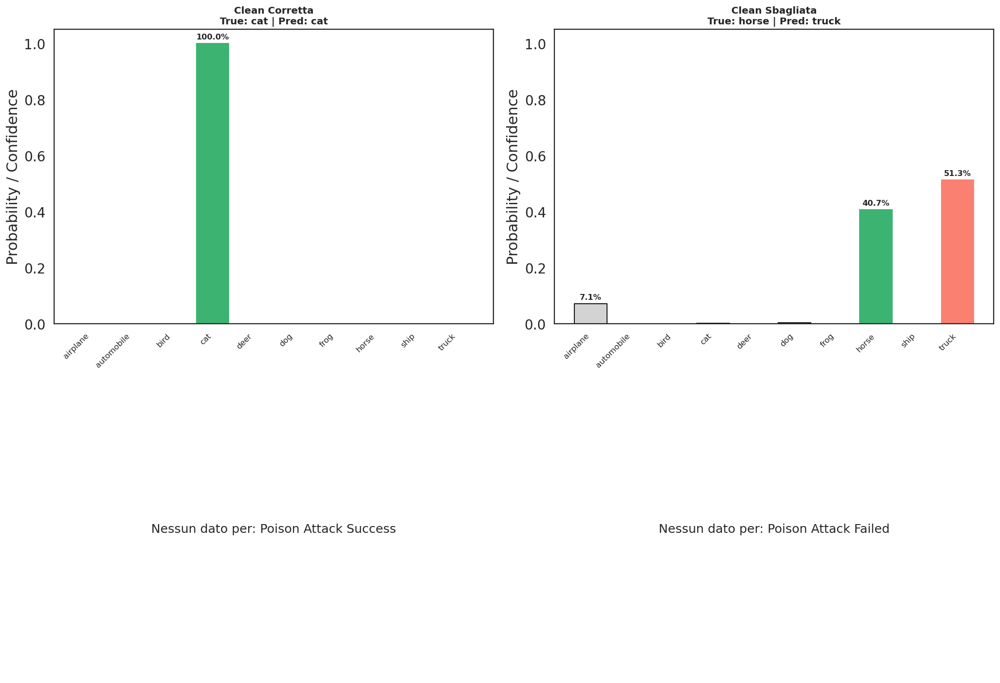

In [26]:
if should_run_section('CAPTUM_SUITE'):
    clean_memory()
    # ==============================================================================
    # 14. UNIFIED CAPTUM SUITE: INPUT ATTRIBUTION, LAYER FORENSICS & XAI METRICS
    # ==============================================================================
    !pip install captum --quiet


    import copy
    import os, glob, re
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import numpy as np
    import matplotlib.pyplot as plt
    import cv2
    import pandas as pd


    # ==============================================================================
    # 0. ADAPTIVE MODEL SELECTION AND LOADING
    # ==============================================================================
    strategy_name = (
        best_overall_config.get("strategy", "pipeline").upper()
        if "best_overall_config" in globals() and best_overall_config
        else "PIPELINE"
    )


    if "best_model" in globals() and best_model is not None:
        current_model = best_model
    elif "current_model" in globals() and current_model is not None:
        pass
    else:
        best_p = IMPORTED_MODEL_PATH if ("USE_IMPORTED_MODEL" in globals() and USE_IMPORTED_MODEL) else PATH_CONFIG.get("best_model_path", "/kaggle/working/best_model_grid_search.pth")
        if os.path.exists(best_p):
            print(f"📦 Adaptive loading of the model from: {best_p}")
            arch_name = GLOBAL_CONFIG.get("architecture", "resnet50") if "GLOBAL_CONFIG" in globals() else "resnet50"
            current_model, _, _, _, _ = build_model(device=device, num_classes=NUM_CLASSES, architecture=arch_name, TRANSFER_LEARNING=False, FINETUNE=False)
            current_model = load_checkpoint_adaptively(current_model, best_p, device=device)
            current_model.eval()


    # Model resolution recognition (7x7 -> 224x224, 3x3 -> 32x32)
    is_pipeline = hasattr(current_model, "conv1") and current_model.conv1.kernel_size[0] == 7
    eval_transform = transform_pipeline if is_pipeline else transform_scratch_test
    eval_img_size = (224, 224) if is_pipeline else (32, 32)
    mean = np.array(IMAGENET_MEAN) if is_pipeline else np.array(SCRATCH_MEAN)
    std = np.array(IMAGENET_STD) if is_pipeline else np.array(SCRATCH_STD)


    print("\n" + "=" * 90)
    print(f"🔍 [SECTION 14] STARTING CAPTUM FORENSIC SUITE ON THE 4 DIAGNOSTIC CASES ({'PIPELINE 224x224' if is_pipeline else 'SCRATCH 32x32'})")
    print("=" * 90)


    # DEFINITIVE FIX FOR DEEPLIFT ON RESNET: REWIRING OF THE SHARED RELUS
    def fix_resnet_relus_for_deeplift(model):
        for module in model.modules():
            if hasattr(module, 'conv1') and hasattr(module, 'conv2') and hasattr(module, 'conv3'):
                if not hasattr(module, 'relu1'):
                    module.relu1 = torch.nn.ReLU(inplace=False)
                if not hasattr(module, 'relu2'):
                    module.relu2 = torch.nn.ReLU(inplace=False)
                if not hasattr(module, 'relu3'):
                    module.relu3 = torch.nn.ReLU(inplace=False)

                def make_bottleneck_forward(m):
                    def new_forward(x):
                        identity = x
                        out = m.conv1(x)
                        if hasattr(m, 'bn1') and m.bn1 is not None:
                            out = m.bn1(out)
                        out = m.relu1(out)


                        out = m.conv2(out)
                        if hasattr(m, 'bn2') and m.bn2 is not None:
                            out = m.bn2(out)
                        out = m.relu2(out)


                        out = m.conv3(out)
                        if hasattr(m, 'bn3') and m.bn3 is not None:
                            out = m.bn3(out)


                        if hasattr(m, 'downsample') and m.downsample is not None:
                            identity = m.downsample(x)
                        elif hasattr(m, 'shortcut') and m.shortcut is not None:
                            identity = m.shortcut(x)


                        out = out + identity
                        out = m.relu3(out)
                        return out
                    return new_forward


                module.forward = make_bottleneck_forward(module)


            elif hasattr(module, 'conv1') and hasattr(module, 'conv2'):
                if not hasattr(module, 'relu1'):
                    module.relu1 = torch.nn.ReLU(inplace=False)
                if not hasattr(module, 'relu2'):
                    module.relu2 = torch.nn.ReLU(inplace=False)

                def make_basic_forward(m):
                    def new_forward(x):
                        identity = x
                        out = m.conv1(x)
                        if hasattr(m, 'bn1') and m.bn1 is not None:
                            out = m.bn1(out)
                        out = m.relu1(out)


                        out = m.conv2(out)
                        if hasattr(m, 'bn2') and m.bn2 is not None:
                            out = m.bn2(out)
                        # BasicBlock (He et al., 2016): no ReLU before the residual sum.
                        # The previous version applied relu2 here too, altering the function
                        # computed by the network for all the following sections.

                        if hasattr(m, 'downsample') and m.downsample is not None:
                            identity = m.downsample(x)
                        elif hasattr(m, 'shortcut') and m.shortcut is not None:
                            identity = m.shortcut(x)


                        out = out + identity
                        out = m.relu2(out)
                        return out
                    return new_forward

                module.forward = make_basic_forward(module)


    # The rewiring must leave the network function unchanged: numerical equivalence is verified
    # on a probe input and, in case of discrepancy, the original forwards are restored.
    _probe_res = 224 if is_pipeline else int(globals().get("NATIVE_IMG_SIZE", (32, 32))[0])
    _probe_gen = torch.Generator().manual_seed(0)
    _probe_x = torch.randn(2, int(globals().get("NUM_CHANNELS", 3)), _probe_res, _probe_res, generator=_probe_gen).to(device)
    current_model.eval()
    with torch.no_grad():
        _ref_out = current_model(_probe_x).detach().clone()
    _ref_fingerprint = model_fingerprint(current_model) if "model_fingerprint" in globals() else None
    fix_resnet_relus_for_deeplift(current_model)
    with torch.no_grad():
        _new_out = current_model(_probe_x)
    if not torch.allclose(_ref_out, _new_out, rtol=1e-4, atol=1e-5):
        for _m in current_model.modules():
            if "forward" in _m.__dict__:
                del _m.forward
        print("⚠️ [CAPTUM] ReLU rewiring not equivalent: original forwards restored (DeepLift may not be reliable).")
    else:
        print("✅ [CAPTUM] ReLU rewiring for DeepLift verified: network output unchanged.")
    if _ref_fingerprint is not None and model_fingerprint(current_model) != _ref_fingerprint:
        print("⚠️ [CAPTUM] The model's state_dict appears to have been modified by the rewiring.")
    del _probe_x, _ref_out, _new_out


    def sanitize_model_for_captum(model):
        model.eval()
        for name, module in model.named_modules():
            if hasattr(module, 'inplace'):
                try:
                    module.inplace = False
                except Exception:
                    pass
            if hasattr(module, 'relu') and isinstance(getattr(module, 'relu'), torch.nn.ReLU):
                setattr(module, 'relu', torch.nn.ReLU(inplace=False))
            if hasattr(module, 'relu1') and hasattr(module, 'relu2'):
                setattr(module, 'relu1', torch.nn.ReLU(inplace=False))
                setattr(module, 'relu2', torch.nn.ReLU(inplace=False))


    sanitize_model_for_captum(current_model)


    # Import Captum modules
    from captum.attr import (
        IntegratedGradients,
        GradientShap,
        DeepLift,
        DeepLiftShap,
        Saliency,
        InputXGradient,
        GuidedBackprop,
        Deconvolution,
        NoiseTunnel,
        Occlusion,
        FeatureAblation,
        LayerIntegratedGradients,
        LayerConductance,
        LayerGradCam,
    )
    from captum.metrics import infidelity, sensitivity_max
    from captum.attr import visualization as viz


    classes = CLASS_NAMES if "CLASS_NAMES" in globals() else CIFAR10_CLASSES
    target_backdoor_class = TARGET_LABEL if "TARGET_LABEL" in globals() else 0


    def apply_standard_overlay(orig_rgb, saliency_2d, alpha=0.45, cmap="jet"):
        s_min, s_max = saliency_2d.min(), saliency_2d.max()
        norm_map = (saliency_2d - s_min) / (s_max - s_min) if s_max > s_min else np.zeros_like(saliency_2d)
        norm_map = np.clip(norm_map, 0, 1)
        if norm_map.shape != orig_rgb.shape[:2]:
            norm_map = cv2.resize(norm_map, (orig_rgb.shape[1], orig_rgb.shape[0]), interpolation=cv2.INTER_LINEAR)
        colormap = plt.get_cmap(cmap)
        heat_rgb = colormap(norm_map)[:, :, :3]
        return np.clip((1.0 - alpha) * orig_rgb + alpha * heat_rgb, 0, 1)


    # 1. DATASET PREPARATION WITH THE CORRECT TRANSFORMATION
    _raw_base = globals().get("raw_test_dataset")
    if _raw_base is None and "clean_test_dataset" in globals():
        _raw_base = getattr(clean_test_dataset, "dataset", clean_test_dataset)
    captum_dataset = TransformWrapper(_raw_base, transform=eval_transform)
    clean_ldr = DataLoader(captum_dataset, batch_size=BATCH_SIZE if "BATCH_SIZE" in globals() else 64, shuffle=False, drop_last=False)

    poison_ldr = globals().get("poison_test_loader") or globals().get("poison_loader")
    if poison_ldr is None and globals().get("poison_test_dataset") is not None:
        poison_ldr = DataLoader(poison_test_dataset, batch_size=BATCH_SIZE if "BATCH_SIZE" in globals() else 64, shuffle=False, drop_last=False)


    # 2. SELECTION OF THE 4 KEY DIAGNOSTIC CASES
    def find_images_for_analysis(model, clean_ldr, poison_ldr, device):
        clean_correct, clean_wrong = None, None
        poison_correct, poison_wrong = None, None

        if clean_ldr is not None:
            for images, labels in clean_ldr:
                images, labels = images.to(device), labels.to(device)
                with torch.no_grad():
                    preds = torch.argmax(model(images), dim=1)
                for i in range(len(preds)):
                    if clean_correct is None and preds[i] == labels[i]:
                        clean_correct = (images[i].unsqueeze(0).clone(), labels[i].item(), preds[i].item())
                    if clean_wrong is None and preds[i] != labels[i]:
                        clean_wrong = (images[i].unsqueeze(0).clone(), labels[i].item(), preds[i].item())
                    if clean_correct is not None and clean_wrong is not None:
                        break
                if clean_correct is not None and clean_wrong is not None:
                    break


        if poison_ldr is not None:
            for images, labels in poison_ldr:
                images, labels = images.to(device), labels.to(device)
                with torch.no_grad():
                    preds = torch.argmax(model(images), dim=1)
                for i in range(len(preds)):
                    if (
                        poison_correct is None
                        and preds[i].item() == target_backdoor_class
                        and labels[i].item() != target_backdoor_class
                    ):
                        poison_correct = (images[i].unsqueeze(0).clone(), labels[i].item(), preds[i].item())
                    if (
                        poison_wrong is None
                        and preds[i].item() != target_backdoor_class
                        and labels[i].item() != target_backdoor_class
                    ):
                        poison_wrong = (images[i].unsqueeze(0).clone(), labels[i].item(), preds[i].item())
                    if poison_correct is not None and poison_wrong is not None:
                        break
                if poison_correct is not None and poison_wrong is not None:
                    break
        return clean_correct, clean_wrong, poison_correct, poison_wrong


    clean_correct, clean_wrong, poison_correct, poison_wrong = find_images_for_analysis(
        current_model, clean_ldr, poison_ldr, device
    )


    images_to_analyze = {
        "Correct Clean": clean_correct,
        "Incorrect Clean": clean_wrong,
        "Poison Attack Success": poison_correct,
        "Poison Attack Failed": poison_wrong,
    }


    print("🎯 4 Diagnostic cases successfully isolated:")
    for k, v in images_to_analyze.items():
        if v is not None:
            c_true_str = classes[v[1]] if v[1] < len(classes) else str(v[1])
            c_pred_str = classes[v[2]] if v[2] < len(classes) else str(v[2])
            print(f"  • {k:<22}: True={c_true_str:<15} | Pred={c_pred_str:<15}")
        else:
            print(f"  • {k:<22}: [No sample found in the loader]")


    # 3. CONFIDENCE ANALYSIS OF THE 4 DIAGNOSTIC CASES (BAR-PLOT 2x2)
    print("\n--- 📊 1. DECISION CONFIDENCE ANALYSIS (4 CASES) ---")
    fig_conf, axes_conf = plt.subplots(2, 2, figsize=(16, 11), dpi=130)
    axes_conf = axes_conf.flatten()
    softmax = torch.nn.Softmax(dim=1)


    for p_idx, (title, data) in enumerate(images_to_analyze.items()):
        ax = axes_conf[p_idx]
        if data is None:
            ax.text(0.5, 0.5, f"No data for: {title}", ha="center", va="center")
            ax.axis("off")
            continue
        inp_img, t_lbl, p_lbl = data
        with torch.no_grad():
            probs = softmax(current_model(inp_img.to(device))).squeeze().cpu().numpy()
        x_pos = np.arange(len(classes))
        bars = ax.bar(x_pos, probs, color="lightgray", edgecolor="black")
        if t_lbl < len(bars):
            bars[t_lbl].set_color("mediumseagreen")
        if t_lbl != p_lbl and p_lbl < len(bars):
            bars[p_lbl].set_color("salmon")

        ax.set_xticks(x_pos)
        ax.set_xticklabels(classes, rotation=90 if len(classes) > 15 else 45, ha="right", fontsize=8 if len(classes) > 15 else 9)
        ax.set_ylim(0, 1.05)
        t_name = classes[t_lbl] if t_lbl < len(classes) else str(t_lbl)
        p_name = classes[p_lbl] if p_lbl < len(classes) else str(p_lbl)
        ax.set_title(f"{title}\nTrue: {t_name} | Pred: {p_name}", fontweight="bold", fontsize=11)
        ax.set_ylabel("Probability / Confidence")
        for bar in bars:
            h = bar.get_height()
            if h > 0.05:
                ax.annotate(
                    f"{h*100:.1f}%",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=8 if len(classes) > 15 else 9,
                    fontweight="bold",
                )


    # --- SAVING METRICS & CONFIDENCE PLOT OF THE 4 CASES (ATTACKER_MODEL_LEVEL) ---
    try:
        out_dir_captum = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
        os.makedirs(out_dir_captum, exist_ok=True)
        att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
        _captum_strat = str(best_overall_config.get("strategy", "model")).lower() if "best_overall_config" in globals() and best_overall_config else str(globals().get("best_strat", "model"))

        conf_cases_img = f"captum_cases_confidence_{att_type_str}_{_captum_strat}.png"
        conf_cases_path = os.path.join(out_dir_captum, conf_cases_img)
        fig_conf.savefig(conf_cases_path, bbox_inches='tight', dpi=130)
        globals()['CAPTUM_CASES_CONF_IMG_PATH'] = conf_cases_path
        globals()['captum_cases_conf_img'] = conf_cases_img
        if 'RUN_RESULTS' in globals() and isinstance(RUN_RESULTS, dict):
            RUN_RESULTS['captum_cases_conf_img'] = conf_cases_img


        # Extraction of Poison Success confidence
        if images_to_analyze.get("Poison Attack Success") is not None:
            p_data = images_to_analyze["Poison Attack Success"]
            p_img, p_t_lbl, p_p_lbl = p_data
            with torch.no_grad():
                p_probs = softmax(current_model(p_img.to(device))).squeeze().cpu().numpy()
            p_target_conf = float(p_probs[p_p_lbl])
            globals()['captum_poison_success_conf'] = p_target_conf
            if 'RUN_RESULTS' in globals() and isinstance(RUN_RESULTS, dict):
                RUN_RESULTS['captum_poison_success_conf'] = p_target_conf
    except Exception as e_c39:
        print(f"⚠️ [CAPTUM C39 SAVE WARNING]: {e_c39}")


    plt.tight_layout()
    plt.show()













### Primary Attribution


🔬 2. PRIMARY ATTRIBUTIONS: COMPLETE FORENSIC SUITE (SCRATCH (32x32))
📦 Backbone: ResNet | Network Resolution: 32x32

📌 [FORENSIC CASE] CORRECT CLEAN
   True Class: cat (3) | Predicted: cat (3)


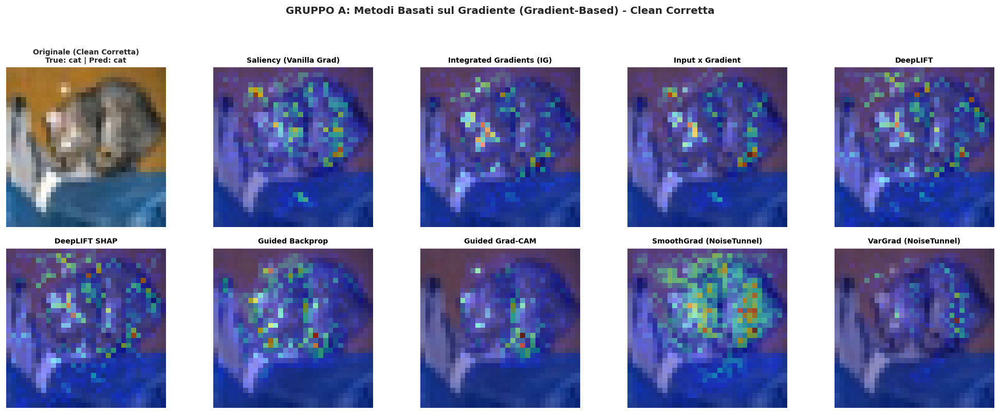

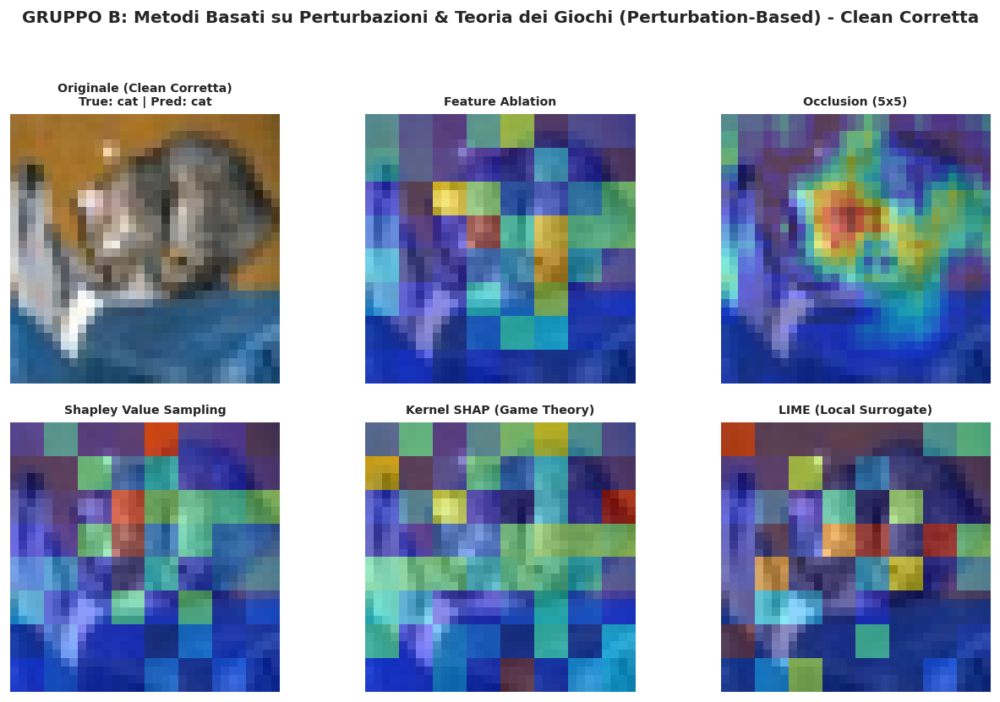


📌 [FORENSIC CASE] INCORRECT CLEAN
   True Class: horse (7) | Predicted: truck (9)


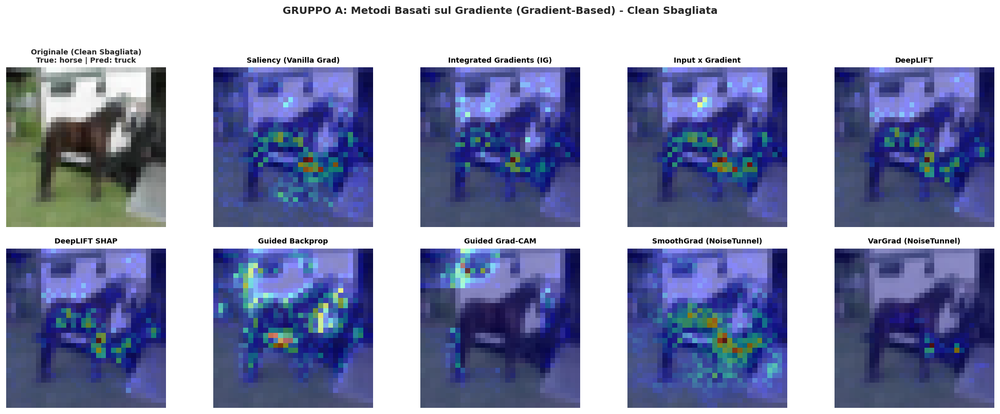

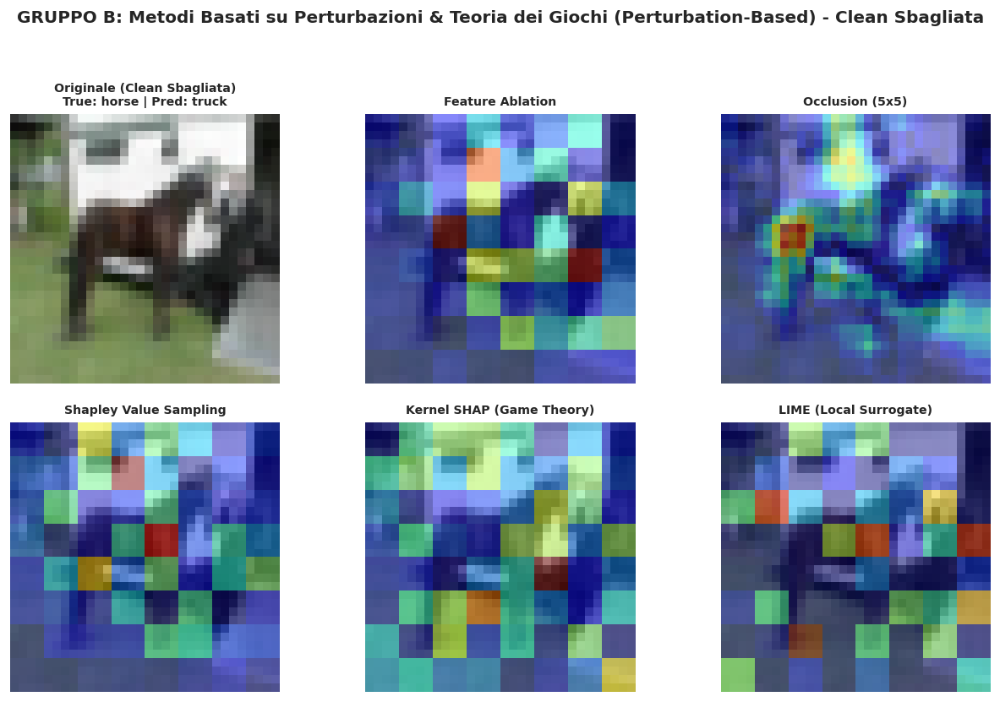

In [27]:
if should_run_section('CAPTUM_SUITE'):
    # ------------------------------------------------------------------------------
    # 3. PRIMARY INPUT ATTRIBUTIONS (COMPLETE SUITE STRUCTURED BY METHODOLOGICAL FAMILY)
    # ------------------------------------------------------------------------------
    import os
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import numpy as np
    import matplotlib.pyplot as plt
    import pandas as pd


    from captum.attr import (
        Saliency,
        IntegratedGradients,
        InputXGradient,
        DeepLift,
        DeepLiftShap,
        GuidedBackprop,
        GuidedGradCam,
        KernelShap,
        ShapleyValueSampling,
        Lime,
        NoiseTunnel,
        FeatureAblation,
        Occlusion,
    )


    # ==============================================================================
    # 1. MODEL AND METADATA VERIFICATION AND RESOLUTION
    # ==============================================================================
    # Single resolver of the contract: no reconstruction with TRANSFER_LEARNING flags deduced from the name.
    captum_net = get_audit_model()
    _captum_ctx = get_model_eval_context(captum_net, device=device)


    is_pipeline = bool(_captum_ctx["is_pipeline"])
    strategy_name = f"{_captum_ctx['strategy'].upper()} ({_captum_ctx['target_res']}x{_captum_ctx['target_res']})"
    mean_used = np.array(_captum_ctx["mean"])
    std_used = np.array(_captum_ctx["std"])
    classes = CLASS_NAMES if "CLASS_NAMES" in globals() else CIFAR10_CLASSES
    num_classes = len(classes)


    print("\n" + "=" * 90)
    print(f"🔬 2. PRIMARY ATTRIBUTIONS: COMPLETE FORENSIC SUITE ({strategy_name})")
    print(f"📦 Backbone: {captum_net.__class__.__name__} | Network Resolution: {'224x224' if is_pipeline else '32x32'}")
    print("=" * 90)


    # Universal identification of the target layer for Guided Grad-CAM
    raw_conv = get_penultimate_conv(captum_net) if "get_penultimate_conv" in globals() else None
    if raw_conv is None:
        convs = [m for m in captum_net.modules() if isinstance(m, nn.Conv2d)]
        target_conv_layer = convs[-1] if convs else list(captum_net.children())[-2]
    else:
        target_conv_layer = raw_conv[1] if isinstance(raw_conv, (tuple, list)) else raw_conv


    # In-place ReLU sanitization for compatibility with Captum
    for m in captum_net.modules():
        if isinstance(m, nn.ReLU):
            m.inplace = False


    # ==============================================================================
    # 2. INSTANTIATION OF GRADIENT & PERTURBATION-BASED METHODS
    # ==============================================================================
    saliency = Saliency(captum_net)
    ig = IntegratedGradients(captum_net)
    input_x_grad = InputXGradient(captum_net)

    # DeepLIFT initialization with safe fallback
    try:
        deep_lift = DeepLift(captum_net)
    except Exception:
        deep_lift = None


    try:
        deep_lift_shap = DeepLiftShap(captum_net)
    except Exception:
        deep_lift_shap = None


    guided_bp = GuidedBackprop(captum_net)
    guided_gc = GuidedGradCam(captum_net, target_conv_layer)
    nt_smoothgrad = NoiseTunnel(saliency)
    nt_vargrad = NoiseTunnel(saliency)


    feature_ablation = FeatureAblation(captum_net)
    occlusion = Occlusion(captum_net)
    shapley_val = ShapleyValueSampling(captum_net)
    lime = Lime(captum_net)
    kernel_shap = KernelShap(captum_net)


    # Wrapper for DeepLIFT and DeepLIFT SHAP: if the method fails IG is used, but the fallback is
    # declared in the panel title (previously the IG map appeared labeled as DeepLIFT).
    _c42_fallback_used = {}

    def compute_deeplift_safe(img, lbl):
        try:
            if deep_lift is not None:
                return deep_lift.attribute(img, target=lbl)
        except Exception as e_dl:
            _c42_fallback_used["DeepLIFT"] = str(e_dl)[:60]
        _c42_fallback_used.setdefault("DeepLIFT", "DeepLift not instantiable")
        return ig.attribute(img, target=lbl, n_steps=30)


    def compute_deeplift_shap_safe(img, lbl):
        try:
            if deep_lift_shap is not None:
                baselines = torch.zeros((2, img.shape[1], img.shape[2], img.shape[3]), device=device)
                return deep_lift_shap.attribute(img, baselines=baselines, target=lbl)
        except Exception as e_dls:
            _c42_fallback_used["DeepLIFT SHAP"] = str(e_dls)[:60]
        _c42_fallback_used.setdefault("DeepLIFT SHAP", "DeepLiftShap not instantiable")
        return ig.attribute(img, target=lbl, n_steps=25)


    gradient_suite = [
        ("Saliency (Vanilla Grad)", lambda img, lbl: saliency.attribute(img, target=lbl)),
        ("Integrated Gradients (IG)", lambda img, lbl: ig.attribute(img, target=lbl, n_steps=int(globals().get("IG_N_STEPS", 50)))),
        ("Input x Gradient", lambda img, lbl: input_x_grad.attribute(img, target=lbl)),
        ("DeepLIFT", lambda img, lbl: compute_deeplift_safe(img, lbl)),
        ("DeepLIFT SHAP", lambda img, lbl: compute_deeplift_shap_safe(img, lbl)),
        ("Guided Backprop", lambda img, lbl: guided_bp.attribute(img, target=lbl)),
        ("Guided Grad-CAM", lambda img, lbl: guided_gc.attribute(img, target=lbl)),
        ("SmoothGrad (NoiseTunnel)", lambda img, lbl: nt_smoothgrad.attribute(img, target=lbl, nt_type="smoothgrad", nt_samples=5, stdevs=0.1)),
        ("VarGrad (NoiseTunnel)", lambda img, lbl: nt_vargrad.attribute(img, target=lbl, nt_type="vargrad", nt_samples=5, stdevs=0.1)),
    ]


    # ==============================================================================
    # 3. EXECUTION AND RENDERING ON THE ISOLATED FORENSIC CASES
    # ==============================================================================
    with preserve_model_state(captum_net):
        for title, data in images_to_analyze.items():
            if data is None:
                continue
            input_image, true_label, predicted_label = data
            input_image = input_image.clone().detach().to(device)
            if input_image.dim() == 3:
                input_image = input_image.unsqueeze(0)
            input_image.requires_grad = True


            _, c_in, img_h, img_w = input_image.shape


            # Construction of an adaptive superpixel mask for the current resolution
            grid_div = 8 if img_h <= 64 else 16
            grid_h, grid_w = max(4, img_h // grid_div), max(4, img_w // grid_div)
            n_feats = (img_h // grid_h) * (img_w // grid_w)


            f_mask_raw = torch.arange(n_feats, device=device).view(1, 1, img_h // grid_h, img_w // grid_w)
            feature_mask_dyn = F.interpolate(f_mask_raw.float(), size=(img_h, img_w), mode='nearest').long()
            feature_mask_dyn = feature_mask_dyn.repeat(1, c_in, 1, 1)


            occ_h, occ_w = max(4, img_h // 6), max(4, img_w // 6)
            occ_str_h, occ_str_w = max(2, occ_h // 2), max(2, occ_w // 2)


            perturbation_suite = [
                ("Feature Ablation", lambda img, lbl: feature_ablation.attribute(img, target=lbl, feature_mask=feature_mask_dyn)),
                (f"Occlusion ({occ_h}x{occ_w})", lambda img, lbl: occlusion.attribute(img, target=lbl, sliding_window_shapes=(c_in, occ_h, occ_w), strides=(c_in, occ_str_h, occ_str_w))),
                ("Shapley Value Sampling", lambda img, lbl: shapley_val.attribute(img, target=lbl, feature_mask=feature_mask_dyn, n_samples=25)),
                ("Kernel SHAP (Game Theory)", lambda img, lbl: kernel_shap.attribute(img, target=lbl, feature_mask=feature_mask_dyn, n_samples=40)),
                ("LIME (Local Surrogate)", lambda img, lbl: lime.attribute(img, target=lbl, feature_mask=feature_mask_dyn, n_samples=40)),
            ]


            # Accurate denormalization of the original image
            orig_np = input_image.squeeze(0).cpu().detach().permute(1, 2, 0).numpy()
            if orig_np.min() < 0.0 or orig_np.max() > 1.0:
                orig_rgb = orig_np * std_used + mean_used
            else:
                orig_rgb = orig_np
            orig_rgb = np.clip(orig_rgb, 0.0, 1.0)


            t_name = classes[true_label] if true_label < len(classes) else str(true_label)
            p_name = classes[predicted_label] if predicted_label < len(classes) else str(predicted_label)


            print(f"\n{'='*90}")
            print(f"📌 [FORENSIC CASE] {title.upper()}")
            print(f"   True Class: {t_name} ({true_label}) | Predicted: {p_name} ({predicted_label})")
            print(f"{'='*90}")


            # --------------------------------------------------------------------------
            # 1. GROUP A: GRADIENT-BASED METHODS (9 METHODS)
            # --------------------------------------------------------------------------
            num_grad = len(gradient_suite)
            cols_grad = 5
            rows_grad = int(np.ceil((num_grad + 1) / cols_grad))
            fig_g, axes_g = plt.subplots(rows_grad, cols_grad, figsize=(cols_grad * 3.4, rows_grad * 3.3), dpi=120)
            axes_g = axes_g.flatten()


            axes_g[0].imshow(orig_rgb)
            axes_g[0].set_title(f"Original ({title})\nTrue: {t_name} | Pred: {p_name}", fontsize=8.5, fontweight="bold")
            axes_g[0].axis("off")


            for idx, (m_name, m_func) in enumerate(gradient_suite, start=1):
                try:
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                    _c42_fallback_used.clear()
                    attr = m_func(input_image, predicted_label)
                    attr_2d = torch.sum(torch.abs(attr), dim=1).squeeze().cpu().detach().numpy()
                    overlay = apply_standard_overlay(orig_rgb, attr_2d, alpha=0.45, cmap="jet")
                    axes_g[idx].imshow(overlay)
                    if _c42_fallback_used:
                        print(f"   ⚠️ {m_name}: method not executable ({list(_c42_fallback_used.values())[0]}) -> map computed with IG")
                    axes_g[idx].set_title(m_name + (" [FALLBACK: IG]" if _c42_fallback_used else ""), fontsize=8.5, fontweight="bold",
                                          color="darkorange" if _c42_fallback_used else "black")
                    axes_g[idx].axis("off")
                except Exception as e:
                    axes_g[idx].text(0.5, 0.5, f"N/A:\n{str(e)[:22]}", ha="center", va="center", fontsize=8)
                    axes_g[idx].axis("off")
                finally:
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()


            for empty_ax in axes_g[num_grad + 1:]:
                empty_ax.axis("off")

            fig_g.suptitle(f"GROUP A: Methods Based on the Gradient (Gradient-Based) - {title}", fontsize=12, fontweight="bold", y=1.02)
            if "Poison Attack Success" in title:
                try:
                    out_dir_c41 = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                    os.makedirs(out_dir_c41, exist_ok=True)
                    att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
                    _xai_fig_strat = str(best_overall_config.get("strategy", "model")).lower() if "best_overall_config" in globals() and best_overall_config else "model"
                    primary_grad_img = f"captum_primary_grad_{att_type_str}_{_xai_fig_strat}.png"
                    primary_grad_path = os.path.join(out_dir_c41, primary_grad_img)
                    fig_g.text(0.01, -0.03, provenance_caption("CAPTUM_PRIMARY_GRAD", extra=title), fontsize=7, alpha=0.7)
                    fig_g.savefig(primary_grad_path, bbox_inches='tight', dpi=130)
                    register_artifact("CAPTUM_PRIMARY_GRAD", primary_grad_path)
                    globals()['CAPTUM_PRIMARY_GRAD_IMG_PATH'] = primary_grad_path
                    globals()['captum_primary_grad_img'] = primary_grad_img
                    if 'RUN_RESULTS' in globals() and isinstance(RUN_RESULTS, dict):
                        RUN_RESULTS['captum_primary_grad_img'] = primary_grad_img
                except Exception as e_c41g:
                    print(f"⚠️ [CAPTUM C41 GRAD SAVE WARNING]: {e_c41g}")


            plt.tight_layout()
            plt.show()


            # --------------------------------------------------------------------------
            # 2. GROUP B: PERTURBATION & SURROGATE-BASED METHODS (5 METHODS)
            # --------------------------------------------------------------------------
            num_pert = len(perturbation_suite)
            cols_pert = 3
            rows_pert = 2
            fig_p, axes_p = plt.subplots(rows_pert, cols_pert, figsize=(cols_pert * 3.6, rows_pert * 3.4), dpi=120)
            axes_p = axes_p.flatten()


            axes_p[0].imshow(orig_rgb)
            axes_p[0].set_title(f"Original ({title})\nTrue: {t_name} | Pred: {p_name}", fontsize=8.5, fontweight="bold")
            axes_p[0].axis("off")


            for idx, (m_name, m_func) in enumerate(perturbation_suite, start=1):
                try:
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                    attr = m_func(input_image, predicted_label)
                    attr_2d = torch.sum(torch.abs(attr), dim=1).squeeze().cpu().detach().numpy()
                    overlay = apply_standard_overlay(orig_rgb, attr_2d, alpha=0.45, cmap="jet")
                    axes_p[idx].imshow(overlay)
                    axes_p[idx].set_title(m_name, fontsize=8.5, fontweight="bold")
                    axes_p[idx].axis("off")
                except Exception as e:
                    axes_p[idx].text(0.5, 0.5, f"N/A:\n{str(e)[:22]}", ha="center", va="center", fontsize=8)
                    axes_p[idx].axis("off")
                finally:
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()


            for empty_ax in axes_p[num_pert + 1:]:
                empty_ax.axis("off")

            fig_p.suptitle(f"GROUP B: Methods Based on Perturbations & Game Theory (Perturbation-Based) - {title}", fontsize=12, fontweight="bold", y=1.02)
            if "Poison Attack Success" in title:
                try:
                    out_dir_c41 = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                    os.makedirs(out_dir_c41, exist_ok=True)
                    att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
                    _xai_fig_strat = str(best_overall_config.get("strategy", "model")).lower() if "best_overall_config" in globals() and best_overall_config else "model"
                    primary_pert_img = f"captum_primary_pert_{att_type_str}_{_xai_fig_strat}.png"
                    primary_pert_path = os.path.join(out_dir_c41, primary_pert_img)
                    fig_p.text(0.01, -0.03, provenance_caption("CAPTUM_PRIMARY_PERT", extra=title), fontsize=7, alpha=0.7)
                    fig_p.savefig(primary_pert_path, bbox_inches='tight', dpi=130)
                    register_artifact("CAPTUM_PRIMARY_PERT", primary_pert_path)
                    globals()['CAPTUM_PRIMARY_PERT_IMG_PATH'] = primary_pert_path
                    globals()['captum_primary_pert_img'] = primary_pert_img
                    if 'RUN_RESULTS' in globals() and isinstance(RUN_RESULTS, dict):
                        RUN_RESULTS['captum_primary_pert_img'] = primary_pert_img
                except Exception as e_c41p:
                    print(f"⚠️ [CAPTUM C41 PERT SAVE WARNING]: {e_c41p}")


            plt.tight_layout()
            plt.show()


    check_model_integrity("CAPTUM_PRIMARY")
    clean_memory(verbose=False) if "clean_memory" in globals() else None







### Layer Attribution


🧠 3. LAYER FORENSICS: COMPLETE LAYER ATTRIBUTION SUITE (SCRATCH)
📌 [MODEL CHECK] Clean F1: N/A | ASR: N/A | TOI (F1*ASR): 0.0


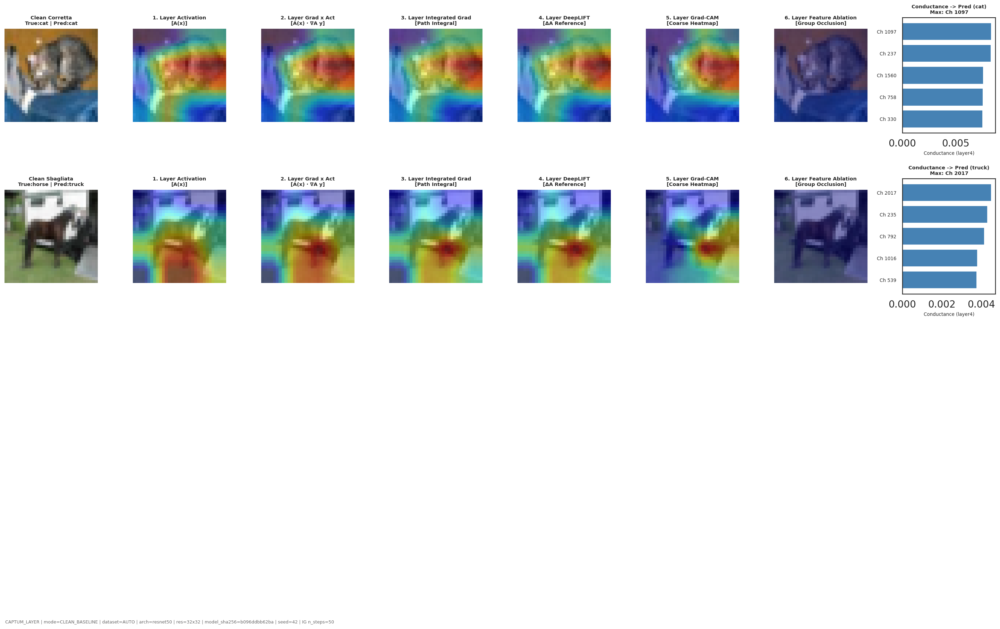


📊 [SUMMARY TABLE] XAI FIDELITY METRICS & CHANNEL CONDUCTANCE:
  Forensic Case True Class Pred Class  Conv Delta (Δ ≈ 0)  |Δ| / |F(x)-F(0)|  Infidelity (↓ Fidelity)  Max-Sensitivity (↓ Robustness)  Top Ch Conductance (Layer4)  Conductance Top Ch
 Correct Clean         cat        cat            0.272626           0.023523                1.823264                        0.173065                         1097            0.008369
Incorrect Clean      horse      truck           -0.061332           0.007571                0.376315                        0.181757                         2017            0.004496
🧹 [Memory Cleanup] RAM: 3.76/31.35 GB (13.5%)


In [28]:
if should_run_section('CAPTUM_SUITE'):
    # ------------------------------------------------------------------------------
    # 4. LAYER FORENSICS, LAYER ATTRIBUTION SUITE & XAI METRICS
    # Explanation quality metrics: Yeh et al., "On the (In)fidelity and Sensitivity
    # of Explanations", NeurIPS 2019 (arXiv:1901.09392) — INFD (eq. infidelity) e SENS_MAX.
    # IG: Sundararajan et al., ICML 2017 (arXiv:1703.01365), sec. 5: 20-300 steps to
    # approximate the integral within 5%, verifying completeness (Prop. 1).
    # ------------------------------------------------------------------------------
    import os
    import torch
    import numpy as np
    import matplotlib.pyplot as plt
    import pandas as pd


    from captum.attr import (
        LayerIntegratedGradients,
        LayerConductance,
        LayerGradCam,
        LayerActivation,
        LayerGradientXActivation,
        LayerDeepLift,
        LayerFeatureAblation,
        IntegratedGradients
    )
    from captum.metrics import infidelity, sensitivity_max


    # ==============================================================================
    # INSPECTED MODEL (single resolver of the contract)
    # ==============================================================================
    captum_net = get_audit_model()
    _captum_ctx = get_model_eval_context(captum_net, device=device)
    strategy_name = str(_captum_ctx["strategy"]).upper()
    mean_used = np.array(_captum_ctx["mean"])
    std_used = np.array(_captum_ctx["std"])


    # Universal metadata verification print
    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}


    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))


    print("\n" + "=" * 90)
    print(f"🧠 3. LAYER FORENSICS: COMPLETE LAYER ATTRIBUTION SUITE ({strategy_name})")
    print(f"📌 [MODEL CHECK] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 90)


    # Expensive parameters (overridable from globals for quick tests)
    CAPTUM_IG_N_STEPS = int(globals().get("CAPTUM_IG_N_STEPS", 50))        # Captum default; sec. 5 of Sundararajan et al.
    CAPTUM_INFID_SIGMA = float(globals().get("CAPTUM_INFID_SIGMA", 0.05))  # noise std. dev. (normalized space)
    CAPTUM_INFID_SAMPLES = int(globals().get("CAPTUM_INFID_SAMPLES", 10))  # default Captum
    CAPTUM_SENS_RADIUS = float(globals().get("CAPTUM_SENS_RADIUS", 0.02))  # L-inf radius (normalized space), Captum default
    CAPTUM_SENS_SAMPLES = int(globals().get("CAPTUM_SENS_SAMPLES", 5))
    _c44_gen = torch.Generator().manual_seed(int(globals().get("SEED", 42)))


    # Reference layer for conductance and neurons: output of layer4 (same layer used
    # by the next Neuron Attribution cell, for consistency between the two analyses).
    target_layer = (
        captum_net.layer4 if hasattr(captum_net, "layer4") else list(captum_net.children())[-2]
    )
    CAPTUM_NEURON_LAYER_NAME = "layer4" if hasattr(captum_net, "layer4") else type(target_layer).__name__


    # Instantiation of the Layer Attribution Suite
    layer_act = LayerActivation(captum_net, target_layer)
    layer_grad_x_act = LayerGradientXActivation(captum_net, target_layer)
    layer_ig = LayerIntegratedGradients(captum_net, target_layer)
    layer_dl = LayerDeepLift(captum_net, target_layer)
    layer_gc = LayerGradCam(captum_net, target_layer)
    layer_cond = LayerConductance(captum_net, target_layer)
    layer_ablation = LayerFeatureAblation(captum_net, target_layer)
    ig_explainer = IntegratedGradients(captum_net)
    # "Local" IG (mean gradient along the path, without multiplying by x - baseline): it is the
    # explanation for which I^T·Φ approximates f(x) - f(x - I), as required by infidelity
    # (Captum doc of `infidelity`, attributions with multiply_by_inputs=False).
    ig_local_explainer = IntegratedGradients(captum_net, multiply_by_inputs=False)


    # Channel-group mask for LayerFeatureAblation: number of channels derived from the
    # actual layer (previously it was fixed to 2048/512 based on the architecture name).
    layer_mask = None
    n_groups = 16
    for _probe_case in images_to_analyze.values():
        if _probe_case is not None:
            with torch.no_grad():
                _probe_act = layer_act.attribute(_probe_case[0].clone().detach().to(device))
            num_target_channels = int(_probe_act.shape[1])
            n_groups = max(1, min(16, num_target_channels))
            layer_mask = (torch.arange(num_target_channels, device=device) * n_groups // num_target_channels).view(1, -1, 1, 1)
            del _probe_act
            break


    def gaussian_perturb_fn(inputs):
        # Captum/Yeh et al. contract: returns (perturbation I, perturbed input x - I).
        # The previous version returned (x - I, I), i.e. it evaluated f on the noise alone.
        noise = torch.randn(inputs.shape, generator=_c44_gen).to(inputs.device, inputs.dtype) * CAPTUM_INFID_SIGMA
        return noise, inputs - noise


    def uniform_linf_perturb_fn(inputs, perturb_radius=0.02):
        # Like Captum's default_perturb_func (L-inf ball), but with a local generator.
        noise = torch.empty(inputs.shape).uniform_(-perturb_radius, perturb_radius, generator=_c44_gen)
        return inputs + noise.to(inputs.device, inputs.dtype)


    xai_metrics_records = []
    captum_metric_errors = {}


    # Optimized Layer Attribution Suite
    layer_methods = [
        ("1. Layer Activation\n[A(x)]", lambda img, lbl: layer_act.attribute(img)),
        ("2. Layer Grad x Act\n[A(x) · ∇A y]", lambda img, lbl: layer_grad_x_act.attribute(img, target=lbl)),
        ("3. Layer Integrated Grad\n[Path Integral]", lambda img, lbl: layer_ig.attribute(img, target=lbl, n_steps=CAPTUM_IG_N_STEPS)),
        ("4. Layer DeepLIFT\n[ΔA Reference]", lambda img, lbl: layer_dl.attribute(img, target=lbl)),
        ("5. Layer Grad-CAM\n[Coarse Heatmap]", lambda img, lbl: layer_gc.attribute(img, target=lbl)),
        ("6. Layer Feature Ablation\n[Group Occlusion]", lambda img, lbl: layer_ablation.attribute(img, target=lbl, layer_mask=layer_mask)),
    ]


    num_cols = len(layer_methods) + 2  # 1 (Orig) + 6 (Layer Maps) + 1 (Barplot) = 8 columns
    fig_layer, axes_layer = plt.subplots(4, num_cols, figsize=(num_cols * 2.8, 14), dpi=130)


    with preserve_model_state(captum_net):
        for r_idx, (title, data) in enumerate(images_to_analyze.items()):
            if data is None:
                for c in range(num_cols):
                    axes_layer[r_idx, c].axis("off")
                continue

            input_image, true_label, predicted_label = data
            input_image = input_image.clone().detach().to(device)
            input_image.requires_grad = True


            orig_np = input_image.squeeze().cpu().detach().numpy().transpose(1, 2, 0)
            if orig_np.min() < 0.0 or orig_np.max() > 1.0:
                orig_rgb = std_used * orig_np + mean_used
            else:
                orig_rgb = orig_np
            orig_rgb = np.clip(orig_rgb, 0, 1)


            t_name = classes[true_label] if true_label < len(classes) else str(true_label)
            p_name = classes[predicted_label] if predicted_label < len(classes) else str(predicted_label)


            # 1. Original Image
            axes_layer[r_idx, 0].imshow(orig_rgb)
            axes_layer[r_idx, 0].set_title(
                f"{title}\nTrue:{t_name} | Pred:{p_name}",
                fontsize=8,
                fontweight="bold",
            )
            axes_layer[r_idx, 0].axis("off")


            # 2. Rendering of the 6 Layer Attribution Maps with JET overlay
            for m_idx, (m_name, m_func) in enumerate(layer_methods, start=1):
                try:
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                    attr_layer = m_func(input_image, predicted_label)
                    if attr_layer.dim() == 4:
                        map_2d = torch.mean(torch.abs(attr_layer), dim=1).squeeze().cpu().detach().numpy()
                    elif attr_layer.dim() == 2:
                        map_2d = attr_layer.squeeze().cpu().detach().numpy()
                        img_h_val = orig_rgb.shape[0]
                        map_2d = np.tile(map_2d, (img_h_val, 1))
                    else:
                        map_2d = attr_layer.squeeze().cpu().detach().numpy()

                    overlay = apply_standard_overlay(orig_rgb, map_2d, alpha=0.45, cmap="jet")
                    axes_layer[r_idx, m_idx].imshow(overlay)
                    axes_layer[r_idx, m_idx].set_title(m_name, fontsize=8, fontweight="bold")
                    axes_layer[r_idx, m_idx].axis("off")
                except Exception as e:
                    axes_layer[r_idx, m_idx].text(0.5, 0.5, f"N/A:\n{str(e)[:20]}", ha="center", va="center", fontsize=7)
                    axes_layer[r_idx, m_idx].axis("off")
                finally:
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()


            # 3. Conductance of the layer4 channels toward the PREDICTED class: same path in all
            # the modes (no use of TARGET_LABEL). For the "Poison Attack Success" case the predicted
            # class coincides with the target by construction of the selection (cell 40, oracle).
            top_5_trojan_channels, top_5_scores = np.array([], dtype=int), np.array([])
            try:
                attr_cond_target = layer_cond.attribute(input_image, target=predicted_label, n_steps=CAPTUM_IG_N_STEPS)
                ch_conductance = attr_cond_target.mean(dim=(2, 3)).squeeze(0).cpu().detach().numpy()
                top_5_trojan_channels = np.argsort(np.abs(ch_conductance))[::-1][:5]
                top_5_scores = ch_conductance[top_5_trojan_channels]
            except Exception as e_cond:
                captum_metric_errors[f"conductance/{title}"] = str(e_cond)[:120]

            ax_bar = axes_layer[r_idx, num_cols - 1]
            if len(top_5_trojan_channels):
                bar_pos = np.arange(len(top_5_trojan_channels))
                ax_bar.barh(bar_pos, top_5_scores, color="firebrick" if ("Attack Success" in title and oracle_allowed()) else "steelblue")
                ax_bar.set_yticks(bar_pos)
                ax_bar.set_yticklabels([f"Ch {c}" for c in top_5_trojan_channels], fontsize=7.5)
                ax_bar.invert_yaxis()
                ax_bar.set_title(f"Conductance -> Pred ({p_name})\nMax: Ch {top_5_trojan_channels[0]}", fontsize=8, fontweight="bold")
                ax_bar.set_xlabel(f"Conductance ({CAPTUM_NEURON_LAYER_NAME})", fontsize=7.5)
            else:
                ax_bar.text(0.5, 0.5, "Conductance\nnot computable", ha="center", va="center", fontsize=8)
                ax_bar.axis("off")


            # 4. Quantitative metrics (IG explanation of the predicted class)
            conv_delta, rel_delta = np.nan, np.nan
            base_attr = None
            try:
                base_attr, delta = ig_explainer.attribute(input_image, target=predicted_label, n_steps=CAPTUM_IG_N_STEPS, return_convergence_delta=True)
                conv_delta = float(delta.squeeze().cpu().item())
                with torch.no_grad():
                    _f_x = captum_net(input_image)[0, predicted_label]
                    _f_b = captum_net(torch.zeros_like(input_image))[0, predicted_label]
                _gap = float(torch.abs(_f_x - _f_b).item())
                rel_delta = abs(conv_delta) / _gap if _gap > 0 else np.nan
            except Exception as e_ig:
                captum_metric_errors[f"ig/{title}"] = str(e_ig)[:120]


            infid = np.nan
            try:
                local_attr = ig_local_explainer.attribute(input_image, target=predicted_label, n_steps=CAPTUM_IG_N_STEPS)
                infid = float(
                    infidelity(
                        captum_net, gaussian_perturb_fn, input_image, local_attr, target=predicted_label,
                        n_perturb_samples=CAPTUM_INFID_SAMPLES
                    )
                    .squeeze()
                    .cpu()
                    .item()
                )
            except Exception as e_inf:
                captum_metric_errors[f"infidelity/{title}"] = str(e_inf)[:120]


            # SENS_MAX: previously `lower_bound=0.2` (a nonexistent argument) was forwarded to the
            # explanation function and the call always failed silently (value always N/A).
            sens = np.nan
            try:
                sens = float(
                    sensitivity_max(
                        ig_explainer.attribute, input_image, perturb_func=uniform_linf_perturb_fn,
                        perturb_radius=CAPTUM_SENS_RADIUS, n_perturb_samples=CAPTUM_SENS_SAMPLES,
                        target=predicted_label, n_steps=CAPTUM_IG_N_STEPS,
                    )
                    .squeeze()
                    .cpu()
                    .item()
                )
            except Exception as e_sens:
                captum_metric_errors[f"sensitivity/{title}"] = str(e_sens)[:120]


            xai_metrics_records.append(
                {
                    "Forensic Case": title,
                    "True Class": t_name,
                    "Pred Class": p_name,
                    "Conv Delta (Δ ≈ 0)": conv_delta,
                    "|Δ| / |F(x)-F(0)|": rel_delta,
                    "Infidelity (↓ Fidelity)": infid,
                    "Max-Sensitivity (↓ Robustness)": sens,
                    "Top Ch Conductance (Layer4)": int(top_5_trojan_channels[0]) if len(top_5_trojan_channels) else np.nan,
                    "Conductance Top Ch": float(top_5_scores[0]) if len(top_5_scores) else np.nan,
                }
            )


    fig_layer.text(0.01, 0.003, provenance_caption("CAPTUM_LAYER", extra=f"IG n_steps={CAPTUM_IG_N_STEPS}"), fontsize=7, alpha=0.7)
    plt.tight_layout()
    plt.show()


    # ------------------------------------------------------------------------------
    # 5. SUMMARY TABLE OF THE QUANTITATIVE METRICS
    # ------------------------------------------------------------------------------
    # --- SAVING XAI LAYER METRICS & ARTIFACT ---
    try:
        out_dir_c43 = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
        os.makedirs(out_dir_c43, exist_ok=True)
        att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "blind"
        _xai_fig_strat = str(_captum_ctx["strategy"]).lower()

        layer_forensics_img = f"captum_layer_forensics_{att_type_str}_{_xai_fig_strat}.png"
        layer_forensics_path = os.path.join(out_dir_c43, layer_forensics_img)
        fig_layer.savefig(layer_forensics_path, bbox_inches='tight', dpi=130)
        register_artifact("CAPTUM_LAYER", layer_forensics_path)
        globals()['CAPTUM_LAYER_IMG_PATH'] = layer_forensics_path
        globals()['captum_layer_img'] = layer_forensics_img
        RUN_RESULTS['captum_layer_img'] = layer_forensics_img
    except Exception as e_c43:
        print(f"⚠️ [CAPTUM C43 SAVE WARNING]: {e_c43}")


    # Per-sample granularity: metrics of each diagnostic case. The "Poison" cases are
    # selected with trigger and target (cell 40) -> oracle evaluation.
    record_entities("CAPTUM_LAYER", "sample", [
        {"entity_id": rec["Forensic Case"], "sample_id": rec["Forensic Case"], "layer": CAPTUM_NEURON_LAYER_NAME,
         "channel": rec["Top Ch Conductance (Layer4)"], "score": rec["Infidelity (↓ Fidelity)"],
         "requires_ground_truth": "Poison" in rec["Forensic Case"],
         "note": f"infidelity={rec['Infidelity (↓ Fidelity)']}; sens_max={rec['Max-Sensitivity (↓ Robustness)']}; "
                 f"ig_delta={rec['Conv Delta (Δ ≈ 0)']}; cond_top={rec['Conductance Top Ch']}"}
        for rec in xai_metrics_records
    ])


    # Exported scalars: defined on the "Poison Attack Success" case (sample chosen knowing
    # trigger and target) -> requires_ground_truth=True; otherwise explicit status, never a placeholder.
    _c44_success = next((r for r in xai_metrics_records if "Attack Success" in str(r["Forensic Case"])), None)
    _c44_note_base = f"IG n_steps={CAPTUM_IG_N_STEPS}; infidelity σ={CAPTUM_INFID_SIGMA} (normalized space), n={CAPTUM_INFID_SAMPLES}; sens_max r={CAPTUM_SENS_RADIUS} L-inf, n={CAPTUM_SENS_SAMPLES}"
    _c44_specs = [
        ("captum_infidelity", "Infidelity (↓ Fidelity)", "infidelity/", "Yeh et al. 2019 INFD, local IG attributions", None),
        ("captum_sensitivity", "Max-Sensitivity (↓ Robustness)", "sensitivity/", "Yeh et al. 2019 SENS_MAX (Monte Carlo estimate, normalized by Captum)", None),
        ("captum_ig_conv_delta", "Conv Delta (Δ ≈ 0)", "ig/", "IG completeness delta (Sundararajan et al. 2017, Prop. 1)", "logit"),
        ("captum_ig_rel_delta", "|Δ| / |F(x)-F(0)|", "ig/", "IG |Δ| relative to the input-baseline logit difference", "ratio"),
        ("captum_top_trojan_conductance", "Conductance Top Ch", "conductance/", f"LayerConductance {CAPTUM_NEURON_LAYER_NAME} -> predicted class", None),
        ("captum_trojan_channel_id", "Top Ch Conductance (Layer4)", "conductance/", f"channel with maximum |conductance| ({CAPTUM_NEURON_LAYER_NAME})", "channel_id"),
    ]
    for _key, _col, _err_prefix, _method, _unit in _c44_specs:
        if _c44_success is None:
            record_metric(_key, float("nan"), "insufficient_data" if oracle_allowed() else "not_applicable",
                          method=_method, level="sample", unit=_unit, requires_ground_truth=True,
                          note="no 'Poison Attack Success' sample available")
            continue
        _val = _c44_success.get(_col)
        _err = captum_metric_errors.get(f"{_err_prefix}Poison Attack Success")
        _ok = isinstance(_val, (int, float, np.integer, np.floating)) and np.isfinite(_val)
        if _key == "captum_trojan_channel_id" and _ok:
            _val = int(_val)
        record_metric(_key, _val if _ok else float("nan"), "computed" if _ok else ("failed" if _err else "degenerate"),
                      method=_method, level="channel" if "channel" in _key or "conductance" in _key else "sample", unit=_unit,
                      requires_ground_truth=True, note=(_c44_note_base + (f" | error: {_err}" if _err else "")))
        globals()[_key] = RUN_RESULTS[_key]
    record_metric("captum_trojan_context", f"{CAPTUM_NEURON_LAYER_NAME} (Poison Attack Success -> predicted class = target)" if _c44_success is not None else "n/a",
                  "computed" if _c44_success is not None else "not_applicable", method="CAPTUM_LAYER", level="sample",
                  requires_ground_truth=True)


    df_metrics = pd.DataFrame(xai_metrics_records)
    print("\n📊 [SUMMARY TABLE] XAI FIDELITY METRICS & CHANNEL CONDUCTANCE:")
    print(df_metrics.to_string(index=False))
    if captum_metric_errors:
        print("\n⚠️ Metrics not computed (status 'failed', no substitute value):")
        for _k, _v in captum_metric_errors.items():
            print(f"   • {_k}: {_v}")
    if np.isfinite(df_metrics.get("|Δ| / |F(x)-F(0)|", pd.Series(dtype=float))).any():
        _max_rel = float(np.nanmax(df_metrics["|Δ| / |F(x)-F(0)|"].values.astype(float)))
        if _max_rel > 0.05:
            print(f"ℹ️ IG: maximum relative |Δ| {_max_rel:.3f} > 5% (Sundararajan et al., sec. 5): increase CAPTUM_IG_N_STEPS.")
    check_model_integrity("CAPTUM_LAYER")
    clean_memory(verbose=True)


### Neuron Attribution


🔬 4. NEURON ATTRIBUTION: PROFILING ON THE TOP TROJAN NEURON (SCRATCH (32x32))
📦 Backbone: ResNet | Network Resolution: 32x32


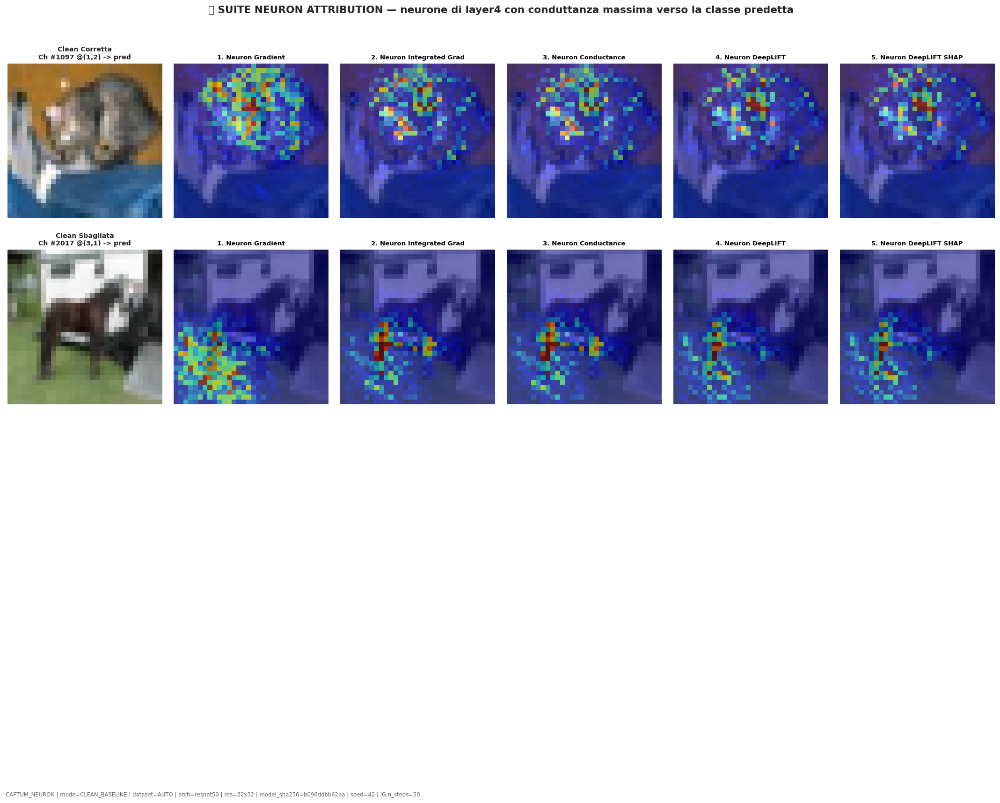

In [29]:
if should_run_section('CAPTUM_SUITE'):
    # ------------------------------------------------------------------------------
    # 6. NEURON ATTRIBUTION: ANALYSIS ON THE SINGLE TROJAN NEURONS/CHANNELS
    # ------------------------------------------------------------------------------
    import os
    import torch
    import torch.nn as nn
    import numpy as np
    import matplotlib.pyplot as plt


    from captum.attr import (
        NeuronGradient,
        NeuronIntegratedGradients,
        NeuronConductance,
        NeuronDeepLift,
        NeuronDeepLiftShap,
        LayerConductance
    )


    # ==============================================================================
    # 1. MODEL AND METADATA VERIFICATION AND RESOLUTION
    # ==============================================================================
    captum_net = get_audit_model()
    _captum_ctx = get_model_eval_context(captum_net, device=device)


    is_pipeline = bool(_captum_ctx["is_pipeline"])
    strategy_name = f"{_captum_ctx['strategy'].upper()} ({_captum_ctx['target_res']}x{_captum_ctx['target_res']})"
    mean_used = np.array(_captum_ctx["mean"])
    std_used = np.array(_captum_ctx["std"])
    classes = CLASS_NAMES if "CLASS_NAMES" in globals() else CIFAR10_CLASSES
    num_classes = len(classes)
    CAPTUM_IG_N_STEPS = int(globals().get("CAPTUM_IG_N_STEPS", 50))


    print("\n" + "=" * 90)
    print(f"🔬 4. NEURON ATTRIBUTION: PROFILING ON THE TOP TROJAN NEURON ({strategy_name})")
    print(f"📦 Backbone: {captum_net.__class__.__name__} | Network Resolution: {'224x224' if is_pipeline else '32x32'}")
    print("=" * 90)


    # 1. Neuron layer: output of layer4, the same used by the previous cell for the
    # conductance (previously here the last Conv2d was used, pre-BN and pre-residual-sum: the "trojan
    # channels" of the two cells were not comparable).
    target_layer = captum_net.layer4 if hasattr(captum_net, "layer4") else list(captum_net.children())[-2]
    CAPTUM_NEURON_LAYER_NAME = "layer4" if hasattr(captum_net, "layer4") else type(target_layer).__name__


    # In-place ReLU sanitization for Captum
    for m in captum_net.modules():
        if isinstance(m, nn.ReLU):
            m.inplace = False


    # 2. Instantiation of the Neuron Attribution Suite
    layer_cond = LayerConductance(captum_net, target_layer)
    neuron_grad = NeuronGradient(captum_net, target_layer)
    neuron_ig = NeuronIntegratedGradients(captum_net, target_layer)
    neuron_cond = NeuronConductance(captum_net, target_layer)

    try:
        neuron_dl = NeuronDeepLift(captum_net, target_layer)
    except Exception:
        neuron_dl = None


    try:
        neuron_dl_shap = NeuronDeepLiftShap(captum_net, target_layer)
    except Exception:
        neuron_dl_shap = None


    neuron_methods_names = [
        "1. Neuron Gradient",
        "2. Neuron Integrated Grad",
        "3. Neuron Conductance",
        "4. Neuron DeepLIFT",
        "5. Neuron DeepLIFT SHAP"
    ]


    def apply_enhanced_overlay(orig_rgb, saliency_2d, alpha=0.55, cmap="jet"):
        """High-contrast overlay (percentile-based) to clearly highlight the trigger."""
        s_abs = np.abs(saliency_2d)
        p_high = np.percentile(s_abs, 99.5) if np.max(s_abs) > 0 else 1.0
        norm_map = np.clip(s_abs / (p_high + 1e-8), 0, 1)
        if norm_map.shape != orig_rgb.shape[:2]:
            import cv2
            norm_map = cv2.resize(norm_map, (orig_rgb.shape[1], orig_rgb.shape[0]), interpolation=cv2.INTER_LINEAR)
        colormap = plt.get_cmap(cmap)
        heat_rgb = colormap(norm_map)[:, :, :3]
        return np.clip((1.0 - alpha) * orig_rgb + alpha * heat_rgb, 0, 1)


    # Helper for Neuron DeepLIFT / DeepLIFT SHAP: the fallback to Neuron IG is declared in the title.
    _c46_fallback_used = {}

    def compute_neuron_dl_safe(inp_img, n_sel):
        try:
            if neuron_dl is not None:
                return neuron_dl.attribute(inp_img, neuron_selector=n_sel)
        except Exception as e_ndl:
            _c46_fallback_used["dl"] = str(e_ndl)[:60]
        _c46_fallback_used.setdefault("dl", "NeuronDeepLift not instantiable")
        return neuron_ig.attribute(inp_img, neuron_selector=n_sel, n_steps=CAPTUM_IG_N_STEPS)


    def compute_neuron_dl_shap_safe(inp_img, n_sel, base):
        try:
            if neuron_dl_shap is not None:
                return neuron_dl_shap.attribute(inp_img, neuron_selector=n_sel, baselines=base)
        except Exception as e_nds:
            _c46_fallback_used["dls"] = str(e_nds)[:60]
        _c46_fallback_used.setdefault("dls", "NeuronDeepLiftShap not instantiable")
        return neuron_ig.attribute(inp_img, neuron_selector=n_sel, n_steps=CAPTUM_IG_N_STEPS)


    fig_neuron, axes_neuron = plt.subplots(4, 6, figsize=(6 * 3.0, 14), dpi=120)


    with preserve_model_state(captum_net):
        for r_idx, (title, data) in enumerate(images_to_analyze.items()):
            if data is None:
                for c in range(6):
                    axes_neuron[r_idx, c].axis("off")
                continue


            input_image, true_label, predicted_label = data
            input_image = input_image.clone().detach().to(device)
            if input_image.dim() == 3:
                input_image = input_image.unsqueeze(0)
            input_image.requires_grad = True


            # Denormalization consistent with the current resolution
            orig_np = input_image.squeeze(0).cpu().detach().permute(1, 2, 0).numpy()
            if orig_np.min() < 0.0 or orig_np.max() > 1.0:
                orig_rgb = orig_np * std_used + mean_used
            else:
                orig_rgb = orig_np
            orig_rgb = np.clip(orig_rgb, 0.0, 1.0)


            # 1. Neuron with maximum conductance toward the PREDICTED class (same path in all the
            # modes, no use of TARGET_LABEL; in the "Poison Attack Success" case predicted = target).
            try:
                attr_cond = layer_cond.attribute(input_image, target=predicted_label, n_steps=CAPTUM_IG_N_STEPS)
            except Exception as e_lc:
                print(f"⚠️ [{title}] LayerConductance not computable: {str(e_lc)[:80]}")
                for c in range(6):
                    axes_neuron[r_idx, c].axis("off")
                continue
            ch_cond = attr_cond.mean(dim=(2, 3)).squeeze(0).cpu().detach().numpy()
            target_neuron_idx = int(np.argmax(np.abs(ch_cond)))


            # Spatial position chosen from the data: feature map cell with maximum |conductance| for
            # that channel (before: fixed center of the map, independent of the position of the evidence).
            _cond_map = attr_cond[0, target_neuron_idx].abs()
            feat_h, feat_w = attr_cond.shape[2], attr_cond.shape[3]
            _flat_pos = int(torch.argmax(_cond_map).item())
            neuron_selector = (target_neuron_idx, _flat_pos // feat_w, _flat_pos % feat_w)


            # 2. Original Image
            axes_neuron[r_idx, 0].imshow(orig_rgb)
            axes_neuron[r_idx, 0].set_title(
                f"{title}\nCh #{target_neuron_idx} @({neuron_selector[1]},{neuron_selector[2]}) -> pred",
                fontsize=8.5,
                fontweight="bold"
            )
            axes_neuron[r_idx, 0].axis("off")


            # 3. Execution of the 5 methods with robust error handling
            multi_baseline = torch.zeros((2, *input_image.shape[1:]), device=device)
            neuron_executors = [
                lambda: neuron_grad.attribute(input_image, neuron_selector=neuron_selector),
                lambda: neuron_ig.attribute(input_image, neuron_selector=neuron_selector, n_steps=CAPTUM_IG_N_STEPS),
                lambda: neuron_cond.attribute(input_image, neuron_selector=neuron_selector, target=predicted_label, n_steps=CAPTUM_IG_N_STEPS),
                lambda: compute_neuron_dl_safe(input_image, neuron_selector),
                lambda: compute_neuron_dl_shap_safe(input_image, neuron_selector, multi_baseline)
            ]


            for m_idx, (m_name, m_func) in enumerate(zip(neuron_methods_names, neuron_executors), start=1):
                try:
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                    _c46_fallback_used.clear()
                    attr_neuron = m_func()
                    if attr_neuron is not None:
                        if attr_neuron.dim() == 4:
                            attr_2d = torch.sum(torch.abs(attr_neuron), dim=1).squeeze().cpu().detach().numpy()
                        elif attr_neuron.dim() == 3:
                            attr_2d = torch.sum(torch.abs(attr_neuron), dim=0).squeeze().cpu().detach().numpy()
                        else:
                            attr_2d = attr_neuron.squeeze().cpu().detach().numpy()
                        overlay = apply_enhanced_overlay(orig_rgb, attr_2d, alpha=0.55, cmap="jet")
                        axes_neuron[r_idx, m_idx].imshow(overlay)
                    else:
                        axes_neuron[r_idx, m_idx].imshow(orig_rgb)
                    axes_neuron[r_idx, m_idx].set_title(m_name + (" [FALLBACK: IG]" if _c46_fallback_used else ""), fontsize=8, fontweight="bold",
                                                        color="darkorange" if _c46_fallback_used else "black")
                    axes_neuron[r_idx, m_idx].axis("off")
                except Exception as e:
                    axes_neuron[r_idx, m_idx].text(0.5, 0.5, f"N/A:\n{str(e)[:22]}", ha="center", va="center", fontsize=7.5)
                    axes_neuron[r_idx, m_idx].axis("off")
                finally:
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()


            for extra_c in range(len(neuron_methods_names) + 1, 6):
                axes_neuron[r_idx, extra_c].axis("off")


    plt.suptitle(f"🔬 NEURON ATTRIBUTION SUITE — neuron of {CAPTUM_NEURON_LAYER_NAME} with maximum conductance toward the predicted class", fontsize=13, fontweight="bold", y=1.01)
    fig_neuron.text(0.01, 0.003, provenance_caption("CAPTUM_NEURON", extra=f"IG n_steps={CAPTUM_IG_N_STEPS}"), fontsize=7, alpha=0.7)
    try:
        out_dir_c45 = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
        os.makedirs(out_dir_c45, exist_ok=True)
        att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
        _xai_fig_strat = str(best_overall_config.get("strategy", "model")).lower() if "best_overall_config" in globals() and best_overall_config else "model"

        neuron_attr_img = f"captum_neuron_attr_{att_type_str}_{_xai_fig_strat}.png"
        neuron_attr_path = os.path.join(out_dir_c45, neuron_attr_img)
        fig_neuron.savefig(neuron_attr_path, bbox_inches='tight', dpi=130)
        register_artifact("CAPTUM_NEURON", neuron_attr_path)
        globals()['CAPTUM_NEURON_IMG_PATH'] = neuron_attr_path
        globals()['captum_neuron_img'] = neuron_attr_img
        if 'RUN_RESULTS' in globals() and isinstance(RUN_RESULTS, dict):
            RUN_RESULTS['captum_neuron_img'] = neuron_attr_img
    except Exception as e_c45:
        print(f"⚠️ [CAPTUM C45 SAVE WARNING]: {e_c45}")


    plt.tight_layout()
    plt.show()


    check_model_integrity("CAPTUM_NEURON")
    clean_memory(verbose=False) if "clean_memory" in globals() else None




### TCAV

In [30]:
if should_run_section('TCAV'):
    clean_memory()
    # ==============================================================================
    # 15. CONCEPT-BASED XAI: TCAV (TESTING WITH CONCEPT ACTIVATION VECTORS)
    # Kim et al., "Interpretability Beyond Feature Attribution: Quantitative Testing with
    # Concept Activation Vectors (TCAV)", ICML 2018, arXiv:1711.11279.
    #   §3.2 CAV = normal to the hyperplane of a linear classifier concept vs random counterexamples
    #   §3.3 S_{C,k,l}(x) = ∇h_{l,k}(f_l(x)) · v_C ;  §3.4 TCAV = |{x∈X_k : S>0}| / |X_k|
    #   §3.5 significance: multiple CAVs (paper: typically 500) against random sets, two-sided t-test
    #        vs random CAVs (H0: TCAV = 0.5), Bonferroni correction.
    # REQUIREMENT: the "trigger" concept is defined by images with trigger -> intrinsically
    # ORACLE method: all values are evaluations with requires_ground_truth=True.
    # ==============================================================================
    import os
    import torch
    import torch.nn as nn
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.svm import LinearSVC
    from sklearn.model_selection import train_test_split
    from scipy import stats as tcav_stats
    from torch.utils.data import DataLoader

    # ==============================================================================
    # INSPECTED MODEL (single resolver of the contract)
    # ==============================================================================
    tcav_net = get_audit_model()
    _tcav_ctx = get_model_eval_context(tcav_net, device=device)
    strategy_name = str(_tcav_ctx["strategy"]).upper()

    # Universal metadata verification print (Grid Search active OR Imported Model)
    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}

    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))

    print("\n" + "=" * 90)
    print(f"🧠 [TCAV FORENSICS] CONCEPT-BASED INTERPRETABILITY: CONCEPT ACTIVATION VECTORS ({strategy_name})")
    print(f"📌 [MODEL CHECK] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 90)

    # Parameters (overridable from globals for quick tests)
    TCAV_N_CONCEPT = int(globals().get("TCAV_N_CONCEPT", 60))                 # concept images (unchanged)
    TCAV_SAMPLES_PER_CLASS = int(globals().get("TCAV_SAMPLES_PER_CLASS", 30))  # X_k per class (unchanged)
    TCAV_N_RUNS = int(globals().get("TCAV_N_RUNS", 10))                       # repeated CAVs (paper: typically 500)
    TCAV_RANDOM_POOL = int(globals().get("TCAV_RANDOM_POOL", 300))            # pool of clean random images
    TCAV_ALPHA = float(globals().get("TCAV_ALPHA", 0.05))
    TCAV_SCORE_THRESHOLD = float(globals().get("TCAV_SCORE_THRESHOLD", 0.70))  # single HEURISTIC threshold (table and plot)
    _tcav_seed = int(globals().get("SEED", 42))
    _tcav_rng = np.random.default_rng(_tcav_seed)
    _TCAV_KEYS = ("tcav_target_score", "tcav_concept_svm_acc", "tcav_dir_deriv_target", "tcav_mean_clean_score",
                  "tcav_target_pvalue", "tcav_target_significant", "tcav_n_significant_classes")

    classes_tcav = CLASS_NAMES if "CLASS_NAMES" in globals() else [f"Class {i}" for i in range(NUM_CLASSES)]
    num_classes_tcav = len(classes_tcav)
    clean_ds = globals().get('clean_test_dataset')
    poison_ds = globals().get('poison_test_dataset') or globals().get('asr_test_dataset')
    target_class_idx = int(TARGET_LABEL) if (oracle_allowed() and "TARGET_LABEL" in globals() and TARGET_LABEL is not None and int(TARGET_LABEL) >= 0) else None

    # Informational requirement of the method: images with trigger (concept) + clean images.
    _tcav_missing = []
    if not oracle_allowed():
        _tcav_missing.append("non-oracle mode (the concept requires the trigger)")
    if clean_ds is None:
        _tcav_missing.append("clean test dataset missing")
    if poison_ds is None or poison_ds is clean_ds:
        _tcav_missing.append("images with trigger missing")
    if target_class_idx is None:
        _tcav_missing.append("target class unknown")

    if _tcav_missing:
        print(f"⏭️ [TCAV] Requirements not met: {_tcav_missing}. Status: not_applicable.")
        for _k in _TCAV_KEYS:
            record_metric(_k, float("nan"), "not_applicable", method="TCAV (Kim et al. 2018)", level="class",
                          requires_ground_truth=True, note="; ".join(_tcav_missing))
    else:
        target_layer = tcav_net.layer4 if hasattr(tcav_net, 'layer4') else list(tcav_net.children())[-2]
        tcav_layer_name = "layer4" if hasattr(tcav_net, 'layer4') else type(target_layer).__name__

        # --------------------------------------------------------------------------
        # 1. IMAGE SETS (indices drawn with local RNG, disjoint sets)
        #    concept: test images with trigger (non-target, original label)
        #    X_k: clean images per class; random pool: other clean images (counterexamples)
        # --------------------------------------------------------------------------
        def _tcav_labels(ds):
            for attr in ("targets", "labels"):
                t = getattr(ds, attr, None)
                if t is not None and len(t) == len(ds):
                    return np.asarray([int(v) for v in t])
            return None

        def _tcav_stack(ds, idxs):
            return torch.stack([ds[int(i)][0] for i in idxs], dim=0) if len(idxs) else None

        _c_perm = _tcav_rng.permutation(len(clean_ds))
        _c_labels = _tcav_labels(clean_ds)
        class_test_idx = {c: [] for c in range(num_classes_tcav)}
        random_pool_idx = []
        for i in _c_perm:
            if _c_labels is not None:
                lbl = int(_c_labels[i])
            else:
                lbl = int(clean_ds[int(i)][1])
            if 0 <= lbl < num_classes_tcav and len(class_test_idx[lbl]) < TCAV_SAMPLES_PER_CLASS:
                class_test_idx[lbl].append(int(i))
            elif len(random_pool_idx) < TCAV_RANDOM_POOL:
                random_pool_idx.append(int(i))
            if len(random_pool_idx) >= TCAV_RANDOM_POOL and all(len(v) >= TCAV_SAMPLES_PER_CLASS for v in class_test_idx.values()):
                break
        _p_idx = _tcav_rng.permutation(len(poison_ds))[:TCAV_N_CONCEPT]

        print(f"⏳ 'trigger' concept: {len(_p_idx)} images | random pool: {len(random_pool_idx)} | "
              f"X_k: {sum(len(v) for v in class_test_idx.values())} images over {num_classes_tcav} classes")

        # --------------------------------------------------------------------------
        # 2. ACTIVATIONS (layer GAP) AND DIRECTIONAL GRADIENTS
        # --------------------------------------------------------------------------
        def _tcav_acts(x_cpu, bs=64):
            if x_cpu is None or len(x_cpu) == 0:
                return np.zeros((0, 0))   # empty set (small dataset): handled as insufficient_data
            store, out = {}, []
            h = target_layer.register_forward_hook(lambda m, i, o: store.__setitem__('a', o.detach()))
            try:
                with torch.no_grad():
                    for s in range(0, x_cpu.shape[0], bs):
                        _ = tcav_net(x_cpu[s:s + bs].to(device))
                        a = store['a']
                        out.append((a.mean(dim=(2, 3)) if a.dim() == 4 else a).cpu().numpy())
            finally:
                h.remove()
            return np.concatenate(out, axis=0)

        def _tcav_grads(x_cpu, c, bs=32):
            # Gradient of the softmax probability of class c with respect to the layer activation
            # (spatial mean). The sign coincides with that of the gradient of -CE used
            # in the reference implementation (tensorflow/tcav); the input requires the gradient
            # so that the graph exists even with frozen parameters.
            store, out = {}, []
            h = target_layer.register_forward_hook(lambda m, i, o: store.__setitem__('a', o))
            try:
                with torch.enable_grad():
                    for s in range(0, x_cpu.shape[0], bs):
                        xb = x_cpu[s:s + bs].to(device).requires_grad_(True)
                        probs = torch.softmax(tcav_net(xb), dim=-1)
                        g = torch.autograd.grad(probs[:, c].sum(), store['a'])[0]
                        out.append((g.mean(dim=(2, 3)) if g.dim() == 4 else g).detach().cpu().numpy())
            finally:
                h.remove()
            return np.concatenate(out, axis=0)

        with preserve_model_state(tcav_net):
            acts_concept = _tcav_acts(_tcav_stack(poison_ds, _p_idx))
            acts_random_pool = _tcav_acts(_tcav_stack(clean_ds, random_pool_idx))
            class_grads = {}
            for c in range(num_classes_tcav):
                if class_test_idx[c]:
                    class_grads[c] = _tcav_grads(_tcav_stack(clean_ds, class_test_idx[c]), c)

        # --------------------------------------------------------------------------
        # 3. REPEATED CAVs: concept vs random and random vs random (§3.5)
        #    Accuracy of the CAV on a test split (1/3, as §4.2.2), not on the training.
        # --------------------------------------------------------------------------
        def _tcav_train_cav(X_pos, X_neg, seed):
            X = np.vstack([X_pos, X_neg])
            y = np.array([1] * len(X_pos) + [0] * len(X_neg))
            X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=1/3, stratify=y, random_state=seed)
            svm = LinearSVC(C=1.0, max_iter=5000, random_state=seed).fit(X_tr, y_tr)
            v = svm.coef_[0]
            n = np.linalg.norm(v)
            return (v / n if n > 0 else None), float(svm.score(X_te, y_te))

        n_set = min(len(acts_concept), len(acts_random_pool) // 2)
        concept_scores = np.full((TCAV_N_RUNS, num_classes_tcav), np.nan)
        random_scores = np.full((TCAV_N_RUNS, num_classes_tcav), np.nan)
        cav_accs, rand_accs = [], []
        directional_derivatives_all = {c: [] for c in range(num_classes_tcav)}
        if n_set < 6:
            print(f"⚠️ [TCAV] Sets too small (n={n_set}) to train CAVs with a test split.")
        else:
            for r in range(TCAV_N_RUNS):
                sel = _tcav_rng.choice(len(acts_random_pool), size=2 * n_set, replace=False)
                rand_a, rand_b = acts_random_pool[sel[:n_set]], acts_random_pool[sel[n_set:]]
                conc = acts_concept[_tcav_rng.choice(len(acts_concept), size=n_set, replace=False)]
                v_c, acc_c = _tcav_train_cav(conc, rand_a, _tcav_seed + r)
                v_r, acc_r = _tcav_train_cav(rand_b, rand_a, _tcav_seed + 1000 + r)
                cav_accs.append(acc_c)
                rand_accs.append(acc_r)
                for c, G in class_grads.items():
                    if v_c is not None:
                        dd = G @ v_c
                        concept_scores[r, c] = float(np.mean(dd > 0))   # §3.4: S > 0 (before: S > 1e-6)
                        if r == 0:
                            directional_derivatives_all[c] = dd.tolist()
                    if v_r is not None:
                        random_scores[r, c] = float(np.mean((G @ v_r) > 0))

        # --------------------------------------------------------------------------
        # 4. PER-CLASS SIGNIFICANCE TEST (two-sided t-test concept vs random)
        #    Bonferroni over all the tested classes (m = K; the paper uses m = 2 for its own hypotheses).
        # --------------------------------------------------------------------------
        tcav_scores = np.nanmean(concept_scores, axis=0) if np.isfinite(concept_scores).any() else np.full(num_classes_tcav, np.nan)
        tcav_scores_std = np.nanstd(concept_scores, axis=0) if np.isfinite(concept_scores).any() else np.full(num_classes_tcav, np.nan)
        random_mean = np.nanmean(random_scores, axis=0) if np.isfinite(random_scores).any() else np.full(num_classes_tcav, np.nan)
        p_values = np.full(num_classes_tcav, np.nan)
        for c in range(num_classes_tcav):
            a, b = concept_scores[:, c], random_scores[:, c]
            a, b = a[np.isfinite(a)], b[np.isfinite(b)]
            if len(a) >= 2 and len(b) >= 2 and (np.std(a) > 0 or np.std(b) > 0):
                p_values[c] = float(tcav_stats.ttest_ind(a, b).pvalue)
        n_tested = int(np.isfinite(p_values).sum())
        p_bonf = np.minimum(p_values * max(n_tested, 1), 1.0)
        significant = np.isfinite(p_bonf) & (p_bonf < TCAV_ALPHA)

        def _tcav_diag(c):
            if not np.isfinite(tcav_scores[c]):
                return "insufficient data"
            sig = "significant (§3.5)" if significant[c] else ("not significant" if np.isfinite(p_values[c]) else "test n/d")
            heur = f" | ≥ heuristic threshold {TCAV_SCORE_THRESHOLD:.2f}" if tcav_scores[c] >= TCAV_SCORE_THRESHOLD else ""
            return sig + heur

        df_tcav = pd.DataFrame({
            'Class ID': list(range(num_classes_tcav)),
            'Class Name': classes_tcav,
            'TCAV Score (Trigger Concept)': tcav_scores,
            'TCAV random CAVs': random_mean,
            'p (Bonferroni)': p_bonf,
            'Mean Directional Derivative': [np.mean(directional_derivatives_all[c]) if len(directional_derivatives_all[c]) > 0 else np.nan for c in range(num_classes_tcav)],
            'Diagnosis (indicator)': [_tcav_diag(c) + (" [target, oracle]" if c == target_class_idx else "") for c in range(num_classes_tcav)],
        })
        svm_acc = float(np.mean(cav_accs) * 100.0) if cav_accs else float("nan")
        svm_acc_rand = float(np.mean(rand_accs) * 100.0) if rand_accs else float("nan")

        # --------------------------------------------------------------------------
        # 5. PRINTING OF THE TABULAR REPORT
        # --------------------------------------------------------------------------
        print("\n" + "=" * 95)
        print(f"📊 [TCAV REPORT] SENSITIVITY TO THE 'TRIGGER' CONCEPT (Layer: {tcav_layer_name}) — EVALUATION (ORACLE)")
        print(f"   CAV: {TCAV_N_RUNS} repetitions | held-out accuracy concept vs random: {svm_acc:.1f}% "
              f"(random vs random: {svm_acc_rand:.1f}%) | α={TCAV_ALPHA} with Bonferroni (m={n_tested})")
        print("=" * 95)
        print(df_tcav.to_string(index=False, formatters={
            'TCAV Score (Trigger Concept)': '{:.2%}'.format,
            'TCAV random CAVs': '{:.2%}'.format,
            'p (Bonferroni)': '{:.3g}'.format,
            'Mean Directional Derivative': '{:+.4e}'.format
        }))
        print("=" * 95)
        print("ℹ️ The concept is defined by poisoned images that a compromised model maps to the target class:")
        print("   the CAV may encode 'target class' as well as 'patch'; the target class score does not isolate the trigger.\n")

        # --------------------------------------------------------------------------
        # 6. 3-PANEL DIAGNOSTIC GRAPHICAL VISUALIZATION
        # --------------------------------------------------------------------------
        plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
        fig_tcav, axs = plt.subplots(1, 3, figsize=(22, 5.5), dpi=150)

        # CHART 1: TCAV per class (mean ± std. dev. over the CAVs) and random reference
        colors_tcav = ['#dc2626' if c == target_class_idx else ('#f59e0b' if significant[c] else '#3b82f6') for c in range(num_classes_tcav)]
        bars = axs[0].bar(classes_tcav, np.nan_to_num(tcav_scores * 100), yerr=np.nan_to_num(tcav_scores_std * 100), color=colors_tcav,
                          edgecolor='black', alpha=0.85, width=0.55, capsize=2)
        axs[0].scatter(range(num_classes_tcav), random_mean * 100, marker='_', s=200, color='black', zorder=3, label='Mean random CAVs')
        axs[0].axhline(50.0, color='gray', linestyle='--', linewidth=1.5, label='H0 = 50% (Kim et al. §3.5)')
        axs[0].axhline(TCAV_SCORE_THRESHOLD * 100, color='#7c3aed', linestyle=':', linewidth=1.8, label=f'Heuristic threshold ({TCAV_SCORE_THRESHOLD:.0%})')
        axs[0].set_title("A) TCAV per Class (% X_k with S_C,k > 0) — orange: significant §3.5, red: target (oracle)", fontsize=10, fontweight='bold', pad=10)
        axs[0].set_ylabel("TCAV Score (%)", fontsize=10, fontweight='bold')
        axs[0].set_ylim(0, 115)
        axs[0].tick_params(axis='x', rotation=90 if num_classes_tcav > 15 else 35, labelsize=8 if num_classes_tcav > 15 else 9)
        axs[0].legend(loc='upper right', frameon=True, fontsize=8)
        axs[0].grid(True, linestyle="--", alpha=0.5)

        for c, bar in enumerate(bars):
            h = bar.get_height()
            axs[0].text(bar.get_x() + bar.get_width()/2.0, h + 2.0, f"{h:.0f}%" + ("*" if significant[c] else ""), ha='center', va='bottom', fontsize=8 if num_classes_tcav > 15 else 8.5, fontweight='bold')

        target_derivs = np.array(directional_derivatives_all.get(target_class_idx, []))
        _others = [directional_derivatives_all[c] for c in range(num_classes_tcav) if c != target_class_idx and len(directional_derivatives_all[c]) > 0]
        all_other_derivs = np.concatenate(_others) if _others else np.array([])

        # CHART 2: Directional derivatives of the target class vs other classes (first CAV)
        if len(target_derivs) and len(all_other_derivs):
            bins_common = np.linspace(min(target_derivs.min(), all_other_derivs.min()), max(target_derivs.max(), all_other_derivs.max()), 25)
            sns.histplot(target_derivs, bins=bins_common, color='#dc2626', label=f"Target (oracle): '{classes_tcav[target_class_idx]}'",
                         stat="density", common_norm=False, kde=len(target_derivs) > 2, alpha=0.55, edgecolor='black', linewidth=0.5, ax=axs[1])
            sns.histplot(all_other_derivs, bins=bins_common, color='#94a3b8', label="Other classes",
                         stat="density", common_norm=False, kde=len(all_other_derivs) > 2, alpha=0.35, edgecolor='black', linewidth=0.5, ax=axs[1])
            axs[1].axvline(0, color='black', linestyle='--', linewidth=1.8, label='S = 0')
            axs[1].legend(loc='upper right', frameon=True, fontsize=8.5)
        else:
            axs[1].text(0.5, 0.5, "Derivatives not available", ha="center", va="center", transform=axs[1].transAxes)
        axs[1].set_title(f"B) Directional derivative S_C,k (CAV #1)\ntarget class vs other classes", fontsize=11, fontweight='bold', pad=10)
        axs[1].set_xlabel("∇_A P(y) · v_CAV", fontsize=10, fontweight='bold')
        axs[1].set_ylabel("Normalized Density", fontsize=10, fontweight='bold')
        axs[1].grid(True, linestyle="--", alpha=0.5)

        # CHART 3 (replaces the "neutral class" chosen a posteriori): distributions of the scores
        # TCAV over the repetitions, concept CAVs vs random CAVs (basis of the §3.5 test).
        _box_data, _box_lbl = [], []
        if target_class_idx is not None:
            _box_data += [concept_scores[:, target_class_idx][np.isfinite(concept_scores[:, target_class_idx])],
                          random_scores[:, target_class_idx][np.isfinite(random_scores[:, target_class_idx])]]
            _box_lbl += ["Target\nconcept", "Target\nrandom"]
        _nt = [c for c in range(num_classes_tcav) if c != target_class_idx]
        _box_data += [np.nanmean(concept_scores[:, _nt], axis=1) if _nt else np.array([]),
                      np.nanmean(random_scores[:, _nt], axis=1) if _nt else np.array([])]
        _box_lbl += ["Other classes\nconcept", "Other classes\nrandom"]
        _box_data = [d[np.isfinite(d)] for d in _box_data]
        if any(len(d) for d in _box_data):
            axs[2].boxplot([d if len(d) else [np.nan] for d in _box_data])
            axs[2].set_xticks(range(1, len(_box_lbl) + 1))
            axs[2].set_xticklabels(_box_lbl, fontsize=8.5)
        axs[2].axhline(0.5, color='gray', linestyle='--', linewidth=1.5)
        _p_t = p_bonf[target_class_idx] if target_class_idx is not None else np.nan
        axs[2].set_title(f"C) TCAV over {TCAV_N_RUNS} CAVs: concept vs random\ntarget p (Bonferroni) = {_p_t:.3g}", fontsize=11, fontweight='bold', pad=10)
        axs[2].set_ylabel("TCAV score", fontsize=10, fontweight='bold')
        axs[2].grid(True, linestyle="--", alpha=0.5)
        fig_tcav.text(0.01, -0.02, provenance_caption("TCAV", extra=f"layer={tcav_layer_name}, runs={TCAV_N_RUNS}"), fontsize=7, alpha=0.7)

        # --- SAVING TCAV METRICS & GRAPHICAL REPORT (ORACLE EVALUATION) ---
        try:
            out_dir_c47 = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
            os.makedirs(out_dir_c47, exist_ok=True)
            att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
            tcav_img = f"captum_tcav_report_{att_type_str}_{str(_tcav_ctx['strategy']).lower()}.png"
            tcav_img_path = os.path.join(out_dir_c47, tcav_img)
            fig_tcav.savefig(tcav_img_path, bbox_inches='tight', dpi=150)
            register_artifact("TCAV", tcav_img_path)
            globals()['CAPTUM_TCAV_IMG_PATH'] = tcav_img_path
            globals()['tcav_report_img'] = tcav_img
            RUN_RESULTS['tcav_report_img'] = tcav_img
        except Exception as e_c47:
            print(f"⚠️ [CAPTUM C47 SAVE WARNING]: {e_c47}")

        _tcav_note = (f"concept = {len(_p_idx)} images with trigger; layer={tcav_layer_name}; {TCAV_N_RUNS} CAVs vs random; "
                      f"sign of ∇softmax (equivalent to -∇CE); concept/target class confounding not removed")
        _ts = tcav_scores[target_class_idx]
        _nt_scores = tcav_scores[_nt] if _nt else np.array([])
        _st = lambda v: "computed" if np.isfinite(v) else "insufficient_data"
        record_metric("tcav_target_score", float(_ts), _st(_ts), method="TCAV §3.4 (mean over the CAVs)", level="class", unit="fraction",
                      requires_ground_truth=True, threshold=TCAV_SCORE_THRESHOLD, threshold_origin="heuristic", note=_tcav_note)
        record_metric("tcav_concept_svm_acc", svm_acc, _st(svm_acc), method="CAV LinearSVC, accuracy on 1/3 test split (before: in-sample)",
                      level="layer", unit="%", requires_ground_truth=True, note=f"random vs random: {svm_acc_rand:.1f}%")
        _dd = float(np.mean(target_derivs)) if len(target_derivs) else float("nan")
        record_metric("tcav_dir_deriv_target", _dd, _st(_dd), method="TCAV §3.3 mean of S_C,k (CAV #1)", level="class",
                      requires_ground_truth=True, note=_tcav_note)
        _mc = float(np.nanmean(_nt_scores)) if np.isfinite(_nt_scores).any() else float("nan")
        record_metric("tcav_mean_clean_score", _mc, _st(_mc), method="mean TCAV of the non-target classes", level="model", unit="fraction",
                      requires_ground_truth=True, note=_tcav_note)
        record_metric("tcav_target_pvalue", float(_p_t), "computed" if np.isfinite(_p_t) else "insufficient_data",
                      method="two-sided t-test concept vs random CAVs, Bonferroni (Kim et al. §3.5)", level="class",
                      requires_ground_truth=True, threshold=TCAV_ALPHA, threshold_origin="paper:Kim et al. 2018 §3.5 (Bonferroni extended to m=K)")
        record_metric("tcav_target_significant", bool(significant[target_class_idx]) if np.isfinite(_p_t) else float("nan"),
                      "computed" if np.isfinite(_p_t) else "insufficient_data", method="§3.5 criterion (paper flag, not verdict)",
                      level="class", requires_ground_truth=True, threshold=TCAV_ALPHA, threshold_origin="paper:Kim et al. 2018 §3.5")
        record_metric("tcav_n_significant_classes", int(significant.sum()) if n_tested else float("nan"), "computed" if n_tested else "insufficient_data",
                      method="classes with significant TCAV (§3.5)", level="model", requires_ground_truth=True)
        record_entities("TCAV", "class", [
            {"entity_id": c, "class_id": c, "class_name": str(classes_tcav[c]), "layer": tcav_layer_name,
             "score": float(tcav_scores[c]) if np.isfinite(tcav_scores[c]) else None,
             "flag": bool(significant[c]), "requires_ground_truth": True,
             "note": f"p_bonf={p_bonf[c]:.3g}; random={random_mean[c]:.3f}; target={c == target_class_idx}"}
            for c in range(num_classes_tcav)
        ])
        for _k in ("tcav_target_score", "tcav_concept_svm_acc", "tcav_dir_deriv_target", "tcav_mean_clean_score"):
            globals()[_k] = RUN_RESULTS[_k]

        plt.tight_layout()
        plt.show()

    check_model_integrity("TCAV")
    clean_memory(verbose=True)


⏭️ [SKIP] Section 'TCAV' not included in the active mode (CLEAN_BASELINE).


### Captum.Robust

In [31]:
if should_run_section('CAPTUM_ROBUST'):
    clean_memory()
    # ==============================================================================
    # 16. ADVERSARIAL ROBUSTNESS & ANALYSIS OF "SINK" CLASSES (`captum.robust`)
    # FGSM (Goodfellow et al., ICLR 2015) and PGD L-inf (Madry et al., ICLR 2018) via Captum.
    # ε is defined in PIXEL SPACE [0,1] (L-inf): the attacks operate on a wrapper that
    # normalizes internally and are constrained to [0,1]. Previously ε was applied in the
    # normalized space without clamp (ε_pixel ≈ ε·std, images outside the valid range).
    # The attraction toward the target class is an oracle EVALUATION; the blind indicator is the
    # class with the maximum share increase among the adversarial predictions (exploratory).
    # ==============================================================================
    import os
    import torch
    import torch.nn as nn
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from torch.utils.data import DataLoader
    from captum.robust import FGSM, PGD
    from captum.attr import IntegratedGradients

    print("\n" + "=" * 95)
    print("🛡️ [CAPTUM.ROBUST] STRUCTURAL ROBUSTNESS EVALUATION AND ADVERSARIAL ATTRACTION CLASSES")
    print("=" * 95)

    # ==============================================================================
    # INSPECTED MODEL (single resolver of the contract)
    # ==============================================================================
    robust_net = get_audit_model()
    _robust_ctx = get_model_eval_context(robust_net, device=device)
    strategy_name = str(_robust_ctx["strategy"]).upper()

    # Universal metadata verification print
    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}

    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))

    print(f"🛡️ [CAPTUM.ROBUST] STRUCTURAL ROBUSTNESS EVALUATION ({strategy_name})")
    print(f"📌 [MODEL CHECK] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 95)

    # Parameters (ε in pixel space [0,1], L-inf)
    epsilons = [float(e) for e in globals().get("ROBUST_EPSILONS", [0.0, 0.01, 0.02, 0.04, 0.06, 0.08])]
    ROBUST_CRITICAL_EPS = float(globals().get("ROBUST_CRITICAL_EPS", 0.04))
    ROBUST_N_SAMPLES = int(globals().get("ROBUST_N_SAMPLES", 120))
    ROBUST_PGD_STEPS = int(globals().get("ROBUST_PGD_STEPS", 7))
    ROBUST_HIJACK_THRESHOLD = float(globals().get("ROBUST_HIJACK_THRESHOLD", 25.0))  # % — HEURISTIC threshold, no source
    crit_eps = ROBUST_CRITICAL_EPS if ROBUST_CRITICAL_EPS in epsilons else max(epsilons)

    classes = CLASS_NAMES if "CLASS_NAMES" in globals() else [f"Class {i}" for i in range(NUM_CLASSES)]
    num_classes = len(classes)
    # Target class only for the oracle evaluation (never default 0 outside the attacker modes)
    target_label = int(TARGET_LABEL) if (oracle_allowed() and "TARGET_LABEL" in globals() and TARGET_LABEL is not None and int(TARGET_LABEL) >= 0) else None

    class _RobustPixelWrapper(nn.Module):
        """Receives images in [0,1], normalizes and forwards to the inspected model (weights unchanged)."""
        def __init__(self, net, mean, std, dev):
            super().__init__()
            self.net = net
            self.register_buffer("mean_t", torch.tensor(np.asarray(mean), dtype=torch.float32, device=dev).view(1, -1, 1, 1))
            self.register_buffer("std_t", torch.tensor(np.asarray(std), dtype=torch.float32, device=dev).view(1, -1, 1, 1))

        def forward(self, x):
            return self.net((x - self.mean_t) / self.std_t)

    pix_model = _RobustPixelWrapper(robust_net, _robust_ctx["mean"], _robust_ctx["std"], device)

    # Loading of the clean test batch (explicit clean dataset)
    clean_ds = globals().get('clean_test_dataset') or (clean_test_loader.dataset if 'clean_test_loader' in globals() and clean_test_loader is not None else None)
    test_imgs_list, test_lbls_list = [], []
    if clean_ds is not None:
        c_loader = DataLoader(clean_ds, batch_size=64, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
        for imgs, lbls in c_loader:
            test_imgs_list.append(imgs)
            test_lbls_list.append(torch.as_tensor(lbls))
            if sum(x.size(0) for x in test_imgs_list) >= ROBUST_N_SAMPLES:
                break

    _ROBUST_KEYS = ("robust_pgd_acc_critical", "robust_xai_fidelity_drop", "robust_pgd_sink_class_id",
                    "robust_pgd_sink_share_delta", "robust_target_hijack_rate_max")
    if not test_imgs_list:
        print("⚠️ Clean test dataset not available: robustness analysis cannot be run.")
        for _k in _ROBUST_KEYS:
            record_metric(_k, float("nan"), "not_applicable", method="captum.robust", requires_ground_truth=(_k == "robust_target_hijack_rate_max"),
                          note="clean dataset missing")
    else:
        _mean_t = torch.tensor(np.asarray(_robust_ctx["mean"]), dtype=torch.float32).view(1, -1, 1, 1)
        _std_t = torch.tensor(np.asarray(_robust_ctx["std"]), dtype=torch.float32).view(1, -1, 1, 1)
        eval_imgs = torch.clamp(torch.cat(test_imgs_list, dim=0)[:ROBUST_N_SAMPLES] * _std_t + _mean_t, 0.0, 1.0).to(device)
        eval_lbls = torch.cat(test_lbls_list, dim=0)[:ROBUST_N_SAMPLES].long().to(device)

        # --------------------------------------------------------------------------
        # 1. SETUP OF THE CAPTUM ADVERSARIAL ATTACKS (constrained to [0,1])
        # --------------------------------------------------------------------------
        loss_func = nn.CrossEntropyLoss(reduction='none')
        fgsm_attack = FGSM(pix_model, loss_func, lower_bound=0.0, upper_bound=1.0)
        pgd_attack = PGD(pix_model, loss_func, lower_bound=0.0, upper_bound=1.0)
        ig_explainer = IntegratedGradients(pix_model)

        # --------------------------------------------------------------------------
        # 2. MULTI-EPSILON SCAN: ACCURACY, XAI STABILITY AND PREDICTION DISTRIBUTION
        # --------------------------------------------------------------------------
        acc_fgsm_curve, acc_pgd_curve, xai_corr_pgd = [], [], []
        class_share_by_eps = {}
        target_hijack_rates = []

        print(f"⏳ Scanning the model's robustness on {len(eval_imgs)} samples with ε (pixel, L-inf) ∈ {epsilons}...")

        img_h, img_w = eval_imgs.shape[-2:]
        is_heavy_model = sum(p.numel() for p in robust_net.parameters()) > 15e6
        robust_batch_sz = 8 if max(img_h, img_w) > 64 else (20 if is_heavy_model else 60)

        with preserve_model_state(robust_net):
            # Unperturbed baseline explanation (single sample: anecdotal indicator)
            single_img = eval_imgs[0:1].clone().detach()
            single_lbl = eval_lbls[0:1]
            base_explanation = ig_explainer.attribute(single_img, target=single_lbl.item()).detach()
            preds_pgd_critical = None

            for eps in epsilons:
                if eps == 0.0:
                    with torch.no_grad():
                        preds_clean = pix_model(eval_imgs).argmax(dim=1)
                    acc = (preds_clean == eval_lbls).float().mean().item() * 100.0
                    acc_fgsm_curve.append(acc)
                    acc_pgd_curve.append(acc)
                    xai_corr_pgd.append(1.0)
                    class_share_by_eps[eps] = np.bincount(preds_clean.cpu().numpy(), minlength=num_classes) / len(preds_clean) * 100.0
                    continue

                # A. FGSM a micro-batch
                preds_fgsm_list = []
                for b_idx in range(0, len(eval_imgs), robust_batch_sz):
                    b_adv_fgsm = fgsm_attack.perturb(eval_imgs[b_idx:b_idx + robust_batch_sz], epsilon=eps, target=eval_lbls[b_idx:b_idx + robust_batch_sz])
                    with torch.no_grad():
                        preds_fgsm_list.append(pix_model(b_adv_fgsm).argmax(dim=1))
                preds_fgsm = torch.cat(preds_fgsm_list)
                acc_fgsm_curve.append((preds_fgsm == eval_lbls).float().mean().item() * 100.0)

                # B. PGD a micro-batch
                preds_pgd_list = []
                for b_idx in range(0, len(eval_imgs), robust_batch_sz):
                    b_adv_pgd = pgd_attack.perturb(eval_imgs[b_idx:b_idx + robust_batch_sz], radius=eps, step_size=eps / 4.0,
                                                   step_num=ROBUST_PGD_STEPS, target=eval_lbls[b_idx:b_idx + robust_batch_sz])
                    with torch.no_grad():
                        preds_pgd_list.append(pix_model(b_adv_pgd).argmax(dim=1))
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                preds_pgd = torch.cat(preds_pgd_list)
                acc_pgd_curve.append((preds_pgd == eval_lbls).float().mean().item() * 100.0)
                class_share_by_eps[eps] = np.bincount(preds_pgd.cpu().numpy(), minlength=num_classes) / len(preds_pgd) * 100.0
                if eps == crit_eps:
                    preds_pgd_critical = preds_pgd.cpu().numpy()

                # C. Stability of the IG explanation (raw Pearson correlation, also negative)
                adv_single = pgd_attack.perturb(single_img, radius=eps, step_size=eps / 4.0, step_num=ROBUST_PGD_STEPS, target=single_lbl)
                adv_explanation = ig_explainer.attribute(adv_single, target=single_lbl.item()).detach()
                v_orig = base_explanation.flatten().cpu().numpy()
                v_adv = adv_explanation.flatten().cpu().numpy()
                corr = np.corrcoef(v_orig, v_adv)[0, 1] if (np.std(v_orig) > 0 and np.std(v_adv) > 0) else np.nan
                xai_corr_pgd.append(float(corr))

            # Visual demo at the critical radius
            adv_demo = pgd_attack.perturb(single_img, radius=crit_eps, step_size=crit_eps / 4.0, step_num=ROBUST_PGD_STEPS, target=single_lbl)
            adv_attr_demo = ig_explainer.attribute(adv_demo, target=single_lbl.item()).detach()
            with torch.no_grad():
                pred_clean_demo = pix_model(single_img).argmax(dim=1).item()
                pred_adv_demo = pix_model(adv_demo).argmax(dim=1).item()

        # Blind indicator: share increase of each class among the PGD predictions (critical ε) with respect to clean
        share_clean = class_share_by_eps[0.0] if 0.0 in class_share_by_eps else np.full(num_classes, np.nan)
        share_crit = class_share_by_eps.get(crit_eps, np.full(num_classes, np.nan))
        share_delta = share_crit - share_clean
        sink_z, sink_info = robust_mad_z(share_delta)
        # No class gains share -> indicator undefined (previously class 0 would have been reported)
        sink_class = int(np.nanargmax(share_delta)) if (np.isfinite(share_delta).any() and np.nanmax(share_delta) > 0) else None

        # Oracle evaluation: share of predictions toward the target class for each ε
        if target_label is not None:
            target_hijack_rates = [float(class_share_by_eps[e][target_label]) for e in epsilons]

        # --------------------------------------------------------------------------
        # 3. ROBUSTNESS TABULAR REPORT
        # --------------------------------------------------------------------------
        _rob_tab = {
            'Perturbation (ε pixel)': [f"ε = {e:.3f} (≈{e*255:.0f}/255)" for e in epsilons],
            'FGSM Accuracy': [f"{a:.1f}%" for a in acc_fgsm_curve],
            'PGD Accuracy': [f"{a:.1f}%" for a in acc_pgd_curve],
            'Corr. IG (Pearson)': [f"{s:+.2f}" if np.isfinite(s) else "n/a" for s in xai_corr_pgd],
            'Class with max share': [f"{classes[int(np.argmax(class_share_by_eps[e]))]} ({np.max(class_share_by_eps[e]):.1f}%)" for e in epsilons],
        }
        if target_label is not None:
            _rob_tab[f"Share '{classes[target_label]}' (oracle)"] = [f"{t:.1f}%" for t in target_hijack_rates]
            _rob_tab['Indicator (heuristic)'] = ['baseline' if e == 0 else (f'⚠️ > {ROBUST_HIJACK_THRESHOLD:.0f}% (heuristic)' if t > ROBUST_HIJACK_THRESHOLD else '—')
                                                 for e, t in zip(epsilons, target_hijack_rates)]
        df_robustness = pd.DataFrame(_rob_tab)

        print("\n" + "=" * 95)
        print("📊 [CAPTUM.ROBUST REPORT] ADVERSARIAL ROBUSTNESS PROFILE (ε in pixel space, untargeted attack)")
        print("=" * 95)
        print(df_robustness.to_string(index=False))
        print("=" * 95)
        if sink_class is not None:
            print(f"\n🔎 [EXPLORATORY INDICATOR] At radius ε={crit_eps:.3f} the class with the maximum share increase among the "
                  f"PGD predictions is '{classes[sink_class]}' (+{share_delta[sink_class]:.1f} pp, robust z={sink_z[sink_class]:.2f} [{sink_info['status']}]).")
            print("   A 'sink' class may derive from a backdoor but also from the natural geometry of the boundaries: candidate for manual inspection.")
        if target_label is not None:
            max_hijack_idx = int(np.argmax(target_hijack_rates))
            max_hijack_val = float(target_hijack_rates[max_hijack_idx])
            print(f"🧪 [ORACLE EVALUATION] Maximum share of PGD predictions toward the target '{classes[target_label]}': {max_hijack_val:.1f}% "
                  f"(heuristic threshold {ROBUST_HIJACK_THRESHOLD:.0f}%: {'exceeded' if max_hijack_val > ROBUST_HIJACK_THRESHOLD else 'not exceeded'}).\n")

        # --------------------------------------------------------------------------
        # 4. 4-PANEL GRAPHICAL VISUALIZATION
        # --------------------------------------------------------------------------
        plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
        fig_robust, axs = plt.subplots(2, 2, figsize=(20, 11), dpi=150)

        # PANEL 1: Accuracy vs Perturbation Radius
        axs[0, 0].plot(epsilons, acc_fgsm_curve, marker='o', linewidth=2.2, color='#f59e0b', label='FGSM (1 step)')
        axs[0, 0].plot(epsilons, acc_pgd_curve, marker='s', linewidth=2.5, color='#dc2626', label=f'PGD ({ROBUST_PGD_STEPS} steps)')
        axs[0, 0].set_title("A) Accuracy under Adversarial Attack (untargeted)", fontsize=11.5, fontweight='bold', pad=10)
        axs[0, 0].set_xlabel("ε (L-inf, pixel space [0,1])", fontsize=10.5, fontweight='bold')
        axs[0, 0].set_ylabel("Classification Accuracy (%)", fontsize=10.5, fontweight='bold')
        axs[0, 0].set_ylim(-5, 105)
        axs[0, 0].legend(loc='upper right', frameon=True, fontsize=9)
        axs[0, 0].grid(True, linestyle="--", alpha=0.5)

        # PANEL 2: Stability of the IG explanation (single sample; no threshold without a source)
        axs[0, 1].plot(epsilons, xai_corr_pgd, marker='^', linewidth=2.5, color='#8b5cf6', label='Pearson Corr. IG clean vs adversarial')
        axs[0, 1].axhline(0.0, color='gray', linestyle=':', linewidth=1.0)
        axs[0, 1].set_title("B) Stability of the IG explanation under PGD (1 sample)", fontsize=11.5, fontweight='bold', pad=10)
        axs[0, 1].set_xlabel("ε (L-inf, pixel space [0,1])", fontsize=10.5, fontweight='bold')
        axs[0, 1].set_ylabel("Pearson Correlation", fontsize=10.5, fontweight='bold')
        axs[0, 1].set_ylim(-1.05, 1.05)
        axs[0, 1].legend(loc='upper right', frameon=True, fontsize=9)
        axs[0, 1].grid(True, linestyle="--", alpha=0.5)

        # PANEL 3: Distribution of adversarial predictions at the critical radius
        if preds_pgd_critical is not None:
            pct_crit = share_crit
            if target_label is not None:
                colors_dist = ['#dc2626' if c == target_label else '#3b82f6' for c in range(num_classes)]
                _sub = f"[red: target class — oracle evaluation]"
            else:
                colors_dist = ['#f59e0b' if c == sink_class else '#3b82f6' for c in range(num_classes)]
                _sub = "[orange: maximum share increase — exploratory indicator]"
            bars = axs[1, 0].bar(classes, pct_crit, color=colors_dist, edgecolor='black', alpha=0.85, width=0.55)
            axs[1, 0].scatter(range(num_classes), share_clean, marker='_', s=200, color='black', zorder=3, label='Clean prediction share (ε=0)')
            axs[1, 0].set_title(f"C) Prediction Distribution under PGD (ε={crit_eps:.3f})\n{_sub}", fontsize=11.5, fontweight='bold', pad=10)
            axs[1, 0].set_ylabel("% Predictions under Attack", fontsize=10.5, fontweight='bold')
            axs[1, 0].set_ylim(0, max(np.nanmax(pct_crit) * 1.25, 30))
            axs[1, 0].tick_params(axis='x', rotation=90 if num_classes > 15 else 35, labelsize=8 if num_classes > 15 else 9)
            axs[1, 0].legend(loc='upper right', frameon=True, fontsize=9)
            axs[1, 0].grid(True, linestyle="--", alpha=0.5)
            for bar in bars:
                h = bar.get_height()
                if h > 2.0:
                    axs[1, 0].text(bar.get_x() + bar.get_width()/2.0, h + 1.0, f"{h:.1f}%", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

        # PANEL 4: Original vs adversarial (pixel space) with IG heatmap
        orig_rgb_demo = single_img.squeeze(0).cpu().numpy().transpose(1, 2, 0)
        adv_rgb_demo = adv_demo.squeeze(0).cpu().numpy().transpose(1, 2, 0)
        attr_clean_2d = torch.sum(torch.abs(base_explanation), dim=1).squeeze().cpu().numpy()
        attr_adv_2d = torch.sum(torch.abs(adv_attr_demo), dim=1).squeeze().cpu().numpy()
        overlay_clean = apply_standard_overlay(orig_rgb_demo, attr_clean_2d, alpha=0.5, cmap='jet')
        overlay_adv = apply_standard_overlay(adv_rgb_demo, attr_adv_2d, alpha=0.5, cmap='jet')
        side_by_side = np.hstack([overlay_clean, np.ones((overlay_clean.shape[0], 2, 3)), overlay_adv])
        axs[1, 1].imshow(side_by_side)
        axs[1, 1].set_title(f"D) PGD (ε={crit_eps:.3f}): Clean ({classes[pred_clean_demo]}) vs Adversarial ({classes[pred_adv_demo]})", fontsize=11.5, fontweight='bold', pad=10)
        axs[1, 1].axis('off')
        fig_robust.text(0.01, 0.003, provenance_caption("CAPTUM_ROBUST", extra=f"ε pixel L-inf, n={len(eval_imgs)}"), fontsize=7, alpha=0.7)

        # --- SAVING ROBUSTNESS METRICS & GRAPHICAL PROFILE ---
        try:
            out_dir_c49 = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
            os.makedirs(out_dir_c49, exist_ok=True)
            att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "blind"
            robust_img = f"captum_robust_profile_{att_type_str}_{str(_robust_ctx['strategy']).lower()}.png"
            robust_img_path = os.path.join(out_dir_c49, robust_img)
            fig_robust.savefig(robust_img_path, bbox_inches='tight', dpi=150)
            register_artifact("CAPTUM_ROBUST", robust_img_path)
            globals()['CAPTUM_ROBUST_IMG_PATH'] = robust_img_path
            globals()['captum_robust_img'] = robust_img
            RUN_RESULTS['captum_robust_img'] = robust_img
        except Exception as e_c49:
            print(f"⚠️ [CAPTUM C49 SAVE WARNING]: {e_c49}")

        crit_idx = epsilons.index(crit_eps)
        _eps_note = f"ε={crit_eps:.3f} L-inf in pixel space [0,1], PGD {ROBUST_PGD_STEPS} steps (step ε/4), n={len(eval_imgs)}"
        record_metric("robust_pgd_acc_critical", float(acc_pgd_curve[crit_idx]), method="PGD (Madry et al. 2018) via captum.robust",
                      level="model", unit="%", note=_eps_note + " | before: ε in normalized space")
        _corr_c = xai_corr_pgd[crit_idx]
        record_metric("robust_xai_fidelity_drop", float(100.0 * (1.0 - _corr_c)) if np.isfinite(_corr_c) else float("nan"),
                      "computed" if np.isfinite(_corr_c) else "degenerate", method="100·(1 − ρ_Pearson) between clean/adversarial IG maps",
                      level="sample", unit="%", note=_eps_note + " | single sample; ρ no longer clipped to 0")
        record_metric("robust_pgd_sink_class_id", sink_class if sink_class is not None else float("nan"),
                      "computed" if sink_class is not None else "degenerate", method="class with maximum share increase among PGD predictions",
                      level="class", note="exploratory indicator, no threshold")
        record_metric("robust_pgd_sink_share_delta", float(share_delta[sink_class]) if sink_class is not None else float("nan"),
                      "computed" if sink_class is not None else "degenerate", method="share increase (percentage points) vs clean predictions",
                      level="class", unit="pp", note=_eps_note)
        if target_label is not None:
            record_metric("robust_target_hijack_rate_max", float(max(target_hijack_rates)), method="max share of PGD predictions toward the target",
                          level="class", unit="%", requires_ground_truth=True, threshold=ROBUST_HIJACK_THRESHOLD, threshold_origin="heuristic",
                          note=_eps_note)
        else:
            record_metric("robust_target_hijack_rate_max", float("nan"), "not_applicable", method="max share of PGD predictions toward the target",
                          level="class", unit="%", requires_ground_truth=True, note="target class not available")
        record_entities("CAPTUM_ROBUST", "class", [
            {"entity_id": c, "class_id": c, "class_name": str(classes[c]), "score": float(share_delta[c]),
             "rank": int(np.argsort(-np.nan_to_num(share_delta, nan=-np.inf)).tolist().index(c)) + 1,
             "note": f"PGD share={share_crit[c]:.1f}% | clean share={share_clean[c]:.1f}% | z={sink_z[c]:.2f}"}
            for c in range(num_classes)
        ])
        for _k in ("robust_target_hijack_rate_max", "robust_pgd_acc_critical", "robust_xai_fidelity_drop"):
            globals()[_k] = RUN_RESULTS[_k]

        plt.tight_layout()
        plt.show()

    check_model_integrity("CAPTUM_ROBUST")
    clean_memory(verbose=True)


⏭️ [SKIP] Section 'CAPTUM_ROBUST' not included in the active mode (CLEAN_BASELINE).


### Captum.influence

In [32]:
if should_run_section('TRACIN'):
    clean_memory()
    # ==============================================================================
    # 17. TRAINING DATA INFLUENCE — SINGLE-CHECKPOINT TRACIN APPROXIMATION (LAST LAYER ONLY)
    # Reference: Pruthi et al., "Estimating Training Data Influence by Tracing Gradient Descent",
    # NeurIPS 2020 (arXiv:2002.08484), §3.3 eq. TracInCP = Σ_i η_i ∇ℓ(w_ti, z)·∇ℓ(w_ti, z'); the paper
    # also uses only the last layer in some experiments (§4.2, §5.3).
    # Declared deviations: (1) a single checkpoint (the final model), η omitted; (2) gradients of the
    # weight only of the final linear layer, computed in closed form (p − e_y) ⊗ h; (3) score
    # normalized to cosine (renormalization in the spirit of Hammoudeh & Lowd, arXiv:2201.10055),
    # reported together with the raw dot product. It is NOT the complete TracInCP.
    # The pool is a random subset of the EFFECTIVE TRAINING SET; the query is a TEST image
    # with trigger (disjoint from the pool). The precision metrics use the poisoning flags:
    # they are oracle evaluations (requires_ground_truth=True). No data removal is performed.
    # ==============================================================================
    import os
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from torch.utils.data import DataLoader, Subset, ConcatDataset

    print("\n" + "=" * 95)
    print("🔍 [INFLUENCE] FORENSIC DATA ATTRIBUTION: TRACIN APPROXIMATION (1 checkpoint, last layer)")
    print("=" * 95)

    # ==============================================================================
    # INSPECTED MODEL (single resolver of the contract)
    # ==============================================================================
    tracin_net = get_audit_model()
    _tracin_ctx = get_model_eval_context(tracin_net, device=device)
    strategy_name = str(_tracin_ctx["strategy"]).upper()

    # Universal metadata verification print
    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}

    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))

    print(f"🔍 [INFLUENCE] ({strategy_name})")
    print(f"📌 [MODEL CHECK] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 95)

    TRACIN_POOL_SIZE = int(globals().get("TRACIN_POOL_SIZE", 1000))
    TRACIN_TOPK = int(globals().get("TRACIN_TOPK", 20))
    TRACIN_METHOD_NAME = "Approximated TracIn: 1 checkpoint, last layer only, cosine (Pruthi et al. 2020; not TracInCP)"
    _TRACIN_KEYS = ("tracin_top5_poison_count", "tracin_cleansing_precision", "tracin_poison_mean_influence",
                    "tracin_clean_mean_influence", "tracin_pool_poison_rate")
    classes = CLASS_NAMES if "CLASS_NAMES" in globals() else [f"Class {i}" for i in range(NUM_CLASSES)]
    mean_arr = np.array(_tracin_ctx["mean"])
    std_arr = np.array(_tracin_ctx["std"])
    fc_layer, _fc_name, _ = get_classifier_info(tracin_net)

    # --------------------------------------------------------------------------
    # 1. REQUIREMENTS: effective training set with known structure + poisoned query (oracle)
    # --------------------------------------------------------------------------
    _tracin_missing = []
    train_ds = globals().get("current_train_dataset")
    poison_part_start = None
    if not oracle_allowed():
        _tracin_missing.append("non-oracle mode (poisoning flags and query with trigger not available)")
    if train_ds is None:
        _tracin_missing.append("effective training set not available (e.g. imported model)")
    elif not (isinstance(train_ds, ConcatDataset) and type(train_ds.datasets[-1]).__name__ == "LazyPoisonedDataset"):
        _tracin_missing.append("training set structure not recognized (poisoned part not identifiable)")
    else:
        if str(getattr(train_ds.datasets[-1], "strategy", "")) != str(_tracin_ctx["strategy"]):
            _tracin_missing.append(f"training set of strategy '{getattr(train_ds.datasets[-1], 'strategy', '?')}' ≠ model '{_tracin_ctx['strategy']}'")
        _cfg_last, _cfg_best = globals().get("config"), globals().get("best_overall_config")
        if isinstance(_cfg_last, dict) and isinstance(_cfg_best, dict) and any(
                _cfg_last.get(k) != _cfg_best.get(k) for k in ("strategy", "poisoning_ratio") if k in _cfg_best):
            _tracin_missing.append("current_train_dataset belongs to the last configuration of the grid search, not to the best one")
        poison_part_start = int(train_ds.cumulative_sizes[-2]) if len(train_ds.datasets) > 1 else 0

    query_img = None
    if not _tracin_missing:
        if "images_to_analyze" in globals() and images_to_analyze.get("Poison Attack Success") is not None:
            query_img = images_to_analyze["Poison Attack Success"][0].clone().to(device)
        elif globals().get("poison_test_dataset") is not None:
            query_img = poison_test_dataset[0][0].unsqueeze(0).to(device)
        if query_img is None:
            _tracin_missing.append("no test image with trigger for the query")

    if _tracin_missing:
        print(f"⏭️ [TRACIN] Requirements not met: {_tracin_missing}. Status: not_applicable.")
        for _k in _TRACIN_KEYS:
            record_metric(_k, float("nan"), "not_applicable", method=TRACIN_METHOD_NAME, level="sample",
                          requires_ground_truth=True, note="; ".join(_tracin_missing))
    else:
        # --------------------------------------------------------------------------
        # 2. POOL: random subset (local RNG) of the training set, flags used ONLY to evaluate
        # --------------------------------------------------------------------------
        _tr_rng = np.random.default_rng(int(globals().get("SEED", 42)))
        pool_indices = np.sort(_tr_rng.choice(len(train_ds), size=min(TRACIN_POOL_SIZE, len(train_ds)), replace=False))
        pool_flags = (pool_indices >= poison_part_start).astype(int)   # 1 = poisoned (oracle)

        # Last layer gradient in closed form: ∂CE/∂W = (softmax(z) − e_y) ⊗ h
        _fc_in = {}
        _fc_hook = fc_layer.register_forward_hook(lambda m, i, o: _fc_in.__setitem__("h", i[0].detach()))

        def _tracin_factors(x, y):
            with torch.no_grad():
                logits = tracin_net(x)
                delta = torch.softmax(logits, dim=1) - F.one_hot(y, num_classes=logits.shape[1]).float()
            return delta.cpu(), _fc_in["h"].flatten(1).cpu()

        pool_imgs_list, pool_lbls_list, d_list, h_list = [], [], [], []
        try:
            with preserve_model_state(tracin_net):
                with torch.no_grad():
                    query_pred = int(tracin_net(query_img).argmax(dim=1).item())
                d_q, h_q = _tracin_factors(query_img, torch.tensor([query_pred], device=device))
                # The training transformations (augmentation) consume the global RNG: it is isolated.
                with torch.random.fork_rng(devices=[]):
                    torch.manual_seed(int(globals().get("SEED", 42)))
                    pool_loader = DataLoader(Subset(train_ds, pool_indices.tolist()), batch_size=64, shuffle=False, num_workers=0)
                    for imgs, lbls in pool_loader:
                        lbls = torch.as_tensor(lbls).long()
                        d_b, h_b = _tracin_factors(imgs.to(device), lbls.to(device))
                        d_list.append(d_b)
                        h_list.append(h_b)
                        pool_imgs_list.append(imgs)
                        pool_lbls_list.append(lbls)
        finally:
            _fc_hook.remove()

        D = torch.cat(d_list)
        Hf = torch.cat(h_list)
        pool_imgs = torch.cat(pool_imgs_list)
        pool_lbls = torch.cat(pool_lbls_list).numpy()

        # Exclusion of any exact duplicates of the query (training pool ≠ test by construction)
        if tuple(pool_imgs.shape[1:]) == tuple(query_img.shape[1:]):
            _dup = (pool_imgs.flatten(1) - query_img.cpu().flatten(1)).abs().amax(dim=1) < 1e-6
        else:
            _dup = torch.zeros(len(pool_imgs), dtype=torch.bool)
        if bool(_dup.any()):
            print(f"⚠️ {int(_dup.sum())} pool samples identical to the query: excluded.")

        # <g_q, g_i> = (δ_q·δ_i)(h_q·h_i);  ||g|| = ||δ||·||h||
        dot_raw = (D @ d_q[0]) * (Hf @ h_q[0])
        norms = D.norm(dim=1) * Hf.norm(dim=1) * (d_q[0].norm() * h_q[0].norm())
        influence_scores = torch.where(norms > 0, dot_raw / norms, torch.full_like(dot_raw, float("nan"))).numpy()
        influence_scores[_dup.numpy()] = np.nan
        dot_raw = dot_raw.numpy()

        num_poison_loaded = int(pool_flags.sum())
        num_clean_loaded = int(len(pool_flags) - num_poison_loaded)
        print(f"✅ Training pool: {len(pool_flags)} random samples ({num_poison_loaded} poisoned [oracle], {num_clean_loaded} clean) | "
              f"query: test image with trigger, predicted '{classes[query_pred]}'")

        # --------------------------------------------------------------------------
        # 3. REPORT: MOST INFLUENTIAL TRAINING SAMPLES (manual inspection, no removal)
        # --------------------------------------------------------------------------
        df_influence = pd.DataFrame({
            'Train_Idx': pool_indices,
            'Pool_Pos': np.arange(len(pool_indices)),
            'Influence_Score': influence_scores,
            'Dot_Raw': dot_raw,
            'Is_Poisoned': pool_flags,
            'Label': pool_lbls,
        }).dropna(subset=['Influence_Score']).sort_values(by='Influence_Score', ascending=False)

        top_k_influential = df_influence.head(TRACIN_TOPK)
        detected_poison_in_topk = int(top_k_influential['Is_Poisoned'].sum())
        n_topk = max(len(top_k_influential), 1)
        cleansing_precision = (detected_poison_in_topk / n_topk) * 100.0
        pool_poison_rate = 100.0 * num_poison_loaded / max(len(pool_flags), 1)

        print("\n" + "=" * 95)
        print(f"📊 [REPORT] TOP 10 TRAINING SAMPLES BY INFLUENCE (cosine, last layer) ON THE QUERY PREDICTION")
        print("=" * 95)
        print(f"{'Rank':<6} | {'Train Index':<12} | {'Cosine':<10} | {'Raw dot':<12} | {'Class':<12} | {'Status (oracle)'}")
        print("-" * 95)
        for rank, (_, r) in enumerate(top_k_influential.head(10).iterrows(), start=1):
            status = "🚨 POISONED" if r['Is_Poisoned'] == 1 else "✅ Clean"
            print(f"#{rank:<5} | {int(r['Train_Idx']):<12} | {r['Influence_Score']:+.4f}    | {r['Dot_Raw']:+.4e}  | {str(classes[int(r['Label'])]):<12} | {status}")
        print("=" * 95)
        print(f"🧪 [ORACLE EVALUATION] Precision@{n_topk}: {detected_poison_in_topk}/{n_topk} poisoned ({cleansing_precision:.1f}%) "
              f"vs base rate in the pool {pool_poison_rate:.1f}%.")
        print("=" * 95 + "\n")

        # --------------------------------------------------------------------------
        # 4. 3-PANEL DIAGNOSTIC GRAPHICAL VISUALIZATION
        # --------------------------------------------------------------------------
        plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
        fig_tracin = plt.figure(figsize=(22, 6), dpi=150)
        gs = fig_tracin.add_gridspec(1, 3, width_ratios=[1.1, 1.0, 1.0], wspace=0.25)
        ax_dist = fig_tracin.add_subplot(gs[0])
        ax_top_prop = fig_tracin.add_subplot(gs[1])
        ax_top_opp = fig_tracin.add_subplot(gs[2])

        clean_infl = df_influence[df_influence['Is_Poisoned'] == 0]['Influence_Score']
        poison_infl = df_influence[df_influence['Is_Poisoned'] == 1]['Influence_Score']
        bins_inf = np.linspace(df_influence['Influence_Score'].min(), df_influence['Influence_Score'].max(), 25)
        if len(poison_infl):
            sns.histplot(poison_infl, bins=bins_inf, color='#dc2626', label='Poisoned (oracle)', kde=len(poison_infl) > 2,
                         alpha=0.6, edgecolor='black', linewidth=0.5, ax=ax_dist)
        if len(clean_infl):
            sns.histplot(clean_infl, bins=bins_inf, color='#3b82f6', label='Clean (oracle)', kde=len(clean_infl) > 2,
                         alpha=0.4, edgecolor='black', linewidth=0.5, ax=ax_dist)
        ax_dist.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Cosine = 0')
        ax_dist.set_title("A) Influence (cosine of the last layer gradients) in the training pool", fontsize=11, fontweight='bold', pad=10)
        ax_dist.set_xlabel("cos(∇_W ℓ(z_query), ∇_W ℓ(z_train))", fontsize=10, fontweight='bold')
        ax_dist.set_ylabel("Sample count", fontsize=10, fontweight='bold')
        ax_dist.legend(loc='upper right', frameon=True, fontsize=8.5)
        ax_dist.grid(True, linestyle="--", alpha=0.5)

        def _tracin_strip(rows):
            def _safe_unnorm(arr):
                t_arr = arr.numpy().transpose(1, 2, 0)
                if t_arr.min() < 0.0 or t_arr.max() > 1.0:
                    t_arr = std_arr * t_arr + mean_arr
                return np.clip(t_arr, 0, 1)
            imgs = [_safe_unnorm(pool_imgs[int(p)]) for p in rows['Pool_Pos'].values]
            return np.hstack(imgs) if imgs else np.ones((8, 8, 3))

        top_5_rows = top_k_influential.head(5)
        num_poison_top5 = int(top_5_rows['Is_Poisoned'].sum())
        ax_top_prop.imshow(_tracin_strip(top_5_rows))
        ax_top_prop.set_title(f"B) Top-5 proponents (cosine +)\n[{num_poison_top5}/5 poisoned with BadNets patch — oracle]", fontsize=11, fontweight='bold', pad=10)
        ax_top_prop.axis('off')

        ax_top_opp.imshow(_tracin_strip(df_influence.tail(5)))
        ax_top_opp.set_title("C) Top-5 opponents (cosine −)", fontsize=11, fontweight='bold', pad=10)
        ax_top_opp.axis('off')
        fig_tracin.text(0.01, -0.02, provenance_caption("TRACIN_APPROX", extra=f"pool={len(pool_flags)} train, 1 ckpt, last layer"), fontsize=7, alpha=0.7)

        # --- SAVING METRICS (ORACLE EVALUATION) ---
        try:
            out_dir_c51 = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
            os.makedirs(out_dir_c51, exist_ok=True)
            att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
            tracin_img = f"captum_tracin_influence_{att_type_str}_{str(_tracin_ctx['strategy']).lower()}.png"
            tracin_img_path = os.path.join(out_dir_c51, tracin_img)
            fig_tracin.savefig(tracin_img_path, bbox_inches='tight', dpi=150)
            register_artifact("TRACIN_APPROX", tracin_img_path)
            globals()['CAPTUM_TRACIN_IMG_PATH'] = tracin_img_path
            globals()['tracin_influence_img'] = tracin_img
            RUN_RESULTS['tracin_influence_img'] = tracin_img
        except Exception as e_c51:
            print(f"⚠️ [CAPTUM C51 SAVE WARNING]: {e_c51}")

        _tr_note = f"pool={len(pool_flags)} random samples of the effective training set; query = test image with trigger (predicted class)"
        record_metric("tracin_top5_poison_count", int(num_poison_top5), method=TRACIN_METHOD_NAME, level="sample", unit="count",
                      requires_ground_truth=True, note=_tr_note)
        record_metric("tracin_cleansing_precision", float(cleansing_precision), method=TRACIN_METHOD_NAME + " — precision@k",
                      level="sample", unit="%", requires_ground_truth=True, note=f"k={n_topk}; base rate {pool_poison_rate:.1f}% | {_tr_note}")
        record_metric("tracin_poison_mean_influence", float(poison_infl.mean()) if len(poison_infl) else float("nan"),
                      "computed" if len(poison_infl) else "insufficient_data", method=TRACIN_METHOD_NAME, level="sample",
                      unit="cosine", requires_ground_truth=True, note=_tr_note)
        record_metric("tracin_clean_mean_influence", float(clean_infl.mean()) if len(clean_infl) else float("nan"),
                      "computed" if len(clean_infl) else "insufficient_data", method=TRACIN_METHOD_NAME, level="sample",
                      unit="cosine", requires_ground_truth=True, note=_tr_note)
        record_metric("tracin_pool_poison_rate", float(pool_poison_rate), method="base rate of poisoned samples in the pool",
                      level="model", unit="%", requires_ground_truth=True, note=_tr_note)
        record_entities("TRACIN_APPROX", "sample", [
            {"entity_id": int(r['Train_Idx']), "sample_id": int(r['Train_Idx']), "class_id": int(r['Label']),
             "score": float(r['Influence_Score']), "rank": rank, "flag": bool(r['Is_Poisoned']),
             "requires_ground_truth": True, "note": f"dot_raw={r['Dot_Raw']:.4e}"}
            for rank, (_, r) in enumerate(top_k_influential.iterrows(), start=1)
        ])
        for _k in _TRACIN_KEYS:
            globals()[_k] = RUN_RESULTS[_k]

        plt.tight_layout()
        plt.show()

    check_model_integrity("TRACIN")
    clean_memory(verbose=True)


⏭️ [SKIP] Section 'TRACIN' not included in the active mode (CLEAN_BASELINE).


---
## 🎯 15. RISE


🎯 [SECTION 15] STARTING MULTI-CLASS & CONTRASTIVE RISE ON THE 4 FORENSIC CASES
🎯 [SECTION 15] STARTING MULTI-CLASS & CONTRASTIVE RISE (SCRATCH)
📌 [MODEL CHECK] Clean F1: N/A | ASR: N/A | TOI (F1*ASR): 0.0

📌 [FORENSIC CASE] CORRECT CLEAN #1
   True Class: cat (3) | Predicted: cat (3)
   Confidence: cat = 100.00% | True = 100.00%
💾 [RISE SAVED] Diagnostic panel saved to: /kaggle/working/rise_blind_audit_scratch.png
📊 [RISE METRICS] Contrast Divergence: 0.4833 | Target Gini Sparsity: 0.0252


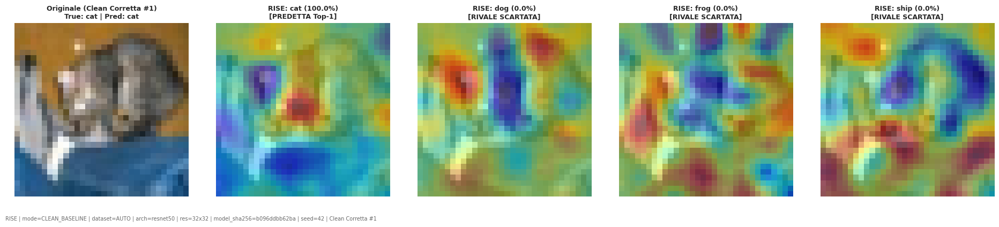


📌 [FORENSIC CASE] CORRECT CLEAN #2
   True Class: ship (8) | Predicted: ship (8)
   Confidence: ship = 90.24% | True = 90.24%


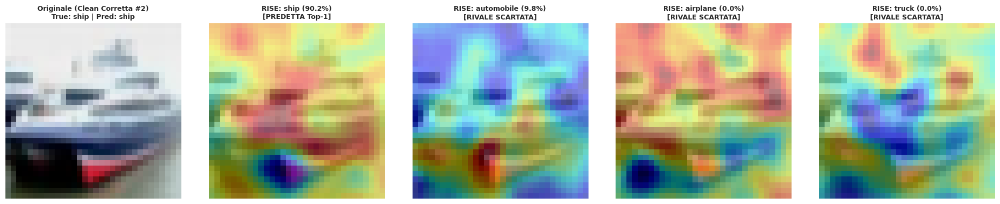


📌 [FORENSIC CASE] INCORRECT CLEAN #1
   True Class: horse (7) | Predicted: truck (9)
   Confidence: truck = 51.32% | True = 40.67%


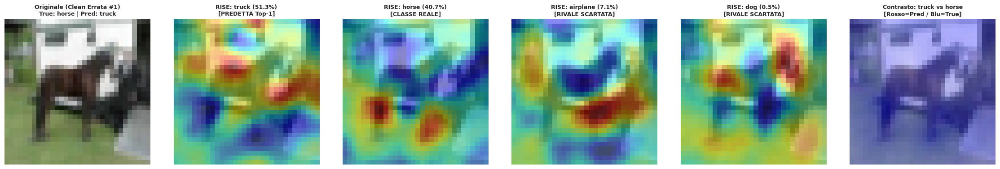


📌 [FORENSIC CASE] INCORRECT CLEAN #2
   True Class: dog (5) | Predicted: deer (4)
   Confidence: deer = 99.85% | True = 0.02%


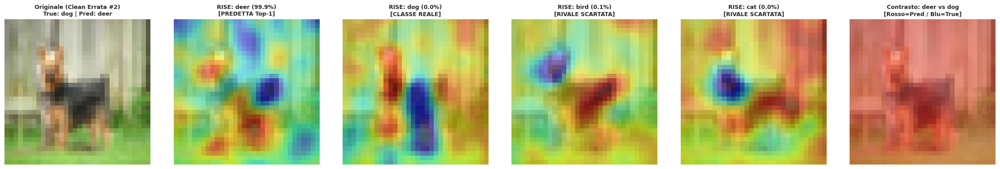


📌 [FORENSIC CASE] LOWEST CONFIDENCE #1
   True Class: cat (3) | Predicted: deer (4)
   Confidence: deer = 42.42% | True = 11.63%


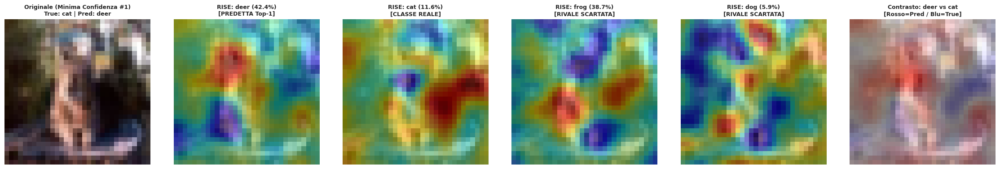


📌 [FORENSIC CASE] LOWEST CONFIDENCE #2
   True Class: bird (2) | Predicted: automobile (1)
   Confidence: automobile = 42.61% | True = 4.24%


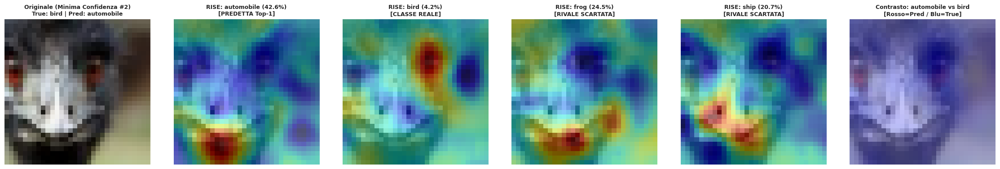

🧹 [Memory Cleanup] RAM: 3.82/31.35 GB (13.7%)


In [33]:
if should_run_section('RISE'):
    clean_memory()
    # ==============================================================================
    # 15. UNIFIED MULTI-CLASS RISE, RIVALS & CONTRASTIVE SUITE ON THE 4 CASES
    # ==============================================================================
    import os
    import torch
    import torch.nn.functional as F
    import numpy as np
    import matplotlib.pyplot as plt
    import cv2
    from torch.utils.data import DataLoader

    print("\n" + "=" * 90)
    print("🎯 [SECTION 15] STARTING MULTI-CLASS & CONTRASTIVE RISE ON THE 4 FORENSIC CASES")
    # RISE: Petsiuk, Das, Saenko, "RISE: Randomized Input Sampling for Explanation of Black-box
    # Models", BMVC 2018 (arXiv:1806.07421). §3.2: N binary masks h×w (p), bilinear upsampling to
    # (h+1)C_H × (w+1)C_W and H×W crop with random shift in [0,C); Eq. 6:
    # S(λ) ≈ 1/(E[M]·N) Σ_i f(I⊙M_i)·M_i(λ). Declared deviation: masking happens in the
    # normalized space (masked pixel = mean color of the dataset, not black as in the paper).
    # ==============================================================================
    # MODEL VERIFICATION AND FALLBACK
    # ==============================================================================
    strategy_name = (
        best_overall_config.get("strategy", "scratch").upper()
        if "best_overall_config" in globals() and best_overall_config
        else "SCRATCH"
    )

    rise_net = get_audit_model()
    _rise_ctx = get_model_eval_context(rise_net, device=device)
    RISE_NUM_MASKS = int(globals().get("RISE_NUM_MASKS", 1000))   # before: 1000 fixed in the call, the parameter was ignored
    RISE_GRID = int(globals().get("RISE_GRID", 8))
    RISE_P_KEEP = float(globals().get("RISE_P_KEEP", 0.5))
    _rise_gen = torch.Generator().manual_seed(int(globals().get("SEED", 42)))

    # Universal metadata verification print
    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}

    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))

    print(f"🎯 [SECTION 15] STARTING MULTI-CLASS & CONTRASTIVE RISE ({strategy_name})")
    print(f"📌 [MODEL CHECK] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 90)

    is_blind_rise = (not oracle_allowed()) or globals().get('poison_test_loader') is None
    # Cases analyzed in a local variable: the global images_to_analyze (Captum cells) is not overwritten.
    rise_cases = dict(globals().get("images_to_analyze") or {})

    # In blind mode the cases are chosen only on the CLEAN test set (never a leftover `audit_loader`).
    if is_blind_rise or not rise_cases:
        rise_net.eval()
        _dev = device
        _clean_ldr = None
        if globals().get('clean_test_dataset') is not None:
            _clean_ldr = DataLoader(clean_test_dataset, batch_size=64, shuffle=False, num_workers=0)
        elif globals().get('clean_test_loader') is not None:
            _clean_ldr = clean_test_loader

        if _clean_ldr is not None:
            corr_samples, wrong_samples, all_conf_samples = [], [], []
            with torch.no_grad():
                for _xb, _yb in _clean_ldr:
                    _xb = _xb.to(_dev)
                    _out = rise_net(_xb)
                    _prob = torch.softmax(_out, dim=1)
                    _c_max, _pred = torch.max(_prob, dim=1)
                    _yb_arr = _yb.numpy() if isinstance(_yb, torch.Tensor) else np.array(_yb)
                    for _k in range(len(_xb)):
                        _item = (_xb[_k: _k+1].clone(), int(_yb_arr[_k]), int(_pred[_k].item()), float(_c_max[_k].item()))
                        all_conf_samples.append(_item)
                        if _yb_arr[_k] != -1:
                            if _pred[_k].item() == _yb_arr[_k] and len(corr_samples) < 2:
                                corr_samples.append((_item[0], _item[1], _item[2]))
                            elif _pred[_k].item() != _yb_arr[_k] and len(wrong_samples) < 2:
                                wrong_samples.append((_item[0], _item[1], _item[2]))
                    if len(corr_samples) >= 2 and len(wrong_samples) >= 2 and len(all_conf_samples) >= 200:
                        break

            # Select the 2 samples with the LOWEST prediction confidence (maximum uncertainty without a target reference)
            all_conf_samples.sort(key=lambda s: s[3])
            low_conf_1 = (all_conf_samples[0][0], all_conf_samples[0][1], all_conf_samples[0][2]) if len(all_conf_samples) > 0 else None
            low_conf_2 = (all_conf_samples[1][0], all_conf_samples[1][1], all_conf_samples[1][2]) if len(all_conf_samples) > 1 else None

            rise_cases = {}
            if len(corr_samples) > 0: rise_cases["Correct Clean #1"] = corr_samples[0]
            if len(corr_samples) > 1: rise_cases["Correct Clean #2"] = corr_samples[1]
            if len(wrong_samples) > 0: rise_cases["Incorrect Clean #1"] = wrong_samples[0]
            if len(wrong_samples) > 1: rise_cases["Incorrect Clean #2"] = wrong_samples[1]
            if low_conf_1 is not None: rise_cases["Lowest Confidence #1"] = low_conf_1
            if low_conf_2 is not None: rise_cases["Lowest Confidence #2"] = low_conf_2

    if not rise_cases:
        print("⚠️ No case available for RISE (neither Captum cases nor clean test set).")
        for _k in ("rise_contrast_divergence", "rise_target_gini_sparsity"):
            record_metric(_k, float("nan"), "not_applicable", method="RISE (Petsiuk et al. 2018)", level="sample", note="no sample")
    else:
        rise_net.eval()
        softmax = torch.nn.Softmax(dim=1)

        # Class resolution (local variable: the global `classes` is not overwritten)
        if globals().get("CLASS_NAMES") is not None:
            rise_classes = list(globals()["CLASS_NAMES"])
        else:
            rise_classes = [f"Class_{i}" for i in range(int(globals().get("NUM_CLASSES", 10)))]

        # Target class only as an evaluation annotation in the oracle modes
        target_trojan_class = int(TARGET_LABEL) if (not is_blind_rise and "TARGET_LABEL" in globals() and TARGET_LABEL is not None) else -1

        # Standardized JET / Contrastive overlay function
        def apply_rise_overlay(orig_rgb, saliency_2d, alpha=0.45, cmap="jet", is_contrastive=False):
            if is_contrastive:
                vmax = max(abs(saliency_2d.min()), abs(saliency_2d.max()), 0.05)
                norm_map = (saliency_2d + vmax) / (2 * vmax)
            else:
                s_min, s_max = saliency_2d.min(), saliency_2d.max()
                norm_map = (
                    (saliency_2d - s_min) / (s_max - s_min + 1e-9)
                    if s_max > s_min
                    else np.zeros_like(saliency_2d)
                )

            norm_map = np.clip(norm_map, 0, 1)
            if norm_map.shape != orig_rgb.shape[:2]:
                norm_map = cv2.resize(
                    norm_map, (orig_rgb.shape[1], orig_rgb.shape[0]), interpolation=cv2.INTER_LINEAR
                )
            colormap = plt.get_cmap(cmap)
            heat_rgb = colormap(norm_map)[:, :, :3]
            overlay = np.clip((1.0 - alpha) * orig_rgb + alpha * heat_rgb, 0, 1)
            return overlay

        def generate_rise_masks(n, H, W, grid=(8, 8), p_keep=0.5, gen=None):
            """RISE masks (§3.2): binary h×w grid, bilinear upsampling to (h+1)·C and H×W crop with
            random shift in [0, C) (C = ceil(H/h), as in the official implementation)."""
            gh, gw = grid
            cell_h, cell_w = int(np.ceil(H / gh)), int(np.ceil(W / gw))
            grid_m = (torch.rand(n, 1, gh, gw, generator=gen) < p_keep).float()
            up = F.interpolate(grid_m, size=((gh + 1) * cell_h, (gw + 1) * cell_w), mode="bilinear", align_corners=False)
            off_y = torch.randint(0, cell_h, (n,), generator=gen).tolist()
            off_x = torch.randint(0, cell_w, (n,), generator=gen).tolist()
            return torch.stack([up[i, :, off_y[i]:off_y[i] + H, off_x[i]:off_x[i] + W] for i in range(n)], dim=0)

        # Vectorized RISE function for all the classes; masks generated in blocks with local RNG
        def compute_multiclass_rise(
            model, input_image, num_masks=RISE_NUM_MASKS, mask_grid=(RISE_GRID, RISE_GRID), p_keep=RISE_P_KEEP, batch_size=None
        ):
            _, C, H, W = input_image.shape
            # Dynamic computation of the batch size for masking based on the resolution and architecture
            if batch_size is None:
                is_heavy = sum(p.numel() for p in model.parameters()) > 15e6
                if max(H, W) > 64:
                    batch_size = 16
                elif is_heavy:
                    batch_size = 32
                else:
                    batch_size = 100

            n_cls = len(rise_classes)
            all_class_saliency = torch.zeros(n_cls, H, W, device=input_image.device)

            with torch.no_grad():
                base_probs = softmax(model(input_image)).squeeze(0).cpu().numpy()
                for i in range(0, num_masks, batch_size):
                    b_masks = generate_rise_masks(min(batch_size, num_masks - i), H, W, mask_grid, p_keep, _rise_gen).to(input_image.device)
                    masked_inputs = input_image * b_masks
                    probs = softmax(model(masked_inputs))[:, :n_cls]
                    all_class_saliency += torch.einsum("bk,bhw->khw", probs, b_masks.squeeze(1))

            all_class_saliency = all_class_saliency / (num_masks * p_keep)   # Eq. 6: 1/(E[M]·N)
            saliency_np = all_class_saliency.cpu().numpy()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            return saliency_np, base_probs

        _rise_metrics_saved = False
        with preserve_model_state(rise_net):
            for title, data in rise_cases.items():
                if data is None:
                    continue
                input_image, true_label, predicted_label = data
                input_image = input_image.clone().detach().to(device)
                if input_image.dim() == 3:
                    input_image = input_image.unsqueeze(0)

                _, C, H, W = input_image.shape

                # Denormalization statistics from the model context (not CIFAR/ImageNet constants)
                rise_mean = np.array(_rise_ctx["mean"])
                rise_std = np.array(_rise_ctx["std"])

                rise_maps, original_probs = compute_multiclass_rise(rise_net, input_image)

                sorted_class_indices = np.argsort(original_probs)[::-1]
                classes_to_show = [predicted_label]
                if true_label != -1 and true_label not in classes_to_show:
                    classes_to_show.append(true_label)
                for rank_cls in sorted_class_indices:
                    if rank_cls not in classes_to_show and len(classes_to_show) < 4:
                        classes_to_show.append(rank_cls)
                if target_trojan_class != -1 and target_trojan_class not in classes_to_show and len(classes_to_show) < 4:
                    classes_to_show.append(target_trojan_class)

                orig_np = input_image.squeeze().cpu().detach().numpy().transpose(1, 2, 0)
                if orig_np.min() < 0.0 or orig_np.max() > 1.0:
                    orig_rgb = rise_std * orig_np + rise_mean
                else:
                    orig_rgb = orig_np
                orig_rgb = np.clip(orig_rgb, 0, 1)

                print(f"\n{'='*75}")
                print(f"📌 [FORENSIC CASE] {title.upper()}")
                true_str = rise_classes[true_label] if (true_label != -1 and true_label < len(rise_classes)) else "N/A (Blind)"
                pred_str = rise_classes[predicted_label] if predicted_label < len(rise_classes) else str(predicted_label)
                print(f"   True Class: {true_str} ({true_label}) | Predicted: {pred_str} ({predicted_label})")
                true_conf_str = f"{original_probs[true_label]*100:.2f}%" if true_label != -1 else "N/A"
                print(f"   Confidence: {pred_str} = {original_probs[predicted_label]*100:.2f}% | True = {true_conf_str}")
                print(f"{'='*75}")

                has_diff = (true_label != -1 and predicted_label != true_label)
                num_plots = 1 + len(classes_to_show) + (1 if has_diff else 0)
                fig_rise, axes = plt.subplots(1, num_plots, figsize=(num_plots * 3.8, 3.8))
                if num_plots == 1:
                    axes = [axes]

                # 1. Sharp Original Image
                axes[0].imshow(orig_rgb)
                axes[0].set_title(
                    f"Original ({title})\nTrue: {true_str} | Pred: {pred_str}",
                    fontsize=9,
                    fontweight="bold",
                )
                axes[0].axis("off")

                # 2. RISE maps for each class with Grad-CAM JET overlay
                for p_idx, c_idx in enumerate(classes_to_show, start=1):
                    c_name = rise_classes[c_idx] if c_idx < len(rise_classes) else str(c_idx)
                    c_prob = original_probs[c_idx] * 100
                    c_map = rise_maps[c_idx]
                    if c_idx == predicted_label:
                        role_tag = "[PREDICTED Top-1]"
                    elif true_label != -1 and c_idx == true_label:
                        role_tag = "[TRUE CLASS]"
                    elif target_trojan_class != -1 and c_idx == target_trojan_class:
                        role_tag = "[TARGET TROJAN]"
                    else:
                        role_tag = "[DISCARDED RIVAL]"

                    overlay = apply_rise_overlay(
                        orig_rgb, c_map, alpha=0.45, cmap="jet", is_contrastive=False
                    )
                    axes[p_idx].imshow(overlay)
                    axes[p_idx].set_title(
                        f"RISE: {c_name} ({c_prob:.1f}%)\n{role_tag}", fontsize=9, fontweight="bold"
                    )
                    axes[p_idx].axis("off")

                # 3. Discrepancy Contrastive Map (Pred - True) with divergent BWR overlay
                if has_diff:
                    contrast_idx = num_plots - 1
                    diff_map = rise_maps[predicted_label] - rise_maps[true_label]
                    contrast_overlay = apply_rise_overlay(
                        orig_rgb, diff_map, alpha=0.45, cmap="bwr", is_contrastive=True
                    )
                    axes[contrast_idx].imshow(contrast_overlay)
                    axes[contrast_idx].set_title(
                        f"Contrast: {rise_classes[predicted_label]} vs {rise_classes[true_label]}\n[Red=Pred / Blue=True]",
                        fontsize=9,
                        fontweight="bold",
                    )
                    axes[contrast_idx].axis("off")

                # --- METRICS RECORDING & ARTIFACT SAVING (POISON SUCCESS or BLIND AUDIT) ---
                # Metrics recomputed at every run (previously they were written only if the PNG did not exist:
                # in a reused kernel those of a previous run remained).
                _is_oracle_case = "Poison Attack Success" in title
                _save_rise_artifact = (not _rise_metrics_saved) and (_is_oracle_case or (is_blind_rise and ("Incorrect Clean #1" in title or "Lowest Confidence #1" in title or "Correct Clean #1" in title)))
                if _save_rise_artifact:
                    _rise_metrics_saved = True
                    try:
                        target_map = rise_maps[predicted_label]
                        # Reference: true class if different from the predicted one, otherwise the rival with the highest
                        # probability (previously, with predicted = true, the divergence was 0 by construction).
                        _rivals = [int(c) for c in sorted_class_indices if int(c) != int(predicted_label)]
                        ref_cls = true_label if (true_label != -1 and true_label != predicted_label) else (_rivals[0] if _rivals else predicted_label)
                        ref_map = rise_maps[ref_cls]
                        _rise_note = f"sample '{title}', predicted class vs {'true' if ref_cls == true_label else 'top-2 rival'}; N={RISE_NUM_MASKS}, grid {RISE_GRID}, p={RISE_P_KEEP}"

                        # A. Computation of divergence/contrast between target map and reference map
                        rise_contrast_divergence = float(np.mean(target_map) - np.mean(ref_map))
                        record_metric("rise_contrast_divergence", rise_contrast_divergence if ref_cls != predicted_label else float("nan"),
                                      "computed" if ref_cls != predicted_label else "degenerate",
                                      method="RISE: mean(S_pred) − mean(S_ref) (exploratory indicator)", level="sample",
                                      requires_ground_truth=_is_oracle_case, note=_rise_note)
                        globals()['rise_contrast_divergence'] = RUN_RESULTS['rise_contrast_divergence']

                        # B. Saliency concentration measure (Gini / Sparsity) to detect a localized trigger peak
                        flat_m = np.sort(np.maximum(0, target_map.flatten()))
                        n_pixels = len(flat_m)
                        if flat_m.sum() > 0:
                            idx_arr = np.arange(1, n_pixels + 1)
                            gini_val = float((np.sum((2 * idx_arr - n_pixels - 1) * flat_m)) / (n_pixels * flat_m.sum()))
                        else:
                            gini_val = float("nan")
                        record_metric("rise_target_gini_sparsity", gini_val, "computed" if np.isfinite(gini_val) else "degenerate",
                                      method="Gini index of the RISE map of the predicted class (concentration)", level="sample",
                                      requires_ground_truth=_is_oracle_case, note=_rise_note)
                        globals()['rise_target_gini_sparsity'] = RUN_RESULTS['rise_target_gini_sparsity']

                        # C. Saving the diagnostic artifact to disk
                        out_dir_rise = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                        os.makedirs(out_dir_rise, exist_ok=True)
                        _xai_fig_strat = str(best_overall_config.get("strategy", "model")).lower() if "best_overall_config" in globals() and best_overall_config else "model"
                        if is_blind_rise:
                            rise_img_filename = f"rise_blind_audit_{_xai_fig_strat}.png"
                        else:
                            att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
                            rise_img_filename = f"rise_success_{att_type_str}_{_xai_fig_strat}.png"
                        rise_save_path = os.path.join(out_dir_rise, rise_img_filename)

                        fig_rise.text(0.01, -0.06, provenance_caption("RISE", extra=title), fontsize=7, alpha=0.7)
                        fig_rise.savefig(rise_save_path, bbox_inches='tight', dpi=130)
                        register_artifact("RISE", rise_save_path)
                        globals()['RISE_SUCCESS_IMG_PATH'] = rise_save_path
                        globals()['rise_success_img'] = rise_img_filename
                        RUN_RESULTS['rise_success_img'] = rise_img_filename
                        print(f"💾 [RISE SAVED] Diagnostic panel saved to: {rise_save_path}")
                        print(f"📊 [RISE METRICS] Contrast Divergence: {rise_contrast_divergence:.4f} | Target Gini Sparsity: {gini_val:.4f}")
                    except Exception as e_rise_save:
                        print(f"⚠️ [RISE SAVE WARNING] Unable to save artifact/metrics: {e_rise_save}")

                plt.tight_layout()
                plt.show()

        if not _rise_metrics_saved:
            for _k in ("rise_contrast_divergence", "rise_target_gini_sparsity"):
                record_metric(_k, float("nan"), "insufficient_data", method="RISE (Petsiuk et al. 2018)", level="sample",
                              requires_ground_truth=not is_blind_rise, note="no 'Poison Attack Success' case available")

    check_model_integrity("RISE")
    clean_memory(verbose=True)



---
## 🧠 16. Activation Maximization

In [34]:
if should_run_section('ACTIVATION_MAXIMIZATION'):
    clean_memory() if "clean_memory" in globals() else None
    # ==============================================================================
    # UNIFIED AM SECTION: SHARED SETUP & UTILITIES
    # ==============================================================================
    import gc
    import os
    import glob
    import re
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import numpy as np
    import matplotlib.pyplot as plt
    import pandas as pd
    from scipy.stats import kurtosis
    import torchvision
    import torchvision.models as models
    from torch.utils.data import DataLoader
    from typing import Callable, Dict, List, Optional, Tuple

    # -- Device --
    am_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # ==============================================================================
    # INSPECTED MODEL (single resolver of the contract)
    # The parameters are NO LONGER frozen globally (requires_grad=False without restoration
    # altered the shared state read by the following sections): freezing happens only
    # inside am_synthesize, under preserve_model_state.
    # ==============================================================================
    strategy_name = (
        best_overall_config.get("strategy", "scratch").upper()
        if "best_overall_config" in globals() and best_overall_config
        else "PIPELINE"
    )

    am_net = get_audit_model()
    am_net.eval()

    # Universal metadata verification print
    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}

    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))

    print("\n" + "=" * 95)
    print(f" [ACTIVATION MAXIMIZATION] UNIFIED SECTION — BACKDOOR FORENSIC SCREENING ({strategy_name})")
    print(f"📌 [MODEL CHECK] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 95)

    # -- Resolution and normalization from the model context (no hardcoded statistics) --
    am_ctx = get_model_eval_context(am_net, device=am_device)
    am_img_size = (am_ctx['target_res'], am_ctx['target_res'])
    am_mean = am_ctx['mean']
    am_std  = am_ctx['std']

    am_classes = CLASS_NAMES if "CLASS_NAMES" in globals() else (clean_test_dataset.classes if "clean_test_dataset" in globals() else CIFAR10_CLASSES)
    # Target class ONLY for the oracle annotations/evaluations: None in the blind modes (before: default 0,
    # which marked class 0 as "[TARGET]" and exported fake am_target_*).
    am_target_label = int(TARGET_LABEL) if (oracle_allowed() and "TARGET_LABEL" in globals() and TARGET_LABEL is not None and int(TARGET_LABEL) >= 0) else None

    # -- Layer map --
    am_layer_map = {
        "conv1": am_net.conv1 if hasattr(am_net, "conv1") else None,
        "layer1": am_net.layer1 if hasattr(am_net, "layer1") else None,
        "layer2": am_net.layer2 if hasattr(am_net, "layer2") else None,
        "layer3": am_net.layer3 if hasattr(am_net, "layer3") else None,
        "layer4": am_net.layer4 if hasattr(am_net, "layer4") else None,
    }

    # -- DataLoader resolution (the loader with trigger exists only in the oracle modes) --
    am_clean_loader = globals().get("clean_test_loader") or globals().get("test_loader") or globals().get("clean_loader")
    am_poison_loader = (globals().get("poison_test_loader") or globals().get("poison_loader")) if oracle_allowed() else None

    # ==============================================================================
    # FOURIER PARAMETRIZATION WITH NATURAL 1/f PRIOR
    # ==============================================================================
    # Single definition (the Zhu & Cangelosi cells reuse it if present): initialization with
    # local generator, without re-seeding torch's global RNG.
    class FourierStimulus(nn.Module):
        FS_VERSION = 2

        def __init__(self, shape=(1, 3, 32, 32), device="cpu", generator=None):
            super().__init__()
            B, C, H, W = shape
            self.H, self.W = H, W
            spec_w = W // 2 + 1
            self.real = nn.Parameter((torch.randn(B, C, H, spec_w, generator=generator) * 0.01).to(device))
            self.imag = nn.Parameter((torch.randn(B, C, H, spec_w, generator=generator) * 0.01).to(device))
            freq_h = np.fft.fftfreq(H)[:, None]
            freq_w = np.fft.rfftfreq(W)[None, :]
            freq_dist = np.sqrt(freq_h**2 + freq_w**2)
            scale = 1.0 / np.maximum(freq_dist, 1.0 / max(H, W))
            self.register_buffer("scale", torch.from_numpy(scale).float().to(device))

        def forward(self):
            z = torch.complex(self.real * self.scale, self.imag * self.scale)
            return torch.fft.irfftn(z, s=(self.H, self.W), dim=(2, 3))


    # ==============================================================================
    # UNIFIED AM SYNTHESIZER
    # ==============================================================================
    def am_denormalize(tensor_img):
        with torch.no_grad():
            img = tensor_img.squeeze().cpu().numpy().transpose(1, 2, 0)
            img = am_std * img + am_mean
            return np.clip(img, 0, 1)


    def am_synthesize(
        target_fn,
        domain="fourier",
        num_steps=300,
        lr=0.08,
        l2_reg=1e-4,
        tv_reg=float(globals().get("AM_TV_REG", 3e-3)),
        jitter=2,
        img_size=am_img_size,
        seed=42,
    ):
        # Local RNG (before: global torch.manual_seed on every call) and model parameters
        # frozen only during synthesis, with restoration guaranteed by preserve_model_state.
        gen = torch.Generator().manual_seed(int(seed))
        with preserve_model_state(am_net):
            for p in am_net.parameters():
                p.requires_grad_(False)

            if domain == "fourier":
                param_img = FourierStimulus((1, 3, *img_size), am_device, generator=gen)
                optimizer = torch.optim.Adam(param_img.parameters(), lr=lr)
            else:
                raw_pixel = (torch.randn(1, 3, *img_size, generator=gen) * 0.05).to(am_device)
                raw_pixel.requires_grad = True
                param_img = None
                optimizer = torch.optim.Adam([raw_pixel], lr=lr)

            init_score = final_score = 0.0

            for step in range(num_steps):
                optimizer.zero_grad()
                img = param_img() if domain == "fourier" else raw_pixel

                if jitter > 0:
                    sx = int(torch.randint(-jitter, jitter + 1, (1,), generator=gen).item())
                    sy = int(torch.randint(-jitter, jitter + 1, (1,), generator=gen).item())
                    scored_img = torch.roll(img, shifts=(sy, sx), dims=(2, 3))
                else:
                    scored_img = img

                score = target_fn(scored_img)
                if step == 0:
                    init_score = score.item()
                final_score = score.item()

                loss_l2 = l2_reg * torch.norm(img, p=2)
                diff_h = torch.sum(torch.abs(img[:, :, 1:, :] - img[:, :, :-1, :]))
                diff_w = torch.sum(torch.abs(img[:, :, :, 1:] - img[:, :, :, :-1]))
                loss_tv = tv_reg * (diff_h + diff_w)

                total_loss = -score + loss_l2 + loss_tv
                total_loss.backward()
                optimizer.step()

                if domain == "pixel":
                    with torch.no_grad():
                        raw_pixel.clamp_(-2.5, 2.5)

            with torch.no_grad():
                final_img = param_img() if domain == "fourier" else raw_pixel
                stats = {
                    "initial_activation": init_score,
                    "final_activation": final_score,
                    # Descriptive ratio: unstable if the initial activation is ≈ 0
                    "activation_gain": (final_score - init_score) / abs(init_score) if init_score != 0 else float("nan"),
                    "tv_energy": (diff_h + diff_w).item(),
                }
                return am_denormalize(final_img), stats


    def am_paired_poison_clean(max_samples):
        """
        Paired samples (clean image, same image with trigger) from the test set: for a
        LazyPoisonedDataset the native indices point to the clean test dataset, so the activation
        difference isolates the effect of the trigger from the content. Oracle mode only.
        Returns (x_clean, x_poison) on CPU or None if the pairing cannot be verified.
        """
        p_ds = globals().get("poison_test_dataset")
        c_ds = globals().get("clean_test_dataset")
        if not oracle_allowed() or p_ds is None or c_ds is None or p_ds is c_ds:
            return None
        nat = getattr(p_ds, "native_indices", None)
        lbls = getattr(p_ds, "labels", None)
        if nat is None or lbls is None or len(c_ds) <= max(nat):
            return None
        xs_c, xs_p = [], []
        for j in range(min(int(max_samples), len(p_ds))):
            xc, yc = c_ds[int(nat[j])]
            if int(yc) != int(lbls[j]):
                return None   # datasets not aligned: pairing not guaranteed
            xs_c.append(xc)
            xs_p.append(p_ds[j][0])
        if not xs_c or xs_c[0].shape != xs_p[0].shape:
            return None
        return torch.stack(xs_c), torch.stack(xs_p)


    _cl = "OK" if am_clean_loader is not None else "NOT FOUND"
    _pl = "OK" if am_poison_loader is not None else "NOT FOUND"
    print(f" [OK] Setup completed. Model, loaders and AM utilities ready.")
    target_name_str = (am_classes[am_target_label] if am_target_label < len(am_classes) else str(am_target_label)) if am_target_label is not None else "n/a (blind mode)"
    print(f"     Device: {am_device} | Backdoor target (oracle evaluation only): {target_name_str} (ID={am_target_label})")
    print(f"     AM resolution: {am_img_size} | Clean loader: {_cl} | Poison loader: {_pl}")

    clean_memory(verbose=True) if "clean_memory" in globals() else None

    # Safe zero-worker reconstruction to eliminate IPC crashes / OOM
    if 'clean_test_dataset' in globals() and clean_test_dataset is not None:
        am_clean_loader = DataLoader(clean_test_dataset, batch_size=64, shuffle=False, num_workers=0)
    elif am_clean_loader is not None and hasattr(am_clean_loader, 'dataset'):
        am_clean_loader = DataLoader(am_clean_loader.dataset, batch_size=64, shuffle=False, num_workers=0)

    if oracle_allowed() and globals().get('poison_test_dataset') is not None and poison_test_dataset is not globals().get('clean_test_dataset'):
        am_poison_loader = DataLoader(poison_test_dataset, batch_size=64, shuffle=False, num_workers=0)
    elif am_poison_loader is not None and hasattr(am_poison_loader, 'dataset'):
        am_poison_loader = DataLoader(am_poison_loader.dataset, batch_size=64, shuffle=False, num_workers=0)



 [ACTIVATION MAXIMIZATION] UNIFIED SECTION — BACKDOOR FORENSIC SCREENING (SCRATCH)
📌 [MODEL CHECK] Clean F1: N/A | ASR: N/A | TOI (F1*ASR): 0.0
 [OK] Setup completed. Model, loaders and AM utilities ready.
     Device: cuda | Backdoor target (oracle evaluation only): n/a (blind mode) (ID=None)
     AM Resolution: (32, 32) | Clean loader: OK | Poison loader: NOT FOUND
🧹 [Memory Cleanup] RAM: 3.82/31.35 GB (13.7%)



 PART 1: ACTIVATION MAXIMIZATION PROTOTYPES - OUTPUT LAYER (ALL 10 CLASSES)
📌 [MODEL CHECK] Clean F1: N/A | ASR: N/A | TOI (F1*ASR): 0.0

    WHAT THIS SECTION DOES:
      For each class of the dataset, we synthesize an artificial image
      that MAXIMIZES the activation of the output neuron corresponding to that class.
      In other words, we ask the network: "what is the ideal input that
      you would classify with maximum confidence as class X?"


    HOW THE IMAGE IS COMPUTED:
      1. An image is initialized as random Fourier coefficients (spectral
         domain with natural 1/f prior - Zhu & Cangelosi, 2025)
      2. The forward pass through the network is run
      3. The logit of the target class is computed
      4. The loss = -logit + lambda_TV*TV(x) + lambda_L2*||x||_2 is computed
         where TV is the Total Variation (smoothing) and L2 prevents extreme pixels
      5. Backpropagation is done ON THE IMAGE (not on the weights!) and it is updated
      6. At each ste

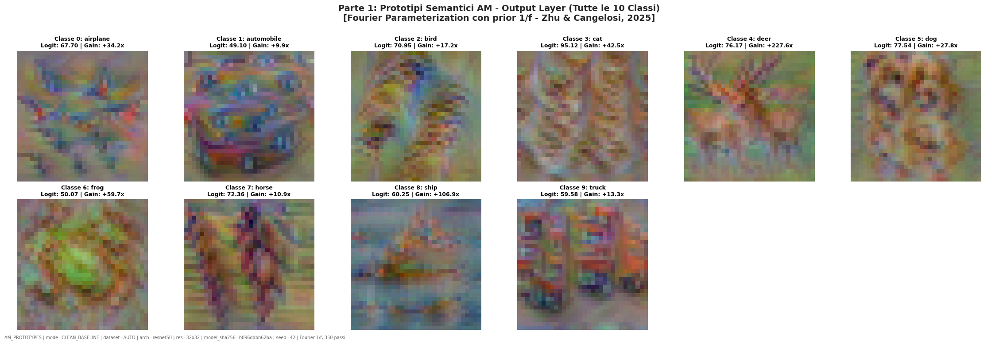


Diagnostic Table - Output Prototypes for the 10 Classes:
       Class Final Logit Gain Ratio TV Energy
  0: airplane        67.70     +34.2x      1072
1: automobile        49.10      +9.9x      1396
      2: bird        70.95     +17.2x      1248
       3: cat        95.12     +42.5x      1295
      4: deer        76.17    +227.6x      1127
       5: dog        77.54     +27.8x      1154
      6: frog        50.07     +59.7x      1276
     7: horse        72.36     +10.9x      1327
      8: ship        60.25    +106.9x       982
     9: truck        59.58     +13.3x      1265


In [35]:
if should_run_section('ACTIVATION_MAXIMIZATION'):
    # ==============================================================================
    # PART 1: VISUALIZATION OF AM PROTOTYPES FOR ALL CLASSES
    # ==============================================================================
    import math
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt


    # Universal metadata verification print
    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}


    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))


    print("\n" + "=" * 95)
    print(f" PART 1: ACTIVATION MAXIMIZATION PROTOTYPES - OUTPUT LAYER (ALL {len(am_classes)} CLASSES)")
    print(f"📌 [MODEL CHECK] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 95)
    print("""
    WHAT THIS SECTION DOES:
      For each class of the dataset, we synthesize an artificial image
      that MAXIMIZES the activation of the output neuron corresponding to that class.
      In other words, we ask the network: "what is the ideal input that
      you would classify with maximum confidence as class X?"


    HOW THE IMAGE IS COMPUTED:
      1. An image is initialized as random Fourier coefficients (spectral
         domain with natural 1/f prior - Zhu & Cangelosi, 2025)
      2. The forward pass is run through the network
      3. The logit of the target class is computed
      4. The loss = -logit + lambda_TV*TV(x) + lambda_L2*||x||_2 is computed
         where TV is the Total Variation (smoothing) and L2 prevents extreme pixels
      5. Backpropagation is done ON THE IMAGE (not on the weights!) and it is updated
      6. At each step a random spatial jitter (+/-2px) is applied for robustness
      7. After N steps, the resulting image is the "ideal prototype" of the class


    HOW TO INTERPRET THE RESULTS:
      - Each image shows the visual patterns that the network has learned as
        "representative" of that class
      - A backdoor target class MAY show anomalous patterns or trigger
        artifacts, but the absence/presence of artifacts is not proof
      - Gain Ratio = (final - initial)/|initial|: descriptive, unstable if the initial activation ≈ 0
      - The "suspect class" (maximum final logit) is an exploratory indicator without a threshold
    """)


    # Synthesis of the prototypes for all dataset classes
    class_prototypes = []
    class_metrics = []


    for c_id in range(len(am_classes)):


        def make_class_obj(target_c):
            def obj(img):
                return am_net(img)[0, target_c]


            return obj


        img_proto, stats = am_synthesize(
            make_class_obj(c_id), domain="fourier", num_steps=350, lr=0.08, tv_reg=3e-3, seed=100 + c_id
        )
        class_prototypes.append((c_id, am_classes[c_id], img_proto, stats))
        class_metrics.append(
            {
                "Class": f"{c_id}: {am_classes[c_id]}",
                "Final Logit": f"{stats['final_activation']:.2f}",
                "Gain Ratio": f"{stats['activation_gain']:+.1f}x",
                "TV Energy": f"{stats['tv_energy']:.0f}",
            }
        )
        print(
            f"  Class {c_id:2d} ({am_classes[c_id]}) -> Logit: {stats['final_activation']:.2f}, Gain: {stats['activation_gain']:+.1f}x"
        )


    # Dynamic grid computed from the actual number of classes (works for 10, 43 or N classes)
    n_classes = len(class_prototypes)
    n_cols = min(6, n_classes) if n_classes > 5 else n_classes
    n_rows = math.ceil(n_classes / n_cols)


    fig_am_proto, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.8, n_rows * 3.8))
    axes = np.array(axes).flatten()


    for idx, (c_id, c_name, img, st) in enumerate(class_prototypes):
        is_target = am_target_label is not None and c_id == am_target_label   # oracle-only annotation
        axes[idx].imshow(img)
        prefix = "[TARGET oracle] " if is_target else ""
        color = "darkred" if is_target else "black"
        axes[idx].set_title(
            f'{prefix}Class {c_id}: {c_name}\nLogit: {st["final_activation"]:.2f} | Gain: {st["activation_gain"]:+.1f}x',
            fontsize=9,
            fontweight="bold",
            color=color,
        )
        axes[idx].axis("off")


    # Turn off any unused axes in the last row
    for extra_idx in range(n_classes, len(axes)):
        axes[extra_idx].axis("off")


    plt.suptitle(
        f"Part 1: AM Semantic Prototypes - Output Layer (All {n_classes} Classes)\n"
        "[Fourier Parameterization with 1/f prior - Zhu & Cangelosi, 2025]",
        fontsize=14,
        fontweight="bold",
        y=0.995,
    )
    fig_am_proto.text(0.01, 0.002, provenance_caption("AM_PROTOTYPES", extra="Fourier 1/f, 350 steps"), fontsize=7, alpha=0.7)
    plt.tight_layout()


    # --- SAVING PROTOTYPE IMAGE & MOST SUSPECT CLASS IN RUN_RESULTS ---
    try:
        import os
        out_dir_am = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
        os.makedirs(out_dir_am, exist_ok=True)
        _cur_m = str(globals().get('EXECUTION_MODE', '')).upper()
        if _cur_m in ['BLIND_AUDIT', 'MODEL_ONLY']:
            att_type_str = "blind_audit"
        else:
            att_type_str = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
        _xai_fig_strat = str(best_overall_config.get("strategy", "model")).lower() if "best_overall_config" in globals() and best_overall_config else "model"


        # A. Saving the full image of all classes
        am_proto_img_filename = f"am_prototypes_all_classes_{att_type_str}_{_xai_fig_strat}.png"
        am_proto_save_path = os.path.join(out_dir_am, am_proto_img_filename)
        fig_am_proto.savefig(am_proto_save_path, bbox_inches='tight', dpi=130)
        register_artifact("AM_PROTOTYPES", am_proto_save_path)
        globals()['AM_PROTOTYPES_IMG_PATH'] = am_proto_save_path
        globals()['am_prototypes_img'] = am_proto_img_filename
        if 'RUN_RESULTS' in globals() and isinstance(RUN_RESULTS, dict):
            RUN_RESULTS['am_prototypes_img'] = am_proto_img_filename


        # B. Identification of the most suspect class (by Final Logit and Gain Ratio)
        # The most anomalous synthesized class is the one with the highest final Logit
        sorted_by_logit = sorted(class_prototypes, key=lambda x: x[3]['final_activation'], reverse=True)
        suspect_cid, suspect_cname, _, suspect_stats = sorted_by_logit[0]

        am_suspect_class_name = str(suspect_cname)
        am_suspect_class_id = int(suspect_cid)
        am_suspect_logit = float(suspect_stats['final_activation'])
        am_suspect_gain = float(suspect_stats['activation_gain'])

        _am_logits = np.array([st['final_activation'] for _, _, _, st in class_prototypes], dtype=float)
        _am_z, _am_zinfo = robust_mad_z(_am_logits)
        _am_note = "maximum final logit among the AM prototypes: exploratory indicator, no threshold or verdict"
        record_metric("am_suspect_class_id", am_suspect_class_id, method="Activation Maximization (output layer)", level="class", note=_am_note)
        record_metric("am_suspect_class_name", am_suspect_class_name, method="Activation Maximization (output layer)", level="class", note=_am_note)
        record_metric("am_suspect_logit", am_suspect_logit, method="Activation Maximization (output layer)", level="class", unit="logit",
                      note=f"robust z of the class = {_am_z[am_suspect_class_id]:.2f} [{_am_zinfo['status']}]")
        record_metric("am_suspect_gain", am_suspect_gain, method="Activation Maximization (output layer)", level="class", unit="ratio",
                      note="(final - initial)/|initial|, unstable if the initial activation ≈ 0")
        record_entities("AM_PROTOTYPES", "class", [
            {"entity_id": int(_cid), "class_id": int(_cid), "class_name": str(_cn), "score": float(_st['final_activation']),
             "rank": int(np.argsort(-_am_logits).tolist().index(_cid)) + 1, "note": f"gain={_st['activation_gain']}; z={_am_z[_cid]:.2f}"}
            for _cid, _cn, _, _st in class_prototypes
        ])
        for _k in ("am_suspect_class_name", "am_suspect_class_id", "am_suspect_logit", "am_suspect_gain"):
            globals()[_k] = RUN_RESULTS[_k]

        # Target class metrics: oracle evaluation (never class 0 by default)
        if am_target_label is not None and am_target_label < len(class_prototypes):
            _st_t = class_prototypes[am_target_label][3]
            record_metric("am_target_logit", float(_st_t['final_activation']), method="AM output layer, target class", level="class",
                          unit="logit", requires_ground_truth=True, note=f"target rank by logit = {int(np.argsort(-_am_logits).tolist().index(am_target_label)) + 1}")
            record_metric("am_target_gain", float(_st_t['activation_gain']), method="AM output layer, target class", level="class",
                          unit="ratio", requires_ground_truth=True)
        else:
            for _k in ("am_target_logit", "am_target_gain"):
                record_metric(_k, float("nan"), "not_applicable", method="AM output layer, target class", level="class",
                              requires_ground_truth=True, note="target class not available")
        globals()['am_target_logit'] = RUN_RESULTS['am_target_logit']
        globals()['am_target_gain'] = RUN_RESULTS['am_target_gain']


        print(f"\n💾 [AM SAVED] Prototype grid saved to: {am_proto_save_path}")
        print(f"🔎 [AM EXPLORATORY INDICATOR] Class with the maximum AM logit: '{am_suspect_class_name}' (#{am_suspect_class_id}) | Logit: {am_suspect_logit:.2f} | Gain: {am_suspect_gain:+.1f}x")
    except Exception as e_am_save:
        print(f"⚠️ [AM SAVE WARNING] Error saving AM prototypes: {e_am_save}")


    plt.show()


    # Metrics table
    print(f"\nDiagnostic Table - Output Prototypes for the {n_classes} Classes:")
    print(pd.DataFrame(class_metrics).to_string(index=False))
    check_model_integrity("ACTIVATION_MAXIMIZATION_P1")







In [36]:
# ==============================================================================
# UNIVERSAL DATALOADER WORKERS FIX (Zero-Worker Immune for XAI & Forensics)
# ==============================================================================
import torch
from torch.utils.data import DataLoader

print("🔄 Regenerating XAI DataLoaders in immune mode (num_workers=0)...")

# 1. Safe re-creation of test_loader / clean_test_loader
if 'clean_test_dataset' in globals() and clean_test_dataset is not None:
    _eval_bs = globals().get('BATCH_SIZE', 64)
    clean_test_loader = DataLoader(
        clean_test_dataset,
        batch_size=_eval_bs,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )
    test_loader = clean_test_loader
    clean_loader = clean_test_loader

# 2. Safe re-creation of poison_test_loader
if 'poison_test_dataset' in globals() and poison_test_dataset is not None:
    _eval_bs = globals().get('BATCH_SIZE', 64)
    poison_test_loader = DataLoader(
        poison_test_dataset,
        batch_size=_eval_bs,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )
    poison_loader = poison_test_loader

# 3. Immediate propagation to the loaders dedicated to Activation Maximization (Cell 56-58)
am_clean_loader = globals().get('clean_test_loader')
if 'poison_test_loader' in globals():
    am_poison_loader = poison_test_loader

print("✅ XAI/AM DataLoaders successfully immunized (num_workers=0, zero IPC crash).")


🔄 Regenerating XAI DataLoader in immune mode (num_workers=0)...
✅ XAI/AM DataLoader successfully immunized (num_workers=0, zero IPC crash).



🔬 PART 2: FORENSIC CHANNEL DISCOVERY + ACTIVATION MAXIMIZATION
📌 [MODEL CHECK] Clean F1: N/A | ASR: N/A | TOI (F1*ASR): 0.0

[INFO] Mode: compare | Poison loader: False | Target: False | Paired pairs: 0

🔍 Conv1 — Edges & Micro-Patterns (Total channels: 64)
  ▶ [1] BLIND CHANNEL SELECTION (Variance, Kurtosis, Weight Norm, Composite)


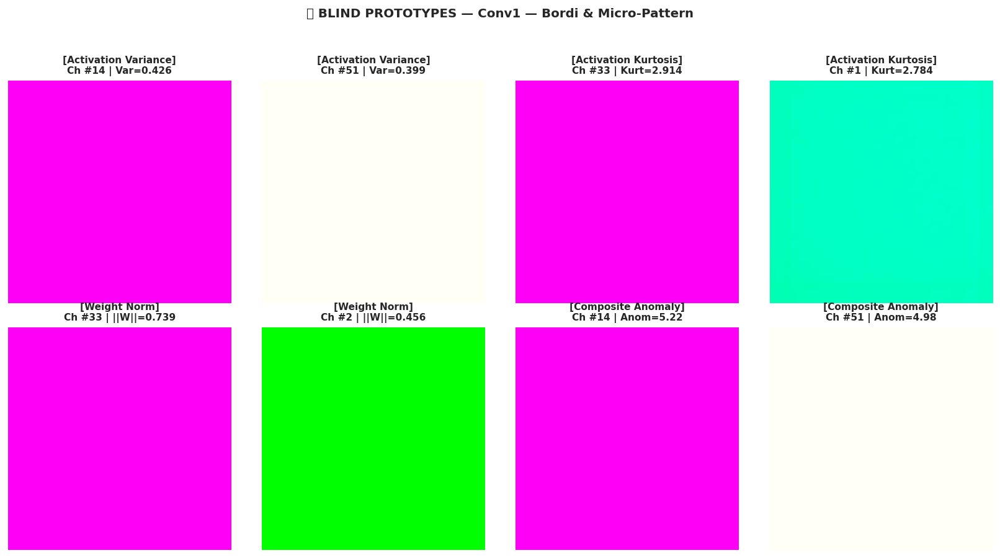


🔍 Layer1 — Micro-Texture & Repetitive Patterns (Total channels: 256)
  ▶ [1] BLIND CHANNEL SELECTION (Variance, Kurtosis, Weight Norm, Composite)


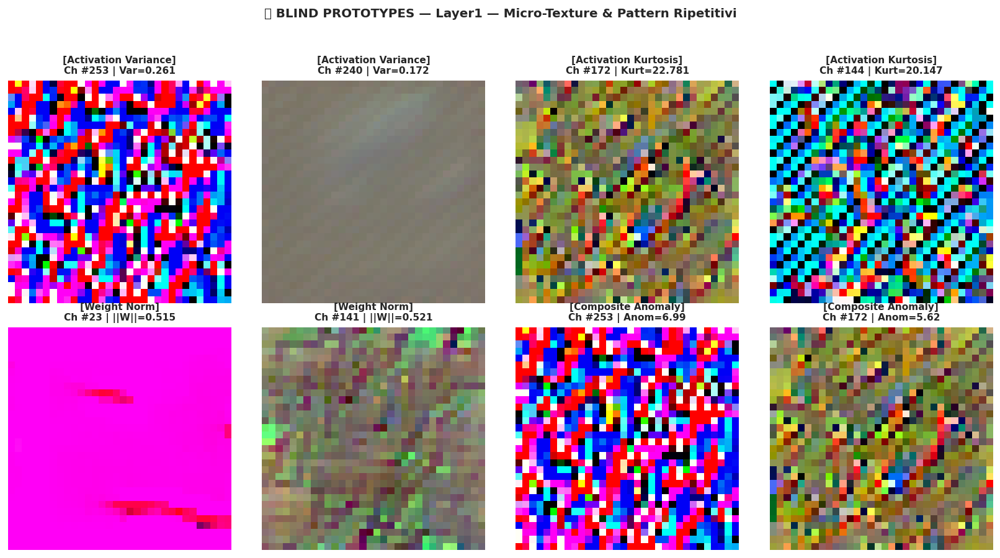


🔍 Layer2 — Junctions, Curves & Lattices (Total channels: 512)
  ▶ [1] BLIND CHANNEL SELECTION (Variance, Kurtosis, Weight Norm, Composite)


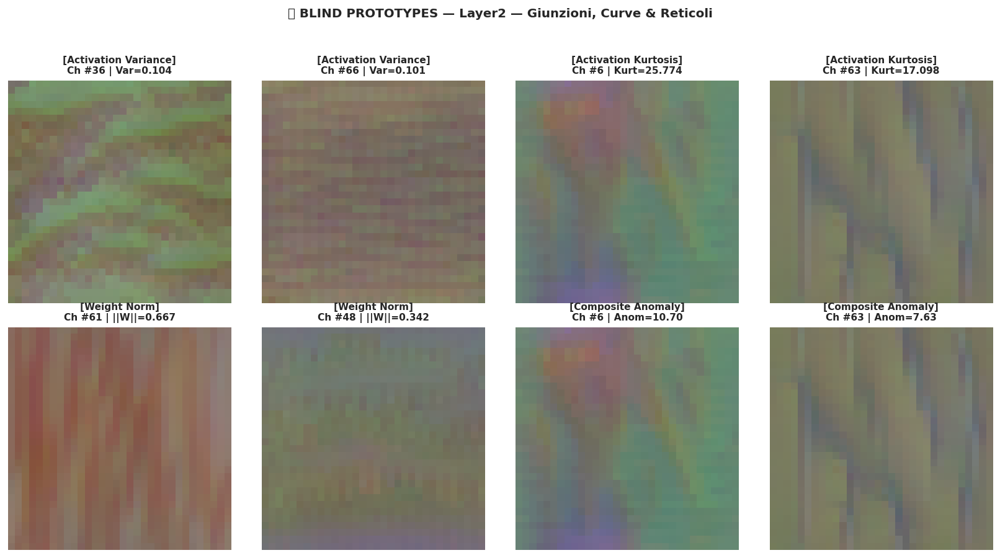


🔍 Layer3 — Structural Parts & Sub-Objects (Total channels: 1024)
  ▶ [1] BLIND CHANNEL SELECTION (Variance, Kurtosis, Weight Norm, Composite)


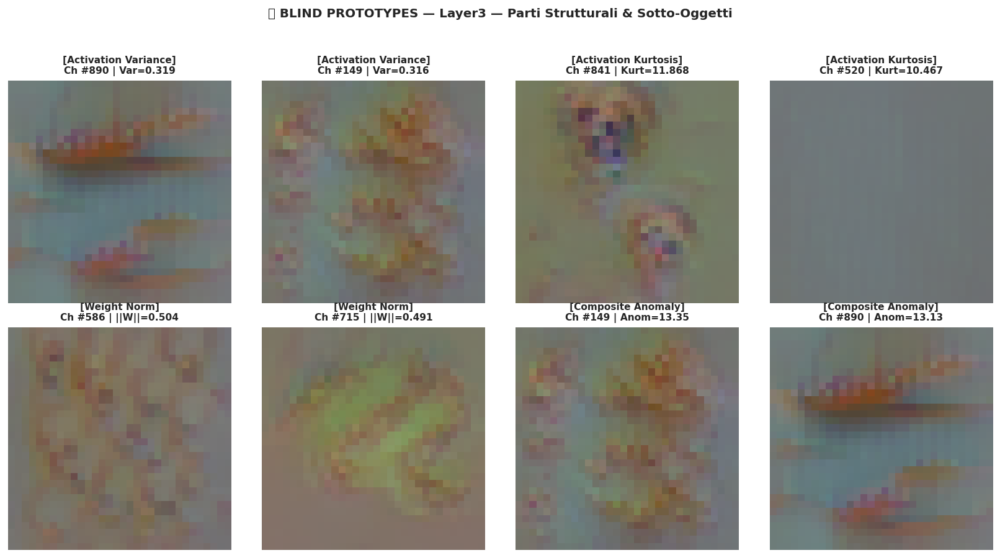


🔍 Layer4 — Deep Semantic Representation (Total channels: 2048)
  ▶ [1] BLIND CHANNEL SELECTION (Variance, Kurtosis, Weight Norm, Composite)


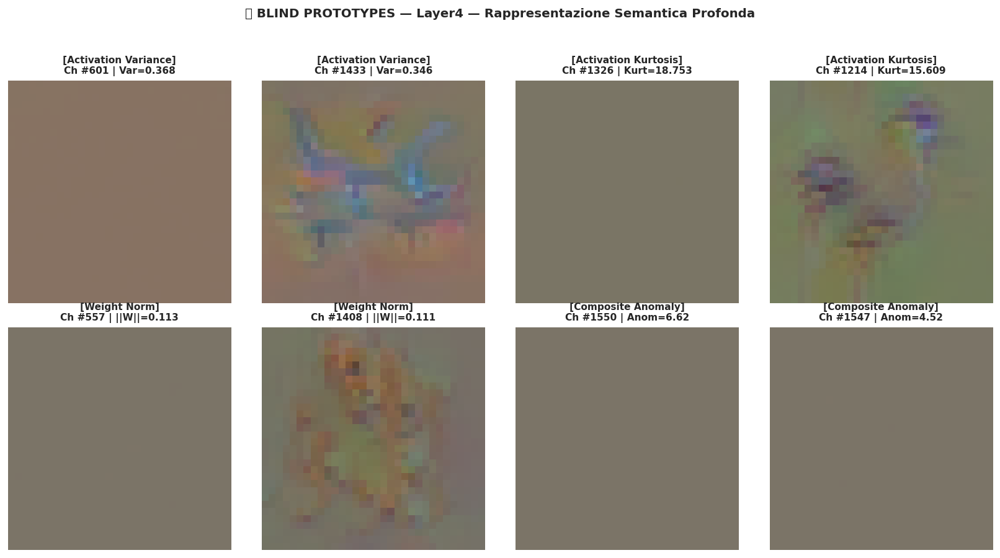


📊 FORENSIC SUMMARY — IDENTIFIED CHANNELS

[BLIND DISCOVERY - Anomalous Channels Without Knowing the Trigger]:
  • Conv1 — Edges & Micro-Pattern:
      - Activation Variance       : [14, 51]
      - Activation Kurtosis       : [33, 1]
      - Weight Norm               : [33, 2]
      - Composite Anomaly         : [14, 51]
  • Layer1 — Micro-Texture & Repetitive Patterns:
      - Activation Variance       : [253, 240]
      - Activation Kurtosis       : [172, 144]
      - Weight Norm               : [23, 141]
      - Composite Anomaly         : [253, 172]
  • Layer2 — Junctions, Curves & Lattices:
      - Activation Variance       : [36, 66]
      - Activation Kurtosis       : [6, 63]
      - Weight Norm               : [61, 48]
      - Composite Anomaly         : [6, 63]
  • Layer3 — Structural Parts & Sub-Objects:
      - Activation Variance       : [890, 149]
      - Activation Kurtosis       : [841, 520]
      - Weight Norm               : [586, 715]
      - Composite Anomaly       

In [37]:
if should_run_section('ACTIVATION_MAXIMIZATION'):
    # ==============================================================================
    # PART 2: FORENSIC CHANNEL DISCOVERY + ACTIVATION MAXIMIZATION
    # ==============================================================================
    import gc
    import torch
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy.stats import kurtosis

    # Universal metadata verification print
    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}

    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))

    print("\n" + "=" * 100)
    print("🔬 PART 2: FORENSIC CHANNEL DISCOVERY + ACTIVATION MAXIMIZATION")
    print(f"📌 [MODEL CHECK] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 100)

    # CONFIGURATION
    FORENSIC_MODE = "compare"
    PROFILE_MAX_SAMPLES = 128
    TOP_PER_METRIC = 2
    AM_LR = 0.08
    SHOW_AM = True

    # ==============================================================================
    # SUPPORT FUNCTIONS & ANOMALY SCORING
    # ==============================================================================
    def _safe_zscore(x):
        # modified z (Iglewicz & Hoaglin): 0.6745·(x − median)/MAD; with MAD = 0 falls back to the
        # classic z; with zero variance NaN (before: a vector of zeros, which produced a fictitious ranking).
        x = np.asarray(x, dtype=np.float64)
        median = np.nanmedian(x)
        mad = np.nanmedian(np.abs(x - median))
        if not np.isfinite(mad) or mad < 1e-12:
            std = np.nanstd(x)
            if not np.isfinite(std) or std < 1e-12:
                return np.full_like(x, np.nan)
            return (x - np.nanmean(x)) / std
        return 0.6745 * (x - median) / mad

    def _top_finite(score, k):
        # Indices of the k highest finite values; empty list if the score is degenerate
        score = np.asarray(score, dtype=np.float64)
        idx = np.where(np.isfinite(score))[0]
        return idx[np.argsort(-score[idx])][:k].astype(int).tolist()

    def _positive_anomaly_score(x):
        return np.abs(_safe_zscore(x))

    def get_layer_actual_channels(layer_module, default_n=64):
        """Determines the actual number of output channels from a ResNet layer/block."""
        if layer_module is None:
            return default_n
        try:
            for m in reversed(list(layer_module.modules())):
                if isinstance(m, (torch.nn.Conv2d, torch.nn.BatchNorm2d)):
                    return m.num_features if hasattr(m, "num_features") else m.out_channels
        except Exception:
            pass
        return default_n

    # ==============================================================================
    # COLLECTION OF ACTIVATIONS AND STATISTICS
    # ==============================================================================
    def collect_channel_activations(layer_module, loader, max_samples=128):
        if loader is None or layer_module is None:
            return None
        am_net.eval()
        collected = []
        n_seen = 0
        for x, _ in loader:
            if n_seen >= max_samples:
                break
            remaining = max_samples - n_seen
            x = x[:remaining].to(am_device)
            container = []
            hook = layer_module.register_forward_hook(lambda m, i, o, c=container: c.append(o))
            try:
                with torch.no_grad():
                    _ = am_net(x)
            finally:
                hook.remove()
            if not container:
                continue
            feat = container[0]
            if feat.ndim == 4:
                acts = feat.mean(dim=(2, 3)).detach().cpu().numpy()
            elif feat.ndim == 2:
                acts = feat.detach().cpu().numpy()
            else:
                continue
            collected.append(acts)
            n_seen += acts.shape[0]
        if not collected:
            return None
        return np.concatenate(collected, axis=0)[:max_samples]

    def compute_activation_statistics(activation_matrix):
        variance = np.var(activation_matrix, axis=0)
        kurt = kurtosis(activation_matrix, axis=0, nan_policy="omit")
        kurt = np.nan_to_num(kurt, nan=0.0, posinf=0.0, neginf=0.0)
        mean_abs = np.mean(np.abs(activation_matrix), axis=0)
        threshold = 0.01 * (np.median(np.abs(activation_matrix)) + 1e-12)
        sparsity = np.mean(np.abs(activation_matrix) <= threshold, axis=0)
        return {
            "variance": variance,
            "kurtosis": kurt,
            "mean_abs": mean_abs,
            "sparsity": sparsity
        }

    def get_channel_weight_norm(layer_module, num_channels):
        if layer_module is None:
            return np.zeros(num_channels, dtype=np.float64)
        convs = [m for m in layer_module.modules() if isinstance(m, torch.nn.Conv2d)]
        if not convs:
            return np.zeros(num_channels, dtype=np.float64)
        compatible = [c for c in convs if c.out_channels == num_channels]
        conv = compatible[-1] if compatible else convs[-1]
        try:
            w = conv.weight.detach().float().cpu()
            norms = torch.sqrt(torch.sum(w ** 2, dim=tuple(range(1, w.ndim))) + 1e-12).numpy()
            if len(norms) == num_channels:
                return norms
            result = np.zeros(num_channels, dtype=np.float64)
            n = min(len(norms), num_channels)
            result[:n] = norms[:n]
            return result
        except Exception:
            return np.zeros(num_channels, dtype=np.float64)

    # ==============================================================================
    # CHANNEL SELECTION (BLIND & TRIGGER-AWARE)
    # ==============================================================================
    def select_blind_channels_by_metric(layer_module, num_channels, top_k=2):
        acts = collect_channel_activations(layer_module, am_clean_loader, PROFILE_MAX_SAMPLES)
        if acts is not None and acts.shape[1] != num_channels:
            num_channels = acts.shape[1]
        if acts is None:
            variance = np.full(num_channels, np.nan)
            kurt = np.full(num_channels, np.nan)
            sparsity = np.full(num_channels, np.nan)
        else:
            stats = compute_activation_statistics(acts)
            variance, kurt, sparsity = stats["variance"], stats["kurtosis"], stats["sparsity"]
        weight_norm = get_channel_weight_norm(layer_module, num_channels)

        z_variance = _positive_anomaly_score(variance)
        z_kurtosis = _positive_anomaly_score(kurt)
        z_weight = _positive_anomaly_score(weight_norm)
        z_sparsity = _positive_anomaly_score(np.abs(sparsity - np.median(sparsity)))

        # Mean of the available components (degenerate components, NaN, are excluded)
        _z_stack = np.vstack([z_variance, z_kurtosis, z_weight, z_sparsity])
        _z_fin = np.isfinite(_z_stack)
        _z_cnt = _z_fin.sum(axis=0)
        anomaly_score = np.where(_z_cnt > 0, np.where(_z_fin, _z_stack, 0.0).sum(axis=0) / np.maximum(_z_cnt, 1), np.nan)
        selected = {
            "Activation Variance": _top_finite(z_variance, top_k),
            "Activation Kurtosis": _top_finite(z_kurtosis, top_k),
            "Weight Norm": _top_finite(z_weight, top_k),
            "Composite Anomaly": _top_finite(anomaly_score, top_k)
        }
        metrics = {
            "variance": variance, "kurtosis": kurt, "sparsity": sparsity, "weight_norm": weight_norm,
            "anomaly_score": anomaly_score, "z_variance": z_variance, "z_kurtosis": z_kurtosis,
            "z_weight": z_weight, "z_sparsity": z_sparsity
        }
        return selected, metrics

    def compute_target_gradient(layer_module, num_channels, loader, target_label):
        """
        Mean |∂ logit_target / ∂ activation| per channel (oracle evaluation: uses the target).
        Fix: previously the input did not require the gradient and the parameters were frozen, so the
        feature had no graph, autograd.grad always raised an ignored exception and the function
        returned zeros presented as a measurement. Now the input requires the gradient (weights unchanged) and
        a failure returns None with the reason.
        """
        if loader is None or target_label is None or layer_module is None:
            return None, "missing requirements (loader/target/layer)"
        am_net.eval()
        scores, n_seen, last_err = [], 0, None
        with preserve_model_state(am_net), torch.enable_grad():
            for p in am_net.parameters():
                p.requires_grad_(False)
            for x, _ in loader:
                if n_seen >= PROFILE_MAX_SAMPLES:
                    break
                remaining = PROFILE_MAX_SAMPLES - n_seen
                x = x[:remaining].to(am_device).requires_grad_(True)
                container = []
                hook = layer_module.register_forward_hook(lambda m, i, o, c=container: c.append(o))
                try:
                    output = am_net(x)
                    if not container:
                        last_err = "hook without output"
                        continue
                    feat = container[0]
                    target_logit = output[:, target_label].sum()
                    grads = torch.autograd.grad(target_logit, feat, retain_graph=False, create_graph=False)[0]
                    score = grads.abs().mean(dim=(2, 3)).detach().cpu().numpy() if grads.ndim == 4 else grads.abs().detach().cpu().numpy()
                    scores.append(score)
                    n_seen += score.shape[0]
                except Exception as e_tg:
                    last_err = f"{type(e_tg).__name__}: {str(e_tg)[:100]}"
                finally:
                    hook.remove()
        if not scores:
            return None, last_err or "no batch processed"
        return np.concatenate(scores, axis=0).mean(axis=0), None

    def _acts_from_tensor(layer_module, x_cpu, bs=64):
        """Mean activations per channel for a tensor of images (used for the paired samples)."""
        out = []
        for s_i in range(0, x_cpu.shape[0], bs):
            container = []
            hook = layer_module.register_forward_hook(lambda m, i, o, c=container: c.append(o))
            try:
                with torch.no_grad():
                    _ = am_net(x_cpu[s_i:s_i + bs].to(am_device))
            finally:
                hook.remove()
            feat = container[0]
            out.append((feat.mean(dim=(2, 3)) if feat.ndim == 4 else feat).detach().cpu().numpy())
        return np.concatenate(out, axis=0)

    def select_trigger_aware_channels_by_metric(layer_module, num_channels, top_k=2):
        # PAIRED discrepancy: same images with and without trigger (before: means over different images,
        # which confounded the trigger effect and content/class differences).
        if am_paired_data is not None:
            _xc, _xp = am_paired_data
            clean_acts, poison_acts = _acts_from_tensor(layer_module, _xc), _acts_from_tensor(layer_module, _xp)
            pairing = f"paired (n={len(clean_acts)})"
        else:
            clean_acts = collect_channel_activations(layer_module, am_clean_loader, PROFILE_MAX_SAMPLES)
            poison_acts = collect_channel_activations(layer_module, am_poison_loader, PROFILE_MAX_SAMPLES)
            pairing = "NOT paired (pairing not verifiable)"
        if clean_acts is not None and poison_acts is not None:
            num_channels = clean_acts.shape[1]
            n = min(len(clean_acts), len(poison_acts))
            discrepancy = poison_acts[:n].mean(axis=0) - clean_acts[:n].mean(axis=0)
        else:
            discrepancy = np.full(num_channels, np.nan)
        abs_discrepancy = np.abs(discrepancy)
        target_gradient, tg_err = compute_target_gradient(layer_module, num_channels, am_clean_loader, am_target_label)
        if target_gradient is None:
            print(f"     ⚠️ Target Gradient: status 'failed' ({tg_err}) — no substitute value")
            target_gradient = np.full(num_channels, np.nan)
        print(f"     Poison-clean discrepancy: {pairing}")
        selected = {
            "Poison-Clean Discrepancy": _top_finite(abs_discrepancy, top_k),
            "Target Gradient": _top_finite(target_gradient, top_k)
        }
        metrics = {
            "discrepancy": discrepancy,
            "abs_discrepancy": abs_discrepancy,
            "target_gradient": target_gradient,
            "pairing": pairing,
            "target_gradient_status": "computed" if tg_err is None else "failed",
        }
        return selected, metrics

    # ==============================================================================
    # VISUALIZATION ORDERED BY SECTIONS AND METRICS
    # ==============================================================================
    def visualize_layer_summary(layer_module, layer_name, selected_channels, metrics, domain, tv_reg, n_steps, selection_type="BLIND"):
        """Displays in a clean, ordered grid all the channels selected for the current layer."""
        if layer_module is None or not selected_channels or not SHOW_AM:
            return

        items_to_render = []
        for metric_name, channels in selected_channels.items():
            for ch_id in channels:
                items_to_render.append((metric_name, ch_id))

        if not items_to_render:
            return

        n_total = len(items_to_render)
        n_cols = min(4, n_total)
        n_rows = int(np.ceil(n_total / n_cols))

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.2, n_rows * 3.4), dpi=130)
        axes = np.array(axes).reshape(-1)

        for i, (metric_name, ch_id) in enumerate(items_to_render):
            container = []
            hook = layer_module.register_forward_hook(lambda m, inp, out, c=container: c.append(out))

            def make_objective(channel_id, cont):
                def objective(img):
                    cont.clear()
                    _ = am_net(img)
                    return cont[0][0, channel_id].mean()
                return objective

            try:
                img_syn, _ = am_synthesize(
                    make_objective(ch_id, container),
                    domain=domain,
                    num_steps=n_steps,
                    lr=AM_LR,
                    tv_reg=tv_reg,
                    seed=3000 + int(ch_id)
                )
            finally:
                hook.remove()

            if metric_name == "Activation Variance":
                score_text = f"Var={metrics['variance'][ch_id]:.3g}"
            elif metric_name == "Activation Kurtosis":
                score_text = f"Kurt={metrics['kurtosis'][ch_id]:.3f}"
            elif metric_name == "Weight Norm":
                score_text = f"||W||={metrics['weight_norm'][ch_id]:.3f}"
            elif metric_name == "Composite Anomaly":
                score_text = f"Anom={metrics['anomaly_score'][ch_id]:.2f}"
            elif metric_name == "Poison-Clean Discrepancy":
                score_text = f"Δ={metrics['discrepancy'][ch_id]:+.3f}"
            elif metric_name == "Target Gradient":
                score_text = f"Grad={metrics['target_gradient'][ch_id]:.3g}"
            else:
                score_text = ""

            axes[i].imshow(img_syn)
            axes[i].set_title(f"[{metric_name}]\nCh #{ch_id} | {score_text}", fontsize=8.5, fontweight="bold")
            axes[i].axis("off")
            del img_syn, container

        for j in range(n_total, len(axes)):
            axes[j].axis("off")

        fig.suptitle(f"🔬 {selection_type} PROTOTYPES — {layer_name}", fontsize=11, fontweight="bold", y=1.02)
        plt.tight_layout()
        plt.show()
        plt.close(fig)
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ==============================================================================
    # DYNAMIC LAYER CONFIGURATION (COMPATIBLE WITH RESNET18 & RESNET50)
    # ==============================================================================
    am_layer_specs = [
        ("Conv1 — Edges & Micro-Patterns", getattr(am_net, "conv1", None), get_layer_actual_channels(getattr(am_net, "conv1", None), 64), "pixel", 1e-4, 150, 8),
        ("Layer1 — Micro-Texture & Repetitive Patterns", getattr(am_net, "layer1", None), get_layer_actual_channels(getattr(am_net, "layer1", None), 64), "pixel", 5e-4, 150, 8),
        ("Layer2 — Junctions, Curves & Lattices", getattr(am_net, "layer2", None), get_layer_actual_channels(getattr(am_net, "layer2", None), 128), "fourier", 2e-3, 150, 8),
        ("Layer3 — Structural Parts & Sub-Objects", getattr(am_net, "layer3", None), get_layer_actual_channels(getattr(am_net, "layer3", None), 256), "fourier", 4e-3, 150, 8),
        ("Layer4 — Deep Semantic Representation", getattr(am_net, "layer4", None), get_layer_actual_channels(getattr(am_net, "layer4", None), 512), "fourier", 5e-3, 150, 10)
    ]

    # Trigger-aware analysis = oracle evaluation (uses images with trigger and target class)
    trigger_information_available = (oracle_allowed() and am_poison_loader is not None and am_target_label is not None)
    am_paired_data = am_paired_poison_clean(PROFILE_MAX_SAMPLES) if trigger_information_available else None
    print(f"\n[INFO] Mode: {FORENSIC_MODE} | Poison loader: {am_poison_loader is not None} | Target: {am_target_label is not None} | "
          f"Paired samples: {0 if am_paired_data is None else len(am_paired_data[0])}")

    # ==============================================================================
    # EXECUTION OF THE FORENSIC PIPELINE
    # ==============================================================================
    all_blind_results, all_trigger_aware_results = {}, {}

    for (layer_name, layer_module, n_channels, domain, tv_reg, n_steps, top_k) in am_layer_specs:
        if layer_module is None:
            continue

        print("\n" + "=" * 100)
        print(f"🔍 {layer_name} (Total channels: {n_channels})")
        print("=" * 100)

        # BLIND CHANNEL SELECTION
        if FORENSIC_MODE in ["blind", "compare"]:
            print("  ▶ [1] BLIND CHANNEL SELECTION (Variance, Kurtosis, Weight Norm, Composite)")
            blind_selected, blind_metrics = select_blind_channels_by_metric(layer_module, n_channels, top_k=TOP_PER_METRIC)
            all_blind_results[layer_name] = {"selected": blind_selected, "metrics": blind_metrics}
            visualize_layer_summary(layer_module, layer_name, blind_selected, blind_metrics, domain, tv_reg, n_steps, selection_type="BLIND")

        # TRIGGER-AWARE CHANNEL SELECTION
        if FORENSIC_MODE in ["trigger_aware", "compare"] and trigger_information_available:
            print("  ▶ [2] TRIGGER-AWARE CHANNEL SELECTION (Discrepancy, Target Gradient) — ORACLE EVALUATION")
            aware_selected, aware_metrics = select_trigger_aware_channels_by_metric(layer_module, n_channels, top_k=TOP_PER_METRIC)
            all_trigger_aware_results[layer_name] = {"selected": aware_selected, "metrics": aware_metrics}
            visualize_layer_summary(layer_module, layer_name, aware_selected, aware_metrics, domain, tv_reg, n_steps, selection_type="TRIGGER-AWARE")

    # ==============================================================================
    # FORENSIC SUMMARY
    # ==============================================================================
    print("\n" + "=" * 100)
    print("📊 FORENSIC SUMMARY — IDENTIFIED CHANNELS")
    print("=" * 100)
    if all_blind_results:
        print("\n[BLIND DISCOVERY - Anomalous Channels Without Knowing the Trigger]:")
        for layer_name, result in all_blind_results.items():
            print(f"  • {layer_name}:")
            for metric, channels in result["selected"].items():
                print(f"      - {metric:<26}: {channels}")

    if all_trigger_aware_results:
        print("\n[TRIGGER-AWARE DISCOVERY - Channels with Sensitivity to the Trigger]:")
        for layer_name, result in all_trigger_aware_results.items():
            print(f"  • {layer_name}:")
            for metric, channels in result["selected"].items():
                print(f"      - {metric:<26}: {channels}")

    # Granularity: channels selected per layer (trigger-aware selections are oracle evaluations)
    _am2_rows = []
    for _lname, _res in all_blind_results.items():
        for _metric, _chs in _res["selected"].items():
            for _rank, _ch in enumerate(_chs, 1):
                _am2_rows.append({"entity_id": f"{_lname}#{_ch}", "layer": _lname, "channel": int(_ch), "rank": _rank,
                                  "score": float(_res["metrics"]["anomaly_score"][_ch]) if np.isfinite(_res["metrics"]["anomaly_score"][_ch]) else None,
                                  "note": f"blind selection: {_metric}", "requires_ground_truth": False})
    for _lname, _res in all_trigger_aware_results.items():
        for _metric, _chs in _res["selected"].items():
            for _rank, _ch in enumerate(_chs, 1):
                _am2_rows.append({"entity_id": f"{_lname}#{_ch}", "layer": _lname, "channel": int(_ch), "rank": _rank,
                                  "note": f"trigger-aware selection: {_metric} ({_res['metrics']['pairing']}; target gradient {_res['metrics']['target_gradient_status']})",
                                  "requires_ground_truth": True})
    record_entities("AM_CHANNEL_DISCOVERY", "channel", _am2_rows)
    check_model_integrity("ACTIVATION_MAXIMIZATION_P2")

    print("\n" + "=" * 100)
    print("✅ [OK] ACTIVATION MAXIMIZATION ANALYSIS COMPLETED (channels = candidates for manual inspection, not proof).")
    print("=" * 100)


In [38]:
if should_run_section('TRIGGER_AWARE_AM'):
    # ==============================================================================
    # PART 3: FORENSIC BACKDOOR DISCOVERY
    # ==============================================================================

    import os
    import numpy as np
    import torch
    import matplotlib.pyplot as plt
    from scipy.stats import kurtosis
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    from sklearn.ensemble import IsolationForest

    # Universal metadata verification print
    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}

    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))

    print("\n" + "=" * 100)
    print(" PART 3: FORENSIC BACKDOOR DISCOVERY")
    print(f"📌 [MODEL CHECK] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 100)
    print("""
    [3A] CLEAN vs POISON:
         looks for channels with strong activation discrepancy. Does not require
         knowing the trigger, but requires an identifiable poison loader.

    [3B] UNSUPERVISED:
         looks for numerically anomalous channels without trigger, poison or
         clean/poison comparison.

    [3C] STABILITY:
         checks whether the anomalies persist across different batches.

    [3D] EVIDENCE FUSION:
         compares supervised discrepancy and unsupervised anomaly when both
         are available.

    [3E] ACTIVATION MAXIMIZATION:
         visualizes what maximizes the candidate channels.

    [3F] DIFFERENTIAL CLASS AM:
         visualizes the pattern associated with the target class.
    """)

    MAX_SAMPLES_DISCREPANCY = int(globals().get("TAM_MAX_SAMPLES_DISCREPANCY", 400))
    MAX_SAMPLES_UNSUPERVISED = int(globals().get("TAM_MAX_SAMPLES_UNSUPERVISED", 1000))
    TOP_K = 6
    TOP_K_UNSUPERVISED = 10
    # HEURISTIC threshold on the modified z (cut-off 3.5 suggested by Iglewicz & Hoaglin, 1993, for
    # univariate outliers): not validated for neural network channels.
    ROBUST_Z_THRESHOLD = 3.5
    EPS = 1e-8
    _tam_seed = int(globals().get("SEED", 42))

    def robust_zscore(x):
        # 0.6745·(x − median)/MAD; with MAD = 0 returns NaN (before: /(MAD + 1e-8) -> huge z)
        x = np.asarray(x, dtype=np.float64)
        med = np.nanmedian(x)
        mad = np.nanmedian(np.abs(x - med))
        if not np.isfinite(mad) or mad <= 0:
            return np.full_like(x, np.nan)
        return 0.6745 * (x - med) / mad

    def _nan_mean_rows(*arrs):
        st = np.vstack(arrs)
        fin = np.isfinite(st)
        cnt = fin.sum(axis=0)
        return np.where(cnt > 0, np.where(fin, st, 0.0).sum(axis=0) / np.maximum(cnt, 1), np.nan)

    def sanitize_array(x):
        return np.nan_to_num(np.asarray(x, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)

    def collect_layer4_activations(model, loader, device, max_samples=1000):
        if loader is None:
            return None
        features = []
        penult_conv = getattr(model, "layer4", None) or (get_penultimate_conv(model) if "get_penultimate_conv" in globals() else list(model.children())[-2])
        hook = penult_conv.register_forward_hook(lambda m, i, o: features.append(o.detach().mean(dim=[2, 3]).cpu()))
        try:
            with torch.no_grad():
                count = 0
                for imgs, _ in loader:
                    if count >= max_samples:
                        break
                    imgs = imgs[: max_samples - count]   # before, the last batch overran (e.g. 448 or 1024 samples)
                    _ = model(imgs.to(device))
                    count += imgs.size(0)
        finally:
            hook.remove()
        if not features:
            raise RuntimeError("No activation collected from Layer4.")
        return torch.cat(features, dim=0)[:max_samples].numpy()

    def layer4_acts_from_tensor(model, x_cpu, device, bs=64):
        features = []
        penult_conv = getattr(model, "layer4", None) or (get_penultimate_conv(model) if "get_penultimate_conv" in globals() else list(model.children())[-2])
        hook = penult_conv.register_forward_hook(lambda m, i, o: features.append(o.detach().mean(dim=[2, 3]).cpu()))
        try:
            with torch.no_grad():
                for s_i in range(0, x_cpu.shape[0], bs):
                    _ = model(x_cpu[s_i:s_i + bs].to(device))
        finally:
            hook.remove()
        return torch.cat(features, dim=0).numpy()

    # ==============================================================================
    # 3A: CLEAN vs POISON
    # ==============================================================================

    print("\n" + "=" * 100)
    print(" PART 3A: CLEAN vs POISON DISCREPANCY")
    print("=" * 100)

    # PAIRED comparison: the same test images with and without trigger (oracle evaluation).
    tam_pairs = am_paired_poison_clean(MAX_SAMPLES_DISCREPANCY) if (oracle_allowed() and "am_paired_poison_clean" in globals()) else None
    if tam_pairs is not None:
        clean_act = layer4_acts_from_tensor(am_net, tam_pairs[0], am_device)
        tam_pairing = f"paired (n={clean_act.shape[0]} pairs)"
    else:
        clean_act = collect_layer4_activations(am_net, am_clean_loader, am_device, MAX_SAMPLES_DISCREPANCY)
        tam_pairing = "not paired"
    if clean_act is not None:
        print(f"[*] Clean samples: {clean_act.shape[0]} | Channels: {clean_act.shape[1]} | comparison {tam_pairing}")

    if oracle_allowed() and (tam_pairs is not None or am_poison_loader is not None) and clean_act is not None:
        print("[*] Images with trigger available -> computing Poison - Clean (oracle evaluation).")
        if tam_pairs is not None:
            poison_act = layer4_acts_from_tensor(am_net, tam_pairs[1], am_device)
        else:
            print("[!] Pairing not verifiable: comparison between means of different images (content and trigger confounded).")
            poison_act = collect_layer4_activations(am_net, am_poison_loader, am_device, MAX_SAMPLES_DISCREPANCY)
        discrepancy_score = poison_act.mean(axis=0) - clean_act.mean(axis=0)
        discrepancy_robust_z = robust_zscore(discrepancy_score)
        score_name = "Discrepancy Delta (Poison - Clean)"
        top_discrepancy = np.argsort(discrepancy_score)[-TOP_K:][::-1]
        disc_med = np.median(discrepancy_score)
        disc_mad = np.median(np.abs(discrepancy_score - disc_med))
        discrepancy_threshold = disc_med + ROBUST_Z_THRESHOLD * disc_mad / 0.6745 if disc_mad > 0 else float("nan")
        print(f"[*] Poison samples: {poison_act.shape[0]}")
        print(f"[*] Robust threshold (heuristic, z>{ROBUST_Z_THRESHOLD}): {discrepancy_threshold:.5f}")
        print("[*] Top channels:")
        for rank, ch in enumerate(top_discrepancy, 1):
            print(f"    #{rank}: Ch {ch} | Delta={discrepancy_score[ch]:+.5f} | Robust-Z={discrepancy_robust_z[ch]:+.2f}")
    else:
        print("[*] Poison loader NOT available -> skipping the Poison-Clean comparison.")
        poison_act = None
        discrepancy_score = None
        discrepancy_robust_z = None
        top_discrepancy = None
        discrepancy_threshold = None
        score_name = "Unsupervised anomaly score"

    # ==============================================================================
    # 3B: UNSUPERVISED CHANNEL FORENSICS
    # ==============================================================================

    print("\n" + "=" * 100)
    print(" PART 3B: UNSUPERVISED CHANNEL FORENSICS")
    print("=" * 100)

    unsup_act = sanitize_array(collect_layer4_activations(am_net, am_clean_loader, am_device, MAX_SAMPLES_UNSUPERVISED))
    N, C = unsup_act.shape
    print(f"[*] Samples: {N} | Channels: {C} (derived from the model)")

    mean_act = np.mean(unsup_act, axis=0)
    std_act = np.std(unsup_act, axis=0)
    median_act = np.median(unsup_act, axis=0)
    p90_act = np.percentile(unsup_act, 90, axis=0)
    p95_act = np.percentile(unsup_act, 95, axis=0)
    p99_act = np.percentile(unsup_act, 99, axis=0)
    max_act = np.max(unsup_act, axis=0)
    kurt_act = sanitize_array(kurtosis(unsup_act, axis=0, fisher=True, bias=False, nan_policy="omit"))
    # Ratios with a near-zero denominator (nearly switched-off channels): NaN instead of /(x + 1e-8), which produced
    # ratios ~1e4-1e7 and dominated the combined score. Numerical threshold: 1e-3 × median of the layer's |mean|.
    _den_floor = max(EPS, 1e-3 * float(np.nanmedian(np.abs(mean_act))))

    def _safe_ratio(num, den):
        den = np.abs(np.asarray(den, dtype=np.float64))
        return np.where(den > _den_floor, np.asarray(num, dtype=np.float64) / np.where(den > 0, den, 1.0), np.nan)

    cv_act = _safe_ratio(std_act, mean_act)
    peak_ratio = _safe_ratio(np.abs(max_act), mean_act)
    tail_ratio = _safe_ratio(np.abs(p99_act - median_act), median_act)
    sparsity = np.mean(np.abs(unsup_act) < 1e-6, axis=0)
    robust_range = _safe_ratio(p99_act - p90_act, p90_act)

    channel_features = np.column_stack([mean_act, std_act, median_act, p90_act, p95_act, p99_act, kurt_act, cv_act, peak_ratio, tail_ratio, sparsity, robust_range])
    channel_features = sanitize_array(channel_features)
    X = StandardScaler().fit_transform(channel_features)
    X = sanitize_array(X)

    # PCA
    print("[*] PCA...")
    n_components = min(8, X.shape[0], X.shape[1])
    pca = PCA(n_components=n_components, random_state=_tam_seed)
    X_pca = pca.fit_transform(X)
    pca_distance = np.linalg.norm(X_pca - np.mean(X_pca, axis=0), axis=1)

    # Isolation Forest
    print("[*] Isolation Forest...")
    iso = IsolationForest(n_estimators=300, contamination="auto", random_state=_tam_seed, n_jobs=-1)
    iso.fit(X)
    isolation_score = -iso.score_samples(X)

    # Combined score
    z_kurt = robust_zscore(kurt_act)
    z_peak = robust_zscore(peak_ratio)
    z_tail = robust_zscore(tail_ratio)
    z_cv = robust_zscore(cv_act)
    z_pca = robust_zscore(pca_distance)
    z_iso = robust_zscore(isolation_score)

    # Mean of the non-degenerate components (before: NaN -> 0 and MAD + eps)
    unsupervised_score = _nan_mean_rows(z_kurt, z_peak, z_tail, z_cv, z_pca, z_iso)
    _us_rank = np.where(np.isfinite(unsupervised_score), unsupervised_score, -np.inf)
    top_unsupervised = np.argsort(_us_rank)[::-1][:TOP_K_UNSUPERVISED]

    score_med = np.nanmedian(unsupervised_score)
    score_mad = np.nanmedian(np.abs(unsupervised_score - score_med))
    robust_threshold = score_med + ROBUST_Z_THRESHOLD * score_mad / 0.6745 if score_mad > 0 else float("nan")
    anomalous_channels = np.where(unsupervised_score > robust_threshold)[0] if np.isfinite(robust_threshold) else np.array([], dtype=int)

    print("\n[*] TOP UNSUPERVISED CHANNELS:")
    for rank, ch in enumerate(top_unsupervised, 1):
        print(f"    #{rank}: Ch {ch} | Score={unsupervised_score[ch]:+.3f} | Kurt={kurt_act[ch]:+.3f} | Peak/Mean={peak_ratio[ch]:.3f} | Tail={tail_ratio[ch]:.3f} | CV={cv_act[ch]:.3f} | Sparsity={sparsity[ch]:.3f} | PCA={pca_distance[ch]:.3f} | IF={isolation_score[ch]:.3f}")
    print(f"[*] Robust threshold: {robust_threshold:.3f}")
    print(f"[*] Channels beyond threshold: {len(anomalous_channels)}")
    print(f"[*] IDs: {anomalous_channels.tolist()}")

    # ==============================================================================
    # 3C: STABILITY ANALYSIS
    # ==============================================================================

    print("\n" + "=" * 100)
    print(" PART 3C: STABILITY ANALYSIS")
    print("=" * 100)

    N_BATCHES = min(10, max(2, N // 50))
    batch_indices = np.array_split(np.arange(N), N_BATCHES)
    batch_scores = []

    for idx in batch_indices:
        if len(idx) < 5:
            continue
        batch_data = unsup_act[idx]
        batch_kurt = sanitize_array(kurtosis(batch_data, axis=0, fisher=True, bias=False, nan_policy="omit"))
        batch_peak = _safe_ratio(np.max(np.abs(batch_data), axis=0), np.mean(batch_data, axis=0))
        batch_score = _nan_mean_rows(robust_zscore(batch_kurt), robust_zscore(batch_peak))
        batch_scores.append(batch_score)

    if batch_scores:
        batch_scores = np.vstack(batch_scores)
        batch_medians = np.nanmedian(batch_scores, axis=1)
        batch_mads = np.nanmedian(np.abs(batch_scores - batch_medians[:, None]), axis=1)
        batch_thresholds = np.where(batch_mads > 0, batch_medians + ROBUST_Z_THRESHOLD * batch_mads / 0.6745, np.nan)
        stable_flags = batch_scores > batch_thresholds[:, None]   # comparisons with NaN -> False
        stability_frequency = stable_flags.mean(axis=0)
    else:
        stability_frequency = np.full(C, np.nan)

    stability_weight = 0.5 + 0.5 * np.nan_to_num(stability_frequency, nan=0.0)
    stable_unsupervised_score = unsupervised_score * stability_weight
    top_stable = np.argsort(np.where(np.isfinite(stable_unsupervised_score), stable_unsupervised_score, -np.inf))[::-1][:TOP_K_UNSUPERVISED]
    final_unsupervised_channels = top_stable[:TOP_K]

    print("[*] TOP CHANNELS BY SCORE + STABILITY:")
    for rank, ch in enumerate(top_stable, 1):
        print(f"    #{rank}: Ch {ch} | Score={stable_unsupervised_score[ch]:+.3f} | Stability={stability_frequency[ch]*100:.1f}%")
    print(f"[*] Final candidates: {final_unsupervised_channels.tolist()}")

    # ==============================================================================
    # 3D: EVIDENCE FUSION
    # ==============================================================================

    print("\n" + "=" * 100)
    print(" PART 3D: EVIDENCE FUSION")
    print("=" * 100)

    if discrepancy_score is not None:
        z_disc = robust_zscore(discrepancy_score)
        z_unsup = robust_zscore(stable_unsupervised_score)
        evidence_fusion_score = (np.maximum(z_disc, 0) + np.maximum(z_unsup, 0)) / 2.0
        top_fusion = np.argsort(np.where(np.isfinite(evidence_fusion_score), evidence_fusion_score, -np.inf))[::-1][:TOP_K]
        print("[*] TOP CHANNELS BY CONVERGENCE:")
        for rank, ch in enumerate(top_fusion, 1):
            print(f"    #{rank}: Ch {ch} | Poison-Clean Z={z_disc[ch]:+.2f} | Unsupervised Z={z_unsup[ch]:+.2f} | Fusion={evidence_fusion_score[ch]:+.2f}")
    else:
        evidence_fusion_score = None
        top_fusion = None
        print("[*] Evidence fusion not available: the poison loader is missing.")

    # ==============================================================================
    # 3E: ACTIVATION MAXIMIZATION
    # ==============================================================================

    print("\n" + "=" * 100)
    print(" PART 3E: ACTIVATION MAXIMIZATION")
    print("=" * 100)

    if discrepancy_score is not None:
        channels_for_am = top_discrepancy
        channel_scores_for_am = [discrepancy_score[ch] for ch in channels_for_am]
        channel_score_label = "Poison-Clean"
    else:
        channels_for_am = final_unsupervised_channels
        channel_scores_for_am = [stable_unsupervised_score[ch] for ch in channels_for_am]
        channel_score_label = "Unsupervised"

    trojan_am_imgs = []
    layer4_module = getattr(am_net, "layer4", None) or (get_penultimate_conv(am_net) if "get_penultimate_conv" in globals() else list(am_net.children())[-2])

    for ch, score_val in zip(channels_for_am, channel_scores_for_am):
        container = []
        hook = layer4_module.register_forward_hook(lambda m, i, o, c=container: c.append(o))
        def make_channel_objective(channel_id, cont):
            def objective(img):
                cont.clear()
                _ = am_net(img)
                return cont[0][0, channel_id].mean()
            return objective
        try:
            img_syn, syn_stats = am_synthesize(make_channel_objective(ch, container), domain="fourier", num_steps=350, lr=0.08, tv_reg=2e-3, seed=300 + int(ch))
        finally:
            hook.remove()
        trojan_am_imgs.append((int(ch), float(score_val), img_syn))
        print(f"    Channel #{ch} synthesized.")

    # ==============================================================================
    # 3F: DIFFERENTIAL CLASS AM
    # ==============================================================================

    print("\n" + "=" * 100)
    print(" PART 3F: DIFFERENTIAL CLASS AM")
    print("=" * 100)

    # Requires the target class (oracle evaluation): in blind modes the synthesis is not run.
    diff_target_am, diff_stats = None, None
    if am_target_label is not None:
        target_name = am_classes[am_target_label]
        print(f"[*] Target (oracle): {target_name} (ID={am_target_label})")

        def diff_class_fn(img):
            logits = am_net(img)
            others = [c for c in range(len(am_classes)) if c != am_target_label]
            return logits[0, am_target_label] - logits[0, others].mean()

        diff_target_am, diff_stats = am_synthesize(diff_class_fn, domain="fourier", num_steps=400, lr=0.08, tv_reg=3e-3, seed=777)
        print(f"[*] Differential AM completed — Gain: {diff_stats['activation_gain']:+.1f}x")
    else:
        target_name = "n/a"
        print("[*] Target class not available (non-oracle mode): Differential AM not run.")

    # ==============================================================================
    # 3G: DASHBOARD
    # ==============================================================================

    print("\n[*] Rendering dashboard...")

    fig_tam = plt.figure(figsize=(24, 14))

    # Discrepancy
    ax1 = plt.subplot2grid((3, 8), (0, 0), colspan=3)
    if discrepancy_score is not None:
        ax1.scatter(range(C), discrepancy_score, c=discrepancy_score, cmap="magma", alpha=0.75, s=25)
        for ch in top_discrepancy[:3]:
            ax1.annotate(f"Ch #{ch}", (ch, discrepancy_score[ch]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="darkred")
        if np.isfinite(discrepancy_threshold):
            ax1.axhline(discrepancy_threshold, color="red", linestyle="--", linewidth=1.5, label=f"Heuristic threshold (z>{ROBUST_Z_THRESHOLD})")
            ax1.legend(fontsize=8)
        ax1.set_title(f"[3A] CLEAN vs POISON (oracle)\nDiscrepancy {tam_pairing}", fontsize=11, fontweight="bold")
        ax1.set_ylabel("Poison - Clean")
    else:
        ax1.text(0.5, 0.5, "Poison loader not available", ha="center", va="center", transform=ax1.transAxes)
        ax1.set_title("[3A] CLEAN vs POISON\nNot available", fontsize=11, fontweight="bold")
    ax1.set_xlabel("Layer4 channel")
    ax1.grid(True, linestyle=":", alpha=0.5)

    # Unsupervised
    ax2 = plt.subplot2grid((3, 8), (0, 3), colspan=3)
    ax2.scatter(range(C), stable_unsupervised_score, c=stable_unsupervised_score, cmap="viridis", alpha=0.75, s=25)
    for ch in top_stable[:3]:
        ax2.annotate(f"Ch #{ch}", (ch, stable_unsupervised_score[ch]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="darkred")
    ax2.axhline(np.median(stable_unsupervised_score), color="black", linestyle=":", linewidth=1)
    ax2.set_title("[3B] UNSUPERVISED FORENSICS\nAnomaly + Stability Score", fontsize=11, fontweight="bold")
    ax2.set_xlabel("Layer4 channel")
    ax2.set_ylabel("Unsupervised score")
    ax2.grid(True, linestyle=":", alpha=0.5)

    # Differential AM
    ax3 = plt.subplot2grid((3, 8), (0, 6), colspan=2, rowspan=2)
    if diff_target_am is not None:
        ax3.imshow(diff_target_am)
        ax3.set_title(f"[3F] DIFFERENTIAL AM (oracle)\nTarget: {target_name}\nGain: {diff_stats['activation_gain']:+.1f}x", fontsize=10, fontweight="bold", color="darkred")
    else:
        ax3.text(0.5, 0.5, "Target class not available\n(non-oracle mode)", ha="center", va="center", transform=ax3.transAxes)
    ax3.axis("off")

    # Channel AM
    for idx, (ch, score_val, img_syn) in enumerate(trojan_am_imgs):
        row = 1 + idx // 3
        col = idx % 3
        ax = plt.subplot2grid((3, 8), (row, col * 2), colspan=2)
        ax.imshow(img_syn)
        _thr = discrepancy_threshold if discrepancy_score is not None else robust_threshold
        title_color = "darkred" if (np.isfinite(_thr) and score_val > _thr) else "black"
        ax.set_title(f"[3E] Rank #{idx+1}\nCh #{ch} | {channel_score_label}: {score_val:.3f}", fontsize=9, fontweight="bold", color=title_color)
        ax.axis("off")

    # Stability
    ax_stab = plt.subplot2grid((3, 8), (2, 6), colspan=2)
    ax_stab.scatter(range(C), stability_frequency, c=stability_frequency, cmap="plasma", alpha=0.8, s=25)
    for ch in top_stable[:3]:
        ax_stab.annotate(f"Ch #{ch}", (ch, stability_frequency[ch]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax_stab.set_title("[3C] Anomaly Stability", fontsize=10, fontweight="bold")
    ax_stab.set_xlabel("Layer4 channel")
    ax_stab.set_ylabel("Fraction anomalous batches")
    ax_stab.set_ylim(-0.05, 1.05)
    ax_stab.grid(True, linestyle=":", alpha=0.5)

    plt.suptitle("PART 3 — FORENSIC BACKDOOR DISCOVERY\nClean/Poison Discrepancy + Unsupervised Channel Forensics", fontsize=15, fontweight="bold", y=0.995)
    fig_tam.text(0.01, 0.002, provenance_caption("TRIGGER_AWARE_AM", extra=f"3A {tam_pairing}; heuristic threshold z>{ROBUST_Z_THRESHOLD}"), fontsize=7, alpha=0.7)
    plt.tight_layout()
    try:
        _tam_path = os.path.join(globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "/kaggle/working")), "am_part3_forensic_dashboard.png")
        fig_tam.savefig(_tam_path, bbox_inches="tight", dpi=120)
        register_artifact("TRIGGER_AWARE_AM", _tam_path)
        RUN_RESULTS["tam_dashboard_img"] = os.path.basename(_tam_path)
    except Exception as e_tam:
        print(f"⚠️ [TAM SAVE WARNING]: {e_tam}")
    plt.show()

    # ==============================================================================
    # EXPORT (before: no result exported)
    # ==============================================================================
    _tam_note = f"layer4, modified z; heuristic threshold {ROBUST_Z_THRESHOLD} (Iglewicz & Hoaglin 1993); clean n={N}"
    record_metric("tam_unsup_n_anomalous_channels", int(len(anomalous_channels)) if np.isfinite(robust_threshold) else float("nan"),
                  "computed" if np.isfinite(robust_threshold) else "degenerate", method="unsupervised score per channel (kurtosis, peak, tail, CV, PCA, IF)",
                  level="layer", unit="count", threshold=ROBUST_Z_THRESHOLD, threshold_origin="heuristic", note=_tam_note)
    _top_ok = np.isfinite(stable_unsupervised_score).any()
    record_metric("tam_unsup_top_channel", int(top_stable[0]) if _top_ok else float("nan"), "computed" if _top_ok else "degenerate",
                  method="channel with maximum unsupervised score × stability", level="channel", note=_tam_note)
    record_metric("tam_unsup_top_score", float(stable_unsupervised_score[top_stable[0]]) if _top_ok else float("nan"),
                  "computed" if _top_ok else "degenerate", method="unsupervised score × stability", level="channel", note=_tam_note)
    if discrepancy_score is not None:
        _zmax = float(np.nanmax(discrepancy_robust_z)) if np.isfinite(discrepancy_robust_z).any() else float("nan")
        record_metric("tam_discrepancy_top_channel", int(top_discrepancy[0]), method="poison − clean discrepancy (layer4)", level="channel",
                      requires_ground_truth=True, note=tam_pairing)
        record_metric("tam_discrepancy_max_z", _zmax, "computed" if np.isfinite(_zmax) else "degenerate", method="modified z of the discrepancy",
                      level="channel", requires_ground_truth=True, threshold=ROBUST_Z_THRESHOLD, threshold_origin="heuristic", note=tam_pairing)
    else:
        for _k in ("tam_discrepancy_top_channel", "tam_discrepancy_max_z"):
            record_metric(_k, float("nan"), "not_applicable", method="poison − clean discrepancy (layer4)", level="channel",
                          requires_ground_truth=True, note="images with trigger not available")
    record_metric("tam_diff_am_final_logit_margin", float(diff_stats["final_activation"]) if diff_stats else float("nan"),
                  "computed" if diff_stats else "not_applicable", method="Differential AM: target logit − mean of the other logits (prototype)",
                  level="class", unit="logit", requires_ground_truth=True)
    _tam_rows = [{"entity_id": f"layer4#{int(ch)}", "layer": "layer4", "channel": int(ch), "rank": r + 1,
                  "score": float(stable_unsupervised_score[ch]), "note": f"stability={stability_frequency[ch]:.2f}", "requires_ground_truth": False}
                 for r, ch in enumerate(top_stable) if np.isfinite(stable_unsupervised_score[ch])]
    if discrepancy_score is not None:
        _tam_rows += [{"entity_id": f"layer4#{int(ch)}", "layer": "layer4", "channel": int(ch), "rank": r + 1,
                       "score": float(discrepancy_score[ch]), "note": f"discrepancy {tam_pairing}; z={discrepancy_robust_z[ch]:.2f}",
                       "requires_ground_truth": True} for r, ch in enumerate(top_discrepancy)]
    record_entities("TRIGGER_AWARE_AM", "channel", _tam_rows)
    check_model_integrity("TRIGGER_AWARE_AM")

    # ==============================================================================
    # FINAL REPORT
    # ==============================================================================

    print("\n" + "=" * 100)
    print(" FINAL REPORT — PART 3")
    print("=" * 100)
    print("""
    [3A] CLEAN/POISON:
         compares the mean Poison vs Clean activations.
         Does not require knowing the trigger, but requires identifiable poison data.

    [3B] UNSUPERVISED:
         looks for numerical anomalies without trigger and without poison.
         Uses distributional statistics + PCA + Isolation Forest.

    [3C] STABILITY:
         checks whether the anomalies persist across different batches.

    [3D] EVIDENCE FUSION:
         when possible compares the two sources of evidence.

    [3E] ACTIVATION MAXIMIZATION:
         visually interprets the candidate channels.

    [3F] DIFFERENTIAL CLASS AM:
         synthesizes the pattern that maximizes the separation of the target class.

    WARNING:
         "anomalous channel" does NOT automatically mean "Trojan channel".
         The result is a forensic screening and requires further verification.
    """)

    print("=" * 100)
    print(" PART 3 COMPLETED")
    print("=" * 100)

    for var in ["clean_act", "poison_act", "unsup_act", "channel_features", "X"]:
        if var in globals():
            try:
                del globals()[var]
            except Exception:
                pass

    clean_memory(verbose=True)


⏭️ [SKIP] Section 'TRIGGER_AWARE_AM' not included in the active mode (CLEAN_BASELINE).


---
## 🌀 17. Zhu & Cangelosi 2025


🌀 PART 4: REPRESENTATION UNDERSTANDING VIA ACTIVATION MAXIMIZATION
   (Framework Faithful to Zhu & Cangelosi, 2025 — arXiv:2508.07281)
   Resolution: (32, 32) | Classes: 10 | Device: cuda

 >> Section I: Output Logit Prototypes (10 Classes) — Algorithm 1


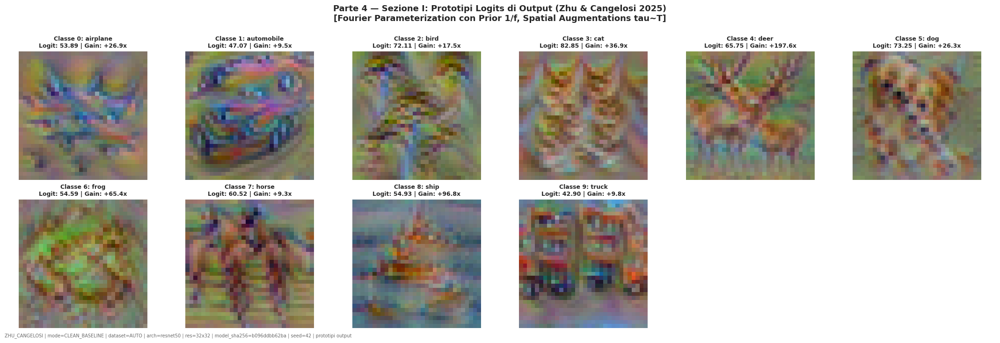


📊 Output Prototypes Diagnostic Table:
       Class Final Logit Activation Gain TV Energy
  0: airplane       53.889         +26.93x    1281.4
1: automobile       47.069          +9.53x    1725.7
      2: bird       72.108         +17.54x    1658.9
       3: cat       82.849         +36.86x    1542.1
      4: deer       65.754        +197.59x    1459.0
       5: dog       73.252         +26.28x    1420.7
      6: frog       54.585         +65.42x    1493.2
     7: horse       60.517          +9.30x    1625.6
      8: ship       54.929         +96.81x    1228.2
     9: truck       42.904          +9.83x    1618.2

 >> Section II: Hierarchical Feature Visualization on Intermediate Layers


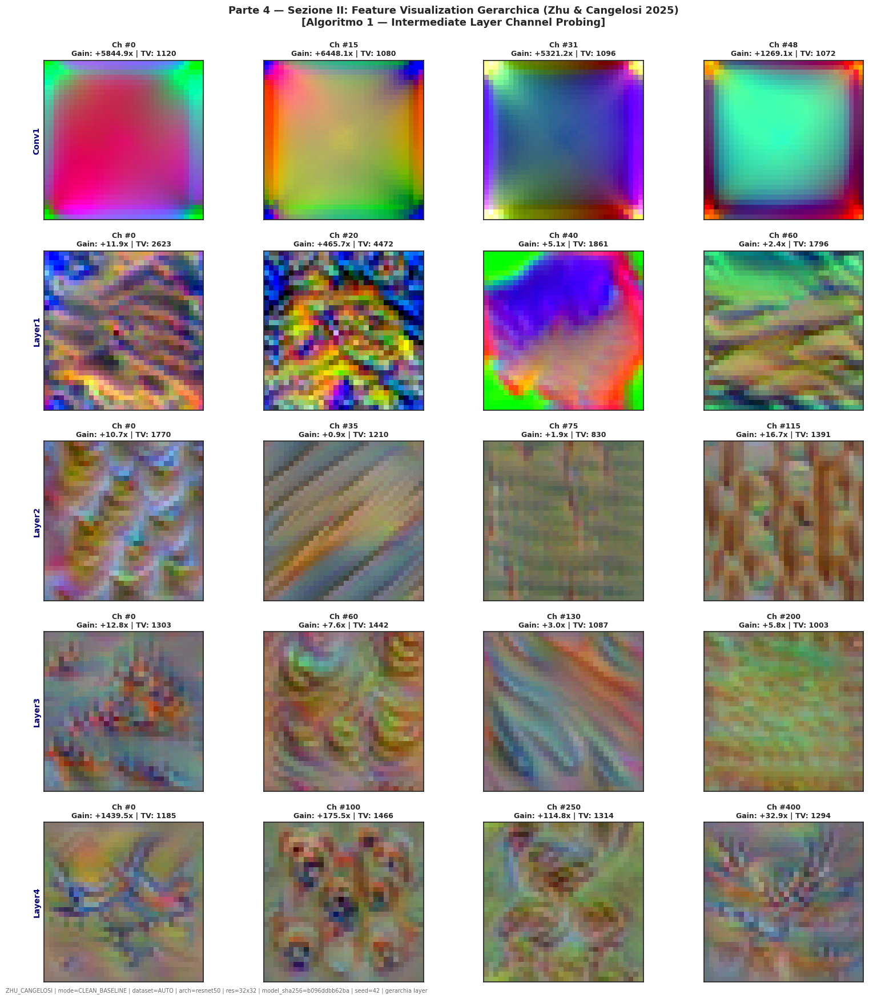


 >> Section IV: Logit-Guided Adversarial Example Generation (Section 4.4)


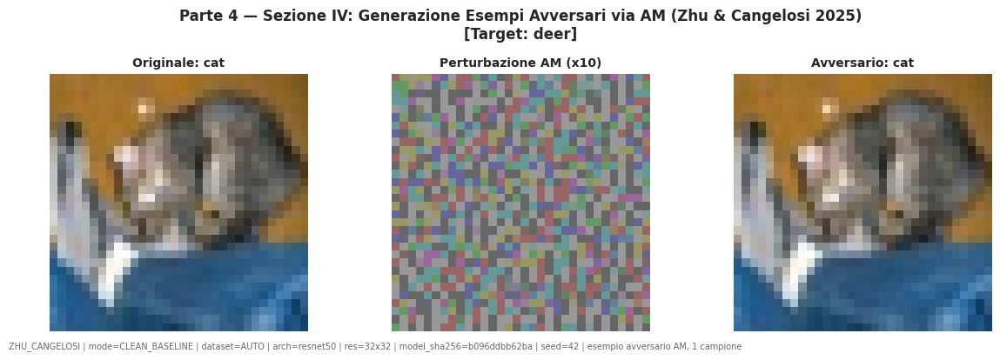


✅ PART 4 (ZHU & CANGELOSI) SUCCESSFULLY COMPLETED WITH MAXIMUM VISUAL FIDELITY


In [39]:
# ==============================================================================
# 🌀 [SECTION 17] PART 4: REPRESENTATION UNDERSTANDING VIA ACTIVATION MAXIMIZATION
# Framework Faithful to Zhu & Cangelosi (2025) — arXiv:2508.07281 (Original 1/f Formula)
# ==============================================================================


if should_run_section('ZHU_CANGELOSI'):
    clean_memory()
    import math
    from typing import Tuple, Dict, Callable, List, Optional
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt


    # -- Device & Model --
    am_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


    # Model: single resolver of the contract (before: chain with fallback TRANSFER_LEARNING=False,
    # strict=False and NUM_CLASSES=43 by default). No global freezing of the parameters.
    am_net = get_audit_model()
    am_net.eval()


    # Resolution, classes and normalization from the model context (local names zhu_*: the am_* globals
    # of the AM section are not overwritten with different values)
    _zhu_ctx = get_model_eval_context(am_net, device=am_device)
    zhu_mean = np.array(_zhu_ctx["mean"], dtype=np.float32)
    zhu_std = np.array(_zhu_ctx["std"], dtype=np.float32)
    zhu_img_size = (_zhu_ctx["target_res"], _zhu_ctx["target_res"])
    zhu_num_classes = int(globals().get("NUM_CLASSES", get_classifier_info(am_net)[0].out_features))
    if "CLASS_NAMES" in globals() and CLASS_NAMES is not None:
        am_classes = CLASS_NAMES
    elif "am_classes" in globals() and am_classes is not None:
        pass
    else:
        am_classes = [f"Class_{i}" for i in range(zhu_num_classes)]
    _zhu_seed = int(globals().get("SEED", 42))
    zhu_target_label = int(TARGET_LABEL) if (oracle_allowed() and "TARGET_LABEL" in globals() and TARGET_LABEL is not None and int(TARGET_LABEL) >= 0) else None


    print("\n" + "=" * 95)
    print("🌀 PART 4: REPRESENTATION UNDERSTANDING VIA ACTIVATION MAXIMIZATION")
    print("   (Framework Faithful to Zhu & Cangelosi, 2025 — arXiv:2508.07281)")
    print(f"   Resolution: {zhu_img_size} | Classes: {len(am_classes)} | Device: {am_device}")
    print("=" * 95)


    # ------------------------------------------------------------------------------
    # 1. ORIGINAL FOURIER PARAMETERIZATION WITH NATURAL 1/f PRIOR (Zhu & Cangelosi)
    # ------------------------------------------------------------------------------
    # Definition shared with the AM section (setup cell): redefined only if absent.
    if getattr(globals().get("FourierStimulus"), "FS_VERSION", 0) < 2:
        class FourierStimulus(nn.Module):
            FS_VERSION = 2

            def __init__(self, shape=(1, 3, 32, 32), device="cpu", generator=None):
                super().__init__()
                B, C, H, W = shape
                self.H, self.W = H, W
                spec_w = W // 2 + 1
                self.real = nn.Parameter((torch.randn(B, C, H, spec_w, generator=generator) * 0.01).to(device))
                self.imag = nn.Parameter((torch.randn(B, C, H, spec_w, generator=generator) * 0.01).to(device))

                freq_h = np.fft.fftfreq(H)[:, None]
                freq_w = np.fft.rfftfreq(W)[None, :]
                freq_dist = np.sqrt(freq_h**2 + freq_w**2)
                scale = 1.0 / np.maximum(freq_dist, 1.0 / max(H, W))
                self.register_buffer("scale", torch.from_numpy(scale).float().to(device))

            def forward(self):
                z = torch.complex(self.real * self.scale, self.imag * self.scale)
                return torch.fft.irfftn(z, s=(self.H, self.W), dim=(2, 3))


    def zhu_denormalize(tensor_img: torch.Tensor) -> np.ndarray:
        with torch.no_grad():
            img = tensor_img.squeeze().cpu().numpy()
            if img.ndim == 3 and img.shape[0] in [1, 3]:
                img = np.transpose(img, (1, 2, 0))
            if img.min() < 0.0 or img.max() > 1.0:
                img = zhu_std * img + zhu_mean
            return np.clip(img, 0.0, 1.0)


    # ------------------------------------------------------------------------------
    # 2. RANDOM SPATIAL TRANSFORMS T (Jitter, Scale, Rotate) — Algorithm 1
    # ------------------------------------------------------------------------------
    def apply_paper_transformations(
        x_img: torch.Tensor,
        jitter: int = 2,
        scale_range: Tuple[float, float] = (0.95, 1.05),
        max_angle: float = 5.0,
        gen: Optional[torch.Generator] = None,
    ) -> torch.Tensor:
        B, C, H, W = x_img.shape
        if jitter > 0:
            sx = torch.randint(-jitter, jitter + 1, (1,), generator=gen).item()
            sy = torch.randint(-jitter, jitter + 1, (1,), generator=gen).item()
            x_img = torch.roll(x_img, shifts=(sy, sx), dims=(2, 3))


        angle = (torch.rand(1, generator=gen).item() * 2 - 1) * max_angle
        scale = scale_range[0] + torch.rand(1, generator=gen).item() * (scale_range[1] - scale_range[0])
        angle_rad = np.radians(angle)
        cos_a, sin_a = np.cos(angle_rad), np.sin(angle_rad)
        mat = (
            torch.tensor(
                [[cos_a / scale, -sin_a / scale, 0.0], [sin_a / scale, cos_a / scale, 0.0]],
                device=x_img.device,
                dtype=torch.float32,
            )
            .unsqueeze(0)
            .repeat(B, 1, 1)
        )
        grid = F.affine_grid(mat, x_img.size(), align_corners=False)
        return F.grid_sample(x_img, grid, align_corners=False, mode="bilinear", padding_mode="reflection")


    # ------------------------------------------------------------------------------
    # 3. RIGOROUS SYNTHESIZER ACCORDING TO ALGORITHM 1
    # ------------------------------------------------------------------------------
    def am_synthesize_zhu_cangelosi(
        target_fn: Callable[[torch.Tensor], torch.Tensor],
        num_steps: int = 500, # 500 optimal steps for accurate and fast convergence
        lr: float = 0.05,
        img_size: Tuple[int, int] = zhu_img_size,
        apply_aug: bool = True,
        seed: int = 42,
    ) -> Tuple[np.ndarray, Dict[str, float]]:
        # Local RNG (before: global torch.manual_seed) and weight freezing only during synthesis
        gen = torch.Generator().manual_seed(int(seed))
        with preserve_model_state(am_net):
            for p in am_net.parameters():
                p.requires_grad_(False)
            param_img = FourierStimulus((1, 3, *img_size), device=am_device, generator=gen)
            optimizer = torch.optim.Adam(param_img.parameters(), lr=lr)


            init_score = 0.0
            final_score = 0.0


            for step in range(num_steps):
                optimizer.zero_grad(set_to_none=True)
                x_raw = param_img()
                x_i = apply_paper_transformations(x_raw, jitter=2, scale_range=(0.95, 1.05), max_angle=5.0, gen=gen) if apply_aug else x_raw


                score = target_fn(x_i)
                if step == 0:
                    init_score = score.item()
                if step == num_steps - 1:
                    final_score = score.item()


                loss = -score
                loss.backward()
                optimizer.step()


            with torch.no_grad():
                x_final = param_img()
                diff_h = torch.sum(torch.abs(x_final[:, :, 1:, :] - x_final[:, :, :-1, :]))
                diff_w = torch.sum(torch.abs(x_final[:, :, :, 1:] - x_final[:, :, :, :-1]))
                tv_energy = (diff_h + diff_w).item()


                stats = {
                    "initial_activation": init_score,
                    "final_activation": final_score,
                    "activation_gain": (final_score - init_score) / abs(init_score) if init_score != 0 else float("nan"),
                    "tv_energy": tv_energy,
                }


        return zhu_denormalize(x_final), stats


    # ------------------------------------------------------------------------------
    # SECTION I: PRE-SOFTMAX OUTPUT PROTOTYPES (ALL CLASSES)
    # ------------------------------------------------------------------------------
    print(f"\n >> Section I: Output Logit Prototypes ({len(am_classes)} Classes) — Algorithm 1")


    zhu_class_results = []
    zhu_class_metrics = []


    for c_id in range(len(am_classes)):
        def make_logit_obj(target_c):
            def obj(img):
                return am_net(img)[0, target_c]
            return obj


        img_proto, st = am_synthesize_zhu_cangelosi(
            make_logit_obj(c_id), num_steps=500, lr=0.05, apply_aug=True, seed=100 + c_id
        )
        c_name = am_classes[c_id] if c_id < len(am_classes) else str(c_id)
        zhu_class_results.append((c_id, c_name, img_proto, st))
        zhu_class_metrics.append({
            "Class": f"{c_id}: {c_name}",
            "Final Logit": st["final_activation"],
            "Activation Gain": st["activation_gain"],
            "TV Energy": st["tv_energy"],
        })


    n_classes_zhu = len(zhu_class_results)
    n_cols_zhu = min(6, n_classes_zhu) if n_classes_zhu > 5 else n_classes_zhu
    n_rows_zhu = math.ceil(n_classes_zhu / n_cols_zhu)
    fig_zhu1, axes_zhu1 = plt.subplots(n_rows_zhu, n_cols_zhu, figsize=(n_cols_zhu * 3.6, n_rows_zhu * 3.6))
    fig_zhu1.text(0.01, 0.002, provenance_caption("ZHU_CANGELOSI", extra="output prototypes"), fontsize=7, alpha=0.7)
    axes_zhu1 = np.array(axes_zhu1).flatten()
    for idx, (c_id, c_name, img_proto, st) in enumerate(zhu_class_results):
        axes_zhu1[idx].imshow(img_proto)
        axes_zhu1[idx].set_title(
            f"Class {c_id}: {c_name}\nLogit: {st['final_activation']:.2f} | Gain: {st['activation_gain']:+.1f}x",
            fontsize=9,
            fontweight="bold",
        )
        axes_zhu1[idx].axis("off")


    for extra_ax in axes_zhu1[n_classes_zhu:]:
        extra_ax.axis("off")


    plt.suptitle(
        "Part 4 — Section I: Output Logit Prototypes (Zhu & Cangelosi 2025)\n"
        "[Fourier Parameterization with 1/f Prior, Spatial Augmentations tau~T]",
        fontsize=13,
        fontweight="bold",
        y=0.99,
    )
    plt.tight_layout()


    # --- SAVING fig_zhu1 (Output Prototypes) ---
    try:
        import os
        _out_dir_zhu = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "/kaggle/working"))
        os.makedirs(_out_dir_zhu, exist_ok=True)
        _att_zhu = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
        _strat_zhu = str(best_overall_config.get("strategy", "model")).lower() if "best_overall_config" in globals() and best_overall_config else "model"
        _zhu1_fname = f"zhu_prototypes_output_{_att_zhu}_{_strat_zhu}.png"
        _zhu1_path = os.path.join(_out_dir_zhu, _zhu1_fname)
        fig_zhu1.savefig(_zhu1_path, bbox_inches="tight", dpi=130)
        register_artifact("ZHU_CANGELOSI", _zhu1_path)
        globals()["ZHU_PROTO_IMG_PATH"] = _zhu1_path
        if "RUN_RESULTS" in globals() and isinstance(RUN_RESULTS, dict):
            RUN_RESULTS["zhu_proto_img"] = _zhu1_fname

        # Identification of the most suspect class for Zhu & Cangelosi
        if zhu_class_results:
            sorted_zhu_by_logit = sorted(zhu_class_results, key=lambda x: x[3]['final_activation'], reverse=True)
            zhu_s_id, zhu_s_name, _, zhu_s_st = sorted_zhu_by_logit[0]
            _zhu_note = "maximum final logit among the prototypes: exploratory indicator, no threshold or verdict"
            record_metric("zhu_suspect_class_id", int(zhu_s_id), method="AM Zhu & Cangelosi (output)", level="class", note=_zhu_note)
            record_metric("zhu_suspect_class_name", str(zhu_s_name), method="AM Zhu & Cangelosi (output)", level="class", note=_zhu_note)
            record_metric("zhu_suspect_logit", float(zhu_s_st['final_activation']), method="AM Zhu & Cangelosi (output)", level="class", unit="logit", note=_zhu_note)
            record_metric("zhu_suspect_gain", float(zhu_s_st['activation_gain']), method="AM Zhu & Cangelosi (output)", level="class", unit="ratio",
                          note="(final - initial)/|initial|, unstable if the initial activation ≈ 0")

            # Target class metrics: oracle evaluation (before: also outside the attacker modes)
            if zhu_target_label is not None and zhu_target_label < len(zhu_class_results):
                _z_st = zhu_class_results[zhu_target_label][3]
                record_metric("zhu_target_logit", float(_z_st['final_activation']), method="AM Zhu & Cangelosi, target class", level="class",
                              unit="logit", requires_ground_truth=True)
                record_metric("zhu_target_gain", float(_z_st['activation_gain']), method="AM Zhu & Cangelosi, target class", level="class",
                              unit="ratio", requires_ground_truth=True)
            else:
                for _k in ("zhu_target_logit", "zhu_target_gain"):
                    record_metric(_k, float("nan"), "not_applicable", method="AM Zhu & Cangelosi, target class", level="class",
                                  requires_ground_truth=True, note="target class not available")
            for _k in ("zhu_suspect_class_id", "zhu_suspect_class_name", "zhu_suspect_logit", "zhu_suspect_gain", "zhu_target_logit", "zhu_target_gain"):
                globals()[_k] = RUN_RESULTS[_k]
    except Exception as _e_zhu1:
        print(f"[ZHU SAVE WARNING] Output prototypes: {_e_zhu1}")
    plt.show()


    df_zhu_class = pd.DataFrame(zhu_class_metrics)
    print("\n📊 Output Prototypes Diagnostic Table:")
    print(df_zhu_class.to_string(index=False, formatters={
        "Final Logit": "{:.3f}".format,
        "Activation Gain": "{:+.2f}x".format,
        "TV Energy": "{:.1f}".format,
    }))


    # ------------------------------------------------------------------------------
    # SECTION II: HIERARCHICAL FEATURE VISUALIZATION ON INTERMEDIATE LAYERS
    # ------------------------------------------------------------------------------
    print("\n >> Section II: Hierarchical Feature Visualization on Intermediate Layers")


    zhu_layer_specs = [
        ("Conv1", getattr(am_net, "conv1", None), [0, 15, 31, 48], "Oriented edges & pure colors"),
        ("Layer1", getattr(am_net, "layer1", None), [0, 20, 40, 60], "Micro-Texture & frequencies"),
        ("Layer2", getattr(am_net, "layer2", None), [0, 35, 75, 115], "Intermediate geometries"),
        ("Layer3", getattr(am_net, "layer3", None), [0, 60, 130, 200], "Components and shapes"),
        ("Layer4", getattr(am_net, "layer4", None), [0, 100, 250, 400], "Final Global Semantics"),
    ]


    zhu_hierarchy_results = []
    zhu_hierarchy_metrics = []


    def _zhu_out_channels(mod):
        # Output channels of the module (last BN/Conv): illustrative channels beyond the limit are skipped
        for m in reversed(list(mod.modules())):
            if isinstance(m, nn.BatchNorm2d):
                return m.num_features
            if isinstance(m, nn.Conv2d):
                return m.out_channels
        return None


    _zhu_rows = [x for x in zhu_layer_specs if x[1] is not None]
    for row_i, (l_title, l_mod, channels, l_desc) in enumerate(_zhu_rows):
        _n_out = _zhu_out_channels(l_mod)
        for col_i, ch in enumerate(channels):
            if _n_out is not None and ch >= _n_out:
                print(f"   ⏭️ {l_title}: channel {ch} does not exist ({_n_out} channels), skipped")
                continue
            container = []
            hook = l_mod.register_forward_hook(lambda m, i, o, c=container: c.append(o))


            def make_channel_obj(channel_idx, cont):
                def obj_fn(img):
                    cont.clear()
                    _ = am_net(img)
                    return cont[0][0, channel_idx].mean()
                return obj_fn


            try:
                img_stim, st = am_synthesize_zhu_cangelosi(
                    make_channel_obj(ch, container),
                    num_steps=350,
                    lr=0.05,
                    apply_aug=True,
                    seed=200 + ch,
                )
            finally:
                hook.remove()


            zhu_hierarchy_results.append((l_title, ch, img_stim, st, l_desc, row_i, col_i))
            zhu_hierarchy_metrics.append({
                "Layer": l_title,
                "Channel": ch,
                "Description": l_desc,
                "Final Activation": st["final_activation"],
                "Gain Ratio": st["activation_gain"],
                "TV Complexity": st["tv_energy"],
            })


    fig_zhu2, axes_zhu2 = plt.subplots(len(_zhu_rows), 4, figsize=(16, 3.5 * len(_zhu_rows)), squeeze=False)
    for ax in axes_zhu2.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
    for (l_title, ch, img_stim, st, l_desc, row, col) in zhu_hierarchy_results:
        ax = axes_zhu2[row, col]
        ax.imshow(img_stim)
        ax.set_title(f"Ch #{ch}\nGain: {st['activation_gain']:+.1f}x | TV: {st['tv_energy']:.0f}", fontsize=9, fontweight="bold")
        if col == 0:
            ax.set_ylabel(f"{l_title}", fontsize=10, color="navy", fontweight="bold")
        ax.set_xticks([])
        ax.set_yticks([])


    fig_zhu2.text(0.01, 0.002, provenance_caption("ZHU_CANGELOSI", extra="layer hierarchy"), fontsize=7, alpha=0.7)
    plt.suptitle(
        "Part 4 — Section II: Hierarchical Feature Visualization (Zhu & Cangelosi 2025)\n"
        "[Algorithm 1 — Intermediate Layer Channel Probing]",
        fontsize=13, fontweight="bold", y=0.99
    )
    plt.tight_layout()


    # --- SAVING fig_zhu2 (Hierarchical Feature Visualization) ---
    try:
        import os
        _out_dir_zhu = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "/kaggle/working"))
        os.makedirs(_out_dir_zhu, exist_ok=True)
        _att_zhu = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
        _strat_zhu = str(best_overall_config.get("strategy", "model")).lower() if "best_overall_config" in globals() and best_overall_config else "model"
        _zhu2_fname = f"zhu_feature_hierarchy_{_att_zhu}_{_strat_zhu}.png"
        _zhu2_path = os.path.join(_out_dir_zhu, _zhu2_fname)
        fig_zhu2.savefig(_zhu2_path, bbox_inches="tight", dpi=130)
        register_artifact("ZHU_CANGELOSI", _zhu2_path)
        globals()["ZHU_HIERARCHY_IMG_PATH"] = _zhu2_path
        if "RUN_RESULTS" in globals() and isinstance(RUN_RESULTS, dict):
            RUN_RESULTS["zhu_hierarchy_img"] = _zhu2_fname
    except Exception as _e_zhu2:
        print(f"[ZHU SAVE WARNING] Feature hierarchy: {_e_zhu2}")
    plt.show()


    # ------------------------------------------------------------------------------
    # SECTION IV: GENERATION OF ADVERSARIAL EXAMPLES VIA AM (Section 4.4 of the Paper)
    # ------------------------------------------------------------------------------
    print("\n >> Section IV: Logit-Guided Adversarial Example Generation (Section 4.4)")


    def generate_am_adversarial_example(
        model: nn.Module,
        x_orig: torch.Tensor,
        target_class: int,
        epsilon: float = 0.01,
        alpha: float = 0.01,
        lambda_tv: float = 1e-4,
        steps: int = 30,
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        # ε and α in units of the normalized space (≈ ε·std in pixels); the image is constrained to the
        # valid pixel range [0,1] mapped to the per-channel normalized space (before: fixed clamp ±2.5).
        _lo = torch.tensor((0.0 - zhu_mean) / zhu_std, dtype=x_orig.dtype, device=x_orig.device).view(1, -1, 1, 1)
        _hi = torch.tensor((1.0 - zhu_mean) / zhu_std, dtype=x_orig.dtype, device=x_orig.device).view(1, -1, 1, 1)
        model.eval()
        x_adv = x_orig.clone().detach().requires_grad_(True)
        with preserve_model_state(model):
            for p in model.parameters():
                p.requires_grad_(False)
            for step in range(steps):
                if x_adv.grad is not None:
                    x_adv.grad.zero_()
                logits = model(x_adv)
                logit_target = logits[0, target_class]


                delta = x_adv - x_orig
                diff_h = torch.sum(torch.abs(delta[:, :, 1:, :] - delta[:, :, :-1, :]))
                diff_w = torch.sum(torch.abs(delta[:, :, :, 1:] - delta[:, :, :, :-1]))
                loss_tv = diff_h + diff_w


                objective = logit_target - lambda_tv * loss_tv
                objective.backward()


                with torch.no_grad():
                    grad_sign = x_adv.grad.sign()
                    x_adv += alpha * grad_sign
                    delta_clipped = torch.clamp(x_adv - x_orig, min=-epsilon, max=epsilon)
                    x_adv = torch.max(torch.min(x_orig + delta_clipped, _hi), _lo)
                x_adv.requires_grad_(True)


        perturbation = (x_adv - x_orig).detach()
        return x_adv.detach(), perturbation


    # Sample for the adversarial test
    fig_adv = None
    sample_src = None
    if 'clean_test_dataset' in globals() and clean_test_dataset is not None:
        sample_src = clean_test_dataset
    elif 'raw_test_dataset' in globals() and raw_test_dataset is not None:
        sample_src = raw_test_dataset
    elif 'test_loader' in globals() and test_loader is not None:
        sample_src = test_loader.dataset


    if sample_src is not None:
        item = sample_src[0]
        raw_x = item[0] if isinstance(item, (tuple, list)) else item
        orig_label = item[1] if isinstance(item, (tuple, list)) and len(item) > 1 else 0


        if isinstance(raw_x, torch.Tensor):
            x_sample = raw_x.unsqueeze(0).to(am_device)
            if x_sample.shape[-1] != zhu_img_size[0]:
                x_sample = F.interpolate(x_sample, size=zhu_img_size, mode='bilinear', align_corners=False)
        else:
            from PIL import Image
            from torchvision import transforms
            tf = transforms.Compose([
                transforms.Resize(zhu_img_size),
                transforms.ToTensor(),
                transforms.Normalize(mean=zhu_mean.tolist(), std=zhu_std.tolist())
            ])
            x_sample = tf(raw_x if isinstance(raw_x, Image.Image) else Image.fromarray(raw_x)).unsqueeze(0).to(am_device)


        with torch.no_grad():
            pred_orig = torch.argmax(am_net(x_sample), dim=1).item()
        adv_target = (pred_orig + 1) % len(am_classes)


        x_adv_sample, delta = generate_am_adversarial_example(am_net, x_sample, target_class=adv_target, steps=30)
        with torch.no_grad():
            pred_adv = torch.argmax(am_net(x_adv_sample), dim=1).item()


        orig_name_str = am_classes[orig_label] if orig_label < len(am_classes) else str(orig_label)
        adv_target_str = am_classes[adv_target] if adv_target < len(am_classes) else str(adv_target)
        pred_orig_str = am_classes[pred_orig] if pred_orig < len(am_classes) else str(pred_orig)
        pred_adv_str = am_classes[pred_adv] if pred_adv < len(am_classes) else str(pred_adv)


        fig_adv, axes_adv = plt.subplots(1, 3, figsize=(12, 4))
        axes_adv[0].imshow(zhu_denormalize(x_sample))
        axes_adv[0].set_title(f"Original: {pred_orig_str}", fontsize=10, fontweight="bold")
        axes_adv[0].axis("off")


        pert_np = delta.squeeze().cpu().permute(1, 2, 0).numpy()
        pert_np = np.clip((pert_np * 10) + 0.5, 0.0, 1.0)
        axes_adv[1].imshow(pert_np)
        axes_adv[1].set_title("AM Perturbation (x10)", fontsize=10, fontweight="bold")
        axes_adv[1].axis("off")


        axes_adv[2].imshow(zhu_denormalize(x_adv_sample))
        axes_adv[2].set_title(f"Adversarial: {pred_adv_str}", fontsize=10, fontweight="bold")
        axes_adv[2].axis("off")


        plt.suptitle(
            "Part 4 — Section IV: Adversarial Example Generation via AM (Zhu & Cangelosi 2025)\n"
            f"[Target: {adv_target_str}]",
            fontsize=12, fontweight="bold"
        )
        fig_adv.text(0.01, 0.002, provenance_caption("ZHU_CANGELOSI", extra="AM adversarial example, 1 sample"), fontsize=7, alpha=0.7)
        plt.tight_layout()


    # --- SAVING fig_adv (AM Adversarial Examples) + Metric ---
    if fig_adv is None:
        # Before: NameError on fig_adv (undefined without a dataset) masked by the try/except
        print("⏭️ [ZHU] No dataset available: Section IV not run.")
        record_metric("zhu_adv_transfer_success", float("nan"), "not_applicable", method="targeted adversarial AM (Zhu & Cangelosi §4.4)",
                      level="sample", note="no sample available (e.g. MODEL_ONLY)")
    else:
        try:
            import os
            _out_dir_zhu = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "/kaggle/working"))
            os.makedirs(_out_dir_zhu, exist_ok=True)
            _att_zhu = str(POISONING_CONFIG.get("attack_type", "dirty")).lower() if "POISONING_CONFIG" in globals() else "dirty"
            _strat_zhu = str(_zhu_ctx["strategy"]).lower()
            _adv_fname = f"zhu_adversarial_am_{_att_zhu}_{_strat_zhu}.png"
            _adv_path = os.path.join(_out_dir_zhu, _adv_fname)
            fig_adv.savefig(_adv_path, bbox_inches="tight", dpi=130)
            register_artifact("ZHU_CANGELOSI", _adv_path)
            globals()["ZHU_ADV_IMG_PATH"] = _adv_path
            RUN_RESULTS["zhu_adv_img"] = _adv_fname
        except Exception as _e_adv:
            print(f"[ZHU SAVE WARNING] Adversarial: {_e_adv}")
        # Success of the targeted attack (pred -> pred+1) on ONE sample: not a measure of transferability
        record_metric("zhu_adv_transfer_success", int(pred_adv == adv_target), method="targeted adversarial AM (Zhu & Cangelosi §4.4)",
                      level="sample", note=f"1 sample, {pred_orig_str} -> {adv_target_str}; ε=0.01 in normalized space, 30 steps")
        globals()["zhu_adv_transfer_success"] = RUN_RESULTS["zhu_adv_transfer_success"]
        plt.show()


    check_model_integrity("ZHU_CANGELOSI")
    print("\n" + "=" * 95)
    print("✅ PART 4 (ZHU & CANGELOSI) SUCCESSFULLY COMPLETED WITH MAXIMUM VISUAL FIDELITY")
    print("=" * 95)


    clean_memory(verbose=False)


In [40]:
# ==============================================================================
# 🌀 [SECTION 17 - PART B] CLASS-GUIDED LAYER ACTIVATION MAXIMIZATION
# Robust Channel Ranking + Hybrid Synthesis (Immediate Print & Plot)
# ==============================================================================

if should_run_section('ZHU_CANGELOSI_PIP'):
    clean_memory()
    import os, gc, math, sys
    from typing import List, Tuple, Dict, Optional
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    # ------------------------------------------------------------------------------
    # 0. ENVIRONMENT, MODEL & RESOLUTION SETUP
    # ------------------------------------------------------------------------------
    am_device = globals().get("am_device", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

    # Model: single resolver of the contract, in a local variable (before: it overwrote the global
    # `eval_model` by resolving `am_net` first, and reloaded the checkpoint with strict=False).
    cg_net = get_audit_model()
    cg_net.eval()

    # Resolution and normalization statistics from the model context (before: fixed GTSRB statistics)
    _cg_ctx = get_model_eval_context(cg_net, device=am_device)
    norm_mean = np.array(_cg_ctx["mean"], dtype=np.float32)
    norm_std = np.array(_cg_ctx["std"], dtype=np.float32)
    target_res = int(_cg_ctx["target_res"])

    cg_num_classes = int(globals().get("NUM_CLASSES", get_classifier_info(cg_net)[0].out_features))
    if "CLASS_NAMES" in globals() and CLASS_NAMES is not None:
        class_names_to_show = CLASS_NAMES
    elif "am_classes" in globals() and am_classes is not None:
        class_names_to_show = am_classes
    else:
        class_names_to_show = [f"Class_{i}" for i in range(cg_num_classes)]
    CGAM_MIN_CLASS_SAMPLES = int(globals().get("CGAM_MIN_CLASS_SAMPLES", 16))
    CGAM_RANK_BY = str(globals().get("CGAM_RANK_BY", "selectivity"))   # 'selectivity' | 'mean'

    # Identification of the target convolutional Layer
    def get_target_am_layer(model: nn.Module) -> Tuple[nn.Module, str]:
        if hasattr(model, "layer4") and model.layer4 is not None:
            return model.layer4, "layer4"
        elif hasattr(model, "layer3") and model.layer3 is not None:
            return model.layer3, "layer3"
        elif hasattr(model, "features") and model.features is not None:
            return model.features, "features"
        convs = [m for m in model.modules() if isinstance(m, nn.Conv2d)]
        if convs:
            return convs[-1], "conv_final"
        return list(model.children())[-2], "penultimate"

    target_layer_mod, target_layer_name = get_target_am_layer(cg_net)

    print("\n" + "=" * 95, flush=True)
    print("🌀 CLASS-GUIDED LAYER ACTIVATION MAXIMIZATION (ROBUST & INSTANT PRINT)", flush=True)
    print(f"🎯 Target Layer: {target_layer_name} ({target_layer_mod.__class__.__name__}) | Resolution: {target_res}x{target_res} | Classes: {len(class_names_to_show)}", flush=True)
    print("=" * 95, flush=True)

    # Explicit CLEAN loader (excluding `audit_loader`, which may be a poisoned leftover from other cells)
    src_loader = None
    for _cand in ["clean_test_loader", "test_loader", "clean_loader"]:
        if _cand in globals() and globals()[_cand] is not None:
            src_loader = globals()[_cand]
            break

    # ------------------------------------------------------------------------------
    # 1. ORIGINAL FOURIER 1/f PARAMETERIZER
    # ------------------------------------------------------------------------------
    # Definition shared with the AM section (setup cell): redefined only if absent.
    if getattr(globals().get("FourierStimulus"), "FS_VERSION", 0) < 2:
        class FourierStimulus(nn.Module):
            FS_VERSION = 2

            def __init__(self, shape=(1, 3, 32, 32), device="cpu", generator=None):
                super().__init__()
                B, C, H, W = shape
                self.H, self.W = H, W
                spec_w = W // 2 + 1
                self.real = nn.Parameter((torch.randn(B, C, H, spec_w, generator=generator) * 0.01).to(device))
                self.imag = nn.Parameter((torch.randn(B, C, H, spec_w, generator=generator) * 0.01).to(device))

                freq_h = np.fft.fftfreq(H)[:, None]
                freq_w = np.fft.rfftfreq(W)[None, :]
                freq_dist = np.sqrt(freq_h**2 + freq_w**2)
                scale = 1.0 / np.maximum(freq_dist, 1.0 / max(H, W))
                self.register_buffer("scale", torch.from_numpy(scale).float().to(device))

            def forward(self):
                z = torch.complex(self.real * self.scale, self.imag * self.scale)
                return torch.fft.irfftn(z, s=(self.H, self.W), dim=(2, 3))

    def am_denorm(tensor_img: torch.Tensor) -> np.ndarray:
        with torch.no_grad():
            img = tensor_img.squeeze().cpu().numpy()
            if img.ndim == 3 and img.shape[0] in [1, 3]:
                img = np.transpose(img, (1, 2, 0))
            img = norm_std * img + norm_mean
            return np.clip(img, 0.0, 1.0)

    def apply_aug(x_img: torch.Tensor, jitter: int = 2, gen: Optional[torch.Generator] = None) -> torch.Tensor:
        if jitter > 0:
            sx = torch.randint(-jitter, jitter + 1, (1,), generator=gen).item()
            sy = torch.randint(-jitter, jitter + 1, (1,), generator=gen).item()
            x_img = torch.roll(x_img, shifts=(sy, sx), dims=(2, 3))
        return x_img

    def synthesize_objective(obj_fn, num_steps=250, lr=0.08, seed=42):
        # Local RNG and weights frozen only during synthesis (state restored on exit)
        gen = torch.Generator().manual_seed(int(seed))
        with preserve_model_state(cg_net):
            for p in cg_net.parameters():
                p.requires_grad_(False)
            param_img = FourierStimulus((1, 3, target_res, target_res), device=am_device, generator=gen)
            optimizer = torch.optim.Adam(param_img.parameters(), lr=lr)
            init_score = 0.0
            final_score = 0.0

            for step in range(num_steps):
                optimizer.zero_grad(set_to_none=True)
                x_raw = param_img()
                x_i = apply_aug(x_raw, jitter=2, gen=gen)
                score = obj_fn(x_i)

                if step == 0:
                    init_score = score.item()
                if step == num_steps - 1:
                    final_score = score.item()

                loss = -score
                loss.backward()
                optimizer.step()

            with torch.no_grad():
                x_final = param_img()
                diff_h = torch.sum(torch.abs(x_final[:, :, 1:, :] - x_final[:, :, :-1, :]))
                diff_w = torch.sum(torch.abs(x_final[:, :, :, 1:] - x_final[:, :, :, :-1]))
                stats = {
                    "initial_activation": init_score,
                    "final_activation": final_score,
                    "activation_gain": (final_score - init_score) / abs(init_score) if init_score != 0 else float("nan"),
                    "tv_energy": (diff_h + diff_w).item()
                }
        return am_denorm(x_final), stats

    # ------------------------------------------------------------------------------
    # 2. ROBUST CHANNEL SELECTION (NO CRASH)
    # ------------------------------------------------------------------------------
    def get_top_channels_for_class(model: nn.Module, layer_mod: nn.Module, target_c: int, loader, top_k: int = 3) -> List[Tuple[int, float, float]]:
        """
        Channels of `layer_mod` most SELECTIVE for the class: d' = (μ_class − μ_others) / sqrt((σ²_class + σ²_others)/2)
        on the spatial mean activations (before, the ranking used the mean activation alone, and the printed
        "selectivity" did not enter the choice). No fictitious channels: without a loader or without samples of the class
        it returns an empty list (before: channels 0..k-1 with invented scores).
        """
        model.eval()
        if loader is None:
            return []

        act_container = []
        hook = layer_mod.register_forward_hook(lambda m, i, o: act_container.append(o.detach()))

        target_acts = []
        non_target_acts = []
        seen_target = 0

        try:
            with torch.no_grad():
                for batch in loader:
                    x_b = batch[0] if isinstance(batch, (tuple, list)) else batch
                    y_b = batch[1] if isinstance(batch, (tuple, list)) and len(batch) > 1 else None

                    x_b = x_b.to(am_device)
                    if x_b.shape[-1] != target_res:
                        x_b = F.interpolate(x_b, size=(target_res, target_res), mode='bilinear', align_corners=False)

                    act_container.clear()
                    logits = model(x_b)

                    if not act_container:
                        continue

                    act = act_container[0] # (B, C, H, W)
                    act_mean = act.mean(dim=(2, 3)) # (B, C)

                    # If there are no ground-truth labels, use the model's prediction
                    if y_b is None or (y_b == -1).all():
                        pred_y = torch.argmax(logits, dim=1)
                        t_mask = (pred_y == target_c)
                    else:
                        y_b = y_b.to(am_device)
                        t_mask = (y_b == target_c)

                    nt_mask = ~t_mask

                    if t_mask.any():
                        target_acts.append(act_mean[t_mask].cpu())
                        seen_target += t_mask.sum().item()
                    if nt_mask.any():
                        non_target_acts.append(act_mean[nt_mask].cpu())

                    if seen_target >= CGAM_MIN_CLASS_SAMPLES:
                        break
        finally:
            hook.remove()

        if not target_acts or not non_target_acts:
            return []
        A_t = torch.cat(target_acts, dim=0).numpy()
        A_nt = torch.cat(non_target_acts, dim=0).numpy()
        mean_t, mean_nt = A_t.mean(axis=0), A_nt.mean(axis=0)
        pooled = np.sqrt((A_t.var(axis=0) + A_nt.var(axis=0)) / 2.0)
        selectivity = np.where(pooled > 0, (mean_t - mean_nt) / np.where(pooled > 0, pooled, 1.0), np.nan)
        rank_score = selectivity if CGAM_RANK_BY == "selectivity" else mean_t
        valid = np.where(np.isfinite(rank_score))[0]
        sorted_idx = valid[np.argsort(-rank_score[valid])][:top_k]
        return [(int(idx), float(mean_t[idx]), float(selectivity[idx])) for idx in sorted_idx]

    # ------------------------------------------------------------------------------
    # 3. EXECUTION WITH IMMEDIATE PRINT AND PLOT
    # ------------------------------------------------------------------------------
    total_classes = len(class_names_to_show)
    top_k_channels = 3
    all_results = {}

    print(f"\n🚀 Starting hybrid scan over {total_classes} classes (Immediate Print per Class):", flush=True)

    for c_idx in range(total_classes):
        c_name = class_names_to_show[c_idx] if c_idx < len(class_names_to_show) else str(c_idx)
        print(f"\n" + "-" * 70, flush=True)
        print(f"▶️ [{c_idx+1}/{total_classes}] Processing Class #{c_idx}: '{c_name}'", flush=True)

        # 1. Top channels for the class
        top_channels = get_top_channels_for_class(cg_net, target_layer_mod, c_idx, src_loader, top_k=top_k_channels)
        if not top_channels:
            print(f"   ⚠️ No samples of the class (or loader missing): channel selection 'insufficient_data'", flush=True)
        for rank, (ch_idx, rel, sel) in enumerate(top_channels, 1):
            print(f"   • Top #{rank} Channel #{ch_idx} | Mean Activation: {rel:.4f} | Selectivity d': {sel:+.2f}", flush=True)

        # 2. Global Prototype of the Class
        def class_obj(img):
            return cg_net(img)[0, c_idx]

        img_class_proto, class_stats = synthesize_objective(class_obj, num_steps=250, lr=0.08, seed=100 + c_idx)
        print(f"   ✓ Logit Prototype: {class_stats['final_activation']:.2f} | Gain: {class_stats['activation_gain']:+.1f}x | TV: {class_stats['tv_energy']:.1f}", flush=True)

        # 3. AM on the individual Top-K channels
        channel_results = []
        for rank, (ch_idx, rel, sel) in enumerate(top_channels, 1):
            container = []
            hook = target_layer_mod.register_forward_hook(lambda m, i, o, c=container: c.append(o))

            def make_ch_obj(c_i, cont):
                def obj(img):
                    cont.clear()
                    _ = cg_net(img)
                    act = cont[0][0, c_i]
                    return F.softplus(act).mean()
                return obj

            try:
                img_ch, ch_stats = synthesize_objective(
                    make_ch_obj(ch_idx, container),
                    num_steps=250, lr=0.08, seed=300 + c_idx * top_k_channels + rank
                )
            finally:
                hook.remove()

            channel_results.append({
                "channel_idx": ch_idx,
                "relevance": rel,
                "selectivity": sel,
                "image": img_ch,
                "stats": ch_stats
            })

        # 4. Immediate Graphical Visualization for the current class
        n_panels = 1 + len(channel_results)
        fig_cg, axes = plt.subplots(1, n_panels, figsize=(3.8 * n_panels, 3.5))
        if n_panels == 1:
            axes = [axes]

        axes[0].imshow(img_class_proto)
        axes[0].set_title(
            f"CLASS PROTOTYPE #{c_idx}\n'{c_name}'\nLogit: {class_stats['final_activation']:.2f} | Gain: {class_stats['activation_gain']:+.1f}x",
            fontsize=9, fontweight="bold", color="darkblue"
        )
        axes[0].axis("off")

        for idx, ch_data in enumerate(channel_results, start=1):
            axes[idx].imshow(ch_data["image"])
            axes[idx].set_title(
                f"CHANNEL #{ch_data['channel_idx']} ({target_layer_name})\nActiv: {ch_data['relevance']:.3f} | d': {ch_data['selectivity']:+.2f}\nGain: {ch_data['stats']['activation_gain']:+.1f}x",
                fontsize=9, fontweight="bold", color="darkgreen"
            )
            axes[idx].axis("off")

        plt.suptitle(f"Class-Guided Hybrid AM — '{c_name}' (Class {c_idx})", fontsize=11, fontweight="bold", y=0.98)
        plt.tight_layout()
        plt.show() # Show the figure immediately
        plt.close(fig_cg) # Free graphics memory

        all_results[c_idx] = {
            "class_idx": c_idx,
            "class_name": c_name,
            "class_prototype": img_class_proto,
            "class_stats": class_stats,
            "top_channels": top_channels,
            "channel_results": channel_results
        }

    record_entities("CLASS_GUIDED_AM", "channel", [
        {"entity_id": f"{target_layer_name}#{ch}@{c}", "class_id": int(c), "class_name": str(r["class_name"]), "layer": target_layer_name,
         "channel": int(ch), "rank": k + 1, "score": float(sel) if np.isfinite(sel) else None,
         "note": f"selectivity d' (ranking: {CGAM_RANK_BY}); mean activation={rel:.4f}"}
        for c, r in all_results.items() for k, (ch, rel, sel) in enumerate(r["top_channels"])
    ])
    check_model_integrity("ZHU_CANGELOSI_PIP")

    print("\n" + "=" * 95, flush=True)
    print("✅ CLASS-GUIDED HYBRID AM SCAN COMPLETED", flush=True)
    print("=" * 95, flush=True)

    clean_memory(verbose=False)





⏭️ [SKIP] Section 'ZHU_CANGELOSI_PIP' not included in the active mode (CLEAN_BASELINE).


---
## 📐 18. UCLC — Lipschitz


🛡️ [CLC / UCLC ANALYSIS] DATA-FREE PROFILING OF THE CONVOLUTIONAL WEIGHTS
📌 Source model: training:/kaggle/working/best_model_grid_search.pth
🔐 Model SHA256 fingerprint: b096ddbb62ba83b409aab93967f005dcb4707e9e1303d266ac9e45616c4fd6bc
🏷️ Architecture class: ResNet | u=3 | dead channel tol.=1e-06
📏 Conv2d analyzed: 53 | Conv-BN fused: 53 | without BN: 0 | association from fx graph: 53 | by name (heuristic): 0

🔍 Convolutional layers analyzed: 53

📊 [CLC / UCLC REPORT] SCORE PER CHANNEL (Algorithm 1, u=3)
           Layer Name  Total Channels  Dead Channels  Mean UCLC Median UCLC (alive) Max UCLC  Std UCLC Threshold (mu+us)  Suspect Channels % Suspects  Suspects (alive only) LVR (alive) Max Z-MAD (alive) Gini (alive) Status Stat. Assoc. BN                                 Channel Indices
                conv1          64             0    1.28633            1.22231  3.65752    0.6705        3.29783                1     1.562%                     1     2.992x            4.858      0.2679  

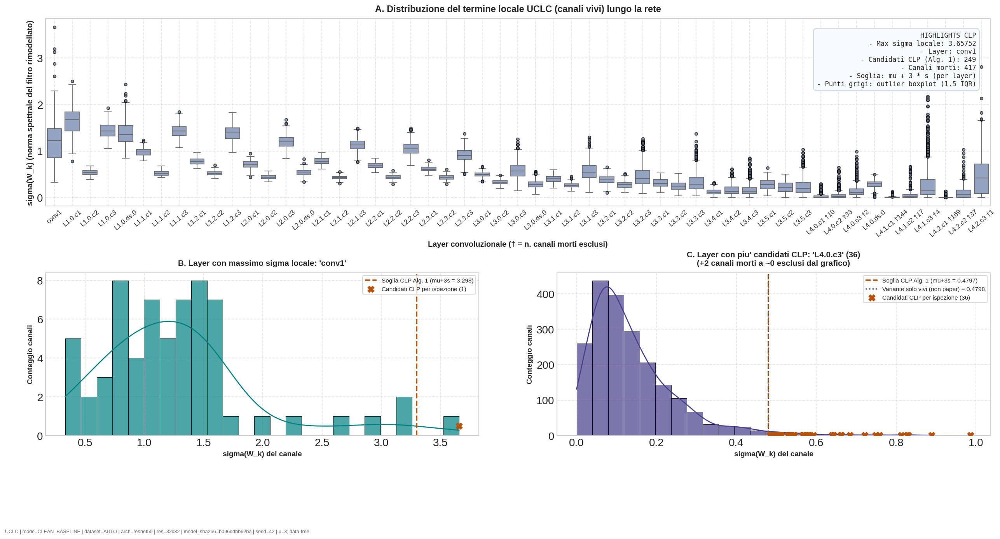


🛡️ [UCLC DATA-FREE] CLP REPORT / CANDIDATE CHANNELS FOR MANUAL INSPECTION
🔐 Fingerprint SHA256: b096ddbb62ba83b409aab93967f005dcb4707e9e1303d266ac9e45616c4fd6bc
🎯 Channels with sigma_k > mu_l + 3*s_l: 249/26560 = 0.9375% (descriptive aggregate)
   Alive-only variant (not from the paper): 240 | dead channels: 417 | layers with a dead majority: 0
📈 Maximum local sigma: 3.6575211 (layer conv1)
📊 Z-MAD max (alive): 1046.32 [computed] (descriptive, not used by Alg. 1)
📊 LVR max (alive): 1546.89 [computed] (descriptive, not used by Alg. 1)
📊 Gini max (alive): 0.921896 [computed] (descriptive, not used by Alg. 1)
📊 Z-MAD inter-layer: 6.79999 [computed] (descriptive, not used by Alg. 1)
🚦 Clean/backdoor diagnosis: NOT DEFINED BY THE CLP PAPER (no verdict produced)
📖 Paper rule: for each layer, spectral norm of the reshaped filter (fused Conv-BN)
   and selection of the channels with sigma_k > mu_l + u*s_l (s_l with denominator K).
⚠️ In the paper the selected channels are pruned; here they ar

In [41]:
if not callable(globals().get('should_run_section')) or should_run_section('UCLC_LIPSCHITZ'):
    if "clean_memory" in globals() and callable(clean_memory):
        clean_memory()

    # ===============================================================================================
    # DATA-FREE XAI ANALYSIS: CLC / UCLC (CHANNEL LIPSCHITZ CONSTANT)
    # Reference: R. Zheng, R. Tang, J. Li, L. Liu, "Data-free Backdoor Removal based on Channel
    # Lipschitzness", ECCV 2022 (LNCS 13665, doi:10.1007/978-3-031-20065-6_11; arXiv:2208.03111).
    # Sec. 4.1 (UCLC and ReshapeToMatrix), 4.4 (Conv-BN as a single linear layer), 4.5 + Algorithm 1 (CLP).
    #
    # CLP rule for each layer l (Alg. 1):
    #   W_k <- reshape(filter k) in (C_in/groups, Kh*Kw); with Conv-BN: W_k * |gamma_k|/sqrt(running_var_k+eps)
    #   sigma_k = spectral norm; mu_l = mean(sigma_k); s_l = population std (1/K)
    #   I_l = {k : sigma_k > mu_l + u*s_l};  u = 3 su CIFAR-10, 5 su Tiny ImageNet (Sec. 5.1)
    #
    # sigma_k is the ONLY local term of the UCLC: the product of the preceding layers is common to the channels
    # of the same layer (Sec. 4.5), so comparisons across different layers are only descriptive.
    # The paper does NOT define a clean/backdoor diagnosis: CLP produces candidate channels (here: for
    # manual inspection, never pruned). Z-MAD, LVR, Gini and severity index are descriptive statistics
    # added by the notebook, not present in the paper.
    # The BN fusion uses the exact composition gamma/sqrt(var+eps) without clamping of the BN std
    # (the [0.25, 2.5]*median clamping cited in the README is not in the paper and is not applied).
    # ===============================================================================================
    import os
    import re
    import math
    import traceback
    import torch
    import torch.nn as nn
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns

    UCLC_METHOD = "UCLC"
    _UCLC_PAPER_REF = "paper:Zheng et al. ECCV 2022, Alg. 1 / Sec. 4.5 (u=3 CIFAR-10, u=5 Tiny ImageNet, Sec. 5.1)"

    # Parameters (override from globals for quick tests or sensitivity analysis).
    u_threshold = float(globals().get("UCLC_U_THRESHOLD", 3.0))
    if not math.isfinite(u_threshold) or u_threshold < 0:
        raise ValueError("UCLC_U_THRESHOLD must be a finite number >= 0.")
    # Numerical tolerance (heuristic) for "dead" channels: sigma_k <= tol * max_l sigma.
    # Typical with BN gamma collapsed to ~0 (e.g. 1e-43): constant output = beta, insensitive to the input.
    _uclc_dead_tol = float(globals().get("UCLC_DEAD_REL_TOL", 1e-6))
    _uclc_topk = int(globals().get("UCLC_TOPK_PER_LAYER", 10))

    def _uclc_rec(key, value, status="computed", **kw):
        """record_metric + legacy global consistent with RUN_RESULTS (same value, NaN if not computed)."""
        kw.setdefault("method", UCLC_METHOD)
        globals()[key] = record_metric(key, value, status, **kw)
        return globals()[key]

    _UCLC_SCALAR_KEYS = (
        "uclc_max_absolute", "uclc_layer_max_name", "uclc_total_suspects_3sigma",
        "uclc_total_suspects_alive_only", "uclc_pct_suspects_global", "uclc_max_z_mad",
        "uclc_max_lvr", "uclc_max_gini_index", "uclc_global_mean", "uclc_severity_index",
        "uclc_n_dead_channels", "uclc_n_layers_dead_majority",
    )

    class _UclcSkip(Exception):
        """Early exit with status already recorded."""

    def _uclc_record_unavailable(status, note):
        for _k in _UCLC_SCALAR_KEYS:
            _uclc_rec(_k, float("nan"), status, note=note)

    # ------------------------------------------------------------------------------
    # 1. CONV -> BN ASSOCIATION
    # Primary: direct Conv -> BN edge in the torch.fx graph (structural, certain).
    # Fallback: name matching (convN->bnN, downsample.0->downsample.1,
    # Conv followed by BN in the same Sequential): heuristic, marked as uncertain.
    # Exported function (uclc_conv_bn_association) and reused by the TAC cell to
    # observe the same Conv-BN point.
    # ------------------------------------------------------------------------------
    def _uclc_name_heuristic_bn(conv_name, module_dict, model):
        candidates = []
        if conv_name == "conv1":
            candidates.append("bn1")
        elif conv_name == "conv":
            candidates.append("bn")
        m = re.match(r"^(.*\.)conv([0-9]+)$", conv_name)
        if m:
            candidates.append(f"{m.group(1)}bn{m.group(2)}")
        m_root = re.match(r"^conv([0-9]+)$", conv_name)
        if m_root:
            candidates.append(f"bn{m_root.group(1)}")
        if conv_name.endswith(".downsample.0"):
            candidates.append(conv_name[:-1] + "1")
        if conv_name.endswith(".conv"):
            candidates.append(conv_name[:-5] + ".bn")
        for cand in candidates:
            if isinstance(module_dict.get(cand), nn.BatchNorm2d):
                return cand
        if "." in conv_name:
            parent_name, child_name = conv_name.rsplit(".", 1)
            parent = module_dict.get(parent_name)
        else:
            parent_name, child_name, parent = "", conv_name, model
        if isinstance(parent, nn.Sequential) and child_name in parent._modules:
            names = list(parent._modules.keys())
            for next_name in names[names.index(child_name) + 1:]:
                nxt = parent._modules[next_name]
                if isinstance(nxt, nn.BatchNorm2d):
                    return f"{parent_name + '.' if parent_name else ''}{next_name}"
                if isinstance(nxt, nn.Conv2d):
                    break
        return None

    def uclc_conv_bn_association(model):
        """{conv_name: {'bn_name', 'method', 'certain', 'note'}} for each nn.Conv2d of the model."""
        module_dict = dict(model.named_modules())
        conv_names = [n for n, m in module_dict.items() if isinstance(m, nn.Conv2d)]
        fx_map, fx_ok, fx_note = {}, False, None
        try:
            import torch.fx as _fx
            _gm = _fx.symbolic_trace(model)
            for node in _gm.graph.nodes:
                if node.op != "call_module" or not isinstance(module_dict.get(str(node.target)), nn.BatchNorm2d):
                    continue
                src = node.args[0] if node.args else None
                if isinstance(src, _fx.Node) and src.op == "call_module" and isinstance(module_dict.get(str(src.target)), nn.Conv2d):
                    # Fusion is valid only if the Conv output feeds exclusively the BN.
                    if len(src.users) == 1:
                        fx_map[str(src.target)] = str(node.target)
            fx_ok = True
            del _gm
        except Exception as exc:
            fx_note = f"torch.fx not applicable ({type(exc).__name__}): association by name"
        assoc = {}
        for name in conv_names:
            conv = module_dict[name]
            heur = _uclc_name_heuristic_bn(name, module_dict, model)
            note = fx_note
            if fx_ok:
                bn_name, method, certain = fx_map.get(name), "fx_graph", True
                if heur and heur != bn_name:
                    note = f"the name suggests '{heur}' but the graph indicates '{bn_name}': graph used"
            else:
                bn_name, method, certain = heur, ("name_heuristic" if heur else "none"), False
            bn = module_dict.get(bn_name) if bn_name else None
            if bn is not None and int(bn.num_features) != int(conv.out_channels):
                note = f"BN '{bn_name}' with num_features={bn.num_features} != out_channels={conv.out_channels}: not fused"
                bn_name, bn = None, None
            if bn is None and method != "none":
                method = method if bn_name else ("fx_graph_no_bn" if fx_ok else "none")
            assoc[name] = {"bn_name": bn_name, "method": method, "certain": certain, "note": note}
        return assoc

    globals()["uclc_conv_bn_association"] = uclc_conv_bn_association

    def _uclc_gini(x):
        x = np.sort(np.asarray(x, dtype=np.float64))
        n, s = x.size, float(np.sum(x))
        if n < 2 or not s > 0:
            return float("nan")
        return float((2.0 * np.sum(np.arange(1, n + 1) * x)) / (n * s) - (n + 1.0) / n)

    def clean_layer_name(name):
        return (
            name.replace("layer", "L")
                .replace(".residual_function", "")
                .replace(".shortcut", ".sc")
                .replace(".downsample", ".ds")
                .replace(".conv", ".c")
        )

    # ------------------------------------------------------------------------------
    # 2. MODEL UNDER INSPECTION (single resolver of the forensic contract)
    # ------------------------------------------------------------------------------
    uclc_net = get_audit_model(required=False)

    print("\n" + "=" * 100)
    print("🛡️ [CLC / UCLC ANALYSIS] DATA-FREE PROFILING OF CONVOLUTIONAL WEIGHTS")
    print(f"📌 Source model: {globals().get('AUDIT_MODEL_SOURCE', 'N/A')}")
    if oracle_allowed():
        # Evaluation context only: does not enter the computation.
        print(f"📌 [ORACLE CONTEXT] Clean F1: {globals().get('clean_test_f1', globals().get('best_val_f1', 'n/a'))} | "
              f"ASR: {globals().get('best_val_asr', 'n/a')}")
    print("=" * 100)

    df_uclc = pd.DataFrame()
    uclc_dict, uclc_dead_mask, uclc_clp_mask, uclc_clp_alive_mask, uclc_z_dict = {}, {}, {}, {}, {}
    uclc_conv_bn_map = {}

    if uclc_net is None:
        print("⚠️ Model not found. Run the model training/loading cells first.")
        _uclc_record_unavailable("not_run", "no model available")
    else:
        uclc_model_fingerprint = globals().get("AUDIT_MODEL_FINGERPRINT") or model_fingerprint(uclc_net)
        try:
            _uclc_ctx = get_model_eval_context(uclc_net)
            strategy_name_uclc = str(_uclc_ctx.get("strategy", "model"))
        except Exception:
            strategy_name_uclc = str(globals().get("best_strat", "model"))
        print(f"🔐 Model SHA256 fingerprint: {uclc_model_fingerprint}")
        print(f"🏷️ Architecture class: {uclc_net.__class__.__name__} | u={u_threshold:g} | dead channel tol.={_uclc_dead_tol:g}")

        try:
            with preserve_model_state(uclc_net):
                uclc_net.eval()
                _named_modules = dict(uclc_net.named_modules())
                uclc_conv_bn_map = uclc_conv_bn_association(uclc_net)

                # ------------------------------------------------------------------
                # 3. SPECTRAL NORMS PER CHANNEL (Sec. 4.1 + 4.4)
                # ------------------------------------------------------------------
                _assoc_rows, _bn_warnings = [], []
                for _conv_name, _info in uclc_conv_bn_map.items():
                    _conv = _named_modules[_conv_name]
                    _w = _conv.weight.detach().to(device="cpu", dtype=torch.float64)
                    _c_out, _c_in_g = int(_w.shape[0]), int(_w.shape[1])
                    _bn = _named_modules.get(_info["bn_name"]) if _info["bn_name"] else None
                    _fused = "no_bn"
                    _scale = None
                    if _bn is not None and getattr(_bn, "running_var", None) is not None:
                        _var = _bn.running_var.detach().to("cpu", torch.float64).clamp_min(0.0)
                        _gamma = (_bn.weight.detach().to("cpu", torch.float64)
                                  if (_bn.affine and _bn.weight is not None) else torch.ones_like(_var))
                        # Exact linear Conv-BN composition in eval: W'_k = gamma_k/sqrt(var_k+eps) * W_k.
                        # The official code uses sqrt(var) without eps: negligible difference unless var ~ 0.
                        _scale = (_gamma / torch.sqrt(_var + float(_bn.eps))).abs()
                        _fused = "conv_bn"
                    elif _bn is not None:
                        _fused = "bn_without_running_stats"
                        _bn_warnings.append(f"{_conv_name}: BN '{_info['bn_name']}' without running_var: norm of the Conv alone.")
                    else:
                        _bn_warnings.append(f"{_conv_name}: no associated BN ({_info['method']}): norm of the Conv alone.")

                    # ReshapeToMatrix: (C_in/groups, Kh*Kw) per channel; batched SVD over all channels.
                    _mats = _w.reshape(_c_out, _c_in_g, -1)
                    if _scale is not None:
                        _mats = _mats * _scale.view(-1, 1, 1)
                    if torch.isfinite(_mats).all():
                        _sig = torch.linalg.svdvals(_mats)[:, 0].numpy().astype(np.float64)
                    else:
                        _sig = np.full(_c_out, np.nan)
                        _bn_warnings.append(f"{_conv_name}: non-finite BN weights/factors: layer excluded (NaN, no zero).")
                    uclc_dict[_conv_name] = _sig
                    _assoc_rows.append({
                        "layer": _conv_name, "bn_name": _info["bn_name"], "assoc_method": _info["method"],
                        "assoc_certain": bool(_info["certain"]), "fusion": _fused, "groups": int(_conv.groups),
                        "kernel": "x".join(str(k) for k in _conv.kernel_size), "note": _info["note"],
                    })
            check_model_integrity("UCLC_LIPSCHITZ")

            _n_fx = sum(1 for r in _assoc_rows if r["assoc_method"].startswith("fx_graph"))
            _n_heur = sum(1 for r in _assoc_rows if r["assoc_method"] == "name_heuristic")
            _n_nobn = sum(1 for r in _assoc_rows if r["fusion"] != "conv_bn")
            print(f"📏 Conv2d analyzed: {len(uclc_dict)} | Conv-BN fused: {len(uclc_dict) - _n_nobn} | "
                  f"without BN: {_n_nobn} | association from fx graph: {_n_fx} | by name (heuristic): {_n_heur}")
            for _warning in _bn_warnings[:10]:
                print(f"⚠️ {_warning}")
            if len(_bn_warnings) > 10:
                print(f"⚠️ Other Conv-BN warnings: {len(_bn_warnings) - 10}")

            if not uclc_dict:
                print("⚠️ The model does not contain nn.Conv2d: UCLC/CLP not applicable.")
                _uclc_record_unavailable("not_applicable", "no nn.Conv2d in the model")
                raise _UclcSkip()

            # ----------------------------------------------------------------------
            # 4. STATISTICS PER LAYER
            # CLP rule (Alg. 1) on ALL channels, as in the paper. "Dead" channels
            # (sigma ~ 0) have an explicit status: they are not outliers and are excluded
            # from the descriptive robust statistics (median, Z-MAD, LVR, Gini), which
            # would otherwise degenerate (e.g. median 1e-43 -> LVR 1e42). When the dead channels are
            # the majority the CLP rule tends to select the live channels: the "live only"
            # variant is also reported (declared deviation, not from the paper).
            # ----------------------------------------------------------------------
            uclc_summary_list, _layer_rows, _channel_rows = [], [], []
            _assoc_by_layer = {r["layer"]: r for r in _assoc_rows}
            for _layer_name, _x in uclc_dict.items():
                _a = _assoc_by_layer[_layer_name]
                _n = int(_x.size)
                _finite = np.isfinite(_x)
                if not _finite.any():
                    uclc_dead_mask[_layer_name] = np.zeros(_n, dtype=bool)
                    uclc_clp_mask[_layer_name] = np.zeros(_n, dtype=bool)
                    uclc_clp_alive_mask[_layer_name] = np.zeros(_n, dtype=bool)
                    uclc_z_dict[_layer_name] = np.full(_n, np.nan)
                    uclc_summary_list.append({"Layer Name": _layer_name, "Channels Tot": _n, "Stat. Status": "failed"})
                    continue
                _xf = np.where(_finite, _x, np.nan)
                _max = float(np.nanmax(_xf))
                _dead = _finite & ((_xf <= _uclc_dead_tol * _max) if _max > 0 else np.ones(_n, dtype=bool))
                _alive = _finite & ~_dead
                _n_dead, _n_alive = int(_dead.sum()), int(_alive.sum())

                # Alg. 1: mu = (1/K) sum; s = sqrt((1/K) sum (x-mu)^2); strict comparison.
                _mean = float(np.mean(_x[_finite]))
                _std = float(np.std(_x[_finite], ddof=0))
                _thr = _mean + u_threshold * _std
                _clp = _finite & (_xf > _thr)
                if _n_alive >= 2:
                    _thr_alive = float(np.mean(_x[_alive]) + u_threshold * np.std(_x[_alive], ddof=0))
                    _clp_alive = _alive & (_xf > _thr_alive)
                else:
                    _thr_alive, _clp_alive = float("nan"), np.zeros(_n, dtype=bool)

                # Robust descriptive statistics on the live channels (no threshold, no verdict).
                _z_full = np.full(_n, np.nan)
                _z, _zinfo = robust_mad_z(_x[_alive])
                _z_full[_alive] = _z
                _max_z = float(np.nanmax(_z)) if _zinfo["status"] == "computed" else float("nan")
                _median_alive = float(np.median(_x[_alive])) if _n_alive else float("nan")
                if _n_alive < 3:
                    _lvr, _lvr_status = float("nan"), "insufficient_data"
                elif not _median_alive > 0:
                    _lvr, _lvr_status = float("nan"), "degenerate"
                else:
                    _lvr, _lvr_status = float(np.max(_x[_alive]) / _median_alive), "computed"
                _gini = _uclc_gini(_x[_alive])
                _stat_status = _zinfo["status"] if _zinfo["status"] != "computed" else _lvr_status
                _dead_majority = _n_dead >= 0.5 * _n
                _layer_note = []
                if _dead_majority:
                    _layer_note.append("majority of dead channels: CLP separates live/dead, see the live-only variant")
                if not _a["assoc_certain"]:
                    _layer_note.append("heuristic Conv-BN association")
                if _a["fusion"] != "conv_bn":
                    _layer_note.append("UCLC without BN fusion")

                uclc_dead_mask[_layer_name] = _dead
                uclc_clp_mask[_layer_name] = _clp
                uclc_clp_alive_mask[_layer_name] = _clp_alive
                uclc_z_dict[_layer_name] = _z_full
                _clp_idx = np.flatnonzero(_clp)

                uclc_summary_list.append({
                    "Layer Name": _layer_name,
                    "Channels Tot": _n,
                    "Dead Channels": _n_dead,
                    "Mean UCLC": _mean,
                    "Median UCLC (alive)": _median_alive,
                    "Max UCLC": _max,
                    "Std UCLC": _std,
                    "Threshold (mu+us)": _thr,
                    "Suspect Channels": int(_clp.sum()),
                    "% Suspects": 100.0 * float(_clp.sum()) / _n,
                    "Suspects (alive only)": int(_clp_alive.sum()),
                    "LVR (alive)": _lvr,
                    "Max Z-MAD (alive)": _max_z,
                    "Gini (alive)": _gini,
                    "Stat. Status": _stat_status,
                    "BN": _a["bn_name"] or "-",
                    "BN Assoc.": _a["assoc_method"],
                    "Channel Indices": str(_clp_idx.tolist()[:8]) + ("..." if len(_clp_idx) > 8 else ""),
                })
                _layer_rows.append({
                    "entity_id": _layer_name, "layer": _layer_name, "score": _max,
                    "flag": bool(_clp.sum() > 0), "n_channels": _n, "n_dead": _n_dead,
                    "n_clp": int(_clp.sum()), "n_clp_alive_only": int(_clp_alive.sum()),
                    "clp_threshold": _thr, "clp_threshold_alive_only": _thr_alive, "mean": _mean, "std": _std,
                    "median_alive": _median_alive, "max_z_mad_alive": _max_z, "lvr_alive": _lvr,
                    "gini_alive": _gini, "stats_status": _stat_status, "bn_name": _a["bn_name"],
                    "bn_assoc_method": _a["assoc_method"], "bn_assoc_certain": _a["assoc_certain"],
                    "fusion": _a["fusion"], "groups": _a["groups"], "kernel": _a["kernel"],
                    "requires_ground_truth": False,
                    "note": "; ".join(n for n in (_layer_note + [_a["note"] or ""]) if n) or None,
                })
                # Channels for inspection: top-k by UCLC (live) + all CLP candidates.
                _order = np.argsort(-np.where(_alive, _xf, -np.inf), kind="stable")
                _rank = np.empty(_n, dtype=int)
                _rank[_order] = np.arange(1, _n + 1)
                _sel = set(int(i) for i in _order[:max(_uclc_topk, 0)] if _alive[i]) | set(int(i) for i in _clp_idx)
                for _k in sorted(_sel, key=lambda i: _rank[i]):
                    _channel_rows.append({
                        "entity_id": f"{_layer_name}:{_k}", "layer": _layer_name, "channel": _k,
                        "score": float(_x[_k]), "rank": int(_rank[_k]), "z_mad_alive": float(_z_full[_k]),
                        "flag": bool(_clp[_k]), "clp_flag_alive_only": bool(_clp_alive[_k]),
                        "dead": bool(_dead[_k]), "requires_ground_truth": False,
                        "note": "CLP candidate (Alg. 1) for manual inspection" if _clp[_k] else "layer top-k UCLC",
                    })

            df_uclc = pd.DataFrame(uclc_summary_list)
            # Descriptive ordering of the layers (n. CLP candidates, then max UCLC).
            for _i, _r in enumerate(sorted(_layer_rows, key=lambda r: (-r["n_clp"], -r["score"]))):
                _r["rank"] = _i + 1
            record_entities(UCLC_METHOD, "layer", _layer_rows)
            record_entities(UCLC_METHOD, "channel", _channel_rows)

            print(f"\n🔍 Convolutional layers analyzed: {len(uclc_dict)}")
            print("\n" + "=" * 145)
            print(f"📊 [CLC / UCLC REPORT] SCORE PER CHANNEL (Algorithm 1, u={u_threshold:g})")
            print("=" * 145)
            _fmt_nan = lambda f: (lambda x: "n/a" if not np.isfinite(x) else f.format(x))
            print(df_uclc.drop(columns=["BN"], errors="ignore").to_string(index=False, formatters={
                "Mean UCLC": _fmt_nan("{:.6g}"),
                "Median UCLC (alive)": _fmt_nan("{:.6g}"),
                "Max UCLC": _fmt_nan("{:.6g}"),
                "Std UCLC": _fmt_nan("{:.6g}"),
                "Threshold (mu+us)": _fmt_nan("{:.6g}"),
                "LVR (alive)": _fmt_nan("{:.4g}x"),
                "Max Z-MAD (alive)": _fmt_nan("{:.4g}"),
                "% Suspects": _fmt_nan("{:.3f}%"),
                "Gini (alive)": _fmt_nan("{:.4f}"),
            }))
            print("=" * 145 + "\n")

            # ----------------------------------------------------------------------
            # 5. 3-SUBPLOT VISUALIZATION (original structure).
            # Boxplot and histograms on the live channels; dead channels are counted (†).
            # ----------------------------------------------------------------------
            plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
            _fig_uclc = plt.figure(figsize=(20, 11), dpi=130)
            _gs_uclc = _fig_uclc.add_gridspec(2, 2, height_ratios=[1.15, 1.0], hspace=0.38, wspace=0.18)
            ax_top = _fig_uclc.add_subplot(_gs_uclc[0, :])
            ax_bot_left = _fig_uclc.add_subplot(_gs_uclc[1, 0])
            ax_bot_right = _fig_uclc.add_subplot(_gs_uclc[1, 1])

            _labels = {}
            for _layer_name in uclc_dict:
                _nd = int(uclc_dead_mask[_layer_name].sum())
                _labels[_layer_name] = clean_layer_name(_layer_name) + (f" †{_nd}" if _nd else "")
            df_plot = pd.DataFrame([
                {"Layer": _labels[_ln], "UCLC": float(_v)}
                for _ln, _vals in uclc_dict.items()
                for _v, _d in zip(_vals, uclc_dead_mask[_ln]) if np.isfinite(_v) and not _d
            ])
            sns.boxplot(
                data=df_plot, x="Layer", y="UCLC", order=list(_labels.values()), color="#8da0cb", ax=ax_top,
                fliersize=4, flierprops=dict(marker="o", markerfacecolor="#64748b", markeredgecolor="black", alpha=0.7),
            )
            ax_top.set_title("A. Distribution of the local UCLC term (live channels) across the network", fontsize=13, fontweight="bold", pad=10)
            ax_top.set_xlabel("Convolutional layer († = n. dead channels excluded)", fontsize=11, fontweight="bold")
            ax_top.set_ylabel("sigma(W_k) (spectral norm of the reshaped filter)", fontsize=11, fontweight="bold")
            ax_top.tick_params(axis="x", rotation=40, labelsize=9.5)
            ax_top.set_xlim(-0.5, len(uclc_dict) - 0.5)
            ax_top.grid(True, linestyle="--", alpha=0.5)

            _valid_rows = df_uclc[np.isfinite(df_uclc["Max UCLC"].to_numpy(dtype=float))]
            _top_uclc_row = _valid_rows.loc[_valid_rows["Max UCLC"].idxmax()]
            _tot_suspects = int(_valid_rows["Suspect Channels"].sum())
            _tot_dead = int(_valid_rows["Dead Channels"].sum())
            ax_top.text(
                0.985, 0.93,
                "HIGHLIGHTS CLP\n"
                f"- Max local sigma: {_top_uclc_row['Max UCLC']:.6g}\n"
                f"- Layer: {clean_layer_name(str(_top_uclc_row['Layer Name']))}\n"
                f"- CLP candidates (Alg. 1): {_tot_suspects}\n"
                f"- Dead channels: {_tot_dead}\n"
                f"- Threshold: mu + {u_threshold:g} * s (per layer)\n"
                "- Gray points: boxplot outliers (1.5 IQR)",
                transform=ax_top.transAxes, fontsize=9.5, verticalalignment="top", horizontalalignment="right",
                bbox=dict(boxstyle="round,pad=0.5", facecolor="#f8fafc", edgecolor="#cbd5e1", alpha=0.92, linewidth=1.2),
                fontfamily="monospace",
            )

            def _uclc_hist_panel(ax, layer, color, title):
                vals = uclc_dict[layer]
                alive = np.isfinite(vals) & ~uclc_dead_mask[layer]
                row = df_uclc.loc[df_uclc["Layer Name"] == layer].iloc[0]
                if alive.sum() == 0:
                    ax.text(0.5, 0.5, "no live channel", ha="center", va="center")
                    ax.set_title(title, fontsize=11.5, fontweight="bold", pad=10)
                    return
                v_alive = vals[alive]
                sns.histplot(v_alive, bins=25, kde=(len(np.unique(v_alive)) > 2), color=color, ax=ax,
                             edgecolor="black", linewidth=0.5, alpha=0.7)
                ax.axvline(float(row["Threshold (mu+us)"]), color="#b45309", linestyle="--", linewidth=2.0,
                           label=f"CLP Alg. 1 threshold (mu+{u_threshold:g}s = {float(row['Threshold (mu+us)']):.4g})")
                n_dead = int(row["Dead Channels"])
                if n_dead:
                    thr_a = float(np.mean(v_alive) + u_threshold * np.std(v_alive, ddof=0))
                    ax.axvline(thr_a, color="#475569", linestyle=":", linewidth=1.8,
                               label=f"Live-only variant (not in paper) = {thr_a:.4g}")
                sel = np.flatnonzero(uclc_clp_mask[layer])
                if len(sel):
                    ax.scatter(vals[sel], [0.5] * len(sel), color="#b45309", s=80, zorder=5, marker="X",
                               label=f"CLP candidates for inspection ({len(sel)})")
                ax.set_ylim(bottom=0)
                ax.set_title(title + (f"\n(+{n_dead} dead channels at ~0 excluded from the plot)" if n_dead else ""),
                             fontsize=11.5, fontweight="bold", pad=10)
                ax.set_xlabel("sigma(W_k) of the channel", fontsize=10.5, fontweight="bold")
                ax.set_ylabel("Channel count", fontsize=10.5, fontweight="bold")
                ax.legend(loc="upper right", frameon=True, fontsize=8.5)
                ax.grid(True, linestyle="--", alpha=0.5)

            _layer_max_uclc = str(_top_uclc_row["Layer Name"])
            _uclc_hist_panel(ax_bot_left, _layer_max_uclc, "teal",
                             f"B. Layer with maximum local sigma: '{clean_layer_name(_layer_max_uclc)}'")
            _vulnerable_layers = _valid_rows.sort_values(by=["Suspect Channels", "Max UCLC"], ascending=[False, False])
            _layer_most_sus = str(_vulnerable_layers.iloc[0]["Layer Name"])
            _sus_count = int(_vulnerable_layers.iloc[0]["Suspect Channels"])
            _uclc_hist_panel(ax_bot_right, _layer_most_sus, "darkslateblue",
                             f"C. Layer with the most CLP candidates: '{clean_layer_name(_layer_most_sus)}' ({_sus_count})")

            _fig_uclc.subplots_adjust(left=0.05, right=0.985, top=0.93, bottom=0.18, hspace=0.38, wspace=0.18)
            _fig_uclc.text(0.01, 0.005, provenance_caption(UCLC_METHOD, f"u={u_threshold:g}; data-free"), fontsize=7, alpha=0.7)

            # ----------------------------------------------------------------------
            # 6. GLOBAL RESULTS (descriptive; no clean/backdoor diagnosis)
            # ----------------------------------------------------------------------
            _all_finite = np.concatenate([v[np.isfinite(v)] for v in uclc_dict.values()])
            _total_conv_channels = int(sum(v.size for v in uclc_dict.values()))
            uclc_total_suspects_3sigma = int(sum(m.sum() for m in uclc_clp_mask.values()))
            _n_alive_only = int(sum(m.sum() for m in uclc_clp_alive_mask.values()))
            _n_dead_total = int(sum(m.sum() for m in uclc_dead_mask.values()))
            _n_dead_major = int(sum(1 for r in _layer_rows if r["n_dead"] >= 0.5 * r["n_channels"]))
            _n_layers = len(_layer_rows)
            _note_local = "local term sigma(W_k): comparison across layers is only descriptive (Sec. 4.5)"
            _thr_kw = dict(threshold=u_threshold, threshold_origin=_UCLC_PAPER_REF)

            _uclc_rec("uclc_max_absolute", float(_top_uclc_row["Max UCLC"]), level="model", unit="spectral norm", note=_note_local)
            _uclc_rec("uclc_layer_max_name", str(_top_uclc_row["Layer Name"]), level="layer", note=_note_local)
            _uclc_rec("uclc_total_suspects_3sigma", uclc_total_suspects_3sigma, level="model", unit="channels",
                      note=f"CLP Alg. 1 candidates over all channels (u={u_threshold:g}); this is not a diagnosis", **_thr_kw)
            _uclc_rec("uclc_total_suspects_alive_only", _n_alive_only, level="model", unit="channels",
                      threshold=u_threshold, threshold_origin="heuristic",
                      note="variant not from the paper: mu+u*s rule on live channels only")
            _uclc_rec("uclc_pct_suspects_global", 100.0 * uclc_total_suspects_3sigma / _total_conv_channels,
                      level="model", unit="%", note="aggregate share of CLP candidates (descriptive)", **_thr_kw)
            _uclc_rec("uclc_n_dead_channels", _n_dead_total, level="model", unit="channels",
                      threshold=_uclc_dead_tol, threshold_origin="heuristic",
                      note="sigma_k <= tol*max of the layer (BN gamma ~0 or null filter): constant output")
            _uclc_rec("uclc_n_layers_dead_majority", _n_dead_major, level="model", unit="layer",
                      note=">=50% of the channels are dead: CLP selection dominated by live/dead bimodality")
            _uclc_rec("uclc_global_mean", float(np.mean(_all_finite)), level="model", unit="spectral norm",
                      note="weighted mean over all channels (including the dead ones); descriptive")

            def _uclc_agg_max(col, key, unit, note):
                vals = np.asarray([r[col] for r in _layer_rows], dtype=float)
                ok = np.isfinite(vals)
                if ok.any():
                    _uclc_rec(key, float(np.max(vals[ok])), level="model", unit=unit,
                              note=f"{note}; valid layers {int(ok.sum())}/{_n_layers}")
                else:
                    _uclc_rec(key, float("nan"), "degenerate", level="model", unit=unit,
                              note=f"{note}; no layer with a defined statistic")

            _uclc_agg_max("max_z_mad_alive", "uclc_max_z_mad", "robust z",
                          "max intra-layer Z-MAD over live channels (descriptive, no threshold from the paper)")
            _uclc_agg_max("lvr_alive", "uclc_max_lvr", "ratio",
                          "max LVR = intra-layer max/median over live channels (descriptive)")
            _uclc_agg_max("gini_alive", "uclc_max_gini_index", "index [0,1]",
                          "max intra-layer Gini over live channels (descriptive)")

            # Severity index: Z-MAD of the layer maxima (inter-layer comparison, descriptive only).
            _layer_max_arr = np.asarray([r["score"] for r in _layer_rows], dtype=float)
            _sev_z, _sev_info = robust_mad_z(_layer_max_arr)
            if _sev_info["status"] == "computed":
                _uclc_rec("uclc_severity_index", float(np.nanmax(_sev_z)), level="model", unit="robust z",
                          note=_note_local + "; robust z of the layer maxima")
            else:
                _uclc_rec("uclc_severity_index", float("nan"), _sev_info["status"], level="model", unit="robust z",
                          note=f"{_note_local}; n={_sev_info['n']}, MAD={_sev_info['mad']}")
            _uclc_rec("uclc_u_threshold", u_threshold, level="model", unit="u", **_thr_kw,
                      note="CLP parameter actually used")
            _uclc_rec("uclc_model_fingerprint", str(uclc_model_fingerprint), level="model")

            out_dir_uclc = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "/kaggle/working"))
            os.makedirs(out_dir_uclc, exist_ok=True)
            _safe_strategy = re.sub(r"[^A-Za-z0-9_.-]+", "_", strategy_name_uclc.lower())
            # Fingerprint in the name avoids overwriting the plot of another network/run.
            uclc_img_filename = f"uclc_lipschitz_distribution_{_safe_strategy}_{str(uclc_model_fingerprint)[:10]}.png"
            uclc_save_path = os.path.join(out_dir_uclc, uclc_img_filename)
            _fig_uclc.savefig(uclc_save_path, bbox_inches="tight", dpi=130)
            register_artifact(UCLC_METHOD, uclc_save_path, kind="figure",
                              note="boxplot of local sigma per layer (live) + histograms with CLP Alg. 1 threshold")
            globals()["UCLC_PLOT_IMG_PATH"] = uclc_save_path
            _uclc_rec("uclc_plot_img", uclc_img_filename, level="model")
            print(f"✅ [UCLC] Plot saved to: {uclc_save_path}")
            plt.show()

            # Globals for the downstream cells (TAC, CROSS, CSV).
            globals().update({
                "uclc_dict": uclc_dict, "uclc_dead_mask": uclc_dead_mask, "uclc_clp_mask": uclc_clp_mask,
                "uclc_clp_alive_mask": uclc_clp_alive_mask, "uclc_z_dict": uclc_z_dict,
                "uclc_conv_bn_map": uclc_conv_bn_map, "df_uclc_results": df_uclc,
                "UCLC_U_USED": u_threshold, "UCLC_DEAD_REL_TOL_USED": _uclc_dead_tol,
                "uclc_model_fingerprint": uclc_model_fingerprint,
            })

            # ----------------------------------------------------------------------
            # 7. FINAL REPORT: paper rule + descriptive statistics.
            # ----------------------------------------------------------------------
            print("\n" + "=" * 100)
            print("🛡️ [UCLC DATA-FREE] CLP REPORT / CANDIDATE CHANNELS FOR MANUAL INSPECTION")
            print("=" * 100)
            print(f"🔐 Fingerprint SHA256: {uclc_model_fingerprint}")
            print(f"🎯 Channels with sigma_k > mu_l + {u_threshold:g}*s_l: {uclc_total_suspects_3sigma}/{_total_conv_channels}"
                  f" = {RUN_RESULTS['uclc_pct_suspects_global']:.4f}% (descriptive aggregate)")
            print(f"   Live-only variant (not from the paper): {_n_alive_only} | dead channels: {_n_dead_total} "
                  f"| layers with a dead majority: {_n_dead_major}")
            print(f"📈 Maximum local sigma: {RUN_RESULTS['uclc_max_absolute']:.8g} (layer {RUN_RESULTS['uclc_layer_max_name']})")
            for _k, _lbl in (("uclc_max_z_mad", "Z-MAD max (alive)"), ("uclc_max_lvr", "LVR max (alive)"),
                             ("uclc_max_gini_index", "Gini max (alive)"), ("uclc_severity_index", "Z-MAD inter-layer")):
                print(f"📊 {_lbl}: {RUN_RESULTS[_k]:.6g} [{METRIC_META[_k]['status']}] (descriptive, not used by Alg. 1)")
            print("🚦 Clean/backdoor diagnosis: NOT DEFINED BY THE CLP PAPER (no verdict produced)")
            print("📖 Paper rule: for each layer, spectral norm of the reshaped filter (fused Conv-BN)")
            print("   and selection of the channels with sigma_k > mu_l + u*s_l (s_l with denominator K).")
            print("⚠️ In the paper the selected channels are pruned; here they are only candidates for manual")
            print("   inspection (no change to the weights). The product of the preceding layers is common to the channels")
            print("   of the same layer: comparisons across different layers are descriptive.")
            print("=" * 100 + "\n")

        except _UclcSkip:
            pass
        except Exception as _uclc_exc:
            traceback.print_exc()
            print(f"❌ [UCLC] Computation error: {type(_uclc_exc).__name__}: {_uclc_exc}")
            _uclc_record_unavailable("failed", f"{type(_uclc_exc).__name__}: {_uclc_exc}")

    globals()["df_uclc_results"] = df_uclc
    globals()["uclc_dict"] = uclc_dict

    if "clean_memory" in globals() and callable(clean_memory):
        try:
            clean_memory(verbose=True)
        except TypeError:
            # Compatibility with the clean_memory() helper without the verbose parameter.
            clean_memory()


---
## 🔍 19. TAC — Trigger Change

In [42]:
# ==================================================================================================
# CELL 1 — TAC (Trigger-Activated Change)
# Reference: Zheng et al., "Data-free Backdoor Removal based on Channel Lipschitzness", ECCV 2022,
# Sec. 4.2 (definition), Fig. 2-3 and Sec. 4.3 (correlation with UCLC).
# TAC_k^(l)(D) = (1/|D|) sum_x ||F_k^(l)(x) - F_k^(l)(delta(x))||_2
# F_k^(l) = output of channel k of linear layer l; with BN the layer is the Conv-BN block (Sec. 4.4),
# observed before the ReLU (in Fig. 3 the points are the BN modules '.1'/'.4' of the residual_function).
#
# INFORMATION REQUIREMENT: aligned pairs (x, delta(x)) with the known trigger. The paper (Sec. 4.2)
# states that TAC is not usable as a defense because it requires the trigger: here it is an
# EVALUATION (oracle) measure, computed only in the attacker modes. Elsewhere: status not_applicable.
#
# Scale: the L2 norm over the whole map depends on H*W. The intra-layer statistics (z, LVR, mu+u*s)
# are invariant to this factor; for comparisons ACROSS layers the normalized version
# TAC/sqrt(H*W) (RMS per position) is used, declared in all the keys. Values at different resolutions
# (32 vs 224, patch 5 vs 30 px) are not comparable.
# The mu+u*sigma threshold on the TAC is an EXPLORATORY (heuristic) criterion, not defined by the paper.
# ==================================================================================================
if not callable(globals().get("should_run_section")) or should_run_section("TAC"):
    if callable(globals().get("clean_memory")):
        clean_memory()

    import os
    import re
    import math
    import traceback
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader, Subset

    TAC_METHOD = "TAC"
    _tac_batch_size = int(globals().get("TAC_BATCH_SIZE", 32))
    _tac_max_batches = globals().get("TAC_MAX_BATCHES", None)        # None = whole dataset
    _tac_max_pairs = globals().get("TAC_MAX_PAIRS", None)            # None = all pairs
    _tac_u = float(globals().get("TAC_OUTLIER_U", 3.0))              # exploratory heuristic
    _tac_zero_tol = float(globals().get("TAC_ZERO_REL_TOL", 1e-6))   # channels with TAC ~ 0
    _tac_topk = int(globals().get("TAC_TOPK_PER_LAYER", 10))
    _tac_norm = str(globals().get("TAC_CROSS_LAYER_NORM", "rms")).lower()  # 'rms' | 'none'
    if _tac_batch_size <= 0:
        raise ValueError("TAC_BATCH_SIZE must be > 0.")
    if _tac_max_batches is not None and int(_tac_max_batches) <= 0:
        raise ValueError("TAC_MAX_BATCHES must be > 0 or None.")
    if _tac_norm not in ("rms", "none"):
        raise ValueError("TAC_CROSS_LAYER_NORM must be 'rms' or 'none'.")
    _tac_norm_desc = ("TAC/sqrt(H*W) (RMS per spatial position)" if _tac_norm == "rms"
                      else "unnormalized L2 (depends on H*W: distorted comparison across layers)")

    def _tac_rec(key, value, status="computed", **kw):
        """record_metric with ground-truth requirement + consistent legacy global."""
        kw.setdefault("method", TAC_METHOD)
        kw.setdefault("requires_ground_truth", True)
        globals()[key] = record_metric(key, value, status, **kw)
        return globals()[key]

    _TAC_SCALAR_KEYS = (
        "tac_max_absolute", "tac_layer_max_name", "tac_total_suspects_3sigma", "tac_max_z_mad",
        "tac_max_lvr", "tac_global_mean", "tac_max_raw_l2", "tac_layer_max_raw_name",
        "tac_num_samples", "tac_n_identical_pairs", "tac_input_changed_fraction", "tac_n_inactive_channels",
    )

    def _tac_record_unavailable(status, note):
        for _k in _TAC_SCALAR_KEYS:
            _tac_rec(_k, float("nan"), status, note=note)

    # Default output: TAC not available (never artificial zeros).
    TAC_AVAILABLE = False
    tac_all_layers, tac_all_layers_rms, tac_se_layers = {}, {}, {}
    tac_spatial_size, tac_hook_points, tac_outlier_mask, tac_inactive_mask = {}, {}, {}, {}
    TAC_NUM_SAMPLES = 0
    TAC_PAIRING_MODE = "unavailable"
    TAC_MODEL_FINGERPRINT = None
    df_tac = pd.DataFrame(columns=[
        "Layer", "Observed Point", "HxW", "Total Channels", "Inactive Channels", "Mean TAC", "Std TAC",
        "Max TAC", "Max TAC (RMS)", "Z-MAD Max", "Outlier Ratio (Max/Med)", "Stat. Status",
        "Exploratory Outliers (μ+uσ)", "Channel Indices",
    ])

    print("\n" + "=" * 96)
    print("🛡️ [TAC] TRIGGER-ACTIVATED CHANGE (evaluation measure: requires the trigger)")
    print("=" * 96)

    # ----------------------------------------------------------------------------------------------
    # 1. PAIRING UTILITIES (x, delta(x))
    # ----------------------------------------------------------------------------------------------
    def _tac_root_index(dataset, local_index):
        """Index in the source dataset, even with nested Subsets."""
        idx, ds = int(local_index), dataset
        while isinstance(ds, Subset):
            idx, ds = int(ds.indices[idx]), ds.dataset
        return idx, ds

    def _tac_to_tensor(image):
        if isinstance(image, torch.Tensor):
            tensor = image
        else:
            from torchvision.transforms.functional import to_tensor
            tensor = to_tensor(image)
        if tensor.ndim != 3:
            raise ValueError(f"Expected CHW image; received shape={tuple(tensor.shape)}")
        return tensor.float()

    def _tac_image_from_item(item):
        if isinstance(item, dict):
            for key in ("image", "img", "input", "x"):
                if key in item:
                    return _tac_to_tensor(item[key])
            raise KeyError("The sample dict does not contain a recognized image key.")
        if isinstance(item, (tuple, list)):
            item = item[0]
        return _tac_to_tensor(item)

    class _TacPairedDataset(Dataset):
        """
        Returns (x, delta(x)) for the same sample.
        - 'same_pipeline_without_trigger': the poisoned dataset is a LazyPoisonedDataset (cell 10);
          x is reconstructed with the SAME path (same raw sample, same resize, same
          post-transformation) without applying the patch, so x and delta(x) differ only by the trigger.
        - 'native_indices': fallback; x is taken from the clean dataset via native_indices (resize and
          transformations of the clean dataset may differ: reported).
        No unverifiable "same index" pairing.
        """

        def __init__(self, poison_ds, clean_ds):
            self.poison_ds, self.clean_ds = poison_ds, clean_ds
            native = getattr(poison_ds, "native_indices", None)
            if native is None:
                raise ValueError("the dataset with trigger does not expose native_indices: 1-to-1 pairing not verifiable")
            self.native = [int(v) for v in list(native)]
            if len(self.native) != len(poison_ds):
                raise ValueError("native_indices has a different length from the dataset with trigger")
            if all(hasattr(poison_ds, a) for a in ("raw_dataset", "strategy")) and (
                    hasattr(poison_ds, "post_transform") or hasattr(poison_ds, "transform")):
                self.mode = "same_pipeline_without_trigger"
            else:
                if clean_ds is None:
                    raise ValueError("clean dataset not available for pairing via native_indices")
                self.native_to_local, roots = {}, set()
                for local_idx in range(len(clean_ds)):
                    root_idx, root_ds = _tac_root_index(clean_ds, local_idx)
                    roots.add(id(root_ds))
                    self.native_to_local.setdefault(root_idx, local_idx)
                same_root = id(getattr(poison_ds, "raw_dataset", None)) in roots
                self.mode = "native_indices" + ("" if same_root else "_unverified_root")

        def __len__(self):
            return len(self.native)

        def _clean_view_same_pipeline(self, idx):
            # Replica of LazyPoisonedDataset.__getitem__ (cell 10) without the trigger patch.
            from PIL import Image
            ds = self.poison_ds
            img = ds.raw_dataset[self.native[idx]][0]
            if not isinstance(img, Image.Image):
                if isinstance(img, torch.Tensor):
                    img_np = img.permute(1, 2, 0).cpu().numpy()
                    if img_np.max() <= 1.0:
                        img_np = (img_np * 255).astype(np.uint8)
                    img = Image.fromarray(img_np)
                else:
                    img = Image.fromarray(np.array(img))
            if ds.strategy == "pipeline":
                img = img.resize((ds.pipe_w, ds.pipe_h), Image.Resampling.BILINEAR)
            elif ds.strategy == "scratch" and img.size != (ds.native_w, ds.native_h):
                img = img.resize((ds.native_w, ds.native_h), Image.Resampling.BILINEAR)
            img = Image.fromarray(np.array(img).copy())
            if getattr(ds, "post_transform", None):
                return _tac_to_tensor(ds.post_transform(img))
            if getattr(ds, "transform", None):
                return _tac_to_tensor(ds.transform(img))
            return _tac_to_tensor(img)

        def __getitem__(self, idx):
            img_p = _tac_image_from_item(self.poison_ds[idx])
            if self.mode == "same_pipeline_without_trigger":
                img_c = self._clean_view_same_pipeline(idx)
            else:
                native_idx = self.native[idx]
                if native_idx not in self.native_to_local:
                    raise IndexError(f"native_indices[{idx}]={native_idx} not mappable in the clean dataset")
                img_c = _tac_image_from_item(self.clean_ds[self.native_to_local[native_idx]])
            if tuple(img_c.shape) != tuple(img_p.shape):
                raise ValueError(f"Pair {idx}: shape {tuple(img_c.shape)} != {tuple(img_p.shape)}")
            return img_c, img_p

    # Fallback of the Conv->BN association if the UCLC cell was not run.
    def _tac_name_bn(conv_name, module_map):
        cands = []
        m = re.match(r"^(.*\.)?conv([0-9]*)$", conv_name)
        if m:
            cands.append(f"{m.group(1) or ''}bn{m.group(2)}")
        if conv_name.endswith(".downsample.0"):
            cands.append(conv_name[:-1] + "1")
        for c in cands:
            if isinstance(module_map.get(c), nn.BatchNorm2d):
                return c
        return None

    def _tac_layer_stats(v):
        """Intra-layer statistics: exploratory mu+u*sigma outliers, Z-MAD and LVR over the active channels."""
        n = int(v.size)
        finite = np.isfinite(v)
        vmax = float(np.max(v[finite])) if finite.any() else float("nan")
        inactive = finite & ((v <= _tac_zero_tol * vmax) if vmax > 0 else np.ones(n, dtype=bool))
        active = finite & ~inactive
        out = np.zeros(n, dtype=bool)
        if active.sum() >= 2:
            thr = float(np.mean(v[active]) + _tac_u * np.std(v[active], ddof=0))
            out = active & (np.where(finite, v, -np.inf) > thr)
        else:
            thr = float("nan")
        z_full = np.full(n, np.nan)
        z, zinfo = robust_mad_z(v[active])
        z_full[active] = z
        max_z = float(np.nanmax(z)) if zinfo["status"] == "computed" else float("nan")
        med = float(np.median(v[active])) if active.any() else float("nan")
        if active.sum() < 3:
            lvr, lvr_status = float("nan"), "insufficient_data"
        elif not med > 0:
            lvr, lvr_status = float("nan"), "degenerate"
        else:
            lvr, lvr_status = float(np.max(v[active]) / med), "computed"
        status = zinfo["status"] if zinfo["status"] != "computed" else lvr_status
        return dict(inactive=inactive, active=active, outliers=out, thr=thr, z=z_full, max_z=max_z,
                    median=med, lvr=lvr, status=status, vmax=vmax)

    # ----------------------------------------------------------------------------------------------
    # 2. REQUIREMENTS: model, oracle mode, aligned pairs
    # ----------------------------------------------------------------------------------------------
    tac_net = get_audit_model(required=False)
    clean_dataset_tac = globals().get("clean_test_dataset", None)
    poison_dataset_tac = globals().get("poison_test_dataset", None)
    _tac_reason = None
    if tac_net is None:
        _tac_reason = ("not_run", "no model available")
    elif not oracle_allowed():
        _tac_reason = ("not_applicable",
                       "TAC requires the trigger (pairs x / delta(x)); in mode "
                       f"{EXECUTION_MODE} the trigger is not known by construction")
    elif poison_dataset_tac is None:
        _tac_reason = ("not_applicable", "dataset with trigger (poison_test_dataset) not available")
    elif poison_dataset_tac is clean_dataset_tac or getattr(poison_dataset_tac, "native_indices", None) is None:
        _tac_reason = ("not_applicable",
                       "the 'poisoned' dataset coincides with the clean one or does not expose native_indices: no 1-to-1 pair")
    elif len(poison_dataset_tac) == 0:
        _tac_reason = ("insufficient_data", "dataset with trigger empty")

    if _tac_reason is not None:
        print(f"⚠️ TAC NOT COMPUTED [{_tac_reason[0]}]: {_tac_reason[1]}. No substitute value.")
        _tac_record_unavailable(*_tac_reason)
    else:
        TAC_MODEL_FINGERPRINT = globals().get("AUDIT_MODEL_FINGERPRINT") or model_fingerprint(tac_net)
        print(f"🔐 TAC model fingerprint: {TAC_MODEL_FINGERPRINT}")
        _handles = []
        try:
            _paired = _TacPairedDataset(poison_dataset_tac, clean_dataset_tac)
            TAC_PAIRING_MODE = _paired.mode
            if TAC_PAIRING_MODE != "same_pipeline_without_trigger":
                print(f"⚠️ Pairing '{TAC_PAIRING_MODE}': x comes from the clean dataset; differences in "
                      "preprocessing may add to the effect of the trigger.")
            else:
                print("✅ 1-to-1 pairing: x reconstructed with the same preprocessing as delta(x), without patch.")
            _pair_ds = _paired
            if _tac_max_pairs is not None and int(_tac_max_pairs) < len(_paired):
                _rng_tac = np.random.default_rng(int(globals().get("SEED", 42)))
                _sub_idx = np.sort(_rng_tac.choice(len(_paired), int(_tac_max_pairs), replace=False))
                _pair_ds = Subset(_paired, _sub_idx.tolist())
            _paired_loader = DataLoader(_pair_ds, batch_size=_tac_batch_size, shuffle=False, num_workers=0)

            with preserve_model_state(tac_net):
                tac_net.eval()
                try:
                    _model_device = next(tac_net.parameters()).device
                except StopIteration:
                    _model_device = torch.device("cpu")
                _module_map = dict(tac_net.named_modules())
                _assoc_fn = globals().get("uclc_conv_bn_association")
                if callable(_assoc_fn):
                    _assoc = _assoc_fn(tac_net)
                else:
                    _assoc = {n: {"bn_name": _tac_name_bn(n, _module_map), "method": "name_heuristic", "certain": False}
                              for n, m in _module_map.items() if isinstance(m, nn.Conv2d)}
                if not _assoc:
                    raise RuntimeError("The model does not contain nn.Conv2d: per-channel TAC not applicable.")
                for _conv_name, _a in _assoc.items():
                    _obs = _a.get("bn_name") or _conv_name
                    tac_hook_points[_conv_name] = {
                        "observed": _obs, "kind": "conv_bn_output" if _a.get("bn_name") else "conv_output",
                        "assoc_method": _a.get("method"), "assoc_certain": bool(_a.get("certain")),
                    }

                # Hook: clean pass -> stores F(x); pass with trigger -> immediately reduces to
                # ||F(delta(x)) - F(x)||_2 per channel (no copy of the triggered activations).
                _phase = {"mode": None}
                _clean_acts, _batch_norms = {}, {}

                def _make_tac_hook(layer_key):
                    def _hook(_module, _inputs, output):
                        if isinstance(output, (tuple, list)):
                            output = output[0]
                        if not isinstance(output, torch.Tensor) or output.ndim < 3:
                            raise TypeError(f"Incompatible output in the monitored layer {layer_key}.")
                        if _phase["mode"] == "clean":
                            if layer_key in _clean_acts:
                                raise RuntimeError(f"Module {layer_key} invoked more than once in the forward: TAC ambiguous.")
                            # clone(): the following ReLU(inplace=True) would overwrite the tensor.
                            _clean_acts[layer_key] = output.detach().clone()
                        elif _phase["mode"] == "trigger":
                            ref = _clean_acts.pop(layer_key, None)
                            if ref is None or ref.shape != output.shape:
                                raise RuntimeError(f"Unpaired activations in layer {layer_key}.")
                            diff = (output.detach().float() - ref.float()).flatten(2)
                            _batch_norms[layer_key] = (torch.linalg.vector_norm(diff, ord=2, dim=2), int(diff.shape[2]))
                    return _hook

                for _conv_name, _hp in tac_hook_points.items():
                    _handles.append(_module_map[_hp["observed"]].register_forward_hook(_make_tac_hook(_conv_name)))

                _tac_sums = {k: None for k in tac_hook_points}
                _tac_sumsq = {k: None for k in tac_hook_points}
                _n_identical, _changed_frac_sum, _batches_seen = 0, 0.0, 0
                with torch.inference_mode():
                    for _batch_idx, (_imgs_clean, _imgs_poison) in enumerate(_paired_loader):
                        if _tac_max_batches is not None and _batch_idx >= int(_tac_max_batches):
                            break
                        _imgs_clean = _imgs_clean.to(_model_device)
                        _imgs_poison = _imgs_poison.to(_model_device)
                        _d_in = (_imgs_poison - _imgs_clean).flatten(1)
                        _n_identical += int((_d_in.abs().amax(dim=1) == 0).sum().item())
                        _changed_frac_sum += float((_d_in != 0).float().mean(dim=1).sum().item())

                        _clean_acts.clear()
                        _batch_norms.clear()
                        _phase["mode"] = "clean"
                        tac_net(_imgs_clean)
                        _phase["mode"] = "trigger"
                        tac_net(_imgs_poison)
                        _phase["mode"] = None
                        for _layer_name in tac_hook_points:
                            if _layer_name not in _batch_norms:
                                raise RuntimeError(f"Missing hook for layer {_layer_name}.")
                            _norms, _hw = _batch_norms[_layer_name]
                            _norms = _norms.to("cpu", torch.float64)
                            tac_spatial_size[_layer_name] = _hw
                            if _tac_sums[_layer_name] is None:
                                _tac_sums[_layer_name] = _norms.sum(dim=0)
                                _tac_sumsq[_layer_name] = (_norms ** 2).sum(dim=0)
                            else:
                                _tac_sums[_layer_name] += _norms.sum(dim=0)
                                _tac_sumsq[_layer_name] += (_norms ** 2).sum(dim=0)
                        TAC_NUM_SAMPLES += int(_imgs_clean.shape[0])
                        _batches_seen += 1
                        _clean_acts.clear()
                        _batch_norms.clear()
        except Exception as _tac_exc:
            traceback.print_exc()
            print(f"❌ [TAC] Error: {type(_tac_exc).__name__}: {_tac_exc}")
            _tac_record_unavailable("failed", f"{type(_tac_exc).__name__}: {_tac_exc}")
            TAC_NUM_SAMPLES = -1
        finally:
            # The hooks are removed even in case of error.
            for _handle in _handles:
                _handle.remove()
            check_model_integrity("TAC")

        if TAC_NUM_SAMPLES == 0:
            print("⚠️ TAC not computed: no pair processed.")
            _tac_record_unavailable("insufficient_data", "no pair processed")
        elif TAC_NUM_SAMPLES > 0 and _n_identical == TAC_NUM_SAMPLES:
            print("⚠️ TAC degenerate: x and delta(x) identical in all pairs (null trigger).")
            _tac_record_unavailable("degenerate", "x and delta(x) identical in all pairs")
            _tac_rec("tac_num_samples", int(TAC_NUM_SAMPLES), level="model", unit="pairs")
            _tac_rec("tac_n_identical_pairs", int(_n_identical), level="model", unit="pairs")
        elif TAC_NUM_SAMPLES > 0:
            _N = TAC_NUM_SAMPLES
            for _name in _tac_sums:
                _mean_t = (_tac_sums[_name] / _N).numpy().astype(np.float64)
                tac_all_layers[_name] = _mean_t
                tac_all_layers_rms[_name] = _mean_t / math.sqrt(max(tac_spatial_size[_name], 1))
                _var_t = np.maximum(_tac_sumsq[_name].numpy() / _N - _mean_t ** 2, 0.0) * (_N / max(_N - 1, 1))
                tac_se_layers[_name] = np.sqrt(_var_t / _N)
            TAC_AVAILABLE = True
            _tac_cmp = tac_all_layers_rms if _tac_norm == "rms" else tac_all_layers

            # --------------------------------------------------------------------------------------
            # 3. REPORT PER LAYER (intra-layer statistics; outliers only exploratory)
            # --------------------------------------------------------------------------------------
            _summary_tac, _layer_rows, _channel_rows = [], [], []
            for _layer, _v in tac_all_layers.items():
                _st = _tac_layer_stats(_v)
                tac_outlier_mask[_layer] = _st["outliers"]
                tac_inactive_mask[_layer] = _st["inactive"]
                _out_idx = np.flatnonzero(_st["outliers"])
                _hp = tac_hook_points[_layer]
                _summary_tac.append({
                    "Layer": _layer,
                    "Observed Point": _hp["observed"],
                    "HxW": int(tac_spatial_size[_layer]),
                    "Total Channels": int(_v.size),
                    "Inactive Channels": int(_st["inactive"].sum()),
                    "Mean TAC": float(np.mean(_v)),
                    "Std TAC": float(np.std(_v, ddof=0)),
                    "Max TAC": float(np.max(_v)),
                    "Max TAC (RMS)": float(np.max(tac_all_layers_rms[_layer])),
                    "Z-MAD Max": _st["max_z"],
                    "Outlier Ratio (Max/Med)": _st["lvr"],
                    "Stat. Status": _st["status"],
                    "Exploratory Outliers (μ+uσ)": int(len(_out_idx)),
                    "Channel Indices": str(_out_idx.tolist()[:10]) + ("..." if len(_out_idx) > 10 else ""),
                })
                _layer_rows.append({
                    "entity_id": _layer, "layer": _layer, "score": float(np.max(_tac_cmp[_layer])),
                    "flag": bool(len(_out_idx) > 0), "observed_module": _hp["observed"],
                    "observation": _hp["kind"], "assoc_method": _hp["assoc_method"],
                    "assoc_certain": _hp["assoc_certain"], "hw": int(tac_spatial_size[_layer]),
                    "max_tac_raw_l2": float(np.max(_v)), "n_inactive": int(_st["inactive"].sum()),
                    "n_exploratory_outliers": int(len(_out_idx)), "exploratory_threshold": _st["thr"],
                    "max_z_mad_active": _st["max_z"], "lvr_active": _st["lvr"], "stats_status": _st["status"],
                    "requires_ground_truth": True, "note": f"score = max normalized TAC ({_tac_norm})",
                })
                _active = _st["active"]
                _order = np.argsort(-np.where(_active, _v, -np.inf), kind="stable")
                _rank = np.empty(_v.size, dtype=int)
                _rank[_order] = np.arange(1, _v.size + 1)
                _sel = set(int(i) for i in _order[:max(_tac_topk, 0)] if _active[i]) | set(int(i) for i in _out_idx)
                for _k in sorted(_sel, key=lambda i: _rank[i]):
                    _channel_rows.append({
                        "entity_id": f"{_layer}:{_k}", "layer": _layer, "channel": _k, "score": float(_v[_k]),
                        "tac_rms": float(tac_all_layers_rms[_layer][_k]), "tac_se": float(tac_se_layers[_layer][_k]),
                        "rank": int(_rank[_k]), "z_mad_active": float(_st["z"][_k]),
                        "flag": bool(_st["outliers"][_k]), "requires_ground_truth": True,
                        "note": "exploratory outlier mu+u*sigma (heuristic)" if _st["outliers"][_k] else "layer top-k TAC",
                    })
            df_tac = pd.DataFrame(_summary_tac)
            for _i, _r in enumerate(sorted(_layer_rows, key=lambda r: -r["score"])):
                _r["rank"] = _i + 1
            record_entities(TAC_METHOD, "layer", _layer_rows)
            record_entities(TAC_METHOD, "channel", _channel_rows)

            print(f"\n✅ TAC computed over {TAC_NUM_SAMPLES} pairs ({_batches_seen} batch) | pairing: {TAC_PAIRING_MODE}")
            print(f"📐 Observed point: Conv-BN output (pre-ReLU) when the BN is associated | "
                  f"comparison across layers: {_tac_norm_desc}")
            print(f"🧪 Pairs with identical input: {_n_identical} | mean fraction of input elements "
                  f"modified by the trigger: {_changed_frac_sum / TAC_NUM_SAMPLES:.4%}")
            print("\n📊 [TAC REPORT PER LAYER] (outlier = exploratory criterion μ+uσ over active channels, not from the paper)")
            _fmt = lambda f: (lambda x: "n/a" if not np.isfinite(x) else f.format(x))
            print(df_tac.to_string(index=False, formatters={
                "Mean TAC": _fmt("{:.6g}"), "Std TAC": _fmt("{:.6g}"), "Max TAC": _fmt("{:.6g}"),
                "Max TAC (RMS)": _fmt("{:.6g}"), "Z-MAD Max": _fmt("{:.3f}"),
                "Outlier Ratio (Max/Med)": _fmt("{:.3f}x"),
            }))

            # --------------------------------------------------------------------------------------
            # 4. GLOBAL METRICS (oracle evaluation)
            # --------------------------------------------------------------------------------------
            _cmp_all = {k: v for k, v in _tac_cmp.items()}
            _layer_max_cmp = max(_cmp_all, key=lambda k: float(np.max(_cmp_all[k])))
            _layer_max_raw = max(tac_all_layers, key=lambda k: float(np.max(tac_all_layers[k])))
            _unit_cmp = "L2/sqrt(H*W)" if _tac_norm == "rms" else "L2"
            _note_cmp = f"comparison across layers with {_tac_norm_desc}; pairing={TAC_PAIRING_MODE}"
            _u_kw = dict(threshold=_tac_u, threshold_origin="heuristic")

            _tac_rec("tac_max_absolute", float(np.max(_cmp_all[_layer_max_cmp])), level="model", unit=_unit_cmp, note=_note_cmp)
            _tac_rec("tac_layer_max_name", _layer_max_cmp, level="layer", note=_note_cmp)
            _tac_rec("tac_global_mean", float(np.mean(np.concatenate(list(_cmp_all.values())))),
                     level="model", unit=_unit_cmp, note=_note_cmp + "; mean over all channels")
            _tac_rec("tac_max_raw_l2", float(np.max(tac_all_layers[_layer_max_raw])), level="model", unit="L2",
                     note="paper definition (L2 on the whole map): not comparable across layers")
            _tac_rec("tac_layer_max_raw_name", _layer_max_raw, level="layer", note="maximum of the unnormalized L2")
            _tac_rec("tac_total_suspects_3sigma", int(sum(m.sum() for m in tac_outlier_mask.values())), level="model",
                     unit="channels", note="EXPLORATORY mu+u*sigma outliers over active channels (not a rule of the paper)", **_u_kw)
            _tac_rec("tac_n_inactive_channels", int(sum(m.sum() for m in tac_inactive_mask.values())), level="model",
                     unit="channels", threshold=_tac_zero_tol, threshold_origin="heuristic",
                     note="TAC <= tol*max of the layer: output insensitive to the input (e.g. BN gamma ~0)")
            for _key, _col, _unit, _desc in (("tac_max_z_mad", "max_z_mad_active", "robust z", "max intra-layer Z-MAD (active)"),
                                              ("tac_max_lvr", "lvr_active", "ratio", "max LVR = intra-layer max/median (active)")):
                _vals = np.asarray([r[_col] for r in _layer_rows], dtype=float)
                if np.isfinite(_vals).any():
                    _tac_rec(_key, float(np.nanmax(_vals)), level="model", unit=_unit,
                             note=f"{_desc}; descriptive; valid layers {int(np.isfinite(_vals).sum())}/{len(_vals)}")
                else:
                    _tac_rec(_key, float("nan"), "degenerate", level="model", unit=_unit,
                             note=f"{_desc}; no layer with a defined statistic (MAD=0 or null median)")
            _tac_rec("tac_num_samples", int(TAC_NUM_SAMPLES), level="model", unit="pairs")
            _tac_rec("tac_n_identical_pairs", int(_n_identical), level="model", unit="pairs")
            _tac_rec("tac_input_changed_fraction", _changed_frac_sum / TAC_NUM_SAMPLES, level="model",
                     unit="fraction", note="mean share of input elements altered by the trigger")
            _tac_rec("tac_pairing_mode", TAC_PAIRING_MODE, level="model")
            _tac_rec("tac_cross_layer_normalization", _tac_norm_desc, level="model")
            _tac_rec("tac_model_fingerprint", str(TAC_MODEL_FINGERPRINT), level="model")

            # --------------------------------------------------------------------------------------
            # 5. TAC PLOTS (A: normalized comparison across layers; B/C: intra-layer, paper's L2 scale)
            # --------------------------------------------------------------------------------------
            plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
            _fig_tac = plt.figure(figsize=(19, 10), dpi=120)
            _gs_tac = _fig_tac.add_gridspec(2, 2, height_ratios=[1.1, 1.0], hspace=0.38, wspace=0.22)
            _ax_tac_top = _fig_tac.add_subplot(_gs_tac[0, :])
            _ax_tac_left = _fig_tac.add_subplot(_gs_tac[1, 0])
            _ax_tac_right = _fig_tac.add_subplot(_gs_tac[1, 1])

            _short = lambda n: n.replace("layer", "L").replace(".downsample", ".ds").replace(".conv", ".c")
            _lbl = {k: _short(k) + (f" †{int(tac_inactive_mask[k].sum())}" if tac_inactive_mask[k].any() else "")
                    for k in tac_all_layers}
            _df_plot_tac = pd.DataFrame([
                {"Layer": _lbl[name], "TAC": float(v)}
                for name, arr in _cmp_all.items() for v, ina in zip(arr, tac_inactive_mask[name]) if not ina
            ])
            sns.boxplot(data=_df_plot_tac, x="Layer", y="TAC", order=list(_lbl.values()), color="#8da0cb",
                        ax=_ax_tac_top, fliersize=3)
            _ax_tac_top.set_title("A. TAC distribution per layer (active channels; † = channels with TAC≈0 excluded)", fontweight="bold")
            _ax_tac_top.set_xlabel("Convolutional layer / Conv-BN block")
            _ax_tac_top.set_ylabel("TAC / sqrt(H·W)" if _tac_norm == "rms" else "TAC = mean ||F(δ(x)) - F(x)||₂")
            _ax_tac_top.tick_params(axis="x", rotation=40, labelsize=8)
            _ax_tac_top.grid(True, linestyle="--", alpha=0.45)

            def _tac_hist_panel(ax, layer, color, title):
                vals = tac_all_layers[layer]
                act = ~tac_inactive_mask[layer]
                if act.sum() == 0:
                    ax.text(0.5, 0.5, "no active channel", ha="center", va="center")
                    ax.set_title(title, fontweight="bold")
                    return
                sns.histplot(vals[act], bins=25, kde=(len(np.unique(vals[act])) > 2), ax=ax, color=color)
                # Same exploratory threshold as _tac_layer_stats (active channels).
                thr = float(np.mean(vals[act]) + _tac_u * np.std(vals[act], ddof=0))
                ax.axvline(thr, color="#475569", linestyle="--", linewidth=2,
                           label=f"exploratory μ + {_tac_u:g}σ (heuristic) = {thr:.4g}")
                n_ina = int(tac_inactive_mask[layer].sum())
                ax.set_title(title + (f"\n(+{n_ina} channels with TAC≈0 excluded)" if n_ina else ""), fontweight="bold")
                ax.set_xlabel("TAC of the channel (paper's L2, intra-layer scale)")
                ax.set_ylabel("Count")
                ax.legend(fontsize=8.5)

            _tac_hist_panel(_ax_tac_left, _layer_max_cmp, "teal", f"B. Layer with maximum TAC ({_tac_norm}): {_layer_max_cmp}")
            _most_outlier_layer = str(df_tac.sort_values(["Exploratory Outliers (μ+uσ)", "Max TAC (RMS)"],
                                                         ascending=[False, False]).iloc[0]["Layer"])
            _tac_hist_panel(_ax_tac_right, _most_outlier_layer, "slateblue",
                            f"C. Layer with the most exploratory outliers: {_most_outlier_layer}")
            _fig_tac.subplots_adjust(left=0.05, right=0.985, top=0.94, bottom=0.08, hspace=0.55, wspace=0.22)
            _fig_tac.text(0.01, 0.005, provenance_caption(TAC_METHOD, f"n={TAC_NUM_SAMPLES} pairs; pairing={TAC_PAIRING_MODE}; norm={_tac_norm}"),
                          fontsize=7, alpha=0.7)

            _out_dir_tac = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "/kaggle/working"))
            os.makedirs(_out_dir_tac, exist_ok=True)
            try:
                _strategy_tac = str(get_model_eval_context(tac_net).get("strategy", "model"))
            except Exception:
                _strategy_tac = str(globals().get("best_strat", "model"))
            _strategy_tac = re.sub(r"[^A-Za-z0-9_.-]+", "_", _strategy_tac.lower())
            tac_img_filename = f"tac_change_distribution_{_strategy_tac}_{str(TAC_MODEL_FINGERPRINT)[:10]}.png"
            tac_save_path = os.path.join(_out_dir_tac, tac_img_filename)
            _fig_tac.savefig(tac_save_path, bbox_inches="tight", dpi=130)
            register_artifact(TAC_METHOD, tac_save_path, kind="figure",
                              note="oracle evaluation: TAC per layer (normalized) and intra-layer histograms")
            TAC_PLOT_IMG_PATH = tac_save_path
            globals()["TAC_PLOT_IMG_PATH"] = tac_save_path
            _tac_rec("tac_plot_img", tac_img_filename, level="model")
            print(f"\n✅ TAC plot saved: {tac_save_path}")
            print("ℹ️ TAC measures how much the known trigger alters each channel (oracle evaluation): it is not a "
                  "blind detector and does not produce a verdict on the model.")
            plt.show()

    globals().update({
        "TAC_AVAILABLE": TAC_AVAILABLE, "tac_all_layers": tac_all_layers, "tac_all_layers_rms": tac_all_layers_rms,
        "tac_se_layers": tac_se_layers, "tac_spatial_size": tac_spatial_size, "tac_hook_points": tac_hook_points,
        "tac_outlier_mask": tac_outlier_mask, "tac_inactive_mask": tac_inactive_mask, "df_tac": df_tac,
        "TAC_NUM_SAMPLES": max(int(TAC_NUM_SAMPLES), 0), "TAC_PAIRING_MODE": TAC_PAIRING_MODE,
        "TAC_MODEL_FINGERPRINT": TAC_MODEL_FINGERPRINT, "TAC_U_USED": _tac_u, "TAC_CROSS_LAYER_NORM_USED": _tac_norm,
    })

    if callable(globals().get("clean_memory")):
        try:
            clean_memory(verbose=True)
        except TypeError:
            clean_memory()



🛡️ [TAC] TRIGGER-ACTIVATED CHANGE (evaluation measure: requires the trigger)
⚠️ TAC NOT COMPUTED [not_applicable]: TAC requires the trigger (pairs x / delta(x)); in CLEAN_BASELINE mode the trigger is not known by construction. No substitute value.
🧹 [Memory Cleanup] RAM: 4.00/31.35 GB (14.3%)


---
## 🔗 20. Cross-Val UCLC / TAC

In [43]:
# ==================================================================================================
# CELL 2 — DESCRIPTIVE CONCORDANCE ANALYSIS UCLC vs TAC (it is not a cross-validation)
# Reference: Zheng et al., ECCV 2022, Sec. 4.3 and Fig. 3 (TAC vs UCLC scatter per layer, BadNets A2O).
# The paper shows the correlation only graphically: it does not define statistics, tests or thresholds.
# Here, per layer: Spearman/Pearson with n, p-values corrected for multiple tests (Holm and BH), bootstrap CI
# of Spearman's rho, overlap between CLP candidates (Alg. 1, UCLC cell) and exploratory
# TAC outliers (TAC cell). No probability of compromise, no verdict.
# Default basis 'alive': excludes the UCLC-dead channels (sigma~0 => constant output => TAC=0 by
# construction), which inflate the rank correlation without information about the trigger; the 'all' basis
# (all channels, like the paper's scatter) is reported alongside.
# Requires TAC, hence the trigger: oracle evaluation (requires_ground_truth).
# The p-values assume independent channels (unverified assumption): they must be read as descriptive.
# ==================================================================================================
if not callable(globals().get("should_run_section")) or should_run_section("CROSS_UCLC_TAC"):
    if callable(globals().get("clean_memory")):
        clean_memory()

    import os
    import traceback
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy.stats import pearsonr, spearmanr, rankdata

    CROSS_METHOD = "CROSS_UCLC_TAC"
    _cross_basis = str(globals().get("CROSS_BASIS", "alive")).lower()       # 'alive' | 'all'
    _cross_B = int(globals().get("CROSS_BOOTSTRAP_B", 1000))                # 0 = no bootstrap
    _cross_alpha = float(globals().get("CROSS_ALPHA", 0.05))                # conventional level
    _cross_min_n = int(globals().get("CROSS_MIN_CHANNELS", 3))
    if _cross_basis not in ("alive", "all"):
        raise ValueError("CROSS_BASIS must be 'alive' or 'all'.")

    print("\n" + "=" * 100)
    print("🔗 [CROSS UCLC–TAC] Descriptive concordance analysis per layer (oracle evaluation)")
    print("=" * 100)

    def _cross_rec(key, value, status="computed", **kw):
        kw.setdefault("method", CROSS_METHOD)
        kw.setdefault("requires_ground_truth", True)
        globals()[key] = record_metric(key, value, status, **kw)
        return globals()[key]

    _CROSS_KEYS = (
        "cross_max_spearman", "cross_max_abs_spearman", "cross_layer_max_spearman", "cross_max_spearman_p_holm",
        "cross_max_spearman_ci_low", "cross_max_spearman_ci_high", "cross_median_spearman",
        "cross_max_spearman_all_channels", "cross_n_layers_compared", "cross_n_layers_excluded",
        "cross_n_channels_compared", "cross_n_layers_holm_significant", "cross_total_coincident",
        "cross_total_top1_matches", "cross_n_layers_top1_defined",
    )

    def _cross_record_unavailable(status, note):
        for _k in _CROSS_KEYS:
            _cross_rec(_k, float("nan"), status, note=note)

    def _p_holm(p):
        p = np.asarray(p, dtype=float)
        out = np.full(p.shape, np.nan)
        idx = np.flatnonzero(np.isfinite(p))
        m = idx.size
        running = 0.0
        for i, j in enumerate(idx[np.argsort(p[idx], kind="stable")]):
            running = max(running, min(1.0, (m - i) * p[j]))
            out[j] = running
        return out

    def _p_bh(p):
        p = np.asarray(p, dtype=float)
        out = np.full(p.shape, np.nan)
        idx = np.flatnonzero(np.isfinite(p))
        m = idx.size
        if m == 0:
            return out
        order = idx[np.argsort(p[idx], kind="stable")]
        adj = p[order] * m / np.arange(1, m + 1)
        out[order] = np.minimum(1.0, np.minimum.accumulate(adj[::-1])[::-1])
        return out

    def _boot_spearman_ci(u, t, B, rng, level=0.95):
        """Percentile CI of Spearman's rho by resampling the channels (descriptive: channels not i.i.d.)."""
        if B <= 0 or u.size < _cross_min_n:
            return float("nan"), float("nan"), 0.0
        idx = rng.integers(0, u.size, size=(B, u.size))
        ru = rankdata(u[idx], axis=1)
        rt = rankdata(t[idx], axis=1)
        ru -= ru.mean(axis=1, keepdims=True)
        rt -= rt.mean(axis=1, keepdims=True)
        den = np.sqrt((ru ** 2).sum(axis=1) * (rt ** 2).sum(axis=1))
        rho = np.where(den > 0, (ru * rt).sum(axis=1) / np.where(den > 0, den, 1.0), np.nan)
        ok = np.isfinite(rho)
        if ok.sum() < 0.9 * B:
            return float("nan"), float("nan"), float(ok.mean())
        a = (1.0 - level) / 2.0
        return float(np.quantile(rho[ok], a)), float(np.quantile(rho[ok], 1.0 - a)), float(ok.mean())

    def _corr(u, t):
        """(pearson, p, spearman, p) with NaN if n < minimum or constant vectors."""
        if u.size < _cross_min_n or np.ptp(u) == 0 or np.ptp(t) == 0:
            return (float("nan"),) * 4
        r = pearsonr(u, t)
        s = spearmanr(u, t)
        return float(r[0]), float(r[1]), float(s[0]), float(s[1])

    _uclc_vals_dict = globals().get("uclc_dict", None)
    _tac_vals_dict = globals().get("tac_all_layers", None)
    _uclc_fp = globals().get("uclc_model_fingerprint", None)
    _tac_fp = globals().get("TAC_MODEL_FINGERPRINT", None)
    _audit_fp = globals().get("AUDIT_MODEL_FINGERPRINT", None)
    CROSS_UCLC_TAC_AVAILABLE = False
    df_corr = pd.DataFrame(columns=[
        "Layer Name", "Channels", "Base Channels", "Excluded (dead)", "Pearson (r)", "p-val (Pearson)",
        "Spearman (ρ)", "p-val (Spearman)", "p Holm (Spearman)", "p BH (Spearman)", "ρ CI95 low",
        "ρ CI95 high", "Spearman (ρ) [all]", "Outliers UCLC", "Outliers TAC", "Coincident Channels",
        "Outlier Union", "Jaccard Index", "Jaccard Overlap", "Top-1 Match", "Status",
    ])

    # ----------------------------------------------------------------------------------------------
    # 1. PRELIMINARY CHECKS (explicit requirements, no substitute value)
    # ----------------------------------------------------------------------------------------------
    _cross_reason = None
    if not oracle_allowed():
        _cross_reason = ("not_applicable", f"requires TAC (known trigger), not available in {EXECUTION_MODE}")
    elif not isinstance(_uclc_vals_dict, dict) or not _uclc_vals_dict:
        _cross_reason = ("not_run", "uclc_dict not available: run the UCLC cell first")
    elif not bool(globals().get("TAC_AVAILABLE", False)) or not isinstance(_tac_vals_dict, dict) or not _tac_vals_dict:
        _cross_reason = ("not_applicable", f"TAC not available ({METRIC_META.get('tac_max_absolute', {}).get('note')})")
    elif not (_uclc_fp and _tac_fp) or _uclc_fp != _tac_fp or (_audit_fp and _uclc_fp != _audit_fp):
        _cross_reason = ("failed", "UCLC/TAC/inspected-model fingerprints different or missing: inconsistent weights")
        print(f"   UCLC: {_uclc_fp}\n   TAC : {_tac_fp}\n   AUDIT: {_audit_fp}")

    if _cross_reason is not None:
        print(f"⚠️ CONCORDANCE NOT COMPUTED [{_cross_reason[0]}]: {_cross_reason[1]}. No verdict.")
        _cross_record_unavailable(*_cross_reason)
    else:
        try:
            _cross_u = float(globals().get("UCLC_U_USED", globals().get("UCLC_U_THRESHOLD", 3.0)))
            _dead_masks = globals().get("uclc_dead_mask", {}) or {}
            _clp_masks = globals().get("uclc_clp_mask", {}) or {}
            _tac_out_masks = globals().get("tac_outlier_mask", {}) or {}
            _assoc_map = globals().get("uclc_conv_bn_map", {}) or {}
            _hook_map = globals().get("tac_hook_points", {}) or {}
            _rng_cross = np.random.default_rng(int(globals().get("SEED", 42)))

            _rows_corr, _paired_vectors, _excluded, _coinc_rows = [], {}, [], []
            for _layer in [n for n in _uclc_vals_dict if n in _tac_vals_dict]:
                _u_raw = np.asarray(_uclc_vals_dict[_layer], dtype=np.float64).reshape(-1)
                _t_raw = np.asarray(_tac_vals_dict[_layer], dtype=np.float64).reshape(-1)
                if _u_raw.size != _t_raw.size:
                    _excluded.append((_layer, f"UCLC channels={_u_raw.size} != TAC={_t_raw.size}"))
                    continue
                # Same Conv-BN point for the two measures (UCLC on the fused matrix, TAC on the BN output).
                _bn = (_assoc_map.get(_layer) or {}).get("bn_name")
                _obs = (_hook_map.get(_layer) or {}).get("observed")
                if _obs is not None and _obs != (_bn or _layer):
                    _excluded.append((_layer, f"TAC observed point '{_obs}' != UCLC block '{_bn or _layer}'"))
                    continue
                _n = _u_raw.size
                _finite = np.isfinite(_u_raw) & np.isfinite(_t_raw)
                _dead = np.asarray(_dead_masks.get(_layer, np.zeros(_n, dtype=bool)), dtype=bool)
                _mask_all = _finite
                _mask_alive = _finite & ~_dead
                _mask = _mask_alive if _cross_basis == "alive" else _mask_all
                _u, _t = _u_raw[_mask], _t_raw[_mask]
                _paired_vectors[_layer] = (_u_raw, _t_raw, _mask, _dead)

                _pr, _p_pr, _sp, _p_sp = _corr(_u, _t)
                _sp_all = _corr(_u_raw[_mask_all], _t_raw[_mask_all])[2]
                _ci_lo, _ci_hi, _ci_ok = (_boot_spearman_ci(_u, _t, _cross_B, _rng_cross)
                                           if np.isfinite(_sp) else (float("nan"), float("nan"), 0.0))

                # CLP candidates from the UCLC cell (effective u) and exploratory TAC outliers from the TAC cell.
                if _layer in _clp_masks:
                    _clp = np.asarray(_clp_masks[_layer], dtype=bool)
                else:
                    _clp = _finite & (_u_raw > np.nanmean(_u_raw) + _cross_u * np.nanstd(_u_raw))
                _tout = np.asarray(_tac_out_masks.get(_layer, np.zeros(_n, dtype=bool)), dtype=bool)
                _out_u, _out_t = set(np.flatnonzero(_clp).tolist()), set(np.flatnonzero(_tout).tolist())
                _inter, _union = _out_u & _out_t, _out_u | _out_t
                _jaccard = float(len(_inter) / len(_union)) if _union else float("nan")

                # Top-1 only if both maxima (on the chosen basis) are unique.
                _top1 = None
                if _u.size >= 2 and np.ptp(_u) > 0 and np.ptp(_t) > 0:
                    _base_idx = np.flatnonzero(_mask)
                    _tu, _tt = np.flatnonzero(_u == _u.max()), np.flatnonzero(_t == _t.max())
                    if len(_tu) == 1 and len(_tt) == 1:
                        _top1 = bool(_base_idx[_tu[0]] == _base_idx[_tt[0]])

                _rows_corr.append({
                    "Layer Name": _layer, "Channels": int(_n), "Base Channels": int(_mask.sum()),
                    "Excluded (dead)": int((_finite & _dead).sum()) if _cross_basis == "alive" else 0,
                    "Pearson (r)": _pr, "p-val (Pearson)": _p_pr, "Spearman (ρ)": _sp, "p-val (Spearman)": _p_sp,
                    "ρ CI95 low": _ci_lo, "ρ CI95 high": _ci_hi, "Spearman (ρ) [all]": _sp_all,
                    "Outliers UCLC": len(_out_u), "Outliers TAC": len(_out_t), "Coincident Channels": len(_inter),
                    "Outlier Union": len(_union), "Jaccard Index": _jaccard,
                    "Jaccard Overlap": f"{100.0 * _jaccard:.1f}%" if np.isfinite(_jaccard) else "n/a",
                    "Top-1 Match": _top1,
                    "Status": "computed" if np.isfinite(_sp) else ("insufficient_data" if _u.size < _cross_min_n else "degenerate"),
                })
                for _k in sorted(_inter):
                    _coinc_rows.append({
                        "entity_id": f"{_layer}:{_k}", "layer": _layer, "channel": int(_k),
                        "score": float(_t_raw[_k]), "uclc": float(_u_raw[_k]), "flag": True,
                        "requires_ground_truth": True,
                        "note": "CLP candidate and exploratory TAC outlier: priority for manual inspection",
                    })

            for _layer, _why in _excluded:
                print(f"⚠️ Layer {_layer} excluded: {_why}")
            df_corr = pd.DataFrame(_rows_corr, columns=df_corr.columns)

            if df_corr.empty:
                print("❌ No layer with comparable UCLC/TAC vectors.")
                _cross_record_unavailable("insufficient_data", "no comparable layer")
            else:
                df_corr["p Holm (Spearman)"] = _p_holm(df_corr["p-val (Spearman)"].to_numpy(dtype=float))
                df_corr["p BH (Spearman)"] = _p_bh(df_corr["p-val (Spearman)"].to_numpy(dtype=float))
                CROSS_UCLC_TAC_AVAILABLE = True

                print(f"📐 Layers compared: {len(df_corr)} | excluded: {len(_excluded)} | basis: '{_cross_basis}' | "
                      f"CLP u (from the UCLC cell): {_cross_u:g} | bootstrap B={_cross_B}")
                print("ℹ️ 'UCLC Outliers' = CLP candidates (Alg. 1); 'TAC Outliers' = exploratory criterion μ+uσ "
                      "of the TAC cell (not defined by the paper).")
                print("\n📊 [UCLC vs TAC CONCORDANCE REPORT PER LAYER]")
                _f = lambda fmt: (lambda x: "n/a" if not np.isfinite(x) else fmt.format(x))
                print(df_corr.to_string(index=False, columns=[
                    "Layer Name", "Base Channels", "Excluded (dead)", "Spearman (ρ)", "ρ CI95 low", "ρ CI95 high",
                    "p Holm (Spearman)", "Spearman (ρ) [all]", "Pearson (r)", "Outliers UCLC", "Outliers TAC",
                    "Coincident Channels", "Jaccard Overlap", "Top-1 Match",
                ], formatters={
                    "Spearman (ρ)": _f("{:+.4f}"), "ρ CI95 low": _f("{:+.3f}"), "ρ CI95 high": _f("{:+.3f}"),
                    "p Holm (Spearman)": _f("{:.2e}"), "Spearman (ρ) [all]": _f("{:+.4f}"), "Pearson (r)": _f("{:+.4f}"),
                }))

                # ----------------------------------------------------------------------------------
                # 2. SUMMARY (only layers with a defined rho; NaN stay NaN)
                # ----------------------------------------------------------------------------------
                _rho = df_corr["Spearman (ρ)"].to_numpy(dtype=float)
                _valid = np.isfinite(_rho)
                _note_b = f"basis='{_cross_basis}'; Spearman per layer; descriptive, no verdict"
                if _valid.any():
                    _imax = int(np.nanargmax(np.where(_valid, _rho, -np.inf)))
                    _iabs = int(np.nanargmax(np.where(_valid, np.abs(_rho), -np.inf)))
                    _row_max = df_corr.iloc[_imax]
                    _best_assoc_layer = str(df_corr.iloc[_iabs]["Layer Name"])
                    _cross_rec("cross_max_spearman", float(_rho[_imax]), level="model", unit="rho", note=_note_b)
                    _cross_rec("cross_layer_max_spearman", str(_row_max["Layer Name"]), level="layer", note=_note_b)
                    _cross_rec("cross_max_spearman_p_holm", float(_row_max["p Holm (Spearman)"]), level="layer",
                               unit="p", note="Holm p-value on the layer of the maximum (channels assumed independent)")
                    _ci_status = "computed" if np.isfinite(_row_max["ρ CI95 low"]) else ("not_run" if _cross_B <= 0 else "degenerate")
                    _cross_rec("cross_max_spearman_ci_low", float(_row_max["ρ CI95 low"]), _ci_status, level="layer",
                               unit="rho", note=f"IC95 bootstrap percentile, B={_cross_B}, seed={globals().get('SEED', 42)}")
                    _cross_rec("cross_max_spearman_ci_high", float(_row_max["ρ CI95 high"]), _ci_status, level="layer",
                               unit="rho", note=f"IC95 bootstrap percentile, B={_cross_B}")
                    _cross_rec("cross_max_abs_spearman", float(np.abs(_rho[_iabs])), level="model", unit="|rho|", note=_note_b)
                    _cross_rec("cross_median_spearman", float(np.median(_rho[_valid])), level="model", unit="rho", note=_note_b)
                    _cross_rec("cross_n_layers_holm_significant",
                               int(np.sum(df_corr["p Holm (Spearman)"].to_numpy(dtype=float) < _cross_alpha)),
                               level="model", unit="layer", threshold=_cross_alpha, threshold_origin="heuristic",
                               note="conventional alpha on Holm p; channels not independent: descriptive")
                else:
                    _best_assoc_layer = None
                    for _k in ("cross_max_spearman", "cross_layer_max_spearman", "cross_max_spearman_p_holm",
                               "cross_max_spearman_ci_low", "cross_max_spearman_ci_high", "cross_max_abs_spearman",
                               "cross_median_spearman", "cross_n_layers_holm_significant"):
                        _cross_rec(_k, float("nan"), "degenerate", note="no layer with a defined correlation")
                _rho_all = df_corr["Spearman (ρ) [all]"].to_numpy(dtype=float)
                if np.isfinite(_rho_all).any():
                    _cross_rec("cross_max_spearman_all_channels", float(np.nanmax(_rho_all)), level="model", unit="rho",
                               note="basis 'all' (including dead channels, like the paper's scatter): may be inflated")
                else:
                    _cross_rec("cross_max_spearman_all_channels", float("nan"), "degenerate", note="undefined")
                _cross_rec("cross_n_layers_compared", int(_valid.sum()), level="model", unit="layer")
                _cross_rec("cross_n_layers_excluded", int(len(_excluded) + (~_valid).sum()), level="model", unit="layer",
                           note="layers not comparable or with an undefined correlation")
                _cross_rec("cross_n_channels_compared", int(df_corr.loc[_valid, "Base Channels"].sum()), level="model", unit="channels")
                _cross_rec("cross_total_coincident", int(df_corr["Coincident Channels"].sum()), level="model", unit="channels",
                           threshold=_cross_u, threshold_origin="paper:Zheng et al. ECCV 2022, Alg. 1 (UCLC side); heuristic (TAC side)",
                           note="|CLP candidates ∩ exploratory TAC outliers| summed over the layers")
                _top1_vals = [v for v in df_corr["Top-1 Match"].tolist() if v is not None and v == v]
                if _top1_vals:
                    _cross_rec("cross_total_top1_matches", int(sum(bool(v) for v in _top1_vals)), level="model", unit="layer",
                               note=f"argmax UCLC == argmax TAC (unique maxima, basis '{_cross_basis}')")
                else:
                    _cross_rec("cross_total_top1_matches", float("nan"), "insufficient_data", level="model", unit="layer",
                               note="no layer with unique maxima on both measures")
                _cross_rec("cross_n_layers_top1_defined", int(len(_top1_vals)), level="model", unit="layer")
                _cross_rec("cross_basis", _cross_basis, level="model")

                _layer_rows = []
                for _i, _r in df_corr.iterrows():
                    _layer_rows.append({
                        "entity_id": _r["Layer Name"], "layer": _r["Layer Name"], "score": float(_r["Spearman (ρ)"]),
                        "n": int(_r["Base Channels"]), "p_spearman": float(_r["p-val (Spearman)"]),
                        "p_holm": float(_r["p Holm (Spearman)"]), "p_bh": float(_r["p BH (Spearman)"]),
                        "ci95_low": float(_r["ρ CI95 low"]), "ci95_high": float(_r["ρ CI95 high"]),
                        "spearman_all_channels": float(_r["Spearman (ρ) [all]"]), "pearson": float(_r["Pearson (r)"]),
                        "n_coincident": int(_r["Coincident Channels"]), "jaccard": float(_r["Jaccard Index"]),
                        "top1_match": _r["Top-1 Match"], "flag": None, "requires_ground_truth": True,
                        "note": f"descriptive concordance; basis '{_cross_basis}'; status {_r['Status']}",
                    })
                record_entities(CROSS_METHOD, "layer", _layer_rows)
                record_entities(CROSS_METHOD, "channel", _coinc_rows)

                print("\n" + "-" * 100)
                for _k, _lbl in (("cross_max_spearman", "Maximum Spearman"), ("cross_max_abs_spearman", "Maximum |Spearman|"),
                                 ("cross_median_spearman", "Median Spearman"),
                                 ("cross_max_spearman_all_channels", "Maximum Spearman (basis 'all', including dead)")):
                    _v = RUN_RESULTS[_k]
                    print(f"{_lbl}: {_v:+.4f}" if np.isfinite(_v) else f"{_lbl}: n/a [{METRIC_META[_k]['status']}]")
                print(f"Layer of the maximum: {RUN_RESULTS['cross_layer_max_spearman']} | bootstrap CI95: "
                      f"[{RUN_RESULTS['cross_max_spearman_ci_low']:+.3f}, {RUN_RESULTS['cross_max_spearman_ci_high']:+.3f}] | "
                      f"Holm p: {RUN_RESULTS['cross_max_spearman_p_holm']:.2e}")
                print(f"Layers with Holm p < {_cross_alpha:g}: {RUN_RESULTS['cross_n_layers_holm_significant']} / "
                      f"{RUN_RESULTS['cross_n_layers_compared']} | channels compared: {RUN_RESULTS['cross_n_channels_compared']}")
                print(f"Coincident channels (exploratory CLP ∩ TAC): {RUN_RESULTS['cross_total_coincident']} | "
                      f"Top-1 match: {RUN_RESULTS['cross_total_top1_matches']}/{RUN_RESULTS['cross_n_layers_top1_defined']}")
                print("Note: p-values and CI assume exchangeable/independent channels; they are descriptive and do not "
                      "constitute a backdoor diagnosis.")
                print("=" * 100)

                # ----------------------------------------------------------------------------------
                # 3. DESCRIPTIVE PLOTS
                # ----------------------------------------------------------------------------------
                plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
                _fig_cross = plt.figure(figsize=(19, 11), dpi=120)
                _gs_cross = _fig_cross.add_gridspec(2, 2, height_ratios=[1.0, 1.1], hspace=0.38, wspace=0.25)
                _ax_rho = _fig_cross.add_subplot(_gs_cross[0, :])
                _ax_best = _fig_cross.add_subplot(_gs_cross[1, 0])
                _ax_u_max = _fig_cross.add_subplot(_gs_cross[1, 1])

                _labels = [str(x).replace("layer", "L").replace(".residual_function", "").replace(".shortcut", ".sc")
                           .replace(".downsample", ".ds") for x in df_corr["Layer Name"]]
                _xpos = np.arange(len(_labels))
                _colors = ["#16a34a" if np.isfinite(v) and v > 0 else ("#dc2626" if np.isfinite(v) and v < 0 else "#94a3b8")
                           for v in _rho]
                # Layers with an undefined rho are NOT drawn at 0: absent bar + label 'n/a'.
                _ax_rho.bar(_xpos[_valid], _rho[_valid], color=[c for c, ok in zip(_colors, _valid) if ok],
                            edgecolor="black", linewidth=0.5, label=f"Spearman ρ (base '{_cross_basis}')")
                _lo = df_corr["ρ CI95 low"].to_numpy(dtype=float)
                _hi = df_corr["ρ CI95 high"].to_numpy(dtype=float)
                _ci_ok = _valid & np.isfinite(_lo) & np.isfinite(_hi)
                if _ci_ok.any():
                    _ax_rho.errorbar(_xpos[_ci_ok], _rho[_ci_ok],
                                     yerr=[_rho[_ci_ok] - _lo[_ci_ok], _hi[_ci_ok] - _rho[_ci_ok]],
                                     fmt="none", ecolor="black", capsize=3, linewidth=1, label="IC95 bootstrap")
                _ok_all = np.isfinite(_rho_all)
                if _cross_basis == "alive" and _ok_all.any():
                    _ax_rho.scatter(_xpos[_ok_all], _rho_all[_ok_all], marker="D", facecolors="none", edgecolors="#334155",
                                    s=30, zorder=4, label="ρ basis 'all' (including dead channels)")
                for _xi in _xpos[~_valid]:
                    _ax_rho.text(_xi, 0.03, "n/a", ha="center", va="bottom", fontsize=8, color="#64748b")
                _ph = df_corr["p Holm (Spearman)"].to_numpy(dtype=float)
                for _xi in _xpos[_valid & np.isfinite(_ph) & (_ph < _cross_alpha)]:
                    _ax_rho.text(_xi, min(0.97, _rho[_xi] + 0.05) if _rho[_xi] >= 0 else max(-0.97, _rho[_xi] - 0.1),
                                 "*", ha="center", fontsize=11)
                _ax_rho.axhline(0, color="black", linewidth=1)
                _ax_rho.set_ylim(-1, 1)
                _ax_rho.set_xticks(_xpos)
                _ax_rho.set_xticklabels(_labels, rotation=45, ha="right", fontsize=8)
                _ax_rho.set_ylabel("Spearman ρ")
                _ax_rho.set_title(f"A. UCLC–TAC rank concordance per layer (descriptive; * = Holm p < {_cross_alpha:g})",
                                  fontweight="bold")
                _ax_rho.legend(fontsize=8, loc="lower right")
                _ax_rho.grid(True, linestyle="--", alpha=0.4)

                def _cross_scatter(ax, layer, title):
                    u_raw, t_raw, mask, dead = _paired_vectors[layer]
                    fin = np.isfinite(u_raw) & np.isfinite(t_raw)
                    ax.scatter(u_raw[mask], t_raw[mask], s=45, color="#2563eb", edgecolor="black", alpha=0.75,
                               label=f"basis channels '{_cross_basis}' (n={int(mask.sum())})")
                    if (fin & dead).any():
                        ax.scatter(u_raw[fin & dead], t_raw[fin & dead], s=30, marker="x", color="#94a3b8",
                                   label=f"UCLC-dead channels (n={int((fin & dead).sum())})")
                    clp = np.asarray(_clp_masks.get(layer, np.zeros(u_raw.size, dtype=bool)), dtype=bool)
                    if clp.any():
                        ax.scatter(u_raw[clp], t_raw[clp], s=110, facecolors="none", edgecolors="#b45309",
                                   linewidths=1.6, label=f"CLP candidates ({int(clp.sum())})")
                    if mask.sum() >= 3 and np.ptp(u_raw[mask]) > 0 and np.ptp(t_raw[mask]) > 0:
                        sns.regplot(x=u_raw[mask], y=t_raw[mask], scatter=False, color="#475569",
                                    line_kws={"linestyle": "--", "linewidth": 1.2, "label": "OLS line (descriptive)"}, ax=ax)
                    ax.set_title(title, fontweight="bold")
                    ax.set_xlabel("UCLC: local sigma(W_k)")
                    ax.set_ylabel("TAC (paper's L2, intra-layer scale)")
                    ax.legend(fontsize=8)
                    ax.grid(True, linestyle="--", alpha=0.4)

                if _best_assoc_layer is not None:
                    _rb = float(df_corr.loc[df_corr["Layer Name"] == _best_assoc_layer, "Spearman (ρ)"].iloc[0])
                    _cross_scatter(_ax_best, _best_assoc_layer, f"B. Strongest association: {_best_assoc_layer}\nSpearman ρ={_rb:+.3f}")
                else:
                    _ax_best.text(0.5, 0.5, "Undefined correlation", ha="center", va="center")
                _layer_max_u = max(_paired_vectors, key=lambda k: float(np.nanmax(_paired_vectors[k][0])))
                _cross_scatter(_ax_u_max, _layer_max_u, f"C. Layer with maximum UCLC: {_layer_max_u}")
                _fig_cross.subplots_adjust(left=0.05, right=0.985, top=0.94, bottom=0.08, hspace=0.5, wspace=0.25)
                _fig_cross.text(0.01, 0.005, provenance_caption(CROSS_METHOD, f"base={_cross_basis}; B={_cross_B}; u={_cross_u:g}"),
                                fontsize=7, alpha=0.7)

                _out_dir_cross = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "/kaggle/working"))
                os.makedirs(_out_dir_cross, exist_ok=True)
                cross_plot_filename = f"cross_uclc_tac_{str(_uclc_fp)[:10]}.png"
                cross_plot_path = os.path.join(_out_dir_cross, cross_plot_filename)
                _fig_cross.savefig(cross_plot_path, bbox_inches="tight", dpi=130)
                register_artifact(CROSS_METHOD, cross_plot_path, kind="figure",
                                  note="UCLC-TAC concordance per layer (descriptive, oracle evaluation)")
                globals()["CROSS_UCLC_TAC_PLOT_IMG_PATH"] = cross_plot_path
                _cross_rec("cross_plot_img", cross_plot_filename, level="model")
                print(f"\n✅ CROSS plot saved: {cross_plot_path}")
                print("Interpretation: a positive association is consistent with the empirical observation of "
                      "Sec. 4.3, but on its own neither confirms nor excludes a backdoor.")
                plt.show()
        except Exception as _cross_exc:
            traceback.print_exc()
            print(f"❌ [CROSS] Error: {type(_cross_exc).__name__}: {_cross_exc}")
            _cross_record_unavailable("failed", f"{type(_cross_exc).__name__}: {_cross_exc}")
            CROSS_UCLC_TAC_AVAILABLE = False

    globals()["df_corr"] = df_corr
    globals()["CROSS_UCLC_TAC_AVAILABLE"] = CROSS_UCLC_TAC_AVAILABLE

    if callable(globals().get("clean_memory")):
        try:
            clean_memory(verbose=True)
        except TypeError:
            clean_memory()



🔗 [CROSS UCLC–TAC] Descriptive concordance analysis per layer (oracle evaluation)
⚠️ CONCORDANCE NOT COMPUTED [not_applicable]: requires TAC (known trigger), not available in CLEAN_BASELINE. No verdict.
🧹 [Memory Cleanup] RAM: 4.00/31.35 GB (14.3%)


---
## 🔄 21. FCT — Feature Consistency


🛡️ [FCT] FEATURE SENSITIVITY TO τ TRANSFORMATIONS — SD module (Chen, Wu, Wang, NeurIPS 2022, Alg. 1)
   αc=0.2 | αp=0.05 | τ = rotate ±180° + translate 0.2 (App. C.5)
📦 Observed training set: current_train_dataset (training set passed to fit, cell 22) — 40,000 samples | strategy=scratch | input 32x32
⏳ [FCT] Δtrans on 40,000 samples (τ = rotate ±180° + translate 0.2, seed=42)...

📊 [FCT REPORT] SD MODULE ON THE OBSERVED TRAINING SET
                         Quantity                            Value
        Samples with finite Δtrans                            40,000
            Δtrans median / mean                 184.808 / 205.024
       γc (quantile αc=0.2) -> D̂c Δtrans ≤ 93.5895 (8,001 samples)
γp (quantile 1−αp, αp=0.05) -> D̂p Δtrans ≥ 441.588 (2,000 samples)
                     D̂u (uncertain)                   29,999 samples
ℹ️ By construction D̂p contains the most sensitive share αp even in a clean model: it is a list of
   candidates for manual inspection, not proof of comp

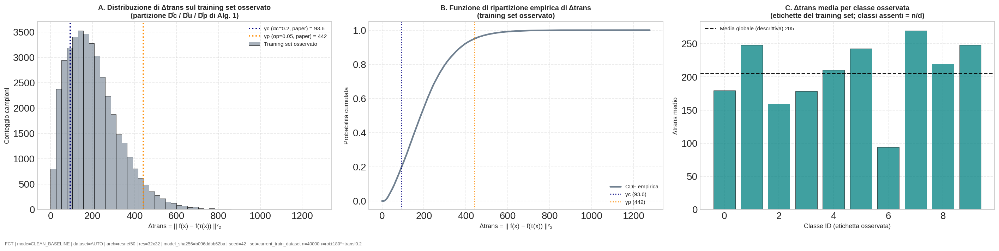

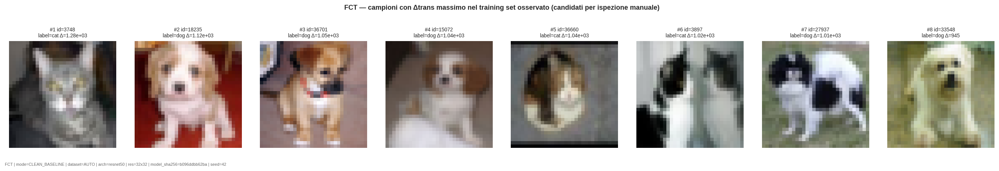

🧹 [Memory Cleanup] RAM: 4.01/31.35 GB (14.3%)


In [ ]:
# =====================================================================================================
# TECNICA 2: FEATURE CONSISTENCY TOWARDS TRANSFORMATIONS (FCT) — SCORE DI SENSIBILITÀ PER CAMPIONE
# W. Chen, B. Wu, H. Wang, "Effective Backdoor Defense by Exploiting Sensitivity of Poisoned Samples", NeurIPS 2022
# https://proceedings.neurips.cc/paper_files/paper/2022/file/3f9bbf77fbd858e5b6e39d39fe84ed2e-Paper-Conference.pdf
# - Eq. (1), Sez. 3.2: Δtrans(x) = ||f_θe(x) − f_θe(τ(x))||²₂, f_θe = rappresentazione penultima del modello
#   addestrato sul training set NON affidabile.
# - Modulo SD, Alg. 1 (App. A.1): Δtrans su OGNI campione del training set; γc/γp = quantili αc e (1−αp);
#   D̂c (Δ ≤ γc), D̂p (Δ ≥ γp), D̂u (resto). Parametri del paper: αc=0.20, αp=0.05, τ=rotate+affine (Sez. 4.1, App. C.5).
# - Il README attribuisce FCT a Hayase et al. (SPECTRE, 2021): attribuzione errata.
# Qui la partizione serve SOLO a prioritizzare l'ispezione manuale dei campioni: non è un verdetto sul modello.
# Le metriche che usano i flag di poison sono valutazioni oracle (solo modalità attaccante).
# Le funzioni fct_* sono definite fuori dal gating e riusate dalla cella 77 (Cross-Latent).
# Prestazioni: τ vettorizzata sul batch (affine_grid/grid_sample), batch grandi, AMP su CUDA, lettura dei file in
# thread; cache RAM degli input solo entro FCT_RAM_CACHE_MAX_GB, altrimenti streaming a batch.
# =====================================================================================================
import os
import math
import bisect
import hashlib
import weakref
import traceback
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Subset, ConcatDataset
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score
from tqdm.auto import tqdm

# ------------------------------------------------------------------------------
# PARAMETRI (default = valori del paper, App. C.5, e del codice ufficiale SCLBD/Effective_backdoor_defense)
# ------------------------------------------------------------------------------
FCT_ALPHA_C = float(globals().get("FCT_ALPHA_C", 0.20))               # αc: quota bottom-Δ -> D̂c
FCT_ALPHA_P = float(globals().get("FCT_ALPHA_P", 0.05))               # αp: quota top-Δ -> D̂p
FCT_ROTATION_DEG = float(globals().get("FCT_ROTATION_DEG", 180.0))    # 'Rotate': angolo casuale < 180° (RandomRotation(180))
FCT_TRANSLATE_FRAC = float(globals().get("FCT_TRANSLATE_FRAC", 0.2)) # 'Affine': traslazione orizz./vert. (RandomAffine(translate=(0.2, 0.2)))
FCT_BATCH_SIZE = int(globals().get("FCT_BATCH_SIZE", 256))            # batch di inferenza (GPU T4)
FCT_MAX_SAMPLES = globals().get("FCT_MAX_SAMPLES", None)              # None = intero training set (Alg. 1); int = sottoinsieme riproducibile da FCT_SEED
FCT_RAM_CACHE_MAX_GB = float(globals().get("FCT_RAM_CACHE_MAX_GB", 4.0))  # budget cache RAM degli input float32 (oltre: streaming); 0 = mai cache
FCT_IO_WORKERS = int(globals().get("FCT_IO_WORKERS", 16))             # thread di lettura file (solo percorso diretto FastCSVDataset)
FCT_SEED = int(globals().get("FCT_SEED", globals().get("SEED", 42)))
FCT_GALLERY_K = int(globals().get("FCT_GALLERY_K", 8))
FCT_PAPER_REF = "Chen, Wu, Wang, NeurIPS 2022"


def fct_feature_module(net):
    """Ultimo nn.Linear del modello: il suo input è f_θe (per ResNet = avgpool flatten, come children()[:-1] del codice ufficiale)."""
    last = None
    for _name, _mod in net.named_modules():
        if isinstance(_mod, nn.Linear):
            last = (_name, _mod)
    if last is None:
        raise RuntimeError("FCT: nessun nn.Linear finale, rappresentazione penultima non determinabile.")
    return last


def fct_draw_tau_params(n, seed):
    """Parametri di τ per campione da RNG locale (riproducibili, indipendenti dal batch size): u ~ U(-1, 1)."""
    gen = torch.Generator().manual_seed(int(seed))
    ang = torch.rand(n, generator=gen, dtype=torch.float64) * 2.0 - 1.0
    ux = torch.rand(n, generator=gen, dtype=torch.float64) * 2.0 - 1.0
    uy = torch.rand(n, generator=gen, dtype=torch.float64) * 2.0 - 1.0
    return ang.numpy(), ux.numpy(), uy.numpy()


def fct_apply_tau(x01, ang_u, ux, uy, rotation_deg, translate_frac):
    """τ = rotate + affine(traslazione) per campione su immagini in [0,1], vettorizzata sul batch con
    affine_grid/grid_sample (valida per immagini quadrate: l'input è sempre res×res). Interpolazione NEAREST e
    riempimento 0 = default torchvision di RandomRotation/RandomAffine usati dal codice ufficiale."""
    B, C, H, W = x01.shape
    device = x01.device

    angles = torch.as_tensor(ang_u * (rotation_deg * math.pi / 180.0), dtype=torch.float32, device=device)
    cos_a = torch.cos(angles)
    sin_a = torch.sin(angles)

    tx_px = torch.round(torch.as_tensor(ux * translate_frac * W, dtype=torch.float32, device=device))
    ty_px = torch.round(torch.as_tensor(uy * translate_frac * H, dtype=torch.float32, device=device))

    # Conversione in coordinate normalizzate [-1, 1] per grid_sample
    tx = (2.0 * tx_px / float(W)) * cos_a + (2.0 * ty_px / float(H)) * sin_a
    ty = -(2.0 * tx_px / float(W)) * sin_a + (2.0 * ty_px / float(H)) * cos_a

    theta = torch.zeros(B, 2, 3, dtype=torch.float32, device=device)
    theta[:, 0, 0] = cos_a
    theta[:, 0, 1] = sin_a
    theta[:, 0, 2] = -tx
    theta[:, 1, 0] = -sin_a
    theta[:, 1, 1] = cos_a
    theta[:, 1, 2] = -ty

    grid = F.affine_grid(theta, x01.size(), align_corners=False)
    out = F.grid_sample(x01, grid, mode='nearest', padding_mode='zeros', align_corners=False)
    return out


# ------------------------------------------------------------------------------
# CARICAMENTO DEGLI INPUT: selezione dei campioni, lettura diretta/generica, cache RAM con budget
# ------------------------------------------------------------------------------
_FCT_RAM_CACHE = {}   # slot unico {key, ref, x, y, n_resized}: svuotato a ogni cambio di dataset/indici/risoluzione


def fct_clear_ram_cache():
    """Libera la cache RAM degli input FCT."""
    _FCT_RAM_CACHE.clear()


def fct_select_sample_ids(n_total, max_samples, seed):
    """Indici (nel dataset passato) dei campioni analizzati: tutti, oppure max_samples estratti senza
    ripetizione con default_rng(seed) e ordinati (stessa semantica della versione per campione)."""
    if max_samples is not None and n_total > int(max_samples):
        _rng = np.random.default_rng(int(seed))
        return np.sort(_rng.choice(n_total, size=max(0, int(max_samples)), replace=False))
    return np.arange(n_total)


def _fct_direct_source(ds, idx, tfs=(), depth=0):
    """dataset[idx] come lettura diretta da file: (percorso, modo PIL, etichetta, trasformazioni in ordine), replicando
    __getitem__ dei wrapper noti (Subset, SubsetAttributeWrapper, TransformWrapper, ConcatDataset) su FastCSVDataset.
    None per qualunque altro dataset (es. LazyPoisonedDataset, TensorDataset): caricamento generico con dataset[i]."""
    if depth > 20:
        return None
    name = type(ds).__name__
    if name == "FastCSVDataset":
        own = getattr(ds, "transform", None)
        mode = "RGB" if int(globals().get("NUM_CHANNELS", 3)) == 3 else "L"
        return ds.resolved_paths[idx], mode, int(ds.targets[idx]), ((own,) if own is not None else ()) + tuple(tfs)
    if type(ds) is Subset or name == "SubsetAttributeWrapper":
        return _fct_direct_source(ds.dataset, int(ds.indices[idx]), tfs, depth + 1)
    if name == "TransformWrapper":
        own = getattr(ds, "transform", None)
        return _fct_direct_source(ds.dataset, idx, ((own,) if own is not None else ()) + tuple(tfs), depth + 1)
    if type(ds) is ConcatDataset:
        k = bisect.bisect_right(ds.cumulative_sizes, idx)
        prev = ds.cumulative_sizes[k - 1] if k > 0 else 0
        return _fct_direct_source(ds.datasets[k], idx - prev, tfs, depth + 1)
    return None


def _fct_direct_sources(dataset, sample_ids):
    """Sorgenti dirette per campione (None = dataset[i]); None se nessun campione è leggibile direttamente."""
    out = []
    for i in sample_ids:
        try:
            out.append(_fct_direct_source(dataset, int(i)))
        except Exception:
            out.append(None)
    return out if any(s is not None for s in out) else None


def _fct_read_direct(src):
    path, mode, label, tfs = src
    with Image.open(path) as im:
        img = im.convert(mode)
    for tf in tfs:
        img = tf(img)
    return img, label


def _fct_item_to_input(item, ctx_tf, hw):
    """(immagine, etichetta) -> (tensore CxHxW float32 alla risoluzione del modello, etichetta, ridimensionato?).
    Come il collate originale: trasformazione del contesto solo per immagini non tensoriali."""
    im = item[0]
    if not torch.is_tensor(im):
        im = ctx_tf(im)
    im = im.float()
    resized = tuple(im.shape[-2:]) != hw
    if resized:
        im = F.interpolate(im.unsqueeze(0), size=hw, mode="bilinear", align_corners=False).squeeze(0)
    return im, int(item[1]), resized


def _fct_iter_batches(dataset, sample_ids, sources, ctx, batch_size, io_workers):
    """Batch (x CPU float32, y int64, n. ridimensionati) nell'ordine di sample_ids. Campioni con sorgente diretta letti
    in thread con prefetch del batch successivo; gli altri con dataset[i] nel thread principale (ordine deterministico)."""
    hw = (int(ctx["target_res"]),) * 2
    ctx_tf = ctx["transform"]
    m, bs = len(sample_ids), max(1, int(batch_size))

    def _load(k):
        src = sources[k] if sources is not None else None
        item = _fct_read_direct(src) if src is not None else dataset[int(sample_ids[k])]
        return _fct_item_to_input(item, ctx_tf, hw)

    def _collect(parts):
        return (torch.stack([p[0] for p in parts], 0), torch.tensor([p[1] for p in parts], dtype=torch.long),
                sum(int(p[2]) for p in parts))

    if sources is None or int(io_workers) <= 1:
        for s in range(0, m, bs):
            yield _collect([_load(k) for k in range(s, min(s + bs, m))])
        return
    with ThreadPoolExecutor(max_workers=int(io_workers)) as pool:
        def _submit(s):
            return [pool.submit(_load, k) if sources[k] is not None else k for k in range(s, min(s + bs, m))]
        nxt = _submit(0)
        for s in range(0, m, bs):
            cur, nxt = nxt, (_submit(s + bs) if s + bs < m else [])
            yield _collect([_load(f) if isinstance(f, int) else f.result() for f in cur])


def _fct_dataset_signature(ds, depth=0):
    """Identità dell'oggetto dataset e dei wrapper annidati, con le loro trasformazioni (set_dataset_transform le
    modifica in place): dataset distinti della stessa lunghezza non condividono mai la cache."""
    if ds is None or depth > 20:
        return ()
    try:
        n = len(ds)
    except Exception:
        n = -1
    sig = ((type(ds).__name__, id(ds), n, id(getattr(ds, "transform", None)), id(getattr(ds, "post_transform", None))),)
    for child in [getattr(ds, "dataset", None), getattr(ds, "raw_dataset", None)] + list(getattr(ds, "datasets", None) or []):
        if child is not None and child is not ds:
            sig += _fct_dataset_signature(child, depth + 1)
    return sig


def _fct_cache_fits(nbytes, max_gb):
    """True se gli input float32 stanno nel budget e, se psutil è disponibile, in metà della RAM libera."""
    if max_gb is None or float(max_gb) <= 0 or nbytes > float(max_gb) * 1024 ** 3:
        return False
    try:
        import psutil
        return nbytes <= 0.5 * psutil.virtual_memory().available
    except Exception:
        return True


def fct_compute_scores(net, dataset, ctx, *, batch_size=256, max_samples=None, rotation_deg=180.0,
                       translate_frac=0.2, seed=42, return_features=False, verbose=True, desc="FCT",
                       ram_cache_max_gb=None, io_workers=None):
    """
    Δtrans(x) = ||f(x) − f(τ(x))||²₂ (Eq. 1) per campione, nell'ordine di sample_ids.
    Restituisce: sample_ids (indici nel dataset PASSATO: tutti, o max_samples estratti con default_rng(seed) e ordinati),
    labels (etichette restituite da dataset[i], cioè osservate), preds, scores, features (se richieste), n_outputs
    (None se non ci sono campioni, status='empty'), n_total = len(dataset), n_resized, input_mode, n_direct.
    Input: lettura diretta dei file in thread solo per FastCSVDataset, anche dietro Subset/SubsetAttributeWrapper/
    TransformWrapper/ConcatDataset (stessi indici, trasformazioni ed etichette di dataset[i]); altrimenti dataset[i].
    Cache RAM degli input (float32, chiave = identità del dataset e dei wrapper + risoluzione + indici selezionati,
    slot unico) solo se la stima m·C·res²·4 B rientra in ram_cache_max_gb (default FCT_RAM_CACHE_MAX_GB); altrimenti
    streaming a batch. Stessi input -> stessi score nei due percorsi. AMP (fp16) solo su CUDA.
    Il dataset viene letto solo come (immagine, etichetta): nessun flag di poison.
    """
    dev = next(net.parameters()).device
    n_total = len(dataset)
    sample_ids = fct_select_sample_ids(n_total, max_samples, seed)
    m = len(sample_ids)
    res = int(ctx["target_res"])
    bs = max(1, int(batch_size))
    max_gb = FCT_RAM_CACHE_MAX_GB if ram_cache_max_gb is None else float(ram_cache_max_gb)
    workers = FCT_IO_WORKERS if io_workers is None else int(io_workers)
    _, feat_mod = fct_feature_module(net)
    scores = np.full(m, np.nan)
    labels = np.full(m, -1, dtype=np.int64)
    preds = np.full(m, -1, dtype=np.int64)
    feats, pos, n_resized, n_out, n_direct = None, 0, 0, None, 0
    if m == 0:
        if verbose:
            print(f"⚠️ [{desc}] Nessun campione da analizzare (n_total={n_total}, max_samples={max_samples}).")
        if return_features:
            feats = np.empty((0, int(getattr(feat_mod, "in_features", 0))), dtype=np.float32)
        return {"sample_ids": sample_ids, "labels": labels, "preds": preds, "scores": scores, "features": feats,
                "n_outputs": None, "n_total": n_total, "n_resized": 0, "status": "empty", "input_mode": "n/d", "n_direct": 0}

    # Cache RAM: riuso solo per lo stesso oggetto dataset (weakref), stessi wrapper/trasformazioni, risoluzione e indici
    mean_np, std_np = np.asarray(ctx["mean"], dtype=np.float32), np.asarray(ctx["std"], dtype=np.float32)
    try:
        ref = weakref.ref(dataset)
        key = (_fct_dataset_signature(dataset), res, tuple(np.round(mean_np, 6).tolist()), tuple(np.round(std_np, 6).tolist()),
               hashlib.sha1(np.ascontiguousarray(sample_ids, dtype=np.int64).tobytes()).hexdigest())
    except TypeError:
        ref, key = None, None
    hit = key is not None and _FCT_RAM_CACHE.get("key") == key and _FCT_RAM_CACHE["ref"]() is dataset
    est_bytes = int(m) * max(1, mean_np.size) * res * res * 4
    if hit:
        x_all, y_all = _FCT_RAM_CACHE["x"], _FCT_RAM_CACHE["y"]
        n_resized = int(_FCT_RAM_CACHE["n_resized"])
        batches = ((x_all[s:s + bs], y_all[s:s + bs], 0) for s in range(0, m, bs))
        input_mode, store = "cache_reuse", False
    else:
        _FCT_RAM_CACHE.clear()   # la cache di un altro dataset non sopravvive (libera RAM prima di caricare)
        store = ref is not None and _fct_cache_fits(est_bytes, max_gb)
        sources = _fct_direct_sources(dataset, sample_ids)
        n_direct = 0 if sources is None else sum(s is not None for s in sources)
        batches = _fct_iter_batches(dataset, sample_ids, sources, ctx, bs, workers)
        input_mode = "stream+cache" if store else "stream"
        x_all, y_all = None, None
    if verbose:
        print(f"⏳ [{desc}] Δtrans su {m:,}/{n_total:,} campioni (τ = rotate ±{rotation_deg:g}° + translate {translate_frac:g}, seed={seed})...")
        if hit:
            print(f"   💾 Input dalla cache RAM ({x_all.element_size() * x_all.nelement() / 1024 ** 3:.2f} GB): nessuna lettura da disco.")
        else:
            print(f"   💾 Input float32 stimati {est_bytes / 1024 ** 3:.2f} GB -> "
                  + ("streaming + cache RAM per il riuso" if store else f"streaming a batch senza cache (budget {max_gb:g} GB)")
                  + f" | lettura diretta file ({workers} thread): {n_direct:,}/{m:,}, altri via dataset[i]")

    mean_t = torch.as_tensor(mean_np, device=dev).view(1, -1, 1, 1)
    std_t = torch.as_tensor(std_np, device=dev).view(1, -1, 1, 1)
    ang_u, ux, uy = fct_draw_tau_params(m, seed)
    use_amp = dev.type == "cuda"
    feat_store = {}

    def _hook_fn(_m, inp):
        feat_store["f"] = inp[0]

    handle = feat_mod.register_forward_pre_hook(_hook_fn)
    pbar = tqdm(batches, desc=f"[{desc}] Calcolo Δtrans", total=math.ceil(m / bs), disable=not verbose)
    try:
        with torch.no_grad():
            for x, y, nr in pbar:
                b = int(x.shape[0])
                n_resized += int(nr)
                if store:
                    if x_all is None:
                        if not _fct_cache_fits(m * x[0].numel() * 4, max_gb):   # forma reale diversa dalla stima
                            store, input_mode = False, "stream"
                        else:
                            x_all = torch.empty((m,) + tuple(x.shape[1:]), dtype=torch.float32)
                            y_all = torch.empty(m, dtype=torch.long)
                    if store:
                        x_all[pos:pos + b] = x
                        y_all[pos:pos + b] = y
                xd = x.to(dev, non_blocking=True)
                x01 = (xd * std_t + mean_t).clamp_(0.0, 1.0)
                xt = (fct_apply_tau(x01, ang_u[pos:pos + b], ux[pos:pos + b], uy[pos:pos + b], rotation_deg, translate_frac) - mean_t) / std_t
                with torch.amp.autocast(device_type=dev.type, enabled=use_amp):
                    feat_store.clear()
                    logits = net(xd)
                    if "f" not in feat_store:
                        raise RuntimeError("FCT: hook sulla rappresentazione penultima non attivato.")
                    f = feat_store["f"].flatten(1).float()
                    net(xt)
                    ft = feat_store["f"].flatten(1).float()
                scores[pos:pos + b] = ((f - ft) ** 2).sum(dim=1).double().cpu().numpy()
                labels[pos:pos + b] = y.numpy()
                preds[pos:pos + b] = logits.argmax(dim=1).cpu().numpy()
                if return_features:
                    if feats is None:
                        feats = np.empty((m, int(f.shape[1])), dtype=np.float32)
                    feats[pos:pos + b] = f.cpu().numpy()
                n_out = int(logits.shape[1])
                pos += b
    finally:
        handle.remove()
        feat_store.clear()
        if hasattr(batches, "close"):
            batches.close()
    if store and x_all is not None and pos == m:
        _FCT_RAM_CACHE.update(key=key, ref=ref, x=x_all, y=y_all, n_resized=n_resized)
    if verbose and n_resized:
        print(f"⚠️ [{desc}] {n_resized} campioni ridimensionati a {res}x{res}: il preprocessing del dataset non coincide con il contesto del modello.")
    return {"sample_ids": sample_ids, "labels": labels, "preds": preds, "scores": scores, "features": feats,
            "n_outputs": n_out, "n_total": n_total, "n_resized": n_resized, "status": "computed",
            "input_mode": input_mode, "n_direct": n_direct}


def fct_sd_partition(scores, alpha_c, alpha_p):
    """Alg. 1 (App. A.1), righe 7-17: S' crescente; indici come nel codice ufficiale (calculate_gamma.py):
    γc = S'[⌊αc·n⌋], γp = S'[n − ⌊αp·n⌋] (0-based). Δ ≤ γc -> 'D_c', altrimenti Δ ≥ γp -> 'D_p'
    (separate_samples.py), resto 'D_u'. Valori non finiti -> 'n/d'."""
    if not (0.0 < alpha_c < 1.0 and 0.0 < alpha_p < 1.0 and alpha_c + alpha_p <= 1.0):
        raise ValueError(f"FCT: proporzioni non valide (ac={alpha_c}, ap={alpha_p}).")
    s = np.asarray(scores, dtype=np.float64)
    fin = np.isfinite(s)
    n = int(fin.sum())
    part = np.full(s.shape, "n/d", dtype=object)
    if n == 0:
        return float("nan"), float("nan"), part
    srt = np.sort(s[fin])

    k_c = int(math.floor(alpha_c * n + 1e-9))
    k_p = max(1, int(math.floor(alpha_p * n + 1e-9)))
    gamma_c = float(srt[min(k_c, n - 1)])
    gamma_p = float(srt[max(0, n - k_p)])
    part[fin] = "D_u"
    part[fin & (s >= gamma_p)] = "D_p"
    part[fin & (s <= gamma_c)] = "D_c"
    return gamma_c, gamma_p, part


def fct_resolve_observed_train_set(ctx=None):
    """
    Training set osservato su cui il paper calcola Δtrans (Alg. 1). Stessa regola in tutte le modalità e stessi
    oggetti delle celle 73/75 (AC, Spectral), così i sample_id coincidono:
    - override utente `AC_SS_AUDIT_DATASET` (condiviso con 73/75);
    - modello addestrato in questa sessione (cella 22): `current_train_dataset`, cioè il dataset passato a fit()
      (avvelenato nella run attaccante, pulito in CLEAN_BASELINE);
    - modello importato / BLIND_AUDIT: `raw_train_dataset` + trasformazione di valutazione (vista `_AC_SS_PROVIDED_VIEW`);
    - nessun dataset (MODEL_ONLY): None.
    Nessun flag di poison, target o configurazione dell'attacco viene letto.
    """
    g = globals()
    if g.get("AC_SS_AUDIT_DATASET") is not None:
        return g["AC_SS_AUDIT_DATASET"], "AC_SS_AUDIT_DATASET (dataset fornito dall'utente)"
    mode = str(g.get("EXECUTION_MODE", "")).upper()
    trained_here = (not bool(g.get("USE_IMPORTED_MODEL", False))) and mode in ("ATTACKER_MODEL_LEVEL", "CLEAN_BASELINE", "FULL_PIPELINE_LEGACY")
    if trained_here and g.get("current_train_dataset") is not None:
        return g["current_train_dataset"], "current_train_dataset (training set passato a fit, cella 22)"
    raw = g.get("raw_train_dataset")
    if raw is not None and ctx is not None and callable(g.get("TransformWrapper")):
        tf = g.get("transform_pipeline") if ctx["is_pipeline"] else g.get("transform_scratch_test")
        tf = tf if tf is not None else ctx["transform"]
        view = g.get("_AC_SS_PROVIDED_VIEW")
        if not (isinstance(view, tuple) and len(view) == 3 and view[0] is raw and view[1] is tf):
            view = (raw, tf, g["TransformWrapper"](raw, tf))
            g["_AC_SS_PROVIDED_VIEW"] = view
        return view[2], "raw_train_dataset + trasformazione di valutazione (dataset fornito)"
    if g.get("clean_train_dataset") is not None:
        return g["clean_train_dataset"], "clean_train_dataset (dataset fornito)"
    return None, "nessun training set disponibile"


def fct_oracle_poison_flags(dataset, sample_ids):
    """SOLO VALUTAZIONE ORACLE: flag ground truth ricavati dalla composizione del dataset (componente
    LazyPoisonedDataset della cella 10). Mai usati per score, soglie o partizioni. None fuori dalle modalità oracle."""
    if not oracle_allowed():
        return None

    def _is_p(ds, i, depth=0):
        if depth > 20:
            return False
        if type(ds).__name__ == "LazyPoisonedDataset":
            return True
        if isinstance(ds, ConcatDataset):
            k = bisect.bisect_right(ds.cumulative_sizes, i)
            prev = ds.cumulative_sizes[k - 1] if k > 0 else 0
            return _is_p(ds.datasets[k], i - prev, depth + 1)
        if isinstance(ds, Subset):
            return _is_p(ds.dataset, int(ds.indices[i]), depth + 1)
        return False

    return np.array([_is_p(dataset, int(i)) for i in sample_ids], dtype=bool)


def fct_class_names(k):
    names = globals().get("CLASS_NAMES")
    if isinstance(names, (list, tuple)) and len(names) >= k:
        return [str(c) for c in names[:k]]
    return [f"C{c}" for c in range(k)]


def fct_display_image(dataset, sample_id, ctx):
    """Immagine HxWx3 in [0,1] (denormalizzata con le statistiche del contesto del modello) per l'ispezione visiva."""
    im = dataset[int(sample_id)][0]
    if not torch.is_tensor(im):
        im = ctx["transform"](im)
    im = im.detach().float().cpu()
    res = int(ctx["target_res"])
    if tuple(im.shape[-2:]) != (res, res):
        im = F.interpolate(im.unsqueeze(0), size=(res, res), mode="bilinear", align_corners=False).squeeze(0)
    arr = im.numpy().transpose(1, 2, 0) * np.asarray(ctx["std"]).reshape(1, 1, -1) + np.asarray(ctx["mean"]).reshape(1, 1, -1)
    if arr.shape[-1] == 1:
        arr = np.repeat(arr, 3, axis=-1)
    return np.clip(arr, 0.0, 1.0)


_FCT_KEYS = ["fct_n_samples", "fct_score_mean", "fct_score_median", "fct_alpha_c_threshold", "fct_alpha_p_threshold"]
_FCT_ORACLE_KEYS = ["fct_n_poison_gt", "fct_clean_mean", "fct_clean_std", "fct_poison_mean", "fct_poison_std",
                    "fct_sensitivity_ratio", "fct_auc_roc", "fct_optimal_threshold", "fct_clean_precision_dc",
                    "fct_poison_precision_dp", "fct_poison_recall_dp"]


def _fct_rec(key, value, status="computed", gt=False, **kw):
    """record_metric + global legacy omonimo (letto dalla cella 93)."""
    kw.setdefault("method", "FCT")
    kw.setdefault("level", "model")
    v = record_metric(key, value, status, requires_ground_truth=gt, **kw)
    globals()[key] = v
    return v


def _fct_record_all(status, note):
    for _k in _FCT_KEYS:
        _fct_rec(_k, float("nan"), status, note=note)
    for _k in _FCT_ORACLE_KEYS:
        _fct_rec(_k, float("nan"), status, gt=True, note=note)


# Helper legacy non fedeli (restituivano medie precalcolate ignorando gli argomenti) e cache RAM della versione
# precedente (chiave len(dataset)+risoluzione, condivisa tra dataset diversi): rimossi.
for _fct_stale in ["compute_fct_class_consistency", "compute_fct_hayase"] + [k for k in list(globals()) if k.startswith("_CACHED_RAM_TENSORS_")]:
    globals().pop(_fct_stale, None)

if should_run_section('FCT'):
    clean_memory()
    print("\n" + "=" * 85)
    print(f"🔬 [FCT] SENSIBILITÀ DELLE FEATURE A TRASFORMAZIONI τ - modulo SD ({FCT_PAPER_REF}, Alg. 1)")
    print(f"   ac={FCT_ALPHA_C:g} | ap={FCT_ALPHA_P:g} | t = rotate ±{FCT_ROTATION_DEG:g}° + translate {FCT_TRANSLATE_FRAC:g} (App. C.5)")
    print("=" * 85)
    if oracle_allowed():
        _fct_rep = (checkpoint_meta.get("best_report", {}) if isinstance(globals().get("checkpoint_meta"), dict)
                    else (best_overall_config if isinstance(globals().get("best_overall_config"), dict) else {}))
        print(f"🎯 [CONTESTO ORACLE] Val F1: {_fct_rep.get('final_val_f1', 'n/d')} | Val ASR: {_fct_rep.get('final_val_asr', 'n/d')}")

    fct_res, fct_ctx, fct_ds, fct_source = None, None, None, "n/d"
    fct_net = get_audit_model(required=False)
    if fct_net is None:
        print("⚠️ [FCT] Nessun modello disponibile: sezione non applicabile.")
        _fct_record_all("not_applicable", "nessun modello disponibile")
    else:
        fct_ctx = get_model_eval_context(fct_net)
        fct_ds, fct_source = fct_resolve_observed_train_set(fct_ctx)
        if fct_ds is None or len(fct_ds) == 0:
            print("⚠️ [FCT] Nessun training set osservato: Alg. 1 richiede il training set.")
            _fct_record_all("not_applicable", "nessun training set osservato")
        else:
            print(f"📦 Training set osservato: {fct_source} - {len(fct_ds):,} campioni | strategia={fct_ctx['strategy']} | input {fct_ctx['target_res']}x{fct_ctx['target_res']}")
            try:
                with preserve_model_state(fct_net):
                    fct_net.eval()
                    fct_res = fct_compute_scores(
                        fct_net, fct_ds, fct_ctx, batch_size=FCT_BATCH_SIZE, max_samples=FCT_MAX_SAMPLES,
                        rotation_deg=FCT_ROTATION_DEG, translate_frac=FCT_TRANSLATE_FRAC, seed=FCT_SEED)
            except Exception as _fct_err:
                print(f"❌ [FCT] Calcolo fallito: {_fct_err}\n{traceback.format_exc(limit=3)}")
                _fct_record_all("failed", f"errore: {_fct_err}")
                fct_res = None
            finally:
                check_model_integrity("FCT")

    fct_min_n = max(2, int(math.ceil(1.0 / min(FCT_ALPHA_C, FCT_ALPHA_P))))
    if fct_res is not None and int(np.isfinite(fct_res["scores"]).sum()) < fct_min_n:
        print(f"⚠️ [FCT] Meno di {fct_min_n} score finiti: partizione ac/ap non significativa.")
        _fct_record_all("insufficient_data", f"meno di {fct_min_n} campioni con score finito")
        fct_res = None

    if fct_res is not None:
        fct_scores = fct_res["scores"]
        fct_labels = fct_res["labels"]
        fct_fin = np.isfinite(fct_scores)
        fct_n = int(fct_fin.sum())
        fct_gamma_c, fct_gamma_p, fct_part = fct_sd_partition(fct_scores, FCT_ALPHA_C, FCT_ALPHA_P)
        fct_rank = np.full(len(fct_scores), np.nan)
        fct_rank[np.where(fct_fin)[0][np.argsort(-fct_scores[fct_fin], kind="stable")]] = np.arange(1, fct_n + 1)
        fct_strategy = str(fct_ctx["strategy"]).lower()
        fct_unit = "||Δf||² (unità del feature space penultimo)"
        fct_paper_origin = "paper:Chen2022 Alg.1 r.8; ac/ap di Sez. 4.1"
        _fct_note_part = "quantile del training set osservato"

        _fct_rec("fct_n_samples", fct_n, unit="campioni",
                 note=f"{fct_source}; analizzati {len(fct_scores)}/{fct_res['n_total']} (max_samples={FCT_MAX_SAMPLES}, seed={FCT_SEED}); non finiti esclusi: {len(fct_scores) - fct_n}")
        _fct_rec("fct_score_mean", float(np.mean(fct_scores[fct_fin])), unit=fct_unit)
        _fct_rec("fct_score_median", float(np.median(fct_scores[fct_fin])), unit=fct_unit)
        _fct_rec("fct_alpha_c_threshold", fct_gamma_c, unit=fct_unit, threshold=FCT_ALPHA_C, threshold_origin=fct_paper_origin)
        _fct_rec("fct_alpha_p_threshold", fct_gamma_p, unit=fct_unit, threshold=FCT_ALPHA_P, threshold_origin=fct_paper_origin)

        fct_K = int(max(fct_res["n_outputs"] or 0, int(fct_labels.max()) + 1 if len(fct_labels) else 0))
        fct_cls_names = fct_class_names(fct_K)
        fct_class_rows = []
        for _c in range(fct_K):
            _m = (fct_labels == _c) & fct_fin
            _nc = int(_m.sum())
            _ndp = int(np.sum(_m & (fct_part == "D_p")))
            _ndc = int(np.sum(_m & (fct_part == "D_c")))
            fct_class_rows.append({
                "class_id": _c, "class_name": fct_cls_names[_c], "n": _nc,
                "mean_score": float(np.mean(fct_scores[_m])) if _nc else float("nan"),
                "median_score": float(np.median(fct_scores[_m])) if _nc else float("nan"),
                "n_in_Dp": _ndp, "share_Dp_pct": (100.0 * _ndp / _nc) if _nc else float("nan"),
                "n_in_Dc": _ndc, "share_Dc_pct": (100.0 * _ndc / _nc) if _nc else float("nan"),
                "status": "computed" if _nc else "insufficient_data",
            })
        FCT_CLASS_TABLE = pd.DataFrame(fct_class_rows)
        FCT_CLASS_TABLE["rank_Dp"] = FCT_CLASS_TABLE["share_Dp_pct"].rank(ascending=False, method="min")

        print("\n" + "=" * 85)
        print("📊 [REPORT FCT] MODULO SD SUL TRAINING SET OSSERVATO")
        print("=" * 85)
        print(pd.DataFrame([
            ("Campioni con Δtrans finito", f"{fct_n:,}"),
            ("Δtrans mediana / media", f"{np.median(fct_scores[fct_fin]):.6g} / {np.mean(fct_scores[fct_fin]):.6g}"),
            (f"γc (quantile ac={FCT_ALPHA_C:g}) -> D^c", f"Δtrans <= {fct_gamma_c:.6g} ({int(np.sum(fct_part == 'D_c')):,} campioni)"),
            (f"γp (quantile 1-ap, ap={FCT_ALPHA_P:g}) -> D^p", f"Δtrans >= {fct_gamma_p:.6g} ({int(np.sum(fct_part == 'D_p')):,} campioni)"),
            ("D^u (incerti)", f"{int(np.sum(fct_part == 'D_u')):,} campioni"),
        ], columns=["Grandezza", "Valore"]).to_string(index=False))

        # --------------------------------------------------------------------------
        # 2. Valutazione ORACLE
        # --------------------------------------------------------------------------
        fct_gt_all = fct_oracle_poison_flags(fct_ds, fct_res["sample_ids"])
        fct_roc = None
        fct_youden_point = None
        if fct_gt_all is None:
            for _k in _FCT_ORACLE_KEYS:
                _fct_rec(_k, float("nan"), gt=True)
        else:
            _gt = fct_gt_all[fct_fin]
            _s = fct_scores[fct_fin]
            _p = fct_part[fct_fin]
            _np_gt, _nc_gt = int(_gt.sum()), int((~_gt).sum())
            _fct_rec("fct_n_poison_gt", _np_gt, gt=True, unit="campioni")
            if _nc_gt:
                _fct_rec("fct_clean_mean", float(np.mean(_s[~_gt])), gt=True, unit=fct_unit)
                _fct_rec("fct_clean_std", float(np.std(_s[~_gt])), gt=True)
            else:
                for _k in ("fct_clean_mean", "fct_clean_std"):
                    _fct_rec(_k, float("nan"), "insufficient_data", gt=True)
            _dc, _dp = (_p == "D_c"), (_p == "D_p")
            if _np_gt and _nc_gt:
                _fct_rec("fct_clean_precision_dc", float(np.mean(~_gt[_dc])) if _dc.any() else float("nan"),
                         "computed" if _dc.any() else "insufficient_data", gt=True, unit="frazione")
                _pm, _cm = float(np.mean(_s[_gt])), float(np.mean(_s[~_gt]))
                _fct_rec("fct_poison_mean", _pm, gt=True, unit=fct_unit)
                _fct_rec("fct_poison_std", float(np.std(_s[_gt])), gt=True, unit=fct_unit)
                _fct_rec("fct_sensitivity_ratio", _pm / _cm if _cm > 0 else float("nan"), "computed" if _cm > 0 else "degenerate", gt=True, unit="rapporto")
                _fct_rec("fct_auc_roc", float(roc_auc_score(_gt.astype(int), _s)), gt=True, unit="AUC")
                _fpr, _tpr, _thr = roc_curve(_gt.astype(int), _s)
                _j = int(np.argmax(_tpr - _fpr))
                _thr_j = float(_thr[_j]) if np.isfinite(_thr[_j]) else float("nan")
                _fct_rec("fct_optimal_threshold", _thr_j, gt=True, unit=fct_unit, threshold_origin="calibrated:Youden")
                _fct_rec("fct_poison_precision_dp", float(np.mean(_gt[_dp])) if _dp.any() else float("nan"),
                         "computed" if _dp.any() else "insufficient_data", gt=True, unit="frazione")
                _fct_rec("fct_poison_recall_dp", float(np.sum(_gt & _dp) / _np_gt), gt=True, unit="frazione")
                fct_roc = (_fpr, _tpr)
                fct_youden_point = (_fpr[_j], _tpr[_j], _thr_j)
            else:
                for _k in ("fct_poison_mean", "fct_poison_std", "fct_sensitivity_ratio", "fct_auc_roc", "fct_optimal_threshold",
                           "fct_clean_precision_dc", "fct_poison_precision_dp", "fct_poison_recall_dp"):
                    _fct_rec(_k, float("nan"), "not_applicable", gt=True)

        # --------------------------------------------------------------------------
        # 3. Tabella e Salvataggio
        # --------------------------------------------------------------------------
        fct_pred_all = fct_res["preds"]
        FCT_SAMPLE_TABLE = pd.DataFrame({
            "sample_id": fct_res["sample_ids"], "observed_label": fct_labels,
            "class_name": [fct_cls_names[int(_l)] if 0 <= int(_l) < fct_K else str(_l) for _l in fct_labels],
            "pred": fct_pred_all, "fct_score": fct_scores, "rank": fct_rank, "partition": fct_part,
        })
        if fct_gt_all is not None:
            FCT_SAMPLE_TABLE["oracle_is_poison"] = fct_gt_all
        FCT_OBSERVED_TRAIN_SET = fct_ds
        FCT_RUN_INFO = {"source": fct_source, "model_sha256": globals().get("AUDIT_MODEL_FINGERPRINT"), "n": fct_n,
                        "alpha_c": FCT_ALPHA_C, "alpha_p": FCT_ALPHA_P, "rotation_deg": FCT_ROTATION_DEG,
                        "translate_frac": FCT_TRANSLATE_FRAC, "seed": FCT_SEED, "max_samples": FCT_MAX_SAMPLES,
                        "n_total": fct_res["n_total"], "input_mode": fct_res.get("input_mode")}

        fct_out_dir = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "/kaggle/working"))
        os.makedirs(fct_out_dir, exist_ok=True)
        fct_csv_path = os.path.join(fct_out_dir, f"fct_sample_scores_{fct_strategy}.csv")
        try:
            FCT_SAMPLE_TABLE.to_csv(fct_csv_path, index=False)
            register_artifact("FCT", fct_csv_path, kind="table", note="Δtrans per campione")
        except Exception as _fct_err:
            print(f"⚠️ [FCT] Tabella per campione non salvata: {_fct_err}")

        # --------------------------------------------------------------------------
        # 4. Grafici
        # --------------------------------------------------------------------------
        fct_fig, fct_axes = plt.subplots(1, 3, figsize=(22, 5.5), dpi=130)
        _sf = fct_scores[fct_fin]
        fct_bins = np.linspace(float(np.min(_sf)), max(float(np.max(_sf)), float(np.min(_sf)) + 1e-9), 50)
        if fct_gt_all is not None and fct_gt_all[fct_fin].any():
            _g = fct_gt_all[fct_fin]
            sns.histplot(_sf[~_g], bins=fct_bins, color="dodgerblue", label="Puliti (oracle)", alpha=0.45, edgecolor="black", linewidth=0.4, ax=fct_axes[0])
            sns.histplot(_sf[_g], bins=fct_bins, color="crimson", label="Avvelenati (oracle)", alpha=0.45, edgecolor="black", linewidth=0.4, ax=fct_axes[0])
        else:
            sns.histplot(_sf, bins=fct_bins, color="slategray", label="Training set osservato", alpha=0.6, edgecolor="black", linewidth=0.4, ax=fct_axes[0])
        fct_axes[0].axvline(fct_gamma_c, color="navy", linestyle=":", linewidth=2, label=f"γc (ac={FCT_ALPHA_C:g}) = {fct_gamma_c:.3g}")
        fct_axes[0].axvline(fct_gamma_p, color="darkorange", linestyle=":", linewidth=2, label=f"γp (ap={FCT_ALPHA_P:g}) = {fct_gamma_p:.3g}")
        fct_axes[0].set_title("A. Distribuzione di Δtrans sul training set\n(partizione D^c / D^u / D^p)", fontsize=11, fontweight="bold")
        fct_axes[0].set_xlabel("Δtrans = || f(x) - f(t(x)) ||²", fontsize=10)
        fct_axes[0].set_ylabel("Conteggio campioni", fontsize=10)
        fct_axes[0].legend(fontsize=8.5)
        fct_axes[0].grid(True, linestyle="--", alpha=0.4)

        if fct_roc is not None:
            _fpr, _tpr = fct_roc
            fct_axes[1].plot(_fpr, _tpr, color="crimson", linewidth=2.5, label=f"ROC (AUC = {RUN_RESULTS.get('fct_auc_roc', float('nan')):.4f})")
            fct_axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random guess")
            if fct_youden_point:
                fct_axes[1].scatter([fct_youden_point[0]], [fct_youden_point[1]], color="black", s=60, zorder=5, label=f"Youden (soglia {fct_youden_point[2]:.3g})")
            fct_axes[1].set_title("B. Curva ROC Oracle\n(discriminazione clean vs poison)", fontsize=11, fontweight="bold")
            fct_axes[1].set_xlabel("False Positive Rate", fontsize=10)
            fct_axes[1].set_ylabel("True Positive Rate", fontsize=10)
            fct_axes[1].legend(loc="lower right", fontsize=8.5)
        else:
            _srt = np.sort(_sf)
            fct_axes[1].plot(_srt, np.arange(1, len(_srt) + 1) / len(_srt), color="slategray", linewidth=2.5, label="CDF empirica")
            fct_axes[1].axvline(fct_gamma_c, color="navy", linestyle=":", label=f"γc ({fct_gamma_c:.3g})")
            fct_axes[1].axvline(fct_gamma_p, color="darkorange", linestyle=":", label=f"γp ({fct_gamma_p:.3g})")
            fct_axes[1].set_title("B. CDF empirica di Δtrans\n(training set osservato)", fontsize=11, fontweight="bold")
            fct_axes[1].set_xlabel("Δtrans", fontsize=10)
            fct_axes[1].set_ylabel("Probabilità cumulata", fontsize=10)
            fct_axes[1].legend(loc="lower right", fontsize=8.5)
        fct_axes[1].grid(True, linestyle="--", alpha=0.4)

        _present = FCT_CLASS_TABLE["n"].values > 0
        fct_axes[2].bar(FCT_CLASS_TABLE["class_id"].values[_present], FCT_CLASS_TABLE["mean_score"].values[_present],
                        color="teal", alpha=0.75, edgecolor="black", linewidth=0.5)
        fct_axes[2].axhline(float(np.mean(_sf)), color="black", linestyle="--", label=f"Media globale {np.mean(_sf):.3g}")
        fct_axes[2].set_title("C. Δtrans media per classe\n(etichette del training set)", fontsize=11, fontweight="bold")
        fct_axes[2].set_xlabel("Classe ID", fontsize=10)
        fct_axes[2].set_ylabel("Δtrans medio", fontsize=10)
        fct_axes[2].legend(fontsize=8.5)
        fct_axes[2].grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()

        fct_img_filename = f"fct_consistency_distribution_{fct_strategy}.png"
        fct_save_path = os.path.join(fct_out_dir, fct_img_filename)
        fct_fig.savefig(fct_save_path, bbox_inches="tight", dpi=130)
        register_artifact("FCT", fct_save_path, kind="figure")
        FCT_PLOT_IMG_PATH = fct_save_path
        record_metric("fct_plot_img", fct_img_filename, method="FCT", unit="file")
        print(f"📸 [FCT] Grafico salvato in: {fct_save_path}")
        plt.show()
        plt.close(fct_fig)

        # Galleria campioni
        _fct_top = FCT_SAMPLE_TABLE.dropna(subset=["rank"]).sort_values("rank").head(max(1, FCT_GALLERY_K))
        if len(_fct_top) > 0:
            fct_gal, fct_gal_axes = plt.subplots(1, len(_fct_top), figsize=(2.6 * len(_fct_top), 3.4), dpi=130)
            fct_gal_axes = np.atleast_1d(fct_gal_axes)
            for _ax, _r in zip(fct_gal_axes, _fct_top.itertuples(index=False)):
                try:
                    _ax.imshow(fct_display_image(fct_ds, _r.sample_id, fct_ctx))
                except Exception as _fct_err:
                    _ax.text(0.5, 0.5, f"n/d\n{_fct_err}", ha="center", va="center", fontsize=6)
                _tag = ""
                if fct_gt_all is not None:
                    _tag = "\n(oracle: " + ("poison" if bool(_r.oracle_is_poison) else "clean") + ")"
                _ax.set_title(f"#{int(_r.rank)} id={int(_r.sample_id)}\nlabel={str(_r.class_name)[:12]} Δ={_r.fct_score:.3g}{_tag}", fontsize=7.5)
                _ax.axis("off")
            fct_gal.suptitle("FCT - Campioni con Δtrans massimo (candidati ispezione manuale)", fontsize=10, fontweight="bold")
            plt.tight_layout()
            fct_gal_path = os.path.join(fct_out_dir, f"fct_top_sensitive_{fct_strategy}.png")
            fct_gal.savefig(fct_gal_path, bbox_inches="tight", dpi=130)
            register_artifact("FCT", fct_gal_path, kind="figure", note="top Δtrans")
            FCT_GALLERY_IMG_PATH = fct_gal_path
            plt.show()
            plt.close(fct_gal)

    clean_memory(verbose=True)
else:
    _fct_record_all("not_run", "sezione FCT non inclusa nella modalità attiva")


---
## 👥 22. Activation Clustering


🛡️ [ACTIVATION CLUSTERING (Chen et al., arXiv:1811.03728)] — ANALYSIS OF THE OBSERVED DATA
📦 Model: ResNet | Resolution: 32x32 | Strategy: scratch
🔹 Observed dataset: training set used to train the model (cell 22: current_train_dataset)
🔹 Samples analyzed: 40000/40000 | Segmentation: label
   … batch 31/157
   … batch 62/157
   … batch 93/157
   … batch 124/157
   … batch 155/157
✅ Representations (40000, 2048) from input of 'fc' (last hidden layer, 2048 dim) in 49.4s

📊 [ACTIVATION CLUSTERING REPORT] Median silhouette: 0.0728 | MAD: 0.0040 | anomaly index status: computed
   Paper flags: silhouette ≥ 0.10 (Chen et al. Sec. 5/6.3, empirical range .10–.15) | relative size ≤ 0.35 (defender prior, Sec. 5). MAD anomaly index = exploratory indicator.
 Class ID Class Name  Samples    Status Silhouette (k=2) Anomaly Index (MAD) Relative Size (smaller) Cluster Ratio (min/max) Explained Var. (n comp.)  ICA Comp.  ICA conv.  Sil. Flag (paper)  Size Flag (paper)  Candidate (sil+size)
         0 

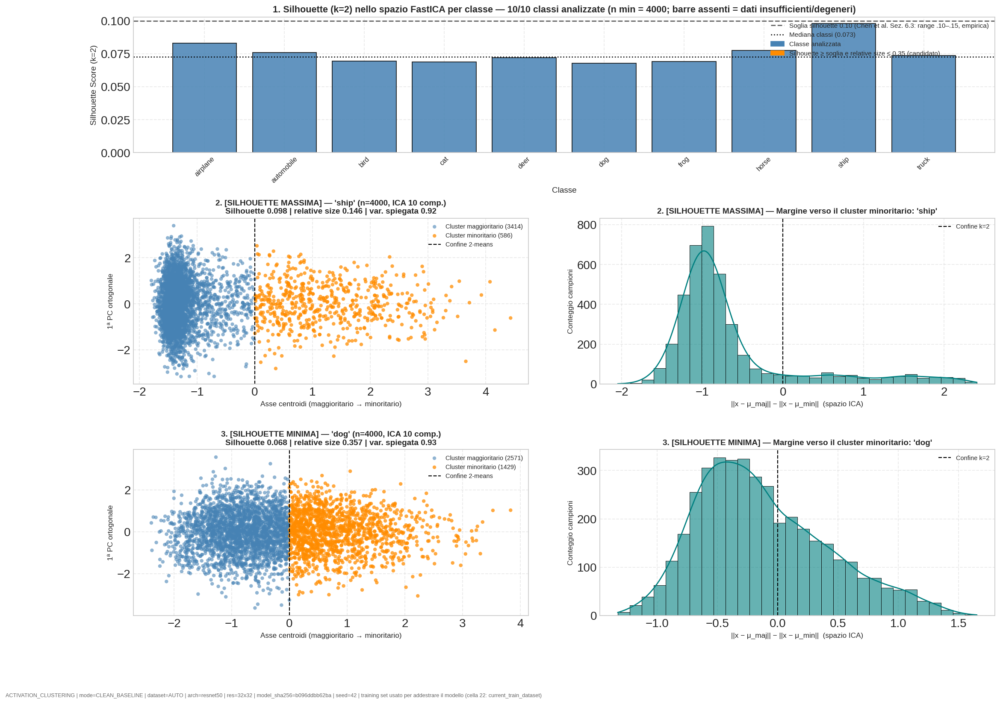

💾 Sub-cluster preview saved to: /kaggle/working/activation_clustering_preview_scratch_class_8.png


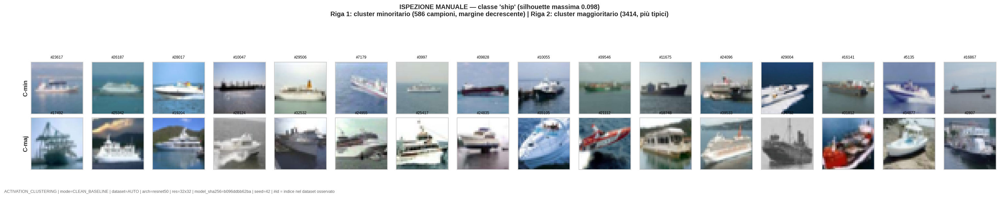

In [45]:
# Scalar keys of Activation Clustering: recorded with explicit status even when the section does not run.
_AC_METHOD = "ACTIVATION_CLUSTERING"
_AC_DETECTOR_KEYS = {
    "ac_top_suspect_class": ("class", "class_id"),
    "ac_top_suspect_name": ("class", None),
    "ac_max_silhouette": ("class", "silhouette"),
    "ac_max_anomaly_index": ("class", "robust_z"),
    "ac_global_median_silhouette": ("model", "silhouette"),
    "ac_top_suspect_relative_size": ("class", "fraction"),
    "ac_n_classes_analyzed": ("model", "count"),
    "ac_n_classes_insufficient": ("model", "count"),
    "ac_n_flag_silhouette": ("model", "count"),
    "ac_n_flag_relative_size": ("model", "count"),
    "ac_n_flag_joint": ("model", "count"),
}
_AC_ORACLE_KEYS = {
    "ac_target_silhouette": ("class", "silhouette"),
    "ac_target_anomaly_index": ("class", "robust_z"),
    "ac_target_cluster_ratio": ("class", "ratio"),
    "ac_target_relative_size": ("class", "fraction"),
    "ac_eval_target_poison_fraction": ("class", "fraction"),
    "ac_eval_target_minor_recall": ("class", "fraction"),
    "ac_eval_target_minor_precision": ("class", "fraction"),
    "ac_eval_target_split_accuracy": ("class", "fraction"),
    "ac_eval_flagged_recall": ("model", "fraction"),
    "ac_eval_flagged_precision": ("model", "fraction"),
}


def _ac_clear_stale_outputs():
    # Prevents figures or scalars of a previous run from being re-read by the export.
    for _g in ("AC_PLOT_IMG_PATH", "AC_PREVIEW_IMG_PATH", "ac_suspected_backdoor", *_AC_DETECTOR_KEYS, *_AC_ORACLE_KEYS):
        globals().pop(_g, None)
    RUN_RESULTS.pop("ac_suspected_backdoor", None)


def _ac_record_unavailable(status, note):
    _ac_clear_stale_outputs()
    for _k, (_lvl, _unit) in _AC_DETECTOR_KEYS.items():
        record_metric(_k, float("nan"), status, method=_AC_METHOD, level=_lvl, unit=_unit, note=note)
    for _k, (_lvl, _unit) in _AC_ORACLE_KEYS.items():
        record_metric(_k, float("nan"), status, method=_AC_METHOD, level=_lvl, unit=_unit,
                      requires_ground_truth=True, note=note)


if should_run_section('ACTIVATION_CLUSTERING'):
    clean_memory() if "clean_memory" in globals() else None
    # =====================================================================================================
    # TECHNIQUE 3: ACTIVATION CLUSTERING (AC) — B. Chen et al., "Detecting Backdoor Attacks on Deep Neural
    # Networks by Activation Clustering", arXiv:1811.03728 (SafeAI@AAAI 2019), Sez. 5 (Alg. 1) e Sez. 6.
    # Activations of the last hidden layer of the OBSERVED data, segmented by label, FastICA reduction
    # (10 components, Sec. 6), 2-means per class, cluster analysis (relative size, silhouette, Sec. 5).
    # Exclusionary Reclassification (method recommended by the paper, Sec. 6.3) is NOT implemented: it requires
    # a re-training per cluster. The result is a ranking for manual inspection, not a verdict.
    # The computation path is identical in all modes; the ground truth is used only for evaluation.
    # =====================================================================================================
    import os
    import time
    import hashlib
    import warnings
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, ConcatDataset, Subset, Dataset
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.decomposition import FastICA, PCA
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    from sklearn.exceptions import ConvergenceWarning
    from matplotlib.patches import Patch

    _ac_clear_stale_outputs()

    # ------------------------------------------------------------------------------
    # 0. DECLARED PARAMETERS (overridable from globals; none depends on the attack)
    # ------------------------------------------------------------------------------
    AC_PARAMS = {
        "n_components": int(globals().get("AC_N_COMPONENTS", 10)),         # Chen et al. Sec. 6 (6/10/14 equivalent)
        "ica_max_iter": int(globals().get("AC_ICA_MAX_ITER", 1000)),        # like ART reduce_dimensionality
        "ica_tol": float(globals().get("AC_ICA_TOL", 0.005)),
        "kmeans_n_init": int(globals().get("AC_KMEANS_N_INIT", 15)),
        "min_n": int(globals().get("AC_MIN_SAMPLES_PER_CLASS", 50)),        # heuristic: >= 5 samples per ICA dimension
        "sil_threshold": float(globals().get("AC_SILHOUETTE_THRESHOLD", 0.10)),  # paper Sez. 5/6.3: range .10–.15
        "size_threshold": float(globals().get("AC_SIZE_THRESHOLD", 0.35)),  # defender's prior p (Sec. 5); 0.35 = ART default
        "segment_by": str(globals().get("AC_SEGMENT_BY", "label")).lower(),  # 'label' (text of Sec. 5, ART) | 'prediction' (Alg. 1)
        "layer": globals().get("AC_LAYER", None),                           # None = input of the final linear classifier
        "max_samples": globals().get("AC_MAX_SAMPLES", None),               # None = all samples (Alg. 1)
        "batch_size": globals().get("AC_BATCH_SIZE", None),
        "use_amp": bool(globals().get("AC_USE_AMP", False)),
        "sil_sample_size": globals().get("AC_SILHOUETTE_SAMPLE_SIZE", None),
        "entity_top_per_class": int(globals().get("AC_ENTITY_TOP_PER_CLASS", 100)),
        "use_cache": bool(globals().get("AC_SS_USE_CACHE", True)),
        "preview_n": int(globals().get("AC_PREVIEW_N", 16)),
    }
    _AC_SEED = int(globals().get("SEED", 42))
    if AC_PARAMS["segment_by"] not in ("label", "prediction"):
        raise ValueError("AC_SEGMENT_BY must be 'label' or 'prediction'")

    # ------------------------------------------------------------------------------
    # 1. OBSERVED DATASET (same rule in all modes, no knowledge of the attack)
    # ------------------------------------------------------------------------------
    def _ac_resolve_observed_dataset(ctx):
        """Order: user override -> training set actually used (model trained in the session)
        -> provided training dataset with the model's evaluation transformation."""
        g = globals()
        if g.get("AC_SS_AUDIT_DATASET") is not None:
            return g["AC_SS_AUDIT_DATASET"], "AC_SS_AUDIT_DATASET (user-provided dataset)", None
        trained_here = (not g.get("USE_IMPORTED_MODEL", False)) and str(g.get("AUDIT_MODEL_SOURCE", "")).startswith("training:")
        if trained_here and g.get("current_train_dataset") is not None:
            note = None
            cfg_last, cfg_best = g.get("config"), g.get("best_overall_config")
            if isinstance(cfg_last, dict) and isinstance(cfg_best, dict) and cfg_last != cfg_best:
                note = ("grid with multiple experiments: current_train_dataset is the training set of the last "
                        "experiment, not necessarily of the selected model")
            return g["current_train_dataset"], "training set used to train the model (cell 22: current_train_dataset)", note
        tf = g.get("transform_pipeline") if ctx["is_pipeline"] else g.get("transform_scratch_test")
        tf = tf if tf is not None else ctx["transform"]
        raw = g.get("raw_train_dataset")
        if raw is not None and "TransformWrapper" in g:
            view = g.get("_AC_SS_PROVIDED_VIEW")   # same view for AC and Spectral (cache of the representations)
            if not (isinstance(view, tuple) and view[0] is raw and view[1] is tf):
                view = (raw, tf, g["TransformWrapper"](raw, tf))
                g["_AC_SS_PROVIDED_VIEW"] = view
            return (view[2], "provided training dataset (raw_train_dataset + model evaluation transformation)",
                    "it is not guaranteed that the provided dataset is the one used to train the inspected model")
        return None, None, "no dataset available: AC analyzes the activations of the training data (Chen et al., Alg. 1)"

    def _ac_select_indices(ds, max_samples, seed):
        n = len(ds)
        if not max_samples or int(max_samples) >= n:
            return np.arange(n, dtype=np.int64)
        rng = np.random.default_rng(seed)
        tg = getattr(ds, "targets", None)
        if tg is not None and len(tg) == n:
            tg = np.asarray(tg)
            idx = []
            for c in np.unique(tg):
                pool = np.where(tg == c)[0]
                k = max(1, int(round(int(max_samples) * len(pool) / n)))
                idx.append(rng.choice(pool, size=min(k, len(pool)), replace=False))
            return np.sort(np.concatenate(idx)).astype(np.int64)
        return np.sort(rng.choice(n, size=int(max_samples), replace=False)).astype(np.int64)

    # ------------------------------------------------------------------------------
    # 2. REPRESENTATIONS OF THE LAST HIDDEN LAYER (deterministic hook, removed in finally)
    # ------------------------------------------------------------------------------
    def _ac_find_classifier_linear(net):
        last = (None, None)
        for name, m in net.named_modules():
            if isinstance(m, nn.Linear):
                last = (name, m)
        return last

    def _ac_collate(batch):
        # Image and label only: any extra fields (e.g. poison flags) do not reach the detector.
        imgs = [b[0] for b in batch]
        if not all(torch.is_tensor(im) for im in imgs):
            raise TypeError("The observed dataset does not return tensors: the model transformation is missing.")
        return torch.stack(imgs, 0), torch.as_tensor([int(b[1]) for b in batch], dtype=torch.long)

    def _ac_extract_latent(net, ds, sample_idx, ctx, layer_name, batch_size, use_amp, use_cache):
        fp = globals().get("AUDIT_MODEL_FINGERPRINT") or model_fingerprint(net)
        key = (fp, id(ds), len(ds), str(layer_name), hashlib.sha1(np.ascontiguousarray(sample_idx).tobytes()).hexdigest(),
               bool(use_amp), int(ctx["target_res"]))
        cache = globals().get("AC_SS_LATENT_CACHE")
        if use_cache and isinstance(cache, dict) and cache.get("key") == key:
            return cache["payload"], True
        if layer_name:
            module = dict(net.named_modules()).get(str(layer_name))
            if module is None:
                raise ValueError(f"Layer '{layer_name}' not present in the model.")
            layer_desc = f"{layer_name} (output, GAP if 4D)"
        else:
            lin_name, module = _ac_find_classifier_linear(net)
            if module is None:
                raise ValueError("No final nn.Linear: specify AC_LAYER.")
            layer_desc = f"input of '{lin_name}' (last hidden layer, {module.in_features} dim)"
        store = {}

        def _hook(m, inp, out):
            v = out if layer_name else inp[0]
            store["a"] = v[0] if isinstance(v, (tuple, list)) else v

        dev = next(net.parameters()).device
        res = int(ctx["target_res"])
        loader = DataLoader(Subset(ds, sample_idx.tolist()), batch_size=int(batch_size), shuffle=False,
                            num_workers=0, pin_memory=(dev.type == "cuda"), collate_fn=_ac_collate)
        feats, labels, preds = [], [], []
        handle = module.register_forward_hook(_hook)
        try:
            n_b = len(loader)
            for b_i, (imgs, lbls) in enumerate(loader):
                if tuple(imgs.shape[-2:]) != (res, res):
                    raise ValueError(f"Resolution {tuple(imgs.shape[-2:])} different from the model's ({res}x{res}).")
                with torch.no_grad(), torch.autocast(device_type=dev.type, enabled=(use_amp and dev.type == "cuda")):
                    logits = net(imgs.to(dev, non_blocking=True))
                logits = logits[0] if isinstance(logits, (tuple, list)) else logits
                a = store.pop("a", None)
                if a is None:
                    raise RuntimeError("Hook not triggered: the chosen layer does not take part in the forward.")
                a = F.adaptive_avg_pool2d(a, 1).flatten(1) if (layer_name and a.dim() == 4) else a.flatten(1)
                feats.append(a.float().cpu().numpy())
                labels.append(lbls.numpy())
                preds.append(logits.argmax(1).cpu().numpy())
                if n_b >= 10 and (b_i + 1) % max(1, n_b // 5) == 0:
                    print(f"   … batch {b_i + 1}/{n_b}")
        finally:
            handle.remove()
        payload = {"feats": np.concatenate(feats, 0), "labels": np.concatenate(labels, 0).astype(np.int64),
                   "preds": np.concatenate(preds, 0).astype(np.int64), "sample_ids": np.asarray(sample_idx, dtype=np.int64),
                   "layer_desc": layer_desc}
        if use_cache:
            globals()["AC_SS_LATENT_CACHE"] = {"key": key, "payload": payload}
        return payload, False

    # ------------------------------------------------------------------------------
    # 3. POISONING GROUND TRUTH (oracle evaluation only, never in the detector)
    # ------------------------------------------------------------------------------
    def _ac_ground_truth_flags(ds):
        lazy_cls = globals().get("LazyPoisonedDataset")

        def _walk(d):
            if lazy_cls is not None and isinstance(d, lazy_cls):
                return np.ones(len(d), dtype=bool)
            if isinstance(d, ConcatDataset):
                return np.concatenate([_walk(p) for p in d.datasets]) if d.datasets else np.zeros(0, dtype=bool)
            sub, idx = getattr(d, "dataset", None), getattr(d, "indices", None)
            if isinstance(sub, Dataset) and idx is not None:
                return _walk(sub)[np.asarray(idx, dtype=np.int64)]
            if isinstance(sub, Dataset) and len(sub) == len(d):
                return _walk(sub)
            return np.zeros(len(d), dtype=bool)

        flags = _walk(ds)
        return flags if len(flags) == len(ds) else None

    # ------------------------------------------------------------------------------
    # 4. PER-CLASS ANALYSIS: FastICA (10 comp.) + 2-means + silhouette / relative size (Sec. 5-6)
    # ------------------------------------------------------------------------------
    def _ac_analyze_class(X, prm, seed):
        n, d = X.shape
        out = {"n": n, "status": "computed", "note": "", "sil": np.nan, "rel_size": np.nan, "ratio": np.nan,
               "sizes": (0, 0), "minor": -1, "labels": None, "red": None, "centers": None, "margin": None,
               "d_major": None, "d_minor": None, "var_expl": np.nan, "n_comp": 0, "ica_converged": None}
        if n < prm["min_n"]:
            out.update(status="insufficient_data", note=f"n={n} < minimum {prm['min_n']}")
            return out
        X = X.astype(np.float64)
        if not np.all(np.isfinite(X)):
            out.update(status="degenerate", note="non-finite activations")
            return out
        sv = np.linalg.svd((X - X.mean(0)).astype(np.float32), compute_uv=False).astype(np.float64)
        tot = float(np.sum(sv ** 2))
        if not tot > 0.0:
            out.update(status="degenerate", note="constant activations in the class")
            return out
        rank = int(np.sum(sv > sv[0] * max(n, d) * np.finfo(np.float32).eps))
        n_comp = int(min(prm["n_components"], d, n - 1, rank))
        if n_comp < 1:
            out.update(status="degenerate", note="zero rank")
            return out
        notes = []
        if n_comp < prm["n_components"]:
            notes.append(f"ICA components reduced to {n_comp} (rank/n/a)")
        out["var_expl"] = float(np.sum(sv[:n_comp] ** 2) / tot)
        with warnings.catch_warnings(record=True) as w_list:
            warnings.simplefilter("always", ConvergenceWarning)
            ica = FastICA(n_components=n_comp, whiten="unit-variance", max_iter=prm["ica_max_iter"],
                          tol=prm["ica_tol"], random_state=seed)
            red = ica.fit_transform(X)
        out["ica_converged"] = not any(issubclass(w.category, ConvergenceWarning) for w in w_list)
        if not out["ica_converged"]:
            notes.append("FastICA did not converge within max_iter")
        if not np.all(np.isfinite(red)):
            out.update(status="degenerate", note="; ".join(notes + ["non-finite ICA projection"]))
            return out
        km = KMeans(n_clusters=2, init="k-means++", n_init=prm["kmeans_n_init"], random_state=seed).fit(red)
        lab = km.labels_.astype(np.int64)
        sizes = np.bincount(lab, minlength=2)
        out.update(red=red, labels=lab, centers=km.cluster_centers_, n_comp=n_comp, sizes=(int(sizes[0]), int(sizes[1])))
        if sizes.min() == 0 or n < 3:
            out.update(status="degenerate", note="; ".join(notes + ["2-means with an empty cluster"]))
            return out
        ss = prm["sil_sample_size"]
        out["sil"] = float(silhouette_score(red, lab, sample_size=(int(ss) if ss and int(ss) < n else None), random_state=seed))
        minor = int(np.argmin(sizes))
        major = 1 - minor
        out["minor"] = minor
        out["rel_size"] = float(sizes[minor] / n)
        out["ratio"] = float(sizes[minor] / sizes[major])
        out["d_major"] = np.linalg.norm(red - km.cluster_centers_[major], axis=1)
        out["d_minor"] = np.linalg.norm(red - km.cluster_centers_[minor], axis=1)
        out["margin"] = out["d_major"] - out["d_minor"]   # > 0: sample assigned to the minority cluster
        out["note"] = "; ".join(notes)
        return out

    # ------------------------------------------------------------------------------
    # 5. EXECUTION
    # ------------------------------------------------------------------------------
    def _ac_main():
        net = get_audit_model()
        ctx = get_model_eval_context(net)
        strategy_str = ctx["strategy"]
        with preserve_model_state(net):
            net.eval()
            ds, ds_source, ds_note = _ac_resolve_observed_dataset(ctx)
            if ds is None:
                print(f"⚠️ [AC] {ds_note}")
                _ac_record_unavailable("not_applicable", ds_note)
                return None
            bs = AC_PARAMS["batch_size"] or (128 if ctx["is_pipeline"] else 256)
            sample_idx = _ac_select_indices(ds, AC_PARAMS["max_samples"], _AC_SEED)

            print("\n" + "=" * 95)
            print("🛡️ [ACTIVATION CLUSTERING (Chen et al., arXiv:1811.03728)] — ANALYSIS OF THE OBSERVED DATA")
            print(f"📦 Model: {net.__class__.__name__} | Resolution: {ctx['target_res']}x{ctx['target_res']} | Strategy: {strategy_str}")
            print(f"🔹 Observed dataset: {ds_source}")
            print(f"🔹 Samples analyzed: {len(sample_idx)}/{len(ds)} | Segmentation: {AC_PARAMS['segment_by']}")
            if ds_note:
                print(f"   ⚠️ {ds_note}")
            print("=" * 95)

            t0 = time.time()
            payload, cached = _ac_extract_latent(net, ds, sample_idx, ctx, AC_PARAMS["layer"], bs,
                                                 AC_PARAMS["use_amp"], AC_PARAMS["use_cache"])
            print(f"✅ Representations {'(cache) ' if cached else ''}{payload['feats'].shape} from {payload['layer_desc']} "
                  f"in {time.time() - t0:.1f}s")

        feats, labels, preds, sids = payload["feats"], payload["labels"], payload["preds"], payload["sample_ids"]
        lin = _ac_find_classifier_linear(net)[1]
        K = int(globals().get("NUM_CLASSES") or (lin.out_features if lin is not None else labels.max() + 1))
        names = globals().get("CLASS_NAMES")
        names = list(names) if names is not None and len(names) == K else [f"Class_{c}" for c in range(K)]
        seg = labels if AC_PARAMS["segment_by"] == "label" else preds
        n_out = int(np.sum((seg < 0) | (seg >= K)))
        if n_out:
            print(f"   ⚠️ {n_out} samples with label outside [0, {K}) excluded.")

        per_class = {}
        for c in range(K):
            idx = np.where(seg == c)[0]
            res = _ac_analyze_class(feats[idx], AC_PARAMS, _AC_SEED) if len(idx) else \
                {"n": 0, "status": "insufficient_data", "note": "class absent", "sil": np.nan, "rel_size": np.nan,
                 "ratio": np.nan, "minor": -1, "labels": None, "var_expl": np.nan, "n_comp": 0, "ica_converged": None,
                 "sizes": (0, 0)}
            res["idx"] = idx
            per_class[c] = res

        computed = [c for c in range(K) if per_class[c]["status"] == "computed"]
        sil_all = np.array([per_class[c]["sil"] for c in range(K)], dtype=np.float64)
        z_all = np.full(K, np.nan)
        z_info = {"status": "insufficient_data", "median": np.nan, "mad": np.nan, "n": len(computed)}
        if computed:
            z_c, z_info = robust_mad_z(sil_all[computed], min_n=3)
            z_all[computed] = z_c
        thr_s, thr_r = AC_PARAMS["sil_threshold"], AC_PARAMS["size_threshold"]
        for c in range(K):
            r = per_class[c]
            ok = r["status"] == "computed"
            r["z"] = float(z_all[c])
            r["flag_sil"] = bool(r["sil"] >= thr_s) if ok else None
            r["flag_size"] = bool(r["rel_size"] <= thr_r) if ok else None
            r["flag_joint"] = bool(r["flag_sil"] and r["flag_size"]) if ok else None

        # --- oracle evaluation (ground truth of the observed dataset, never used above) ---
        oracle = oracle_allowed()
        gt = None
        if oracle:
            gt_ds = _ac_ground_truth_flags(ds)
            gt = gt_ds[sids] if gt_ds is not None else None
        for c in range(K):
            r = per_class[c]
            r.update(n_poison=np.nan, poison_frac=np.nan, recall_minor=np.nan, precision_minor=np.nan, split_acc=np.nan)
            if gt is None or r["n"] == 0:
                continue
            g_c = gt[r["idx"]]
            r["n_poison"] = int(g_c.sum())
            r["poison_frac"] = float(g_c.mean())
            if r["status"] == "computed" and g_c.any():
                m_minor = r["labels"] == r["minor"]
                r["recall_minor"] = float((g_c & m_minor).sum() / g_c.sum())
                r["precision_minor"] = float((g_c & m_minor).sum() / max(1, m_minor.sum()))
                r["split_acc"] = float(max(np.mean(m_minor == g_c), np.mean(~m_minor == g_c)))

        rows = []
        for c in range(K):
            r = per_class[c]
            row = {
                "Class ID": c, "Class Name": names[c], "Samples": r["n"], "Status": r["status"],
                "Silhouette (k=2)": r["sil"], "Anomaly Index (MAD)": r["z"],
                "Relative Size (smaller)": r["rel_size"], "Cluster Ratio (min/max)": r["ratio"],
                "Explained var. (n comp.)": r["var_expl"], "ICA Comp.": r["n_comp"], "ICA conv.": r["ica_converged"],
                "Flag Sil. (paper)": r["flag_sil"], "Flag Size (paper)": r["flag_size"], "Candidate (sil+size)": r["flag_joint"],
                "Note": r["note"],
            }
            if oracle:
                row.update({"Poison (oracle)": r["n_poison"], "Poison Fraction (oracle)": r["poison_frac"],
                            "Recall C-min (oracle)": r["recall_minor"], "Precision C-min (oracle)": r["precision_minor"],
                            "Split Acc. (oracle)": r["split_acc"]})
            rows.append(row)
        df_ac_local = pd.DataFrame(rows)

        fmt = {k: "{:.4f}".format for k in ("Silhouette (k=2)", "Relative Size (smaller)", "Cluster Ratio (min/max)",
                                             "Explained var. (n comp.)", "Poison Fraction (oracle)", "Recall C-min (oracle)",
                                             "Precision C-min (oracle)", "Split Acc. (oracle)") if k in df_ac_local}
        fmt["Anomaly Index (MAD)"] = "{:+.2f}".format
        print("\n" + "=" * 115)
        print(f"📊 [ACTIVATION CLUSTERING REPORT] Median silhouette: {z_info.get('median', np.nan):.4f} | "
              f"MAD: {z_info.get('mad', np.nan):.4f} | anomaly index status: {z_info.get('status')}")
        print(f"   Paper flag: silhouette ≥ {thr_s:.2f} (Chen et al. Sec. 5/6.3, empirical range .10–.15) | "
              f"relative size ≤ {thr_r:.2f} (defender's prior, Sec. 5). Anomaly index MAD = exploratory indicator.")
        print("=" * 115)
        print(df_ac_local.drop(columns=["Note"]).to_string(index=False, formatters=fmt))
        notes_rows = df_ac_local[df_ac_local["Note"].astype(str) != ""]
        for _, nr in notes_rows.iterrows():
            print(f"   • Class {nr['Class ID']}: {nr['Note']}")
        print("=" * 115 + "\n")

        # --- scalar metrics ---
        common = dict(method=_AC_METHOD)
        n_ins = int(sum(per_class[c]["status"] == "insufficient_data" for c in range(K)))
        if computed:
            top = max(computed, key=lambda c: per_class[c]["sil"])
            note_rank = "class with maximum silhouette: candidate for manual inspection (indicator, not verdict)"
            record_metric("ac_top_suspect_class", int(top), level="class", unit="class_id", note=note_rank, **common)
            record_metric("ac_top_suspect_name", str(names[top]), level="class", note=note_rank, **common)
            record_metric("ac_max_silhouette", float(per_class[top]["sil"]), level="class", unit="silhouette",
                          threshold=thr_s, threshold_origin="paper:Chen2018 Sec.5/6.3 (range .10–.15, empirical MNIST/LISA/RT)", **common)
            record_metric("ac_top_suspect_relative_size", float(per_class[top]["rel_size"]), level="class", unit="fraction",
                          threshold=thr_r, threshold_origin="paper:Chen2018 Sec.5 (p = defender's prior); ART default 0.35", **common)
            zmax = float(np.nanmax(z_all)) if np.any(np.isfinite(z_all)) else np.nan
            record_metric("ac_max_anomaly_index", zmax, "computed" if z_info["status"] == "computed" else z_info["status"],
                          level="class", unit="robust_z", note="robust z (MAD) of the silhouette across classes: exploratory indicator, not in the paper", **common)
            record_metric("ac_global_median_silhouette", float(np.median(sil_all[computed])), level="model", unit="silhouette", **common)
            record_metric("ac_n_flag_silhouette", int(sum(per_class[c]["flag_sil"] for c in computed)), level="model", unit="count",
                          threshold=thr_s, threshold_origin="paper:Chen2018 Sec.5/6.3 (range .10–.15, empirical)", **common)
            record_metric("ac_n_flag_relative_size", int(sum(per_class[c]["flag_size"] for c in computed)), level="model", unit="count",
                          threshold=thr_r, threshold_origin="paper:Chen2018 Sec.5 (defender's prior); ART default 0.35", **common)
            record_metric("ac_n_flag_joint", int(sum(per_class[c]["flag_joint"] for c in computed)), level="model", unit="count",
                          note="classes with both silhouette and relative size beyond the threshold (like ART analyze_by_silhouette_score)", **common)
        else:
            _st = "insufficient_data" if n_ins == K else "degenerate"
            for _k in ("ac_top_suspect_class", "ac_top_suspect_name", "ac_max_silhouette", "ac_top_suspect_relative_size",
                       "ac_max_anomaly_index", "ac_global_median_silhouette", "ac_n_flag_silhouette",
                       "ac_n_flag_relative_size", "ac_n_flag_joint"):
                record_metric(_k, float("nan"), _st, level=_AC_DETECTOR_KEYS[_k][0], unit=_AC_DETECTOR_KEYS[_k][1],
                              note="no analyzable class", **common)
        record_metric("ac_n_classes_analyzed", len(computed), level="model", unit="count", **common)
        record_metric("ac_n_classes_insufficient", n_ins, level="model", unit="count",
                      note=f"minimum n threshold per class = {AC_PARAMS['min_n']} (heuristic)", **common)

        # --- evaluation (oracle): target class and isolated samples ---
        tgt = globals().get("TARGET_LABEL") if oracle else None
        tgt = int(tgt) if tgt is not None and 0 <= int(tgt) < K else None
        ev = dict(requires_ground_truth=True, **common)
        if tgt is not None and per_class[tgt]["status"] == "computed":
            rt = per_class[tgt]
            record_metric("ac_target_silhouette", rt["sil"], level="class", unit="silhouette", **ev)
            record_metric("ac_target_anomaly_index", rt["z"], level="class", unit="robust_z", **ev)
            record_metric("ac_target_cluster_ratio", rt["ratio"], level="class", unit="ratio", note="|C-min|/|C-maj|", **ev)
            record_metric("ac_target_relative_size", rt["rel_size"], level="class", unit="fraction", note="|C-min|/n", **ev)
        else:
            _st = "not_applicable" if tgt is None else per_class[tgt]["status"]
            for _k in ("ac_target_silhouette", "ac_target_anomaly_index", "ac_target_cluster_ratio", "ac_target_relative_size"):
                record_metric(_k, float("nan"), _st, level="class", unit=_AC_ORACLE_KEYS[_k][1],
                              note="target class unknown or not analyzable", **ev)
        if gt is not None and tgt is not None:
            rt = per_class[tgt]
            st_t = "computed" if np.isfinite(rt["recall_minor"]) else ("not_applicable" if rt["n_poison"] == 0 else rt["status"])
            record_metric("ac_eval_target_poison_fraction", rt["poison_frac"], "computed" if rt["n"] > 0 else "insufficient_data",
                          level="class", unit="fraction", **ev)
            record_metric("ac_eval_target_minor_recall", rt["recall_minor"], st_t, level="class", unit="fraction", **ev)
            record_metric("ac_eval_target_minor_precision", rt["precision_minor"], st_t, level="class", unit="fraction", **ev)
            record_metric("ac_eval_target_split_accuracy", rt["split_acc"], st_t, level="class", unit="fraction",
                          note="max accuracy of the 2-means partition with respect to the ground truth", **ev)
        else:
            for _k in ("ac_eval_target_poison_fraction", "ac_eval_target_minor_recall", "ac_eval_target_minor_precision",
                       "ac_eval_target_split_accuracy"):
                record_metric(_k, float("nan"), "not_applicable", level="class", unit="fraction",
                              note="ground truth of the observed dataset not available", **ev)
        flagged = np.zeros(len(sids), dtype=bool)
        for c in computed:
            if per_class[c]["flag_joint"]:
                flagged[per_class[c]["idx"][per_class[c]["labels"] == per_class[c]["minor"]]] = True
        if gt is not None and gt.any():
            tp = int((gt & flagged).sum())
            record_metric("ac_eval_flagged_recall", tp / int(gt.sum()), level="model", unit="fraction",
                          note="poison in the minority clusters of the classes with the paper's joint flag", **ev)
            record_metric("ac_eval_flagged_precision", (tp / int(flagged.sum())) if flagged.any() else float("nan"),
                          "computed" if flagged.any() else "not_applicable", level="model", unit="fraction",
                          note=None if flagged.any() else "no class with the joint flag", **ev)
        else:
            for _k in ("ac_eval_flagged_recall", "ac_eval_flagged_precision"):
                record_metric(_k, float("nan"), "not_applicable", level="model", unit="fraction",
                              note="no known poisoned sample in the observed dataset", **ev)
        if oracle and gt is not None:
            print("🔎 EVALUATION (ORACLE) — not used by the detector")
            if tgt is not None:
                rt = per_class[tgt]
                print(f"   • Target {tgt} ('{names[tgt]}'): poison {rt['n_poison']}/{rt['n']} (fraction {rt['poison_frac']:.3f}) | "
                      f"silhouette {rt['sil']:.4f} | relative size {rt['rel_size']:.3f} | recall C-min {rt['recall_minor']:.3f} | "
                      f"precision C-min {rt['precision_minor']:.3f} | split acc. {rt['split_acc']:.3f}")
                if np.isfinite(rt["poison_frac"]) and rt["poison_frac"] >= 0.5:
                    print("   ⚠️ Poison ≥ 50% dominance of the class: violates the paper's assumption (adversary < half of the data of the label).")
                elif np.isfinite(rt["poison_frac"]) and rt["poison_frac"] > thr_r:
                    print(f"   ⚠️ Poison fraction > defender's prior ({thr_r:.2f}): the relative size criterion cannot flag it.")
            print(f"   • Recall/precision of the isolated poison (classes with the joint flag): "
                  f"{RUN_RESULTS.get('ac_eval_flagged_recall', np.nan):.3f} / {RUN_RESULTS.get('ac_eval_flagged_precision', np.nan):.3f}\n")

        # --- granular entities: classes and samples of the minority clusters ---
        class_rows = []
        rank_order = sorted(computed, key=lambda c: -per_class[c]["sil"])
        for c in range(K):
            r = per_class[c]
            class_rows.append({"entity_id": f"class_{c}", "class_id": c, "class_name": names[c], "score": r["sil"],
                               "rank": (rank_order.index(c) + 1) if c in rank_order else None, "flag": r["flag_joint"],
                               "status": r["status"], "n": r["n"], "relative_size": r["rel_size"], "anomaly_index": r["z"],
                               "requires_ground_truth": False,
                               "note": f"silhouette 2-means su ICA; {r['note']}".strip("; ")})
        record_entities(_AC_METHOD, "class", class_rows)
        if oracle and gt is not None:
            record_entities(_AC_METHOD + "_EVAL", "class", [
                {"entity_id": f"class_{c}", "class_id": c, "class_name": names[c], "score": per_class[c]["recall_minor"],
                 "n_poison": per_class[c]["n_poison"], "poison_fraction": per_class[c]["poison_frac"],
                 "precision_minor": per_class[c]["precision_minor"], "split_accuracy": per_class[c]["split_acc"],
                 "requires_ground_truth": True, "note": "evaluation (oracle): recall of the minority cluster"}
                for c in range(K) if per_class[c]["n"] > 0])

        sample_rows, ent_rows = [], []
        for c in computed:
            r = per_class[c]
            is_minor = r["labels"] == r["minor"]
            for j, gi in enumerate(r["idx"]):
                row = {"sample_id": int(sids[gi]), "label": int(labels[gi]), "pred": int(preds[gi]), "class_segment": c,
                       "cluster": int(r["labels"][j]), "in_minor_cluster": bool(is_minor[j]), "margin": float(r["margin"][j]),
                       "dist_major": float(r["d_major"][j]), "dist_minor": float(r["d_minor"][j])}
                if oracle and gt is not None:
                    row["gt_poison_oracle"] = bool(gt[gi])
                sample_rows.append(row)
            m_idx = np.where(is_minor)[0]
            m_idx = m_idx[np.argsort(-r["margin"][m_idx], kind="stable")][:AC_PARAMS["entity_top_per_class"]]
            for rk, j in enumerate(m_idx, 1):
                ent_rows.append({"entity_id": f"sample_{int(sids[r['idx'][j]])}", "sample_id": int(sids[r["idx"][j]]),
                                 "class_id": c, "class_name": names[c], "cluster": int(r["labels"][j]),
                                 "score": float(r["margin"][j]), "rank": rk, "flag": r["flag_joint"],
                                 "requires_ground_truth": False,
                                 "note": "minority cluster; score = ||x-μ_maj|| - ||x-μ_min|| in the ICA space"})
        record_entities(_AC_METHOD, "sample", ent_rows)
        df_samples = pd.DataFrame(sample_rows)
        out_d = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "."))
        os.makedirs(out_d, exist_ok=True)
        if len(df_samples):
            samples_csv = os.path.join(out_d, f"activation_clustering_samples_{strategy_str}.csv")
            df_samples.to_csv(samples_csv, index=False)
            register_artifact(_AC_METHOD, samples_csv, kind="table", note="cluster assignment and score per sample")

        return {"net": net, "ctx": ctx, "ds": ds, "ds_source": ds_source, "per_class": per_class, "computed": computed,
                "names": names, "K": K, "df": df_ac_local, "df_samples": df_samples, "sids": sids, "gt": gt,
                "z_info": z_info, "strategy": strategy_str, "out_dir": out_d}

    # ------------------------------------------------------------------------------
    # 6. VISUALIZATION (no "poison" color outside the oracle modes)
    # ------------------------------------------------------------------------------
    def _ac_plot(R):
        per_class, computed, names, K = R["per_class"], R["computed"], R["names"], R["K"]
        oracle = oracle_allowed() and R["gt"] is not None
        mean, std = np.asarray(R["ctx"]["mean"]), np.asarray(R["ctx"]["std"])
        thr_s = AC_PARAMS["sil_threshold"]
        if len(computed) >= 2:
            fig_ac = plt.figure(figsize=(20, 14), dpi=130)
            gs = fig_ac.add_gridspec(3, 2, height_ratios=[0.9, 1.1, 1.1], hspace=0.42, wspace=0.18)
            ax_top = fig_ac.add_subplot(gs[0, :])
            ax_b_sc, ax_b_dist = fig_ac.add_subplot(gs[1, 0]), fig_ac.add_subplot(gs[1, 1])
            ax_h_sc, ax_h_dist = fig_ac.add_subplot(gs[2, 0]), fig_ac.add_subplot(gs[2, 1])

            sil_vals = [per_class[c]["sil"] if c in computed else np.nan for c in range(K)]
            colors = ["darkorange" if per_class[c].get("flag_joint") else "steelblue" for c in range(K)]
            x_pos = np.arange(K)
            ax_top.bar(x_pos, sil_vals, color=colors, alpha=0.85, edgecolor="black")
            ax_top.set_xticks(x_pos)
            ax_top.set_xticklabels([str(c) if K > 15 else names[c] for c in range(K)])
            ax_top.axhline(thr_s, color="dimgray", linestyle="--", linewidth=1.6,
                           label=f"Silhouette threshold {thr_s:.2f} (Chen et al. Sec. 6.3: empirical range .10–.15)")
            med_sil = float(np.nanmedian(sil_vals))
            ax_top.axhline(med_sil, color="black", linestyle=":", linewidth=1.4, label=f"Class median ({med_sil:.3f})")
            h_leg, l_leg = ax_top.get_legend_handles_labels()
            h_leg += [Patch(color="steelblue", label="Analyzed class"),
                      Patch(color="darkorange", label=f"Silhouette ≥ threshold and relative size ≤ {AC_PARAMS['size_threshold']:.2f} (candidate)")]
            n_min = min(per_class[c]["n"] for c in computed)
            ax_top.set_title(f"1. Silhouette (k=2) in the FastICA space per class — {len(computed)}/{K} classes analyzed "
                             f"(n min = {n_min}; absent bars = insufficient/degenerate data)", fontsize=12, fontweight="bold")
            ax_top.set_xlabel("Class", fontsize=10.5)
            ax_top.set_ylabel("Silhouette Score (k=2)", fontsize=10.5)
            ax_top.tick_params(axis="x", rotation=45 if K <= 15 else 90, labelsize=9 if K <= 15 else 7.5)
            ax_top.legend(handles=h_leg, fontsize=8.5, loc="upper right")
            ax_top.grid(True, linestyle="--", alpha=0.4)

            def _plot_class_geometry(c_idx, ax_sc, ax_dist, title_prefix):
                r = per_class[c_idx]
                red, lab, minor = r["red"], r["labels"], r["minor"]
                c_min, c_maj = r["centers"][minor], r["centers"][1 - minor]
                axis = (c_min - c_maj) / (np.linalg.norm(c_min - c_maj) or 1.0)
                proj_x = (red - (c_min + c_maj) / 2.0) @ axis
                ortho = red - np.outer(proj_x, axis)
                proj_y = PCA(n_components=1, random_state=_AC_SEED).fit_transform(ortho).ravel() if red.shape[1] > 1 else np.zeros(len(proj_x))
                is_min = lab == minor
                ax_sc.scatter(proj_x[~is_min], proj_y[~is_min], s=22, alpha=0.6, c="steelblue", edgecolors="none",
                              label=f"Majority cluster ({int((~is_min).sum())})")
                ax_sc.scatter(proj_x[is_min], proj_y[is_min], s=22, alpha=0.75, c="darkorange", edgecolors="none",
                              label=f"Minority cluster ({int(is_min.sum())})")
                if oracle:
                    g_c = R["gt"][r["idx"]]
                    if g_c.any():
                        ax_sc.scatter(proj_x[g_c], proj_y[g_c], marker="*", s=90, facecolors="none", edgecolors="black",
                                      linewidths=0.8, label=f"Actual poison ({int(g_c.sum())}) — oracle", zorder=5)
                ax_sc.axvline(0, color="black", linestyle="--", linewidth=1.2, label="2-means boundary")
                ax_sc.set_title(f"{title_prefix} — '{names[c_idx]}' (n={r['n']}, ICA {r['n_comp']} comp.)\n"
                                f"Silhouette {r['sil']:.3f} | relative size {r['rel_size']:.3f} | explained var. {r['var_expl']:.2f}",
                                fontsize=10.5, fontweight="bold")
                ax_sc.set_xlabel("Centroid axis (majority → minority)", fontsize=9.5)
                ax_sc.set_ylabel("1st orthogonal PC", fontsize=9.5)
                ax_sc.legend(fontsize=8.0, loc="upper right")
                ax_sc.grid(True, linestyle="--", alpha=0.4)
                sns.histplot(r["margin"], bins=30, color="teal", kde=True, alpha=0.6, edgecolor="black", linewidth=0.5, ax=ax_dist)
                ax_dist.axvline(0, color="black", linestyle="--", linewidth=1.2, label="k=2 boundary")
                ax_dist.set_title(f"{title_prefix} — Margin towards the minority cluster: '{names[c_idx]}'", fontsize=10.5, fontweight="bold")
                ax_dist.set_xlabel("||x − μ_maj|| − ||x − μ_min||  (ICA space)", fontsize=9.5)
                ax_dist.set_ylabel("Sample count", fontsize=9.5)
                ax_dist.legend(fontsize=8.0, loc="upper right")
                ax_dist.grid(True, linestyle="--", alpha=0.4)

            most_bimodal = max(computed, key=lambda c: per_class[c]["sil"])
            most_homog = min(computed, key=lambda c: per_class[c]["sil"])
            _plot_class_geometry(most_bimodal, ax_b_sc, ax_b_dist, "2. [MAXIMUM SILHOUETTE]")
            _plot_class_geometry(most_homog, ax_h_sc, ax_h_dist, "3. [MINIMUM SILHOUETTE]")
            fig_ac.text(0.01, 0.005, provenance_caption("ACTIVATION_CLUSTERING", R["ds_source"]), fontsize=7, alpha=0.7)
            ac_plot_path = os.path.join(R["out_dir"], f"activation_clustering_{R['strategy']}.png")
            fig_ac.savefig(ac_plot_path, bbox_inches="tight", dpi=130)
            register_artifact(_AC_METHOD, ac_plot_path, kind="figure", note="silhouette per class and cluster geometry")
            globals()["AC_PLOT_IMG_PATH"] = ac_plot_path
            print(f"💾 Activation Clustering plot saved to: {ac_plot_path}")
            plt.show()
            plt.close(fig_ac)
        else:
            print("ℹ️ [AC] Fewer than two analyzable classes: comparison plot across classes not generated.")

        # Preview for manual inspection: samples of the minority cluster (decreasing margin) vs majority.
        if not computed:
            return
        sus = max(computed, key=lambda c: per_class[c]["sil"])
        r = per_class[sus]
        n_vis = AC_PARAMS["preview_n"]
        is_min = r["labels"] == r["minor"]
        j_min = np.where(is_min)[0]
        j_min = j_min[np.argsort(-r["margin"][j_min], kind="stable")][:n_vis]
        j_maj = np.where(~is_min)[0]
        j_maj = j_maj[np.argsort(r["margin"][j_maj], kind="stable")][:n_vis]
        fig_vis, axes_vis = plt.subplots(2, n_vis, figsize=(n_vis * 1.5, 4.6), dpi=130)
        axes_vis = np.atleast_2d(axes_vis)
        for row_i, js in enumerate((j_min, j_maj)):
            for col in range(n_vis):
                ax = axes_vis[row_i, col]
                ax.set_xticks([])
                ax.set_yticks([])
                if col >= len(js):
                    ax.axis("off")
                    continue
                sid = int(R["sids"][r["idx"][js[col]]])
                img = R["ds"][sid][0].detach().cpu().float().numpy().transpose(1, 2, 0)
                if img.min() < 0.0 or img.max() > 1.0:
                    img = img * std[: img.shape[2]] + mean[: img.shape[2]]
                img = np.clip(img, 0.0, 1.0)
                ax.imshow(img.squeeze(), cmap="gray" if img.shape[2] == 1 else None)
                title, color = f"#{sid}", "black"
                if oracle:
                    is_p = bool(R["gt"][r["idx"][js[col]]])
                    title, color = f"#{sid} [{'P' if is_p else 'C'}]", ("crimson" if is_p else "darkgreen")
                ax.set_title(title, fontsize=6.5, color=color)
        axes_vis[0, 0].set_ylabel("C-min", fontsize=10, fontweight="bold")
        axes_vis[1, 0].set_ylabel("C-maj", fontsize=10, fontweight="bold")
        fig_vis.suptitle(
            f"MANUAL INSPECTION — class '{names[sus]}' (maximum silhouette {r['sil']:.3f})\n"
            f"Row 1: minority cluster ({int(is_min.sum())} samples, decreasing margin) | "
            f"Row 2: majority cluster ({int((~is_min).sum())}, more typical)"
            + (" | [P]/[C] = ground truth (oracle)" if oracle else ""), fontsize=11, fontweight="bold")
        plt.tight_layout(rect=[0.02, 0.04, 1, 0.88])
        fig_vis.text(0.01, 0.005, provenance_caption("ACTIVATION_CLUSTERING", "#id = index in the observed dataset"), fontsize=7, alpha=0.7)
        ac_preview_path = os.path.join(R["out_dir"], f"activation_clustering_preview_{R['strategy']}_class_{sus}.png")
        fig_vis.savefig(ac_preview_path, bbox_inches="tight", dpi=130)
        register_artifact(_AC_METHOD, ac_preview_path, kind="figure", note="minority/majority cluster preview")
        globals()["AC_PREVIEW_IMG_PATH"] = ac_preview_path
        print(f"💾 Sub-cluster preview saved to: {ac_preview_path}")
        plt.show()
        plt.close(fig_vis)

    # ------------------------------------------------------------------------------
    # 7. EXECUTION, GLOBALS EXPORT AND CLEANUP
    # ------------------------------------------------------------------------------
    import traceback
    _ac_res = None
    try:
        _ac_res = _ac_main()
    except Exception as _ac_err:
        traceback.print_exc()
        print(f"❌ [AC] Section failed: {_ac_err}")
        _ac_record_unavailable("failed", f"{type(_ac_err).__name__}: {_ac_err}")
    if _ac_res is not None:
        try:
            _ac_plot(_ac_res)
        except Exception as _ac_err:
            traceback.print_exc()
            print(f"⚠️ [AC] Plots not generated: {_ac_err}")
        # Globals for the downstream cells (Cross-Latent, CSV export, manual inspection).
        df_ac = _ac_res["df"]
        ac_df = df_ac
        df_ac_samples = _ac_res["df_samples"]
        ac_class_results = _ac_res["per_class"]
        AC_AUDIT_DATASET = _ac_res["ds"]
        AC_AUDIT_DATASET_SOURCE = _ac_res["ds_source"]
        for _k in ("ac_top_suspect_class", "ac_top_suspect_name", "ac_max_silhouette", "ac_max_anomaly_index",
                   "ac_global_median_silhouette", "ac_target_silhouette", "ac_target_anomaly_index", "ac_target_cluster_ratio"):
            globals()[_k] = RUN_RESULTS.get(_k)
    if globals().get("AUDIT_MODEL") is not None:
        check_model_integrity(_AC_METHOD)
    clean_memory(verbose=False) if "clean_memory" in globals() else None
else:
    _AC_MODEL_ONLY = str(globals().get("EXECUTION_MODE", "")).upper() == "MODEL_ONLY"
    _ac_record_unavailable("not_applicable" if _AC_MODEL_ONLY else "not_run",
                           "MODEL_ONLY: no observed data, AC requires the dataset activations" if _AC_MODEL_ONLY
                           else "section not run in the active mode")


---
## 🌌 23. Spectral Signatures e Feature Space Sensitivity


🔍 [SPECTRAL SIGNATURES (Tran et al., NeurIPS 2018, Alg. 1)] Starting spectral analysis...
   • Model: ResNet | Resolution: 32x32 | Strategy: scratch
   • Observed dataset: training set used to train the model (cell 22: current_train_dataset)
   • Samples analyzed: 40000/40000
   • Declared ε (assumed upper bound, not measured): 0.100 → candidates per label = ⌈1.5·ε·n_y⌉
   • Representations (AC cache) (40000, 2048) from input of 'fc' (last hidden layer, 2048 dim) in 0.0s

📊 STATISTICAL-FORENSIC REPORT: SPECTRAL SIGNATURES
 Class ID Class Name  N Samples    Status Top SV (σ1) Second SV (σ2) Spectral Gap (σ1/σ2) Anomaly Index (MAD, gap) Outlier % (|z|>3)  Candidates 1.5ε Cutoff τ Mean τ P95 τ
         0    airplane        4000 computed       239.5          140.7                1.702                    -0.13              0.40             601     28.1  14.34 53.36
         1  automobile        4000 computed       216.2          116.6                1.854                    +0.63          

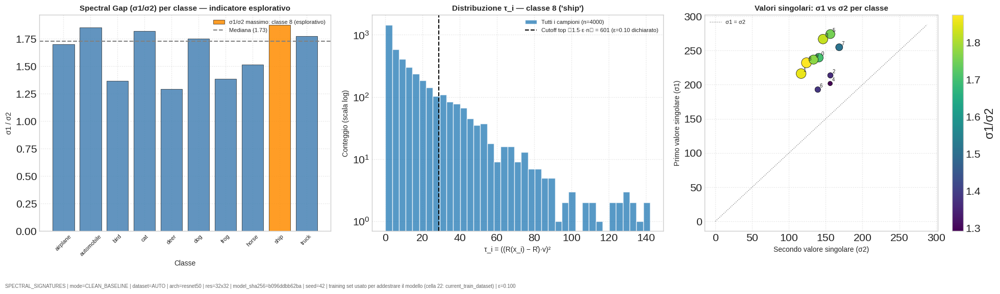

💾 Top-τ gallery saved to: /kaggle/working/spectral_signatures_topk_scratch_class_8.png


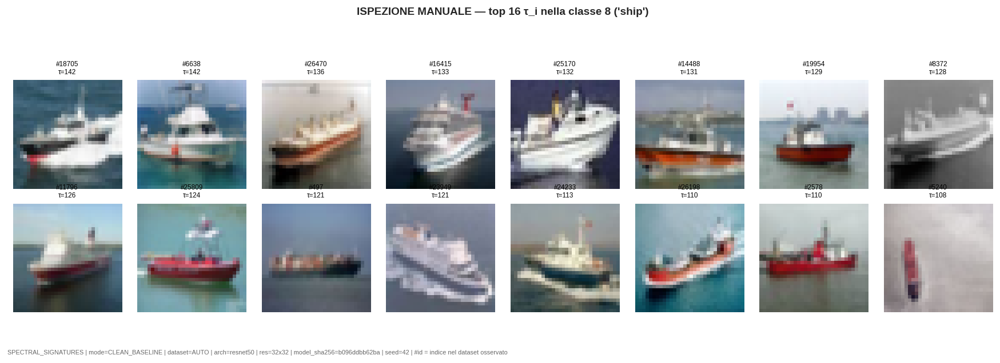

In [46]:
# Scalar keys of Spectral Signatures: recorded with explicit status even when the section does not run.
_SS_METHOD = "SPECTRAL_SIGNATURES"
_SS_DETECTOR_KEYS = {
    "spectral_suspect_class": ("class", "class_id"),
    "spectral_suspect_name": ("class", None),
    "spectral_max_spectral_gap": ("class", "ratio"),
    "spectral_max_anomaly_index": ("class", "robust_z"),
    "spectral_max_outliers_pct": ("class", "percent"),
    "spectral_epsilon": ("model", "fraction"),
    "spectral_n_removal_candidates": ("model", "count"),
    "spectral_n_classes_analyzed": ("model", "count"),
    "spectral_n_classes_insufficient": ("model", "count"),
}
_SS_ORACLE_KEYS = {
    "spectral_detection_recall": ("model", "fraction"),
    "spectral_detection_precision": ("model", "fraction"),
    "spectral_target_outliers_pct": ("class", "percent"),
    "spectral_target_anomaly_index": ("class", "robust_z"),
    "spectral_target_spectral_gap": ("class", "ratio"),
    "spectral_eval_target_poison_fraction": ("class", "fraction"),
    "spectral_eval_target_recall": ("class", "fraction"),
}


def _ss_clear_stale_outputs():
    # Prevents figures or scalars of a previous run from being re-read by the export.
    for _g in ("SPECTRAL_PLOT_IMG_PATH", "SPECTRAL_VIS_IMG_PATH", *_SS_DETECTOR_KEYS, *_SS_ORACLE_KEYS):
        globals().pop(_g, None)


def _ss_record_unavailable(status, note):
    _ss_clear_stale_outputs()
    for _k, (_lvl, _unit) in _SS_DETECTOR_KEYS.items():
        record_metric(_k, float("nan"), status, method=_SS_METHOD, level=_lvl, unit=_unit, note=note)
    for _k, (_lvl, _unit) in _SS_ORACLE_KEYS.items():
        record_metric(_k, float("nan"), status, method=_SS_METHOD, level=_lvl, unit=_unit,
                      requires_ground_truth=True, note=note)


if should_run_section('SPECTRAL_SIGNATURES'):
    clean_memory() if "clean_memory" in globals() else None
    # =====================================================================================================
    # MODULE: SPECTRAL SIGNATURES — B. Tran, J. Li, A. Madry, "Spectral Signatures in Backdoor Attacks",
    # NeurIPS 2018, Alg. 1 (Sec. 2.2-3). For each label y of the observed dataset: R̂ = mean of the
    # representations, M = [R(x_i) − R̂], v = top right singular vector of M, τ_i = ((R(x_i) − R̂)·v)²,
    # candidates for removal = top ⌈1.5·ε·n_y⌉ scores (ε = budget/upper bound DECLARED by the defender).
    # No re-training or actual removal: the candidates are only exported for manual inspection.
    # Spectral gap σ1/σ2, anomaly index across classes and % outliers (|z|>threshold) are exploratory indicators
    # not defined by the paper. The ground truth (oracle) is used only for evaluation recall/precision.
    # =====================================================================================================
    import os
    import time
    import math
    import hashlib
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, ConcatDataset, Subset, Dataset
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    _ss_clear_stale_outputs()

    # ------------------------------------------------------------------------------
    # 0. DECLARED PARAMETERS (overridable from globals; none depends on the attack)
    # ------------------------------------------------------------------------------
    SPECTRAL_PARAMS = {
        # ε = assumed upper bound on the poison fraction per label (Alg. 1, input). Default 0.10 = maximum
        # value used in the paper's experiments (Tab. 2: 5% and 10%); NOT derived from the actual poison rate.
        "epsilon": float(globals().get("SPECTRAL_EPSILON", globals().get("SPECTRAL_EXPECTED_CONTAMINATION", 0.10))),
        "removal_factor": 1.5,                                                   # Alg. 1, line 10
        "min_n": int(globals().get("SPECTRAL_MIN_SAMPLES_PER_CLASS", 50)),     # heuristic
        "outlier_z": float(globals().get("SPECTRAL_OUTLIER_Z", 3.0)),          # heuristic (exploratory outlier % only)
        "layer": globals().get("SPECTRAL_LAYER", None),                        # None = input of the final linear classifier
        "max_samples": globals().get("SPECTRAL_MAX_SAMPLES", None),            # None = all samples (Alg. 1)
        "batch_size": globals().get("SPECTRAL_BATCH_SIZE", None),
        "use_amp": bool(globals().get("SPECTRAL_USE_AMP", False)),
        "entity_top_per_class": int(globals().get("SPECTRAL_ENTITY_TOP_PER_CLASS", 100)),
        "use_cache": bool(globals().get("AC_SS_USE_CACHE", True)),
        "gallery_n": int(globals().get("SPECTRAL_GALLERY_N", 16)),
    }
    _SS_SEED = int(globals().get("SEED", 42))

    # ------------------------------------------------------------------------------
    # 1. OBSERVED DATASET (same rule as the AC cell, no knowledge of the attack)
    # ------------------------------------------------------------------------------
    def _ss_resolve_observed_dataset(ctx):
        """Order: user override -> training set actually used (model trained in the session)
        -> provided training dataset with the model's evaluation transformation."""
        g = globals()
        if g.get("AC_SS_AUDIT_DATASET") is not None:
            return g["AC_SS_AUDIT_DATASET"], "AC_SS_AUDIT_DATASET (user-provided dataset)", None
        trained_here = (not g.get("USE_IMPORTED_MODEL", False)) and str(g.get("AUDIT_MODEL_SOURCE", "")).startswith("training:")
        if trained_here and g.get("current_train_dataset") is not None:
            note = None
            cfg_last, cfg_best = g.get("config"), g.get("best_overall_config")
            if isinstance(cfg_last, dict) and isinstance(cfg_best, dict) and cfg_last != cfg_best:
                note = ("grid with multiple experiments: current_train_dataset is the training set of the last "
                        "experiment, not necessarily of the selected model")
            return g["current_train_dataset"], "training set used to train the model (cell 22: current_train_dataset)", note
        tf = g.get("transform_pipeline") if ctx["is_pipeline"] else g.get("transform_scratch_test")
        tf = tf if tf is not None else ctx["transform"]
        raw = g.get("raw_train_dataset")
        if raw is not None and "TransformWrapper" in g:
            view = g.get("_AC_SS_PROVIDED_VIEW")
            if not (isinstance(view, tuple) and view[0] is raw and view[1] is tf):
                view = (raw, tf, g["TransformWrapper"](raw, tf))
                g["_AC_SS_PROVIDED_VIEW"] = view
            return (view[2], "provided training dataset (raw_train_dataset + model evaluation transformation)",
                    "it is not guaranteed that the provided dataset is the one used to train the inspected model")
        return None, None, "no dataset available: Spectral Signatures analyzes the training data (Tran et al., Alg. 1)"

    def _ss_select_indices(ds, max_samples, seed):
        n = len(ds)
        if not max_samples or int(max_samples) >= n:
            return np.arange(n, dtype=np.int64)
        rng = np.random.default_rng(seed)
        tg = getattr(ds, "targets", None)
        if tg is not None and len(tg) == n:
            tg = np.asarray(tg)
            idx = []
            for c in np.unique(tg):
                pool = np.where(tg == c)[0]
                k = max(1, int(round(int(max_samples) * len(pool) / n)))
                idx.append(rng.choice(pool, size=min(k, len(pool)), replace=False))
            return np.sort(np.concatenate(idx)).astype(np.int64)
        return np.sort(rng.choice(n, size=int(max_samples), replace=False)).astype(np.int64)

    # ------------------------------------------------------------------------------
    # 2. LEARNED REPRESENTATIONS (deterministic hook, removed in finally; cache shared with AC)
    # ------------------------------------------------------------------------------
    def _ss_find_classifier_linear(net):
        last = (None, None)
        for name, m in net.named_modules():
            if isinstance(m, nn.Linear):
                last = (name, m)
        return last

    def _ss_collate(batch):
        # Image and label only: any extra fields (e.g. poison flags) do not reach the detector.
        imgs = [b[0] for b in batch]
        if not all(torch.is_tensor(im) for im in imgs):
            raise TypeError("The observed dataset does not return tensors: the model transformation is missing.")
        return torch.stack(imgs, 0), torch.as_tensor([int(b[1]) for b in batch], dtype=torch.long)

    def _ss_extract_latent(net, ds, sample_idx, ctx, layer_name, batch_size, use_amp, use_cache):
        fp = globals().get("AUDIT_MODEL_FINGERPRINT") or model_fingerprint(net)
        key = (fp, id(ds), len(ds), str(layer_name), hashlib.sha1(np.ascontiguousarray(sample_idx).tobytes()).hexdigest(),
               bool(use_amp), int(ctx["target_res"]))
        cache = globals().get("AC_SS_LATENT_CACHE")
        if use_cache and isinstance(cache, dict) and cache.get("key") == key:
            return cache["payload"], True
        if layer_name:
            module = dict(net.named_modules()).get(str(layer_name))
            if module is None:
                raise ValueError(f"Layer '{layer_name}' not present in the model.")
            layer_desc = f"{layer_name} (output, GAP if 4D)"
        else:
            lin_name, module = _ss_find_classifier_linear(net)
            if module is None:
                raise ValueError("No final nn.Linear: specify SPECTRAL_LAYER.")
            layer_desc = f"input of '{lin_name}' (last hidden layer, {module.in_features} dim)"
        store = {}

        def _hook(m, inp, out):
            v = out if layer_name else inp[0]
            store["a"] = v[0] if isinstance(v, (tuple, list)) else v

        dev = next(net.parameters()).device
        res = int(ctx["target_res"])
        loader = DataLoader(Subset(ds, sample_idx.tolist()), batch_size=int(batch_size), shuffle=False,
                            num_workers=0, pin_memory=(dev.type == "cuda"), collate_fn=_ss_collate)
        feats, labels, preds = [], [], []
        handle = module.register_forward_hook(_hook)
        try:
            n_b = len(loader)
            for b_i, (imgs, lbls) in enumerate(loader):
                if tuple(imgs.shape[-2:]) != (res, res):
                    raise ValueError(f"Resolution {tuple(imgs.shape[-2:])} different from the model's ({res}x{res}).")
                with torch.no_grad(), torch.autocast(device_type=dev.type, enabled=(use_amp and dev.type == "cuda")):
                    logits = net(imgs.to(dev, non_blocking=True))
                logits = logits[0] if isinstance(logits, (tuple, list)) else logits
                a = store.pop("a", None)
                if a is None:
                    raise RuntimeError("Hook not triggered: the chosen layer does not take part in the forward.")
                a = F.adaptive_avg_pool2d(a, 1).flatten(1) if (layer_name and a.dim() == 4) else a.flatten(1)
                feats.append(a.float().cpu().numpy())
                labels.append(lbls.numpy())
                preds.append(logits.argmax(1).cpu().numpy())
                if n_b >= 10 and (b_i + 1) % max(1, n_b // 5) == 0:
                    print(f"   … batch {b_i + 1}/{n_b}")
        finally:
            handle.remove()
        payload = {"feats": np.concatenate(feats, 0), "labels": np.concatenate(labels, 0).astype(np.int64),
                   "preds": np.concatenate(preds, 0).astype(np.int64), "sample_ids": np.asarray(sample_idx, dtype=np.int64),
                   "layer_desc": layer_desc}
        if use_cache:
            globals()["AC_SS_LATENT_CACHE"] = {"key": key, "payload": payload}
        return payload, False

    # ------------------------------------------------------------------------------
    # 3. POISONING GROUND TRUTH (oracle evaluation only, never in the detector)
    # ------------------------------------------------------------------------------
    def _ss_ground_truth_flags(ds):
        lazy_cls = globals().get("LazyPoisonedDataset")

        def _walk(d):
            if lazy_cls is not None and isinstance(d, lazy_cls):
                return np.ones(len(d), dtype=bool)
            if isinstance(d, ConcatDataset):
                return np.concatenate([_walk(p) for p in d.datasets]) if d.datasets else np.zeros(0, dtype=bool)
            sub, idx = getattr(d, "dataset", None), getattr(d, "indices", None)
            if isinstance(sub, Dataset) and idx is not None:
                return _walk(sub)[np.asarray(idx, dtype=np.int64)]
            if isinstance(sub, Dataset) and len(sub) == len(d):
                return _walk(sub)
            return np.zeros(len(d), dtype=bool)

        flags = _walk(ds)
        return flags if len(flags) == len(ds) else None

    # ------------------------------------------------------------------------------
    # 4. SPECTRAL ANALYSIS PER LABEL (Tran et al., Alg. 1, lines 5-10)
    # ------------------------------------------------------------------------------
    def _ss_analyze_class(R, prm):
        n, d = R.shape
        out = {"n": n, "d": d, "status": "computed", "note": "", "sigma_1": np.nan, "sigma_2": np.nan, "gap": np.nan,
               "proj": None, "tau": None, "z_proj": None, "cand": None, "rank": None, "k": 0, "cutoff": np.nan,
               "outlier_pct": np.nan, "mean_tau": np.nan, "p95_tau": np.nan}
        if n < prm["min_n"]:
            out.update(status="insufficient_data", note=f"n={n} < minimum {prm['min_n']}")
            return out
        R = R.astype(np.float64)
        if not np.all(np.isfinite(R)):
            out.update(status="degenerate", note="non-finite representations")
            return out
        M = R - R.mean(axis=0, keepdims=True)                       # line 7: centered representations
        _, S, Vt = np.linalg.svd(M, full_matrices=False)            # line 8: top right singular vector
        if not (S.size and S[0] > 0.0):
            out.update(status="degenerate", note="null centered matrix (σ1 = 0)")
            return out
        notes = []
        if n < d:
            notes.append(f"n={n} < d={d}: reduced-rank covariance")
        s1 = float(S[0])
        s2 = float(S[1]) if S.size > 1 else np.nan
        tol = s1 * max(n, d) * np.finfo(np.float64).eps                # numerical rank (like numpy.matrix_rank)
        gap = s1 / s2 if s2 > tol else np.nan
        if not np.isfinite(gap):
            notes.append("σ2 numerically null: spectral gap not defined")
        proj = M @ Vt[0]
        tau = proj ** 2                                             # line 9: τ_i = ((R(x_i) − R̂)·v)²
        k = int(min(n - 1, max(1, math.ceil(prm["removal_factor"] * prm["epsilon"] * n - 1e-9))))   # line 10 (tolerance: 1.5*0.1*4000 must not become 601)
        order = np.argsort(-tau, kind="stable")
        cand = np.zeros(n, dtype=bool)
        cand[order[:k]] = True
        rank = np.empty(n, dtype=np.int64)
        rank[order] = np.arange(1, n + 1)
        z, zi = robust_mad_z(proj, min_n=3)
        if zi["status"] != "computed":
            notes.append(f"% outliers not computable ({zi['status']})")
        out.update(sigma_1=s1, sigma_2=s2, gap=float(gap), proj=proj, tau=tau, z_proj=z, cand=cand, rank=rank, k=k,
                   cutoff=float(tau[order[k - 1]]), mean_tau=float(tau.mean()), p95_tau=float(np.percentile(tau, 95)),
                   outlier_pct=(float(100.0 * np.mean(np.abs(z) > prm["outlier_z"])) if zi["status"] == "computed" else np.nan),
                   note="; ".join(notes))
        return out

    # ------------------------------------------------------------------------------
    # 5. EXECUTION
    # ------------------------------------------------------------------------------
    def _ss_main():
        net = get_audit_model()
        ctx = get_model_eval_context(net)
        strategy_str = ctx["strategy"]
        eps = SPECTRAL_PARAMS["epsilon"]
        if not (0.0 < eps < 0.5):
            raise ValueError("SPECTRAL_EPSILON must be in (0, 0.5) (Tran et al., Def. 3.1).")
        with preserve_model_state(net):
            net.eval()
            ds, ds_source, ds_note = _ss_resolve_observed_dataset(ctx)
            if ds is None:
                print(f"⚠️ [SPECTRAL] {ds_note}")
                _ss_record_unavailable("not_applicable", ds_note)
                return None
            bs = SPECTRAL_PARAMS["batch_size"] or (128 if ctx["is_pipeline"] else 256)
            sample_idx = _ss_select_indices(ds, SPECTRAL_PARAMS["max_samples"], _SS_SEED)
            print(f"\n🔍 [SPECTRAL SIGNATURES (Tran et al., NeurIPS 2018, Alg. 1)] Starting spectral analysis...")
            print(f"   • Model: {net.__class__.__name__} | Resolution: {ctx['target_res']}x{ctx['target_res']} | Strategy: {strategy_str}")
            print(f"   • Observed dataset: {ds_source}")
            print(f"   • Samples analyzed: {len(sample_idx)}/{len(ds)}")
            print(f"   • Declared ε (assumed upper bound, not measured): {eps:.3f} → candidates per label = ⌈1.5·ε·n_y⌉")
            if ds_note:
                print(f"   ⚠️ {ds_note}")
            t0 = time.time()
            payload, cached = _ss_extract_latent(net, ds, sample_idx, ctx, SPECTRAL_PARAMS["layer"], bs,
                                                 SPECTRAL_PARAMS["use_amp"], SPECTRAL_PARAMS["use_cache"])
            print(f"   • Representations {'(cache AC) ' if cached else ''}{payload['feats'].shape} from {payload['layer_desc']} "
                  f"in {time.time() - t0:.1f}s")

        feats, labels, preds, sids = payload["feats"], payload["labels"], payload["preds"], payload["sample_ids"]
        lin = _ss_find_classifier_linear(net)[1]
        K = int(globals().get("NUM_CLASSES") or (lin.out_features if lin is not None else labels.max() + 1))
        names = globals().get("CLASS_NAMES")
        names = list(names) if names is not None and len(names) == K else [f"Class_{c}" for c in range(K)]
        n_out = int(np.sum((labels < 0) | (labels >= K)))
        if n_out:
            print(f"   ⚠️ {n_out} samples with label outside [0, {K}) excluded.")

        per_class = {}
        for c in range(K):
            idx = np.where(labels == c)[0]
            if len(idx):
                r = _ss_analyze_class(feats[idx], SPECTRAL_PARAMS)
            else:
                r = _ss_analyze_class(np.zeros((0, feats.shape[1])), SPECTRAL_PARAMS)
                r["note"] = "class absent"
            r["idx"] = idx
            per_class[c] = r
        computed = [c for c in range(K) if per_class[c]["status"] == "computed"]
        gaps = np.array([per_class[c]["gap"] for c in range(K)], dtype=np.float64)
        z_all = np.full(K, np.nan)
        z_info = {"status": "insufficient_data", "median": np.nan, "mad": np.nan}
        gap_ok = [c for c in computed if np.isfinite(gaps[c])]
        if gap_ok:
            z_c, z_info = robust_mad_z(gaps[gap_ok], min_n=3)
            z_all[gap_ok] = z_c
        for c in range(K):
            per_class[c]["z_gap"] = float(z_all[c])

        # --- oracle evaluation (ground truth of the observed dataset, never used above) ---
        oracle = oracle_allowed()
        gt = None
        if oracle:
            gt_ds = _ss_ground_truth_flags(ds)
            gt = gt_ds[sids] if gt_ds is not None else None
        for c in range(K):
            r = per_class[c]
            r.update(n_poison=np.nan, poison_frac=np.nan, recall_k=np.nan, precision_k=np.nan)
            if gt is None or r["n"] == 0:
                continue
            g_c = gt[r["idx"]]
            r["n_poison"] = int(g_c.sum())
            r["poison_frac"] = float(g_c.mean())
            if r["status"] == "computed":
                hit = int((g_c & r["cand"]).sum())
                r["precision_k"] = hit / r["k"]
                r["recall_k"] = (hit / int(g_c.sum())) if g_c.any() else np.nan

        rows = []
        for c in range(K):
            r = per_class[c]
            row = {"Class ID": c, "Class Name": names[c], "N Samples": r["n"], "Status": r["status"],
                   "Top SV (σ1)": r["sigma_1"], "Second SV (σ2)": r["sigma_2"], "Spectral Gap (σ1/σ2)": r["gap"],
                   "Anomaly Index (MAD, gap)": r["z_gap"], f"Outlier % (|z|>{SPECTRAL_PARAMS['outlier_z']:g})": r["outlier_pct"],
                   "Candidates 1.5ε": r["k"], "Cutoff τ": r["cutoff"], "Mean τ": r["mean_tau"], "P95 τ": r["p95_tau"],
                   "Note": r["note"]}
            if oracle:
                row.update({"N Poison (oracle)": r["n_poison"], "Poison Fraction (oracle)": r["poison_frac"],
                            "Recall@1.5ε (oracle)": r["recall_k"], "Precision@1.5ε (oracle)": r["precision_k"]})
            rows.append(row)
        df_spec_local = pd.DataFrame(rows)

        print("\n" + "=" * 110)
        print("📊 STATISTICAL-FORENSIC REPORT: SPECTRAL SIGNATURES")
        print("=" * 110)
        fmt = {k: "{:.4g}".format for k in ("Top SV (σ1)", "Second SV (σ2)", "Cutoff τ", "Mean τ", "P95 τ")}
        fmt.update({"Spectral Gap (σ1/σ2)": "{:.3f}".format, "Anomaly Index (MAD, gap)": "{:+.2f}".format,
                    f"Outlier % (|z|>{SPECTRAL_PARAMS['outlier_z']:g})": "{:.2f}".format})
        for k in ("Poison Fraction (oracle)", "Recall@1.5ε (oracle)", "Precision@1.5ε (oracle)"):
            if k in df_spec_local:
                fmt[k] = "{:.3f}".format
        print(df_spec_local.drop(columns=["Note"]).to_string(index=False, formatters=fmt))
        for _, nr in df_spec_local[df_spec_local["Note"].astype(str) != ""].iterrows():
            print(f"   • Class {nr['Class ID']}: {nr['Note']}")

        # --- scalar metrics (exploratory indicators + declared parameters) ---
        common = dict(method=_SS_METHOD)
        n_ins = int(sum(per_class[c]["status"] == "insufficient_data" for c in range(K)))
        record_metric("spectral_epsilon", eps, level="model", unit="fraction",
                      note="declared parameter (defender's assumed upper bound, Alg. 1), not a measurement", **common)
        record_metric("spectral_n_classes_analyzed", len(computed), level="model", unit="count", **common)
        record_metric("spectral_n_classes_insufficient", n_ins, level="model", unit="count",
                      note=f"minimum n per label = {SPECTRAL_PARAMS['min_n']} (heuristic)", **common)
        record_metric("spectral_n_removal_candidates", int(sum(per_class[c]["k"] for c in computed)), level="model", unit="count",
                      note="Σ_y ⌈1.5·ε·n_y⌉: candidates for inspection, no removal performed", **common)
        if gap_ok:
            sus = max(gap_ok, key=lambda c: gaps[c])
            note_s = "class with maximum σ1/σ2: exploratory indicator (not defined by the paper), candidate for inspection"
            record_metric("spectral_suspect_class", int(sus), level="class", unit="class_id", note=note_s, **common)
            record_metric("spectral_suspect_name", str(names[sus]), level="class", note=note_s, **common)
            record_metric("spectral_max_spectral_gap", float(gaps[sus]), level="class", unit="ratio",
                          note="no threshold: the paper does not define a criterion on σ1/σ2", **common)
            zmax = float(np.nanmax(z_all)) if np.any(np.isfinite(z_all)) else np.nan
            record_metric("spectral_max_anomaly_index", zmax, "computed" if z_info["status"] == "computed" else z_info["status"],
                          level="class", unit="robust_z", note="robust z (MAD) of σ1/σ2 across classes: exploratory", **common)
        else:
            _st = "insufficient_data" if n_ins == K else "degenerate"
            for _k in ("spectral_suspect_class", "spectral_suspect_name", "spectral_max_spectral_gap", "spectral_max_anomaly_index"):
                record_metric(_k, float("nan"), _st, level="class", unit=_SS_DETECTOR_KEYS[_k][1],
                              note="no class with a computable spectrum", **common)
        pct = [per_class[c]["outlier_pct"] for c in computed if np.isfinite(per_class[c]["outlier_pct"])]
        record_metric("spectral_max_outliers_pct", max(pct) if pct else float("nan"),
                      "computed" if pct else ("insufficient_data" if not computed else "degenerate"),
                      level="class", unit="percent", threshold=SPECTRAL_PARAMS["outlier_z"], threshold_origin="heuristic",
                      note="max across classes of the % datapoints with |robust z| of the projection on v > threshold (exploratory)", **common)

        tgt = globals().get("TARGET_LABEL") if oracle else None
        tgt = int(tgt) if tgt is not None and 0 <= int(tgt) < K else None
        ev = dict(requires_ground_truth=True, **common)
        if tgt is not None and per_class[tgt]["status"] == "computed":
            rt = per_class[tgt]
            record_metric("spectral_target_outliers_pct", rt["outlier_pct"], level="class", unit="percent",
                          threshold=SPECTRAL_PARAMS["outlier_z"], threshold_origin="heuristic", **ev)
            record_metric("spectral_target_anomaly_index", rt["z_gap"], level="class", unit="robust_z", **ev)
            record_metric("spectral_target_spectral_gap", rt["gap"], level="class", unit="ratio", **ev)
        else:
            _st = "not_applicable" if tgt is None else per_class[tgt]["status"]
            for _k in ("spectral_target_outliers_pct", "spectral_target_anomaly_index", "spectral_target_spectral_gap"):
                record_metric(_k, float("nan"), _st, level="class", unit=_SS_ORACLE_KEYS[_k][1],
                              note="target class unknown or not analyzable", **ev)
        cand_all = np.zeros(len(sids), dtype=bool)
        for c in computed:
            cand_all[per_class[c]["idx"][per_class[c]["cand"]]] = True
        if gt is not None and gt.any():
            hit = int((gt & cand_all).sum())
            record_metric("spectral_detection_recall", hit / int(gt.sum()), level="model", unit="fraction",
                          note="poison among the top 1.5·ε·n_y candidates of all labels (Alg. 1, declared ε)", **ev)
            record_metric("spectral_detection_precision", (hit / int(cand_all.sum())) if cand_all.any() else float("nan"),
                          "computed" if cand_all.any() else "not_applicable", level="model", unit="fraction", **ev)
        else:
            for _k in ("spectral_detection_recall", "spectral_detection_precision"):
                record_metric(_k, float("nan"), "not_applicable", level="model", unit="fraction",
                              note="no known poisoned sample in the observed dataset", **ev)
        if gt is not None and tgt is not None and per_class[tgt]["n"] > 0:
            rt = per_class[tgt]
            record_metric("spectral_eval_target_poison_fraction", rt["poison_frac"], level="class", unit="fraction", **ev)
            record_metric("spectral_eval_target_recall", rt["recall_k"],
                          "computed" if np.isfinite(rt["recall_k"]) else ("not_applicable" if rt["n_poison"] == 0 else rt["status"]),
                          level="class", unit="fraction", **ev)
        else:
            for _k in ("spectral_eval_target_poison_fraction", "spectral_eval_target_recall"):
                record_metric(_k, float("nan"), "not_applicable", level="class", unit="fraction",
                              note="ground truth or target class not available", **ev)

        print("-" * 110)
        if gap_ok:
            print(f" • Class with maximum σ1/σ2 (exploratory): {sus} ('{names[sus]}') — gap {gaps[sus]:.3f} | "
                  f"robust z {z_all[sus]:+.2f} | outlier {per_class[sus]['outlier_pct']:.2f}%")
        print(f" • Candidates for inspection (top ⌈1.5·ε·n_y⌉ per label, ε = {eps:.3f}): {int(cand_all.sum())} samples")
        print(" • Exploratory indicators: no decision threshold on σ1/σ2 or on the anomaly index (not defined by the paper).")
        if oracle and gt is not None:
            print("🔎 EVALUATION (ORACLE) — not used by the detector")
            print(f"   • Recall/precision of the candidates: {RUN_RESULTS.get('spectral_detection_recall', np.nan):.3f} / "
                  f"{RUN_RESULTS.get('spectral_detection_precision', np.nan):.3f}")
            if tgt is not None:
                rt = per_class[tgt]
                print(f"   • Target {tgt} ('{names[tgt]}'): poison {rt['n_poison']}/{rt['n']} (fraction {rt['poison_frac']:.3f}) | "
                      f"recall@1.5ε {rt['recall_k']:.3f} | gap {rt['gap']:.3f}")
                if np.isfinite(rt["poison_frac"]) and rt["poison_frac"] >= 0.5:
                    print("   ⚠️ Poison ≥ 50% dominance of the label: violates the assumption ε < 1/2 (Def. 3.1).")
                elif np.isfinite(rt["poison_frac"]) and rt["poison_frac"] > eps:
                    print(f"   ⚠️ Actual poison fraction > declared ε ({eps:.3f}): the 1.5·ε budget cannot cover all the poison.")
        print("=" * 110 + "\n")

        # --- granular entities and per-sample table ---
        rank_order = sorted(gap_ok, key=lambda c: -gaps[c])
        record_entities(_SS_METHOD, "class", [
            {"entity_id": f"class_{c}", "class_id": c, "class_name": names[c], "score": per_class[c]["gap"],
             "rank": (rank_order.index(c) + 1) if c in rank_order else None, "flag": None,
             "status": per_class[c]["status"], "n": per_class[c]["n"], "sigma_1": per_class[c]["sigma_1"],
             "sigma_2": per_class[c]["sigma_2"], "anomaly_index": per_class[c]["z_gap"], "outlier_pct": per_class[c]["outlier_pct"],
             "k_candidates": per_class[c]["k"], "requires_ground_truth": False,
             "note": f"score = σ1/σ2 (exploratory); {per_class[c]['note']}".strip("; ")} for c in range(K)])
        if oracle and gt is not None:
            record_entities(_SS_METHOD + "_EVAL", "class", [
                {"entity_id": f"class_{c}", "class_id": c, "class_name": names[c], "score": per_class[c]["recall_k"],
                 "n_poison": per_class[c]["n_poison"], "poison_fraction": per_class[c]["poison_frac"],
                 "precision_k": per_class[c]["precision_k"], "requires_ground_truth": True,
                 "note": "evaluation (oracle): recall of the 1.5ε candidates"} for c in range(K) if per_class[c]["n"] > 0])
        sample_rows, ent_rows = [], []
        for c in computed:
            r = per_class[c]
            for j, gi in enumerate(r["idx"]):
                row = {"sample_id": int(sids[gi]), "label": int(labels[gi]), "pred": int(preds[gi]), "proj_v1": float(r["proj"][j]),
                       "tau": float(r["tau"][j]), "z_proj": float(r["z_proj"][j]), "rank_in_class": int(r["rank"][j]),
                       "removal_candidate": bool(r["cand"][j])}
                if oracle and gt is not None:
                    row["gt_poison_oracle"] = bool(gt[gi])
                sample_rows.append(row)
            top_j = np.argsort(r["rank"], kind="stable")[:min(r["k"], SPECTRAL_PARAMS["entity_top_per_class"])]
            for j in top_j:
                ent_rows.append({"entity_id": f"sample_{int(sids[r['idx'][j]])}", "sample_id": int(sids[r["idx"][j]]),
                                 "class_id": c, "class_name": names[c], "score": float(r["tau"][j]), "rank": int(r["rank"][j]),
                                 "flag": True, "requires_ground_truth": False,
                                 "note": f"top 1.5·ε candidate (ε={eps:.3f} declared); score = τ_i"})
        record_entities(_SS_METHOD, "sample", ent_rows)
        df_samples = pd.DataFrame(sample_rows)
        out_d = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "."))
        os.makedirs(out_d, exist_ok=True)
        if len(df_samples):
            samples_csv = os.path.join(out_d, f"spectral_signatures_samples_{strategy_str}.csv")
            df_samples.to_csv(samples_csv, index=False)
            register_artifact(_SS_METHOD, samples_csv, kind="table", note="τ score, rank and 1.5ε candidates per sample")

        return {"ctx": ctx, "ds": ds, "ds_source": ds_source, "per_class": per_class, "computed": computed, "gap_ok": gap_ok,
                "names": names, "K": K, "df": df_spec_local, "df_samples": df_samples, "sids": sids, "gt": gt, "tgt": tgt,
                "suspect": (sus if gap_ok else None), "strategy": strategy_str, "out_dir": out_d}

    # ------------------------------------------------------------------------------
    # 6. VISUALIZATION (no "poison"/"target" color outside the oracle modes)
    # ------------------------------------------------------------------------------
    def _ss_plot(R):
        per_class, K, names, gap_ok = R["per_class"], R["K"], R["names"], R["gap_ok"]
        oracle = oracle_allowed() and R["gt"] is not None
        sus, tgt = R["suspect"], (R["tgt"] if oracle_allowed() else None)
        eps = SPECTRAL_PARAMS["epsilon"]
        if not gap_ok:
            print("ℹ️ [SPECTRAL] No class with a computable spectrum: plots not generated.")
            return
        plt.close("all")
        fig_ss, axes = plt.subplots(1, 3, figsize=(20, 5.8))
        fig_ss.patch.set_facecolor("#ffffff")

        ax1 = axes[0]
        x_pos = np.arange(K)
        gaps = [per_class[c]["gap"] for c in range(K)]
        colors = ["darkorange" if c == sus else "steelblue" for c in range(K)]
        bars = ax1.bar(x_pos, gaps, color=colors, alpha=0.85, edgecolor="black", linewidth=0.5)
        if tgt is not None and np.isfinite(per_class[tgt]["gap"]):
            bars[tgt].set_hatch("//")
            bars[tgt].set_edgecolor("crimson")
            bars[tgt].set_linewidth(1.8)
            bars[tgt].set_label(f"Target class {tgt} (oracle)" + (" = maximum σ1/σ2" if tgt == sus else ""))
        med_gap = float(np.nanmedian(gaps))
        ax1.axhline(med_gap, color="gray", linestyle="--", label=f"Median ({med_gap:.2f})")
        if sus != tgt:
            bars[sus].set_label(f"maximum σ1/σ2: class {sus} (exploratory)")
        ax1.set_xticks(x_pos)
        ax1.set_xticklabels([str(c) if K > 15 else names[c] for c in range(K)], rotation=45 if K <= 15 else 90,
                            fontsize=8 if K <= 15 else 6.5)
        ax1.set_title("Spectral Gap (σ1/σ2) per class — exploratory indicator", fontsize=11, fontweight="bold")
        ax1.set_xlabel("Class", fontsize=10)
        ax1.set_ylabel("σ1 / σ2", fontsize=10)
        ax1.legend(loc="upper right", fontsize=8)
        ax1.grid(True, linestyle=":", alpha=0.6)

        ax2 = axes[1]
        r = per_class[sus]
        tau = r["tau"]
        bins = np.linspace(0.0, float(np.max(tau)) if np.max(tau) > 0 else 1.0, 40)
        if oracle and R["gt"][r["idx"]].any():
            g_c = R["gt"][r["idx"]]
            ax2.hist(tau[~g_c], bins=bins, alpha=0.6, label="Clean (oracle)", color="#2ca02c")
            ax2.hist(tau[g_c], bins=bins, alpha=0.7, label="Poisoned (oracle)", color="#d62728")
        else:
            ax2.hist(tau, bins=bins, alpha=0.75, label=f"All samples (n={r['n']})", color="#1f77b4")
        ax2.axvline(r["cutoff"], color="black", linestyle="--",
                    label=f"Top ⌈1.5·ε·n⌉ cutoff = {r['k']} (ε={eps:.2f} declared)")
        ax2.set_yscale("log")
        ax2.set_title(f"Distribution of τ_i — class {sus} ('{names[sus]}')", fontsize=11, fontweight="bold")
        ax2.set_xlabel("τ_i = ((R(x_i) − R̂)·v)²", fontsize=10)
        ax2.set_ylabel("Count (log scale)", fontsize=10)
        ax2.legend(loc="upper right", fontsize=8)
        ax2.grid(True, linestyle=":", alpha=0.6)

        ax3 = axes[2]
        s1 = np.array([per_class[c]["sigma_1"] for c in gap_ok])
        s2 = np.array([per_class[c]["sigma_2"] for c in gap_ok])
        g_ok = np.array([per_class[c]["gap"] for c in gap_ok])
        sc = ax3.scatter(s2, s1, c=g_ok, cmap="viridis", s=40 + 160 * (g_ok - g_ok.min()) / (np.ptp(g_ok) or 1.0),
                         edgecolors="black", linewidths=0.5)
        fig_ss.colorbar(sc, ax=ax3, label="σ1/σ2")
        lim = [0.0, float(max(s1.max(), s2.max())) * 1.05]
        ax3.plot(lim, lim, color="gray", linestyle=":", linewidth=1, label="σ1 = σ2")
        if len(gap_ok) <= 20:
            for c, xv, yv in zip(gap_ok, s2, s1):
                ax3.annotate(str(c), (xv, yv), fontsize=7, xytext=(3, 3), textcoords="offset points")
        if tgt is not None and tgt in gap_ok:
            ax3.scatter([per_class[tgt]["sigma_2"]], [per_class[tgt]["sigma_1"]], marker="*", s=260, facecolors="none",
                        edgecolors="crimson", linewidths=1.6, label=f"Target class {tgt} (oracle)")
        ax3.set_title("Singular values: σ1 vs σ2 per class", fontsize=11, fontweight="bold")
        ax3.set_xlabel("Second singular value (σ2)", fontsize=10)
        ax3.set_ylabel("First singular value (σ1)", fontsize=10)
        ax3.legend(loc="upper left", fontsize=8)
        ax3.grid(True, linestyle=":", alpha=0.6)

        plt.tight_layout(rect=[0, 0.04, 1, 1])
        fig_ss.text(0.01, 0.005, provenance_caption("SPECTRAL_SIGNATURES", f"{R['ds_source']} | ε={eps:.3f}"), fontsize=7, alpha=0.7)
        ss_plot_path = os.path.join(R["out_dir"], f"spectral_signatures_{R['strategy']}.png")
        fig_ss.savefig(ss_plot_path, bbox_inches="tight", dpi=130)
        register_artifact(_SS_METHOD, ss_plot_path, kind="figure", note="spectral gap, τ distribution, singular values")
        globals()["SPECTRAL_PLOT_IMG_PATH"] = ss_plot_path
        print(f"💾 Spectral Signatures plot saved to: {ss_plot_path}")
        plt.show()
        plt.close(fig_ss)

        # Gallery for manual inspection: samples with the highest τ in the class with maximum σ1/σ2.
        n_vis = min(SPECTRAL_PARAMS["gallery_n"], r["n"])
        top_j = np.argsort(r["rank"], kind="stable")[:n_vis]
        mean, std = np.asarray(R["ctx"]["mean"]), np.asarray(R["ctx"]["std"])
        n_cols = min(8, n_vis)
        n_rows = int(math.ceil(n_vis / n_cols))
        fig_g, axes_g = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.7, n_rows * 2.0 + 0.8), dpi=130)
        axes_g = np.atleast_1d(axes_g).ravel()
        for ax in axes_g:
            ax.axis("off")
        for pos, j in enumerate(top_j):
            sid = int(R["sids"][r["idx"][j]])
            img = R["ds"][sid][0].detach().cpu().float().numpy().transpose(1, 2, 0)
            if img.min() < 0.0 or img.max() > 1.0:
                img = img * std[: img.shape[2]] + mean[: img.shape[2]]
            img = np.clip(img, 0.0, 1.0)
            axes_g[pos].imshow(img.squeeze(), cmap="gray" if img.shape[2] == 1 else None)
            title, color = f"#{sid}\nτ={r['tau'][j]:.3g}", "black"
            if oracle:
                is_p = bool(R["gt"][r["idx"][j]])
                title, color = f"#{sid} [{'P' if is_p else 'C'}]\nτ={r['tau'][j]:.3g}", ("crimson" if is_p else "darkgreen")
            axes_g[pos].set_title(title, fontsize=6.5, color=color)
        fig_g.suptitle(f"MANUAL INSPECTION — top {n_vis} τ_i in class {sus} ('{names[sus]}')"
                       + (" | [P]/[C] = ground truth (oracle)" if oracle else ""), fontsize=10.5, fontweight="bold")
        plt.tight_layout(rect=[0, 0.05, 1, 0.92])
        fig_g.text(0.01, 0.005, provenance_caption("SPECTRAL_SIGNATURES", "#id = index in the observed dataset"), fontsize=6, alpha=0.7)
        ss_vis_path = os.path.join(R["out_dir"], f"spectral_signatures_topk_{R['strategy']}_class_{sus}.png")
        fig_g.savefig(ss_vis_path, bbox_inches="tight", dpi=130)
        register_artifact(_SS_METHOD, ss_vis_path, kind="figure", note="samples with the highest τ score (manual inspection)")
        globals()["SPECTRAL_VIS_IMG_PATH"] = ss_vis_path
        print(f"💾 Top-τ gallery saved to: {ss_vis_path}")
        plt.show()
        plt.close(fig_g)

    # ------------------------------------------------------------------------------
    # 7. EXECUTION, GLOBALS EXPORT AND CLEANUP
    # ------------------------------------------------------------------------------
    import traceback
    _ss_res = None
    try:
        _ss_res = _ss_main()
    except Exception as _ss_err:
        traceback.print_exc()
        print(f"❌ [SPECTRAL] Section failed: {_ss_err}")
        _ss_record_unavailable("failed", f"{type(_ss_err).__name__}: {_ss_err}")
    if _ss_res is not None:
        try:
            _ss_plot(_ss_res)
        except Exception as _ss_err:
            traceback.print_exc()
            print(f"⚠️ [SPECTRAL] Plots not generated: {_ss_err}")
        # Globals for the downstream cells (Cross-Latent, CSV export, manual inspection).
        df_spec = _ss_res["df"]
        spectral_df = df_spec
        df_spec_samples = _ss_res["df_samples"]
        spectral_class_results = _ss_res["per_class"]
        SPECTRAL_AUDIT_DATASET = _ss_res["ds"]
        SPECTRAL_AUDIT_DATASET_SOURCE = _ss_res["ds_source"]
        for _k in (*_SS_DETECTOR_KEYS, *_SS_ORACLE_KEYS):
            globals()[_k] = RUN_RESULTS.get(_k)
    if globals().get("AUDIT_MODEL") is not None:
        check_model_integrity(_SS_METHOD)
    clean_memory() if "clean_memory" in globals() else None
else:
    _SS_MODEL_ONLY = str(globals().get("EXECUTION_MODE", "")).upper() == "MODEL_ONLY"
    _ss_record_unavailable("not_applicable" if _SS_MODEL_ONLY else "not_run",
                           "MODEL_ONLY: no observed data, Spectral Signatures requires the dataset representations"
                           if _SS_MODEL_ONLY else "section not run in the active mode")


### 📊 Cross Benchmark Module and Forensic Triangulation in the Latent Space (FCT vs Feature Sensitivity vs Activation Clustering vs Spectral Signatures).



🔗 [CROSS-LATENT] EXPERIMENTAL CONCORDANCE DASHBOARD OF FCT / ACTIVATION CLUSTERING / SPECTRAL SIGNATURES
   It is not a detector: it compares per-sample rankings on the same samples; no decision.
📦 Observed training set: current_train_dataset (training set passed to fit, cell 22) — 40,000 samples | strategy=scratch | groups by 'label'
⏳ [CROSS-LATENT] Δtrans on 40,000 samples (τ = rotate ±180° + translate 0.2, seed=42)...
⏳ AC (ICA 10 comp. + 2-means) and Spectral (SVD) for 10 groups...

📊 [CROSS-LATENT REPORT] CONCORDANCE BETWEEN PER-SAMPLE SCORES (observed training set)
🔹 Samples analyzed: 40,000 | with the three scores: 40,000 | label/prediction agreement: 100.00%
🔹 Spearman AC vs Spectral : ρ = +0.0167 | p = 0.000812 | n = 40,000 [computed]
🔹 Spearman FCT vs Spectral: ρ = +0.0489 | p = 1.19e-22 | n = 40,000 [computed]
🔹 Spearman FCT vs AC      : ρ = +0.0347 | p = 3.69e-12 | n = 40,000 [computed]
🔹 Triple concordance (top-0.05 in all three, heuristic): 0.38 % (expected under indepe

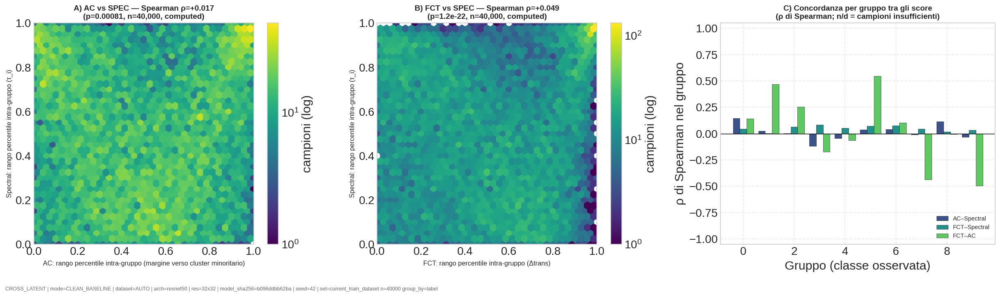

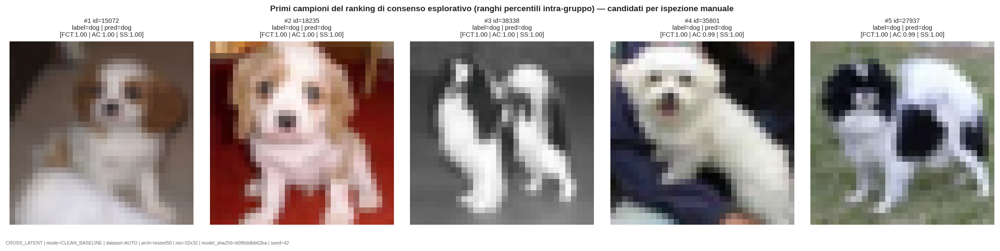

💾 [CROSS-LATENT] Plots and per-sample table saved to: /kaggle/working


In [47]:
import os
import math
import warnings
import traceback
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata
from sklearn.decomposition import PCA, FastICA
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning

# =====================================================================================================
# CROSS-LATENT — EXPERIMENTAL DASHBOARD OF CONCORDANCE BETWEEN PER-SAMPLE SCORES (NOT A DETECTOR)
# It is not a published method: a local ensemble that compares, on the SAME samples of the observed training set
# and per group (observed label), three per-sample scores:
#  1. FCT Δtrans — W. Chen, B. Wu, H. Wang, NeurIPS 2022, Eq. (1) (fct_* functions defined in cell 71);
#  2. Activation Clustering — B. Chen et al., arXiv:1811.03728 (2018), Alg. 1 and Sec. 6: 10-component ICA + 2-means
#     per class; continuous score = distance margin towards the minority cluster (local adaptation, not in the paper);
#  3. Spectral Signatures — B. Tran, J. Li, A. Madry, NeurIPS 2018, Alg. 1 (Sec. 3): τ_i = ((R_i − R̂)·v₁)² per class.
# Output: per-sample ranking, Spearman's ρ (with n and p) between the scores, exploratory consensus ranking.
# No decision threshold and no verdict. AUC and TP/FP require the poison flags: oracle evaluation only.
# AC and Spectral are recomputed here on the same samples (AC hyperparameters of cell 73 if available);
# if cells 73/75 exported df_ac_samples/df_spec_samples on the same dataset, a consistency check is printed.
# =====================================================================================================
# AC hyperparameters aligned with cell 73 (AC_PARAMS) when available, so that the local scores coincide.
_CL_ACP = globals().get("AC_PARAMS") if isinstance(globals().get("AC_PARAMS"), dict) else {}
CROSS_LATENT_MAX_SAMPLES = globals().get("CROSS_LATENT_MAX_SAMPLES", None)            # None = whole observed training set
CROSS_LATENT_BATCH_SIZE = globals().get("CROSS_LATENT_BATCH_SIZE", None)              # None -> 128 pipeline / 256 scratch
CROSS_LATENT_MIN_CLASS_N = int(globals().get("CROSS_LATENT_MIN_CLASS_N", _CL_ACP.get("min_n", 50)))  # heuristic: ≥ 5 samples per ICA dimension
CROSS_LATENT_AC_COMPONENTS = int(globals().get("CROSS_LATENT_AC_COMPONENTS", _CL_ACP.get("n_components", 10)))  # Chen et al. 2018, Sec. 6
CROSS_LATENT_ICA = {"max_iter": int(_CL_ACP.get("ica_max_iter", 1000)), "tol": float(_CL_ACP.get("ica_tol", 0.005)),
                    "n_init": int(_CL_ACP.get("kmeans_n_init", 15))}                     # default = ART / cell 73
CROSS_LATENT_GROUP_BY = str(globals().get("CROSS_LATENT_GROUP_BY", "label")).lower()   # 'label' (Tran, Alg. 1) | 'pred' (AC, Alg. 1)
CROSS_LATENT_TOP_Q = float(globals().get("CROSS_LATENT_TOP_Q", 0.05))                  # heuristic: top share for the triple concordance
CROSS_LATENT_ENTITY_TOPK = int(globals().get("CROSS_LATENT_ENTITY_TOPK", 500))
CROSS_LATENT_RUNTIME_MAX_SAMPLES = globals().get("CROSS_LATENT_RUNTIME_MAX_SAMPLES", "auto")  # 'auto' -> 1200 pipeline / all scratch
CROSS_LATENT_SEED = int(globals().get("CROSS_LATENT_SEED", globals().get("SEED", 42)))
CROSS_LATENT_SCATTER_MAX = int(globals().get("CROSS_LATENT_SCATTER_MAX", 20000))       # visualization only

_CL_KEYS = ["cross_latent_n_samples", "cross_latent_n_valid",
            "cross_latent_spearman_ac_spec", "cross_latent_spearman_fct_spec", "cross_latent_spearman_fct_ac",
            "cross_latent_spearman_ac_spec_pvalue", "cross_latent_spearman_fct_spec_pvalue", "cross_latent_spearman_fct_ac_pvalue",
            "cross_latent_triple_topq_pct"]
_CL_ORACLE_KEYS = ["cross_latent_auc_ac", "cross_latent_auc_spectral", "cross_latent_auc_fct", "cross_latent_auc_composite",
                   "cross_latent_auc_fct_runtime", "cross_latent_tp_rate", "cross_latent_fp_rate"]
_CL_PAIRS = (("ac_spec", "ac", "spec"), ("fct_spec", "fct", "spec"), ("fct_ac", "fct", "ac"))


def _cl_rec(key, value, status="computed", gt=False, **kw):
    """record_metric + homonymous legacy global (read by cell 93)."""
    kw.setdefault("method", "CROSS_LATENT")
    kw.setdefault("level", "model")
    v = record_metric(key, value, status, requires_ground_truth=gt, **kw)
    globals()[key] = v
    return v


def _cl_record_removed():
    _cl_rec("cross_latent_suspect_samples_pct", float("nan"), "not_applicable",
            note="removed: composite z threshold ≥ 1.5 not validated; see cross_latent_triple_topq_pct")


def _cl_record_all(status, note):
    for _k in _CL_KEYS:
        _cl_rec(_k, float("nan"), status, note=note)
    for _k in _CL_ORACLE_KEYS:
        _cl_rec(_k, float("nan"), status, gt=True, note=note)
    _cl_record_removed()


def cl_class_scores(X, min_n, n_comp, seed, max_iter=1000, tol=0.005, n_init=15):
    """AC and Spectral scores for the samples of a group. Returns (ac, spec, minority, info); NaN if not computable."""
    n = int(X.shape[0])
    nan = np.full(n, np.nan)
    info = {"n": n, "status": "computed", "ac_status": "computed", "spec_status": "computed", "decomp": "n/a",
            "ac_minority_frac": float("nan"), "sigma_ratio": float("nan"), "ica_conv_warnings": 0}
    if n < min_n:
        info.update(status="insufficient_data", ac_status="insufficient_data", spec_status="insufficient_data")
        return nan, nan.copy(), np.zeros(n, dtype=bool), info
    Xd = np.asarray(X, dtype=np.float64)
    # Spectral Signatures (Tran et al. 2018, Alg. 1 lines 6-9)
    M = Xd - Xd.mean(axis=0, keepdims=True)
    spec = nan.copy()
    try:
        _, S, Vt = np.linalg.svd(M, full_matrices=False)
        if S[0] > 0:
            spec = (M @ Vt[0]) ** 2
            info["sigma_ratio"] = float(S[0] / S[1]) if len(S) > 1 and S[1] > 0 else float("nan")
        else:
            info["spec_status"] = "degenerate"
    except np.linalg.LinAlgError:
        info["spec_status"] = "failed"
    # Activation Clustering (Chen et al. 2018, Sec. 6): ICA -> 2-means; suspect cluster = the smallest (relative size)
    ac, minority = nan.copy(), np.zeros(n, dtype=bool)
    k = int(min(n_comp, n - 1, Xd.shape[1]))
    with warnings.catch_warnings(record=True) as _wl:
        warnings.simplefilter("always")
        try:
            Z = FastICA(n_components=k, whiten="unit-variance", random_state=seed, max_iter=max_iter, tol=tol).fit_transform(Xd)
            info["decomp"] = "ICA"
        except Exception:
            Z = PCA(n_components=k, random_state=seed).fit_transform(Xd)
            info["decomp"] = "PCA (fallback)"
        info["ica_conv_warnings"] = int(sum(1 for _w in _wl if issubclass(_w.category, ConvergenceWarning)))
        if np.all(np.isfinite(Z)):
            km = KMeans(n_clusters=2, init="k-means++", n_init=n_init, random_state=seed).fit(Z)
            sizes = np.bincount(km.labels_, minlength=2)
        else:
            km, sizes = None, np.zeros(2, dtype=int)
    if km is None or sizes.min() == 0 or sizes[0] == sizes[1]:
        info["ac_status"] = "degenerate"
    else:
        mi = int(np.argmin(sizes))
        ac = np.linalg.norm(Z - km.cluster_centers_[1 - mi], axis=1) - np.linalg.norm(Z - km.cluster_centers_[mi], axis=1)
        minority = km.labels_ == mi
        info["ac_minority_frac"] = float(sizes[mi] / n)
    if info["ac_status"] != "computed" or info["spec_status"] != "computed":
        info["status"] = "degenerate"
    return ac, spec, minority, info


def cl_pct_rank(values, groups):
    """Intra-group percentile rank in (0, 1] (average ranks on ties); NaN preserved."""
    out = np.full(len(values), np.nan)
    for g in np.unique(groups):
        m = (groups == g) & np.isfinite(values)
        if m.any():
            out[m] = rankdata(values[m], method="average") / m.sum()
    return out


def cl_spearman(a, b, min_n=3):
    """(ρ, p, n, status) only on the samples with both scores finite."""
    m = np.isfinite(a) & np.isfinite(b)
    n = int(m.sum())
    if n < min_n:
        return float("nan"), float("nan"), n, "insufficient_data"
    if np.ptp(a[m]) == 0 or np.ptp(b[m]) == 0:
        return float("nan"), float("nan"), n, "degenerate"
    r, p = spearmanr(a[m], b[m])
    return float(r), float(p), n, "computed"


def cl_auc(y, s):
    m = np.isfinite(s)
    y, s = np.asarray(y, dtype=bool)[m], s[m]
    if y.sum() == 0 or (~y).sum() == 0:
        return float("nan"), "insufficient_data"
    return float(roc_auc_score(y.astype(int), s)), "computed"


if should_run_section('CROSS_LATENT'):
    clean_memory() if "clean_memory" in globals() else None
    print("\n" + "=" * 95)
    print("🔗 [CROSS-LATENT] EXPERIMENTAL CONCORDANCE DASHBOARD FCT / ACTIVATION CLUSTERING / SPECTRAL SIGNATURES")
    print("   It is not a detector: it compares per-sample rankings on the same samples; no decision.")
    print("=" * 95)

    cl_res, cl_ctx, cl_ds, cl_source, cl_runtime = None, None, None, "n/a", None
    _cl_missing = [n for n in ("fct_compute_scores", "fct_resolve_observed_train_set", "fct_oracle_poison_flags",
                               "fct_class_names", "fct_display_image") if not callable(globals().get(n))]
    cl_net = get_audit_model(required=False)
    if _cl_missing:
        print(f"❌ [CROSS-LATENT] FCT functions not defined ({_cl_missing}): run cell 71 first (the definitions do not depend on the gating).")
        _cl_record_all("failed", "fct_* functions of cell 71 not defined")
    elif cl_net is None:
        print("⚠️ [CROSS-LATENT] No model available.")
        _cl_record_all("not_applicable", "no model available")
    else:
        cl_ctx = get_model_eval_context(cl_net)
        cl_ds, cl_source = fct_resolve_observed_train_set(cl_ctx)
        if cl_ds is None or len(cl_ds) == 0:
            print("⚠️ [CROSS-LATENT] No observed training set: AC, Spectral and FCT require the training data.")
            _cl_record_all("not_applicable", "no observed training set")
        else:
            cl_bs = int(CROSS_LATENT_BATCH_SIZE or (128 if cl_ctx["is_pipeline"] else 256))
            cl_tau = dict(rotation_deg=float(globals().get("FCT_ROTATION_DEG", 180.0)),
                          translate_frac=float(globals().get("FCT_TRANSLATE_FRAC", 0.2)))
            cl_fct_seed = int(globals().get("FCT_SEED", CROSS_LATENT_SEED))
            print(f"📦 Observed training set: {cl_source} — {len(cl_ds):,} samples | strategy={cl_ctx['strategy']} | groups by '{CROSS_LATENT_GROUP_BY}'")
            try:
                with preserve_model_state(cl_net):
                    cl_net.eval()
                    cl_res = fct_compute_scores(cl_net, cl_ds, cl_ctx, batch_size=cl_bs, max_samples=CROSS_LATENT_MAX_SAMPLES,
                                                seed=cl_fct_seed, return_features=True, desc="CROSS-LATENT", **cl_tau)
                    # Run-time oracle evaluation: Δtrans on clean test vs test with trigger (requirement: known trigger)
                    if oracle_allowed():
                        _cl_pds = globals().get("poison_test_dataset")
                        _cl_cds = globals().get("clean_test_dataset")
                        if _cl_pds is not None and _cl_cds is not None and _cl_pds is not _cl_cds:
                            _cl_cap = (1200 if cl_ctx["is_pipeline"] else None) if CROSS_LATENT_RUNTIME_MAX_SAMPLES == "auto" else CROSS_LATENT_RUNTIME_MAX_SAMPLES
                            try:
                                _rc = fct_compute_scores(cl_net, _cl_cds, cl_ctx, batch_size=cl_bs, max_samples=_cl_cap,
                                                         seed=cl_fct_seed + 1, desc="FCT clean test (oracle)", **cl_tau)
                                _rp = fct_compute_scores(cl_net, _cl_pds, cl_ctx, batch_size=cl_bs, max_samples=_cl_cap,
                                                         seed=cl_fct_seed + 2, desc="FCT test with trigger (oracle)", **cl_tau)
                                cl_runtime = (_rc["scores"], _rp["scores"])
                            except Exception as _cl_err:
                                print(f"⚠️ [CROSS-LATENT] Run-time evaluation failed: {_cl_err}")
            except Exception as _cl_err:
                print(f"❌ [CROSS-LATENT] Computation failed: {_cl_err}\n{traceback.format_exc(limit=3)}")
                _cl_record_all("failed", f"error: {_cl_err}")
                cl_res = None
            finally:
                check_model_integrity("CROSS_LATENT")

    if cl_res is not None:
        # --------------------------------------------------------------------------
        # 1. Per-sample scores per group (same samples for the three methods)
        # --------------------------------------------------------------------------
        cl_fct = cl_res["scores"]
        cl_labels, cl_preds = cl_res["labels"], cl_res["preds"]
        cl_groups = cl_preds if CROSS_LATENT_GROUP_BY == "pred" else cl_labels
        cl_n = len(cl_fct)
        cl_K = int(max(cl_res["n_outputs"] or 0, (int(max(cl_labels.max(), cl_preds.max())) + 1) if cl_n else 0))
        cl_names = fct_class_names(cl_K)
        cl_ac, cl_spec = np.full(cl_n, np.nan), np.full(cl_n, np.nan)
        cl_minority = np.zeros(cl_n, dtype=bool)
        cl_class_info = {}
        print(f"⏳ AC (ICA {CROSS_LATENT_AC_COMPONENTS} comp. + 2-means) and Spectral (SVD) for {cl_K} groups...")
        for _c in range(cl_K):
            _idx = np.where(cl_groups == _c)[0]
            _a, _s, _mn, _inf = cl_class_scores(cl_res["features"][_idx], CROSS_LATENT_MIN_CLASS_N, CROSS_LATENT_AC_COMPONENTS,
                                                CROSS_LATENT_SEED, **CROSS_LATENT_ICA)
            cl_ac[_idx], cl_spec[_idx], cl_minority[_idx] = _a, _s, _mn
            _raw = {"fct": cl_fct[_idx], "ac": _a, "spec": _s}
            for _pk, _x, _y in _CL_PAIRS:
                _r, _p, _nn, _st = cl_spearman(_raw[_x], _raw[_y])
                _inf[f"rho_{_pk}"], _inf[f"p_{_pk}"], _inf[f"n_{_pk}"], _inf[f"st_{_pk}"] = _r, _p, _nn, _st
            cl_class_info[_c] = _inf

        cl_pr = {"fct": cl_pct_rank(cl_fct, cl_groups), "ac": cl_pct_rank(cl_ac, cl_groups), "spec": cl_pct_rank(cl_spec, cl_groups)}
        cl_valid = np.isfinite(cl_pr["fct"]) & np.isfinite(cl_pr["ac"]) & np.isfinite(cl_pr["spec"])
        cl_n_valid = int(cl_valid.sum())
        # Exploratory consensus: mean of the intra-group percentile ranks (scale-free, no threshold)
        cl_consensus = np.where(cl_valid, (cl_pr["fct"] + cl_pr["ac"] + cl_pr["spec"]) / 3.0, np.nan)
        cl_triple = cl_valid & (cl_pr["fct"] >= 1 - CROSS_LATENT_TOP_Q) & (cl_pr["ac"] >= 1 - CROSS_LATENT_TOP_Q) & (cl_pr["spec"] >= 1 - CROSS_LATENT_TOP_Q)

        _cl_rec("cross_latent_n_samples", cl_n, unit="samples", note=cl_source)
        _cl_rec("cross_latent_n_valid", cl_n_valid, unit="samples", note=f"samples with the three finite scores (groups with n ≥ {CROSS_LATENT_MIN_CLASS_N})")
        cl_rho = {}
        _cl_rho_note = "Spearman's ρ on the aggregated intra-group percentile ranks; nominal p (scores estimated on the same data)"
        for _pk, _x, _y in _CL_PAIRS:
            _r, _p, _nn, _st = cl_spearman(np.where(cl_valid, cl_pr[_x], np.nan), np.where(cl_valid, cl_pr[_y], np.nan))
            cl_rho[_pk] = (_r, _p, _nn, _st)
            _cl_rec(f"cross_latent_spearman_{_pk}", _r, _st, unit="rho", note=f"{_cl_rho_note}; n={_nn}")
            _cl_rec(f"cross_latent_spearman_{_pk}_pvalue", _p, _st, unit="p-value", note=f"n={_nn}")
        if cl_n_valid:
            _cl_rec("cross_latent_triple_topq_pct", 100.0 * float(cl_triple.sum()) / cl_n_valid, unit="%", threshold=CROSS_LATENT_TOP_Q,
                    threshold_origin="heuristic", note=f"share of samples in the top-{CROSS_LATENT_TOP_Q:g} of all three scores; expected under independence ≈ {100 * CROSS_LATENT_TOP_Q ** 3:.3g}%")
        else:
            _cl_rec("cross_latent_triple_topq_pct", float("nan"), "insufficient_data", note="no sample with the three scores")
        _cl_record_removed()

        # --------------------------------------------------------------------------
        # 2. ORACLE evaluation (attacker modes only)
        # --------------------------------------------------------------------------
        cl_gt = fct_oracle_poison_flags(cl_ds, cl_res["sample_ids"])
        cl_auc_vals = {}
        if cl_gt is None:
            for _k in _CL_ORACLE_KEYS:
                _cl_rec(_k, float("nan"), gt=True)
        else:
            _eval_groups = np.unique(cl_groups[cl_gt])
            _em = np.isin(cl_groups, _eval_groups) & cl_valid
            _note_eval = f"groups containing poisoned samples: {_eval_groups.tolist()}; samples evaluated={int(_em.sum())} (poisoned {int((cl_gt & _em).sum())}/{int(cl_gt.sum())})"
            if len(_eval_groups) == 0:
                for _k in ("cross_latent_auc_ac", "cross_latent_auc_spectral", "cross_latent_auc_fct", "cross_latent_auc_composite", "cross_latent_tp_rate", "cross_latent_fp_rate"):
                    _cl_rec(_k, float("nan"), "not_applicable", gt=True, note="no poisoned sample in the observed training set")
            else:
                for _k, _sc in (("cross_latent_auc_ac", cl_pr["ac"]), ("cross_latent_auc_spectral", cl_pr["spec"]),
                                ("cross_latent_auc_fct", cl_pr["fct"]), ("cross_latent_auc_composite", cl_consensus)):
                    _v, _st = cl_auc(cl_gt[_em], _sc[_em])
                    cl_auc_vals[_k] = _v
                    _cl_rec(_k, _v, _st, gt=True, unit="AUC", note=_note_eval + ("; composite = mean of the percentile ranks" if "composite" in _k else ""))
                _np_e, _nc_e = int((cl_gt & _em).sum()), int((~cl_gt & _em).sum())
                _tn = f"set = concordant top-{CROSS_LATENT_TOP_Q:g} of the three scores (heuristic); " + _note_eval
                _cl_rec("cross_latent_tp_rate", 100.0 * (cl_triple & cl_gt & _em).sum() / _np_e if _np_e else float("nan"),
                        "computed" if _np_e else "insufficient_data", gt=True, unit="%", threshold=CROSS_LATENT_TOP_Q, threshold_origin="heuristic", note=_tn)
                _cl_rec("cross_latent_fp_rate", 100.0 * (cl_triple & ~cl_gt & _em).sum() / _nc_e if _nc_e else float("nan"),
                        "computed" if _nc_e else "insufficient_data", gt=True, unit="%", threshold=CROSS_LATENT_TOP_Q, threshold_origin="heuristic", note=_tn)
            if cl_runtime is not None:
                _rt_s = np.concatenate([cl_runtime[0], cl_runtime[1]])
                _rt_y = np.concatenate([np.zeros(len(cl_runtime[0]), bool), np.ones(len(cl_runtime[1]), bool)])
                _v, _st = cl_auc(_rt_y, _rt_s)
                cl_auc_vals["cross_latent_auc_fct_runtime"] = _v
                _cl_rec("cross_latent_auc_fct_runtime", _v, _st, gt=True, unit="AUC",
                        note=f"Δtrans clean test ({len(cl_runtime[0])}) vs test with trigger ({len(cl_runtime[1])}); requires the trigger")
            else:
                _cl_rec("cross_latent_auc_fct_runtime", float("nan"), "not_applicable", gt=True, note="poison_test_dataset not available")

        # --------------------------------------------------------------------------
        # 3. On-screen report
        # --------------------------------------------------------------------------
        CROSS_LATENT_CLASS_TABLE = pd.DataFrame([{
            "class_id": _c, "class_name": cl_names[_c], "n": _i["n"], "status": _i["status"], "decomp": _i["decomp"],
            "ac_minority_pct": 100.0 * _i["ac_minority_frac"], "sigma1_sigma2": _i["sigma_ratio"],
            "rho_ac_spec": _i["rho_ac_spec"], "p_ac_spec": _i["p_ac_spec"], "rho_fct_spec": _i["rho_fct_spec"],
            "p_fct_spec": _i["p_fct_spec"], "rho_fct_ac": _i["rho_fct_ac"], "p_fct_ac": _i["p_fct_ac"],
            "n_triple_topq": int((cl_triple & (cl_groups == _c)).sum()), "ica_conv_warnings": _i["ica_conv_warnings"],
        } for _c, _i in cl_class_info.items()])
        print("\n" + "=" * 95)
        print("📊 [CROSS-LATENT REPORT] CONCORDANCE BETWEEN PER-SAMPLE SCORES (observed training set)")
        print("=" * 95)
        print(f"🔹 Samples analyzed: {cl_n:,} | with the three scores: {cl_n_valid:,} | label/prediction agreement: {100.0 * np.mean(cl_labels == cl_preds):.2f}%")
        for _pk, _lbl in (("ac_spec", "AC vs Spectral "), ("fct_spec", "FCT vs Spectral"), ("fct_ac", "FCT vs AC      ")):
            _r, _p, _nn, _st = cl_rho[_pk]
            print(f"🔹 Spearman {_lbl}: ρ = {_r:+.4f} | p = {_p:.3g} | n = {_nn:,} [{_st}]")
        print(f"🔹 Triple concordance (top-{CROSS_LATENT_TOP_Q:g} in all three, heuristic): {RUN_RESULTS.get('cross_latent_triple_topq_pct')} % "
              f"(expected under independence ≈ {100 * CROSS_LATENT_TOP_Q ** 3:.3g} %)")
        print("-" * 95)
        print(CROSS_LATENT_CLASS_TABLE[["class_id", "class_name", "n", "status", "ac_minority_pct", "sigma1_sigma2",
                                        "rho_ac_spec", "rho_fct_spec", "rho_fct_ac", "n_triple_topq"]].to_string(
            index=False, formatters={"ac_minority_pct": "{:.1f}".format, "sigma1_sigma2": "{:.2f}".format,
                                     "rho_ac_spec": "{:+.3f}".format, "rho_fct_spec": "{:+.3f}".format, "rho_fct_ac": "{:+.3f}".format}))
        print("ℹ️ Concordance ≠ proof of backdoor: the three scores use the same features and may agree on")
        print("   natural subpopulations (multimodal classes, outliers). Use the ranking for manual inspection.")
        if cl_gt is not None:
            print("-" * 95)
            print("🧪 [EVALUATION (ORACLE)] Poison flags used only a posteriori")
            if isinstance(globals().get("POISONING_CONFIG"), dict):
                print(f"   Attack context: target={POISONING_CONFIG.get('target_label')} | rate={POISONING_CONFIG.get('poison_rate')} | type={POISONING_CONFIG.get('attack_type')}")
            for _k in _CL_ORACLE_KEYS:
                print(f"   {_k:<30}: {RUN_RESULTS.get(_k)}  [{METRIC_META.get(_k, {}).get('status')}]")
        print("=" * 95 + "\n")

        # Consistency with cell 71 (same samples and parameters -> same Δtrans)
        _fi = globals().get("FCT_RUN_INFO")
        if isinstance(_fi, dict) and isinstance(globals().get("FCT_SAMPLE_TABLE"), pd.DataFrame) and _fi.get("source") == cl_source \
                and _fi.get("model_sha256") == globals().get("AUDIT_MODEL_FINGERPRINT") and _fi.get("seed") == cl_fct_seed:
            _ft = FCT_SAMPLE_TABLE.set_index("sample_id")["fct_score"]
            _common = np.intersect1d(_ft.index.values, cl_res["sample_ids"])
            if len(_common) and _fi.get("max_samples") == CROSS_LATENT_MAX_SAMPLES:
                _pos = pd.Series(np.arange(cl_n), index=cl_res["sample_ids"])
                _d = np.nanmax(np.abs(_ft.loc[_common].values - cl_fct[_pos.loc[_common].values]))
                print(f"🔁 Δtrans consistent with cell 71 on {len(_common):,} samples: max |diff| = {_d:.3g}")
        # Consistency with the per-sample scores exported by cells 73/75 (same observed dataset and same model)
        _cache = globals().get("AC_SS_LATENT_CACHE")
        _same_model = not (isinstance(_cache, dict) and isinstance(_cache.get("key"), tuple)
                           and _cache["key"][0] != globals().get("AUDIT_MODEL_FINGERPRINT"))
        cl_crosscheck = {}
        for _lbl, _dfn, _col, _loc, _dsn in (("AC margin (cell 73)", "df_ac_samples", "margin", cl_ac, "AC_AUDIT_DATASET"),
                                             ("Spectral τ (cell 75)", "df_spec_samples", "tau", cl_spec, "SPECTRAL_AUDIT_DATASET")):
            _df_ref, _ds_ref = globals().get(_dfn), globals().get(_dsn)
            if not (_same_model and isinstance(_df_ref, pd.DataFrame) and _ds_ref is cl_ds and {"sample_id", _col} <= set(_df_ref.columns)):
                continue
            _ref = _df_ref.drop_duplicates("sample_id").set_index("sample_id")[_col]
            _pos = pd.Series(np.arange(cl_n), index=cl_res["sample_ids"])
            _common = np.intersect1d(_ref.index.values, cl_res["sample_ids"])
            _r, _p, _nn, _st = cl_spearman(_ref.loc[_common].values.astype(float), _loc[_pos.loc[_common].values])
            cl_crosscheck[_dfn] = (_r, _nn, _st)
            print(f"🔁 {_lbl}: ρ(local, exported) = {_r:+.4f} on {_nn:,} common samples [{_st}]")

        # --------------------------------------------------------------------------
        # 4. Per-sample table, granular entities
        # --------------------------------------------------------------------------
        cl_strategy = str(cl_ctx["strategy"]).lower()
        cl_out_dir = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", globals().get("BASE_DIR", "./")))
        os.makedirs(cl_out_dir, exist_ok=True)
        cl_rank = np.full(cl_n, np.nan)
        _vi = np.where(cl_valid)[0]
        cl_rank[_vi[np.argsort(-cl_consensus[_vi], kind="stable")]] = np.arange(1, len(_vi) + 1)
        CROSS_LATENT_SAMPLE_TABLE = pd.DataFrame({
            "sample_id": cl_res["sample_ids"], "group": cl_groups, "observed_label": cl_labels, "pred": cl_preds,
            "fct_score": cl_fct, "ac_score": cl_ac, "spectral_score": cl_spec, "ac_minority_cluster": cl_minority,
            "pr_fct": cl_pr["fct"], "pr_ac": cl_pr["ac"], "pr_spectral": cl_pr["spec"],
            "consensus_mean_pr": cl_consensus, "consensus_rank": cl_rank, "triple_topq": cl_triple,
        })
        if cl_gt is not None:
            CROSS_LATENT_SAMPLE_TABLE["oracle_is_poison"] = cl_gt
        try:
            _cl_csv = os.path.join(cl_out_dir, f"cross_latent_sample_scores_{cl_strategy}.csv")
            CROSS_LATENT_SAMPLE_TABLE.to_csv(_cl_csv, index=False)
            register_artifact("CROSS_LATENT", _cl_csv, kind="table", note="FCT/AC/Spectral score per sample")
        except Exception as _cl_err:
            print(f"⚠️ [CROSS-LATENT] Per-sample table not saved: {_cl_err}")
        _cl_top = CROSS_LATENT_SAMPLE_TABLE.dropna(subset=["consensus_rank"]).sort_values("consensus_rank").head(CROSS_LATENT_ENTITY_TOPK)
        record_entities("CROSS_LATENT", "sample", [{
            "entity_id": f"sample_{int(r.sample_id)}", "sample_id": int(r.sample_id), "class_id": int(r.group),
            "class_name": cl_names[int(r.group)] if 0 <= int(r.group) < cl_K else str(r.group), "score": float(r.consensus_mean_pr),
            "rank": int(r.consensus_rank), "flag": "triple_topq" if bool(r.triple_topq) else "",
            "pr_fct": float(r.pr_fct), "pr_ac": float(r.pr_ac), "pr_spectral": float(r.pr_spectral), "requires_ground_truth": False,
            "note": "exploratory consensus ranking (mean of intra-group percentile ranks): candidate for manual inspection",
        } for r in _cl_top.itertuples(index=False)])
        record_entities("CROSS_LATENT", "class", [{
            "entity_id": f"class_{int(r.class_id)}", "class_id": int(r.class_id), "class_name": r.class_name, "n": int(r.n),
            "score": float(r.rho_ac_spec), "status": r.status, "ac_minority_pct": float(r.ac_minority_pct),
            "sigma1_sigma2": float(r.sigma1_sigma2), "rho_fct_spec": float(r.rho_fct_spec), "rho_fct_ac": float(r.rho_fct_ac),
            "p_ac_spec": float(r.p_ac_spec), "p_fct_spec": float(r.p_fct_spec), "p_fct_ac": float(r.p_fct_ac),
            "requires_ground_truth": False, "note": "score = Spearman ρ AC vs Spectral in the group (concordance, not anomaly)",
        } for r in CROSS_LATENT_CLASS_TABLE.itertuples(index=False)])

        # --------------------------------------------------------------------------
        # 5. Plots: AC/Spectral concordance, FCT/Spectral, oracle AUC or ρ per group
        # --------------------------------------------------------------------------
        cl_fig, cl_axs = plt.subplots(1, 3, figsize=(19, 5.6), dpi=130)
        _rng_vis = np.random.default_rng(CROSS_LATENT_SEED)
        _vis = _vi if len(_vi) <= CROSS_LATENT_SCATTER_MAX else np.sort(_rng_vis.choice(_vi, CROSS_LATENT_SCATTER_MAX, replace=False))
        for _ax, (_pk, _x, _y), _xl, _yl in ((cl_axs[0], _CL_PAIRS[0], "AC: intra-group percentile rank (margin towards minority cluster)", "Spectral: intra-group percentile rank (τ_i)"),
                                            (cl_axs[1], _CL_PAIRS[1], "FCT: intra-group percentile rank (Δtrans)", "Spectral: intra-group percentile rank (τ_i)")):
            if len(_vis):
                _hb = _ax.hexbin(cl_pr[_x][_vis], cl_pr[_y][_vis], gridsize=35, cmap="viridis", mincnt=1, bins="log", extent=(0, 1, 0, 1))
                plt.colorbar(_hb, ax=_ax, label="samples (log)")
            if cl_gt is not None and np.any(cl_gt & cl_valid):
                _gi = np.where(cl_gt & cl_valid)[0]
                _gi = _gi if len(_gi) <= CROSS_LATENT_SCATTER_MAX else np.sort(_rng_vis.choice(_gi, CROSS_LATENT_SCATTER_MAX, replace=False))
                _ax.scatter(cl_pr[_x][_gi], cl_pr[_y][_gi], s=6, c="crimson", alpha=0.35, label=f"Poisoned (oracle, {int((cl_gt & cl_valid).sum())})")
                _ax.legend(loc="lower left", fontsize=8)
            _r, _p, _nn, _st = cl_rho[_pk]
            _ax.set_title(f"{'A' if _pk == 'ac_spec' else 'B'}) {_x.upper()} vs {_y.upper()} — Spearman ρ={_r:+.3f}\n(p={_p:.2g}, n={_nn:,}, {_st})", fontweight="bold", fontsize=10.5)
            _ax.set_xlabel(_xl, fontsize=9)
            _ax.set_ylabel(_yl, fontsize=9)
            _ax.set_xlim(0, 1)
            _ax.set_ylim(0, 1)
            _ax.grid(True, linestyle="--", alpha=0.4)

        if cl_gt is not None:
            _names = ["AC", "Spectral", "FCT", "Consensus\n(mean of ranks)", "FCT run-time\n(test)"]
            _keys = ["cross_latent_auc_ac", "cross_latent_auc_spectral", "cross_latent_auc_fct", "cross_latent_auc_composite", "cross_latent_auc_fct_runtime"]
            _vals = [RUN_RESULTS.get(_k, float("nan")) for _k in _keys]
            _fin = [isinstance(_v, (int, float)) and np.isfinite(_v) for _v in _vals]
            _bars = cl_axs[2].bar(_names, [(_v if _f else 0.0) for _v, _f in zip(_vals, _fin)],
                                  color=["#440154", "#3b528b", "#21918c", "#5ec962", "#fde725"], edgecolor="black", alpha=0.85)
            for _b, _v, _f in zip(_bars, _vals, _fin):
                cl_axs[2].text(_b.get_x() + _b.get_width() / 2.0, (_v if _f else 0.0) + 0.02, f"{_v:.2f}" if _f else "n/a", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
            cl_axs[2].axhline(0.5, color="gray", linestyle="--", label="Random reference (AUC = 0.5)")
            cl_axs[2].set_ylim(0, 1.08)
            cl_axs[2].set_ylabel("ROC-AUC")
            cl_axs[2].set_title("C) ROC-AUC on the poison flags — EVALUATION (ORACLE)\n(groups containing poisoned samples)", fontweight="bold", fontsize=10.5)
            cl_axs[2].legend(loc="lower right", fontsize=8)
        else:
            _ct = CROSS_LATENT_CLASS_TABLE
            _w = 0.27
            for _j, (_col, _lab, _colr) in enumerate((("rho_ac_spec", "AC–Spectral", "#3b528b"), ("rho_fct_spec", "FCT–Spectral", "#21918c"), ("rho_fct_ac", "FCT–AC", "#5ec962"))):
                _m = np.isfinite(_ct[_col].values.astype(float))
                cl_axs[2].bar(_ct["class_id"].values[_m] + (_j - 1) * _w, _ct[_col].values[_m], width=_w, color=_colr, label=_lab, edgecolor="black", linewidth=0.3)
            for _c in _ct.loc[_ct["status"] == "insufficient_data", "class_id"]:
                cl_axs[2].text(_c, 0, "n/a", ha="center", va="bottom", fontsize=7, color="gray", rotation=90)
            cl_axs[2].axhline(0.0, color="black", linewidth=0.8)
            cl_axs[2].set_ylim(-1.05, 1.05)
            cl_axs[2].set_xlabel("Group (observed class)")
            cl_axs[2].set_ylabel("Spearman's ρ in the group")
            cl_axs[2].set_title("C) Concordance per group between the scores\n(Spearman's ρ; n/a = insufficient samples)", fontweight="bold", fontsize=10.5)
            cl_axs[2].legend(loc="lower right", fontsize=8)
        cl_axs[2].grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout(rect=[0, 0.03, 1, 1])
        cl_fig.text(0.01, 0.005, provenance_caption("CROSS_LATENT", extra=f"set={cl_source.split(' ')[0]} n={cl_n} group_by={CROSS_LATENT_GROUP_BY}"), fontsize=7, alpha=0.7)
        cl_plot_filename = f"cross_latent_concordance_{cl_strategy}.png"
        CROSS_LATENT_PLOT_IMG_PATH = os.path.join(cl_out_dir, cl_plot_filename)
        cl_fig.savefig(CROSS_LATENT_PLOT_IMG_PATH, bbox_inches="tight", dpi=130)
        register_artifact("CROSS_LATENT", CROSS_LATENT_PLOT_IMG_PATH, kind="figure")
        record_metric("cross_latent_plot_img", cl_plot_filename, method="CROSS_LATENT", unit="file")
        plt.show()
        plt.close(cl_fig)

        # Gallery: first samples of the consensus ranking (candidates for manual inspection)
        _cl_gal = CROSS_LATENT_SAMPLE_TABLE.dropna(subset=["consensus_rank"]).sort_values("consensus_rank").head(5)
        if len(_cl_gal) > 0:
            cl_gfig, cl_gaxs = plt.subplots(1, len(_cl_gal), figsize=(len(_cl_gal) * 3.6, 4.2), dpi=130)
            cl_gaxs = np.atleast_1d(cl_gaxs)
            for _ax, _r in zip(cl_gaxs, _cl_gal.itertuples(index=False)):
                try:
                    _ax.imshow(fct_display_image(cl_ds, _r.sample_id, cl_ctx))
                except Exception as _cl_err:
                    _ax.text(0.5, 0.5, f"n/d\n{_cl_err}", ha="center", va="center", fontsize=6)
                _tag = ("\n(oracle: " + ("poison" if bool(_r.oracle_is_poison) else "clean") + ")") if cl_gt is not None else ""
                _ax.set_title(f"#{int(_r.consensus_rank)} id={int(_r.sample_id)}\nlabel={cl_names[int(_r.observed_label)][:10]} | pred={cl_names[int(_r.pred)][:10]}\n"
                              f"[FCT:{_r.pr_fct:.2f} | AC:{_r.pr_ac:.2f} | SS:{_r.pr_spectral:.2f}]{_tag}", fontsize=8)
                _ax.axis("off")
            cl_gfig.suptitle("First samples of the exploratory consensus ranking (intra-group percentile ranks) — candidates for manual inspection",
                             fontsize=10.5, fontweight="bold", y=1.02)
            plt.tight_layout(rect=[0, 0.04, 1, 1])
            cl_gfig.text(0.01, 0.005, provenance_caption("CROSS_LATENT"), fontsize=6, alpha=0.7)
            _cl_gal_name = f"cross_latent_consensus_gallery_{cl_strategy}.png"
            CROSS_LATENT_GALLERY_IMG_PATH = os.path.join(cl_out_dir, _cl_gal_name)
            cl_gfig.savefig(CROSS_LATENT_GALLERY_IMG_PATH, bbox_inches="tight", dpi=130)
            register_artifact("CROSS_LATENT", CROSS_LATENT_GALLERY_IMG_PATH, kind="figure", note="top consensus")
            record_metric("cross_latent_gallery_img", _cl_gal_name, method="CROSS_LATENT", unit="file")
            plt.show()
            plt.close(cl_gfig)
        print(f"💾 [CROSS-LATENT] Plots and per-sample table saved to: {cl_out_dir}")
        cl_res["features"] = None

    clean_memory(verbose=False) if "clean_memory" in globals() else None
else:
    _cl_record_all("not_run", "CROSS_LATENT section not included in the active mode")


---
## 📊 24. Pre-Activation & FedNIA Soleflip


🔬 [FedNIA-INSPIRED] NOISE RESPONSE PROBE — EXPLORATORY INDICATOR (it is not the FedNIA method)
   Ref.: Hallaji, Razavi-Far, Saif — arXiv:2502.16396 (FL defense with autoencoder; here single model)
📦 Model: ResNet (resnet50) | Strategy: scratch | Input: 3x32x32 | Classes: 10
⚙️ Probes ν=100 | noise space='pixel_clipped' | seed=42 | final layer='fc'

-----------------------------------------------------------------------------------------------
📊 [FedNIA-INSPIRED] NOISE RESPONSE (Norm Entropy: 0.000 | Uniform Baseline: 10.00% | Norm Ā: 13.324)
   Fraction of pixel values clipped to [0,1]: 3.29%
-----------------------------------------------------------------------------------------------
 Rank  Class ID Class Name Noise Frequency (%) Freq. without bias (%) Mean Logit Logit Z-Score (MAD) Softmax Prob. Bias b_c Contribution w_c·Ā        Indicator
    1          6        frog               100.0%               100.0%     +12.182               +5.59        0.9978   -0.017          +12.199

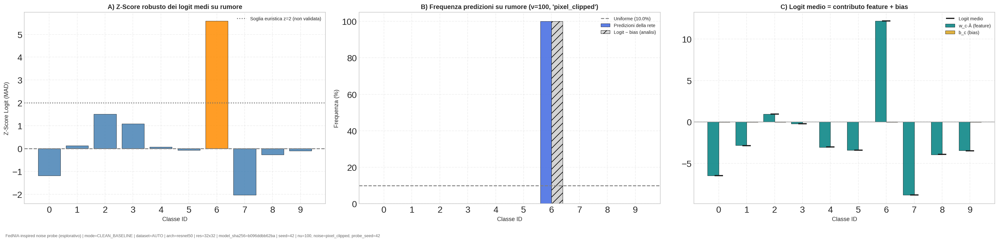

In [48]:
if should_run_section('FEDNIA'):
    clean_memory() if "clean_memory" in globals() else None
    # =====================================================================================================
    # NOISE RESPONSE PROBE INSPIRED BY FedNIA — EXPLORATORY INDICATOR ON A SINGLE MODEL
    # Ref.: E. Hallaji, R. Razavi-Far, M. Saif, "FedNIA: Noise-Induced Activation Analysis for Mitigating
    #       Data Poisoning in Federated Learning", arXiv:2502.16396 (v2 2026; accepted at IEEE TKDE,
    #       DOI 10.1109/TKDE.2026.3736353 according to the arXiv record).
    # Original method (Sec. IV-E, Alg. 2, Eq. 13-16): server-side defense for federated learning. Gaussian
    # noise probes (ν = 100, Sec. V-A4) -> mean activations per layer of EVERY client model -> autoencoder
    # trained on the activations of the global model -> reconstruction error per client -> filter with
    # τ = mean + λσ (λ = 2) on the client errors (Cantelli only as a justification of the form, Eq. 14-15).
    # Here there is ONE model only: no client population, no autoencoder, no criterion from the paper.
    # Only descriptive measures of the model's response to noise are kept (no verdict).
    # =====================================================================================================
    import os
    import traceback
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import matplotlib.pyplot as plt

    FEDNIA_METHOD = "FedNIA-inspired noise probe"
    # Legacy globals with verdict/detection semantics: removed so as not to contaminate the export (reused kernels)
    for _k in ("fednia_detected_class_id", "fednia_detected_class_name", "fednia_detected_class",
               "fednia_is_suspected", "fednia_suspected_backdoor"):
        globals().pop(_k, None)

    # Parameters (override via globals)
    FEDNIA_NOISE_SAMPLES = int(globals().get("FEDNIA_NOISE_SAMPLES", 100))     # ν = 100 as in Sec. V-A4
    FEDNIA_BATCH_SIZE = int(globals().get("FEDNIA_BATCH_SIZE", 50))
    # 'pixel_clipped' (default): x = μ + σ·z, z ~ N(0, I), limited to [0, 1] and renormalized -> same per-channel
    #   moments of the original N(0, I) probe in the normalized space, but inside the valid image domain.
    # 'normalized': legacy N(0, I) probe directly in the normalized space (pixel values outside [0, 1]).
    # 'pixel_uniform': U[0, 1] in the pixel space, then the model's normalization.
    FEDNIA_NOISE_SPACE = str(globals().get("FEDNIA_NOISE_SPACE", "pixel_clipped")).lower()
    FEDNIA_Z_HEURISTIC = float(globals().get("FEDNIA_Z_HEURISTIC", 2.0))       # heuristic, not validated
    FEDNIA_SEED = int(globals().get("FEDNIA_SEED", globals().get("SEED", 9999)))
    if FEDNIA_NOISE_SPACE not in ("pixel_clipped", "normalized", "pixel_uniform"):
        print(f"⚠️ FEDNIA_NOISE_SPACE='{FEDNIA_NOISE_SPACE}' not recognized: using 'pixel_clipped'.")
        FEDNIA_NOISE_SPACE = "pixel_clipped"

    _FEDNIA_Z_NOTE = ("heuristic threshold on the MAD z of the mean logits across classes; the paper's λ=2 applies to "
                      "mean+λσ of the reconstruction errors across clients (Eq. 14) and does not transfer guarantees here")
    _FEDNIA_KEYS = ("fednia_dominant_class_id", "fednia_dominant_class_name", "fednia_dominant_pct",
                    "fednia_dominance_ratio", "fednia_entropy_norm", "fednia_max_zscore", "fednia_max_zscore_class_id",
                    "fednia_activation_norm", "fednia_dominant_pct_no_bias", "fednia_n_classes_z_above_heuristic")

    def _fednia_rec(key, value, status="computed", **kw):
        """record_metric + homonymous global (same value, even NaN) for the backward compatibility of cell 93."""
        kw.setdefault("method", FEDNIA_METHOD)
        v = record_metric(key, value, status, **kw)
        globals()[key] = v
        return v

    def _fednia_rec_all(status, note):
        for _key in _FEDNIA_KEYS:
            _fednia_rec(_key, None, status, note=note)

    # The paper's decision criterion (Eq. 14-16) requires a population of client models + autoencoder
    _fednia_rec("fednia_paper_flag", None, "not_applicable", level="model",
                note="FedNIA criterion (Eq. 14-16) defined on reconstruction errors of multiple FL clients: not applicable to a single model")

    fn_net = get_audit_model(required=False)
    if fn_net is None:
        print("⚠️ No model available for the FedNIA-inspired noise probe.")
        _fednia_rec_all("not_run", "no model available")
    else:
        try:
            with preserve_model_state(fn_net):
                fn_net.eval()
                fn_dev = next(fn_net.parameters()).device
                arch_name_fn = GLOBAL_CONFIG.get("architecture", fn_net.__class__.__name__.lower()) if "GLOBAL_CONFIG" in globals() else fn_net.__class__.__name__.lower()

                # Final classifier: last nn.Linear of the model (K and feature dimension from the loaded model)
                fn_fc = None
                for _name, _mod in fn_net.named_modules():
                    if isinstance(_mod, nn.Linear):
                        fn_fc_name, fn_fc = _name, _mod
                if fn_fc is None:
                    raise RuntimeError("no final nn.Linear layer found in the model")
                fn_K = int(fn_fc.out_features)
                if "NUM_CLASSES" in globals() and int(NUM_CLASSES) != fn_K:
                    print(f"⚠️ NUM_CLASSES={NUM_CLASSES} different from the classifier outputs ({fn_K}): using {fn_K}.")
                _names = globals().get("CLASS_NAMES", None)
                if _names is None:
                    _names = globals().get("classes", None)
                fn_class_names = [str(c) for c in _names] if (_names is not None and len(_names) == fn_K) else [f"class_{i}" for i in range(fn_K)]

                # Resolution and normalization from the model's evaluation context (cell 1)
                fn_ctx = get_model_eval_context(fn_net, device=fn_dev)
                fn_res = int(fn_ctx["target_res"])
                fn_strategy = str(fn_ctx.get("strategy", "scratch"))
                _first_conv = next((m for m in fn_net.modules() if isinstance(m, nn.Conv2d)), None)
                fn_in_ch = int(_first_conv.in_channels) if _first_conv is not None else 3
                _mean = np.asarray(fn_ctx["mean"], dtype=np.float32)
                _std = np.asarray(fn_ctx["std"], dtype=np.float32)
                if _mean.size != fn_in_ch:
                    _mean, _std = np.full(fn_in_ch, float(_mean.mean()), np.float32), np.full(fn_in_ch, float(_std.mean()), np.float32)
                fn_m = torch.tensor(_mean).view(1, -1, 1, 1)
                fn_s = torch.tensor(_std).view(1, -1, 1, 1)

                print("\n" + "=" * 95)
                print("🔬 [FedNIA-INSPIRED] NOISE RESPONSE PROBE — EXPLORATORY INDICATOR (not the FedNIA method)")
                print("   Ref.: Hallaji, Razavi-Far, Saif — arXiv:2502.16396 (FL defense with autoencoder; here single model)")
                print(f"📦 Model: {fn_net.__class__.__name__} ({arch_name_fn}) | Strategy: {fn_strategy}"
                      f"{' (inferred)' if fn_ctx.get('strategy_inferred') else ''} | Input: {fn_in_ch}x{fn_res}x{fn_res} | Classes: {fn_K}")
                print(f"⚙️ Probes ν={FEDNIA_NOISE_SAMPLES} | noise space='{FEDNIA_NOISE_SPACE}' | seed={FEDNIA_SEED} | final layer='{fn_fc_name}'")
                print("=" * 95)

                def fednia_make_noise(n, gen):
                    """Noise probes in the model's input space (normalized) + fraction of clipped pixel values."""
                    shape = (n, fn_in_ch, fn_res, fn_res)
                    if FEDNIA_NOISE_SPACE == "pixel_uniform":
                        x = torch.rand(shape, generator=gen)
                        return (x - fn_m) / fn_s, 0.0
                    z = torch.randn(shape, generator=gen)
                    if FEDNIA_NOISE_SPACE == "normalized":
                        return z, 0.0
                    x = fn_m + fn_s * z
                    clip_frac = float(((x < 0) | (x > 1)).float().mean().item())
                    return (x.clamp(0.0, 1.0) - fn_m) / fn_s, clip_frac

                # Forward on noise: input of the final classifier (penultimate features) and network logits
                fn_feats, fn_fc_out = [], []
                def _fednia_hook(module, inp, out):
                    fn_feats.append(inp[0].detach().flatten(1).double().cpu())
                    fn_fc_out.append(out.detach().double().cpu())

                fn_gen = torch.Generator().manual_seed(FEDNIA_SEED)   # Local RNG: no global re-seed
                fn_logits_list, fn_clip = [], []
                fn_handle = fn_fc.register_forward_hook(_fednia_hook)
                try:
                    with torch.no_grad():
                        _done = 0
                        while _done < FEDNIA_NOISE_SAMPLES:
                            _b = min(FEDNIA_BATCH_SIZE, FEDNIA_NOISE_SAMPLES - _done)
                            _xb, _cf = fednia_make_noise(_b, fn_gen)
                            _out = fn_net(_xb.to(fn_dev))
                            if isinstance(_out, (tuple, list)):
                                _out = _out[0]
                            fn_logits_list.append(_out.detach().double().cpu())
                            fn_clip.append(_cf * _b)
                            _done += _b
                finally:
                    fn_handle.remove()

                fn_logits = torch.cat(fn_logits_list, 0).numpy()                  # (ν, K)
                N_fn = fn_logits.shape[0]
                fn_H = torch.cat(fn_feats, 0).numpy() if fn_feats else None        # (ν, d)
                if fn_H is not None and fn_H.shape[0] != N_fn:                     # Linear invoked more than once per forward
                    fn_H = None
                fn_clip_frac = float(np.sum(fn_clip) / max(FEDNIA_NOISE_SAMPLES, 1))

                # ---------------------------------------------------------------------------------------------
                # DESCRIPTIVE MEASURES (same in all modes; no information about the attack)
                # ---------------------------------------------------------------------------------------------
                fn_probs = torch.softmax(torch.from_numpy(fn_logits), dim=1).numpy()
                fn_preds = fn_logits.argmax(1)
                fn_counts = np.bincount(fn_preds, minlength=fn_K)
                fn_freq_pct = 100.0 * fn_counts / N_fn
                fn_uniform_pct = 100.0 / fn_K
                fn_mean_logits = fn_logits.mean(0)
                fn_mean_probs = fn_probs.mean(0)

                # Dominant class = most frequent among the predictions on noise (tie -> higher mean logit)
                fn_order_freq = np.lexsort((-fn_mean_logits, -fn_counts))
                fn_dom_id = int(fn_order_freq[0])
                fn_dom_pct = float(fn_freq_pct[fn_dom_id])
                fn_dom_ratio = fn_dom_pct / fn_uniform_pct

                # Normalized Shannon entropy of the prediction distribution (0·log0 = 0, no epsilon)
                _p = fn_counts[fn_counts > 0] / N_fn
                fn_entropy_norm = max(0.0, float(-(_p * np.log(_p)).sum() / np.log(fn_K))) if fn_K > 1 else float("nan")

                # robust z (MAD) of the mean logits across classes (contract: NaN if MAD = 0 or K < 3)
                fn_z, fn_z_info = robust_mad_z(fn_mean_logits, min_n=3)
                if fn_z_info["status"] == "computed":
                    fn_zmax_id = int(np.nanargmax(fn_z))
                    fn_zmax = float(fn_z[fn_zmax_id])
                    fn_above = np.where(fn_z >= FEDNIA_Z_HEURISTIC)[0]
                else:
                    fn_zmax_id, fn_zmax, fn_above = None, float("nan"), np.array([], dtype=int)

                # Norm of the mean of the noise-induced penultimate features ||Ā||_2 (architecture-dependent scale)
                fn_act_norm = float(np.linalg.norm(fn_H.mean(0))) if fn_H is not None else float("nan")

                # Classifier bias: mean logit = w_c·Ā + b_c (exact if the final Linear produces the network output)
                fn_W = fn_fc.weight.detach().double().cpu().numpy()
                fn_bias = fn_fc.bias.detach().double().cpu().numpy() if fn_fc.bias is not None else None
                _fco = torch.cat(fn_fc_out, 0).numpy() if fn_fc_out else None
                fn_fc_is_output = _fco is not None and _fco.shape == fn_logits.shape and np.allclose(_fco, fn_logits, rtol=1e-5, atol=1e-6)
                if fn_H is not None and fn_fc_is_output:
                    fn_feat_contrib = fn_W @ fn_H.mean(0)
                    _b_arr = fn_bias if fn_bias is not None else np.zeros(fn_K)
                    # Fraction of probes on the dominant class after subtracting b from the logits (a posteriori analysis, model unchanged)
                    fn_preds_nb = (fn_logits - _b_arr[None, :]).argmax(1)
                    fn_freq_nb_pct = 100.0 * np.bincount(fn_preds_nb, minlength=fn_K) / N_fn
                    fn_dom_pct_nb = float(fn_freq_nb_pct[fn_dom_id])
                    fn_decomp_status = "computed"
                else:
                    fn_feat_contrib = np.full(fn_K, np.nan)
                    fn_freq_nb_pct = np.full(fn_K, np.nan)
                    fn_dom_pct_nb = float("nan")
                    fn_decomp_status = "not_applicable"
                fn_bias_top = int(np.argmax(fn_bias)) if fn_bias is not None else None
                fn_bias_z = robust_mad_z(fn_bias, min_n=3)[0] if fn_bias is not None else np.full(fn_K, np.nan)

                # ---------------------------------------------------------------------------------------------
                # REPORT (sorted by mean logit = ordering of the MAD z)
                # ---------------------------------------------------------------------------------------------
                fn_order = np.argsort(-fn_mean_logits)
                _top = fn_order[:min(10, fn_K)]
                df_fednia = pd.DataFrame({
                    'Rank': list(range(1, len(_top) + 1)),
                    'Class ID': _top,
                    'Class Name': [fn_class_names[i] for i in _top],
                    'Noise Frequency (%)': [fn_freq_pct[i] for i in _top],
                    'Freq. without bias (%)': [fn_freq_nb_pct[i] for i in _top],
                    'Mean Logit': [fn_mean_logits[i] for i in _top],
                    'Z-Score Logit (MAD)': [fn_z[i] for i in _top],
                    'Prob. Softmax': [fn_mean_probs[i] for i in _top],
                    'Bias b_c': [fn_bias[i] if fn_bias is not None else np.nan for i in _top],
                    'Contribution w_c·Ā': [fn_feat_contrib[i] for i in _top],
                    'Indicator': [f'z ≥ {FEDNIA_Z_HEURISTIC:g} (heuristic)' if (np.isfinite(fn_z[i]) and fn_z[i] >= FEDNIA_Z_HEURISTIC) else '' for i in _top],
                })

                print("\n" + "-" * 95)
                print(f"📊 [FedNIA-INSPIRED] NOISE RESPONSE (Norm Entropy: {fn_entropy_norm:.3f} | Uniform Baseline: {fn_uniform_pct:.2f}% | Norm Ā: {fn_act_norm:.3f})")
                if FEDNIA_NOISE_SPACE == "pixel_clipped":
                    print(f"   Fraction of pixel values clipped to [0,1]: {100 * fn_clip_frac:.2f}%")
                print("-" * 95)
                print(df_fednia.to_string(index=False, formatters={
                    'Noise Frequency (%)': '{:.1f}%'.format,
                    'Freq. without bias (%)': '{:.1f}%'.format,
                    'Mean Logit': '{:+.3f}'.format,
                    'Z-Score Logit (MAD)': '{:+.2f}'.format,
                    'Prob. Softmax': '{:.4f}'.format,
                    'Bias b_c': '{:+.3f}'.format,
                    'Contribution w_c·Ā': '{:+.3f}'.format,
                }))
                print("-" * 95)
                print(f"🎯 Dominant class on noise: '{fn_class_names[fn_dom_id]}' (#{fn_dom_id}) - Freq: {fn_dom_pct:.1f}% "
                      f"({fn_dom_ratio:.2f}x uniform) | without bias: {fn_dom_pct_nb:.1f}%")
                if fn_z_info["status"] == "computed":
                    print(f"   max MAD z of the mean logits: {fn_zmax:+.2f} on class '{fn_class_names[fn_zmax_id]}' (#{fn_zmax_id}); "
                          f"classes with z ≥ {FEDNIA_Z_HEURISTIC:g} (heuristic threshold): {len(fn_above)}")
                else:
                    print(f"   MAD z of the mean logits not computable (status: {fn_z_info['status']}, MAD={fn_z_info['mad']}).")
                if fn_bias_top is not None:
                    print(f"ℹ️ Class with the maximum classifier bias: '{fn_class_names[fn_bias_top]}' (#{fn_bias_top}), b = {fn_bias[fn_bias_top]:+.3f}")
                    if fn_bias_top == fn_dom_id:
                        print("   -> The dominant class coincides with the maximum-bias class: the dominance may depend on the bias alone.")
                print("\nℹ️ [INTERPRETATION] Exploratory indicator, no verdict: even clean models often assign the noise to a single")
                print("   class (classifier bias, training imbalance, preprocessing, out-of-distribution features).")
                print("   Without a calibrated reference (comparable clean models) frequency, entropy and z do not separate clean from compromised.")

                # Evaluation (oracle): only in the attacker modes and only after the computation
                fn_target = globals().get("TARGET_LABEL", None) if oracle_allowed() else None
                fn_target_ok = fn_target is not None and isinstance(fn_target, (int, np.integer)) and 0 <= int(fn_target) < fn_K
                if fn_target_ok:
                    fn_target = int(fn_target)
                    _rank_t = int(np.where(fn_order_freq == fn_target)[0][0]) + 1
                    print(f"\n🧪 Evaluation (oracle): target '{fn_class_names[fn_target]}' (#{fn_target}) -> freq {fn_freq_pct[fn_target]:.1f}% "
                          f"(rank {_rank_t}/{fn_K}), MAD z {fn_z[fn_target]:+.2f}; dominant class = target: {fn_target == fn_dom_id}")

                # ---------------------------------------------------------------------------------------------
                # PLOTS (3 panels): MAD z of the logits, frequencies with/without bias, decomposition of the mean logit
                # ---------------------------------------------------------------------------------------------
                fig_fednia, axes_fn = plt.subplots(1, 3, figsize=(24, 5.8), dpi=130)
                _x = np.arange(fn_K)
                if fn_z_info["status"] == "computed":
                    _cz = ['darkorange' if z >= FEDNIA_Z_HEURISTIC else 'steelblue' for z in fn_z]
                    axes_fn[0].bar(_x, fn_z, color=_cz, alpha=0.85, edgecolor='black', linewidth=0.5)
                    axes_fn[0].axhline(0, color='gray', linestyle='--')
                    axes_fn[0].axhline(FEDNIA_Z_HEURISTIC, color='dimgray', linestyle=':', label=f'Heuristic threshold z={FEDNIA_Z_HEURISTIC:g} (not validated)')
                    axes_fn[0].set_ylabel("Z-Score Logit (MAD)", fontsize=10)
                    axes_fn[0].set_title("A) Robust Z-Score of the mean logits on noise", fontsize=11, fontweight="bold")
                else:
                    axes_fn[0].bar(_x, fn_mean_logits, color='steelblue', alpha=0.85, edgecolor='black', linewidth=0.5)
                    axes_fn[0].set_ylabel("Mean logit", fontsize=10)
                    axes_fn[0].set_title(f"A) Mean logits on noise (MAD z: {fn_z_info['status']})", fontsize=11, fontweight="bold")
                axes_fn[0].set_xlabel("Class ID", fontsize=10)

                _w = 0.4
                axes_fn[1].bar(_x - _w / 2, fn_freq_pct, _w, color='royalblue', alpha=0.85, edgecolor='black', linewidth=0.5, label='Network predictions')
                if fn_decomp_status == "computed":
                    axes_fn[1].bar(_x + _w / 2, fn_freq_nb_pct, _w, color='lightgray', edgecolor='black', linewidth=0.5, hatch='//', label='Logit − bias (analysis)')
                axes_fn[1].axhline(fn_uniform_pct, color='gray', linestyle='--', label=f'Uniform ({fn_uniform_pct:.1f}%)')
                axes_fn[1].set_title(f"B) Prediction frequency on noise (ν={N_fn}, '{FEDNIA_NOISE_SPACE}')", fontsize=11, fontweight="bold")
                axes_fn[1].set_xlabel("Class ID", fontsize=10)
                axes_fn[1].set_ylabel("Frequency (%)", fontsize=10)

                if fn_decomp_status == "computed":
                    axes_fn[2].bar(_x - _w / 2, fn_feat_contrib, _w, color='teal', alpha=0.85, edgecolor='black', linewidth=0.5, label='w_c·Ā (feature)')
                    axes_fn[2].bar(_x + _w / 2, fn_bias if fn_bias is not None else np.zeros(fn_K), _w, color='goldenrod', alpha=0.85, edgecolor='black', linewidth=0.5, label='b_c (bias)')
                    axes_fn[2].plot(_x, fn_mean_logits, 'k_', markersize=14, mew=2, label='Mean logit')
                    axes_fn[2].axhline(0, color='gray', linewidth=0.8)
                else:
                    axes_fn[2].text(0.5, 0.5, "Decomposition not available\n(the final Linear does not produce the network output)",
                                    ha='center', va='center', transform=axes_fn[2].transAxes)
                axes_fn[2].set_title("C) Mean logit = feature contribution + bias", fontsize=11, fontweight="bold")
                axes_fn[2].set_xlabel("Class ID", fontsize=10)

                if fn_target_ok:
                    for _ax in axes_fn:
                        _ax.axvline(fn_target, color='black', linestyle='-.', linewidth=1.0, label='Target (oracle evaluation)')
                for _ax in axes_fn:
                    if fn_K <= 20:
                        _ax.set_xticks(_x)
                    _ax.grid(True, linestyle="--", alpha=0.3)
                    if _ax.get_legend_handles_labels()[0]:
                        _ax.legend(fontsize=8)
                plt.tight_layout(rect=(0, 0.03, 1, 1))
                fig_fednia.text(0.01, 0.005, provenance_caption("FedNIA-inspired noise probe (exploratory)",
                                extra=f"nu={N_fn}, noise={FEDNIA_NOISE_SPACE}, probe_seed={FEDNIA_SEED}"), fontsize=7, alpha=0.7)

                # ---------------------------------------------------------------------------------------------
                # METRICS REGISTRATION, ENTITIES PER CLASS AND SAVING
                # ---------------------------------------------------------------------------------------------
                _common_note = (f"exploratory probe on a single model, not the FedNIA method; ν={N_fn}, noise='{FEDNIA_NOISE_SPACE}', "
                                f"res={fn_res}, seed={FEDNIA_SEED}")
                _fednia_rec("fednia_dominant_class_id", fn_dom_id, level="class", note=_common_note)
                _fednia_rec("fednia_dominant_class_name", fn_class_names[fn_dom_id], level="class", note=_common_note)
                _fednia_rec("fednia_dominant_pct", fn_dom_pct, level="class", unit="%", note=_common_note)
                _fednia_rec("fednia_dominance_ratio", fn_dom_ratio, level="class", unit="x (100/K %)",
                            note="descriptive ratio with respect to the uniform distribution; uniformity is not expected even in clean models")
                _fednia_rec("fednia_entropy_norm", fn_entropy_norm, "computed" if fn_K > 1 else "degenerate", level="model", unit="[0,1]",
                            note="H(predictions on noise)/ln K")
                _fednia_rec("fednia_max_zscore", fn_zmax, fn_z_info["status"], level="class", unit="z MAD",
                            threshold=FEDNIA_Z_HEURISTIC, threshold_origin="heuristic", note=_FEDNIA_Z_NOTE)
                _fednia_rec("fednia_max_zscore_class_id", fn_zmax_id, fn_z_info["status"], level="class", note="class with the maximum MAD z of the mean logits")
                _fednia_rec("fednia_n_classes_z_above_heuristic", int(len(fn_above)) if fn_z_info["status"] == "computed" else None,
                            fn_z_info["status"], level="model", threshold=FEDNIA_Z_HEURISTIC, threshold_origin="heuristic", note=_FEDNIA_Z_NOTE)
                _fednia_rec("fednia_activation_norm", fn_act_norm, "computed" if fn_H is not None else "failed", level="model", unit="L2",
                            note=f"||mean penultimate features on noise||; depends on architecture (d={fn_W.shape[1]}) and resolution")
                _fednia_rec("fednia_dominant_pct_no_bias", fn_dom_pct_nb, fn_decomp_status, level="class", unit="%",
                            note="frequency of the same dominant class computed on logit − b (post-hoc analysis, model unchanged)")
                _fednia_rec("fednia_n_probes", int(N_fn), level="model", note="parameter")
                _fednia_rec("fednia_noise_space", FEDNIA_NOISE_SPACE, level="model", note="parameter")
                if fn_target_ok:
                    _fednia_rec("fednia_target_pct", float(fn_freq_pct[fn_target]), level="class", unit="%", requires_ground_truth=True,
                                note="evaluation (oracle): frequency of the predictions on noise toward the target")
                    _fednia_rec("fednia_target_zscore", float(fn_z[fn_target]), fn_z_info["status"], level="class", unit="z MAD",
                                requires_ground_truth=True, note="evaluation (oracle)")
                else:
                    for _key in ("fednia_target_pct", "fednia_target_zscore"):
                        _fednia_rec(_key, None, "not_applicable", level="class", requires_ground_truth=True,
                                    note="target not available in this mode")

                _rank_by_logit = {int(c): r + 1 for r, c in enumerate(fn_order)}
                record_entities(FEDNIA_METHOD, "class", [{
                    "entity_id": int(c), "class_id": int(c), "class_name": fn_class_names[c],
                    "score": float(fn_z[c]) if np.isfinite(fn_z[c]) else float("nan"),
                    "rank": _rank_by_logit[int(c)],
                    "flag": bool(np.isfinite(fn_z[c]) and fn_z[c] >= FEDNIA_Z_HEURISTIC),
                    "noise_pred_pct": float(fn_freq_pct[c]), "noise_pred_pct_no_bias": float(fn_freq_nb_pct[c]),
                    "mean_logit": float(fn_mean_logits[c]), "mean_softmax": float(fn_mean_probs[c]),
                    "bias": float(fn_bias[c]) if fn_bias is not None else float("nan"),
                    "bias_z_mad": float(fn_bias_z[c]), "feature_contrib": float(fn_feat_contrib[c]),
                    "requires_ground_truth": False,
                    "note": "score = MAD z of the mean logit on noise; flag = heuristic threshold (candidate for inspection, not a verdict)",
                } for c in range(fn_K)])

                out_dir_fednia = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                os.makedirs(out_dir_fednia, exist_ok=True)
                fednia_img_filename = f"fednia_diagnostics_{fn_strategy}.png"
                fednia_save_path = os.path.join(out_dir_fednia, fednia_img_filename)
                fig_fednia.savefig(fednia_save_path, bbox_inches='tight', dpi=130)
                register_artifact(FEDNIA_METHOD, fednia_save_path, kind="figure", note="exploratory noise probe (3 panels)")
                globals()['FEDNIA_PLOT_IMG_PATH'] = fednia_save_path
                _fednia_rec("fednia_plot_img", fednia_img_filename, level="model", note="graphical artifact")
                print(f"📊 [FedNIA-INSPIRED] Diagnostic plot saved to: {fednia_save_path}")
                plt.show()
                plt.close(fig_fednia)
        except Exception as e_fn:
            traceback.print_exc()
            print(f"❌ [FedNIA-INSPIRED] Error during the probe: {e_fn}")
            _fednia_rec_all("failed", f"error: {type(e_fn).__name__}: {e_fn}")
        check_model_integrity('FEDNIA')

    clean_memory(verbose=False) if "clean_memory" in globals() else None


---
## 🧼 25. Neural Cleanse


🛡️ [NEURAL CLEANSE] TRIGGER REVERSE-ENGINEERING & ANOMALY INDEX (Wang et al., IEEE S&P 2019)
📦 Model: ResNet | Pool: 256 images (3x32x32) | optimization=176 hold-out=80 | Classes: 10
⚙️ Optimizing reversed triggers for 10 classes (steps=250, restart=1, success threshold=0.99)...
   [NC] Target 00/09: 'airplane'... L1: 51.67 (5.0%) | ASR opt: 100.0% | ASR hold-out: 87.5%
   [NC] Target 01/09: 'automobile'... L1: 63.77 (6.2%) | ASR opt: 100.0% | ASR hold-out: 98.6%
   [NC] Target 02/09: 'bird'... L1: 55.75 (5.4%) | ASR opt: 100.0% | ASR hold-out: 94.4%
   [NC] Target 03/09: 'cat'... L1: 46.04 (4.5%) | ASR opt: 100.0% | ASR hold-out: 95.8%
   [NC] Target 04/09: 'deer'... L1: 54.38 (5.3%) | ASR opt: 99.2% | ASR hold-out: 90.3%
   [NC] Target 05/09: 'dog'... L1: 77.06 (7.5%) | ASR opt: 100.0% | ASR hold-out: 91.7%
   [NC] Target 06/09: 'frog'... L1: 40.18 (3.9%) | ASR opt: 100.0% | ASR hold-out: 93.1%
   [NC] Target 07/09: 'horse'... L1: 51.50 (5.0%) | ASR opt: 100.0% | ASR hold-out: 97.2%

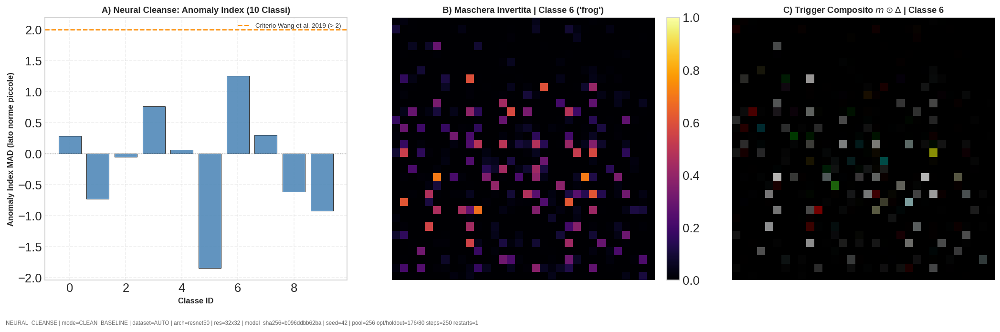

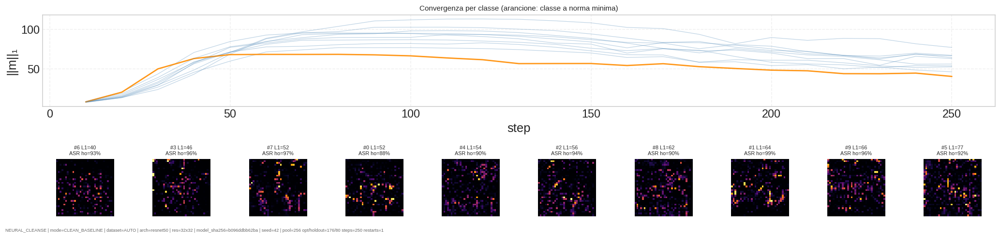

In [49]:
if should_run_section('NEURAL_CLEANSE'):
    if "clean_memory" in globals():
        clean_memory()

    import gc
    import os
    import math
    import traceback
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, Subset

    # ==========================================================================
    # NEURAL CLEANSE — B. Wang et al., "Neural Cleanse: Identifying and Mitigating
    # Backdoor Attacks in Neural Networks", IEEE S&P 2019, Sez. IV (Eq. 2-3 + MAD).
    # Reference implementation: github.com/bolunwang/backdoor (visualizer.py,
    # mad_outlier_detection.py). Detection and inspection only: the mitigations of
    # Sec. VI (filter, pruning, unlearning) are NOT executed.
    # ==========================================================================

    # --------------------------------------------------------------------------
    # 1. PARAMETERS, MODEL AND AUDIT ENVIRONMENT
    # --------------------------------------------------------------------------
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

    # Expensive parameters can be overridden via globals (quick CPU tests).
    _nc_succ = float(globals().get("NC_ATTACK_SUCC_THRESHOLD", 0.99))  # Sez. IV: "> 99% of clean images"
    NC_RUN_PARAMS = {
        "steps": int(globals().get("NC_STEPS", 250)),
        "lr": float(globals().get("NC_LR", 0.08)),
        "batch_size": int(globals().get("NC_BATCH_SIZE", 16)),
        "eval_batch_size": int(globals().get("NC_EVAL_BATCH_SIZE", 32)),
        "init_cost": float(globals().get("NC_INIT_COST", 1e-4)),
        "cost_multiplier": float(globals().get("NC_COST_MULTIPLIER", 1.5)),  # down = up ** 1.5 (official code)
        "patience": int(globals().get("NC_PATIENCE", 5)),
        "check_every": int(globals().get("NC_CHECK_EVERY", 10)),
        "attack_succ_threshold": _nc_succ,
        # Official code: the best mask is selected only if the attack exceeds the same threshold.
        "selection_threshold": float(globals().get("NC_SELECTION_THRESHOLD", _nc_succ)),
        # With n control images the effective threshold is ceil(0.99·n)/n: 128 admits 1 error (64 none).
        "check_samples": int(globals().get("NC_CHECK_SAMPLES", 128)),
        "restarts": max(1, int(globals().get("NC_RESTARTS", 1))),
        "holdout_frac": float(globals().get("NC_HOLDOUT_FRAC", 0.3)),
        "max_pool": globals().get("NC_MAX_POOL_SAMPLES", None),
        "seed": int(globals().get("NC_RANDOM_SEED", globals().get("SEED", 1234))),
        "anomaly_threshold": 2.0,  # Wang et al. 2019, Sec. IV
    }
    _NC_THR_ORIGIN = ("paper:Wang et al. 2019 Sec. IV (MAD with constant 1.4826, index > 2 on the side of the "
                      "small L1 norms; '>95%' holds under a normality assumption, for a single class)")

    class _NCSkip(Exception):
        """Requirement not satisfied: the section ends with an explicit status."""

    def _nc_rec(key, value, status="computed", **kw):
        kw.setdefault("method", "NEURAL_CLEANSE")
        v = record_metric(key, value, status, **kw)
        globals()[key] = v
        return v

    def _nc_record_unavailable(status, note):
        for _k, _lvl in (("nc_max_anomaly_index", "model"), ("nc_min_l1_norm", "class"),
                         ("nc_median_l1_norm", "model"), ("nc_suspected_class_id", "class"),
                         ("nc_suspected_class_name", "class"), ("nc_inverted_asr", "class"),
                         ("nc_outlier_count", "model"), ("nc_paper_flag", "model"), ("nc_n_valid_classes", "model")):
            _nc_rec(_k, None, status, level=_lvl, note=note)
        for _k in ("nc_target_l1_norm", "nc_target_anomaly_index", "nc_target_inverted_asr"):
            _nc_rec(_k, None, status, level="class", requires_ground_truth=True, note=note)

    def _nc_logits(out):
        if isinstance(out, (tuple, list)):
            out = out[0]
        elif isinstance(out, dict):
            out = out.get("logits", out.get("out"))
        return out

    def _nc_dataset_labels(ds, rng, cap):
        """Labels without transforming the images (targets/labels/samples attributes or Subset).
        Returns (candidate indices, labels); in the absence of attributes it reads a random subset."""
        def _from_attrs(d):
            for _attr in ("targets", "labels"):
                _t = getattr(d, _attr, None)
                if _t is not None:
                    try:
                        _arr = np.asarray([int(v) for v in _t], dtype=np.int64)
                        if len(_arr) == len(d):
                            return _arr
                    except Exception:
                        pass
            _s = getattr(d, "samples", None)
            if _s is not None:
                try:
                    _arr = np.asarray([int(s[1]) for s in _s], dtype=np.int64)
                    if len(_arr) == len(d):
                        return _arr
                except Exception:
                    pass
            if hasattr(d, "indices") and hasattr(d, "dataset"):
                _base = _from_attrs(d.dataset)
                if _base is not None:
                    return _base[np.asarray(d.indices, dtype=np.int64)]
            return None
        _lab = _from_attrs(ds)
        if _lab is not None:
            return np.arange(len(ds)), _lab
        _cand = np.sort(rng.choice(len(ds), size=min(len(ds), cap), replace=False))
        _vals = []
        for _i in _cand:
            _y = ds[int(_i)][1]
            _vals.append(int(_y.item()) if torch.is_tensor(_y) else int(_y))
        return _cand, np.asarray(_vals, dtype=np.int64)

    nc_net = get_audit_model()
    nc_device = next(nc_net.parameters()).device
    # Results of a previous run (reused kernel) must not reach cell 82
    for _k in ("nc_masks_dict", "nc_patterns_dict", "nc_df", "nc_df_sorted", "nc_suspected_target_class", "nc_class_names",
               "nc_holdout_imgs", "nc_holdout_lbls", "nc_opt_imgs", "nc_opt_lbls", "nc_asrs_dict", "NC_MODEL_FINGERPRINT"):
        globals().pop(_k, None)
    NC_MODEL_FINGERPRINT = globals().get("AUDIT_MODEL_FINGERPRINT")

    # Evaluation context (resolution and normalization of the inspected model)
    if "get_model_eval_context" in globals():
        nc_ctx = get_model_eval_context(nc_net, device=nc_device)
    else:
        nc_ctx = {"mean": globals().get("SCRATCH_MEAN", [0.5, 0.5, 0.5]),
                  "std": globals().get("SCRATCH_STD", [0.5, 0.5, 0.5]), "target_res": None}
    nc_norm_mean = [float(v) for v in np.asarray(nc_ctx.get("mean")).ravel()]
    nc_norm_std = [float(v) for v in np.asarray(nc_ctx.get("std")).ravel()]
    nc_target_res = nc_ctx.get("target_res")

    with preserve_model_state(nc_net):
        nc_net.eval()
        for _p in nc_net.parameters():
            _p.requires_grad_(False)
        try:
            # ------------------------------------------------------------------
            # 2. STRATIFIED CLEAN POOL + OPTIMIZATION / HOLD-OUT SPLIT
            # ------------------------------------------------------------------
            nc_src_ds = None
            for _ds_name in ("evaluation_clean_test", "clean_test_dataset", "test_clean_ds", "clean_train_dataset"):
                _ds = globals().get(_ds_name)
                if _ds is not None and len(_ds) > 0:
                    nc_src_ds = _ds
                    break
            if nc_src_ds is None and globals().get("test_loader") is not None:
                nc_src_ds = test_loader.dataset
            if nc_src_ds is None or len(nc_src_ds) == 0:
                raise _NCSkip("no clean dataset available (Neural Cleanse requires a small set of clean images, Sec. IV)")

            _nc_rng = np.random.default_rng(NC_RUN_PARAMS["seed"])

            # Probe: actual number of classes of the model
            _x0 = nc_src_ds[0][0]
            _x0 = _x0 if torch.is_tensor(_x0) else torch.as_tensor(np.asarray(_x0))
            with torch.no_grad():
                nc_num_classes = int(_nc_logits(nc_net(_x0.float().unsqueeze(0).to(nc_device))).shape[1])

            _pool_default = max(10 * nc_num_classes, 256)
            nc_max_pool = min(int(NC_RUN_PARAMS["max_pool"] or _pool_default), len(nc_src_ds))
            _cand_idx, _cand_lbl = _nc_dataset_labels(nc_src_ds, _nc_rng, cap=max(4 * nc_max_pool, 1000))

            _selected = []
            _unique_labels = np.unique(_cand_lbl)
            if len(_unique_labels) > 0:
                _per_class = max(1, nc_max_pool // len(_unique_labels))
                for _lab in _unique_labels:
                    _idxs = _cand_idx[_cand_lbl == _lab].copy()
                    _nc_rng.shuffle(_idxs)
                    _selected.extend(_idxs[:_per_class].tolist())
            if len(_selected) < nc_max_pool:
                _remaining = np.setdiff1d(_cand_idx, np.asarray(_selected, dtype=np.int64))
                _nc_rng.shuffle(_remaining)
                _selected.extend(_remaining[:nc_max_pool - len(_selected)].tolist())
            _selected = [int(i) for i in _selected[:nc_max_pool]]

            _tmp_loader = DataLoader(Subset(nc_src_ds, _selected), batch_size=min(64, len(_selected)), shuffle=False, num_workers=0)
            _imgs, _lbls = [], []
            for _batch in _tmp_loader:
                _imgs.append(torch.as_tensor(_batch[0]).float())
                _lbls.append(torch.as_tensor(_batch[1]).long().view(-1))
            del _tmp_loader
            nc_pool_imgs = torch.cat(_imgs, dim=0).cpu()
            nc_pool_lbls = torch.cat(_lbls, dim=0).cpu()
            del _imgs, _lbls

            nc_channels = int(nc_pool_imgs.shape[1])
            _mean_cpu = torch.tensor(nc_norm_mean[:nc_channels], dtype=torch.float32).view(1, nc_channels, 1, 1)
            _std_cpu = torch.tensor(nc_norm_std[:nc_channels], dtype=torch.float32).view(1, nc_channels, 1, 1)

            # The inversion operates in raw pixel space [0, 1] (Eq. 2): de-normalize if necessary
            _lo, _hi = float(nc_pool_imgs.min()), float(nc_pool_imgs.max())
            if _lo < -1e-5 or _hi > 1.00001:
                nc_pool_imgs = nc_pool_imgs * _std_cpu + _mean_cpu
            nc_pool_imgs = nc_pool_imgs.clamp(0.0, 1.0)
            if nc_target_res and int(nc_pool_imgs.shape[-1]) != int(nc_target_res):
                print(f"⚠️ [NC] Pool at {tuple(nc_pool_imgs.shape[-2:])}: resized to {nc_target_res}x{nc_target_res} (model resolution).")
                nc_pool_imgs = F.interpolate(nc_pool_imgs, size=(int(nc_target_res), int(nc_target_res)),
                                             mode="bilinear", align_corners=False).clamp(0.0, 1.0)
            nc_H, nc_W = int(nc_pool_imgs.shape[-2]), int(nc_pool_imgs.shape[-1])
            nc_total_pixels = nc_H * nc_W

            # Stratified split: the hold-out images take part neither in the optimization
            # nor in the mask selection and serve only to measure the ASR of the inverted trigger.
            _split_rng = np.random.default_rng(NC_RUN_PARAMS["seed"] + 17)
            _lbl_np = nc_pool_lbls.numpy()
            _is_hold = np.zeros(len(_lbl_np), dtype=bool)
            for _lab in np.unique(_lbl_np):
                _idxs = np.flatnonzero(_lbl_np == _lab)
                _split_rng.shuffle(_idxs)
                _n_h = int(round(NC_RUN_PARAMS["holdout_frac"] * len(_idxs))) if len(_idxs) >= 2 else 0
                _is_hold[_idxs[:_n_h]] = True
            nc_opt_imgs, nc_opt_lbls = nc_pool_imgs[~_is_hold], nc_pool_lbls[~_is_hold]
            nc_holdout_imgs, nc_holdout_lbls = nc_pool_imgs[_is_hold], nc_pool_lbls[_is_hold]
            if len(nc_opt_imgs) == 0:
                raise _NCSkip("optimization pool empty after the split")

            nc_mean_t = _mean_cpu.to(nc_device)
            nc_std_t = _std_cpu.to(nc_device)

            _cls = globals().get("CLASS_NAMES") or globals().get("CIFAR10_CLASSES")
            nc_class_names = list(_cls) if (_cls is not None and len(_cls) == nc_num_classes) else [f"Class_{i}" for i in range(nc_num_classes)]

            print("\n" + "=" * 90)
            print("🛡️ [NEURAL CLEANSE] TRIGGER REVERSE-ENGINEERING & ANOMALY INDEX (Wang et al., IEEE S&P 2019)")
            print(f"📦 Model: {nc_net.__class__.__name__} | Pool: {len(nc_pool_imgs)} images ({nc_channels}x{nc_H}x{nc_W}) "
                  f"| optimization={len(nc_opt_imgs)} hold-out={len(nc_holdout_imgs)} | Classes: {nc_num_classes}")
            print("=" * 90)

            # ------------------------------------------------------------------
            # 3. INVERSE OPTIMIZER (Eq. 3: min CE(y_t, f(A(x,m,Δ))) + λ·|m|)
            # ------------------------------------------------------------------
            def _nc_asr(model, mask_t, pattern_t, imgs, target_class, bs):
                """Fraction of non-target images classified as target with the trigger applied."""
                if imgs is None or len(imgs) == 0:
                    return float("nan")
                _succ = 0
                with torch.no_grad():
                    for _s in range(0, len(imgs), bs):
                        _x = imgs[_s:_s + bs].to(nc_device).float()
                        _trig = (1.0 - mask_t) * _x + mask_t * pattern_t
                        _out = _nc_logits(model((_trig - nc_mean_t) / nc_std_t))
                        _succ += int((_out.argmax(1) == target_class).sum().item())
                return _succ / float(len(imgs))

            def reverse_engineer_trigger_for_class(model, target_class, opt_imgs, check_imgs, seed, p):
                """Inversion for one class; selection = minimum-L1-norm mask that reaches the success threshold
                on the optimization images (as in the official code)."""
                model.eval()
                _n = len(opt_imgs)
                _bs = min(int(p["batch_size"]), _n)
                _rng = np.random.default_rng(seed)
                _gen = torch.Generator().manual_seed(int(seed))

                # tanh parameterization: m, Δ ∈ [0, 1] (official code)
                _init_m = _rng.uniform(0.001, 0.01, (1, 1, nc_H, nc_W)).astype(np.float32)
                _init_p = _rng.uniform(0.1, 0.9, (1, nc_channels, nc_H, nc_W)).astype(np.float32)
                m_var = torch.tensor(np.arctanh(np.clip(2.0 * _init_m - 1.0, -0.999, 0.999)).astype(np.float32),
                                     device=nc_device, requires_grad=True)
                p_var = torch.tensor(np.arctanh(np.clip(2.0 * _init_p - 1.0, -0.999, 0.999)).astype(np.float32),
                                     device=nc_device, requires_grad=True)
                optimizer = torch.optim.Adam([m_var, p_var], lr=p["lr"], betas=(0.5, 0.9))
                criterion = nn.CrossEntropyLoss()
                target_labels = torch.full((_bs,), int(target_class), dtype=torch.long, device=nc_device)

                cost = float(p["init_cost"])
                cost_up_counter = cost_down_counter = 0
                best = {"l1": float("inf"), "mask": None, "pattern": None, "asr_opt": float("nan"), "step": 0}
                log = []

                def _get_mask_pattern():
                    return torch.tanh(m_var) * 0.5 + 0.5, torch.tanh(p_var) * 0.5 + 0.5

                for step in range(int(p["steps"])):
                    _idx = torch.randint(0, _n, (_bs,), generator=_gen)
                    imgs_raw = opt_imgs[_idx].to(nc_device, non_blocking=True).float()
                    optimizer.zero_grad(set_to_none=True)
                    mask, pattern = _get_mask_pattern()
                    poisoned_raw = (1.0 - mask) * imgs_raw + mask * pattern
                    outputs = _nc_logits(model((poisoned_raw - nc_mean_t) / nc_std_t))
                    loss_ce = criterion(outputs, target_labels[:imgs_raw.size(0)])
                    loss_l1 = torch.sum(torch.abs(mask))
                    total_loss = loss_ce + cost * loss_l1
                    total_loss.backward()
                    optimizer.step()

                    if (step + 1) % int(p["check_every"]) == 0 or step == int(p["steps"]) - 1:
                        with torch.no_grad():
                            mask_now, pattern_now = _get_mask_pattern()
                            asr_now = _nc_asr(model, mask_now, pattern_now, check_imgs, target_class, p["eval_batch_size"])
                            l1_now = float(mask_now.abs().sum().item())
                        log.append({"step": step + 1, "cost": cost, "asr_opt": asr_now, "l1": l1_now,
                                    "loss_ce": float(loss_ce.item())})
                        if asr_now >= p["selection_threshold"] and l1_now < best["l1"]:
                            best = {"l1": l1_now, "mask": mask_now.squeeze().cpu().numpy().copy(),
                                    "pattern": pattern_now.squeeze(0).permute(1, 2, 0).cpu().numpy().copy(),
                                    "asr_opt": float(asr_now), "step": step + 1}
                        # Dynamic schedule of λ (cost)
                        if asr_now >= p["attack_succ_threshold"]:
                            cost_up_counter += 1
                            cost_down_counter = 0
                            if cost_up_counter >= p["patience"]:
                                cost *= p["cost_multiplier"]
                                cost_up_counter = 0
                        else:
                            cost_down_counter += 1
                            cost_up_counter = 0
                            if cost_down_counter >= p["patience"]:
                                cost = max(cost / (p["cost_multiplier"] ** 1.5), 1e-9)
                                cost_down_counter = 0

                converged = best["mask"] is not None
                if not converged:
                    # No mask reached the threshold: the last one is kept, marked as not valid.
                    with torch.no_grad():
                        mask_now, pattern_now = _get_mask_pattern()
                        best = {"l1": float(mask_now.abs().sum().item()), "mask": mask_now.squeeze().cpu().numpy().copy(),
                                "pattern": pattern_now.squeeze(0).permute(1, 2, 0).cpu().numpy().copy(),
                                "asr_opt": float(log[-1]["asr_opt"]) if log else float("nan"), "step": int(p["steps"])}
                best.update({"converged": converged, "final_cost": cost, "seed": int(seed), "log": log})
                del m_var, p_var, optimizer
                return best

            # ------------------------------------------------------------------
            # 4. SCAN OVER ALL CLASSES (with optional restarts)
            # ------------------------------------------------------------------
            nc_masks_dict, nc_patterns_dict, nc_asrs_dict, nc_class_info, nc_logs = {}, {}, {}, {}, []
            print(f"⚙️ Optimizing inverted triggers for {nc_num_classes} classes (steps={NC_RUN_PARAMS['steps']}, "
                  f"restarts={NC_RUN_PARAMS['restarts']}, success threshold={NC_RUN_PARAMS['attack_succ_threshold']:.2f})...")
            for _c in range(nc_num_classes):
                _c_name = nc_class_names[_c]
                print(f"   [NC] Target {_c:02d}/{nc_num_classes - 1:02d}: '{_c_name}'...", end=" ", flush=True)
                _opt_nt = nc_opt_imgs[nc_opt_lbls != _c]
                _ho_nt = nc_holdout_imgs[nc_holdout_lbls != _c]
                if len(_opt_nt) == 0:
                    print("no non-target image: class not analyzable")
                    nc_class_info[_c] = {"status": "insufficient_data", "converged": False, "l1": float("nan")}
                    continue
                _crng = np.random.default_rng(NC_RUN_PARAMS["seed"] + 1009 * _c)
                _check = _opt_nt[torch.as_tensor(_crng.choice(len(_opt_nt), size=min(len(_opt_nt), NC_RUN_PARAMS["check_samples"]), replace=False))]
                _runs = []
                for _r in range(NC_RUN_PARAMS["restarts"]):
                    _seed = NC_RUN_PARAMS["seed"] + 100003 * _r + 101 * _c
                    _res = reverse_engineer_trigger_for_class(nc_net, _c, _opt_nt, _check, _seed, NC_RUN_PARAMS)
                    _res["restart"] = _r
                    _runs.append(_res)
                    for _row in _res["log"]:
                        nc_logs.append({"class_id": _c, "restart": _r, **_row})
                _conv = [rr for rr in _runs if rr["converged"]]
                _best = min(_conv, key=lambda rr: rr["l1"]) if _conv else max(_runs, key=lambda rr: np.nan_to_num(rr["asr_opt"], nan=-1.0))
                _mask_t = torch.tensor(_best["mask"], device=nc_device).view(1, 1, nc_H, nc_W)
                _pat_t = torch.tensor(_best["pattern"], device=nc_device).permute(2, 0, 1).unsqueeze(0)
                _asr_ho = _nc_asr(nc_net, _mask_t, _pat_t, _ho_nt, _c, NC_RUN_PARAMS["eval_batch_size"])
                nc_masks_dict[_c] = _best["mask"]
                nc_patterns_dict[_c] = _best["pattern"]
                nc_asrs_dict[_c] = _asr_ho
                nc_class_info[_c] = {"status": "computed", "converged": bool(_best["converged"]), "l1": float(_best["l1"]),
                                    "asr_opt": float(_best["asr_opt"]), "asr_holdout": float(_asr_ho),
                                    "step": int(_best["step"]), "final_cost": float(_best["final_cost"]),
                                    "restart": int(_best["restart"]), "seed": int(_best["seed"]),
                                    "n_opt": int(len(_opt_nt)), "n_holdout": int(len(_ho_nt)),
                                    "n_restarts_converged": len(_conv)}
                _flag = "" if _best["converged"] else " | ⚠️ threshold not reached (trigger not valid)"
                print(f"L1: {_best['l1']:.2f} ({(_best['l1'] / nc_total_pixels) * 100:.1f}%) | ASR opt: {_best['asr_opt'] * 100:.1f}% "
                      f"| ASR hold-out: {_asr_ho * 100:.1f}%{_flag}")

            # ------------------------------------------------------------------
            # 5. ANOMALY INDEX (MAD, Sec. IV): (median(L1) - L1_c) / (1.4826 · MAD)
            # ------------------------------------------------------------------
            # MAD population = classes with a valid trigger (success threshold reached): the norm of a
            # mask that does not realize the attack does not estimate the minimal perturbation of Eq. 1.
            nc_l1_norms = np.asarray([nc_class_info.get(c, {}).get("l1", np.nan) for c in range(nc_num_classes)], dtype=np.float64)
            nc_valid = np.asarray([bool(nc_class_info.get(c, {}).get("converged", False)) for c in range(nc_num_classes)]) & np.isfinite(nc_l1_norms)
            _z, nc_mad_info = robust_mad_z(nc_l1_norms[nc_valid], min_n=3)
            nc_anomaly_indices = np.full(nc_num_classes, np.nan)
            nc_anomaly_indices[nc_valid] = -_z
            nc_mad_status = nc_mad_info["status"]
            _thr = NC_RUN_PARAMS["anomaly_threshold"]

            _l1_rank = np.full(nc_num_classes, np.nan)
            if nc_valid.any():
                _order = np.argsort(np.where(nc_valid, nc_l1_norms, np.inf), kind="stable")
                for _r, _c in enumerate(_order[:int(nc_valid.sum())]):
                    _l1_rank[_c] = _r + 1

            records = []
            for _c in range(nc_num_classes):
                _ci = nc_class_info.get(_c, {})
                _ai = nc_anomaly_indices[_c]
                records.append({
                    "Class_ID": _c,
                    "Class_Name": nc_class_names[_c],
                    "L1_Norm": float(nc_l1_norms[_c]),
                    "L1_Area_Pct": float((nc_l1_norms[_c] / nc_total_pixels) * 100.0),
                    "L1_Rank": _l1_rank[_c],
                    "Anomaly_Index": float(_ai),
                    "Inverted_ASR": float(_ci.get("asr_holdout", np.nan)),   # hold-out
                    "Opt_ASR": float(_ci.get("asr_opt", np.nan)),
                    "Converged": bool(_ci.get("converged", False)),
                    "Step_Found": _ci.get("step", np.nan),
                    "Final_Cost": _ci.get("final_cost", np.nan),
                    "Restart": _ci.get("restart", np.nan),
                    "Seed": _ci.get("seed", np.nan),
                    "N_Opt": _ci.get("n_opt", 0),
                    "N_Holdout": _ci.get("n_holdout", 0),
                    "Paper_Flag": bool(np.isfinite(_ai) and _ai > _thr),
                })
            nc_df = pd.DataFrame(records)
            nc_df_sorted = nc_df.sort_values(by=["Anomaly_Index", "L1_Norm"], ascending=[False, True],
                                             na_position="last").reset_index(drop=True)
            if nc_mad_status != "computed":
                nc_df_sorted = nc_df.sort_values(by=["Converged", "L1_Norm"], ascending=[False, True]).reset_index(drop=True)

            print("\n" + "-" * 110)
            print(f"📊 [NEURAL CLEANSE REPORT] CLASSES SORTED BY ANOMALY INDEX (paper criterion: > {_thr:.1f}) | MAD: {nc_mad_status}")
            print("-" * 110)
            print(nc_df_sorted.head(min(10, nc_num_classes))[["Class_ID", "Class_Name", "L1_Norm", "L1_Area_Pct", "Anomaly_Index",
                                                             "Inverted_ASR", "Converged", "Paper_Flag"]].to_string(index=False, formatters={
                'L1_Norm': '{:.2f}'.format,
                'L1_Area_Pct': '{:.2f}%'.format,
                'Anomaly_Index': '{:+.3f}'.format,
                'Inverted_ASR': '{:.1%}'.format
            }))
            print("-" * 110)
            _n_unconv = int((~nc_valid).sum())
            if _n_unconv:
                print(f"⚠️ {_n_unconv} classes without a valid trigger (ASR < {NC_RUN_PARAMS['selection_threshold']:.2f}): excluded from the MAD.")

            # Candidate class = minimum L1 norm among the valid triggers (= maximum anomaly index if MAD is defined)
            if nc_valid.any():
                nc_suspected_target_class = int(np.nanargmin(np.where(nc_valid, nc_l1_norms, np.nan)))
            else:
                nc_suspected_target_class = None
            nc_top_anomaly_index = float(np.nanmax(nc_anomaly_indices)) if np.isfinite(nc_anomaly_indices).any() else float("nan")
            nc_paper_flag = bool(nc_top_anomaly_index > _thr) if nc_mad_status == "computed" else None

            if nc_suspected_target_class is None:
                print("\n⚪ [NEURAL CLEANSE] No class with a valid trigger: ranking not available (increase NC_STEPS/NC_RESTARTS).")
            elif nc_mad_status != "computed":
                print(f"\n⚪ [NEURAL CLEANSE] Anomaly index not computable (MAD: {nc_mad_status}, n={nc_mad_info['n']}). "
                      f"Class with minimum L1 norm: #{nc_suspected_target_class} ('{nc_class_names[nc_suspected_target_class]}') — ranking only.")
            else:
                _row = nc_df[nc_df["Class_ID"] == nc_suspected_target_class].iloc[0]
                if nc_paper_flag:
                    print(f"\n🔎 [NEURAL CLEANSE] Criterion of Wang et al. (Sec. IV) satisfied: suspect candidate for manual inspection.")
                else:
                    print(f"\n⚪ [NEURAL CLEANSE] No class exceeds the paper criterion (max anomaly index = {nc_top_anomaly_index:.3f} <= {_thr:.1f}).")
                print(f"   🎯 Class with minimum L1 norm: '{_row['Class_Name']}' (#{nc_suspected_target_class}) | Anomaly Index: {_row['Anomaly_Index']:.3f}")
                print(f"   📐 Mask L1 norm: {_row['L1_Norm']:.2f} ({_row['L1_Area_Pct']:.2f}% of the image) | Hold-out ASR: {_row['Inverted_ASR']:.1%}")
                print(f"   ℹ️ The threshold 2 corresponds to ~95% only under the assumption of normality of the L1 norms (which the paper itself indicates")
                print(f"      as asymmetric) and for a single class: with {int(nc_valid.sum())} classes the probability of at least one")
                print(f"      chance exceedance is higher. It is not a certification: the absence of outliers does not rule out extended/diffuse triggers.")

            # ------------------------------------------------------------------
            # 6. 3-PANEL VISUALIZATION + PER-CLASS GALLERY
            # ------------------------------------------------------------------
            _oracle_t = None
            if oracle_allowed():
                _tl = globals().get("TARGET_LABEL", None)
                if isinstance(_tl, (int, np.integer)) and 0 <= int(_tl) < nc_num_classes:
                    _oracle_t = int(_tl)
            _caption = provenance_caption("NEURAL_CLEANSE", extra=(f"pool={len(nc_pool_imgs)} opt/holdout={len(nc_opt_imgs)}/{len(nc_holdout_imgs)} "
                                                                    f"steps={NC_RUN_PARAMS['steps']} restarts={NC_RUN_PARAMS['restarts']}"))
            nc_fig = plt.figure(figsize=(18, 5.8), dpi=120)

            ax1 = nc_fig.add_subplot(1, 3, 1)
            if nc_mad_status == "computed":
                _vals = nc_df["Anomaly_Index"].to_numpy()
                _colors = ["darkorange" if (np.isfinite(v) and v > _thr) else "steelblue" for v in _vals]
                ax1.bar(nc_df["Class_ID"], np.nan_to_num(_vals, nan=0.0), color=_colors, alpha=0.85, edgecolor="black", linewidth=0.6)
                ax1.axhline(_thr, color="darkorange", linestyle="--", linewidth=1.5, label=f"Criterion Wang et al. 2019 (> {_thr:.0f})")
                ax1.axhline(0.0, color="gray", linestyle=":", linewidth=0.8)
                ax1.set_ylabel("MAD Anomaly Index (small-norm side)", fontsize=10, fontweight="bold")
                ax1.set_title(f"A) Neural Cleanse: Anomaly Index ({nc_num_classes} Classes)", fontsize=11, fontweight="bold")
            else:
                ax1.bar(nc_df["Class_ID"], np.nan_to_num(nc_df["L1_Norm"].to_numpy(), nan=0.0), color="steelblue", alpha=0.85, edgecolor="black", linewidth=0.6)
                ax1.set_ylabel("Mask L1 norm", fontsize=10, fontweight="bold")
                ax1.set_title(f"A) Anomaly Index undefined (MAD: {nc_mad_status}) — L1 norms", fontsize=10, fontweight="bold")
            _inv = nc_df.loc[~nc_df["Converged"], "Class_ID"].to_numpy()
            if len(_inv):
                ax1.scatter(_inv, np.zeros(len(_inv)), marker="x", color="gray", zorder=5, label="trigger not valid (excluded)")
            if _oracle_t is not None:
                ax1.axvline(_oracle_t, color="black", linestyle="-.", linewidth=1.0, label="true target (oracle evaluation)")
            ax1.set_xlabel("Class ID", fontsize=10, fontweight="bold")
            ax1.grid(True, linestyle="--", alpha=0.3)
            if ax1.get_legend_handles_labels()[0]:
                ax1.legend(loc="upper right", fontsize=8)

            ax2 = nc_fig.add_subplot(1, 3, 2)
            ax3 = nc_fig.add_subplot(1, 3, 3)
            if nc_suspected_target_class is not None:
                top_c = int(nc_suspected_target_class)
                im_m = ax2.imshow(nc_masks_dict[top_c], cmap="inferno", vmin=0.0, vmax=1.0)
                ax2.set_title(f"B) Inverted Mask | Class {top_c} ('{nc_class_names[top_c]}')", fontsize=11, fontweight="bold")
                nc_fig.colorbar(im_m, ax=ax2, fraction=0.046, pad=0.04)
                pattern_vis = np.clip(nc_patterns_dict[top_c] * np.expand_dims(nc_masks_dict[top_c], axis=-1), 0.0, 1.0)
                if pattern_vis.shape[-1] == 1:
                    ax3.imshow(pattern_vis[..., 0], cmap="gray", vmin=0, vmax=1)
                else:
                    ax3.imshow(pattern_vis[..., :3])
                ax3.set_title(f"C) Composite Trigger $m \\odot \\Delta$ | Class {top_c}", fontsize=11, fontweight="bold")
            else:
                ax2.text(0.5, 0.5, "no valid trigger", ha="center", va="center")
                ax3.text(0.5, 0.5, "no valid trigger", ha="center", va="center")
            ax2.axis("off")
            ax3.axis("off")
            nc_fig.text(0.01, 0.005, _caption, fontsize=7, alpha=0.7)
            plt.tight_layout(rect=[0, 0.03, 1, 1])

            _nc_out = globals().get("NOTEBOOK_IMAGES_DIR", globals().get("OUTPUT_DIR", "/kaggle/working"))
            os.makedirs(_nc_out, exist_ok=True)
            _nc_plot_path = os.path.join(_nc_out, "neural_cleanse.png")
            nc_fig.savefig(_nc_plot_path, bbox_inches="tight", dpi=130)
            register_artifact("NEURAL_CLEANSE", _nc_plot_path, kind="figure", note="anomaly index, mask and trigger of the minimum-norm class")
            globals()["NC_PLOT_IMG_PATH"] = _nc_plot_path
            print(f"📊 [Neural Cleanse] Diagnostic plot saved to: {_nc_plot_path}")
            plt.show()

            # Gallery for manual inspection: convergence (L1 vs step) and masks of all classes
            _ncols = min(10, max(1, len(nc_masks_dict)))
            _nrows = int(math.ceil(len(nc_masks_dict) / _ncols)) if nc_masks_dict else 1
            nc_fig_gallery = plt.figure(figsize=(1.8 * _ncols + 1, 2.6 + 1.9 * _nrows), dpi=110)
            _gs = nc_fig_gallery.add_gridspec(_nrows + 1, _ncols, height_ratios=[1.6] + [1.0] * _nrows)
            _axc = nc_fig_gallery.add_subplot(_gs[0, :])
            _log_df = pd.DataFrame(nc_logs)
            if not _log_df.empty:
                for (_c, _r), _g in _log_df.groupby(["class_id", "restart"]):
                    _hl = (nc_suspected_target_class is not None and _c == nc_suspected_target_class)
                    _axc.plot(_g["step"], _g["l1"], color="darkorange" if _hl else "steelblue",
                              alpha=0.9 if _hl else 0.35, linewidth=1.8 if _hl else 0.8)
            _axc.set_xlabel("step")
            _axc.set_ylabel("||m||₁")
            _axc.set_title("Convergence per class (orange: minimum-norm class)", fontsize=10)
            _axc.grid(True, linestyle="--", alpha=0.3)
            _gallery_order = [int(c) for c in nc_df.sort_values("L1_Norm", na_position="last")["Class_ID"] if int(c) in nc_masks_dict]
            for _i, _c in enumerate(_gallery_order):
                _ax = nc_fig_gallery.add_subplot(_gs[1 + _i // _ncols, _i % _ncols])
                _ax.imshow(nc_masks_dict[_c], cmap="inferno", vmin=0.0, vmax=1.0)
                _ci = nc_class_info[_c]
                _ax.set_title(f"#{_c} L1={_ci['l1']:.0f}{'' if _ci['converged'] else ' ✗'}\nASR ho={_ci['asr_holdout'] * 100:.0f}%", fontsize=7)
                _ax.axis("off")
            nc_fig_gallery.text(0.01, 0.003, _caption, fontsize=6, alpha=0.7)
            plt.tight_layout(rect=[0, 0.02, 1, 1])
            _nc_gallery_path = os.path.join(_nc_out, "neural_cleanse_per_class.png")
            nc_fig_gallery.savefig(_nc_gallery_path, bbox_inches="tight", dpi=110)
            register_artifact("NEURAL_CLEANSE", _nc_gallery_path, kind="figure", note="masks per class sorted by L1 + convergence curves (✗ = trigger not valid)")
            plt.show()

            # Numeric artifacts: masks/patterns per class, per-class table, convergence log
            _ids = sorted(nc_masks_dict.keys())
            _npz_path = os.path.join(_nc_out, "neural_cleanse_triggers.npz")
            if _ids:
                np.savez_compressed(_npz_path, class_ids=np.asarray(_ids, dtype=np.int64),
                                    masks=np.stack([nc_masks_dict[c] for c in _ids]).astype(np.float32),
                                    patterns=np.stack([nc_patterns_dict[c] for c in _ids]).astype(np.float32))
                register_artifact("NEURAL_CLEANSE", _npz_path, kind="array", note="masks (K,H,W) and patterns (K,H,W,C) in pixel space [0,1]")
            _csv_path = os.path.join(_nc_out, "neural_cleanse_per_class.csv")
            nc_df.to_csv(_csv_path, index=False)
            register_artifact("NEURAL_CLEANSE", _csv_path, kind="table", note="L1, anomaly index, opt/hold-out ASR, convergence per class")
            _log_path = os.path.join(_nc_out, "neural_cleanse_convergence_log.csv")
            _log_df.to_csv(_log_path, index=False)
            register_artifact("NEURAL_CLEANSE", _log_path, kind="table", note="trajectory of λ, ASR and L1 per class/restart")
            globals()["NC_TRIGGERS_NPZ_PATH"] = _npz_path

            # ------------------------------------------------------------------
            # 7. METRIC REGISTRATION (RUN_RESULTS + METRIC_META) AND PER-CLASS ENTITIES
            # ------------------------------------------------------------------
            _mad_note = f"MAD on {int(nc_valid.sum())}/{nc_num_classes} classes with a valid trigger; MAD status={nc_mad_status}"
            _l1_status = "computed" if nc_valid.any() else "insufficient_data"
            _nc_rec("nc_max_anomaly_index", nc_top_anomaly_index if nc_mad_status == "computed" else None, nc_mad_status,
                    level="model", unit="MAD-z (dimensionless)", threshold=_thr, threshold_origin=_NC_THR_ORIGIN, note=_mad_note)
            _nc_rec("nc_min_l1_norm", float(np.min(nc_l1_norms[nc_valid])) if nc_valid.any() else None, _l1_status,
                    level="class", unit="mask L1 (equivalent pixels)", note="minimum among the valid triggers")
            _nc_rec("nc_median_l1_norm", float(np.median(nc_l1_norms[nc_valid])) if nc_valid.any() else None, _l1_status,
                    level="model", unit="mask L1 (equivalent pixels)")
            _nc_rec("nc_suspected_class_id", nc_suspected_target_class, _l1_status, level="class",
                    note="minimum-L1-norm class: candidate for manual inspection, not a verdict")
            _nc_rec("nc_suspected_class_name", nc_class_names[nc_suspected_target_class] if nc_suspected_target_class is not None else None,
                    _l1_status, level="class")
            _nc_rec("nc_inverted_asr", nc_asrs_dict.get(nc_suspected_target_class) if nc_suspected_target_class is not None else None,
                    _l1_status if len(nc_holdout_imgs) else "insufficient_data", level="class", unit="fraction [0,1]",
                    note="ASR of the inverted trigger on hold-out images (not used for optimization/selection)")
            _nc_rec("nc_outlier_count", int(np.nansum(nc_anomaly_indices > _thr)) if nc_mad_status == "computed" else None, nc_mad_status,
                    level="model", unit="classes", threshold=_thr, threshold_origin=_NC_THR_ORIGIN)
            _nc_rec("nc_paper_flag", nc_paper_flag, nc_mad_status, level="model", threshold=_thr, threshold_origin=_NC_THR_ORIGIN,
                    note="paper criterion reported as an investigation flag (normality assumption, not a certification)")
            _nc_rec("nc_n_valid_classes", int(nc_valid.sum()), level="model", unit="classes",
                    note=f"classes whose trigger reaches ASR >= {NC_RUN_PARAMS['selection_threshold']:.2f} on the optimization set")

            # Evaluation (oracle): only in the attacker modes, never used by the detection
            _t_status, _t_vals = "not_applicable", (None, None, None)
            if _oracle_t is not None:
                _tr = nc_df[nc_df["Class_ID"] == _oracle_t].iloc[0]
                _t_vals = (_tr["L1_Norm"], _tr["Anomaly_Index"], _tr["Inverted_ASR"])
                _t_status = "computed"
            _nc_rec("nc_target_l1_norm", _t_vals[0], _t_status, level="class", unit="mask L1 (equivalent pixels)", requires_ground_truth=True)
            _nc_rec("nc_target_anomaly_index", _t_vals[1], _t_status if nc_mad_status == "computed" else nc_mad_status, level="class",
                    unit="MAD-z (dimensionless)", requires_ground_truth=True, threshold=_thr, threshold_origin=_NC_THR_ORIGIN)
            _nc_rec("nc_target_inverted_asr", _t_vals[2], _t_status, level="class", unit="fraction [0,1]", requires_ground_truth=True)
            if _oracle_t is not None:
                print(f"\n🧪 [EVALUATION (oracle)] True target #{_oracle_t}: L1={_t_vals[0]:.2f} | L1 rank="
                      f"{nc_df.loc[nc_df['Class_ID'] == _oracle_t, 'L1_Rank'].iloc[0]} | Anomaly Index={_t_vals[1]:.3f} | Hold-out ASR={_t_vals[2]:.1%}")

            record_entities("NEURAL_CLEANSE", "class", [{
                "entity_id": f"class_{int(r.Class_ID)}", "class_id": int(r.Class_ID), "class_name": r.Class_Name,
                "score": float(r.Anomaly_Index), "rank": r.L1_Rank, "flag": bool(r.Paper_Flag),
                "l1_norm": float(r.L1_Norm), "inverted_asr_holdout": float(r.Inverted_ASR), "converged": bool(r.Converged),
                "note": "score = MAD anomaly index (NaN if trigger not valid or MAD degenerate); rank by L1 norm",
            } for r in nc_df.itertuples()])

            if os.path.exists(_nc_plot_path) and isinstance(globals().get("RUN_RESULTS"), dict):
                RUN_RESULTS["nc_plot_img"] = os.path.basename(_nc_plot_path)

        except _NCSkip as _e:
            print(f"⏭️ [NEURAL CLEANSE] Not executable: {_e}")
            _nc_record_unavailable("not_applicable", str(_e))
        except Exception as _e:
            traceback.print_exc()
            print(f"❌ [NEURAL CLEANSE] Error: {_e}")
            _nc_record_unavailable("failed", f"{type(_e).__name__}: {_e}")

    check_model_integrity("NEURAL_CLEANSE")

    if "clean_memory" in globals():
        clean_memory(verbose=False)


In [50]:
if should_run_section('NEURAL_CLEANSE'):
    # ==============================================================================
    # PROJECT EXTENSION — TRIGGER-RESPONSIVE NEURON FORENSICS (not a method of Wang et al.)
    # Only part attributable to the paper (Wang et al., IEEE S&P 2019, Sec. V-C "Similarity in Neuron
    # Activations", Tab. III, and Sec. VI-A): ranking of the neurons of the PENULTIMATE layer by difference in
    # activation between clean images and images with the inverted trigger (top 1%). The extension to all
    # the Conv2d, the per-channel spatial mean, the per-layer MAD z-score and the "path candidates" are choices
    # of the project, without validation in the paper. Diagnostics only: no pruning/unlearning (Sec. VI-B/C).
    # ==============================================================================
    import os
    import gc
    import math
    import traceback
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import numpy as np
    import pandas as pd

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    NC_NEURON_PARAMS = {
        "max_imgs": int(globals().get("NC_NEURON_MAX_IMGS", 128)),
        "min_imgs": int(globals().get("NC_NEURON_MIN_IMGS", 8)),
        "batch_size": int(globals().get("NC_NEURON_BATCH_SIZE", 32)),
        "top_k": int(globals().get("NC_NEURON_TOP_K", 30)),
        "min_mask_mean": float(globals().get("NC_NEURON_MIN_MASK_MEAN", 0.005)),  # heuristic (README v26-10)
        "penult_top_frac": 0.01,  # Wang et al. Sec. V-C: top 1% of the neurons of the penultimate layer
    }

    class _NCXSkip(Exception):
        """Requirement not satisfied: the section ends with an explicit status."""

    def _ncx_rec(key, value, status="computed", **kw):
        kw.setdefault("method", "NC_NEURON_FORENSICS")
        v = record_metric(key, value, status, **kw)
        globals()[key] = v
        return v

    _NCX_KEYS = ("nc_neuron_analyzed_class", "nc_neuron_n_images", "nc_neuron_total_analyzed", "nc_neuron_max_gap",
                 "nc_neuron_max_anomaly_score", "nc_neuron_top_layer", "nc_neuron_top_channel", "nc_neuron_path_candidates",
                 "nc_neuron_layers_degenerate", "nc_neuron_penult_dim", "nc_neuron_penult_top1pct_clean_mean",
                 "nc_neuron_penult_top1pct_trigger_mean")

    # ------------------------------------------------------------------------------
    # INSPECTED MODEL (single resolver)
    # ------------------------------------------------------------------------------
    ncx_net = get_audit_model()
    ncx_device = next(ncx_net.parameters()).device

    print("\n" + "=" * 100)
    print("🧠 [NEURAL CLEANSE — PROJECT EXTENSION] TRIGGER-RESPONSIVE NEURON FORENSICS")
    print("=" * 100)
    print("ℹ️ Comparison of CLEAN vs INVERTED TRIGGER activations (Neural Cleanse candidate class). Exploratory indicators:")
    print("   only the top-1% defined by the penultimate-layer ranking follows Wang et al. (Sec. V-C). No modification of the weights.")
    if oracle_allowed():
        _rep = {}
        if isinstance(globals().get("checkpoint_meta"), dict):
            _rep = checkpoint_meta.get("best_report", {}) or {}
        elif isinstance(globals().get("best_overall_config"), dict):
            _rep = best_overall_config
        if _rep:
            print(f"🧪 [EVALUATION (oracle) — training metadata] Clean F1: {_rep.get('final_val_f1', 'n/a')} | "
                  f"ASR: {_rep.get('final_val_asr', 'n/a')} | TOI: {_rep.get('trade_off_index', globals().get('best_overall_score', 'n/a'))}")

    ncx_hooks = []
    with preserve_model_state(ncx_net):
        ncx_net.eval()
        for _p in ncx_net.parameters():
            _p.requires_grad_(False)
        try:
            # --------------------------------------------------------------------------
            # 1) CANDIDATE CLASS AND INVERTED TRIGGER (ONLY FROM NEURAL CLEANSE, nc_* VARIABLES)
            # --------------------------------------------------------------------------
            _masks = globals().get("nc_masks_dict")
            _patterns = globals().get("nc_patterns_dict")
            if not isinstance(_masks, dict) or not _masks or not isinstance(_patterns, dict):
                raise _NCXSkip("Neural Cleanse results missing (run the Neural Cleanse cell first)")
            if globals().get("NC_MODEL_FINGERPRINT") != globals().get("AUDIT_MODEL_FINGERPRINT"):
                raise _NCXSkip("the Neural Cleanse results refer to a different model from the inspected one")
            if globals().get("NC_NEURON_CLASS") is not None:
                target_class_nc = int(globals()["NC_NEURON_CLASS"])
                print(f"👤 Class chosen manually by the analyst (NC_NEURON_CLASS={target_class_nc}).")
            else:
                target_class_nc = globals().get("nc_suspected_target_class")
                if target_class_nc is None:
                    raise _NCXSkip("Neural Cleanse did not produce a class with a valid trigger")
                target_class_nc = int(target_class_nc)
            if target_class_nc not in _masks or target_class_nc not in _patterns:
                raise _NCXSkip(f"NC mask/pattern not available for class {target_class_nc}")

            mask_nc = np.asarray(_masks[target_class_nc], dtype=np.float32)
            pattern_nc = np.asarray(_patterns[target_class_nc], dtype=np.float32)
            H_nc, W_nc = mask_nc.shape[-2], mask_nc.shape[-1]
            C_nc = pattern_nc.shape[-1] if pattern_nc.ndim == 3 else 1
            ncx_class_names = globals().get("nc_class_names") or [f"Class_{i}" for i in range(target_class_nc + 1)]
            _cname = ncx_class_names[target_class_nc] if target_class_nc < len(ncx_class_names) else f"Class_{target_class_nc}"

            _nc_df = globals().get("nc_df")
            _row = _nc_df[_nc_df["Class_ID"] == target_class_nc].iloc[0] if isinstance(_nc_df, pd.DataFrame) and (_nc_df["Class_ID"] == target_class_nc).any() else None
            _notes = []
            print(f"\n🎯 Analyzed class: {target_class_nc} ('{_cname}')")
            if _row is not None:
                print(f"   ||m||₁={_row['L1_Norm']:.3f} | Anomaly Index={_row['Anomaly_Index']:.3f} | Hold-out ASR={_row['Inverted_ASR'] * 100:.2f}% | valid trigger={bool(_row['Converged'])}")
                if not bool(_row["Converged"]):
                    _notes.append("NC trigger not valid (success threshold not reached)")
                    print("   ⚠️ The trigger of this class did not reach the success threshold: the activation gaps are not interpretable as a response to a trigger.")
            print(f"   Mask mean={mask_nc.mean():.6f} | pixels(m>0.5)={int(np.sum(mask_nc > 0.5))} ({C_nc}x{H_nc}x{W_nc})")
            if float(mask_nc.mean()) < NC_NEURON_PARAMS["min_mask_mean"]:
                _notes.append(f"almost-null mask (mean {mask_nc.mean():.4f} < {NC_NEURON_PARAMS['min_mask_mean']})")
                print(f"   ⚠️ Almost-null mask (mean < {NC_NEURON_PARAMS['min_mask_mean']}, heuristic threshold): triggered inputs almost identical to the clean ones.")

            # --------------------------------------------------------------------------
            # 2) CLEAN NON-TARGET IMAGES: Neural Cleanse hold-out (not used to invert the trigger)
            # --------------------------------------------------------------------------
            _src = "hold-out NC"
            _imgs, _lbls = globals().get("nc_holdout_imgs"), globals().get("nc_holdout_lbls")
            if _imgs is None or _lbls is None or int((_lbls != target_class_nc).sum()) < NC_NEURON_PARAMS["min_imgs"]:
                _imgs, _lbls, _src = globals().get("nc_opt_imgs"), globals().get("nc_opt_lbls"), "NC optimization pool"
                _notes.append("images of the NC optimization pool (insufficient hold-out)")
            if _imgs is None or _lbls is None:
                raise _NCXSkip("Neural Cleanse image pool not available")
            clean_raw_nc = _imgs[_lbls != target_class_nc][:NC_NEURON_PARAMS["max_imgs"]].float()
            if len(clean_raw_nc) < NC_NEURON_PARAMS["min_imgs"]:
                raise _NCXSkip(f"only {len(clean_raw_nc)} non-target images available (minimum {NC_NEURON_PARAMS['min_imgs']})")
            if tuple(clean_raw_nc.shape[-2:]) != (H_nc, W_nc):
                raise _NCXSkip(f"image resolution {tuple(clean_raw_nc.shape[-2:])} different from the mask {(H_nc, W_nc)}")
            print(f"\n📦 Batch neuron forensics: {clean_raw_nc.size(0)} images ({_src}) | shape={tuple(clean_raw_nc.shape)}")

            # --------------------------------------------------------------------------
            # 3) NORMALIZATION CONSISTENT WITH NEURAL CLEANSE
            # --------------------------------------------------------------------------
            mean_nc = globals().get("nc_norm_mean") or list(np.asarray(get_model_eval_context(ncx_net)["mean"]).ravel())
            std_nc = globals().get("nc_norm_std") or list(np.asarray(get_model_eval_context(ncx_net)["std"]).ravel())
            mean_nc_t = torch.tensor(mean_nc[:C_nc], dtype=torch.float32, device=ncx_device).view(1, C_nc, 1, 1)
            std_nc_t = torch.tensor(std_nc[:C_nc], dtype=torch.float32, device=ncx_device).view(1, C_nc, 1, 1)

            # --------------------------------------------------------------------------
            # 4) TRIGGERED INPUT: A(x, m, Δ) = (1 - m)·x + m·Δ (Eq. 2, pixel space [0, 1])
            # --------------------------------------------------------------------------
            mask_t = torch.tensor(mask_nc, dtype=torch.float32).view(1, 1, H_nc, W_nc).clamp(0.0, 1.0)
            pattern_t = torch.tensor(pattern_nc, dtype=torch.float32).reshape(H_nc, W_nc, C_nc).permute(2, 0, 1).unsqueeze(0).clamp(0.0, 1.0)
            triggered_raw_nc = (1.0 - mask_t) * clean_raw_nc + mask_t * pattern_t

            # --------------------------------------------------------------------------
            # 5) ANALYZED MODULES: all the Conv2d + input of the final classifier (penultimate layer)
            # --------------------------------------------------------------------------
            conv_modules_nc = [(n, m) for n, m in ncx_net.named_modules() if isinstance(m, nn.Conv2d)]
            if not conv_modules_nc:
                raise _NCXSkip("no Conv2d in the model")
            _linears = [(n, m) for n, m in ncx_net.named_modules() if isinstance(m, nn.Linear)]
            penult_name = f"{_linears[-1][0]} (input)" if _linears else None
            print(f"\n🏗️ Conv2d analyzed: {len(conv_modules_nc)} | penultimate layer: {penult_name or 'n/a'}")
            for i, (n, m) in enumerate(conv_modules_nc):
                print(f"   [{i:02d}] {n} | channels={m.out_channels} | kernel={m.kernel_size}")

            # --------------------------------------------------------------------------
            # 6) HOOK: per-channel spatial mean accumulated per batch (O(N·C) memory)
            # --------------------------------------------------------------------------
            ncx_acts = {"clean": {}, "trigger": {}}
            ncx_spatial = {}
            _phase = {"tag": "clean"}

            def make_hook(name):
                def hook(module, inputs, output):
                    if isinstance(output, torch.Tensor) and output.dim() == 4:
                        ncx_acts[_phase["tag"]].setdefault(name, []).append(output.detach().float().mean(dim=(2, 3)).cpu())
                        ncx_spatial.setdefault(name, (int(output.shape[2]), int(output.shape[3])))
                return hook

            def _penult_hook(module, inputs):
                ncx_acts[_phase["tag"]].setdefault("__penultimate__", []).append(inputs[0].detach().float().flatten(1).cpu())

            ncx_hooks = [m.register_forward_hook(make_hook(n)) for n, m in conv_modules_nc]
            if _linears:
                ncx_hooks.append(_linears[-1][1].register_forward_pre_hook(_penult_hook))
            _n_img = int(clean_raw_nc.size(0))
            for _tag, _batch_src in (("clean", clean_raw_nc), ("trigger", triggered_raw_nc)):
                _phase["tag"] = _tag
                with torch.no_grad():
                    for _s in range(0, _n_img, NC_NEURON_PARAMS["batch_size"]):
                        _x = _batch_src[_s:_s + NC_NEURON_PARAMS["batch_size"]].to(ncx_device)
                        _ = ncx_net((_x - mean_nc_t) / std_nc_t)
            for h in ncx_hooks:
                h.remove()
            ncx_hooks = []

            # --------------------------------------------------------------------------
            # 7) PER-CHANNEL ANALYSIS: GAP = TRIGGER - CLEAN, robust per-layer MAD z-score
            # --------------------------------------------------------------------------
            print("\n" + "=" * 100)
            print("🧠 TRIGGER-RESPONSIVE CHANNELS ANALYSIS (project extension)")
            print("=" * 100)
            print("ℹ️ Activation Gap = mean(trigger) − mean(clean) of the spatial mean of the channel (Conv2d output, pre-BN).")
            print("   Neuron Anomaly Score = robust z (x − median)/(1.4826·MAD) within the layer: exploratory indicator, no threshold.")

            neuron_records_nc = []
            ncx_layer_status = {}
            for layer_name, _ in conv_modules_nc:
                _ca, _ta = ncx_acts["clean"].get(layer_name), ncx_acts["trigger"].get(layer_name)
                if not _ca or not _ta:
                    continue
                cc, tc = torch.cat(_ca, 0).numpy(), torch.cat(_ta, 0).numpy()
                if cc.shape != tc.shape or cc.shape[0] != _n_img:
                    ncx_layer_status[layer_name] = "failed"
                    continue
                cm, tm = cc.mean(0), tc.mean(0)
                gap = tm - cm
                gap_std = (tc - cc).std(0, ddof=1) if _n_img > 1 else np.full_like(gap, np.nan)
                with np.errstate(divide="ignore", invalid="ignore"):
                    ratio = np.where(np.abs(cm) > 1e-6, tm / np.abs(cm), np.nan)
                layer_z, _info = robust_mad_z(gap, min_n=3)
                ncx_layer_status[layer_name] = _info["status"]
                _sh, _sw = ncx_spatial.get(layer_name, (np.nan, np.nan))
                for ch in range(len(cm)):
                    _z = float(layer_z[ch])
                    neuron_records_nc.append({
                        "Layer": layer_name,
                        "Channel": int(ch),
                        "Clean Mean Activation": float(cm[ch]),
                        "Trigger Mean Activation": float(tm[ch]),
                        "Activation Gap": float(gap[ch]),
                        "Activation Ratio": float(ratio[ch]),
                        "Gap Std": float(gap_std[ch]),
                        "Spatial H": _sh,
                        "Spatial W": _sw,
                        "Neuron Anomaly Score": _z,
                        "Neuron Anomaly Score Positive": max(0.0, _z) if np.isfinite(_z) else float("nan"),
                        "Layer MAD Status": _info["status"],
                    })

            neuron_df_nc = pd.DataFrame(neuron_records_nc)
            if neuron_df_nc.empty:
                raise _NCXSkip("no analyzable channel")
            _n_deg_layers = sum(1 for v in ncx_layer_status.values() if v != "computed")
            if _n_deg_layers:
                print(f"⚠️ {_n_deg_layers} layers with degenerate/insufficient MAD: z-score NaN (excluded from the ranking).")

            # --------------------------------------------------------------------------
            # 8) TOP CANDIDATES & SUMMARY REPORT
            # --------------------------------------------------------------------------
            TOP_K = NC_NEURON_PARAMS["top_k"]
            neuron_df_nc = neuron_df_nc.sort_values("Neuron Anomaly Score", ascending=False, na_position="last").reset_index(drop=True)
            neuron_df_nc["Global Rank"] = np.arange(1, len(neuron_df_nc) + 1)
            neuron_df_nc.loc[neuron_df_nc["Neuron Anomaly Score"].isna(), "Global Rank"] = np.nan

            _scored = neuron_df_nc.dropna(subset=["Neuron Anomaly Score"])
            top_anomaly_nc = _scored.nlargest(TOP_K, "Neuron Anomaly Score Positive").copy()
            top_gap_nc = neuron_df_nc.nlargest(TOP_K, "Activation Gap").copy()        # layer-dependent scale
            top_ratio_nc = neuron_df_nc.dropna(subset=["Activation Ratio"]).nlargest(TOP_K, "Activation Ratio").copy()
            top_trigger_nc = neuron_df_nc.nlargest(TOP_K, "Trigger Mean Activation").copy()
            top_per_layer_nc = (
                _scored.sort_values(["Layer", "Neuron Anomaly Score Positive"], ascending=[True, False])
                .groupby("Layer", group_keys=False)
                .head(TOP_K)
                .copy()
            )

            candidate_frames = [top_anomaly_nc, top_gap_nc, top_ratio_nc, top_trigger_nc, top_per_layer_nc]
            path_candidates_nc = (
                pd.concat(candidate_frames, ignore_index=True)
                .drop_duplicates(subset=["Layer", "Channel"])
                .copy()
            )
            path_candidates_nc = path_candidates_nc.sort_values("Neuron Anomaly Score", ascending=False, na_position="last").reset_index(drop=True)
            path_candidates_nc["Candidate Rank"] = np.arange(1, len(path_candidates_nc) + 1)

            for df in [top_anomaly_nc, top_gap_nc, top_ratio_nc, top_trigger_nc, top_per_layer_nc, path_candidates_nc]:
                df["Target Class"] = target_class_nc
                df["Target Class Name"] = _cname

            layer_summary_nc = (
                path_candidates_nc.groupby("Layer", as_index=False)
                .agg(
                    Candidate_Channels=("Channel", "count"),
                    Max_Anomaly=("Neuron Anomaly Score Positive", "max"),
                    Max_Gap=("Activation Gap", "max"),
                    Max_Ratio=("Activation Ratio", "max"),
                    Max_Trigger_Activation=("Trigger Mean Activation", "max"),
                )
                .sort_values("Max_Anomaly", ascending=False, na_position="last")
            )

            last_conv_layer_nc = conv_modules_nc[-1][0] if conv_modules_nc else None
            last_conv_candidates_nc = (_scored[_scored["Layer"] == last_conv_layer_nc].nlargest(TOP_K, "Neuron Anomaly Score Positive").copy()
                                       if last_conv_layer_nc else pd.DataFrame())

            # --------------------------------------------------------------------------
            # 9) PENULTIMATE LAYER — protocol of Wang et al. Sec. V-C (top 1% by activation difference)
            # Ranking on half of the images, means (Tab. III style) on the other half: avoids selection bias.
            # --------------------------------------------------------------------------
            penult_top_nc = pd.DataFrame()
            _pen_stats = {"dim": None, "k": None, "clean": None, "trigger": None, "status": "not_applicable",
                          "note": "no final nn.Linear: penultimate layer not identifiable"}
            _pc, _pt = ncx_acts["clean"].get("__penultimate__"), ncx_acts["trigger"].get("__penultimate__")
            if _pc and _pt:
                Pc, Pt = torch.cat(_pc, 0).numpy(), torch.cat(_pt, 0).numpy()
                _D = int(Pc.shape[1])
                _k = max(1, int(math.ceil(NC_NEURON_PARAMS["penult_top_frac"] * _D)))
                if _n_img >= 4:
                    _rank_idx, _eval_idx = np.arange(0, _n_img, 2), np.arange(1, _n_img, 2)
                    _pen_note = f"ranking on {len(_rank_idx)} images, means on {len(_eval_idx)} disjoint images"
                    _pen_status = "computed"
                else:
                    _rank_idx = _eval_idx = np.arange(_n_img)
                    _pen_note = "fewer than 4 images: ranking and means on the same set (optimistic estimate)"
                    _pen_status = "insufficient_data"
                _diff_rank = Pt[_rank_idx].mean(0) - Pc[_rank_idx].mean(0)
                _top = np.argsort(-_diff_rank, kind="stable")[:_k]
                _pen_stats = {"dim": _D, "k": _k, "clean": float(Pc[_eval_idx][:, _top].mean()),
                              "trigger": float(Pt[_eval_idx][:, _top].mean()), "status": _pen_status, "note": _pen_note}
                penult_top_nc = pd.DataFrame({
                    "Layer": penult_name, "Neuron": _top.astype(int), "Rank": np.arange(1, len(_top) + 1),
                    "Activation Diff (rank set)": _diff_rank[_top],
                    "Clean Mean (eval set)": Pc[_eval_idx][:, _top].mean(0),
                    "Trigger Mean (eval set)": Pt[_eval_idx][:, _top].mean(0),
                })
                print(f"\n📐 [Wang et al. Sec. V-C] Penultimate layer ({penult_name}, {_D} neurons): top {_k} ({NC_NEURON_PARAMS['penult_top_frac']:.0%})")
                print(f"   Mean top-1% activation — clean: {_pen_stats['clean']:.4f} | inverted trigger: {_pen_stats['trigger']:.4f} ({_pen_note})")

            # Exposure of the global aliases for the downstream modules
            NC_NEURON_DF = neuron_df_nc
            NC_SUSPICIOUS_NEURONS = top_anomaly_nc
            NC_TOP_NEURONS = top_anomaly_nc
            NC_TOP_GAP = top_gap_nc
            NC_TOP_RATIO = top_ratio_nc
            NC_TOP_TRIGGER = top_trigger_nc
            NC_TOP_PER_LAYER = top_per_layer_nc
            NC_LAYER_SUMMARY = layer_summary_nc
            NC_PATH_CANDIDATES = path_candidates_nc
            NC_LAST_CONV_LAYER = last_conv_layer_nc
            NC_LAST_CONV_CANDIDATES = last_conv_candidates_nc
            NC_PENULTIMATE_TOP = penult_top_nc

            print("\n" + "=" * 90)
            print("NEURAL CLEANSE — TRIGGER-RESPONSIVE NEURON FORENSICS (project extension)")
            print("=" * 90)
            print(f"Target class: {target_class_nc} ({_cname})")
            print(f"Total channels analysed: {len(neuron_df_nc)}")
            print(f"Top anomaly candidates: {len(top_anomaly_nc)}")
            print(f"Top gap candidates: {len(top_gap_nc)} (gap not comparable across layers: different scales)")
            print(f"Top ratio candidates: {len(top_ratio_nc)}")
            print(f"Top trigger-activation candidates: {len(top_trigger_nc)}")
            print(f"Unique path candidates: {len(path_candidates_nc)}")
            print(f"Last Conv2d: {last_conv_layer_nc}")

            _cols_a = ["Global Rank", "Layer", "Channel", "Activation Gap", "Activation Ratio", "Neuron Anomaly Score"]
            _cols_g = ["Layer", "Channel", "Activation Gap", "Trigger Mean Activation", "Clean Mean Activation", "Neuron Anomaly Score"]
            try:
                from IPython.display import display
                print(f"\n--- TOP {TOP_K} NEURON ANOMALY SCORE ---")
                display(top_anomaly_nc[_cols_a].head(TOP_K))
                print(f"\n--- TOP {TOP_K} ACTIVATION GAP ---")
                display(top_gap_nc[_cols_g].head(TOP_K))
            except Exception:
                print(top_anomaly_nc[_cols_a].head(TOP_K).to_string(index=False))
                print(top_gap_nc[_cols_g].head(TOP_K).to_string(index=False))

            # Complete table for manual inspection
            _out = globals().get("OUTPUT_DIR", "/kaggle/working")
            os.makedirs(_out, exist_ok=True)
            _csv = os.path.join(_out, f"nc_neuron_forensics_class{target_class_nc}.csv")
            neuron_df_nc.assign(**{"Target Class": target_class_nc, "Image Source": _src}).to_csv(_csv, index=False)
            register_artifact("NC_NEURON_FORENSICS", _csv, kind="table", note="gap/ratio/z per Conv2d channel (project extension)")
            if not penult_top_nc.empty:
                _csv_p = os.path.join(_out, f"nc_penultimate_top1pct_class{target_class_nc}.csv")
                penult_top_nc.to_csv(_csv_p, index=False)
                register_artifact("NC_NEURON_FORENSICS", _csv_p, kind="table", note="top 1% neurons of the penultimate layer (Wang et al. Sec. V-C)")

            # --------------------------------------------------------------------------
            # 10) METRIC AND ENTITY REGISTRATION
            # --------------------------------------------------------------------------
            _note = "; ".join(["project extension, exploratory indicator"] + _notes)
            _has_z = not _scored.empty
            _ncx_rec("nc_neuron_analyzed_class", target_class_nc, level="class", note="NC minimum-L1-norm class (or manual choice)")
            _ncx_rec("nc_neuron_n_images", int(_n_img), level="model", unit="images", note=_src)
            _ncx_rec("nc_neuron_total_analyzed", int(len(neuron_df_nc)), level="channel", unit="channels", note=_note)
            _ncx_rec("nc_neuron_max_gap", float(neuron_df_nc["Activation Gap"].max()), level="channel", unit="activation (layer scale)",
                     note=_note + "; maximum over layers with different scales: not comparable across layers/models")
            _ncx_rec("nc_neuron_max_anomaly_score", float(_scored["Neuron Anomaly Score"].max()) if _has_z else None,
                     "computed" if _has_z else "degenerate", level="channel", unit="MAD-z per layer (dimensionless)", note=_note)
            _ncx_rec("nc_neuron_top_layer", str(top_anomaly_nc.iloc[0]["Layer"]) if _has_z else None,
                     "computed" if _has_z else "degenerate", level="layer", note=_note)
            _ncx_rec("nc_neuron_top_channel", int(top_anomaly_nc.iloc[0]["Channel"]) if _has_z else None,
                     "computed" if _has_z else "degenerate", level="channel", note=_note)
            _ncx_rec("nc_neuron_path_candidates", int(len(path_candidates_nc)), level="channel", unit="channels",
                     note=_note + "; union of heterogeneous top-K (anomaly, gap, ratio, trigger, per-layer)")
            _ncx_rec("nc_neuron_layers_degenerate", int(_n_deg_layers), level="layer", unit="layer", note="layers with MAD=0 or n<3")
            _ncx_rec("nc_neuron_penult_dim", _pen_stats["dim"], "computed" if _pen_stats["dim"] else "not_applicable", level="layer", unit="neurons")
            _ncx_rec("nc_neuron_penult_top1pct_clean_mean", _pen_stats["clean"], _pen_stats["status"], level="neuron",
                     unit="activation (model scale)", note="Wang et al. Sec. V-C/Tab. III; " + _pen_stats["note"] + ("; " + "; ".join(_notes) if _notes else ""))
            _ncx_rec("nc_neuron_penult_top1pct_trigger_mean", _pen_stats["trigger"], _pen_stats["status"], level="neuron",
                     unit="activation (model scale)", note="Wang et al. Sec. V-C/Tab. III; " + _pen_stats["note"] + ("; " + "; ".join(_notes) if _notes else ""))

            record_entities("NC_NEURON_FORENSICS", "channel", [{
                "entity_id": f"{row['Layer']}:{int(row['Channel'])}", "class_id": target_class_nc, "class_name": _cname,
                "layer": row["Layer"], "channel": int(row["Channel"]), "score": float(row["Neuron Anomaly Score"]),
                "rank": int(row["Candidate Rank"]), "flag": None,
                "note": "MAD z within the layer on the trigger-clean gap (project extension)",
            } for _, row in path_candidates_nc.iterrows()])
            if not penult_top_nc.empty:
                record_entities("NC_NEURON_FORENSICS", "neuron", [{
                    "entity_id": f"penultimate:{int(row['Neuron'])}", "class_id": target_class_nc, "class_name": _cname,
                    "layer": penult_name, "channel": int(row["Neuron"]), "score": float(row["Activation Diff (rank set)"]),
                    "rank": int(row["Rank"]), "flag": None, "note": "Wang et al. Sec. V-C: top 1% by activation difference",
                } for _, row in penult_top_nc.iterrows()])

        except _NCXSkip as _e:
            print(f"⏭️ [NC EXTENSION] Not executable: {_e}")
            for _k in _NCX_KEYS:
                _ncx_rec(_k, None, "not_applicable", note=str(_e))
        except Exception as _e:
            traceback.print_exc()
            print(f"❌ [NC EXTENSION] Error: {_e}")
            for _k in _NCX_KEYS:
                _ncx_rec(_k, None, "failed", note=f"{type(_e).__name__}: {_e}")
        finally:
            for h in ncx_hooks:
                h.remove()
            ncx_hooks = []

    check_model_integrity("NC_NEURON_FORENSICS")

    if "clean_memory" in globals():
        clean_memory(verbose=False)



🧠 [NEURAL CLEANSE — PROJECT EXTENSION] TRIGGER-RESPONSIVE NEURON FORENSICS
ℹ️ Comparison of CLEAN vs REVERSED TRIGGER activations (Neural Cleanse candidate class). Exploratory indicators:
   only the top-1% ranking of the penultimate layer follows Wang et al. (Sec. V-C). No modification of the weights.

🎯 Analyzed class: 6 ('frog')
   ||m||₁=40.184 | Anomaly Index=1.248 | ASR hold-out=93.06% | valid trigger=True
   Mask mean=0.039242 | pixels(m>0.5)=14 (3x32x32)

📦 Neuron forensics batch: 72 images (NC hold-out) | shape=(72, 3, 32, 32)

🏗️ Conv2d analyzed: 53 | penultimate layer: fc (input)
   [00] conv1 | channels=64 | kernel=(3, 3)
   [01] layer1.0.conv1 | channels=64 | kernel=(1, 1)
   [02] layer1.0.conv2 | channels=64 | kernel=(3, 3)
   [03] layer1.0.conv3 | channels=256 | kernel=(1, 1)
   [04] layer1.0.downsample.0 | channels=256 | kernel=(1, 1)
   [05] layer1.1.conv1 | channels=64 | kernel=(1, 1)
   [06] layer1.1.conv2 | channels=64 | kernel=(3, 3)
   [07] layer1.1.conv3 | chann

,Global Rank,Layer,Channel,Activation Gap,Activation Ratio,Neuron Anomaly Score
0,1.0,layer4.2.conv1,37,2.307099,6.890274,104915.830977
1,2.0,layer4.2.conv1,70,0.487314,5.162839,22160.697488
2,3.0,layer4.2.conv1,64,0.241463,4.889902,10980.599263
3,4.0,layer4.2.conv1,203,0.213151,22.586435,9693.101793
4,5.0,layer4.2.conv1,18,0.176820,2.723156,8040.945365
5,6.0,layer4.2.conv1,118,0.115812,3.560590,5266.574399
6,7.0,layer4.2.conv1,470,0.115110,1.189532,5234.642956
7,8.0,layer4.2.conv1,344,0.111305,1.739206,5061.632292
8,9.0,layer4.2.conv1,77,0.092154,2.303803,4190.723881
9,10.0,layer4.2.conv1,416,0.081527,1.713943,3707.474664



--- TOP 30 ACTIVATION GAP ---


,Layer,Channel,Activation Gap,Trigger Mean Activation,Clean Mean Activation,Neuron Anomaly Score
18,layer4.1.conv1,238,2.336753,2.750893,0.414140,1043.409418
0,layer4.2.conv1,37,2.307099,2.698779,0.391679,104915.830977
20,layer4.1.conv1,486,2.235233,2.587079,0.351846,998.078566
286,layer3.1.conv2,42,2.147002,0.655481,-1.491521,5.268880
23,layer4.1.conv1,217,1.988071,2.731066,0.742996,887.715573
24,layer4.1.conv1,277,1.983170,2.353534,0.370364,885.527150
648,layer2.1.conv1,70,1.875125,0.390181,-1.484944,3.312023
392,layer3.1.conv2,139,1.753188,0.598638,-1.154550,4.284329
424,layer3.1.conv2,114,1.680379,0.943051,-0.737329,4.102305
459,layer3.1.conv2,153,1.613701,0.174440,-1.439261,3.935607


---
## 🧠 26. ABS — Brain Stimulation


🧠 [ABS FORENSIC SUITE] ARTIFICIAL BRAIN STIMULATION (Liu et al., CCS 2019)
📦 Model: ResNet | Input: [3, 32, 32] | Classes (output): 10 | Strategy: scratch
   Benign images: 40 from clean test set (10 labels present)
   Scanned layers: ['layer3', 'layer4']

🔬 [PHASE 1 - NEURON STIMULATION ANALYSIS] Sampled NSF and Algorithm 1 (logit space)
   Grid (× max layer activation): [0.0, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0]
⏳ layer3: 1024/1024 channels × 7 stimuli × 40 images
   ✓ mode=tail | a_ref=11.217 | max Δelev=+137.5574
⏳ layer4: 2048/2048 channels × 7 stimuli × 40 images
   ✓ mode=tail | a_ref=9.104 | max Δelev=+8.0297

📊 [ABS REPORT - ALGORITHM 1] TOP 10 NEURONS BY ELEVATION DIFFERENCE (LOGIT)
Rank  | Layer      | Channel | Elevated label         | Top1 Elev  | Top2 Elev  | Δ Elevation  | Consistency
-----------------------------------------------------------------------------------------------
#1    | layer3     | Ch 667  | airplane               | +137.564    | +0.007    | +137.5574      |

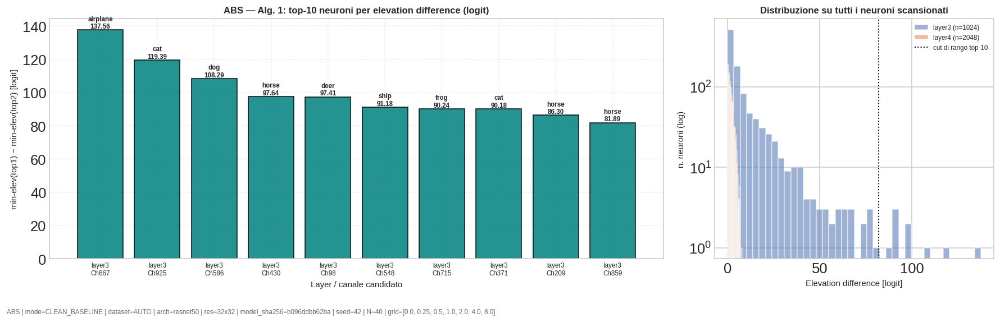


🛠️ [PHASE 2 - REVERSE ENGINEERING] Alg. 2: max f1 (candidate), min f2 (other neurons), mask bound
   max_mask_size = 6.0% of pixels | epochs=120 | lr=0.08 | f2=signed
   Images for inversion: 12 | REASR hold-out (disjoint): 28
   ✓ [layer3 Ch 0667 -> airplane          ] mask  5.19% | REASR  12.0% (n=25, base  0.0%) | Δact +4.33
   ✓ [layer3 Ch 0925 -> cat               ] mask  6.00% (rescaled) | REASR  58.3% (n=24, base  0.0%) | Δact +6.05
   ✓ [layer3 Ch 0586 -> dog               ] mask  5.60% | REASR   8.0% (n=25, base  0.0%) | Δact +2.24
   ✓ [layer3 Ch 0430 -> horse             ] mask  4.70% | REASR  16.0% (n=25, base  4.0%) | Δact +2.56
   ✓ [layer3 Ch 0098 -> deer              ] mask  5.50% | REASR  52.0% (n=25, base  4.0%) | Δact +3.43
   ✓ [layer3 Ch 0548 -> ship              ] mask  5.88% | REASR  60.0% (n=25, base  0.0%) | Δact +3.88
   ✓ [layer3 Ch 0715 -> frog              ] mask  5.07% | REASR  63.0% (n=27, base  0.0%) | Δact +2.53
   ✓ [layer3 Ch 0371 -> cat             

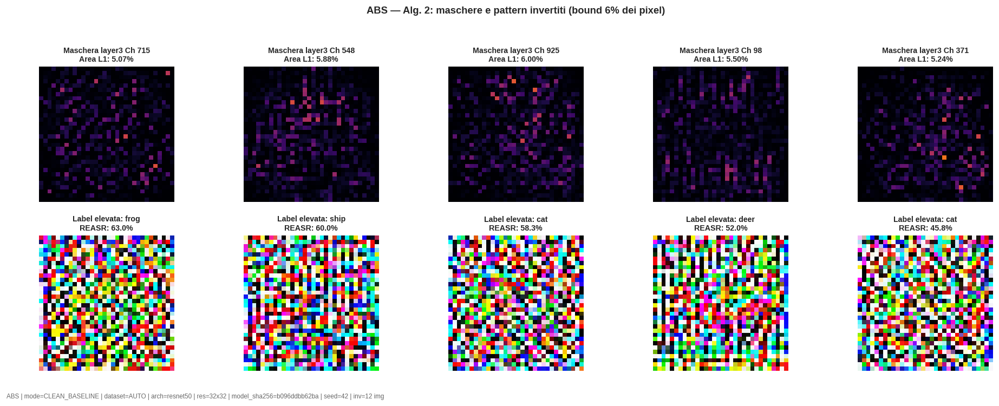

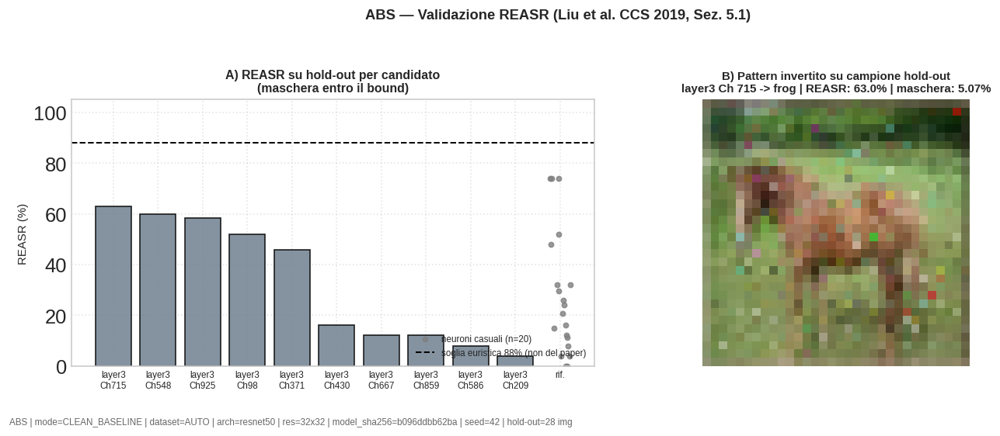


🎯 [ABS SUMMARY — indicators for manual inspection (Liu et al. CCS 2019)]
   🧠 Main candidate (maximum REASR): layer3 / channel 715
   🏷️ Elevated label          : 'frog' (#6)
   📈 REASR (hold-out)         : 63.0% on 27 img (baseline without trigger 0.0%)
   📐 Inverted mask            : 5.07% of pixels (bound 6%)
   📊 Elevation difference     : +90.2412 logit
   Candidates with REASR ≥ 88% (heuristic threshold): 0
   Random neuron reference: median 22.4% | top robust z = 2.126418312273585
   A high REASR indicates a pattern ≤ bound that shifts benign inputs toward a label: it must be compared with the
   reference and inspected (strong benign features can also produce it, Sec. 5.1 and 6).

📊 [RECORDED METRICS]
   abs_top_class_name        : frog [computed]
   abs_top_layer             : layer3 [computed]
   abs_top_channel           : 715 [computed]
   abs_max_elevation_diff    : 137.557373046875 [computed]
   abs_max_reasr             : 62.96296296296296 [computed]
   abs_top_mask_pct

In [51]:
if should_run_section('ABS'):
    clean_memory() if "clean_memory" in globals() else None
    # ===============================================================================
    # 🧠 [ABS] ARTIFICIAL BRAIN STIMULATION
    # Y. Liu, W.-C. Lee, G. Tao, S. Ma, Y. Aafer, X. Zhang, "ABS: Scanning Neural Networks for
    # Back-doors by Artificial Brain Stimulation", ACM CCS 2019, doi:10.1145/3319535.3363216
    #   - Sec. 4.1: stimulation of single internal neurons (NSF) approximated by sampling
    #   - Sec. 4.2 / Alg. 1: minimum elevation on the images of other labels, difference top1 - top2
    #   - Sec. 4.3 / Alg. 2: neuron-guided reverse engineering (f1, f2, bound on the mask)
    #   - Sec. 5.1: top-10 candidates, 30% of the images to invert, REASR on the remaining ones
    # Output: indicators for manual inspection (neuron/layer/label), no binary verdict.
    # The model is never modified: only temporary hooks removed in finally.
    # ===============================================================================

    import os
    import gc
    import traceback
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # ------------------------------------------------------------------------------
    # 0. DECLARED PARAMETERS (can be overridden via globals ABS_<PARAM>)
    # ------------------------------------------------------------------------------
    ABS_RUN_CONFIG = {
        # 'auto' = last two residual stages (layer3, layer4): post-ReLU outputs of the block add,
        # identical names in ResNet18 (BasicBlock) and ResNet50 (Bottleneck). Notebook choice (Sec. 4.1
        # analyzes internal neurons of any layer, including the adds of the ResNet blocks).
        "layers": globals().get("ABS_LAYERS", "auto"),
        "images_per_class": int(globals().get("ABS_IMAGES_PER_CLASS", 4)),       # paper: >= 1 per label (Sec. 3.1)
        "pool_scan_limit": globals().get("ABS_POOL_SCAN_LIMIT", None),
        # Stimulation grid: multiples of the maximum activation observed in the layer (step
        # increasing upward like the exponential sampling of Sec. 4.1; heuristic values).
        "stim_grid": tuple(float(v) for v in globals().get("ABS_STIM_GRID", (0.0, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0))),
        "stim_batch": int(globals().get("ABS_STIM_BATCH", 256)),
        "max_neurons_per_layer": globals().get("ABS_MAX_NEURONS_PER_LAYER", None),
        "top_k": int(globals().get("ABS_TOP_K", 10)),                             # paper: Sez. 5.1
        "inv_fraction": float(globals().get("ABS_INV_FRACTION", 0.30)),           # paper: Sez. 5.1
        "re_epochs": int(globals().get("ABS_RE_EPOCHS", 120)),
        "re_lr": float(globals().get("ABS_RE_LR", 0.08)),
        "re_batch": int(globals().get("ABS_RE_BATCH", 32)),
        "max_mask_frac": float(globals().get("ABS_MAX_MASK_FRAC", 0.06)),         # paper: App. C, Sez. 5.5
        "w_f1": float(globals().get("ABS_W_F1", 1.0)),                            # weights w1..w3, w_large: not
        "w_f2": float(globals().get("ABS_W_F2", 1.0)),                            # reported in the paper -> heuristic
        "w_mask": float(globals().get("ABS_W_MASK", 0.5)),
        "w_large": float(globals().get("ABS_W_LARGE", 50.0)),
        "f2_mode": str(globals().get("ABS_F2_MODE", "signed")).lower(),           # 'signed' = Alg. 2 lines 9-12
        "reasr_threshold": float(globals().get("ABS_REASR_THRESHOLD", 88.0)),     # heuristic (not from the paper)
        "near_max_margin": float(globals().get("ABS_NEAR_MAX_MARGIN", 5.0)),      # paper: Sez. 5.1 (Tab. 3)
        "n_ref_neurons": int(globals().get("ABS_N_REF_NEURONS", 20)),             # paper uses 100 (Sec. 5.1)
        "seed": int(globals().get("SEED", 42)),
    }
    _abs_P = ABS_RUN_CONFIG

    _ABS_KEYS = {  # key -> (level, unit)
        "abs_max_elevation_diff": ("model", "logit"),
        "abs_max_reasr": ("model", "%"),
        "abs_trojan_count": ("model", "count"),
        "abs_top_channel": ("channel", None),
        "abs_top_layer": ("layer", None),
        "abs_top_class_idx": ("class", None),
        "abs_top_class_name": ("class", None),
        "abs_top_elevation_diff": ("channel", "logit"),
        "abs_top_mask_pct": ("channel", "% pixel"),
        "abs_scanned_layer": ("layer", None),
        "abs_total_channels_scanned": ("model", "count"),
        "abs_n_candidates": ("model", "count"),
        "abs_ref_reasr_median": ("model", "%"),
        "abs_ref_reasr_max": ("model", "%"),
        "abs_top_reasr_ref_z": ("model", "robust z"),
    }
    _ABS_EVAL_KEYS = ("abs_eval_top_label_is_target", "abs_eval_target_in_candidates")
    _ABS_IMG_KEYS = (("abs_plot_img", "ABS_PLOT_IMG_PATH"),
                     ("abs_trigger_img", "ABS_TRIGGER_INVERSION_IMG_PATH"),
                     ("abs_validation_img", "ABS_VALIDATION_IMG_PATH"))

    # No residue from previous runs: removed keys (binary verdict / mislabeled count)
    # and paths of figures not regenerated must not reach the CSV.
    for _abs_k in list(_ABS_KEYS) + list(_ABS_EVAL_KEYS) + ["abs_suspected_backdoor", "abs_suspicious_count"] + [v for _, v in _ABS_IMG_KEYS]:
        globals().pop(_abs_k, None)
    for _abs_k in ("abs_suspected_backdoor", "abs_suspicious_count"):
        RUN_RESULTS.pop(_abs_k, None)
        METRIC_META.pop(_abs_k, None)

    def _abs_record_unavailable(status, note):
        for _k, (_lvl, _unit) in _ABS_KEYS.items():
            record_metric(_k, None, status, method="ABS", level=_lvl, unit=_unit, note=note)
        for _k in _ABS_EVAL_KEYS:
            record_metric(_k, None, status, method="ABS", level="model", requires_ground_truth=True, note=note)
        for _k, _ in _ABS_IMG_KEYS:
            record_metric(_k, None, "not_run", method="ABS", level="model", note="figure not generated")

    class _AbsStop(Exception):
        """Interrupts the forward after the observed layer (the rest of the network is not needed)."""

    def _abs_capture(net, module, x, stop=True):
        """Activation output from `module` for the input x; own hook removed in finally."""
        store = {}

        def _hk(_m, _i, out):
            store["a"] = out
            if stop:
                raise _AbsStop()

        handle = module.register_forward_hook(_hk)
        try:
            net(x)
        except _AbsStop:
            pass
        finally:
            handle.remove()
        return store.get("a")

    def _abs_capture_batched(net, module, x, bs):
        with torch.no_grad():
            return torch.cat([_abs_capture(net, module, x[s:s + bs]).detach() for s in range(0, len(x), bs)], dim=0)

    def _abs_resolve_layers(net, spec):
        mods = dict(net.named_modules())
        if spec is None or (isinstance(spec, str) and spec.lower() == "auto"):
            stages = [n for n in ("layer1", "layer2", "layer3", "layer4") if n in mods]
            names = stages[-2:] if stages else [n for n, m in net.named_modules() if isinstance(m, nn.Conv2d)][-2:]
        else:
            names = [spec] if isinstance(spec, str) else [str(n) for n in spec]
        return [(n, mods[n]) for n in names if n in mods], [n for n in names if n not in mods]

    def _abs_build_tail(net, layer_name):
        """Submodel from the layer to the output for torchvision ResNet (stage 'layerK' or block 'layerK.i')."""
        stages = ("layer1", "layer2", "layer3", "layer4")
        if not all(hasattr(net, a) for a in stages + ("avgpool", "fc")):
            return None
        parts = layer_name.split(".")
        if parts[0] not in stages or len(parts) > 2:
            return None
        mods = []
        if len(parts) == 2:
            stage = getattr(net, parts[0])
            if not (isinstance(stage, nn.Sequential) and parts[1].isdigit() and int(parts[1]) < len(stage)):
                return None
            mods.extend(list(stage)[int(parts[1]) + 1:])
        mods.extend(getattr(net, s) for s in stages[stages.index(parts[0]) + 1:])

        def _tail(a):
            for m in mods:
                a = m(a)
            return net.fc(torch.flatten(net.avgpool(a), 1))
        return _tail

    def _abs_stimulate_layer(net, layer_name, module, x_norm, y, base_logits, channels, P):
        """
        Sec. 4.1 + Alg. 1. Neuron = channel: the whole map of the channel is set to the value x,
        the other activations of the layer remain the observed ones. Elevation per image and label =
        max_x NSF(x) - original logit (Alg. 1 line 11); label elevation = minimum over the images
        of other labels (lines 8-13); score = top1 - top2 (lines 15-16).
        """
        dev = x_norm.device
        N, K = base_logits.shape
        with torch.no_grad():
            acts = _abs_capture_batched(net, module, x_norm, max(1, P["stim_batch"]))
            a_ref = float(acts.max().item())
            if not np.isfinite(a_ref) or a_ref <= 0.0:
                return None, {"layer": layer_name, "a_ref": a_ref, "mode": "n/a", "status": "degenerate"}
            grid = [m * a_ref for m in P["stim_grid"]]
            tail, mode = _abs_build_tail(net, layer_name), "hook"
            if tail is not None:
                try:
                    t_out = tail(acts)
                    tol = 1e-3 * max(1.0, float(base_logits.abs().max()))
                    if t_out.shape == base_logits.shape and torch.allclose(t_out, base_logits, rtol=1e-3, atol=tol):
                        mode = "tail"
                except Exception:
                    mode = "hook"
            elev = torch.full((len(channels), N, K), float("-inf"), device=dev)
            pairs = [(ci, c, x) for ci, c in enumerate(channels) for x in grid]
            g_max = max(1, P["stim_batch"] // N)
            for start in range(0, len(pairs), g_max):
                grp = pairs[start:start + g_max]
                g = len(grp)
                if mode == "tail":
                    a_rep = acts.unsqueeze(0).repeat(g, *([1] * acts.dim()))
                    for j, (_, c, x) in enumerate(grp):
                        a_rep[j, :, c] = x
                    lg = tail(a_rep.reshape(g * N, *acts.shape[1:]))
                else:
                    def _set_hook(_m, _i, out, _grp=grp, _g=g):
                        o2 = out.clone()
                        v = o2.view(_g, N, *out.shape[1:])
                        for j, (_, c, x) in enumerate(_grp):
                            v[j, :, c] = x
                        return o2
                    h_set = module.register_forward_hook(_set_hook)
                    try:
                        lg = net(x_norm.repeat(g, *([1] * (x_norm.dim() - 1))))
                    finally:
                        h_set.remove()
                lg = lg.view(g, N, K) - base_logits.unsqueeze(0)
                for j, (ci, _, _) in enumerate(grp):
                    elev[ci] = torch.maximum(elev[ci], lg[j])

            own = y.view(1, N, 1) == torch.arange(K, device=dev).view(1, 1, K)
            lift = elev.masked_fill(own, float("inf")).min(dim=1).values
            lift = torch.where(torch.isfinite(lift), lift, torch.full_like(lift, float("nan")))
            srt = torch.nan_to_num(lift, nan=float("-inf")).sort(dim=1, descending=True)
            top1_v, top2_v, top1_k = srt.values[:, 0], srt.values[:, 1], srt.indices[:, 0]
            diff = top1_v - top2_v
            diff = torch.where(torch.isfinite(diff), diff, torch.full_like(diff, float("nan")))
            # Coherence (Sec. 4.2): share of images of other labels in which the elevated label is the most elevated
            arg = elev.argmax(dim=2)
            valid = y.view(1, N) != top1_k.view(-1, 1)
            n_valid = valid.sum(dim=1).float()
            cons = ((arg == top1_k.view(-1, 1)) & valid).sum(dim=1).float() / n_valid.clamp(min=1.0)
            cons = torch.where(n_valid > 0, cons, torch.full_like(cons, float("nan")))
        rows = pd.DataFrame({
            "Layer": layer_name,
            "Channel": np.asarray(channels, dtype=int),
            "Top_Class_Idx": top1_k.cpu().numpy().astype(int),
            "Top1_Min_Elevation": torch.where(torch.isfinite(top1_v), top1_v, torch.full_like(top1_v, float("nan"))).cpu().numpy(),
            "Top2_Min_Elevation": torch.where(torch.isfinite(top2_v), top2_v, torch.full_like(top2_v, float("nan"))).cpu().numpy(),
            "Elevation_Diff": diff.cpu().numpy(),
            "Label_Consistency": cons.cpu().numpy(),
        })
        return rows, {"layer": layer_name, "a_ref": a_ref, "mode": mode, "status": "computed",
                      "n_channels_total": int(acts.shape[1]), "n_channels_scanned": len(channels)}

    def _abs_reverse_engineer(net, module, ch, x_inv, base_acts, mean_t, std_t, a_ref, P, gen):
        """
        Alg. 2 (pixel space): cost = w_f2*f2 - w_f1*f1 + w_mask*|m| (+ w_large*|m| beyond the bound).
        No term on the output label (the paper does not provide one). f1, f2 normalized by
        the maximum activation of the layer (a_ref) and |m| as a fraction of pixels: only the scale of the weights changes.
        """
        dev = x_inv.device
        n_inv, _, H, W = x_inv.shape
        bs = max(1, P["re_batch"])
        # Init (Alg. 2 line 6): random mask, trigger = starting image (here the mean of the set)
        m_raw = (-3.0 + 0.5 * torch.randn((1, 1, H, W), generator=gen)).to(dev).requires_grad_(True)
        p_raw = torch.logit(x_inv.mean(dim=0, keepdim=True).clamp(1e-3, 1 - 1e-3)).detach().clone().requires_grad_(True)
        opt = torch.optim.Adam([m_raw, p_raw], lr=P["re_lr"])
        for _ep in range(P["re_epochs"]):
            opt.zero_grad(set_to_none=True)
            for s in range(0, n_inv, bs):
                xb = x_inv[s:s + bs]
                m, p = torch.sigmoid(m_raw), torch.sigmoid(p_raw)
                a = _abs_capture(net, module, ((xb * (1.0 - m) + p * m) - mean_t) / std_t)
                d = a - base_acts[s:s + bs]
                d_o = d.abs() if P["f2_mode"] == "abs" else d
                n_oth = max(1, d.numel() - d[:, ch].numel())
                f2 = (d_o.sum() - d_o[:, ch].sum()) / n_oth / a_ref
                f1 = a[:, ch].mean() / a_ref
                mask_frac = m.mean()
                cost = P["w_f2"] * f2 - P["w_f1"] * f1 + P["w_mask"] * mask_frac
                if float(mask_frac.detach()) > P["max_mask_frac"]:
                    cost = cost + P["w_large"] * mask_frac                       # Alg. 2 lines 16-17
                (cost * (xb.shape[0] / n_inv)).backward()
            opt.step()
        with torch.no_grad():
            m, p = torch.sigmoid(m_raw), torch.sigmoid(p_raw)
            frac_raw = float(m.mean())
            projected = frac_raw > P["max_mask_frac"]
            if projected:
                # The bound is binding also in evaluation: rescaling of the mask to the L1 budget
                m = m * (P["max_mask_frac"] / frac_raw)
            v_a = torch.cat([_abs_capture(net, module, ((x_inv[s:s + bs] * (1.0 - m) + p * m) - mean_t) / std_t)[:, ch].reshape(-1)
                             for s in range(0, n_inv, bs)]).mean()
            v_b = base_acts[:, ch].mean()
            act_inc = float((v_a - v_b) / v_b) if float(v_b) > 0 else float("nan")   # Tab. 3, col. 4
        return {"mask": m.detach().cpu(), "pattern": p.detach().cpu(), "mask_pct_raw": 100.0 * frac_raw,
                "mask_pct": 100.0 * float(m.mean()), "mask_projected": bool(projected), "act_increase": act_inc}

    def _abs_predict(net, x_raw, mean_t, std_t, bs, m=None, p=None):
        out = []
        with torch.no_grad():
            for s in range(0, len(x_raw), bs):
                xb = x_raw[s:s + bs]
                if m is not None:
                    xb = xb * (1.0 - m) + p * m
                out.append(net((xb - mean_t) / std_t).argmax(dim=1).cpu())
        return torch.cat(out).numpy() if out else np.zeros(0, dtype=int)

    def _abs_reasr(pred_stamped, pred_clean, y_val, label):
        """REASR (Sec. 5.1): % detected as the label among hold-out benign inputs (true label != label)."""
        sel = y_val != label
        n = int(sel.sum())
        if n == 0:
            return float("nan"), 0, float("nan")
        return float(100.0 * np.mean(pred_stamped[sel] == label)), n, float(100.0 * np.mean(pred_clean[sel] == label))

    # ------------------------------------------------------------------------------
    # 1. MODEL, CLEAN DATA AND EVALUATION CONTEXT
    # ------------------------------------------------------------------------------
    _abs_net = get_audit_model(required=False)
    _abs_probe_x = globals().get("ABS_PROBE_IMAGES")
    _abs_probe_y = globals().get("ABS_PROBE_LABELS")
    _abs_no_dataset = str(globals().get("EXECUTION_MODE", "")).upper() == "MODEL_ONLY"

    if _abs_net is None:
        print("⚠️ [ABS] No model available. Section skipped.")
        _abs_record_unavailable("not_applicable", "no model available")
    else:
        _abs_dev = next(_abs_net.parameters()).device
        _abs_ctx = get_model_eval_context(_abs_net, device=_abs_dev)
        _abs_mean_np = np.asarray(_abs_ctx["mean"], dtype=np.float32)
        _abs_std_np = np.asarray(_abs_ctx["std"], dtype=np.float32)
        _abs_strat = _abs_ctx.get("strategy", "pipeline" if _abs_ctx.get("is_pipeline") else "scratch")
        _abs_out = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
        os.makedirs(_abs_out, exist_ok=True)

        # Source of the benign images: user-declared probes or clean test set.
        # In MODEL_ONLY there is no dataset (any in-memory loaders are residues of other runs).
        _abs_source, _abs_loader = None, None
        if _abs_probe_x is not None and _abs_probe_y is not None:
            _abs_source = "declared probes (ABS_PROBE_IMAGES/ABS_PROBE_LABELS)"
        elif not _abs_no_dataset:
            _abs_loader = globals().get("test_loader") or globals().get("clean_test_loader")
            if _abs_loader is None and globals().get("clean_test_dataset") is not None:
                _abs_loader = DataLoader(clean_test_dataset, batch_size=128, shuffle=False, num_workers=0)
            if _abs_loader is not None:
                _abs_source = "clean test set"

        if _abs_source is None:
            _abs_na_note = ("ABS requires labeled benign inputs (>= 1 per label, Sec. 3.1): Alg. 1 uses the labels and the REASR "
                            "is measured on benign inputs. The variant without inputs (Sec. 5.4, model inversion) is exploratory "
                            "for the authors and is not implemented; random probes do not have valid labels. Optionally provide "
                            "ABS_PROBE_IMAGES/ABS_PROBE_LABELS.")
            print(f"ℹ️ [ABS] No clean data available ({globals().get('EXECUTION_MODE')}): status not_applicable.")
            _abs_record_unavailable("not_applicable", _abs_na_note)
        else:
            try:
                with preserve_model_state(_abs_net):
                    _abs_net.eval()
                    for _abs_par in _abs_net.parameters():
                        _abs_par.requires_grad_(False)

                    # --- Collection of the balanced benign pool (up to N per label) ---
                    if _abs_loader is None:
                        _abs_x_all = torch.as_tensor(_abs_probe_x).float()
                        _abs_y_all = torch.as_tensor(_abs_probe_y).long().view(-1)
                        with torch.no_grad():
                            _abs_K = int(_abs_net(((_abs_x_all[:1].to(_abs_dev)) - torch.tensor(_abs_mean_np[:_abs_x_all.shape[1]], device=_abs_dev).view(1, -1, 1, 1))
                                                  / torch.tensor(_abs_std_np[:_abs_x_all.shape[1]], device=_abs_dev).view(1, -1, 1, 1)).shape[1])
                        _abs_keep = (_abs_y_all >= 0) & (_abs_y_all < _abs_K)
                        _abs_pool_x, _abs_pool_y = _abs_x_all[_abs_keep], _abs_y_all[_abs_keep].numpy()
                        _abs_input_normalized = False  # the declared probes are in [0, 1]
                    else:
                        _abs_imgs, _abs_lbls, _abs_counts, _abs_K, _abs_seen = [], [], None, None, 0
                        _abs_limit = _abs_P["pool_scan_limit"]
                        for _abs_batch in _abs_loader:
                            _abs_xb, _abs_yb = _abs_batch[0], _abs_batch[1]
                            if _abs_K is None:
                                with torch.no_grad():
                                    _abs_K = int(_abs_net(_abs_xb[:1].to(_abs_dev).float()).shape[1])
                                _abs_counts = np.zeros(_abs_K, dtype=int)
                            for _abs_xi, _abs_yi in zip(_abs_xb, _abs_yb):
                                _abs_seen += 1
                                _abs_l = int(_abs_yi)
                                if 0 <= _abs_l < _abs_K and _abs_counts[_abs_l] < _abs_P["images_per_class"]:
                                    _abs_imgs.append(_abs_xi.unsqueeze(0).float())
                                    _abs_lbls.append(_abs_l)
                                    _abs_counts[_abs_l] += 1
                            if _abs_counts.min() >= _abs_P["images_per_class"] or (_abs_limit and _abs_seen >= int(_abs_limit)):
                                break
                        _abs_pool_x = torch.cat(_abs_imgs, dim=0) if _abs_imgs else torch.zeros(0)
                        _abs_pool_y = np.asarray(_abs_lbls, dtype=int)
                        # The notebook loaders apply Normalize: we go back to pixel space [0, 1]
                        # (heuristic on the range of the whole pool, documented in the report).
                        _abs_input_normalized = bool(len(_abs_pool_x) and (_abs_pool_x.min() < -1e-5 or _abs_pool_x.max() > 1.0 + 1e-5))

                    _abs_n_pool = int(len(_abs_pool_y))
                    _abs_n_labels_present = int(len(np.unique(_abs_pool_y))) if _abs_n_pool else 0
                    if _abs_K is not None and _abs_K < 2:
                        raise ValueError(f"__ABS_NA__ the elevation difference requires at least 2 outputs (K={_abs_K})")
                    if _abs_n_pool < 3 or _abs_n_labels_present < 2:
                        raise ValueError(f"__ABS_INSUFFICIENT__ benign pool too small (n={_abs_n_pool}, distinct labels={_abs_n_labels_present})")

                    _abs_c_in = _abs_pool_x.shape[1]
                    _abs_mean_t = torch.tensor(_abs_mean_np[:_abs_c_in], device=_abs_dev).view(1, _abs_c_in, 1, 1)
                    _abs_std_t = torch.tensor(_abs_std_np[:_abs_c_in], device=_abs_dev).view(1, _abs_c_in, 1, 1)
                    _abs_raw = _abs_pool_x.to(_abs_dev)
                    if _abs_input_normalized:
                        _abs_raw = _abs_raw * _abs_std_t + _abs_mean_t
                    _abs_raw = _abs_raw.clamp(0.0, 1.0)
                    _abs_norm = (_abs_raw - _abs_mean_t) / _abs_std_t
                    _abs_y_t = torch.as_tensor(_abs_pool_y, device=_abs_dev).long()
                    _abs_names = list(globals().get("CLASS_NAMES", globals().get("classes", [])) or [])
                    if len(_abs_names) != _abs_K:
                        _abs_names = [f"Class_{i}" for i in range(_abs_K)]
                    _abs_missing_labels = [i for i in range(_abs_K) if i not in set(_abs_pool_y.tolist())]

                    with torch.no_grad():
                        _abs_base_logits = torch.cat([_abs_net(_abs_norm[s:s + _abs_P["stim_batch"]])
                                                      for s in range(0, _abs_n_pool, max(1, _abs_P["stim_batch"]))], dim=0)

                    _abs_layers, _abs_layers_missing = _abs_resolve_layers(_abs_net, _abs_P["layers"])
                    if not _abs_layers:
                        raise ValueError(f"__ABS_NA__ no valid layer among {_abs_P['layers']} (missing: {_abs_layers_missing})")

                    print("\n" + "=" * 95)
                    print("🧠 [ABS FORENSIC SUITE] ARTIFICIAL BRAIN STIMULATION (Liu et al., CCS 2019)")
                    print(f"📦 Model: {_abs_net.__class__.__name__} | Input: {list(_abs_raw.shape[1:])} | Classes (output): {_abs_K} | Strategy: {_abs_strat}")
                    print(f"   Benign images: {_abs_n_pool} from {_abs_source} ({_abs_n_labels_present} labels present"
                          + (f", missing: {_abs_missing_labels[:10]}{'...' if len(_abs_missing_labels) > 10 else ''}" if _abs_missing_labels else "") + ")")
                    print(f"   Scanned layers: {[n for n, _ in _abs_layers]}" + (f" | not found: {_abs_layers_missing}" if _abs_layers_missing else ""))
                    if int(_abs_raw.shape[-1]) != int(_abs_ctx.get("target_res", _abs_raw.shape[-1])):
                        print(f"   ⚠️ Pool resolution ({_abs_raw.shape[-1]}) different from the one expected by the context ({_abs_ctx.get('target_res')}).")
                    print("=" * 95)

                    # ----------------------------------------------------------------------
                    # PHASE 1: NEURON STIMULATION (SEC. 4.1) AND ALGORITHM 1 (SEC. 4.2)
                    # ----------------------------------------------------------------------
                    print(f"\n{'=' * 95}")
                    print("🔬 [PHASE 1 - NEURON STIMULATION ANALYSIS] Sampled NSF and Algorithm 1 (logit space)")
                    print(f"   Grid (× max activation of the layer): {list(_abs_P['stim_grid'])}")
                    print(f"{'=' * 95}")
                    _abs_rng = np.random.default_rng(_abs_P["seed"])
                    _abs_layer_info, _abs_frames = [], []
                    for _abs_lname, _abs_mod in _abs_layers:
                        _abs_C = int(_abs_capture_batched(_abs_net, _abs_mod, _abs_norm[:1], 1).shape[1])
                        _abs_chs = np.arange(_abs_C)
                        _abs_cap = _abs_P["max_neurons_per_layer"]
                        if _abs_cap is not None and int(_abs_cap) < _abs_C:
                            _abs_chs = np.sort(_abs_rng.choice(_abs_C, size=int(_abs_cap), replace=False))
                        print(f"⏳ {_abs_lname}: {len(_abs_chs)}/{_abs_C} channels × {len(_abs_P['stim_grid'])} stimuli × {_abs_n_pool} images")
                        _abs_rows, _abs_info = _abs_stimulate_layer(_abs_net, _abs_lname, _abs_mod, _abs_norm, _abs_y_t,
                                                                    _abs_base_logits, [int(c) for c in _abs_chs], _abs_P)
                        _abs_layer_info.append(_abs_info)
                        if _abs_rows is None:
                            print(f"   ⚠️ {_abs_lname}: non-positive maximum activation ({_abs_info['a_ref']}): degenerate layer, excluded.")
                            continue
                        _abs_frames.append(_abs_rows)
                        _abs_ed = _abs_rows['Elevation_Diff'].values
                        _abs_lmax = float(np.nanmax(_abs_ed)) if np.isfinite(_abs_ed).any() else float('nan')
                        print(f"   ✓ mode={_abs_info['mode']} | a_ref={_abs_info['a_ref']:.3f} | max Δelev={_abs_lmax:+.4f}")
                    if not _abs_frames:
                        raise ValueError("__ABS_DEGENERATE__ no layer with usable activations")

                    abs_df_neurons = pd.concat(_abs_frames, ignore_index=True)
                    abs_df_neurons["Top_Class"] = [_abs_names[i] for i in abs_df_neurons["Top_Class_Idx"]]
                    abs_df_neurons = abs_df_neurons.sort_values(by="Elevation_Diff", ascending=False, na_position="last").reset_index(drop=True)
                    abs_df_neurons["Rank"] = np.arange(1, len(abs_df_neurons) + 1)
                    _abs_A_ref = {d["layer"]: d["a_ref"] for d in _abs_layer_info}
                    _abs_k = min(_abs_P["top_k"], int(np.isfinite(abs_df_neurons["Elevation_Diff"].values).sum()))
                    if _abs_k < 1:
                        raise ValueError("__ABS_DEGENERATE__ elevation difference not finite for all scanned neurons")

                    print("\n" + "=" * 95)
                    print(f"📊 [ABS REPORT - ALGORITHM 1] TOP {_abs_k} NEURONS BY ELEVATION DIFFERENCE (LOGIT)")
                    print("=" * 95)
                    print(f"{'Rank':<5} | {'Layer':<10} | {'Channel':<7} | {'Elevated Label':<22} | {'Top1 Elev':<10} | {'Top2 Elev':<10} | {'Δ Elevation':<12} | {'Consistency'}")
                    print("-" * 95)
                    for _, _r in abs_df_neurons.head(_abs_k).iterrows():
                        print(f"#{int(_r['Rank']):<4} | {str(_r['Layer']):<10} | Ch {int(_r['Channel']):<4} | {str(_r['Top_Class'])[:22]:<22} | "
                              f"{_r['Top1_Min_Elevation']:+.3f}    | {_r['Top2_Min_Elevation']:+.3f}    | {_r['Elevation_Diff']:+.4f}      | {_r['Label_Consistency']:.2f}")
                    print("=" * 95)

                    # Phase 1 plot: top-k ranking + full distribution per layer (ranking context)
                    _abs_fig, (_abs_ax, _abs_axh) = plt.subplots(1, 2, figsize=(15, 4.8), dpi=120, gridspec_kw={"width_ratios": [2.2, 1]})
                    _abs_top = abs_df_neurons.head(_abs_k)
                    _bars = _abs_ax.bar(range(len(_abs_top)), _abs_top['Elevation_Diff'], color='teal', edgecolor='black', alpha=0.85)
                    for _b, (_, _rb) in zip(_bars, _abs_top.iterrows()):
                        _hv = _b.get_height()
                        _abs_ax.text(_b.get_x() + _b.get_width() / 2., max(_hv, 0.0), f"{str(_rb['Top_Class'])[:10]}\n{_hv:.2f}",
                                     ha='center', va='bottom', fontsize=7, fontweight='bold')
                    _abs_ax.set_xticks(range(len(_abs_top)))
                    _abs_ax.set_xticklabels([f"{l}\nCh{int(c)}" for l, c in zip(_abs_top['Layer'], _abs_top['Channel'])], fontsize=7)
                    _abs_ax.set_title(f"ABS — Alg. 1: top-{_abs_k} neurons by elevation difference (logit)", fontsize=10, fontweight='bold')
                    _abs_ax.set_xlabel('Candidate layer / channel', fontsize=9)
                    _abs_ax.set_ylabel('min-elev(top1) − min-elev(top2) [logit]', fontsize=9)
                    _abs_ax.grid(True, linestyle=':', alpha=0.5)
                    for _abs_lname in abs_df_neurons["Layer"].unique():
                        _v = abs_df_neurons.loc[abs_df_neurons["Layer"] == _abs_lname, "Elevation_Diff"].values
                        _v = _v[np.isfinite(_v)]
                        if len(_v):
                            _abs_axh.hist(_v, bins=40, alpha=0.55, label=f"{_abs_lname} (n={len(_v)})", log=True)
                    if _abs_k > 0:
                        _abs_axh.axvline(float(_abs_top['Elevation_Diff'].min()), color='black', linestyle=':', linewidth=1.2, label=f"top-{_abs_k} rank cut")
                    _abs_axh.set_title("Distribution over all scanned neurons", fontsize=10, fontweight='bold')
                    _abs_axh.set_xlabel('Elevation difference [logit]', fontsize=9)
                    _abs_axh.set_ylabel('no. of neurons (log)', fontsize=9)
                    _abs_axh.legend(fontsize=7)
                    plt.tight_layout(rect=(0, 0.04, 1, 1))
                    _abs_fig.text(0.01, 0.005, provenance_caption("ABS", extra=f"N={_abs_n_pool} | grid={list(_abs_P['stim_grid'])}"), fontsize=7, alpha=0.7)
                    _abs_plot_path = os.path.join(_abs_out, f'abs_brain_stimulation_{_abs_strat}.png')
                    _abs_fig.savefig(_abs_plot_path, bbox_inches='tight', dpi=120)
                    register_artifact("ABS", _abs_plot_path, note="Alg. 1: ranking elevation difference")
                    globals()['ABS_PLOT_IMG_PATH'] = _abs_plot_path
                    plt.show()
                    plt.close(_abs_fig)

                    # ----------------------------------------------------------------------
                    # PHASE 2: NEURON-GUIDED REVERSE ENGINEERING (ALG. 2, SEC. 4.3)
                    # ----------------------------------------------------------------------
                    print(f"\n{'=' * 95}")
                    print("🛠️ [PHASE 2 - REVERSE ENGINEERING] Alg. 2: max f1 (candidate), min f2 (other neurons), mask bound")
                    print(f"   max_mask_size = {100 * _abs_P['max_mask_frac']:.1f}% of the pixels | epochs={_abs_P['re_epochs']} | lr={_abs_P['re_lr']} | f2={_abs_P['f2_mode']}")
                    print(f"{'=' * 95}")
                    _abs_perm = _abs_rng.permutation(_abs_n_pool)
                    _abs_n_inv = int(np.ceil(_abs_P["inv_fraction"] * _abs_n_pool))
                    _abs_n_inv = min(max(1, _abs_n_inv), _abs_n_pool - 1)
                    _abs_inv_idx, _abs_val_idx = _abs_perm[:_abs_n_inv], _abs_perm[_abs_n_inv:]
                    _abs_x_inv, _abs_x_val = _abs_raw[_abs_inv_idx], _abs_raw[_abs_val_idx]
                    _abs_y_val = _abs_pool_y[_abs_val_idx]
                    print(f"   Images for the inversion: {len(_abs_inv_idx)} | REASR hold-out (disjoint): {len(_abs_val_idx)}")
                    _abs_pred_val_clean = _abs_predict(_abs_net, _abs_x_val, _abs_mean_t, _abs_std_t, _abs_P["stim_batch"])
                    _abs_mods = dict(_abs_layers)
                    _abs_base_inv = {}
                    _abs_gen = torch.Generator().manual_seed(_abs_P["seed"])

                    def _abs_run_neuron(row, role):
                        lname, ch, lab = str(row["Layer"]), int(row["Channel"]), int(row["Top_Class_Idx"])
                        if lname not in _abs_base_inv:
                            _abs_base_inv[lname] = _abs_capture_batched(_abs_net, _abs_mods[lname], (_abs_x_inv - _abs_mean_t) / _abs_std_t, max(1, _abs_P["re_batch"]))
                        with torch.enable_grad():
                            res = _abs_reverse_engineer(_abs_net, _abs_mods[lname], ch, _abs_x_inv, _abs_base_inv[lname],
                                                        _abs_mean_t, _abs_std_t, _abs_A_ref[lname], _abs_P, _abs_gen)
                        pred = _abs_predict(_abs_net, _abs_x_val, _abs_mean_t, _abs_std_t, _abs_P["stim_batch"],
                                            res["mask"].to(_abs_dev), res["pattern"].to(_abs_dev))
                        reasr, n_eval, base_rate = _abs_reasr(pred, _abs_pred_val_clean, _abs_y_val, lab)
                        res.update({"Layer": lname, "Channel": ch, "Label_Idx": lab, "Label": _abs_names[lab], "Role": role,
                                    "Elevation_Diff": float(row["Elevation_Diff"]), "Rank": int(row["Rank"]),
                                    "REASR_%": reasr, "N_Holdout": n_eval, "Holdout_Base_Rate_%": base_rate})
                        return res

                    _abs_cand_rows = abs_df_neurons.head(_abs_k)
                    _abs_inv_results = []
                    for _, _abs_row in _abs_cand_rows.iterrows():
                        _abs_res = _abs_run_neuron(_abs_row, "candidate")
                        _abs_inv_results.append(_abs_res)
                        print(f"   ✓ [{_abs_res['Layer']} Ch {_abs_res['Channel']:04d} -> {_abs_res['Label'][:18]:<18}] mask {_abs_res['mask_pct']:5.2f}%"
                              f"{' (rescaled)' if _abs_res['mask_projected'] else ''} | REASR {_abs_res['REASR_%']:5.1f}% (n={_abs_res['N_Holdout']}, "
                              f"base {_abs_res['Holdout_Base_Rate_%']:4.1f}%) | Δact {_abs_res['act_increase']:+.2f}")

                    # Reference distribution (Sec. 5.1, end-to-end detection): random neurons
                    # non-candidates, inverted with the same objective toward their own most elevated label.
                    _abs_ref_results = []
                    _abs_pool_ref = abs_df_neurons.iloc[_abs_k:]
                    _abs_pool_ref = _abs_pool_ref[np.isfinite(_abs_pool_ref["Elevation_Diff"].values)]
                    _abs_n_ref = min(_abs_P["n_ref_neurons"], len(_abs_pool_ref))
                    if _abs_n_ref > 0:
                        print(f"   … reference distribution: {_abs_n_ref} random neurons (paper: 100)")
                        for _ri in np.sort(_abs_rng.choice(len(_abs_pool_ref), size=_abs_n_ref, replace=False)):
                            _abs_ref_results.append(_abs_run_neuron(_abs_pool_ref.iloc[int(_ri)], "reference"))

                    abs_df_candidates = pd.DataFrame([{k: v for k, v in r.items() if k not in ("mask", "pattern")} for r in _abs_inv_results])
                    abs_df_reference = pd.DataFrame([{k: v for k, v in r.items() if k not in ("mask", "pattern")} for r in _abs_ref_results])
                    _abs_ref_vals = abs_df_reference["REASR_%"].values.astype(float) if len(abs_df_reference) else np.zeros(0)
                    _abs_ref_vals = _abs_ref_vals[np.isfinite(_abs_ref_vals)]
                    _, _abs_ref_info = robust_mad_z(_abs_ref_vals, min_n=3)

                    # ----------------------------------------------------------------------
                    # PHASE 3: REASR VALIDATION ON HOLD-OUT (SEC. 5.1) — SEPARATE INDICATORS
                    # ----------------------------------------------------------------------
                    _abs_order = abs_df_candidates.assign(_r=abs_df_candidates["REASR_%"].fillna(-1.0)).sort_values(
                        by=["_r", "Elevation_Diff", "mask_pct"], ascending=[False, False, True]).index.tolist()
                    _abs_inv_sorted = [_abs_inv_results[i] for i in _abs_order]
                    abs_df_candidates = abs_df_candidates.loc[_abs_order].reset_index(drop=True)
                    _abs_reasr_vals = abs_df_candidates["REASR_%"].values.astype(float)
                    _abs_any_reasr = bool(np.isfinite(_abs_reasr_vals).any())
                    _abs_max_reasr = float(np.nanmax(_abs_reasr_vals)) if _abs_any_reasr else float("nan")
                    abs_df_candidates["Near_Max_REASR"] = (_abs_max_reasr - abs_df_candidates["REASR_%"]) < _abs_P["near_max_margin"] if _abs_any_reasr else False
                    abs_df_candidates["Above_Heuristic_Threshold"] = abs_df_candidates["REASR_%"] >= _abs_P["reasr_threshold"]
                    abs_df_candidates["Ref_Exceedance"] = [
                        float((1 + np.sum(_abs_ref_vals >= r)) / (1 + len(_abs_ref_vals))) if (len(_abs_ref_vals) and np.isfinite(r)) else float("nan")
                        for r in abs_df_candidates["REASR_%"]]

                    print("\n" + "=" * 95)
                    print("✅ [PHASE 3 - REASR VALIDATION] Candidates (sorted by REASR) — indicators for manual inspection")
                    print("=" * 95)
                    print(f"{'Layer':<10} | {'Channel':<8} | {'Elevated Label':<20} | {'Δ Elevation':<12} | {'Mask %':<11} | {'REASR %':<8} | {'p_ref':<6} | Note")
                    print("-" * 95)
                    for _, _r in abs_df_candidates.iterrows():
                        _notes = []
                        if bool(_r["Near_Max_REASR"]):
                            _notes.append(f"within {_abs_P['near_max_margin']:.0f} pt of the max (Sec. 5.1)")
                        if bool(_r["Above_Heuristic_Threshold"]):
                            _notes.append(f"≥ {_abs_P['reasr_threshold']:.0f}% (heuristic threshold)")
                        print(f"{str(_r['Layer']):<10} | Ch {int(_r['Channel']):<5} | {str(_r['Label'])[:20]:<20} | {_r['Elevation_Diff']:+.4f}      | "
                              f"{_r['mask_pct']:>6.2f}%     | {_r['REASR_%']:>6.1f}% | {_r['Ref_Exceedance']:.2f}   | {'; '.join(_notes)}")
                    print("=" * 95)
                    if len(_abs_ref_vals):
                        print(f"   Reference ({len(_abs_ref_vals)} random neurons): REASR median {np.median(_abs_ref_vals):.1f}% | max {np.max(_abs_ref_vals):.1f}%")
                    print("   p_ref = (1 + #ref with REASR ≥ candidate) / (1 + n_ref): empirical share, not a calibrated p-value.")

                    # Visualization of inverted masks and patterns (top-5 by REASR)
                    _abs_n_plot = min(5, len(_abs_inv_sorted))
                    if _abs_n_plot > 0:
                        _fig_inv, _axs_inv = plt.subplots(2, _abs_n_plot, figsize=(max(6, _abs_n_plot * 3.2), 6.0), dpi=120, squeeze=False)
                        for _ci in range(_abs_n_plot):
                            _rp = _abs_inv_sorted[_ci]
                            _m_np = _rp['mask'].squeeze().numpy()
                            _p_np = _rp['pattern'].squeeze(0).permute(1, 2, 0).numpy()
                            _axs_inv[0, _ci].imshow(_m_np, cmap='inferno', vmin=0.0, vmax=1.0)
                            _axs_inv[0, _ci].set_title(f"Mask {_rp['Layer']} Ch {_rp['Channel']}\nL1 area: {_rp['mask_pct']:.2f}%", fontsize=8.5, fontweight='bold')
                            _axs_inv[0, _ci].axis('off')
                            if _p_np.shape[-1] == 1:
                                _axs_inv[1, _ci].imshow(_p_np[..., 0], cmap='gray', vmin=0.0, vmax=1.0)
                            else:
                                _axs_inv[1, _ci].imshow(np.clip(_p_np, 0.0, 1.0))
                            _axs_inv[1, _ci].set_title(f"Elevated label: {_rp['Label'][:12]}\nREASR: {_rp['REASR_%']:.1f}%", fontsize=8.5, fontweight='bold')
                            _axs_inv[1, _ci].axis('off')
                        plt.suptitle(f"ABS — Alg. 2: inverted masks and patterns (bound {100 * _abs_P['max_mask_frac']:.0f}% of the pixels)", fontsize=11, fontweight='bold', y=1.01)
                        plt.tight_layout(rect=(0, 0.04, 1, 1))
                        _fig_inv.text(0.01, 0.005, provenance_caption("ABS", extra=f"inv={len(_abs_inv_idx)} img"), fontsize=7, alpha=0.7)
                        _abs_inv_plot_path = os.path.join(_abs_out, f'abs_trigger_inversion_{_abs_strat}.png')
                        _fig_inv.savefig(_abs_inv_plot_path, bbox_inches='tight', dpi=120)
                        register_artifact("ABS", _abs_inv_plot_path, note="Alg. 2: inverted masks/patterns")
                        globals()['ABS_TRIGGER_INVERSION_IMG_PATH'] = _abs_inv_plot_path
                        plt.show()
                        plt.close(_fig_inv)

                    # Validation dashboard: REASR of the candidates vs reference neurons + example
                    _abs_tgt = globals().get("TARGET_LABEL") if oracle_allowed() else None
                    _abs_tgt = int(_abs_tgt) if (_abs_tgt is not None and int(_abs_tgt) >= 0) else None
                    if len(abs_df_candidates):
                        _fig_val, _axs_val = plt.subplots(1, 2, figsize=(12, 4.4), dpi=120)
                        _abs_xs = np.arange(len(abs_df_candidates))
                        _abs_hatch = ['//' if (_abs_tgt is not None and int(l) == _abs_tgt) else '' for l in abs_df_candidates['Label_Idx']]
                        _abs_bv = _axs_val[0].bar(_abs_xs, abs_df_candidates['REASR_%'].fillna(0.0), color='slategray', edgecolor='black', alpha=0.85, hatch=None)
                        for _b, _hh in zip(_abs_bv, _abs_hatch):
                            _b.set_hatch(_hh)
                        _abs_xt = [f"{l}\nCh{int(c)}" for l, c in zip(abs_df_candidates['Layer'], abs_df_candidates['Channel'])]
                        if len(_abs_ref_vals):
                            _abs_jit = np.random.default_rng(_abs_P["seed"]).uniform(-0.25, 0.25, size=len(_abs_ref_vals))
                            _axs_val[0].scatter(len(_abs_xs) + _abs_jit, _abs_ref_vals, color='gray', s=14, alpha=0.8, label=f"random neurons (n={len(_abs_ref_vals)})")
                            _abs_xt.append("rif.")
                        _axs_val[0].axhline(_abs_P["reasr_threshold"], color='black', linestyle='--', linewidth=1.2,
                                            label=f"heuristic threshold {_abs_P['reasr_threshold']:.0f}% (not from the paper)")
                        _abs_hd, _abs_lb = _axs_val[0].get_legend_handles_labels()
                        if _abs_tgt is not None and any(_abs_hatch):
                            from matplotlib.patches import Patch
                            _abs_hd.append(Patch(facecolor='white', edgecolor='black', hatch='//'))
                            _abs_lb.append("evaluation (oracle): label = target")
                        _axs_val[0].set_xticks(range(len(_abs_xt)))
                        _axs_val[0].set_xticklabels(_abs_xt, fontsize=7)
                        _axs_val[0].set_ylim(0, 105)
                        _axs_val[0].set_title("A) REASR on hold-out per candidate\n(mask within the bound)", fontsize=9.5, fontweight='bold')
                        _axs_val[0].set_ylabel("REASR (%)", fontsize=9)
                        _axs_val[0].legend(_abs_hd, _abs_lb, fontsize=7, loc='lower right')
                        _axs_val[0].grid(True, linestyle=':', alpha=0.5)

                        _best = _abs_inv_sorted[0]
                        globals()['ABS_TOP_CANDIDATE_MASK'] = _best['mask'].detach().cpu() if hasattr(_best['mask'], 'detach') else _best['mask']
                        globals()['ABS_TOP_CANDIDATE_PATTERN'] = _best['pattern'].detach().cpu() if hasattr(_best['pattern'], 'detach') else _best['pattern']
                        _demo = torch.clamp((1.0 - _best['mask'].to(_abs_dev)) * _abs_x_val[0:1] + _best['mask'].to(_abs_dev) * _best['pattern'].to(_abs_dev), 0.0, 1.0)
                        _demo_np = _demo.squeeze(0).permute(1, 2, 0).cpu().numpy()
                        if _demo_np.shape[-1] == 1:
                            _axs_val[1].imshow(_demo_np[..., 0], cmap='gray')
                        else:
                            _axs_val[1].imshow(np.clip(_demo_np, 0.0, 1.0))
                        _axs_val[1].set_title(f"B) Inverted pattern on hold-out sample\n{_best['Layer']} Ch {_best['Channel']} -> {_best['Label'][:15]} | "
                                              f"REASR: {_best['REASR_%']:.1f}% | mask: {_best['mask_pct']:.2f}%", fontsize=9, fontweight='bold')
                        _axs_val[1].axis('off')
                        plt.suptitle("ABS — REASR Validation (Liu et al. CCS 2019, Sec. 5.1)", fontsize=11, fontweight='bold', y=1.02)
                        plt.tight_layout(rect=(0, 0.04, 1, 1))
                        _fig_val.text(0.01, 0.005, provenance_caption("ABS", extra=f"hold-out={len(_abs_val_idx)} img"), fontsize=7, alpha=0.7)
                        _abs_val_plot_path = os.path.join(_abs_out, f'abs_validation_reasr_{_abs_strat}.png')
                        _fig_val.savefig(_abs_val_plot_path, bbox_inches='tight', dpi=120)
                        register_artifact("ABS", _abs_val_plot_path, note="REASR candidates vs reference")
                        globals()['ABS_VALIDATION_IMG_PATH'] = _abs_val_plot_path
                        plt.show()
                        plt.close(_fig_val)

                    # ----------------------------------------------------------------------
                    # METRIC REGISTRATION, GRANULAR ENTITIES AND GLOBALS
                    # ----------------------------------------------------------------------
                    _abs_top = abs_df_candidates.iloc[0] if len(abs_df_candidates) else None
                    _abs_top_by = "maximum REASR" if _abs_any_reasr else "elevation difference (REASR not computable)"
                    _abs_scanned = [d["layer"] for d in _abs_layer_info if d["status"] == "computed"]
                    _abs_rs_note = (f"REASR on hold-out disjoint from the inversion images ({len(_abs_val_idx)} img, elevated label excluded); "
                                    f"mask with bound max_mask_size={100 * _abs_P['max_mask_frac']:.0f}% (paper: App. C, Sec. 5.5)")
                    _abs_emax = abs_df_neurons["Elevation_Diff"].values
                    record_metric("abs_max_elevation_diff", float(np.nanmax(_abs_emax)) if np.isfinite(_abs_emax).any() else None,
                                  method="ABS", level="model", unit="logit",
                                  note=f"Alg. 1 on {len(abs_df_neurons)} neurons (channels) of {_abs_scanned}; declared stimulation grid")
                    record_metric("abs_max_reasr", _abs_max_reasr if _abs_any_reasr else None,
                                  "computed" if _abs_any_reasr else "insufficient_data", method="ABS", level="model", unit="%",
                                  note=_abs_rs_note + f"; maximum over the top-{_abs_k} candidates")
                    record_metric("abs_trojan_count", int(np.nansum(abs_df_candidates["Above_Heuristic_Threshold"].values)) if _abs_any_reasr else None,
                                  "computed" if _abs_any_reasr else "insufficient_data", method="ABS", level="model", unit="count",
                                  threshold=_abs_P["reasr_threshold"], threshold_origin="heuristic",
                                  note=("number of candidates with REASR ≥ heuristic threshold (mask within the bound). The paper does not define a REASR "
                                        "threshold: it reports raw REASR and decides by outlier with respect to random neurons (Sec. 5.1); the value 88.1% "
                                        "observed in Sec. 5.5/Tab. 6. It is not a count of confirmed trojans."))
                    _abs_st_top = "computed" if _abs_top is not None else "insufficient_data"
                    record_metric("abs_top_channel", int(_abs_top["Channel"]) if _abs_top is not None else None, _abs_st_top,
                                  method="ABS", level="channel", note=f"main candidate for {_abs_top_by}")
                    record_metric("abs_top_layer", str(_abs_top["Layer"]) if _abs_top is not None else None, _abs_st_top,
                                  method="ABS", level="layer", note="layer of the main candidate")
                    record_metric("abs_top_class_idx", int(_abs_top["Label_Idx"]) if _abs_top is not None else None, _abs_st_top,
                                  method="ABS", level="class", note="label elevated by the main candidate (Alg. 1), not an established target class")
                    record_metric("abs_top_class_name", str(_abs_top["Label"]) if _abs_top is not None else None, _abs_st_top,
                                  method="ABS", level="class", note="label elevated by the main candidate (Alg. 1)")
                    record_metric("abs_top_elevation_diff", float(_abs_top["Elevation_Diff"]) if _abs_top is not None else None, _abs_st_top,
                                  method="ABS", level="channel", unit="logit")
                    record_metric("abs_top_mask_pct", float(_abs_top["mask_pct"]) if _abs_top is not None else None, _abs_st_top,
                                  method="ABS", level="channel", unit="% pixel",
                                  note=f"mask L1 norm / pixels; bound {100 * _abs_P['max_mask_frac']:.0f}% (paper: App. C)")
                    record_metric("abs_scanned_layer", ";".join(_abs_scanned), method="ABS", level="layer",
                                  note="list of the scanned layers (separator ';'); the layer of the main candidate is in abs_top_layer")
                    record_metric("abs_total_channels_scanned", int(len(abs_df_neurons)), method="ABS", level="model", unit="count")
                    record_metric("abs_n_candidates", int(len(abs_df_candidates)), method="ABS", level="model", unit="count",
                                  note="top-k by elevation difference inverted (paper: k=10, Sec. 5.1)")
                    _abs_st_ref = "computed" if len(_abs_ref_vals) else "not_run"
                    record_metric("abs_ref_reasr_median", float(np.median(_abs_ref_vals)) if len(_abs_ref_vals) else None, _abs_st_ref,
                                  method="ABS", level="model", unit="%", note=f"{len(_abs_ref_vals)} random non-candidate neurons (paper: 100, Sec. 5.1)")
                    record_metric("abs_ref_reasr_max", float(np.max(_abs_ref_vals)) if len(_abs_ref_vals) else None, _abs_st_ref,
                                  method="ABS", level="model", unit="%")
                    if _abs_any_reasr and _abs_ref_info["status"] == "computed":
                        _abs_z = (_abs_max_reasr - _abs_ref_info["median"]) / (1.4826 * _abs_ref_info["mad"])
                        record_metric("abs_top_reasr_ref_z", float(_abs_z), method="ABS", level="model", unit="robust z",
                                      note="(REASR_top - median_ref) / (1.4826·MAD_ref): exploratory indicator; the paper does not fix the outlier rule")
                    else:
                        _abs_st_z = (_abs_st_ref if not len(_abs_ref_vals) else
                                     "insufficient_data" if not _abs_any_reasr else _abs_ref_info["status"])
                        record_metric("abs_top_reasr_ref_z", None, _abs_st_z, method="ABS", level="model", unit="robust z",
                                      note=f"reference n={_abs_ref_info['n']}, MAD={_abs_ref_info['mad']}")

                    # Evaluation (oracle): only after the detection, never used to choose neurons or thresholds
                    _abs_eval_ok = _abs_tgt is not None and _abs_top is not None
                    record_metric("abs_eval_top_label_is_target", float(int(_abs_top["Label_Idx"]) == _abs_tgt) if _abs_eval_ok else None,
                                  "computed" if _abs_eval_ok else "not_applicable", method="ABS", level="model", requires_ground_truth=True,
                                  note="1 if the label elevated by the main candidate coincides with the target class of the attack")
                    record_metric("abs_eval_target_in_candidates", int((abs_df_candidates["Label_Idx"] == _abs_tgt).sum()) if _abs_eval_ok else None,
                                  "computed" if _abs_eval_ok else "not_applicable", method="ABS", level="model", unit="count", requires_ground_truth=True,
                                  note="number of top-k candidates whose elevated label is the target class")

                    for _k, _v in _ABS_IMG_KEYS:
                        _pth = globals().get(_v)
                        if _pth and os.path.exists(_pth):
                            record_metric(_k, os.path.basename(_pth), method="ABS", level="model", note="artifact")
                        else:
                            record_metric(_k, None, "not_run", method="ABS", level="model", note="figure not generated")

                    # Entities: every scanned neuron (Alg. 1) + inversion fields for candidates/reference
                    _abs_re_map = {(r["Layer"], r["Channel"]): r for r in (_abs_inv_results + _abs_ref_results)}
                    _abs_cand_extra = abs_df_candidates.set_index(["Layer", "Channel"])
                    _abs_ent = []
                    for _, _r in abs_df_neurons.iterrows():
                        _key = (str(_r["Layer"]), int(_r["Channel"]))
                        _re = _abs_re_map.get(_key)
                        _is_c = _re is not None and _re["Role"] == "candidate"
                        _ent = {"entity_id": f"{_key[0]}:{_key[1]}", "layer": _key[0], "channel": _key[1],
                                "class_id": int(_r["Top_Class_Idx"]), "class_name": str(_r["Top_Class"]),
                                "score": float(_r["Elevation_Diff"]), "rank": int(_r["Rank"]),
                                "role": _re["Role"] if _re is not None else "scanned",
                                "top1_min_elevation": float(_r["Top1_Min_Elevation"]), "top2_min_elevation": float(_r["Top2_Min_Elevation"]),
                                "label_consistency": float(_r["Label_Consistency"]),
                                "reasr": float(_re["REASR_%"]) if _re is not None else float("nan"),
                                "reasr_n_holdout": int(_re["N_Holdout"]) if _re is not None else 0,
                                "holdout_base_rate": float(_re["Holdout_Base_Rate_%"]) if _re is not None else float("nan"),
                                "mask_pct": float(_re["mask_pct"]) if _re is not None else float("nan"),
                                "mask_pct_raw": float(_re["mask_pct_raw"]) if _re is not None else float("nan"),
                                "mask_projected": bool(_re["mask_projected"]) if _re is not None else None,
                                "act_increase": float(_re["act_increase"]) if _re is not None else float("nan"),
                                "ref_exceedance": float(_abs_cand_extra.loc[_key, "Ref_Exceedance"]) if _is_c else float("nan"),
                                "near_max_reasr": bool(_abs_cand_extra.loc[_key, "Near_Max_REASR"]) if _is_c else None,
                                "flag": bool(_abs_cand_extra.loc[_key, "Above_Heuristic_Threshold"]) if _is_c else None,
                                "requires_ground_truth": False,
                                "note": "score = elevation difference (logit); flag = REASR ≥ heuristic threshold"}
                        _abs_ent.append(_ent)
                    record_entities("ABS", "neuron", _abs_ent)
                    _abs_lrows = []
                    for _d in _abs_layer_info:
                        _ed = abs_df_neurons.loc[abs_df_neurons["Layer"] == _d["layer"], "Elevation_Diff"].values
                        _abs_lrows.append({"entity_id": _d["layer"], "layer": _d["layer"],
                                           "score": float(np.nanmax(_ed)) if np.isfinite(_ed).any() else float("nan"),
                                           "a_ref": _d["a_ref"], "stim_mode": _d["mode"], "status": _d["status"],
                                           "n_channels_scanned": _d.get("n_channels_scanned"), "requires_ground_truth": False,
                                           "note": "score = max elevation difference of the layer; stim_mode tail = verified submodel"})
                    record_entities("ABS", "layer", _abs_lrows)

                    # ----------------------------------------------------------------------
                    # SUMMARY (indicators for manual inspection, no verdict)
                    # ----------------------------------------------------------------------
                    print("\n" + "=" * 95)
                    print("🎯 [ABS SUMMARY — indicators for manual inspection (Liu et al. CCS 2019)]")
                    print("=" * 95)
                    if _abs_top is not None:
                        print(f"   🧠 Main candidate ({_abs_top_by}): {_abs_top['Layer']} / channel {int(_abs_top['Channel'])}")
                        print(f"   🏷️ Elevated label          : '{_abs_top['Label']}' (#{int(_abs_top['Label_Idx'])})")
                        print(f"   📈 REASR (hold-out)         : {_abs_top['REASR_%']:.1f}% on {int(_abs_top['N_Holdout'])} img (base without trigger {_abs_top['Holdout_Base_Rate_%']:.1f}%)")
                        print(f"   📐 Inverted mask            : {_abs_top['mask_pct']:.2f}% of the pixels (bound {100 * _abs_P['max_mask_frac']:.0f}%)")
                        print(f"   📊 Elevation difference     : {_abs_top['Elevation_Diff']:+.4f} logit")
                    print(f"   Candidates with REASR ≥ {_abs_P['reasr_threshold']:.0f}% (heuristic threshold): {RUN_RESULTS['abs_trojan_count']}")
                    if len(_abs_ref_vals):
                        print(f"   Reference random neurons: median {np.median(_abs_ref_vals):.1f}% | top robust z = {RUN_RESULTS['abs_top_reasr_ref_z']}")
                    print("   A high REASR indicates a pattern ≤ bound that shifts benign inputs toward a label: it must be compared with the")
                    print("   reference and inspected (strong benign features can also produce it, Sec. 5.1 and 6).")
                    if oracle_allowed():
                        print(f"   [evaluation (oracle)] main label = target: {RUN_RESULTS.get('abs_eval_top_label_is_target')} | "
                              f"candidates with label = target: {RUN_RESULTS.get('abs_eval_target_in_candidates')}")
                    print("=" * 95)

            except Exception as _abs_err:
                _abs_msg = str(_abs_err)
                if _abs_msg.startswith("__ABS_INSUFFICIENT__"):
                    _abs_status = "insufficient_data"
                elif _abs_msg.startswith("__ABS_NA__"):
                    _abs_status = "not_applicable"
                elif _abs_msg.startswith("__ABS_DEGENERATE__"):
                    _abs_status = "degenerate"
                else:
                    _abs_status = "failed"
                    traceback.print_exc()
                _abs_msg = _abs_msg.split("__ ", 1)[-1]
                print(f"⚠️ [ABS] Section interrupted ({_abs_status}): {_abs_msg}")
                _abs_record_unavailable(_abs_status, _abs_msg)

        check_model_integrity('ABS')

    # Globals read by the export cell (93): recorded value (NaN if not computed, status in METRIC_META)
    for _abs_k in _ABS_KEYS:
        if _abs_k in RUN_RESULTS:
            globals()[_abs_k] = RUN_RESULTS[_abs_k]

    print(f"\n📊 [REGISTERED METRICS]")
    for _abs_k in ("abs_top_class_name", "abs_top_layer", "abs_top_channel", "abs_max_elevation_diff", "abs_max_reasr", "abs_top_mask_pct", "abs_trojan_count"):
        print(f"   {_abs_k:<26}: {RUN_RESULTS.get(_abs_k)} [{METRIC_META.get(_abs_k, {}).get('status')}]")

    clean_memory(verbose=False) if "clean_memory" in globals() else None


---
## 👁️ 28. BYE — Attention Entropy

🛡️ [BYE FORENSIC SUITE] BACKDOOR DETECTION VIA ENTROPY & SPATIAL CONCENTRATION
📌 [AUDIT MODE]: BLIND AUDIT (Unlabeled Inspection on the Whole Dataset)
📌 [MODEL CHECK]: Clean F1: N/A | ASR: N/A | TOI (F1*ASR): 0.0
📦 [BYE] Audit dataset loaded: 10000 total samples analyzed (Resolution: 32x32).
⏳ Extracting spatial responses and computing entropy...
✅ Extraction completed!

=== BSI (Bimodal Separation Index) PER LAYER ===
  layer1     -> BSI: 0.8318
  layer2     -> BSI: 0.6160
  layer3     -> BSI: 0.9563
  layer4     -> BSI: 0.7933

Selected sensitive layers: ['layer3']

=== BYE AUDIT RESULTS ===
  Total samples scanned: 10000
  Samples identified as anomalous/suspect: 1937 (19.37%)
  Top samples selected for visual gallery: 48


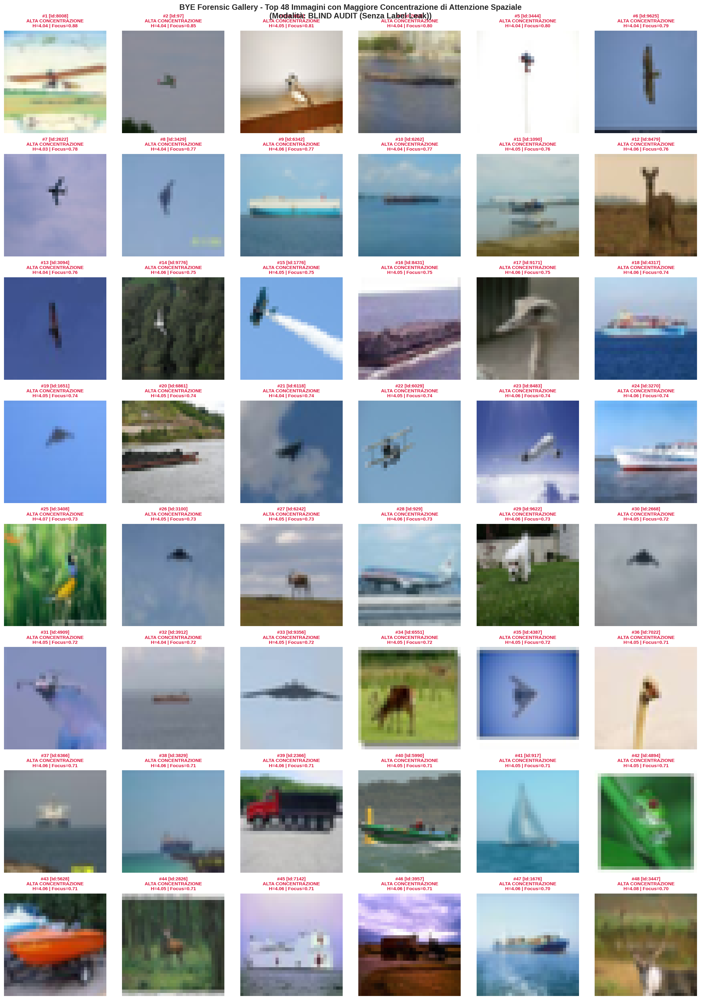

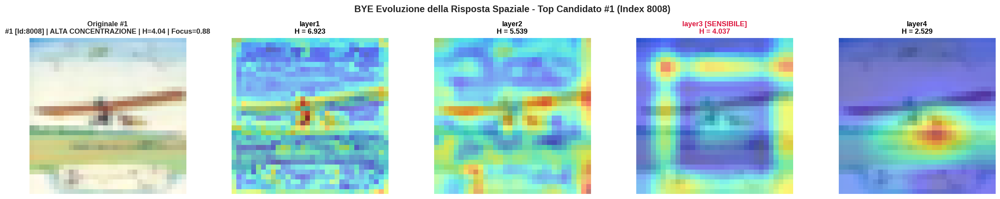

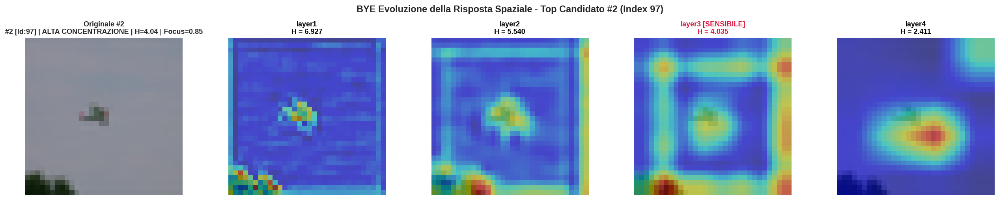

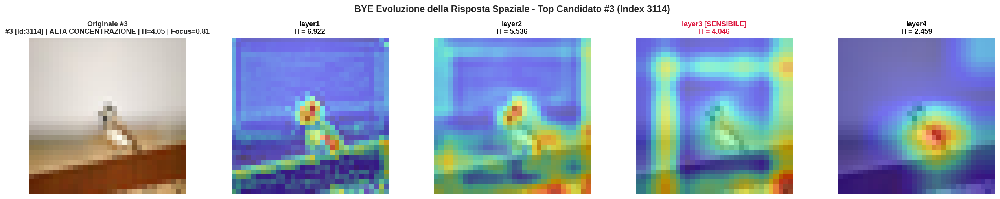

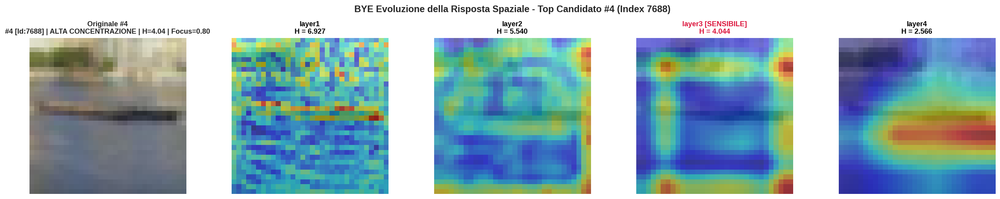

...

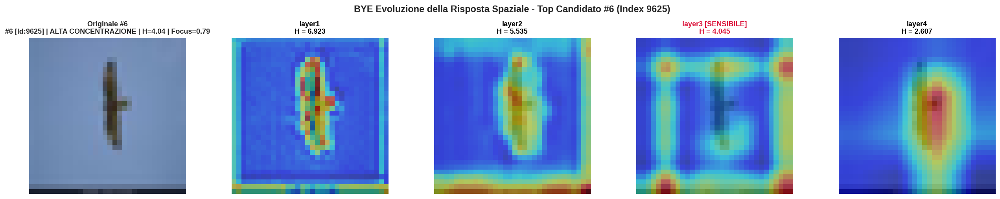

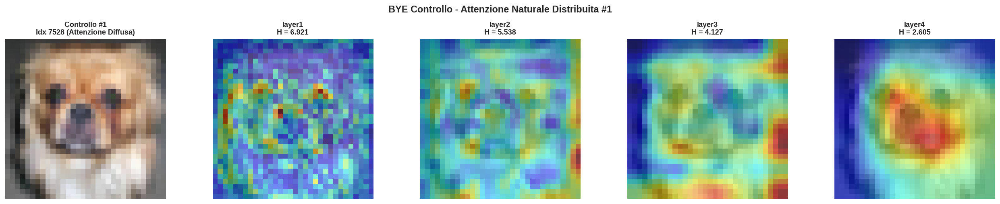

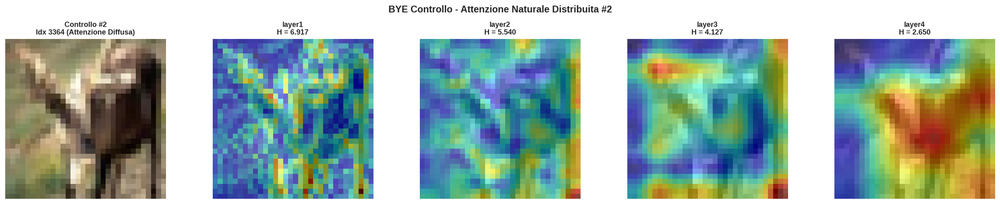

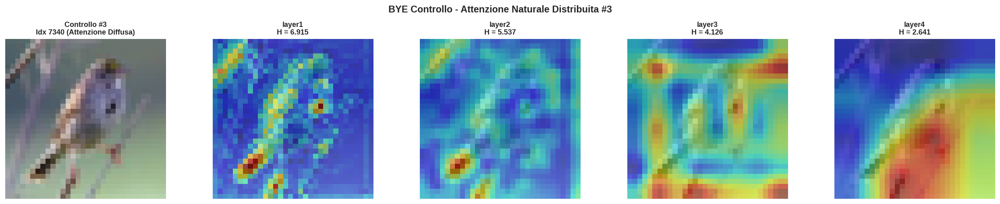

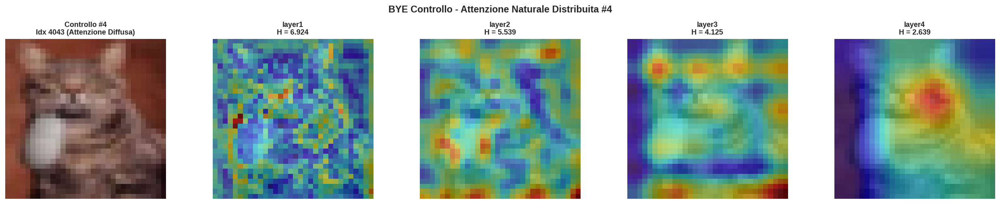


=== TOP 20 SAMPLES WITH HIGHEST SPATIAL CONCENTRATION ===


,sample_index,aggregated_entropy,peak_ratio,spatial_focus_score,BYE_suspicious
0,8008,4.036684,2.408650,0.878263,True
1,97,4.035236,2.312439,0.852787,True
2,3114,4.045787,2.383690,0.812093,True
3,7688,4.044048,2.331797,0.804371,True
4,3444,4.036192,2.173636,0.796899,True
5,9625,4.044833,2.299645,0.787885,True
6,2622,4.031374,2.054989,0.784538,True
7,3429,4.040816,2.182623,0.771072,True
8,6342,4.058177,2.483251,0.770021,True
9,6262,4.042727,2.207905,0.768151,True


📸 [BYE] Suspect image gallery saved to: /kaggle/working/bye_suspicious_gallery_scratch.png
📸 [BYE] Spatial response map saved to: /kaggle/working/bye_spatial_response_scratch.png
📸 [BYE] Diffuse attention check saved to: /kaggle/working/bye_clean_control_scratch.png
🎯 [BYE] EXPORTED METRICS (candidates for manual inspection)
   Total Samples: 10000 | Suspects Detected: 1937 (19.4%)
   Top Sensitive Layer: layer3 | Max BSI: 0.9563
   Precision/Recall: not applicable (no known trigger images)
   Bimodality flag (BSI max ≥ 2.0, heuristic): False — exploratory indicator, not a verdict
🧹 [Memory Cleanup] RAM: 5.00/31.35 GB (17.5%)


In [52]:
if should_run_section('BYE'):
    clean_memory()
    # ============================================================
    # 28. BYE (Believe Your Eyes) - FORENSIC ATTENTION ENTROPY AUDIT
    # Reference: Rong et al., "Backdoor Cleaning without External Guidance in MLLM Fine-tuning"
    # ("Believe Your Eyes" method, arXiv:2505.16916, 2025): cross-modal attention entropy,
    # BSI = |μ1 − μ2| / sqrt(σ1² + σ2²) to select the sensitive layers, unsupervised clustering.
    # Notebook VARIANT: the "attention" is the mean spatial response (ReLU) of the stages of a CNN,
    # not the attention of an MLLM; the TAU_BSI threshold and the fallback rules are heuristics not verified
    # against the paper. The original method filters data: here it only produces candidates for manual inspection.
    # ============================================================
    import os
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import matplotlib.pyplot as plt
    from torch.utils.data import DataLoader, Dataset
    from sklearn.mixture import GaussianMixture

    # ------------------------------------------------------------------------------
    # 0. MODEL METADATA CHECK & AUDIT MODE
    # ------------------------------------------------------------------------------
    current_mode = str(globals().get('EXECUTION_MODE', 'FULL_PIPELINE_LEGACY')).upper()
    # The ground truth (images with trigger) enters ONLY in the composition of the evaluation set and
    # in the oracle metrics; the detection rule is identical in all modes.
    _bye_clean_ds = globals().get("clean_test_dataset")
    if _bye_clean_ds is None and globals().get("clean_test_loader") is not None:
        _bye_clean_ds = clean_test_loader.dataset
    _bye_poison_ds = globals().get("poison_test_dataset") if oracle_allowed() else None
    if _bye_poison_ds is not None and _bye_poison_ds is _bye_clean_ds:
        _bye_poison_ds = None
    is_blind = _bye_poison_ds is None

    if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
        rep = checkpoint_meta.get("best_report", {})
    elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
        rep = best_overall_config
    else:
        rep = {}

    f1_val = rep.get("final_val_f1", "N/A")
    asr_val = rep.get("final_val_asr", "N/A")
    toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "N/A"))

    # ============================================================
    # 1. MODEL (Universal Resolution)
    # ============================================================
    strategy_name = (
        best_overall_config.get("strategy", "scratch").upper()
        if "best_overall_config" in globals() and best_overall_config
        else "SCRATCH"
    )

    # Model: single resolver of the contract
    MODEL = get_audit_model()
    _bye_ctx = get_model_eval_context(MODEL, device=device)

    MODEL.eval()
    DEVICE = next(MODEL.parameters()).device

    print("=" * 90)
    print("🛡️ [BYE FORENSIC SUITE] BACKDOOR DETECTION VIA ENTROPY & SPATIAL CONCENTRATION")
    print(f"📌 [AUDIT MODE]: {'BLIND AUDIT (Unlabeled Inspection of the Whole Dataset)' if is_blind else 'BENCHMARK / SUPERVISED'}")
    print(f"📌 [MODEL CHECK]: Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 90)

    # ============================================================
    # 2. NETWORK STAGES (ResNet / ConvNet)
    # ============================================================
    STAGES = [(n, getattr(MODEL, n)) for n in ["layer1", "layer2", "layer3", "layer4"] if isinstance(getattr(MODEL, n, None), nn.Module)]
    if not STAGES:
        STAGES = [(name, m) for name, m in MODEL.named_modules() if isinstance(m, nn.Conv2d)]
    LAYER_NAMES = [n for n, _ in STAGES]

    # ============================================================
    # 3. SPATIAL RESPONSE, ENTROPY AND POINT CONCENTRATION
    # ============================================================
    def spatial_response(feat):
        return F.relu(feat).mean(1)

    def normalize_spatial_response(m):
        p = m.reshape(m.shape[0], -1).clamp_min(1e-12)
        return p / p.sum(1, keepdim=True).clamp_min(1e-12)

    def spatial_entropy(m):
        p = normalize_spatial_response(m)
        return -(p * torch.log(p.clamp_min(1e-12))).sum(1)

    def spatial_concentration_metrics(m):
        b, h, w = m.shape
        flat = m.reshape(b, -1)
        mean_val = flat.mean(dim=1).clamp_min(1e-12)
        max_val = flat.max(dim=1).values
        peak_ratio = max_val / mean_val

        k = max(1, int(0.05 * (h * w)))
        topk_vals = torch.topk(flat, k, dim=1).values
        total_energy = flat.sum(dim=1).clamp_min(1e-12)
        energy_top5pct = topk_vals.sum(dim=1) / total_energy
        return peak_ratio.cpu().numpy(), energy_top5pct.cpu().numpy()

    # ============================================================
    # 4. EXTRACTOR
    # ============================================================
    class BYEExtractor:
        def __init__(self, model, stages):
            self.model = model
            self.stages = stages
            self.features = {}
            self.handles = []
            for name, module in stages:
                self.handles.append(module.register_forward_hook(self._hook(name)))

        def _hook(self, name):
            def hook(module, inp, output):
                self.features[name] = output
            return hook

        @torch.no_grad()
        def __call__(self, x):
            self.features = {}
            _ = self.model(x)
            return {name: self.features[name] for name, _ in self.stages}

        def close(self):
            for h in self.handles:
                h.remove()

    extractor = BYEExtractor(MODEL, STAGES)
    try:
        with preserve_model_state(MODEL):
            BYE_TAU_BSI = float(globals().get("BYE_TAU_BSI", 2.0))   # heuristic threshold (paper value not verified)

            # ============================================================
            # 5. AUDIT DATASET (DYNAMIC & FAST ON BOTH 32x32 AND 224x224)
            # ============================================================
            is_pipeline_bye = bool(_bye_ctx["is_pipeline"])
            target_res_bye = int(_bye_ctx["target_res"])
            mean_bye = np.array(_bye_ctx["mean"])
            std_bye = np.array(_bye_ctx["std"])

            def to_tensor(x):
                if isinstance(x, torch.Tensor):
                    x = x.float()
                    if x.ndim == 3 and x.shape[-1] in (1, 3) and x.shape[0] not in (1, 3):
                        x = x.permute(2, 0, 1)
                    return x
                if isinstance(x, np.ndarray):
                    x = torch.from_numpy(x)
                    if x.ndim == 3 and x.shape[-1] in (1, 3):
                        x = x.permute(2, 0, 1)
                    x = x.float()
                    if x.max() > 1.5:
                        x /= 255.0
                    return x
                raise TypeError(type(x))

            # Fast batch collate: interpolates the whole batch directly
            def collate_bye(batch):
                xs = []
                for b in batch:
                    item = b[0] if isinstance(b, (tuple, list)) else b
                    t = to_tensor(item)
                    xs.append(t)
                batch_t = torch.stack(xs)
                if batch_t.shape[-1] != target_res_bye or batch_t.shape[-2] != target_res_bye:
                    batch_t = F.interpolate(batch_t, size=(target_res_bye, target_res_bye), mode='bilinear', align_corners=False)
                return batch_t

            class AuditDatasetWrapper(Dataset):
                def __init__(self, is_blind_mode, clean_ds, poison_ds=None, max_samples=None):
                    self.samples = []
                    if is_blind_mode or poison_ds is None:
                        n_items = len(clean_ds) if max_samples is None else min(max_samples, len(clean_ds))
                        for i in range(n_items):
                            item = clean_ds[i]
                            x, y = (item[0], item[1]) if isinstance(item, (tuple, list)) else (item, -1)
                            self.samples.append((x, y, -1))
                    else:
                        n_avail_clean = len(clean_ds)
                        n_avail_poison = len(poison_ds)
                        # Composition of the EVALUATION (oracle) set consistent between scratch and pipeline: share of
                        # images with trigger equal to the poison rate (before, without cap, ~50% in scratch and ~7% in pipeline).
                        _pr_real = float(POISONING_CONFIG.get("poison_rate", 0.05)) if "POISONING_CONFIG" in globals() else 0.05
                        _pr_real = min(max(_pr_real, 0.0), 0.5)
                        if max_samples is None:
                            n_clean = n_avail_clean
                            n_poison = min(int(round(n_clean * _pr_real / max(1.0 - _pr_real, 1e-9))), n_avail_poison)
                        else:
                            n_poison = min(int(max_samples * _pr_real), n_avail_poison)
                            n_clean = min(max_samples - n_poison, n_avail_clean)
                        for i in range(n_clean):
                            item = clean_ds[i]
                            x, y = item[0], item[1]
                            self.samples.append((x, y, 0))
                        for i in range(n_poison):
                            item = poison_ds[i]
                            x, y = item[0], item[1]
                            self.samples.append((x, y, 1))

                def __len__(self):
                    return len(self.samples)

                def __getitem__(self, idx):
                    return self.samples[idx]

            # Clean reference set built explicitly from the clean test set (before: `audit_loader`,
            # which could be a poisoned loader left over from other cells).
            c_ds_cand = _bye_clean_ds
            p_ds_cand = _bye_poison_ds
            if c_ds_cand is None:
                raise RuntimeError("BYE: clean test set not available (clean_test_dataset).")

            # Dynamic cap: in pipeline (224x224 ResNet-50) 1500 samples ensure robustness and extreme speed
            # In scratch (32x32), it processes the whole dataset at 100%
            max_eval_bye = 1500 if is_pipeline_bye else None
            audit_dataset = AuditDatasetWrapper(is_blind, c_ds_cand, p_ds_cand, max_samples=max_eval_bye)
            print(f"📦 [BYE] Audit dataset loaded: {len(audit_dataset)} total samples analyzed (Resolution: {target_res_bye}x{target_res_bye}).")

            # ============================================================
            # 6. EXTRACTION OF ENTROPY VECTORS & SPATIAL METRICS (WITH AUTOCAST)
            # ============================================================
            batch_size_bye = 128 if not is_pipeline_bye else 64
            loader = DataLoader(
                audit_dataset,
                batch_size=batch_size_bye,
                shuffle=False,
                num_workers=0,
                pin_memory=(DEVICE.type == "cuda"),
                collate_fn=collate_bye
            )
            all_entropy = []
            all_peak_ratio = []
            all_energy_top5 = []

            print("⏳ Extracting spatial responses and computing entropy...")
            with torch.no_grad():
                for x in loader:
                    x = x.to(DEVICE, non_blocking=True)
                    with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                        features = extractor(x)
                    batch_entropy = []
                    batch_peak = []
                    batch_energy = []
                    for name in LAYER_NAMES:
                        response = spatial_response(features[name].float())
                        entropy = spatial_entropy(response)
                        p_ratio, e_top5 = spatial_concentration_metrics(response)
                        batch_entropy.append(entropy.cpu().numpy())
                        batch_peak.append(p_ratio)
                        batch_energy.append(e_top5)
                    all_entropy.append(np.stack(batch_entropy, axis=1))
                    all_peak_ratio.append(np.stack(batch_peak, axis=1))
                    all_energy_top5.append(np.stack(batch_energy, axis=1))

            H = np.concatenate(all_entropy, axis=0)
            PEAK = np.concatenate(all_peak_ratio, axis=0)
            ENERGY = np.concatenate(all_energy_top5, axis=0)
            print("✅ Extraction completed!")

            # ============================================================
            # 7. BSI (Bimodal Separation Index)
            # ============================================================
            def compute_bsi(values):
                # BSI = |μ1 − μ2| / sqrt(σ1² + σ2²) from a 2-component GMM; NaN if not computable (before: 0.0)
                values = np.asarray(values, dtype=np.float64).reshape(-1, 1)
                if len(values) < 10 or np.std(values) < 1e-10:
                    return float("nan"), None
                try:
                    g = GaussianMixture(n_components=2, covariance_type="full", random_state=int(globals().get("SEED", 42)), n_init=5).fit(values)
                    mu = g.means_.ravel()
                    var = g.covariances_.reshape(2)
                    order = np.argsort(mu)
                    denom = np.sqrt(var[order[0]] + var[order[1]])
                    bsi = abs(mu[order[0]] - mu[order[1]]) / denom if denom > 0 else float("nan")
                    return float(bsi), g
                except Exception:
                    return float("nan"), None

            TAU_BSI = BYE_TAU_BSI
            bsi_values = {}
            for j, name in enumerate(LAYER_NAMES):
                bsi, _ = compute_bsi(H[:, j])
                bsi_values[name] = bsi

            print("\n=== BSI (Bimodal Separation Index) PER LAYER ===")
            for name in LAYER_NAMES:
                print(f"  {name:10s} -> BSI: {bsi_values[name]:.4f}")

            # ============================================================
            # 8. SELECTION OF THE SENSITIVE LAYERS & AGGREGATED ENTROPY
            # ============================================================
            sensitive_layers = [name for name in LAYER_NAMES if np.isfinite(bsi_values[name]) and bsi_values[name] >= TAU_BSI]
            if len(sensitive_layers) == 0:
                _finite_bsi = [n for n in LAYER_NAMES if np.isfinite(bsi_values[n])]
                sensitive_layers = [max(_finite_bsi, key=lambda x: bsi_values[x])] if _finite_bsi else list(LAYER_NAMES)

            print(f"\nSensitive layers selected: {sensitive_layers}")
            sens_idx = [LAYER_NAMES.index(name) for name in sensitive_layers]
            entropy_profile = H[:, sens_idx].mean(axis=1)
            peak_profile = PEAK[:, sens_idx].mean(axis=1)
            energy_profile = ENERGY[:, sens_idx].mean(axis=1)

            norm_entropy = (entropy_profile - entropy_profile.min()) / (entropy_profile.max() - entropy_profile.min() + 1e-12)
            norm_peak = (peak_profile - peak_profile.min()) / (peak_profile.max() - peak_profile.min() + 1e-12)
            spatial_focus_score = (1.0 - norm_entropy) * 0.6 + norm_peak * 0.4

            # ============================================================
            # 9. GMM & IDENTIFICATION OF THE HIGH-CONCENTRATION SUSPECT SUBSET (RIGOROUS SCREENING)
            # Reference: Rong et al. (BYE, 2025). The trigger causes a hyper-focused response of the sensitive layer,
            # collapsing the spatial entropy and maximizing the spatial_focus_score = (1 - norm_entropy)*0.6 + norm_peak*0.4.
            # Two-stage screening: bivariate/univariate GMM on bimodality (BSI >= 1.2) + robust fallback to Z-score/percentile threshold.
            try:
                gmm = GaussianMixture(n_components=2, covariance_type="full", random_state=int(globals().get("SEED", 42)), n_init=10)
                gmm.fit(entropy_profile.reshape(-1, 1))
                cluster_labels = gmm.predict(entropy_profile.reshape(-1, 1))
                cluster_means = gmm.means_.ravel()
                suspicious_cluster = int(np.argmin(cluster_means))
                is_gmm_suspicious = (cluster_labels == suspicious_cluster)
            except Exception as e_gmm:
                print(f"⚠️ [BYE] GMM could not be estimated ({str(e_gmm)[:80]}): activating robust quantile-tail screening.")
                cluster_labels = np.full(len(entropy_profile), -1)
                is_gmm_suspicious = np.zeros(len(entropy_profile), dtype=bool)

            _finite_bsi_vals = [v for v in bsi_values.values() if np.isfinite(v)]
            bsi_max_val = max(_finite_bsi_vals) if _finite_bsi_vals else float("nan")

            # Screening threshold: if the bimodal separation (BSI) is clear and the low-entropy cluster is compact (<=30%),
            # the GMM cluster is used; otherwise a strict screening is applied (top quartile focus & bottom quartile entropy)
            # guaranteeing the exclusive selection of the maximum-anomaly subset.
            if bsi_max_val >= 1.2 and 0.01 <= is_gmm_suspicious.mean() <= 0.35:
                is_suspicious = is_gmm_suspicious
                screening_mode = "GMM Bimodal Cluster (Low Entropy Component)"
            else:
                focus_thresh = np.percentile(spatial_focus_score, 80)
                entropy_thresh = np.percentile(entropy_profile, 20)
                is_suspicious = (spatial_focus_score >= focus_thresh) | ((entropy_profile <= entropy_thresh) & (spatial_focus_score >= np.percentile(spatial_focus_score, 60)))
                # Safeguard: if no sample passes the strict conjunction, take the top 5% by spatial_focus_score
                if is_suspicious.sum() == 0:
                    is_suspicious = spatial_focus_score >= np.percentile(spatial_focus_score, 95)
                screening_mode = "Adaptive Tail Quantile (Top Focus / Low Entropy Screener)"
            print(f"  🔍 [BYE Screener] Filtering mode: {screening_mode} -> {int(is_suspicious.sum())} samples isolated.")

            results = pd.DataFrame({
                "sample_index": np.arange(len(H)),
                "aggregated_entropy": entropy_profile,
                "peak_ratio": peak_profile,
                "energy_top5pct": energy_profile,
                "spatial_focus_score": spatial_focus_score,
                "gmm_cluster": cluster_labels,
                "BYE_suspicious": is_suspicious
            })
            for j, name in enumerate(LAYER_NAMES):
                results[f"H_{name}"] = H[:, j]

            suspicious_results = results.sort_values(by=["spatial_focus_score", "aggregated_entropy"], ascending=[False, True]).reset_index(drop=True)

            N_SUSPICIOUS_TO_SHOW = min(48, len(suspicious_results))
            top_suspicious_df = suspicious_results.head(N_SUSPICIOUS_TO_SHOW)
            indices_to_show = top_suspicious_df["sample_index"].astype(int).tolist()

            # Class Dominance analysis on the Top N suspect samples (BYE Class Dominance Audit)
            N_TOP_DOM = min(30, len(suspicious_results))
            top_n_dominant_df = suspicious_results.head(N_TOP_DOM)
            top_n_labels = []
            for s_idx in top_n_dominant_df["sample_index"].astype(int):
                it = audit_dataset[s_idx]
                top_n_labels.append(it[1] if isinstance(it, (tuple, list)) and len(it) > 1 else -1)

            valid_labels = [lbl for lbl in top_n_labels if lbl >= 0]
            bye_dominant_class = None
            bye_dominant_class_pct = 0.0
            class_dist_str = "N/A"
            if valid_labels:
                lbl_series = pd.Series(valid_labels)
                counts = lbl_series.value_counts()
                pcts = (counts / len(valid_labels)) * 100.0
                classes_list = globals().get('classes', [])
                dist_items = []
                for cid, cnt in counts.items():
                    cname = classes_list[cid] if cid < len(classes_list) else str(cid)
                    dist_items.append(f"Cls {cid:02d} ('{cname}'): {cnt}/{len(valid_labels)} ({pcts[cid]:.1f}%)")
                class_dist_str = " | ".join(dist_items[:5])
                bye_dominant_class = int(counts.index[0])
                bye_dominant_class_pct = float(pcts.iloc[0])

            globals()['BYE_DOMINANT_CLASS'] = bye_dominant_class
            globals()['BYE_DOMINANT_CLASS_PCT'] = bye_dominant_class_pct

            # Export of the full DataFrame and the suspect subset to globals for downstream modules
            globals()['bye_results_df'] = results
            globals()['bye_top_suspicious_df'] = top_suspicious_df
            globals()['bye_all_suspicious_indices'] = results.loc[results['BYE_suspicious'], 'sample_index'].astype(int).tolist()

            print("\n=== BYE AUDIT RESULTS ===")
            print(f"  Total samples scanned: {len(results)}")
            print(f"  Samples filtered into the suspect subset: {int(results['BYE_suspicious'].sum())} ({results['BYE_suspicious'].mean()*100:.2f}%)")
            print(f"  Top {N_TOP_DOM} samples at maximum spatial concentration - Class Distribution:")
            print(f"     -> {class_dist_str}")
            if bye_dominant_class is not None and bye_dominant_class_pct >= 40.0:
                cname_dom = classes_list[bye_dominant_class] if bye_dominant_class < len(classes_list) else str(bye_dominant_class)
                print(f"     🚨 DOMINANCE DETECTED: Class {bye_dominant_class} ('{cname_dom}') represents {bye_dominant_class_pct:.1f}% of the Top {N_TOP_DOM}!")
            print(f"  Total samples scanned: {len(results)}")
            print(f"  Samples identified as anomalous/suspect: {int(results['BYE_suspicious'].sum())} ({results['BYE_suspicious'].mean()*100:.2f}%)")
            print(f"  Top samples selected for the visual gallery: {len(indices_to_show)}")

            # ============================================================
            # 10. CONVERSION FOR RGB VISUALIZATION
            # ============================================================
            def to_rgb(img):
                t = to_tensor(img)
                if t.shape[-1] != target_res_bye or t.shape[-2] != target_res_bye:
                    t = F.interpolate(t.unsqueeze(0), size=(target_res_bye, target_res_bye), mode='bilinear', align_corners=False).squeeze(0)
                x = t.cpu().numpy().transpose(1, 2, 0)
                if x.min() < -0.5 or x.max() > 1.5:
                    x = x * std_bye + mean_bye
                return np.clip(x, 0, 1)

            def format_box_title(pos_idx, sample_idx, source_val, is_susp_flag, ent_val, foc_val):
                if is_blind:
                    status_tag = "HIGH CONCENTRATION" if is_susp_flag else "AUDIT SAMPLE"
                    return f"#{pos_idx+1} [Id:{sample_idx}]\n{status_tag}\nH={ent_val:.2f} | Focus={foc_val:.2f}"
                else:
                    gt_tag = "POISON" if source_val == 1 else "CLEAN"
                    det_tag = "[DET]" if is_susp_flag else "[MIS]"
                    return f"#{pos_idx+1} [Id:{sample_idx}]\n{gt_tag} {det_tag}\nH={ent_val:.2f}"

            # ============================================================
            # 11. EXTENDED GALLERY OF THE TOP SUSPECT IMAGES (UP TO 48)
            # ============================================================
            fig_bye_gallery = None
            if len(indices_to_show) > 0:
                cols = 6
                rows = int(np.ceil(len(indices_to_show) / cols))
                fig_bye_gallery = plt.figure(figsize=(18, 3.2 * rows), dpi=130)

                for pos, idx in enumerate(indices_to_show):
                    x, _, source = audit_dataset[idx]
                    row_meta = results[results["sample_index"] == idx].iloc[0]
                    ent_val = row_meta["aggregated_entropy"]
                    foc_val = row_meta["spatial_focus_score"]
                    is_susp = bool(row_meta["BYE_suspicious"])

                    title_str = format_box_title(pos, idx, source, is_susp, ent_val, foc_val)
                    title_color = "crimson" if is_susp else "navy"

                    plt.subplot(rows, cols, pos + 1)
                    plt.imshow(to_rgb(x))
                    plt.title(title_str, fontsize=8.5, fontweight="bold", color=title_color)
                    plt.axis("off")

                mode_title = "BLIND AUDIT (No Label Leak)" if is_blind else "BENCHMARK / SUPERVISED"
                plt.suptitle(
                    f"BYE Forensic Gallery - Top {len(indices_to_show)} Images with Highest Spatial Attention Concentration\n(Mode: {mode_title})",
                    fontsize=14,
                    fontweight="bold"
                )
                plt.tight_layout()
                plt.show()

            # ============================================================
            # 12. MULTI-LAYER SPATIAL RESPONSE DETAIL (Top 6 Suspects)
            # ============================================================
            N_DETAILED_HEATMAPS = min(6, len(indices_to_show))
            fig_bye_response_first = None

            for s_idx in range(N_DETAILED_HEATMAPS):
                idx = indices_to_show[s_idx]
                x, _, source = audit_dataset[idx]
                row_meta = results[results["sample_index"] == idx].iloc[0]
                ent_val = row_meta["aggregated_entropy"]
                foc_val = row_meta["spatial_focus_score"]
                is_susp = bool(row_meta["BYE_suspicious"])

                x_tensor = to_tensor(x)
                if x_tensor.shape[-1] != target_res_bye:
                    x_tensor = F.interpolate(x_tensor.unsqueeze(0), size=(target_res_bye, target_res_bye), mode='bilinear', align_corners=False)
                else:
                    x_tensor = x_tensor.unsqueeze(0)
                x_tensor = x_tensor.to(DEVICE)

                with torch.no_grad():
                    with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                        features = extractor(x_tensor)

                n_layers = len(LAYER_NAMES)
                fig_bye_resp, axes = plt.subplots(1, n_layers + 1, figsize=(4 * (n_layers + 1), 4), dpi=130)
                if s_idx == 0:
                    fig_bye_response_first = fig_bye_resp

                img_rgb = to_rgb(x)
                sub_title = format_box_title(s_idx, idx, source, is_susp, ent_val, foc_val).replace("\n", " | ")
                axes[0].imshow(img_rgb)
                axes[0].set_title(f"Original #{s_idx+1}\n{sub_title}", fontsize=10, fontweight="bold")
                axes[0].axis("off")

                for j, layer_name in enumerate(LAYER_NAMES):
                    feat = features[layer_name].float()
                    response = spatial_response(feat)
                    spatial_map = response[0]
                    spatial_map = (spatial_map - spatial_map.min()) / (spatial_map.max() - spatial_map.min() + 1e-12)

                    img_h, img_w = img_rgb.shape[:2]
                    spatial_map = F.interpolate(spatial_map.unsqueeze(0).unsqueeze(0), size=(img_h, img_w), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()

                    heatmap = plt.get_cmap("jet")(spatial_map)[:, :, :3]
                    overlay = np.clip(0.50 * img_rgb + 0.50 * heatmap, 0, 1)

                    is_sensitive = layer_name in sensitive_layers
                    tag = " [SENSITIVE]" if is_sensitive else ""
                    title_color = "crimson" if is_sensitive else "black"
                    layer_entropy = row_meta[f"H_{layer_name}"]

                    axes[j + 1].imshow(overlay)
                    axes[j + 1].set_title(f"{layer_name}{tag}\nH = {layer_entropy:.3f}", fontsize=10, fontweight="bold", color=title_color)
                    axes[j + 1].axis("off")

                plt.suptitle(f"BYE Spatial Response Evolution - Top Candidate #{s_idx+1} (Index {idx})", fontsize=13, fontweight="bold")
                plt.tight_layout()
                plt.show()

            # ============================================================
            # 13. CHECK ON DIFFUSE-ATTENTION SAMPLES (High Entropy)
            # ============================================================
            normal_candidates = results.sort_values(by="aggregated_entropy", ascending=False)
            normal_indices = normal_candidates.head(4)["sample_index"].astype(int).tolist()
            fig_bye_control_first = None

            for c_i, idx in enumerate(normal_indices):
                x, _, source = audit_dataset[idx]
                row_meta = results[results["sample_index"] == idx].iloc[0]
                x_tensor = to_tensor(x)
                if x_tensor.shape[-1] != target_res_bye:
                    x_tensor = F.interpolate(x_tensor.unsqueeze(0), size=(target_res_bye, target_res_bye), mode='bilinear', align_corners=False)
                else:
                    x_tensor = x_tensor.unsqueeze(0)
                x_tensor = x_tensor.to(DEVICE)
                with torch.no_grad():
                    with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                        features = extractor(x_tensor)

                fig_bye_ctrl, axes = plt.subplots(1, len(LAYER_NAMES) + 1, figsize=(4 * (len(LAYER_NAMES) + 1), 4), dpi=130)
                if c_i == 0:
                    fig_bye_control_first = fig_bye_ctrl

                img_rgb = to_rgb(x)
                axes[0].imshow(img_rgb)
                axes[0].set_title(f"Check #{c_i+1}\nIdx {idx} (Diffuse Attention)", fontsize=10, fontweight="bold")
                axes[0].axis("off")

                for j, layer_name in enumerate(LAYER_NAMES):
                    feat = features[layer_name].float()
                    response = spatial_response(feat)
                    spatial_map = response[0]
                    spatial_map = (spatial_map - spatial_map.min()) / (spatial_map.max() - spatial_map.min() + 1e-12)
                    img_h, img_w = img_rgb.shape[:2]
                    spatial_map = F.interpolate(spatial_map.unsqueeze(0).unsqueeze(0), size=(img_h, img_w), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
                    heatmap = plt.get_cmap("jet")(spatial_map)[:, :, :3]
                    overlay = np.clip(0.50 * img_rgb + 0.50 * heatmap, 0, 1)

                    layer_entropy = row_meta[f"H_{layer_name}"]
                    axes[j + 1].imshow(overlay)
                    axes[j + 1].set_title(f"{layer_name}\nH = {layer_entropy:.3f}", fontsize=10, fontweight="bold")
                    axes[j + 1].axis("off")

                plt.suptitle(f"BYE Check - Naturally Distributed Attention #{c_i+1}", fontsize=13, fontweight="bold")
                plt.tight_layout()
                plt.show()

            # ============================================================
            # 14. SUMMARY TABLE OF TOP SUSPECTS
            # ============================================================
            print("\n=== TOP 20 SAMPLES WITH HIGHEST SPATIAL CONCENTRATION ===")
            display_cols = ["sample_index", "aggregated_entropy", "peak_ratio", "spatial_focus_score", "BYE_suspicious"]
            if not is_blind:
                top_suspicious_df["ground_truth"] = [
                    "POISONED" if audit_dataset[int(i)][2] == 1 else "CLEAN"
                    for i in top_suspicious_df["sample_index"]
                ]
                display_cols.append("ground_truth")

            try:
                from IPython.display import display
                display(top_suspicious_df.head(20)[display_cols])
            except Exception:
                print(top_suspicious_df.head(20)[display_cols].to_string(index=False))

            # ============================================================
            # 15. FORENSIC METRICS COMPUTATION & SAVING
            # ============================================================
            bye_total_samples = int(len(results))
            bye_suspicious_count = int(results["BYE_suspicious"].sum())
            bye_suspicious_pct = float((bye_suspicious_count / bye_total_samples) * 100.0) if bye_total_samples > 0 else float("nan")
            bye_mean_entropy = float(results["aggregated_entropy"].mean()) if not results.empty else float("nan")
            bye_suspicious_mean_entropy = float(results.loc[results["BYE_suspicious"], "aggregated_entropy"].mean()) if bye_suspicious_count > 0 else float("nan")
            bye_top_sensitive_layer = str(sensitive_layers[0]) if len(sensitive_layers) > 0 else "n/a"
            bye_max_bsi = float(bsi_max_val)

            bye_precision = bye_recall = bye_f1 = float("nan")
            bye_eval_poison_fraction = float("nan")
            if not is_blind:
                # ORACLE evaluation: the poisoning flags are used only here
                y_true_bye = np.array([int(s[2]) for s in audit_dataset.samples])
                y_pred_bye = results["BYE_suspicious"].astype(int).values
                tp_bye = int(np.sum((y_pred_bye == 1) & (y_true_bye == 1)))
                fp_bye = int(np.sum((y_pred_bye == 1) & (y_true_bye == 0)))
                fn_bye = int(np.sum((y_pred_bye == 0) & (y_true_bye == 1)))
                tn_bye = int(np.sum((y_pred_bye == 0) & (y_true_bye == 0)))
                bye_precision = tp_bye / (tp_bye + fp_bye) if (tp_bye + fp_bye) > 0 else float("nan")
                bye_recall = tp_bye / (tp_bye + fn_bye) if (tp_bye + fn_bye) > 0 else float("nan")
                bye_f1 = (2 * bye_precision * bye_recall / (bye_precision + bye_recall)) if (np.isfinite(bye_precision) and np.isfinite(bye_recall) and (bye_precision + bye_recall) > 0) else float("nan")
                bye_eval_poison_fraction = float(y_true_bye.mean())

            # No "suspected backdoor" verdict: only a bimodality flag with respect to a heuristic threshold
            bye_bimodality_flag = bool(np.isfinite(bye_max_bsi) and bye_max_bsi >= TAU_BSI)

            out_dir_bye = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
            os.makedirs(out_dir_bye, exist_ok=True)
            strat_bye = str(strategy_name).lower()

            if fig_bye_gallery is not None:
                bye_gal_fname = f"bye_suspicious_gallery_{strat_bye}.png"
                bye_gal_path = os.path.join(out_dir_bye, bye_gal_fname)
                fig_bye_gallery.text(0.01, 0.002, provenance_caption("BYE", extra="BYE_GALLERY"), fontsize=7, alpha=0.7)
                fig_bye_gallery.savefig(bye_gal_path, bbox_inches='tight', dpi=130)
                register_artifact("BYE", bye_gal_path)
                globals()['BYE_GALLERY_IMG_PATH'] = bye_gal_path
                globals()['bye_gallery_img'] = bye_gal_fname
                print(f"📸 [BYE] Suspect image gallery saved to: {bye_gal_path}")

            if fig_bye_response_first is not None:
                bye_resp_fname = f"bye_spatial_response_{strat_bye}.png"
                bye_resp_path = os.path.join(out_dir_bye, bye_resp_fname)
                fig_bye_response_first.text(0.01, 0.002, provenance_caption("BYE", extra="BYE_RESPONSE"), fontsize=7, alpha=0.7)
                fig_bye_response_first.savefig(bye_resp_path, bbox_inches='tight', dpi=130)
                register_artifact("BYE", bye_resp_path)
                globals()['BYE_RESPONSE_IMG_PATH'] = bye_resp_path
                globals()['bye_response_img'] = bye_resp_fname
                print(f"📸 [BYE] Spatial response map saved to: {bye_resp_path}")

            if fig_bye_control_first is not None:
                bye_ctrl_fname = f"bye_clean_control_{strat_bye}.png"
                bye_ctrl_path = os.path.join(out_dir_bye, bye_ctrl_fname)
                fig_bye_control_first.text(0.01, 0.002, provenance_caption("BYE", extra="BYE_CONTROL"), fontsize=7, alpha=0.7)
                fig_bye_control_first.savefig(bye_ctrl_path, bbox_inches='tight', dpi=130)
                register_artifact("BYE", bye_ctrl_path)
                globals()['BYE_CONTROL_IMG_PATH'] = bye_ctrl_path
                globals()['bye_control_img'] = bye_ctrl_fname
                print(f"📸 [BYE] Diffuse attention check saved to: {bye_ctrl_path}")

            _bye_note = f"CNN variant of BYE; sensitive layers={sensitive_layers}; τ_BSI={TAU_BSI} heuristic; n={bye_total_samples}"
            record_metric("bye_total_samples", bye_total_samples, method="BYE (CNN variant)", level="model", unit="count")
            record_metric("bye_suspicious_count", bye_suspicious_count, method="BYE: GMM/quantiles on spatial entropy", level="sample",
                          unit="count", threshold_origin="heuristic", note=_bye_note)
            record_metric("bye_suspicious_pct", bye_suspicious_pct, method="BYE: GMM/quantiles on spatial entropy", level="model",
                          unit="%", threshold_origin="heuristic", note=_bye_note)
            record_metric("bye_mean_entropy", bye_mean_entropy, method="aggregated spatial entropy (sensitive layers)", level="model", unit="nats")
            record_metric("bye_suspicious_mean_entropy", bye_suspicious_mean_entropy, "computed" if bye_suspicious_count > 0 else "insufficient_data",
                          method="mean entropy of the candidate samples", level="sample", unit="nats")
            record_metric("bye_max_bsi", bye_max_bsi, method="BSI = |μ1−μ2|/sqrt(σ1²+σ2²) (Rong et al. 2025)", level="layer", note=_bye_note)
            record_metric("bye_top_sensitive_layer", bye_top_sensitive_layer, method="layers with BSI ≥ τ (or maximum)", level="layer", note=_bye_note)
            record_metric("bye_bimodality_flag", bye_bimodality_flag if np.isfinite(bye_max_bsi) else float("nan"),
                          "computed" if np.isfinite(bye_max_bsi) else "degenerate", method="maximum BSI ≥ τ_BSI (exploratory indicator, not a verdict)",
                          level="model", threshold=TAU_BSI, threshold_origin="heuristic", note="replaces 'bye_suspected_backdoor'")
            for _k, _v in (("bye_precision", bye_precision), ("bye_recall", bye_recall), ("bye_f1", bye_f1), ("bye_eval_poison_fraction", bye_eval_poison_fraction)):
                record_metric(_k, _v, "computed" if np.isfinite(_v) else ("not_applicable" if is_blind else "insufficient_data"),
                              method="oracle evaluation of the BYE candidates", level="sample", requires_ground_truth=True,
                              note=f"composition: poisoned share = {bye_eval_poison_fraction:.3f}" if not is_blind else "no image with trigger")
            for _k in ("bye_total_samples", "bye_suspicious_count", "bye_suspicious_pct", "bye_mean_entropy", "bye_suspicious_mean_entropy",
                       "bye_max_bsi", "bye_top_sensitive_layer", "bye_precision", "bye_recall", "bye_f1", "bye_bimodality_flag"):
                globals()[_k] = RUN_RESULTS[_k]
            RUN_RESULTS['bye_gallery_img'] = os.path.basename(globals().get('BYE_GALLERY_IMG_PATH', '')) or float("nan")
            RUN_RESULTS['bye_response_img'] = os.path.basename(globals().get('BYE_RESPONSE_IMG_PATH', '')) or float("nan")
            RUN_RESULTS['bye_control_img'] = os.path.basename(globals().get('BYE_CONTROL_IMG_PATH', '')) or float("nan")
            record_entities("BYE", "sample", [
                {"entity_id": int(r["sample_index"]), "sample_id": int(r["sample_index"]), "score": float(r["spatial_focus_score"]),
                 "rank": k + 1, "flag": bool(r["BYE_suspicious"]), "note": f"H={r['aggregated_entropy']:.3f}"}
                for k, (_, r) in enumerate(top_suspicious_df.iterrows())
            ])

            print("=" * 85)
            print("🎯 [BYE] EXPORTED METRICS (candidates for manual inspection)")
            print(f"   Total Samples: {bye_total_samples} | Suspects Detected: {bye_suspicious_count} ({bye_suspicious_pct:.1f}%)")
            print(f"   Top Sensitive Layer: {bye_top_sensitive_layer} | Max BSI: {bye_max_bsi:.4f}")
            if not is_blind:
                print(f"   [ORACLE EVALUATION] Precision: {bye_precision*100:.1f}% | Recall: {bye_recall*100:.1f}% | F1: {bye_f1*100:.1f}% "
                      f"(poisoned share in the set: {bye_eval_poison_fraction*100:.1f}%)")
            else:
                print("   Precision/Recall: not applicable (no known image with trigger)")
            print(f"   Bimodality flag (max BSI ≥ {TAU_BSI}, heuristic): {bye_bimodality_flag} — exploratory indicator, not a verdict")
            print("=" * 85)

    finally:
        extractor.close()   # hooks removed also in case of error
    check_model_integrity("BYE")
    clean_memory(verbose=True)



## 🔺 29. Neural Collapse

 NEURAL COLLAPSE (NC1-NC4) — EXPLORATORY GEOMETRIC DIAGNOSTICS OF THE LAST LAYER
 Definitions: Papyan, Han, Donoho (PNAS 2020) | Trojan link: Gu et al. arXiv:2411.12914 (no detector in the paper)

[1/3] Model inspection...
 -> Final classifier 'fc': W (10, 2048) | bias: True | strategy: scratch
 -> Data source: clean_test_loader | batches read: 4 | samples: 400 | n per class: min 40, max 40 (cap 40)

[2/3] Report Neural Collapse...

 --- GLOBAL NC1-NC4 PROFILE (Papyan et al. 2020; lower values = stronger collapse) ---
     Configuration   NC1 (Var)  NC2 Norm (W)  NC2 Angle (W)  NC2 Norm (μ)  NC2 Angle (μ)  NC3 (Dual)  NC4 (NCC)  Z Min ||w||  Z Max ||w||
Inspected model         0.4902        0.0441         0.0983        0.1631         0.1691      0.3460     0.0400      -2.3067       1.0694
 Theoretical Simplex ETF reference: NC1 = NC2 = NC3 = NC4 = 0 (illustrative, not an observed clean baseline).

 🎯 PER-CLASS PROFILE (ranking by robust |z| of the norm ||w_k||; no threshold)
 Class ID 

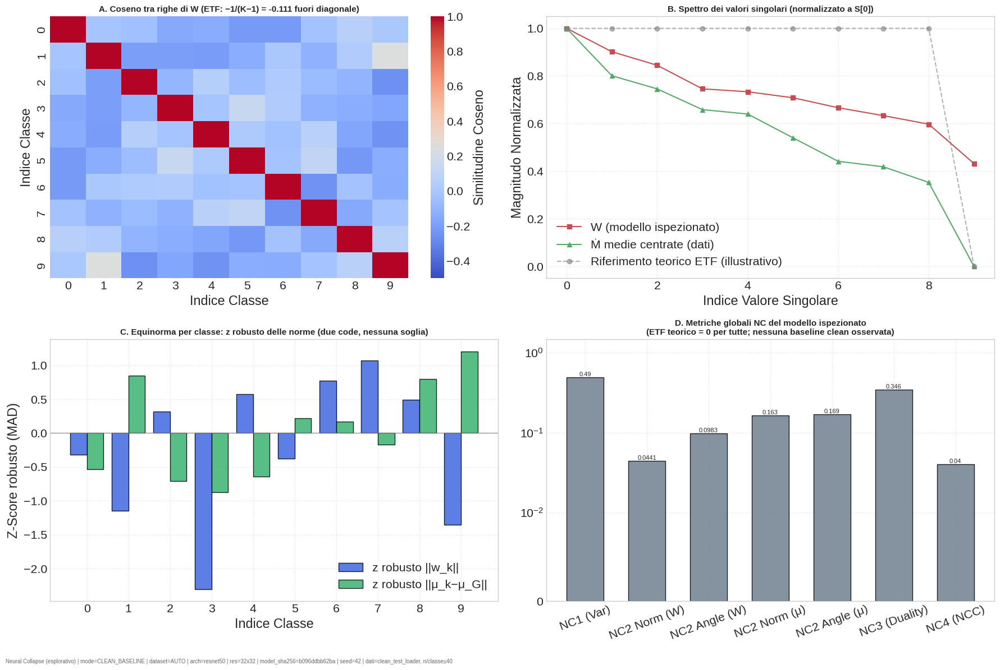


 INTERPRETATION (NEURAL COLLAPSE) — exploratory indicator, no verdict
🔎 Class with maximum |z| of the norm ||w_k||: 3 ('cat'), z = -2.31 (min z -2.31, max z +1.07). Candidate for manual inspection.
   Gu et al. (arXiv:2411.12914, Sec. 3) observe weaker collapse in models with trojans and a smaller norm
   of the target class (training features, CIFAR-10/ResNet18), without proposing thresholds or a detector. Anomalous norms
   can also stem from class imbalance, intrinsic class difficulty or training regime.

📤 [NEURAL COLLAPSE] Metrics recorded (status in METRIC_META)
   NC1: 0.4902 | NC2 Norm (W): 0.0441 | NC2 Angle (W): 0.0983
   NC3: 0.3460 | NC4: 0.0400 | metrics status on data: computed
   Z min/max ||w_k||: -2.307 / +1.069 | class |z| max: 3
🧹 [Memory Cleanup] RAM: 5.00/31.35 GB (17.5%)


In [53]:
if should_run_section('NEURAL_COLLAPSE'):
    clean_memory()
    import os
    import traceback
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import matplotlib.pyplot as plt
    import seaborn as sns
    from typing import Dict, List, Optional
    from torch.utils.data import DataLoader

    # ==============================================================================
    # NEURAL COLLAPSE (NC1-NC4) — GEOMETRIC DIAGNOSTICS OF THE LAST LAYER (EXPLORATORY)
    # Definitions: V. Papyan, X.Y. Han, D.L. Donoho, "Prevalence of Neural Collapse during the terminal phase
    #   of deep learning training", PNAS 117(40), 2020, doi:10.1073/pnas.2015509117 (arXiv:2008.08186):
    #   Sec. 2 Eq. 3-5 (μ_G, Σ_B, Σ_W, Ṁ), Sec. 3 Fig. 2 (equinorm), Fig. 4 (maximal angle),
    #   Fig. 5 (self-duality), Fig. 6 (NC1 = Tr(Σ_W Σ_B^†)/C, † = Moore-Penrose pseudo-inverse), Fig. 7 (NCC).
    # Link with trojans: X. Gu, G. Fields, Y. Jandali, T. Javidi, F. Koushanfar, "Trojan Cleansing with
    #   Neural Collapse", arXiv:2411.12914 (Sec. 2.3.3 Eq. 1-4; Sec. 3: trojans weaken the collapse and the
    #   norm of the target class turns out smaller, CIFAR-10/ResNet18, training set features). The paper proposes
    #   only a cleansing (ETF-FT) and NOT a detector: no z threshold, no joint NC1+NC2 criterion.
    # Here: NC measures on the inspected model + per-class ranking of the ||w_k|| norms (robust z, two-tailed)
    # as an indicator for manual inspection. No verdict, no synthetic baseline passed off as clean.
    # ==============================================================================
    NCL_METHOD = "Neural Collapse (Papyan et al. 2020)"
    # Legacy globals with verdict/threshold semantics: removed so as not to contaminate the export (reused kernels)
    for _k in ("nc_collapse_is_anomalous", "nc_collapse_z_threshold", "nc_collapse_z_min_all", "nc_collapse_z_max_all"):
        globals().pop(_k, None)

    # Parameters (override via globals)
    NC_COLLAPSE_SAMPLES_PER_CLASS = int(globals().get("NC_COLLAPSE_SAMPLES_PER_CLASS", 40))   # effective default of the original
    NC_COLLAPSE_MIN_PER_CLASS = int(globals().get("NC_COLLAPSE_MIN_PER_CLASS", 5))           # minimum coverage per class
    NC_COLLAPSE_MAX_BATCHES = int(globals().get("NC_COLLAPSE_MAX_BATCHES", 150))
    NC_COLLAPSE_LOADER = globals().get("NC_COLLAPSE_LOADER", None)        # alternative labeled DataLoader (e.g. clean training split)
    NC_COLLAPSE_REFERENCE = globals().get("NC_COLLAPSE_REFERENCE", None)  # dict of a comparable clean control model

    def _ncl_rec(key, value, status="computed", **kw):
        """record_metric + homonymous global (same value, even NaN) for the backward compatibility of cell 93."""
        kw.setdefault("method", NCL_METHOD)
        v = record_metric(key, value, status, **kw)
        globals()[key] = v
        return v

    _NCL_KEYS = ("nc_collapse_nc1_variability", "nc_collapse_nc2_norm", "nc_collapse_nc2_angle",
                "nc_collapse_nc2_norm_means", "nc_collapse_nc2_angle_means", "nc_collapse_nc3_duality",
                "nc_collapse_nc4_nn_mismatch", "nc_collapse_min_zscore", "nc_collapse_max_zscore",
                "nc_collapse_detected_class_id", "nc_collapse_detected_class_name",
                "nc_collapse_n_samples", "nc_collapse_n_classes_used")
    _NCL_DELTA_KEYS = {"nc_delta_nc1_variability": "nc1", "nc_delta_nc2_norm": "nc2_norm", "nc_delta_nc2_angle": "nc2_angle",
                      "nc_delta_nc3_duality": "nc3", "nc_delta_nc4_mismatch": "nc4"}

    # Checkpoint metadata: ASR/TOI are attack ground truth -> printed only in evaluation (oracle)
    if oracle_allowed():
        if "checkpoint_meta" in globals() and isinstance(checkpoint_meta, dict):
            rep = checkpoint_meta.get("best_report", {})
        elif "best_overall_config" in globals() and isinstance(best_overall_config, dict):
            rep = best_overall_config
        else:
            rep = {}
        f1_val = rep.get("final_val_f1", "n/a")
        asr_val = rep.get("final_val_asr", "n/a")
        toi_val = rep.get("trade_off_index", globals().get("best_overall_score", "n/a"))
    print("=" * 95)
    print(" NEURAL COLLAPSE (NC1-NC4) — EXPLORATORY GEOMETRIC DIAGNOSTICS OF THE LAST LAYER")
    print(" Definitions: Papyan, Han, Donoho (PNAS 2020) | Trojan link: Gu et al. arXiv:2411.12914 (no detector in the paper)")
    if oracle_allowed():
        print(f"🧪 [Evaluation (oracle)] Clean F1: {f1_val} | ASR: {asr_val} | TOI (F1*ASR): {toi_val}")
    print("=" * 95)

    # ------------------------------------------------------------------------------
    # 1. COMPUTATION FUNCTIONS (NC1-NC4 according to Papyan et al. 2020)
    # ------------------------------------------------------------------------------
    def ncl_robust_z(values: np.ndarray):
        """robust_mad_z of the contract + numerical guard: MAD below the float32 precision of the weights -> 'degenerate'."""
        z, info = robust_mad_z(values, min_n=3)
        if info["status"] == "computed" and info["mad"] <= 1e-6 * abs(info["median"]):
            z, info = np.full(np.shape(values), np.nan), dict(info, status="degenerate")
        return z, info

    def ncl_weight_geometry(W: np.ndarray) -> Dict[str, object]:
        """NC2 on the classifier weights only (Fig. 2 and Fig. 4, orange curves): computable without data."""
        K = W.shape[0]
        norms = np.linalg.norm(W, axis=1)
        out = {"W_norms": norms, "K": K}
        out["nc2_norm_W"] = float(np.std(norms, ddof=1) / np.mean(norms)) if K >= 2 and np.mean(norms) > 0 else float("nan")
        if K >= 2 and np.all(norms > 0):
            Wn = W / norms[:, None]
            cos = Wn @ Wn.T
            off = ~np.eye(K, dtype=bool)
            dev = np.abs(cos + 1.0 / (K - 1))
            out["cos_W"] = cos
            out["nc2_angle_W"] = float(dev[off].mean())                                   # Avg_{c≠c'} |cos + 1/(C-1)|
            out["angle_dev_class"] = np.array([dev[k, off[k]].mean() for k in range(K)])
        else:
            out["cos_W"] = np.full((K, K), np.nan)
            out["nc2_angle_W"] = float("nan")
            out["angle_dev_class"] = np.full(K, np.nan)
        out["sv_W"] = np.linalg.svd(W, compute_uv=False)
        return out

    def ncl_feature_metrics(H: np.ndarray, Y: np.ndarray, L: np.ndarray, W: np.ndarray, present: List[int]) -> Dict[str, object]:
        """
        NC1, NC2 (means), NC3, NC4 on real penultimate features with labels.
        H: (N, d) features; Y: (N,) labels; L: (N, K) network logits (bias included); present: used classes.
        μ_G = mean of the class means (= Ave_{i,c} h with balanced classes, Eq. 3); Σ_W = Ave_{i,c} (Eq. 4).
        """
        C = len(present)
        Hs, Ys, Ls = H[np.isin(Y, present)], Y[np.isin(Y, present)], L[np.isin(Y, present)]
        pos = {c: i for i, c in enumerate(present)}
        yi = np.array([pos[int(c)] for c in Ys])
        mu = np.stack([Hs[yi == i].mean(0) for i in range(C)])          # (C, d)
        mu_G = mu.mean(0)
        M = mu - mu_G                                                      # rows = columns of Ṁ
        Hc = Hs - mu[yi]                                                   # intra-class deviations
        out = {"C": C, "N": int(Hs.shape[0]), "mu": mu}

        # NC1 = Tr(Σ_W Σ_B^†)/C. Σ_B = MᵀM/C has rank ≤ C-1: pseudo-inverse from the SVD of M truncated at the numerical
        # rank (like svds(Sb, k=C-1) in the reference code). Every term v_rᵀ Σ_W v_r / λ_r is ≥ 0.
        _, S, Vt = np.linalg.svd(M, full_matrices=False)
        tol = (S.max() if S.size else 0.0) * max(M.shape) * np.finfo(np.float64).eps
        r = int(min(C - 1, int((S > tol).sum())))
        out["sigma_b_rank"] = r
        if r >= 1:
            lam = S[:r] ** 2 / C                                           # non-zero eigenvalues of Σ_B
            proj = Hc @ Vt[:r].T                                           # (N, r)
            per_sample = (proj ** 2 / lam[None, :]).sum(1) / C
            out["nc1"] = float(per_sample.mean())                          # = Tr(Σ_W Σ_B^†)/C ≥ 0
            out["nc1_class"] = np.array([per_sample[yi == i].mean() for i in range(C)])   # NC1 = Σ_c (n_c/N)·NC1_c
            out["sigma_b_cond"] = float(lam.max() / lam.min())
            out["nc1_status"] = "computed"
        else:
            out["nc1"], out["nc1_class"], out["sigma_b_cond"], out["nc1_status"] = float("nan"), np.full(C, np.nan), float("nan"), "degenerate"
        out["within_var_class"] = np.array([(Hc[yi == i] ** 2).sum(1).mean() for i in range(C)])   # Tr(Σ_W^c)

        # NC2 on the centered means (Fig. 2 and Fig. 4, blue curves)
        m_norms = np.linalg.norm(M, axis=1)
        out["M_norms"] = m_norms
        out["nc2_norm_M"] = float(np.std(m_norms, ddof=1) / np.mean(m_norms)) if C >= 2 and np.mean(m_norms) > 0 else float("nan")
        if C >= 2 and np.all(m_norms > 0):
            Mn = M / m_norms[:, None]
            off = ~np.eye(C, dtype=bool)
            out["nc2_angle_M"] = float(np.abs((Mn @ Mn.T) + 1.0 / (C - 1))[off].mean())
        else:
            out["nc2_angle_M"] = float("nan")
        out["sv_M"] = S

        # NC3 = || W/||W||_F − Ṁᵀ/||Ṁ||_F ||_F² (Eq. 5, Fig. 5), on the rows of W of the used classes
        Wp = W[present]
        nW, nM = np.linalg.norm(Wp), np.linalg.norm(M)
        out["nc3"] = float(np.linalg.norm(Wp / nW - M / nM) ** 2) if nW > 0 and nM > 0 else float("nan")

        # NC4: disagreement between argmax of the network logits (bias included) and NCC argmin ||h − μ_c|| (Fig. 7)
        pred_net = Ls.argmax(1)
        d2 = (Hs ** 2).sum(1)[:, None] - 2.0 * Hs @ mu.T + (mu ** 2).sum(1)[None, :]   # ||h−μ_c||² without an (N, C, d) tensor
        pred_ncc = np.asarray(present)[d2.argmin(1)]
        mism = pred_net != pred_ncc
        out["nc4"] = float(mism.mean())
        out["nc4_class"] = np.array([mism[yi == i].mean() for i in range(C)])
        return out

    def ncl_extract_features(model: nn.Module, fc: nn.Linear, loader, K: int, per_class: int, max_batches: int, dev):
        """Input features to the final Linear + network logits, sampling with a per-class cap."""
        feats = []
        def _hook(m, inp, out):
            feats.append(inp[0].detach().flatten(1).double().cpu())
        buck_h = {c: [] for c in range(K)}
        buck_l = {c: [] for c in range(K)}
        n_bad, n_batches = 0, 0
        h = fc.register_forward_hook(_hook)
        try:
            with torch.no_grad():
                for b_idx, batch in enumerate(loader):
                    if b_idx >= max_batches:
                        break
                    imgs, lbls = batch[0], batch[1]
                    feats.clear()
                    logits = model(imgs.to(dev))
                    if isinstance(logits, (tuple, list)):
                        logits = logits[0]
                    hb, lb = feats[0], logits.detach().double().cpu()
                    for i, c in enumerate(torch.as_tensor(lbls).long().view(-1).tolist()):
                        if 0 <= c < K:
                            if len(buck_h[c]) < per_class:
                                buck_h[c].append(hb[i])
                                buck_l[c].append(lb[i])
                        else:
                            n_bad += 1
                    n_batches += 1
                    if all(len(buck_h[c]) >= per_class for c in range(K)):
                        break
        finally:
            h.remove()
        counts = np.array([len(buck_h[c]) for c in range(K)])
        if counts.sum() == 0:
            return None, None, None, counts, n_bad, n_batches
        H = torch.stack([v for c in range(K) for v in buck_h[c]]).numpy()
        L = torch.stack([v for c in range(K) for v in buck_l[c]]).numpy()
        Y = np.concatenate([np.full(len(buck_h[c]), c) for c in range(K)])
        return H, Y, L, counts, n_bad, n_batches

    # ------------------------------------------------------------------------------
    # 2. MODEL, CLASSES AND LABELED DATA
    # ------------------------------------------------------------------------------
    ncl_net = get_audit_model(required=False)
    if ncl_net is None:
        print("⚠️ No model available for the Neural Collapse analysis.")
        for _key in _NCL_KEYS:
            _ncl_rec(_key, None, "not_run", note="no model available")
    else:
        try:
            with preserve_model_state(ncl_net):
                ncl_net.eval()
                ncl_dev = next(ncl_net.parameters()).device
                ncl_ctx = get_model_eval_context(ncl_net, device=ncl_dev)
                ncl_strategy = str(ncl_ctx.get("strategy", "scratch"))

                ncl_fc = None
                for _name, _mod in ncl_net.named_modules():
                    if isinstance(_mod, nn.Linear):
                        ncl_fc_name, ncl_fc = _name, _mod
                if ncl_fc is None:
                    raise RuntimeError("no final nn.Linear layer found in the model")
                ncl_W = ncl_fc.weight.detach().double().cpu().numpy()            # (K, d)
                ncl_K, ncl_d = ncl_W.shape
                _names = globals().get("CLASS_NAMES", None)
                if _names is None:
                    _names = globals().get("classes", None)
                ncl_class_names = [str(c) for c in _names] if (_names is not None and len(_names) == ncl_K) else [f"class_{i}" for i in range(ncl_K)]

                # Data: no dataset in MODEL_ONLY; otherwise labeled clean test split (or provided loader)
                ncl_loader, ncl_data_src = None, "none"
                if str(globals().get('EXECUTION_MODE', '')).upper() != 'MODEL_ONLY':
                    if NC_COLLAPSE_LOADER is not None:
                        ncl_loader, ncl_data_src = NC_COLLAPSE_LOADER, "NC_COLLAPSE_LOADER (provided)"
                    elif globals().get("clean_test_loader") is not None:
                        ncl_loader, ncl_data_src = clean_test_loader, "clean_test_loader"
                    elif globals().get("test_loader") is not None:
                        ncl_loader, ncl_data_src = test_loader, "test_loader"
                    elif globals().get("clean_test_dataset") is not None:
                        ncl_loader, ncl_data_src = DataLoader(clean_test_dataset, batch_size=64, shuffle=False, num_workers=0), "clean_test_dataset"

                print("\n[1/3] Model inspection...")
                print(f" -> Final classifier '{ncl_fc_name}': W {tuple(ncl_W.shape)} | bias: {ncl_fc.bias is not None} | strategy: {ncl_strategy}")

                # NC2 on the weights: always computable
                ncl_geo = ncl_weight_geometry(ncl_W)
                ncl_zw, ncl_zw_info = ncl_robust_z(ncl_geo["W_norms"])

                # NC1/NC2(means)/NC3/NC4: require real features with labels
                ncl_feat, ncl_counts, ncl_present, ncl_data_status, ncl_data_note = None, np.zeros(ncl_K, dtype=int), [], "not_applicable", ""
                if ncl_loader is None:
                    ncl_data_note = "requires real labeled features: no dataset available (e.g. MODEL_ONLY)"
                    print(f" -> {ncl_data_note}. Computing only NC2 on the weights W.")
                else:
                    H_nc, Y_nc, L_nc, ncl_counts, _n_bad, _n_b = ncl_extract_features(
                        ncl_net, ncl_fc, ncl_loader, ncl_K, NC_COLLAPSE_SAMPLES_PER_CLASS, NC_COLLAPSE_MAX_BATCHES, ncl_dev)
                    ncl_present = [c for c in range(ncl_K) if ncl_counts[c] >= NC_COLLAPSE_MIN_PER_CLASS]
                    print(f" -> Data source: {ncl_data_src} | batches read: {_n_b} | samples: {int(ncl_counts.sum())} | "
                          f"n per class: min {int(ncl_counts.min())}, max {int(ncl_counts.max())} (cap {NC_COLLAPSE_SAMPLES_PER_CLASS})")
                    if _n_bad:
                        print(f" -> ⚠️ {_n_bad} labels outside [0, {ncl_K - 1}] ignored.")
                    if ncl_counts.min() != ncl_counts.max():
                        print(" -> ⚠️ Sample unbalanced across classes: μ_G and Σ_W do not coincide with the definitions of the balanced case of the paper.")
                    if len(ncl_present) < 2 or H_nc is None:
                        ncl_data_status = "insufficient_data"
                        ncl_data_note = f"fewer than 2 classes with at least {NC_COLLAPSE_MIN_PER_CLASS} samples"
                        print(f" -> ⚠️ {ncl_data_note}: NC1/NC3/NC4 not computable.")
                    else:
                        ncl_feat = ncl_feature_metrics(H_nc, Y_nc, L_nc, ncl_W, ncl_present)
                        if len(ncl_present) < ncl_K:
                            ncl_data_status = "insufficient_data"
                            ncl_data_note = (f"computed on {len(ncl_present)}/{ncl_K} classes with ≥{NC_COLLAPSE_MIN_PER_CLASS} samples: "
                                            "not comparable with the value over all classes")
                            print(f" -> ⚠️ {ncl_data_note}")
                        else:
                            ncl_data_status = "computed"
                        ncl_data_note = (ncl_data_note + " | " if ncl_data_note else "") + (
                            f"split={ncl_data_src} (the paper measures on the training set in the terminal phase); "
                            f"n/class {int(ncl_counts.min())}-{int(ncl_counts.max())}; d={ncl_d}; rank Σ_B={ncl_feat['sigma_b_rank']}, "
                            f"cond Σ_B={ncl_feat['sigma_b_cond']:.2e}")

                # ------------------------------------------------------------------------------
                # 3. PER-CLASS RANKING (exploratory indicator, two-tailed)
                # ------------------------------------------------------------------------------
                if ncl_zw_info["status"] == "computed":
                    ncl_det_id = int(np.nanargmax(np.abs(ncl_zw)))
                    ncl_min_z, ncl_max_z = float(np.nanmin(ncl_zw)), float(np.nanmax(ncl_zw))
                else:
                    ncl_det_id, ncl_min_z, ncl_max_z = None, float("nan"), float("nan")
                ncl_zm = np.full(ncl_K, np.nan)
                ncl_m_norm_k = np.full(ncl_K, np.nan)
                ncl_n1_k, ncl_wv_k, ncl_n4_k = np.full(ncl_K, np.nan), np.full(ncl_K, np.nan), np.full(ncl_K, np.nan)
                if ncl_feat is not None:
                    ncl_m_norm_k[ncl_present] = ncl_feat["M_norms"]
                    ncl_n1_k[ncl_present] = ncl_feat["nc1_class"]
                    ncl_wv_k[ncl_present] = ncl_feat["within_var_class"]
                    ncl_n4_k[ncl_present] = ncl_feat["nc4_class"]
                    ncl_zm[ncl_present] = ncl_robust_z(ncl_feat["M_norms"])[0]

                # ------------------------------------------------------------------------------
                # 4. TABULAR REPORT
                # ------------------------------------------------------------------------------
                print("\n[2/3] Report Neural Collapse...")
                _g = lambda key: (ncl_feat[key] if ncl_feat is not None else float("nan"))
                df_summary = pd.DataFrame([{
                    "Configuration": "Inspected model",
                    "NC1 (Var)": _g("nc1"),
                    "NC2 Norm (W)": ncl_geo["nc2_norm_W"],
                    "NC2 Angle (W)": ncl_geo["nc2_angle_W"],
                    "NC2 Norm (μ)": _g("nc2_norm_M"),
                    "NC2 Angle (μ)": _g("nc2_angle_M"),
                    "NC3 (Dual)": _g("nc3"),
                    "NC4 (NCC)": _g("nc4"),
                    "Z Min ||w||": ncl_min_z,
                    "Z Max ||w||": ncl_max_z,
                }])
                if isinstance(NC_COLLAPSE_REFERENCE, dict):
                    df_summary = pd.concat([df_summary, pd.DataFrame([{
                        "Configuration": f"Observed reference: {NC_COLLAPSE_REFERENCE.get('label', 'n/a')}",
                        "NC1 (Var)": NC_COLLAPSE_REFERENCE.get("nc1", np.nan),
                        "NC2 Norm (W)": NC_COLLAPSE_REFERENCE.get("nc2_norm", np.nan),
                        "NC2 Angle (W)": NC_COLLAPSE_REFERENCE.get("nc2_angle", np.nan),
                        "NC3 (Dual)": NC_COLLAPSE_REFERENCE.get("nc3", np.nan),
                        "NC4 (NCC)": NC_COLLAPSE_REFERENCE.get("nc4", np.nan),
                    }])], ignore_index=True)
                print("\n --- GLOBAL NC1-NC4 PROFILE (Papyan et al. 2020; lower values = stronger collapse) ---")
                print(df_summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
                print(" Theoretical Simplex ETF reference: NC1 = NC2 = NC3 = NC4 = 0 (illustrative, not an observed clean baseline).")

                ncl_rank_abs = np.full(ncl_K, np.nan)
                if ncl_zw_info["status"] == "computed":
                    ncl_rank_abs[np.argsort(-np.abs(ncl_zw))] = np.arange(1, ncl_K + 1)
                df_nc_class = pd.DataFrame({
                    "Class ID": np.arange(ncl_K),
                    "Class Name": ncl_class_names,
                    "n": ncl_counts,
                    "||w_k||": ncl_geo["W_norms"],
                    "z ||w_k|| (MAD)": ncl_zw,
                    "Rank |z|": [int(r) if np.isfinite(r) else None for r in ncl_rank_abs],
                    "ETF angle dev. (w)": ncl_geo["angle_dev_class"],
                    "||μ_k−μ_G||": ncl_m_norm_k,
                    "z ||μ_k|| (MAD)": ncl_zm,
                    "Tr(Σ_W^k)": ncl_wv_k,
                    "NC1_k": ncl_n1_k,
                    "NCC Disagreement": ncl_n4_k,
                })
                print("\n" + "=" * 95)
                print(" 🎯 PER-CLASS PROFILE (ranking by robust |z| of the norm ||w_k||; no threshold)")
                print("=" * 95)
                print(df_nc_class.to_string(index=False, float_format=lambda v: f"{v:+.4f}" if abs(v) < 1e4 else f"{v:.3e}"))
                print("=" * 95)

                # ------------------------------------------------------------------------------
                # 5. GRAPHICAL DASHBOARD
                # ------------------------------------------------------------------------------
                print("\n[3/3] Rendering diagnostic dashboard...")
                ncl_target = globals().get("TARGET_LABEL", None) if oracle_allowed() else None
                ncl_target_ok = ncl_target is not None and isinstance(ncl_target, (int, np.integer)) and 0 <= int(ncl_target) < ncl_K
                ncl_target = int(ncl_target) if ncl_target_ok else None

                fig_nc = plt.figure(figsize=(18, 12))
                ax1 = fig_nc.add_subplot(2, 2, 1)
                sns.heatmap(ncl_geo["cos_W"], cmap="coolwarm", vmin=-0.5, vmax=1.0, ax=ax1, cbar_kws={"label": "Cosine Similarity"})
                ax1.set_title(f"A. Cosine between rows of W (ETF: −1/(K−1) = {-1.0 / max(ncl_K - 1, 1):.3f} off-diagonal)", fontsize=11, fontweight="bold")
                ax1.set_xlabel("Class Index")
                ax1.set_ylabel("Class Index")

                ax2 = fig_nc.add_subplot(2, 2, 2)
                _sw = ncl_geo["sv_W"]
                ax2.plot(_sw / _sw[0], "r-s", label="W (inspected model)")
                if ncl_feat is not None and ncl_feat["sv_M"].size and ncl_feat["sv_M"][0] > 0:
                    ax2.plot(ncl_feat["sv_M"] / ncl_feat["sv_M"][0], "g-^", label="Ṁ centered means (data)")
                _etf = np.r_[np.ones(max(ncl_K - 1, 0)), 0.0][:len(_sw)]
                ax2.plot(_etf, color="gray", linestyle="--", marker="o", alpha=0.6, label="Theoretical ETF reference (illustrative)")
                ax2.set_title("B. Singular value spectrum (normalized to S[0])", fontsize=11, fontweight="bold")
                ax2.set_xlabel("Singular Value Index")
                ax2.set_ylabel("Normalized Magnitude")
                ax2.legend()
                ax2.grid(True, linestyle=":", alpha=0.6)

                ax3 = fig_nc.add_subplot(2, 2, 3)
                _x = np.arange(ncl_K)
                if ncl_zw_info["status"] == "computed":
                    _bw = 0.4 if ncl_feat is not None else 0.8
                    ax3.bar(_x - (_bw / 2 if ncl_feat is not None else 0), ncl_zw, _bw, color="royalblue", edgecolor="black", alpha=0.85, label="robust z ||w_k||")
                    if ncl_feat is not None:
                        ax3.bar(_x + _bw / 2, ncl_zm, _bw, color="mediumseagreen", edgecolor="black", alpha=0.85, label="robust z ||μ_k−μ_G||")
                    ax3.axhline(0, color="gray", linewidth=0.8)
                    ax3.set_ylabel("Robust Z-Score (MAD)")
                    ax3.set_title("C. Per-class equinorm: robust z of the norms (two-tailed, no threshold)", fontsize=11, fontweight="bold")
                else:
                    ax3.bar(_x, ncl_geo["W_norms"], color="royalblue", edgecolor="black", alpha=0.85, label="||w_k||")
                    ax3.set_ylabel("Norm ||w_k||")
                    ax3.set_title(f"C. Norms ||w_k|| (robust z: {ncl_zw_info['status']})", fontsize=11, fontweight="bold")
                if ncl_target_ok:
                    ax3.axvline(ncl_target, color="black", linestyle="-.", linewidth=1.0, label="Target (oracle evaluation)")
                ax3.set_xlabel("Class Index")
                if ncl_K <= 20:
                    ax3.set_xticks(_x)
                ax3.legend()
                ax3.grid(True, linestyle=":", alpha=0.6)

                ax4 = fig_nc.add_subplot(2, 2, 4)
                _labels = ["NC1 (Var)", "NC2 Norm (W)", "NC2 Angle (W)", "NC2 Norm (μ)", "NC2 Angle (μ)", "NC3 (Duality)", "NC4 (NCC)"]
                _vals = [_g("nc1"), ncl_geo["nc2_norm_W"], ncl_geo["nc2_angle_W"], _g("nc2_norm_M"), _g("nc2_angle_M"), _g("nc3"), _g("nc4")]
                _xp = np.arange(len(_labels))
                _vplot = [v if np.isfinite(v) else 0.0 for v in _vals]
                ax4.bar(_xp, _vplot, 0.6, color=["slategray" if np.isfinite(v) else "white" for v in _vals], edgecolor="black", alpha=0.85)
                for _i, _v in enumerate(_vals):
                    ax4.text(_i, _vplot[_i], f"{_v:.3g}" if np.isfinite(_v) else "n/a", ha="center", va="bottom", fontsize=8)
                ax4.set_xticks(_xp)
                ax4.set_xticklabels(_labels, rotation=20)
                ax4.set_yscale("symlog", linthresh=1e-2)
                _fin = [v for v in _vals if np.isfinite(v) and v > 0]
                if _fin:
                    ax4.set_ylim(0, 3.0 * max(_fin))
                ax4.set_title("D. Global NC metrics of the inspected model\n(theoretical ETF = 0 for all; no observed clean baseline)", fontsize=11, fontweight="bold")
                ax4.grid(True, linestyle=":", alpha=0.6)

                plt.tight_layout(rect=(0, 0.02, 1, 1))
                fig_nc.text(0.01, 0.005, provenance_caption("Neural Collapse (exploratory)",
                            extra=f"data={ncl_data_src}, n/class≤{NC_COLLAPSE_SAMPLES_PER_CLASS}"), fontsize=7, alpha=0.7)

                out_dir_nc = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
                os.makedirs(out_dir_nc, exist_ok=True)
                ncl_dashboard_fname = f"nc_collapse_dashboard_{ncl_strategy}.png"
                ncl_dashboard_path = os.path.join(out_dir_nc, ncl_dashboard_fname)
                fig_nc.savefig(ncl_dashboard_path, bbox_inches='tight', dpi=150)
                register_artifact(NCL_METHOD, ncl_dashboard_path, kind="figure", note="NC1-NC4 dashboard (exploratory)")
                globals()['NC_DASHBOARD_IMG_PATH'] = ncl_dashboard_path
                globals()['nc_dashboard_img'] = ncl_dashboard_fname
                print(f"🖼️ [NC] Dashboard saved to: {ncl_dashboard_path}")
                plt.show()
                plt.close(fig_nc)

                # ------------------------------------------------------------------------------
                # 6. INTERPRETATION (no verdict)
                # ------------------------------------------------------------------------------
                print("\n" + "=" * 95)
                print(" INTERPRETATION (NEURAL COLLAPSE) — exploratory indicator, no verdict")
                print("=" * 95)
                if ncl_det_id is not None:
                    print(f"🔎 Class with maximum |z| of the norm ||w_k||: {ncl_det_id} ('{ncl_class_names[ncl_det_id]}'), z = {ncl_zw[ncl_det_id]:+.2f} "
                          f"(min z {ncl_min_z:+.2f}, max z {ncl_max_z:+.2f}). Candidate for manual inspection.")
                print("   Gu et al. (arXiv:2411.12914, Sec. 3) observe a weaker collapse in models with trojans and a smaller norm")
                print("   of the target class (training features, CIFAR-10/ResNet18), without proposing thresholds or a detector. Anomalous norms")
                print("   can also result from class imbalance, intrinsic difficulty of the class or training regime.")
                if ncl_target_ok:
                    print(f"🧪 Evaluation (oracle): target {ncl_target} ('{ncl_class_names[ncl_target]}') -> z ||w|| {ncl_zw[ncl_target]:+.2f}, "
                          f"rank |z| {ncl_rank_abs[ncl_target]:.0f}/{ncl_K}, ETF angle dev. {ncl_geo['angle_dev_class'][ncl_target]:.4f}")
                print("=" * 95 + "\n")

                # ------------------------------------------------------------------------------
                # 7. METRIC AND ENTITY REGISTRATION
                # ------------------------------------------------------------------------------
                _fs = ncl_data_status
                _ncl_rec("nc_collapse_nc1_variability", _g("nc1"), _fs if (ncl_feat is None or ncl_feat["nc1_status"] == "computed") else ncl_feat["nc1_status"],
                        level="model", unit="dimensionless ≥ 0", note="NC1 = Tr(Σ_W Σ_B^†)/C (Fig. 6) | " + ncl_data_note)
                _ncl_rec("nc_collapse_nc2_norm", ncl_geo["nc2_norm_W"], level="model", unit="CoV",
                        note="Std_c(||w_c||)/Avg_c(||w_c||) (Fig. 2), weights only")
                _ncl_rec("nc_collapse_nc2_angle", ncl_geo["nc2_angle_W"], level="model", unit="dimensionless",
                        note="Avg_{c≠c'}|cos_w + 1/(K−1)| (Fig. 4), weights only")
                _ncl_rec("nc_collapse_nc2_norm_means", _g("nc2_norm_M"), _fs, level="model", unit="CoV",
                        note="Std_c(||μ_c−μ_G||)/Avg_c (Fig. 2) | " + ncl_data_note)
                _ncl_rec("nc_collapse_nc2_angle_means", _g("nc2_angle_M"), _fs, level="model", unit="dimensionless",
                        note="Avg_{c≠c'}|cos_μ + 1/(C−1)| (Fig. 4) | " + ncl_data_note)
                _ncl_rec("nc_collapse_nc3_duality", _g("nc3"), _fs, level="model", unit="dimensionless",
                        note="||W/||W||_F − Ṁᵀ/||Ṁ||_F||_F² (Eq. 5, Fig. 5) | " + ncl_data_note)
                _ncl_rec("nc_collapse_nc4_nn_mismatch", _g("nc4"), _fs, level="model", unit="fraction [0,1]",
                        note="argmax logit (bias included) vs NCC disagreement (Fig. 7; here means and samples from the same split) | " + ncl_data_note)
                _zs = ncl_zw_info["status"]
                _ncl_rec("nc_collapse_min_zscore", ncl_min_z, _zs, level="class", unit="z MAD",
                        note="min robust z of ||w_k|| across classes; no threshold (the original -1.5 does not derive from the papers)")
                _ncl_rec("nc_collapse_max_zscore", ncl_max_z, _zs, level="class", unit="z MAD", note="max robust z of ||w_k|| across classes")
                _ncl_rec("nc_collapse_detected_class_id", ncl_det_id, _zs, level="class",
                        note="class with maximum robust |z| of ||w_k|| (two-tailed): candidate for inspection, not an estimated target class")
                _ncl_rec("nc_collapse_detected_class_name", ncl_class_names[ncl_det_id] if ncl_det_id is not None else None, _zs, level="class",
                        note="see nc_collapse_detected_class_id")
                _ncl_rec("nc_collapse_n_samples", int(ncl_counts.sum()) if ncl_loader is not None else None,
                        "computed" if ncl_loader is not None else "not_applicable", level="model", note=f"labeled samples used ({ncl_data_src})")
                _ncl_rec("nc_collapse_n_classes_used", len(ncl_present) if ncl_loader is not None else None,
                        "computed" if ncl_loader is not None else "not_applicable", level="model",
                        note=f"classes with ≥{NC_COLLAPSE_MIN_PER_CLASS} samples out of K={ncl_K}")

                # Delta only with respect to an OBSERVED and comparable clean reference (the old synthetic ETF baseline is removed)
                _active = {"nc1": _g("nc1"), "nc2_norm": ncl_geo["nc2_norm_W"], "nc2_angle": ncl_geo["nc2_angle_W"], "nc3": _g("nc3"), "nc4": _g("nc4")}
                for _key, _mk in _NCL_DELTA_KEYS.items():
                    _ref = NC_COLLAPSE_REFERENCE.get(_mk) if isinstance(NC_COLLAPSE_REFERENCE, dict) else None
                    if _ref is not None and np.isfinite(float(_ref)) and np.isfinite(_active[_mk]):
                        _ncl_rec(_key, float(_active[_mk] - float(_ref)), level="model",
                                note=f"delta vs provided reference '{NC_COLLAPSE_REFERENCE.get('label', 'n/a')}' (comparability is up to the user)")
                    else:
                        _ncl_rec(_key, None, "not_applicable", level="model",
                                note="no observed clean control model (NC_COLLAPSE_REFERENCE); the synthetic ETF baseline has been removed "
                                     "and with respect to the theoretical ETF (values 0) the delta coincides with the metric")

                # Evaluation (oracle) on the target class
                _ncl_rec("nc_target_zscore", float(ncl_zw[ncl_target]) if ncl_target_ok else None,
                        _zs if ncl_target_ok else "not_applicable", level="class", unit="z MAD", requires_ground_truth=True,
                        note="evaluation (oracle): robust z of ||w_target||")
                _ncl_rec("nc_target_angle_dev", float(ncl_geo["angle_dev_class"][ncl_target]) if ncl_target_ok else None,
                        "computed" if ncl_target_ok else "not_applicable", level="class", requires_ground_truth=True,
                        note="evaluation (oracle): Avg_j |cos(w_target, w_j) + 1/(K−1)|")
                _ncl_rec("nc_target_abs_z_rank", float(ncl_rank_abs[ncl_target]) if ncl_target_ok else None,
                        _zs if ncl_target_ok else "not_applicable", level="class", requires_ground_truth=True,
                        note="evaluation (oracle): position of the target in the ranking by |z| of ||w_k|| (1 = most extreme)")
                _ncl_rec("nc_collapse_dashboard_img", ncl_dashboard_fname, level="model", note="graphical artifact")

                record_entities(NCL_METHOD, "class", [{
                    "entity_id": int(k), "class_id": int(k), "class_name": ncl_class_names[k],
                    "score": float(ncl_zw[k]), "rank": float(ncl_rank_abs[k]), "flag": None,
                    "n_samples": int(ncl_counts[k]), "w_norm": float(ncl_geo["W_norms"][k]),
                    "w_angle_dev": float(ncl_geo["angle_dev_class"][k]), "mean_norm": float(ncl_m_norm_k[k]),
                    "mean_norm_z": float(ncl_zm[k]), "within_var_trace": float(ncl_wv_k[k]),
                    "nc1_class": float(ncl_n1_k[k]), "ncc_mismatch": float(ncl_n4_k[k]),
                    "requires_ground_truth": False,
                    "note": "score = robust z (MAD) of ||w_k||, rank by |z|; exploratory indicators without threshold",
                } for k in range(ncl_K)])

                print("=" * 85)
                print("📤 [NEURAL COLLAPSE] Registered metrics (status in METRIC_META)")
                print(f"   NC1: {_g('nc1'):.4f} | NC2 Norm (W): {ncl_geo['nc2_norm_W']:.4f} | NC2 Angle (W): {ncl_geo['nc2_angle_W']:.4f}")
                print(f"   NC3: {_g('nc3'):.4f} | NC4: {_g('nc4'):.4f} | metric status on data: {ncl_data_status}")
                print(f"   Z min/max ||w_k||: {ncl_min_z:+.3f} / {ncl_max_z:+.3f} | class |z| max: {ncl_det_id}")
                print("=" * 85)
        except Exception as e_nc:
            traceback.print_exc()
            print(f"❌ [NEURAL COLLAPSE] Error during the analysis: {e_nc}")
            for _key in _NCL_KEYS:
                _ncl_rec(_key, None, "failed", note=f"error: {type(e_nc).__name__}: {e_nc}")
        check_model_integrity('NEURAL_COLLAPSE')

    clean_memory(verbose=True)


## ♣️ 30. TABOR

🔍 [TABOR] Quick selection of calibration pool...

🛡️ [TABOR FORENSIC SUITE] TRIGGER APPROXIMATION & BACKDOOR OPTIMIZATION (Guo et al., arXiv:1908.01763)
📦 Model: ResNet | Pool: 128 images (3x32x32) | optimization=88 hold-out=40 | Classes: 10
   initial λ={'l1': 0.0001, 'l2': 1e-05, 'l3': 1e-05, 'l4': 1e-08, 'l5': 0.5, 'l6': 0.2} | schedule ×/÷1.5 | steps=200

⏳ Running TABOR Inversion and Optimization on 10 classes (steps=200)...
   [TABOR] Target 00/09: 'airplane              '... Score A:  -0.06 | Area F: 62.1% | ASR hold-out:  80.6% | crop:  75.0% | exp: 100.0%
   [TABOR] Target 01/09: 'automobile            '... Score A:   0.23 | Area F: 62.4% | ASR hold-out:  75.0% | crop:  58.3% | exp: 100.0%
   [TABOR] Target 02/09: 'bird                  '... Score A:   0.58 | Area F: 61.3% | ASR hold-out:  52.8% | crop:  63.9% | exp:  97.2%
   [TABOR] Target 03/09: 'cat                   '... Score A:  -1.00 | Area F: 28.8% | ASR hold-out:  77.8% | crop:  75.0% | exp: 100.0%
   [TABOR] Target 

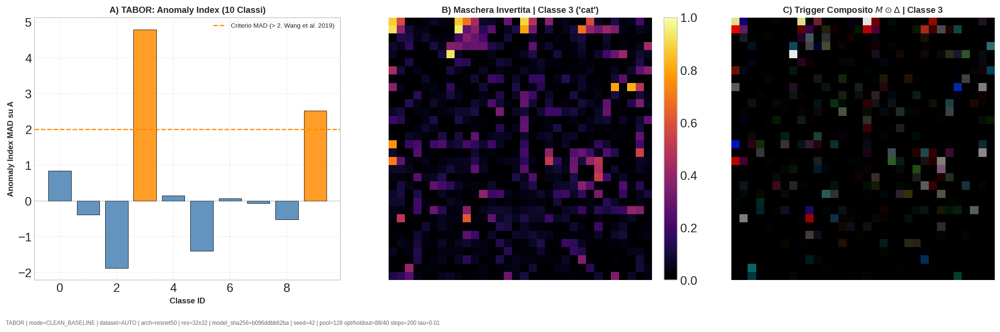

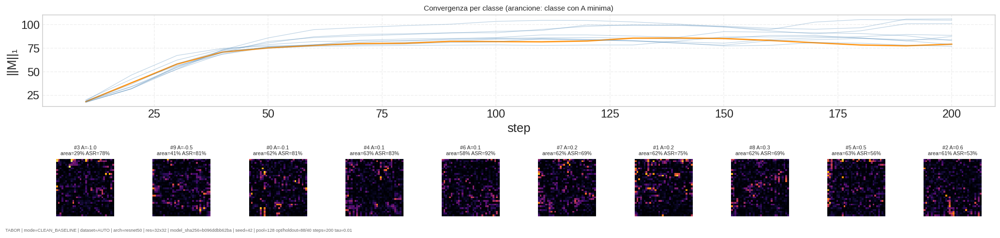

✅ [TABOR] FORENSIC METRICS EXPORTED
   Max Anomaly Index: 4.795206782351665 (computed) | MAD criterion flag: True
   Class with minimum A: #3 ('cat') | Hold-out ASR: 77.8%
   Median A: 0.14 | 1.4826·MAD: 0.2376


In [54]:
if should_run_section('TABOR'):
    clean_memory() if "clean_memory" in globals() else None

    import gc
    import os
    import math
    import traceback
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, Subset

    # ==============================================================================
    # TABOR — W. Guo, L. Wang, X. Xing, M. Du, D. Song, "TABOR: A Highly Accurate Approach to
    # Inspecting and Restoring Trojan Backdoors in AI Systems", arXiv:1908.01763 (2019).
    # Objective: Eq. 1 + R1..R4 (Eq. 2, 3, 4, 7; full form Eq. 10-11, App. A); schedule of the λ
    # (Sec. 4.3); quality metric A (Eq. 8); MAD outlier on A (Sec. 4.2.4, method of Wang et al. 2019).
    # Code references: github.com/UsmannK/TABOR (snooper.py), TrojanZoo (tabor.py).
    # Detection and inspection only: no patching / unlearning of the model.
    # ==============================================================================

    # ------------------------------------------------------------------------------
    # 1. ENVIRONMENT SETUP, MODEL & PARAMETERS
    # ------------------------------------------------------------------------------
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

    class _TaborSkip(Exception):
        """Requirement not satisfied: the section ends with an explicit status."""

    def _tabor_rec(key, value, status="computed", **kw):
        kw.setdefault("method", "TABOR")
        v = record_metric(key, value, status, **kw)
        globals()[key] = v
        return v

    _TABOR_THR_ORIGIN = ("paper:Wang et al. 2019 Sec. IV (MAD 1.4826, index > 2 on the side of small values); "
                         "TABOR Sec. 4.2.4 reuses the MAD replacing the L1 norm with A, without redefining the threshold")

    def _tabor_record_unavailable(status, note):
        for _k, _lvl in (("tabor_max_anomaly_index", "model"), ("tabor_suspected_class_id", "class"),
                         ("tabor_suspected_class_name", "class"), ("tabor_top_anomaly_index", "class"),
                         ("tabor_top_inverted_asr", "class"), ("tabor_top_clean_retained", "class"),
                         ("tabor_top_score_a", "class"), ("tabor_median_score", "model"), ("tabor_mad_score", "model"),
                         ("tabor_outlier_count", "model"), ("tabor_paper_flag", "model"),
                         ("tabor_top_trigger_area_pct", "class"), ("tabor_top_trigger_area_pct_t10", "class"),
                         ("tabor_n_valid_classes", "model")):
            _tabor_rec(_k, None, status, level=_lvl, note=note)
        for _k in ("tabor_target_anomaly_index", "tabor_target_inverted_asr", "tabor_target_score_a"):
            _tabor_rec(_k, None, status, level="class", requires_ground_truth=True, note=note)

    def _tabor_logits(out):
        if isinstance(out, (tuple, list)):
            out = out[0]
        elif isinstance(out, dict):
            out = out.get("logits", out.get("out"))
        return out

    tabor_net = get_audit_model()
    tabor_device = next(tabor_net.parameters()).device
    for _k in ("tabor_masks_dict", "tabor_patterns_dict", "tabor_df", "tabor_df_sorted", "tabor_suspected_target_class"):
        globals().pop(_k, None)

    # Context resolution and normalization of the inspected model
    if "get_model_eval_context" in globals():
        tabor_ctx = get_model_eval_context(tabor_net, device=tabor_device)
    else:
        tabor_ctx = {"mean": globals().get("SCRATCH_MEAN", [0.5, 0.5, 0.5]), "std": globals().get("SCRATCH_STD", [0.5, 0.5, 0.5]),
                     "is_pipeline": False, "target_res": None}
    _mean = [float(v) for v in np.asarray(tabor_ctx.get("mean")).ravel()]
    _std = [float(v) for v in np.asarray(tabor_ctx.get("std")).ravel()]
    tabor_is_pipeline = bool(tabor_ctx.get("is_pipeline", False))
    tabor_target_res = tabor_ctx.get("target_res")

    # Hyperparameters (can be overridden via globals). λ1/λ3/λ5/λ6 = previous values of the notebook (λ1 covers L1+L2² of the
    # mask as before); λ2/λ4 (regularization of Δ' = (1-M)⊙Δ, previously absent) = Tab. 3 of the paper (GTSRB).
    # Tab. 3 values for comparison — GTSRB: [1e-6, 1e-5, 1e-7, 1e-8, 1e-6, 1e-2]; ImageNet: [1e-3, 1e-5, 1e-6, 1e-9, 1e-6, 1e-2].
    _lam_default = {"l1": 1e-4, "l2": 1e-5, "l3": 1e-5, "l4": 1e-8, "l5": 0.5, "l6": 0.2}
    _lam_default.update(dict(globals().get("TABOR_LAMBDAS", {}) or {}))
    TABOR_RUN_PARAMS = {
        "steps": int(globals().get("TABOR_STEPS", 150 if tabor_is_pipeline else 200)),
        "lr": float(globals().get("TABOR_LR", 0.08)),
        "batch_size": int(globals().get("TABOR_BATCH_SIZE", 16)),
        "eval_batch_size": int(globals().get("TABOR_EVAL_BATCH_SIZE", 32)),
        "lambdas": {k: float(v) for k, v in _lam_default.items()},
        "lambda_step": float(globals().get("TABOR_LAMBDA_STEP", 1.5)),          # "step variable m" (Sec. 4.3), value not indicated
        "patience": int(globals().get("TABOR_PATIENCE", 5)),
        "check_every": int(globals().get("TABOR_CHECK_EVERY", 10)),
        "attack_succ_threshold": float(globals().get("TABOR_ATTACK_SUCC_THRESHOLD", 0.99)),  # threshold of Sec. 4.3 (value not indicated)
        "check_samples": int(globals().get("TABOR_CHECK_SAMPLES", 128)),         # effective threshold ceil(0.99·n)/n
        "restarts": max(1, int(globals().get("TABOR_RESTARTS", 1))),
        "holdout_frac": float(globals().get("TABOR_HOLDOUT_FRAC", 0.3)),
        "max_pool": int(globals().get("TABOR_MAX_SAMPLES", 128)),
        "seed": int(globals().get("TABOR_RANDOM_SEED", globals().get("SEED", 42))),
        "bin_threshold": float(globals().get("TABOR_BIN_THRESHOLD", 0.01)),     # F_ij = 1{(M⊙Δ)_ij > τ} (Eq. 8 uses τ = 0)
        "area_warn_pct": float(globals().get("TABOR_AREA_WARN_PCT", 25.0)),     # heuristic warning on the area with M⊙Δ > 0.1 (Obs. I)
        "amp": bool(globals().get("TABOR_AMP", False)),
        "anomaly_threshold": 2.0,
    }
    _use_amp = TABOR_RUN_PARAMS["amp"] and tabor_device.type == "cuda"

    # ------------------------------------------------------------------------------
    # 2. REGULARIZATION AND METRIC FUNCTIONS (Eq. 2, 3, 8)
    # ------------------------------------------------------------------------------
    def total_variation_smoothness(mat: torch.Tensor) -> torch.Tensor:
        """s(·) of Eq. 3: sum of the squares of the differences between adjacent pixels (over all channels)."""
        diff_w = torch.sum((mat[..., :, 1:] - mat[..., :, :-1]) ** 2)
        diff_h = torch.sum((mat[..., 1:, :] - mat[..., :-1, :]) ** 2)
        return diff_w + diff_h

    def elastic_net(mat: torch.Tensor) -> torch.Tensor:
        """R_elastic of Eq. 2: L1 + L2² (Zou & Hastie 2005, ref. [49] of the paper; as in the reference code)."""
        return torch.sum(torch.abs(mat)) + torch.sum(mat ** 2)

    def _tabor_mad_anomaly(values, min_n=3):
        """Index (median - A) / (1.4826·MAD) like robust_mad_z, but with A = +inf admitted as an order statistic
        (zero accuracy = trigger of minimum quality). NaN excluded; MAD = 0 or infinite median -> 'degenerate'."""
        v = np.asarray(values, dtype=np.float64)
        ok = ~np.isnan(v)
        info = {"n": int(ok.sum()), "median": float("nan"), "mad": float("nan"), "status": "computed"}
        idx = np.full(v.shape, np.nan)
        if info["n"] < min_n:
            info["status"] = "insufficient_data"
            return idx, info
        med = float(np.median(v[ok]))
        mad = float(np.median(np.abs(v[ok] - med))) if np.isfinite(med) else float("nan")
        info["median"], info["mad"] = med, mad
        if not (np.isfinite(med) and np.isfinite(mad) and mad > 0.0):
            info["status"] = "degenerate"
            return idx, info
        with np.errstate(invalid="ignore"):
            idx[ok] = (med - v[ok]) / (1.4826 * mad)
        return idx, info

    with preserve_model_state(tabor_net):
        tabor_net.eval()
        for _p in tabor_net.parameters():
            _p.requires_grad_(False)
        try:
            # --------------------------------------------------------------------------
            # 3. STRATIFIED CLEAN POOL + OPTIMIZATION / HOLD-OUT SPLIT
            # --------------------------------------------------------------------------
            base_raw_ds = None
            for _ds_name in ("clean_test_dataset", "evaluation_clean_test", "test_clean_ds", "clean_train_dataset"):
                _ds = globals().get(_ds_name)
                if _ds is not None and len(_ds) > 0:
                    base_raw_ds = _ds
                    break
            if base_raw_ds is None and globals().get("test_loader") is not None:
                base_raw_ds = test_loader.dataset
            if base_raw_ds is None or len(base_raw_ds) == 0:
                raise _TaborSkip("no clean dataset available (TABOR optimizes on a set of clean samples, Sec. 4.3)")

            rng_tabor = np.random.default_rng(TABOR_RUN_PARAMS["seed"])
            MAX_POOL_SAMPLES = min(TABOR_RUN_PARAMS["max_pool"], len(base_raw_ds))

            # Quick reading of the labels (avoids transforming all the images)
            print("🔍 [TABOR] Quick selection of the calibration pool...")
            def _tabor_labels(d):
                for _attr in ("targets", "labels"):
                    _t = getattr(d, _attr, None)
                    if _t is not None:
                        try:
                            _arr = np.asarray([int(v) for v in _t], dtype=np.int64)
                            if len(_arr) == len(d):
                                return _arr
                        except Exception:
                            pass
                if hasattr(d, "indices") and hasattr(d, "dataset"):
                    _b = _tabor_labels(d.dataset)
                    if _b is not None:
                        return _b[np.asarray(d.indices, dtype=np.int64)]
                return None
            _all_lbls_np = _tabor_labels(base_raw_ds)
            if _all_lbls_np is not None:
                _cand_idx = np.arange(len(base_raw_ds))
            else:
                _cand_idx = np.sort(rng_tabor.choice(len(base_raw_ds), size=min(len(base_raw_ds), max(400, 4 * MAX_POOL_SAMPLES)), replace=False))
                _all_lbls_np = np.asarray([int(torch.as_tensor(base_raw_ds[int(i)][1]).item()) for i in _cand_idx], dtype=np.int64)

            pool_idx = []
            _unique_l = np.unique(_all_lbls_np)
            if len(_unique_l) > 0:
                _per_c = max(1, MAX_POOL_SAMPLES // len(_unique_l))
                for _ul in _unique_l:
                    _ci = _cand_idx[_all_lbls_np == _ul].copy()
                    rng_tabor.shuffle(_ci)
                    pool_idx.extend(_ci[:_per_c].tolist())
            if len(pool_idx) < MAX_POOL_SAMPLES:
                _rem = np.setdiff1d(_cand_idx, np.asarray(pool_idx, dtype=np.int64))
                rng_tabor.shuffle(_rem)
                pool_idx.extend(_rem[:MAX_POOL_SAMPLES - len(pool_idx)].tolist())
            pool_idx = [int(i) for i in pool_idx[:MAX_POOL_SAMPLES]]

            _tmp_loader = DataLoader(Subset(base_raw_ds, pool_idx), batch_size=min(32, len(pool_idx)), shuffle=False, num_workers=0)
            _imgs_b, _lbls_b = [], []
            for _batch in _tmp_loader:
                _imgs_b.append(torch.as_tensor(_batch[0]).float())
                _lbls_b.append(torch.as_tensor(_batch[1]).long().view(-1))
            del _tmp_loader
            tabor_pool_imgs = torch.cat(_imgs_b, dim=0).cpu()
            tabor_pool_lbls = torch.cat(_lbls_b, dim=0).cpu()
            del _imgs_b, _lbls_b

            tabor_channels = int(tabor_pool_imgs.shape[1])
            _mean_cpu = torch.tensor(_mean[:tabor_channels], dtype=torch.float32).view(1, tabor_channels, 1, 1)
            _std_cpu = torch.tensor(_std[:tabor_channels], dtype=torch.float32).view(1, tabor_channels, 1, 1)

            # Denormalize into raw space [0, 1] if already normalized
            _lo, _hi = float(tabor_pool_imgs.min()), float(tabor_pool_imgs.max())
            if _lo < -1e-5 or _hi > 1.00001:
                tabor_pool_imgs = tabor_pool_imgs * _std_cpu + _mean_cpu
            tabor_pool_imgs = tabor_pool_imgs.clamp(0.0, 1.0)
            if tabor_target_res and int(tabor_pool_imgs.shape[-1]) != int(tabor_target_res):
                print(f"⚠️ [TABOR] Pool at {tuple(tabor_pool_imgs.shape[-2:])}: resized to {tabor_target_res}x{tabor_target_res} (model resolution).")
                tabor_pool_imgs = F.interpolate(tabor_pool_imgs, size=(int(tabor_target_res), int(tabor_target_res)),
                                                mode="bilinear", align_corners=False).clamp(0.0, 1.0)
            tabor_H, tabor_W = int(tabor_pool_imgs.shape[-2]), int(tabor_pool_imgs.shape[-1])
            tabor_mean_t = _mean_cpu.to(tabor_device)
            tabor_std_t = _std_cpu.to(tabor_device)

            # Stratified split: the hold-out serves only for acc_att/acc_crop/acc_exp and for metric A.
            _split_rng = np.random.default_rng(TABOR_RUN_PARAMS["seed"] + 17)
            _lbl_np = tabor_pool_lbls.numpy()
            _is_hold = np.zeros(len(_lbl_np), dtype=bool)
            for _lab in np.unique(_lbl_np):
                _idxs = np.flatnonzero(_lbl_np == _lab)
                _split_rng.shuffle(_idxs)
                _n_h = int(round(TABOR_RUN_PARAMS["holdout_frac"] * len(_idxs))) if len(_idxs) >= 2 else 0
                _is_hold[_idxs[:_n_h]] = True
            tabor_opt_imgs, tabor_opt_lbls = tabor_pool_imgs[~_is_hold], tabor_pool_lbls[~_is_hold]
            tabor_holdout_imgs, tabor_holdout_lbls = tabor_pool_imgs[_is_hold], tabor_pool_lbls[_is_hold]
            if len(tabor_opt_imgs) == 0:
                raise _TaborSkip("optimization pool empty after the split")

            # Check of the actual number of classes
            with torch.no_grad():
                tabor_num_classes = int(_tabor_logits(tabor_net(((tabor_pool_imgs[:1].to(tabor_device) - tabor_mean_t) / tabor_std_t))).shape[1])
            _cls = globals().get("CLASS_NAMES") or globals().get("CIFAR10_CLASSES")
            tabor_class_names = list(_cls) if (_cls is not None and len(_cls) == tabor_num_classes) else [f"Class_{i}" for i in range(tabor_num_classes)]

            print("\n" + "=" * 95)
            print("🛡️ [TABOR FORENSIC SUITE] TRIGGER APPROXIMATION & BACKDOOR OPTIMIZATION (Guo et al., arXiv:1908.01763)")
            print(f"📦 Model: {tabor_net.__class__.__name__} | Pool: {len(tabor_pool_imgs)} images ({tabor_channels}x{tabor_H}x{tabor_W}) "
                  f"| optimization={len(tabor_opt_imgs)} hold-out={len(tabor_holdout_imgs)} | Classes: {tabor_num_classes}")
            print(f"   initial λ={TABOR_RUN_PARAMS['lambdas']} | schedule ×/÷{TABOR_RUN_PARAMS['lambda_step']} | steps={TABOR_RUN_PARAMS['steps']}")
            print("=" * 95)

            def _tabor_forward(model, raw):
                with torch.amp.autocast(device_type=tabor_device.type, enabled=_use_amp):
                    return _tabor_logits(model((raw - tabor_mean_t) / tabor_std_t)).float()

            def _tabor_asr(model, mask_t, pattern_t, imgs, target_class, bs):
                if imgs is None or len(imgs) == 0:
                    return float("nan")
                _succ = 0
                with torch.no_grad():
                    for _s in range(0, len(imgs), bs):
                        _x = imgs[_s:_s + bs].to(tabor_device).float()
                        _succ += int((_tabor_forward(model, (1.0 - mask_t) * _x + mask_t * pattern_t).argmax(1) == target_class).sum().item())
                return _succ / float(len(imgs))

            # --------------------------------------------------------------------------
            # 4. TABOR OPTIMIZATION ALGORITHM (Eq. 10-11 + schedule of Sec. 4.3)
            # --------------------------------------------------------------------------
            def reverse_engineer_tabor_for_class(model, target_class, opt_imgs, opt_lbls, check_imgs, seed, p):
                model.eval()
                n_samples = len(opt_imgs)
                bs = min(int(p["batch_size"]), n_samples)
                _rng = np.random.default_rng(seed)
                _gen = torch.Generator().manual_seed(int(seed))

                # tanh parameterization in the space [0, 1] (like the reference code)
                init_m = _rng.uniform(0.005, 0.02, (1, 1, tabor_H, tabor_W)).astype(np.float32)
                init_p = _rng.uniform(0.2, 0.8, (1, tabor_channels, tabor_H, tabor_W)).astype(np.float32)
                m_var = torch.tensor(np.arctanh(np.clip(2.0 * init_m - 1.0, -0.999, 0.999)), device=tabor_device, requires_grad=True)
                p_var = torch.tensor(np.arctanh(np.clip(2.0 * init_p - 1.0, -0.999, 0.999)), device=tabor_device, requires_grad=True)
                optimizer = torch.optim.Adam([m_var, p_var], lr=p["lr"], betas=(0.5, 0.9))
                criterion = nn.CrossEntropyLoss()
                lam = p["lambdas"]
                lam_scale = 1.0
                up_cnt = down_cnt = 0
                best = {"l1": float("inf"), "mask": None, "pattern": None, "asr_opt": float("nan"), "step": 0}
                log = []

                for step in range(int(p["steps"])):
                    idx = torch.randint(0, n_samples, (bs,), generator=_gen)
                    imgs_raw = opt_imgs[idx].to(tabor_device, non_blocking=True)
                    lbls_orig = opt_lbls[idx].to(tabor_device, non_blocking=True)
                    target_labels = torch.full((imgs_raw.size(0),), int(target_class), dtype=torch.long, device=tabor_device)
                    optimizer.zero_grad(set_to_none=True)
                    mask = torch.tanh(m_var) * 0.5 + 0.5
                    pattern = torch.tanh(p_var) * 0.5 + 0.5
                    delta_out = (1.0 - mask) * pattern                      # Δ' = (1 - M) ⊙ Δ (Eq. 2)

                    # Eq. 1: x_t = x ⊙ (1 - M) + Δ ⊙ M classified as y_t
                    outputs_poisoned = _tabor_forward(model, (1.0 - mask) * imgs_raw + mask * pattern)
                    loss_ce = criterion(outputs_poisoned, target_labels)
                    # R1 (Eq. 2) and R2 (Eq. 3) on mask and Δ'
                    r1_m, r1_p = elastic_net(mask), elastic_net(delta_out)
                    r2_m, r2_p = total_variation_smoothness(mask), total_variation_smoothness(delta_out)
                    # R3 (Eq. 4): the image without the trigger region must remain in the true class
                    r3 = criterion(_tabor_forward(model, imgs_raw * (1.0 - mask)), lbls_orig)
                    # R4 (Eq. 7): the trigger alone (M ⊙ Δ, null background) must be classified as y_t.
                    # POSITIVE sign: loss term to be minimized (the previous notebook maximized it).
                    r4 = criterion(_tabor_forward(model, mask * pattern), target_labels[:1])

                    total_loss = loss_ce + lam_scale * (lam["l1"] * r1_m + lam["l2"] * r1_p + lam["l3"] * r2_m
                                                        + lam["l4"] * r2_p + lam["l5"] * r3 + lam["l6"] * r4)
                    total_loss.backward()
                    optimizer.step()

                    if (step + 1) % int(p["check_every"]) == 0 or step == int(p["steps"]) - 1:
                        with torch.no_grad():
                            mask_now = torch.tanh(m_var) * 0.5 + 0.5
                            pattern_now = torch.tanh(p_var) * 0.5 + 0.5
                            asr_now = _tabor_asr(model, mask_now, pattern_now, check_imgs, target_class, p["eval_batch_size"])
                            l1_now = float(mask_now.sum().item())
                        log.append({"step": step + 1, "lam_scale": lam_scale, "asr_opt": asr_now, "l1": l1_now,
                                    "loss_ce": float(loss_ce.item()), "r1_mask": float(r1_m.item()), "r1_delta": float(r1_p.item()),
                                    "r2_mask": float(r2_m.item()), "r2_delta": float(r2_p.item()), "r3": float(r3.item()), "r4": float(r4.item())})
                        # Selection: smallest mask among those that realize the attack (implementation choice)
                        if asr_now >= p["attack_succ_threshold"] and l1_now < best["l1"]:
                            best = {"l1": l1_now, "mask": mask_now.squeeze().cpu().numpy().copy(),
                                    "pattern": pattern_now.squeeze(0).permute(1, 2, 0).cpu().numpy().copy(),
                                    "asr_opt": float(asr_now), "step": step + 1}
                        # Sec. 4.3: all the λ_i multiplied by m if the attack succeeds, divided otherwise (with patience)
                        if asr_now >= p["attack_succ_threshold"]:
                            up_cnt, down_cnt = up_cnt + 1, 0
                            if up_cnt >= p["patience"]:
                                lam_scale *= p["lambda_step"]
                                up_cnt = 0
                        else:
                            down_cnt, up_cnt = down_cnt + 1, 0
                            if down_cnt >= p["patience"]:
                                lam_scale = max(lam_scale / p["lambda_step"], 1e-6)
                                down_cnt = 0

                converged = best["mask"] is not None
                if not converged:
                    with torch.no_grad():
                        mask_now = torch.tanh(m_var) * 0.5 + 0.5
                        pattern_now = torch.tanh(p_var) * 0.5 + 0.5
                        best = {"l1": float(mask_now.sum().item()), "mask": mask_now.squeeze().cpu().numpy().copy(),
                                "pattern": pattern_now.squeeze(0).permute(1, 2, 0).cpu().numpy().copy(),
                                "asr_opt": float(log[-1]["asr_opt"]) if log else float("nan"), "step": int(p["steps"])}
                # Stopping criterion of Sec. 4.3 (|R_t(k-1) - R_t(k)| < ε) reported as a diagnostic
                _rel = float("nan")
                if len(log) >= 2:
                    _keys = ("r1_mask", "r1_delta", "r2_mask", "r2_delta", "r3", "r4")
                    _rel = max(abs(log[-1][k] - log[-2][k]) / max(abs(log[-2][k]), 1e-12) for k in _keys)
                best.update({"converged": converged, "lam_scale": lam_scale, "seed": int(seed), "log": log, "reg_rel_change": _rel})
                del m_var, p_var, optimizer
                return best

            # --------------------------------------------------------------------------
            # 5. QUALITY METRIC A (Eq. 8) ON HOLD-OUT IMAGES
            # --------------------------------------------------------------------------
            def tabor_quality(model, mask_np, pattern_np, imgs, lbls, target_class, p):
                mask_t = torch.tensor(mask_np, dtype=torch.float32, device=tabor_device).view(1, 1, tabor_H, tabor_W)
                pat_t = torch.tensor(pattern_np, dtype=torch.float32, device=tabor_device).reshape(tabor_H, tabor_W, -1).permute(2, 0, 1).unsqueeze(0)
                trig = (mask_t * pat_t)[0].amax(dim=0)                       # (M ⊙ Δ) maximum over the channels
                Fm = (trig > p["bin_threshold"]).float()                     # F_ij = 1{(M ⊙ Δ)_ij > τ}
                n_on = float(Fm.sum().item())
                s_F = float(total_variation_smoothness(Fm).item())
                sparsity = n_on / float(tabor_H * tabor_W)                   # ||vec(F)||_1 / d²
                smooth = s_F / (0.5 * (tabor_H * (tabor_W - 1) + tabor_W * (tabor_H - 1)))  # s(F) / (d·(d-1)) if H = W
                res = {"area_pct": 100.0 * sparsity, "sparsity": sparsity, "smoothness": smooth,
                       # Sensitivity to τ: area with intensity variation ≥ 0.05 / 0.10 (diagnostic, does not enter A)
                       "area_pct_t05": 100.0 * float((trig > 0.05).float().mean().item()),
                       "area_pct_t10": 100.0 * float((trig > 0.10).float().mean().item()),
                       "acc_att": float("nan"), "acc_crop": float("nan"), "acc_exp": float("nan"),
                       "score_a": float("nan"), "a_status": "computed", "a_note": ""}
                if imgs is None or len(imgs) == 0:
                    res.update(a_status="insufficient_data", a_note="empty hold-out")
                    return res
                n_att = n_crop = n_exp = 0
                with torch.no_grad():
                    for _s in range(0, len(imgs), p["eval_batch_size"]):
                        x = imgs[_s:_s + p["eval_batch_size"]].to(tabor_device).float()
                        y = lbls[_s:_s + p["eval_batch_size"]].to(tabor_device)
                        x_t = (1.0 - mask_t) * x + mask_t * pat_t
                        n_att += int((_tabor_forward(model, x_t).argmax(1) == target_class).sum().item())
                        n_crop += int((_tabor_forward(model, x * (1.0 - mask_t)).argmax(1) == y).sum().item())
                        # acc_exp: "explanation" of the contaminated image x_t ⊙ M (Eq. 6, which for binary M coincides
                        # with M ⊙ Δ of Eq. 7): with continuous M it is a rate over images and not a single 0/1.
                        n_exp += int((_tabor_forward(model, x_t * mask_t).argmax(1) == target_class).sum().item())
                n = float(len(imgs))
                res.update(acc_att=n_att / n, acc_crop=n_crop / n, acc_exp=n_exp / n)
                if sparsity <= 0.0 or smooth <= 0.0:
                    # log(0) of the spatial terms: F empty (trigger below τ) or constant: A not defined
                    res.update(a_status="degenerate", a_note="F empty or uniform: log(0) in the sparsity/smoothness terms")
                    return res
                if min(res["acc_att"], res["acc_crop"], res["acc_exp"]) <= 0.0:
                    # -log(0) = +inf: minimum quality, kept as an order statistic (no clipping)
                    res.update(score_a=float("inf"), a_note="zero accuracy: A = +inf")
                    return res
                res["score_a"] = (math.log(sparsity) + math.log(smooth) - math.log(res["acc_att"])
                                  - math.log(res["acc_crop"]) - math.log(res["acc_exp"]))
                return res

            # --------------------------------------------------------------------------
            # 6. INVERSION LOOP OVER ALL CLASSES
            # --------------------------------------------------------------------------
            tabor_masks_dict, tabor_patterns_dict, tabor_class_info, tabor_logs = {}, {}, {}, []
            print(f"\n⏳ Running TABOR Inversion and Optimization on {tabor_num_classes} classes (steps={TABOR_RUN_PARAMS['steps']})...")
            for _c in range(tabor_num_classes):
                _c_name = tabor_class_names[_c]
                print(f"   [TABOR] Target {_c:02d}/{tabor_num_classes - 1:02d}: '{_c_name[:22]:<22}'...", end=" ", flush=True)
                _sel_o = tabor_opt_lbls != _c
                _sel_h = tabor_holdout_lbls != _c
                if int(_sel_o.sum()) == 0:
                    print("no non-target image: class not analyzable")
                    tabor_class_info[_c] = {"converged": False, "score_a": float("nan"), "a_status": "insufficient_data"}
                    continue
                _o_imgs, _o_lbls = tabor_opt_imgs[_sel_o], tabor_opt_lbls[_sel_o]
                _crng = np.random.default_rng(TABOR_RUN_PARAMS["seed"] + 1009 * _c)
                _check = _o_imgs[torch.as_tensor(_crng.choice(len(_o_imgs), size=min(len(_o_imgs), TABOR_RUN_PARAMS["check_samples"]), replace=False))]
                _runs = []
                for _r in range(TABOR_RUN_PARAMS["restarts"]):
                    _res = reverse_engineer_tabor_for_class(tabor_net, _c, _o_imgs, _o_lbls, _check,
                                                            TABOR_RUN_PARAMS["seed"] + 100003 * _r + 101 * _c, TABOR_RUN_PARAMS)
                    _res["restart"] = _r
                    _runs.append(_res)
                    for _row in _res["log"]:
                        tabor_logs.append({"class_id": _c, "restart": _r, **_row})
                _conv = [rr for rr in _runs if rr["converged"]]
                _best = min(_conv, key=lambda rr: rr["l1"]) if _conv else max(_runs, key=lambda rr: np.nan_to_num(rr["asr_opt"], nan=-1.0))
                _q = tabor_quality(tabor_net, _best["mask"], _best["pattern"], tabor_holdout_imgs[_sel_h], tabor_holdout_lbls[_sel_h], _c, TABOR_RUN_PARAMS)
                tabor_masks_dict[_c] = _best["mask"]
                tabor_patterns_dict[_c] = _best["pattern"]
                tabor_class_info[_c] = {**_q, "converged": bool(_best["converged"]), "l1": float(_best["l1"]),
                                        "asr_opt": float(_best["asr_opt"]), "step": int(_best["step"]),
                                        "lam_scale": float(_best["lam_scale"]), "reg_rel_change": float(_best["reg_rel_change"]),
                                        "restart": int(_best["restart"]), "seed": int(_best["seed"]),
                                        "n_opt": int(len(_o_imgs)), "n_holdout": int(_sel_h.sum())}
                _warn = "" if _best["converged"] else " | ⚠️ threshold not reached"
                print(f"Score A: {_q['score_a']:6.2f} | Area F: {_q['area_pct']:4.1f}% | ASR hold-out: {_q['acc_att'] * 100:5.1f}% "
                      f"| crop: {_q['acc_crop'] * 100:5.1f}% | exp: {_q['acc_exp'] * 100:5.1f}%{_warn}")

            # --------------------------------------------------------------------------
            # 7. MAD ANOMALY INDEX ON METRIC A (Sec. 4.2.4): (median(A) - A) / (1.4826 · MAD)
            # --------------------------------------------------------------------------
            tabor_scores = np.asarray([tabor_class_info.get(c, {}).get("score_a", np.nan) for c in range(tabor_num_classes)], dtype=np.float64)
            tabor_anomaly_indices, tabor_mad_info = _tabor_mad_anomaly(tabor_scores, min_n=3)
            tabor_mad_status = tabor_mad_info["status"]
            median_A = tabor_mad_info["median"]
            mad_A = 1.4826 * tabor_mad_info["mad"] if np.isfinite(tabor_mad_info["mad"]) else float("nan")
            _thr = TABOR_RUN_PARAMS["anomaly_threshold"]

            _a_rank = np.full(tabor_num_classes, np.nan)
            _rankable = np.isfinite(tabor_scores)
            if _rankable.any():
                for _rk, _cc in enumerate(np.argsort(np.where(_rankable, tabor_scores, np.inf), kind="stable")[:int(_rankable.sum())]):
                    _a_rank[_cc] = _rk + 1

            records = []
            for _c in range(tabor_num_classes):
                _ci = tabor_class_info.get(_c, {})
                _ai = tabor_anomaly_indices[_c]
                records.append({
                    "Class_ID": _c,
                    "Class_Name": tabor_class_names[_c],
                    "TABOR_Score_A": float(tabor_scores[_c]),
                    "A_Status": _ci.get("a_status", "insufficient_data"),
                    "A_Rank": _a_rank[_c],
                    "Mask_Area_Pct": float(_ci.get("area_pct", np.nan)),       # area of F (Eq. 8), threshold τ
                    "Area_Pct_tau0.05": float(_ci.get("area_pct_t05", np.nan)),
                    "Area_Pct_tau0.10": float(_ci.get("area_pct_t10", np.nan)),
                    "Smoothness": float(_ci.get("smoothness", np.nan)),
                    "Anomaly_Index": float(_ai),
                    "Inverted_ASR": float(_ci.get("acc_att", np.nan)),        # hold-out
                    "Clean_Retained": float(_ci.get("acc_crop", np.nan)),     # hold-out
                    "Explanation_Acc": float(_ci.get("acc_exp", np.nan)),     # hold-out
                    "Opt_ASR": float(_ci.get("asr_opt", np.nan)),
                    "Mask_L1": float(_ci.get("l1", np.nan)),
                    "Converged": bool(_ci.get("converged", False)),
                    "Step_Found": _ci.get("step", np.nan),
                    "Lambda_Scale": _ci.get("lam_scale", np.nan),
                    "Reg_Rel_Change": _ci.get("reg_rel_change", np.nan),
                    "Restart": _ci.get("restart", np.nan),
                    "Seed": _ci.get("seed", np.nan),
                    "N_Opt": _ci.get("n_opt", 0),
                    "N_Holdout": _ci.get("n_holdout", 0),
                    "Paper_Flag": bool(np.isfinite(_ai) and _ai > _thr),
                })
            tabor_df = pd.DataFrame(records)
            tabor_df_sorted = tabor_df.sort_values(by=["Anomaly_Index", "TABOR_Score_A"], ascending=[False, True], na_position="last").reset_index(drop=True)
            if tabor_mad_status != "computed":
                tabor_df_sorted = tabor_df.sort_values(by="TABOR_Score_A", ascending=True, na_position="last").reset_index(drop=True)

            print("\n" + "-" * 105)
            print(f"📊 [TABOR FORENSIC REPORT] CLASSES SORTED BY ANOMALY INDEX (criterion: > {_thr:.1f}) | MAD: {tabor_mad_status}")
            print("-" * 105)
            print(tabor_df_sorted.head(min(10, tabor_num_classes))[["Class_ID", "Class_Name", "TABOR_Score_A", "Mask_Area_Pct", "Anomaly_Index",
                                                                  "Inverted_ASR", "Clean_Retained", "Paper_Flag"]].to_string(index=False, formatters={
                'TABOR_Score_A': '{:.2f}'.format,
                'Mask_Area_Pct': '{:.1f}%'.format,
                'Anomaly_Index': '{:+.3f}'.format,
                'Inverted_ASR': '{:.1%}'.format,
                'Clean_Retained': '{:.1%}'.format
            }))
            print("-" * 105)
            _n_deg = int((tabor_df["A_Status"] != "computed").sum())
            _n_inf = int(np.isposinf(tabor_scores).sum())
            if _n_deg or _n_inf:
                print(f"ℹ️ A not defined for {_n_deg} classes (excluded from the MAD); A = +inf (zero accuracy, minimum quality) for {_n_inf} classes.")

            # Candidate class = minimum A (= maximum anomaly index if the MAD is defined)
            tabor_suspected_target_class = int(np.nanargmin(np.where(_rankable, tabor_scores, np.nan))) if _rankable.any() else None
            _tabor_top_ai = float(tabor_anomaly_indices[tabor_suspected_target_class]) if tabor_suspected_target_class is not None else float("nan")
            tabor_paper_flag = bool(np.nanmax(tabor_anomaly_indices) > _thr) if tabor_mad_status == "computed" else None

            if tabor_suspected_target_class is None:
                print("\n⚪ [TABOR] No class with a finite metric A: ranking not available.")
            else:
                suspected_row = tabor_df[tabor_df["Class_ID"] == tabor_suspected_target_class].iloc[0]
                if tabor_mad_status != "computed":
                    print(f"\n⚪ [TABOR] Anomaly index not computable (MAD: {tabor_mad_status}). Class with minimum A: "
                          f"#{tabor_suspected_target_class} ('{suspected_row['Class_Name']}') — ranking only.")
                elif tabor_paper_flag:
                    print(f"\n🔎 [TABOR] MAD criterion (> {_thr:.0f}) satisfied: suspect candidate for manual inspection.")
                else:
                    print(f"\n⚪ [TABOR] No class exceeds the MAD criterion (max anomaly index = {np.nanmax(tabor_anomaly_indices):.3f} <= {_thr:.1f}).")
                print(f"   🎯 Class with minimum A: '{suspected_row['Class_Name']}' (#{tabor_suspected_target_class}) | Anomaly Index: {suspected_row['Anomaly_Index']:.3f}")
                print(f"   📉 Score A: {suspected_row['TABOR_Score_A']:.2f} (Class median: {median_A:.2f})")
                print(f"   📐 Area F (τ={TABOR_RUN_PARAMS['bin_threshold']}): {suspected_row['Mask_Area_Pct']:.1f}% | area M⊙Δ>0.1: {suspected_row['Area_Pct_tau0.10']:.1f}% | ASR hold-out: {suspected_row['Inverted_ASR']:.1%} | acc_crop: {suspected_row['Clean_Retained']:.1%}")
                if suspected_row["Area_Pct_tau0.10"] > TABOR_RUN_PARAMS["area_warn_pct"]:
                    print(f"   ⚠️ Extended trigger ({suspected_row['Area_Pct_tau0.10']:.0f}% of pixels with M⊙Δ > 0.1, > {TABOR_RUN_PARAMS['area_warn_pct']:.0f}%, heuristic threshold): according to Obs. I")
                    print("      triggers that are too large are typically false alarms/natural triggers; check the convergence and the λ.")
                print("   ℹ️ The threshold 2 derives from Neural Cleanse (normality, single class): it is not a certification.")

            # --------------------------------------------------------------------------
            # 8. 3-PANEL FORENSIC VISUALIZATION + PER-CLASS GALLERY
            # --------------------------------------------------------------------------
            _oracle_t = None
            if oracle_allowed():
                _tl = globals().get("TARGET_LABEL", None)
                if isinstance(_tl, (int, np.integer)) and 0 <= int(_tl) < tabor_num_classes:
                    _oracle_t = int(_tl)
            _caption = provenance_caption("TABOR", extra=(f"pool={len(tabor_pool_imgs)} opt/holdout={len(tabor_opt_imgs)}/{len(tabor_holdout_imgs)} "
                                                          f"steps={TABOR_RUN_PARAMS['steps']} tau={TABOR_RUN_PARAMS['bin_threshold']}"))
            tabor_fig = plt.figure(figsize=(18, 5.8), dpi=120)

            ax1 = tabor_fig.add_subplot(1, 3, 1)
            if tabor_mad_status == "computed":
                _vals = tabor_df["Anomaly_Index"].to_numpy()
                _plot_vals = np.where(np.isfinite(_vals), _vals, 0.0)
                colors = ["darkorange" if (np.isfinite(v) and v > _thr) else "steelblue" for v in _vals]
                ax1.bar(tabor_df["Class_ID"], _plot_vals, color=colors, alpha=0.85, edgecolor="black", linewidth=0.6)
                ax1.axhline(_thr, color="darkorange", linestyle="--", linewidth=1.5, label=f"MAD criterion (> {_thr:.0f}, Wang et al. 2019)")
                ax1.axhline(0.0, color="gray", linestyle=":", linewidth=0.8)
                ax1.set_ylabel("Anomaly Index MAD su A", fontsize=10, fontweight="bold")
                ax1.set_title(f"A) TABOR: Anomaly Index ({tabor_num_classes} Classes)", fontsize=11, fontweight="bold")
                _bad = tabor_df.loc[~np.isfinite(_vals), "Class_ID"].to_numpy()
                if len(_bad):
                    ax1.scatter(_bad, np.zeros(len(_bad)), marker="x", color="gray", zorder=5, label="A undefined / +inf")
            else:
                ax1.bar(tabor_df["Class_ID"], np.where(np.isfinite(tabor_scores), tabor_scores, 0.0), color="steelblue", alpha=0.85, edgecolor="black", linewidth=0.6)
                ax1.set_ylabel("Score A (Eq. 8)", fontsize=10, fontweight="bold")
                ax1.set_title(f"A) Anomaly Index undefined (MAD: {tabor_mad_status}) — score A", fontsize=10, fontweight="bold")
            if _oracle_t is not None:
                ax1.axvline(_oracle_t, color="black", linestyle="-.", linewidth=1.0, label="true target (oracle evaluation)")
            ax1.set_xlabel("Class ID", fontsize=10, fontweight="bold")
            ax1.grid(True, linestyle="--", alpha=0.3)
            if ax1.get_legend_handles_labels()[0]:
                ax1.legend(loc="upper right", fontsize=8)

            ax2 = tabor_fig.add_subplot(1, 3, 2)
            ax3 = tabor_fig.add_subplot(1, 3, 3)
            if tabor_suspected_target_class is not None:
                top_c = int(tabor_suspected_target_class)
                im_m = ax2.imshow(tabor_masks_dict[top_c], cmap="inferno", vmin=0.0, vmax=1.0)
                ax2.set_title(f"B) Inverted Mask | Class {top_c} ('{tabor_class_names[top_c]}')", fontsize=11, fontweight="bold")
                tabor_fig.colorbar(im_m, ax=ax2, fraction=0.046, pad=0.04)
                p_arr = tabor_patterns_dict[top_c]
                m_exp = np.expand_dims(tabor_masks_dict[top_c], axis=-1)
                pattern_vis = np.repeat(p_arr, 3, axis=2) * m_exp if (p_arr.ndim == 3 and p_arr.shape[2] == 1) else p_arr * m_exp
                ax3.imshow(np.clip(pattern_vis[..., :3], 0.0, 1.0))
                ax3.set_title(f"C) Composite Trigger $M \\odot \\Delta$ | Class {top_c}", fontsize=11, fontweight="bold")
            else:
                ax2.text(0.5, 0.5, "no evaluable trigger", ha="center", va="center")
                ax3.text(0.5, 0.5, "no evaluable trigger", ha="center", va="center")
            ax2.axis("off")
            ax3.axis("off")
            tabor_fig.text(0.01, 0.005, _caption, fontsize=7, alpha=0.7)
            plt.tight_layout(rect=[0, 0.03, 1, 1])

            out_dir_tabor = globals().get('NOTEBOOK_IMAGES_DIR', globals().get('OUTPUT_DIR', '/kaggle/working'))
            os.makedirs(out_dir_tabor, exist_ok=True)
            strat_tabor = "pipeline" if tabor_is_pipeline else "scratch"
            tabor_fname = f"tabor_forensic_{strat_tabor}.png"
            tabor_path = os.path.join(out_dir_tabor, tabor_fname)
            tabor_fig.savefig(tabor_path, bbox_inches='tight', dpi=130)
            register_artifact("TABOR", tabor_path, kind="figure", note="anomaly index on A, mask and trigger of the class with minimum A")
            globals()['TABOR_FORENSIC_IMG_PATH'] = tabor_path
            globals()['tabor_forensic_img'] = tabor_fname
            print(f"\n📊 [TABOR] Forensic dashboard saved to: {tabor_path}")
            plt.show()

            _ncols = min(10, max(1, len(tabor_masks_dict)))
            _nrows = int(math.ceil(len(tabor_masks_dict) / _ncols)) if tabor_masks_dict else 1
            tabor_fig_gallery = plt.figure(figsize=(1.8 * _ncols + 1, 2.6 + 1.9 * _nrows), dpi=110)
            _gs = tabor_fig_gallery.add_gridspec(_nrows + 1, _ncols, height_ratios=[1.6] + [1.0] * _nrows)
            _axc = tabor_fig_gallery.add_subplot(_gs[0, :])
            _log_df = pd.DataFrame(tabor_logs)
            if not _log_df.empty:
                for (_cc, _rr), _g in _log_df.groupby(["class_id", "restart"]):
                    _hl = (tabor_suspected_target_class is not None and _cc == tabor_suspected_target_class)
                    _axc.plot(_g["step"], _g["l1"], color="darkorange" if _hl else "steelblue", alpha=0.9 if _hl else 0.35, linewidth=1.8 if _hl else 0.8)
            _axc.set_xlabel("step")
            _axc.set_ylabel("||M||₁")
            _axc.set_title("Convergence per class (orange: class with minimum A)", fontsize=10)
            _axc.grid(True, linestyle="--", alpha=0.3)
            _order = [int(c) for c in tabor_df.sort_values("TABOR_Score_A", na_position="last")["Class_ID"] if int(c) in tabor_masks_dict]
            for _i, _cc in enumerate(_order):
                _ax = tabor_fig_gallery.add_subplot(_gs[1 + _i // _ncols, _i % _ncols])
                _ax.imshow(tabor_masks_dict[_cc], cmap="inferno", vmin=0.0, vmax=1.0)
                _ci = tabor_class_info[_cc]
                _ax.set_title(f"#{_cc} A={_ci['score_a']:.1f}\narea={_ci['area_pct']:.0f}% ASR={_ci['acc_att'] * 100:.0f}%", fontsize=7)
                _ax.axis("off")
            tabor_fig_gallery.text(0.01, 0.003, _caption, fontsize=6, alpha=0.7)
            plt.tight_layout(rect=[0, 0.02, 1, 1])
            _gal_path = os.path.join(out_dir_tabor, f"tabor_per_class_{strat_tabor}.png")
            tabor_fig_gallery.savefig(_gal_path, bbox_inches="tight", dpi=110)
            register_artifact("TABOR", _gal_path, kind="figure", note="masks per class sorted by A + convergence")
            plt.show()

            _ids = sorted(tabor_masks_dict.keys())
            if _ids:
                _npz = os.path.join(out_dir_tabor, f"tabor_triggers_{strat_tabor}.npz")
                np.savez_compressed(_npz, class_ids=np.asarray(_ids, dtype=np.int64),
                                    masks=np.stack([tabor_masks_dict[c] for c in _ids]).astype(np.float32),
                                    patterns=np.stack([tabor_patterns_dict[c] for c in _ids]).astype(np.float32))
                register_artifact("TABOR", _npz, kind="array", note="masks (K,H,W) and patterns (K,H,W,C) in pixel space [0,1]")
            _csv = os.path.join(out_dir_tabor, f"tabor_per_class_{strat_tabor}.csv")
            tabor_df.to_csv(_csv, index=False)
            register_artifact("TABOR", _csv, kind="table", note="A, Eq. 8 terms, anomaly index and convergence per class")
            _csv_log = os.path.join(out_dir_tabor, f"tabor_convergence_log_{strat_tabor}.csv")
            _log_df.to_csv(_csv_log, index=False)
            register_artifact("TABOR", _csv_log, kind="table", note="trajectory of λ, ASR, L1 and R1-R4 terms per class/restart")

            # --------------------------------------------------------------------------
            # 9. METRIC REGISTRATION (RUN_RESULTS + METRIC_META) AND PER-CLASS ENTITIES
            # --------------------------------------------------------------------------
            _mad_note = f"MAD on {tabor_mad_info['n']}/{tabor_num_classes} classes with A defined (+inf admitted); status={tabor_mad_status}"
            _rank_status = "computed" if tabor_suspected_target_class is not None else "insufficient_data"
            _top = tabor_df[tabor_df["Class_ID"] == tabor_suspected_target_class].iloc[0] if tabor_suspected_target_class is not None else None
            _tabor_rec("tabor_max_anomaly_index", float(np.nanmax(tabor_anomaly_indices)) if tabor_mad_status == "computed" else None,
                       tabor_mad_status, level="model", unit="MAD-z on A (dimensionless)", threshold=_thr, threshold_origin=_TABOR_THR_ORIGIN, note=_mad_note)
            _tabor_rec("tabor_suspected_class_id", tabor_suspected_target_class, _rank_status, level="class",
                       note="class with minimum A: candidate for manual inspection, not a verdict")
            _tabor_rec("tabor_suspected_class_name", tabor_class_names[tabor_suspected_target_class] if _top is not None else None, _rank_status, level="class")
            _tabor_rec("tabor_top_anomaly_index", _tabor_top_ai if tabor_mad_status == "computed" else None, tabor_mad_status if _top is not None else "insufficient_data",
                       level="class", unit="MAD-z on A (dimensionless)", threshold=_thr, threshold_origin=_TABOR_THR_ORIGIN)
            _tabor_rec("tabor_top_inverted_asr", float(_top["Inverted_ASR"]) if _top is not None else None, _rank_status, level="class",
                       unit="fraction [0,1]", note="acc_att on hold-out images (not used in optimization/selection)")
            _tabor_rec("tabor_top_clean_retained", float(_top["Clean_Retained"]) if _top is not None else None, _rank_status, level="class",
                       unit="fraction [0,1]", note="acc_crop on hold-out: x ⊙ (1-M) classified in the true class")
            _tabor_rec("tabor_top_score_a", float(_top["TABOR_Score_A"]) if _top is not None else None, _rank_status, level="class",
                       unit="A (Eq. 8, log, dimensionless)", note=f"τ binarization = {TABOR_RUN_PARAMS['bin_threshold']}")
            _tabor_rec("tabor_top_trigger_area_pct", float(_top["Mask_Area_Pct"]) if _top is not None else None, _rank_status, level="class",
                       unit="% pixel", note=f"area of F = 1{{M⊙Δ > τ}}, τ={TABOR_RUN_PARAMS['bin_threshold']} (the one used in A); strongly dependent on τ")
            _tabor_rec("tabor_top_trigger_area_pct_t10", float(_top["Area_Pct_tau0.10"]) if _top is not None else None, _rank_status, level="class",
                       unit="% pixel", threshold=TABOR_RUN_PARAMS["area_warn_pct"], threshold_origin="heuristic",
                       note="area with M⊙Δ > 0.1; the threshold only generates a warning (Obs. I of the paper: triggers that are too extended)")
            _tabor_rec("tabor_median_score", median_A if np.isfinite(median_A) else None,
                       "insufficient_data" if tabor_mad_info["n"] < 3 else ("computed" if np.isfinite(median_A) else "degenerate"),
                       level="model", unit="A (dimensionless)")
            _tabor_rec("tabor_mad_score", mad_A if tabor_mad_status == "computed" else None, tabor_mad_status, level="model",
                       unit="1.4826·MAD of A (dimensionless)")
            _tabor_rec("tabor_outlier_count", int(np.nansum(tabor_anomaly_indices > _thr)) if tabor_mad_status == "computed" else None,
                       tabor_mad_status, level="model", unit="classes", threshold=_thr, threshold_origin=_TABOR_THR_ORIGIN)
            _tabor_rec("tabor_paper_flag", tabor_paper_flag, tabor_mad_status, level="model", threshold=_thr, threshold_origin=_TABOR_THR_ORIGIN,
                       note="MAD criterion reported as an investigation flag, not a certification")
            _tabor_rec("tabor_n_valid_classes", int(tabor_mad_info["n"]), level="model", unit="classes", note="classes with A defined (finite or +inf)")

            _t_status, _t_vals = "not_applicable", (None, None, None)
            if _oracle_t is not None:
                _tr = tabor_df[tabor_df["Class_ID"] == _oracle_t].iloc[0]
                _t_vals = (_tr["Anomaly_Index"], _tr["Inverted_ASR"], _tr["TABOR_Score_A"])
                _t_status = "computed"
            _tabor_rec("tabor_target_anomaly_index", _t_vals[0], _t_status if tabor_mad_status == "computed" else tabor_mad_status,
                       level="class", unit="MAD-z on A (dimensionless)", requires_ground_truth=True, threshold=_thr, threshold_origin=_TABOR_THR_ORIGIN)
            _tabor_rec("tabor_target_inverted_asr", _t_vals[1], _t_status, level="class", unit="fraction [0,1]", requires_ground_truth=True)
            _tabor_rec("tabor_target_score_a", _t_vals[2], _t_status, level="class", unit="A (Eq. 8, log, dimensionless)", requires_ground_truth=True,
                       note="A = +inf (zero accuracy) exported as NaN/degenerate")
            if _oracle_t is not None:
                print(f"\n🧪 [EVALUATION (oracle)] True target #{_oracle_t}: A={_t_vals[2]:.2f} | rank A="
                      f"{tabor_df.loc[tabor_df['Class_ID'] == _oracle_t, 'A_Rank'].iloc[0]} | Anomaly Index={_t_vals[0]:.3f} | Hold-out ASR={_t_vals[1]:.1%}")

            record_entities("TABOR", "class", [{
                "entity_id": f"class_{int(r.Class_ID)}", "class_id": int(r.Class_ID), "class_name": r.Class_Name,
                "score": float(r.Anomaly_Index), "rank": r.A_Rank, "flag": bool(r.Paper_Flag),
                "score_a": float(r.TABOR_Score_A), "a_status": r.A_Status, "trigger_area_pct": float(r.Mask_Area_Pct),
                "inverted_asr_holdout": float(r.Inverted_ASR),
                "note": "score = MAD anomaly index on A; rank by ascending A",
            } for r in tabor_df.itertuples()])

            if isinstance(globals().get("RUN_RESULTS"), dict):
                RUN_RESULTS["tabor_forensic_img"] = tabor_fname

            print("=" * 85)
            print("✅ [TABOR] FORENSIC METRICS EXPORTED")
            print(f"   Max Anomaly Index: {RUN_RESULTS.get('tabor_max_anomaly_index')} ({tabor_mad_status}) | MAD criterion flag: {tabor_paper_flag}")
            if _top is not None:
                print(f"   Class with minimum A: #{tabor_suspected_target_class} ('{tabor_class_names[tabor_suspected_target_class]}') | Hold-out ASR: {_top['Inverted_ASR'] * 100:.1f}%")
            print(f"   Median A: {median_A:.2f} | 1.4826·MAD: {mad_A:.4f}")
            print("=" * 85)

        except _TaborSkip as _e:
            print(f"⏭️ [TABOR] Not executable: {_e}")
            _tabor_record_unavailable("not_applicable", str(_e))
        except Exception as _e:
            traceback.print_exc()
            print(f"❌ [TABOR] Error: {_e}")
            _tabor_record_unavailable("failed", f"{type(_e).__name__}: {_e}")

    check_model_integrity("TABOR")

    clean_memory(verbose=False) if "clean_memory" in globals() else None


---
## 🧩 MODULE 1: UNIFIED COLLECTION, TRIANGULATION AND RANKING OF COMPROMISED CLASSES
### *Macro-Target Discovery & Non-Parametric Risk Scoring Engine*

This module orchestrates in a **sequential, iterative and cross-evidence** way the entire ecosystem of heuristic forensic metrics extracted from the previous modules:
1. **Classifier Weight Analysis (Data-Free)**: Standard deviation and Z-score of the L2 norm $\|\mathbf{w}_c\|_2$ on the weights of the final linear layer.
2. **Unified Multi-Method Ingestion**: Robust ingestion with priority `RUN_RESULTS` $\rightarrow$ `globals()` $\rightarrow$ historical `.npz` files (Neural Cleanse, TABOR, ABS, UCLC, FedNIA, Activation Clustering, Spectral SVD, BYE).
3. **Bayesian Triangulation of Suspect Classes**: Aggregation of suspicion scores weighted by methodological relevance, with explicit separation between *Primary Target* and *Stealth Suspect (Stealth Candidate)*.
4. **Unit (+1) Backdoor Risk Score (BRS)**: Quantification of the aggregate risk through a sum of unit binary indicators ($I_m \in \{0, 1\}$) over 6 orthogonal diagnostic domains, eliminating bias and artificial inflation.
5. **Contractual Export**: Registration of the global variables (`FORENSIC_TOP_CLASSES`, `FORENSIC_PRIMARY_TARGET`, `FORENSIC_SUSPECT_LAYERS`, `blind_audit_predicted_target`, `blind_audit_brs`) passed in cascade to Module 2 and Module 3.


In [ ]:
# ==============================================================================
# 🧩 MODULE 1: UNIFIED COLLECTION, TRIANGULATION AND RANKING OF COMPROMISED CLASSES
#    Multi-Hypothesis Cascading Funnel & Non-Parametric Risk Scoring
# ==============================================================================
if globals().get('RUN_FORENSIC_PIPELINE', True):
    print("\n" + "=" * 95)
    print("🛡️ [MODULE 1: START] STARTING UNIFIED COLLECTION, TRIANGULATION & CLASS RANKING")
    print("   Mode: RIGOROUS BLIND AUDIT (Zero-Knowledge, No A-Priori Exclusion)")
    print("=" * 95 + "\n")

    import os
    import time
    import math
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, Subset
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec

    pipeline_t0 = time.time()
    globals()['_PIPELINE_ORCHESTRATING'] = True

    # --------------------------------------------------------------------------
    # PHASE 0: MODEL, HARDWARE & EVALUATION CONTEXT CHECK
    # --------------------------------------------------------------------------
    eval_model = get_audit_model(required=True) if callable(globals().get("get_audit_model")) else None
    if eval_model is None:
        for _m_cand in ["AUDIT_MODEL", "best_model", "eval_model", "current_model", "model", "net", "am_net"]:
            if _m_cand in globals() and isinstance(globals()[_m_cand], nn.Module):
                eval_model = globals()[_m_cand]
                break

    if eval_model is None:
        raise RuntimeError("Model not available in memory. Check the execution of the MODEL_ARCH/INFERENCE_EVAL cells.")

    eval_model.eval()
    for p in eval_model.parameters():
        p.requires_grad = True
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    eval_model = eval_model.to(device)

    # Identification of Classes, Resolution and Output Directory
    eval_ctx = get_model_eval_context(eval_model, device=device) if callable(globals().get("get_model_eval_context")) else {}
    target_res = eval_ctx.get('target_res', 32 if globals().get("DATASET_NAME") == "CIFAR10" else 224)
    
    classes = globals().get('CLASS_NAMES', globals().get('CIFAR10_CLASSES', [f'Class_{i}' for i in range(globals().get("NUM_CLASSES", 10))]))
    num_classes = len(classes)
    out_dir = globals().get('OUTPUT_DIR', os.getcwd())
    os.makedirs(out_dir, exist_ok=True)

    arch_name = globals().get("SELECTED_ARCH", globals().get("GLOBAL_CONFIG", {}).get("architecture", "resnet18"))
    print(f"🔹 [FORENSIC CONTEXT] Architecture: {arch_name} | Number of Classes: {num_classes} | Resolution: {target_res}x{target_res} | Device: {device}")
    print(f"🔹 [STRICT CRITERION] Multi-Hypothesis Approach: each class receives analytical tracking;")
    print(f"   even stealth/masked attacks (non-top-1) will be subjected to extended review.\n")

    if 'FORENSIC_EVIDENCE_STORE' not in globals():
        FORENSIC_EVIDENCE_STORE = {
            'suspect_classes': {}, 'class_evidence_log': {},
            'suspect_channels': set(), 'channel_details': {},
            'inverted_triggers': {}, 'outlier_samples': set(),
            'sample_details': {}, 'stealth_reeval_queue': []
        }

    def _log_forensic(stage, msg):
        print(f"   [{stage}] {msg}")

    # Robust helper to read metrics: prioritizes RUN_RESULTS over globals()
    def _read_metric(key, default=0.0):
        if 'RUN_RESULTS' in globals() and isinstance(RUN_RESULTS, dict) and key in RUN_RESULTS:
            val = RUN_RESULTS[key]
            if val is not None and not (isinstance(val, (float, np.floating)) and np.isnan(val)):
                return val
        val_g = globals().get(key, default)
        if val_g is not None and not (isinstance(val_g, (float, np.floating)) and np.isnan(val_g)):
            return val_g
        return default

    # --------------------------------------------------------------------------
    # PHASE 1: DATA-FREE MACRO SCREENING & W WEIGHT GEOMETRY AUDIT
    # --------------------------------------------------------------------------
    print("-" * 90)
    print("📍 [LEVEL 1/6] DATA-FREE WEIGHT AUDIT: UCLC, FEDNIA / L2 WEIGHTS, NEURAL COLLAPSE ETF & SPECTRAL")
    print("-" * 90)

    # [1A] Analytical UCLC Lipschitz Constant (Conv+BN) & Candidate Channels
    uclc_suspects = _read_metric('uclc_total_suspects_3sigma', 0)
    uclc_max_lvr = _read_metric('uclc_max_lvr', 1.0)
    uclc_dict = globals().get('uclc_dict', {})
    _log_forensic("UCLC", f"Channels with anomalous Lipschitz (>=3-sigma): {uclc_suspects} | Max LVR: {uclc_max_lvr:.2f}x")
    
    # Collect anomalous channels from METRIC_ENTITIES or uclc_dict
    if callable(globals().get("register_suspect_channel")):
        for ent in globals().get("METRIC_ENTITIES", []):
            if ent.get("method") == "UCLC" and ent.get("entity_type") == "channel":
                ch_val = ent.get("channel")
                lvr_val = ent.get("lvr", ent.get("score", 1.0))
                if ch_val is not None:
                    register_suspect_channel(int(ch_val), layer_name=ent.get("layer", "conv"), reason="UCLC 3-Sigma Outlier", lvr=lvr_val)

    uclc_channels = FORENSIC_EVIDENCE_STORE.get('suspect_channels', set())
    if uclc_channels:
        chs_preview = sorted(list(uclc_channels))[:8]
        _log_forensic("UCLC", f"Filters/Channels identified out of threshold: {chs_preview} ... (Total: {len(uclc_channels)})")

    # [1B] FedNIA & Classifier Weight Geometry (L2 Norm per Class)
    fednia_dom_name = _read_metric('fednia_dominant_class_name', None)
    fednia_dom_pct = _read_metric('fednia_dominant_pct', 0.0)
    fednia_dom_id = _read_metric('fednia_dominant_class_id', None)
    fednia_max_z = _read_metric('fednia_max_zscore', 0.0)

    # Robust, data-free computation of the L2 weight norm deviation of the last layer
    weight_z_max = 0.0
    weight_top_class = None
    try:
        classifier_info = get_classifier_info(eval_model) if callable(globals().get("get_classifier_info")) else None
        if classifier_info and hasattr(classifier_info[0], 'weight'):
            fc_w = classifier_info[0].weight.detach().cpu().numpy()
            norms = np.linalg.norm(fc_w, axis=1)
            med_norm = np.median(norms)
            mad_norm = 1.4826 * np.median(np.abs(norms - med_norm)) + 1e-8
            z_norms = (norms - med_norm) / mad_norm
            weight_z_max = float(np.max(z_norms))
            weight_top_class = int(np.argmax(z_norms))
            _log_forensic("WEIGHT-L2", f"Classifier weight norm max Z={weight_z_max:.2f} for Class {weight_top_class} ('{classes[weight_top_class]}')")
            if weight_z_max >= 1.5:
                w_geom = 1.0 + min(0.5, max(0.0, (weight_z_max - 2.0) * 0.25))
                register_suspect_class(weight_top_class, weight=w_geom, reason=f'FC weight norm outlier Z={weight_z_max:.2f}', source='WEIGHT_GEOMETRY')
    except Exception as e_w:
        _log_forensic("WEIGHT-WARN", f"FC weight analysis bypassed: {e_w}")

    try:
        if fednia_dom_id is not None and not (isinstance(fednia_dom_id, float) and np.isnan(fednia_dom_id)):
            fed_id = int(fednia_dom_id)
            if 0 <= fed_id < num_classes:
                c_name = classes[fed_id]
                _log_forensic("FEDNIA", f"Dominant class on Gaussian noise: {fed_id} ('{c_name}') [{fednia_dom_pct:.1f}% | Z={fednia_max_z:.2f}]")
                if fednia_dom_pct >= 20.0 or fednia_max_z >= 1.5:
                    w_fed = 1.0 + (0.3 if fednia_dom_pct >= 80.0 else 0.0)
                    register_suspect_class(fed_id, weight=w_fed, reason=f'FedNIA noise dominance ({fednia_dom_pct:.1f}% | Z={fednia_max_z:.2f})', source='FEDNIA')
        elif fednia_dom_name in classes:
            fed_id = classes.index(fednia_dom_name)
            _log_forensic("FEDNIA", f"Dominant class on Gaussian noise: {fed_id} ('{fednia_dom_name}') [{fednia_dom_pct:.1f}%]")
            if fednia_dom_pct >= 20.0:
                w_fed = 1.0 + (0.3 if fednia_dom_pct >= 80.0 else 0.0)
                register_suspect_class(fed_id, weight=w_fed, reason=f'FedNIA noise dominance ({fednia_dom_pct:.1f}%)', source='FEDNIA')
    except Exception as e_sf:
        _log_forensic("FEDNIA-WARN", f"Non-exhaustive FedNIA info: {e_sf}")

    # [1C] Neural Collapse ETF Min Z-Score
    nc_detected_id = _read_metric('nc_collapse_detected_class_id', None)
    nc_min_z = _read_metric('nc_collapse_min_zscore', None)
    if nc_detected_id is not None and not (isinstance(nc_detected_id, float) and np.isnan(nc_detected_id)):
        nc_detected_id = int(nc_detected_id)
        if 0 <= nc_detected_id < num_classes:
            _log_forensic("NEURAL-COLLAPSE", f"Class with minimum norm/angular collapse: {nc_detected_id} ('{classes[nc_detected_id]}') with Z={nc_min_z}")
            try:
                nc_z_val = float(nc_min_z) if nc_min_z is not None else 0.0
            except (ValueError, TypeError):
                nc_z_val = 0.0
            w_nc_etf = 1.0 + (0.5 if nc_z_val <= -3.0 else 0.0)
            register_suspect_class(nc_detected_id, weight=w_nc_etf, reason=f'ETF Min Z-Score={nc_min_z}', source='NC_ETF')

    # [1D] Spectral Signatures SVD
    df_spec = globals().get('df_spec', None)
    spec_ai_max = _read_metric('spectral_max_anomaly_index', 0.0)
    spec_susp_c = _read_metric('spectral_suspect_class', None)
    if df_spec is not None and isinstance(df_spec, pd.DataFrame) and len(df_spec) > 0:
        _log_forensic("SPECTRAL-SCAN", f"Inspection of spectral outliers across all {len(df_spec)} classes:")
        for idx_row, row in df_spec.iterrows():
            cid = int(row.get('Class_ID', idx_row))
            cname = str(row.get('Class_Name', classes[cid] if cid < num_classes else str(cid)))
            mad_ai = float(row.get('Anomaly_Index_MAD', 0.0))
            out_pct = float(row.get('Outliers_Pct', 0.0))
            if mad_ai >= 1.5 or out_pct >= 5.0:
                w_spec = 1.0 + min(0.6, max(0.0, mad_ai * 0.2))
                register_suspect_class(cid, weight=w_spec, reason=f'Spectral Outlier SVD (MAD={mad_ai:.2f}, Outliers={out_pct:.1f}%)', source='SPECTRAL_SIGNATURES')
                _log_forensic("SPECTRAL-ANOMALY", f" -> Class {cid:02d} ('{cname}'): MAD AI={mad_ai:.2f}, Outlier={out_pct:.1f}%")
    else:
        # Retrieval from METRIC_ENTITIES or RUN_RESULTS
        if spec_susp_c is not None and spec_ai_max >= 1.5:
            w_spec_fb = 1.0 + min(0.6, max(0.0, spec_ai_max * 0.2))
            register_suspect_class(int(spec_susp_c), weight=w_spec_fb, reason=f'Spectral Outlier SVD (MAD={spec_ai_max:.2f})', source='SPECTRAL_SIGNATURES')
        for ent in globals().get("METRIC_ENTITIES", []):
            if "SPECTRAL" in ent.get("method", "") and ent.get("entity_type") == "class":
                cid = ent.get("class_id")
                sc = float(ent.get("score", 0.0))
                if cid is not None and sc >= 1.5:
                    w_spec_ent = 1.0 + min(0.6, max(0.0, sc * 0.2))
                    register_suspect_class(int(cid), weight=w_spec_ent, reason=f'Spectral Outlier SVD (MAD={sc:.2f})', source='SPECTRAL_SIGNATURES')

    # --------------------------------------------------------------------------
    # PHASE 2: LATENT SPACE ANALYSIS & ACTIVATION CLUSTERING
    # --------------------------------------------------------------------------
    print("\n" + "-" * 90)
    print("📍 [LEVEL 2/6] LATENT SPACE ANALYSIS: ACTIVATION CLUSTERING (AC)")
    print("-" * 90)

    # Full scan of all classes in AC
    df_ac = globals().get('df_ac', None)
    if df_ac is not None and isinstance(df_ac, pd.DataFrame) and len(df_ac) > 0:
        _log_forensic("AC-SCAN", f"Bimodality inspection across all {len(df_ac)} available classes:")
        for idx_row, row in df_ac.iterrows():
            cid = int(row.get('Class ID', idx_row))
            cname = str(row.get('Class Name', classes[cid] if cid < num_classes else str(cid)))
            sil = float(row.get('Silhouette (k=2)', 0.0))
            mad_ai = float(row.get('Anomaly Index (MAD)', 0.0))
            c_ratio = float(row.get('Cluster Ratio', 0.5))
            if mad_ai >= 1.5 or sil >= 0.25:
                w_ac = 1.0 + min(0.6, max(0.0, mad_ai * 0.2))
                register_suspect_class(cid, weight=w_ac, reason=f'AC Bimodality (MAD={mad_ai:.2f}, Sil={sil:.3f}, Ratio={c_ratio:.2f})', source='ACTIVATION_CLUSTERING')
                _log_forensic("AC-ANOMALY", f" -> Class {cid:02d} ('{cname}'): MAD AI={mad_ai:.2f}, Silhouette={sil:.3f}")
    else:
        ac_top = _read_metric('ac_top_suspect_class', None)
        ac_ai = _read_metric('ac_max_anomaly_index', 0.0)
        if ac_top is not None and not (isinstance(ac_top, float) and np.isnan(ac_top)):
            ac_top = int(ac_top)
            _log_forensic("AC-FALLBACK", f"Top AC anomaly: Class {ac_top} with MAD AI={ac_ai:.2f}")
            w_ac_top = 1.0 + min(0.5, max(0.0, (ac_ai - 1.5) * 0.25))
            register_suspect_class(ac_top, weight=w_ac_top, reason=f'Top AC MAD={ac_ai:.2f}', source='AC_TOP')

    # --------------------------------------------------------------------------
    # PHASE 3: BEHAVIORAL CAUSALITY & CHANNEL STIMULATION (ABS)
    # --------------------------------------------------------------------------
    print("\n" + "-" * 90)
    print("📍 [LEVEL 3/6] NEURON CAUSAL VERIFICATION: ABS STIMULATION OF THE UCLC CHANNELS")
    print("-" * 90)

    abs_trojans = _read_metric('abs_trojan_count', 0)
    abs_top_ch = _read_metric('abs_top_channel', None)
    abs_top_cname = _read_metric('abs_top_class_name', None)
    abs_top_cid = _read_metric('abs_top_class_idx', None)
    abs_elev = _read_metric('abs_max_elevation_diff', 0.0)
    abs_reasr = _read_metric('abs_max_reasr', 0.0)
    dom_str = f"{abs_reasr * 100.0:.1f}%" if abs_reasr <= 1.0 else f"{abs_reasr:.1f}%"
    _log_forensic("ABS", f"Certified Trojan Candidate channels: {abs_trojans} | Max Elevation: {abs_elev:.2f} | Max ReASR: {dom_str}")
    
    if abs_top_ch is not None and not (isinstance(abs_top_ch, float) and np.isnan(abs_top_ch)):
        abs_top_ch = int(abs_top_ch)
        register_suspect_channel(abs_top_ch, layer_name='penultimate', reason=f'ABS Trojan ReASR={dom_str}, Elev={abs_elev:.2f}', lvr=abs_elev)
        
        target_abs_id = None
        if abs_top_cid is not None and not (isinstance(abs_top_cid, float) and np.isnan(abs_top_cid)):
            target_abs_id = int(abs_top_cid)
        elif abs_top_cname in classes:
            target_abs_id = classes.index(abs_top_cname)
            
        if target_abs_id is not None and 0 <= target_abs_id < num_classes:
            w_abs = 1.0 + (0.5 if abs_max_reasr >= 0.80 else min(0.3, max(0.0, abs_max_reasr * 0.35)))
            register_suspect_class(target_abs_id, weight=w_abs, reason=f'Target forced by ABS neuron {abs_top_ch} (ReASR={dom_str})', source='ABS_CAUSALITY')
            _log_forensic("ABS-TARGET", f" -> Channel #{abs_top_ch} (Penult Conv) unconditionally forces class {target_abs_id} ('{classes[target_abs_id]}') with ReASR {dom_str}")

    # --------------------------------------------------------------------------
    # PHASE 4: TRIGGER REVERSE ENGINEERING (NEURAL CLEANSE, TABOR, ABS INVERSION)
    # --------------------------------------------------------------------------
    print("\n" + "-" * 90)
    print("📍 [LEVEL 4/6] TRIGGER REVERSE ENGINEERING: NEURAL CLEANSE, TABOR & ABS INVERSION")
    print("-" * 90)

    # Scan of all classes in Neural Cleanse & Loading of Masks from .npz
    df_nc = globals().get('df_nc', globals().get('nc_df', None))
    nc_masks = dict(globals().get('nc_masks_dict', {}))
    nc_patterns = dict(globals().get('nc_patterns_dict', {}))
    
    # Automatic loading from the compressed NPZ file if not already in memory
    nc_npz_path = globals().get("NC_TRIGGERS_NPZ_PATH", os.path.join(out_dir, "output_metrics_csv", "neural_cleanse_triggers.npz"))
    if not nc_masks and os.path.exists(nc_npz_path):
        try:
            with np.load(nc_npz_path) as npz_data:
                c_ids = npz_data["class_ids"]
                m_arr = npz_data["masks"]
                p_arr = npz_data["patterns"]
                for i_c, c_val in enumerate(c_ids):
                    nc_masks[int(c_val)] = m_arr[i_c]
                    nc_patterns[int(c_val)] = p_arr[i_c]
            _log_forensic("NC-LOAD", f"Successfully loaded {len(nc_masks)} masks and patterns from {os.path.basename(nc_npz_path)}")
        except Exception as e_npz:
            _log_forensic("NC-LOAD-WARN", f"NC NPZ loading failed: {e_npz}")

    if df_nc is not None and isinstance(df_nc, pd.DataFrame) and len(df_nc) > 0:
        _log_forensic("NC-SCAN", f"Inspection of minimal perturbations across all {len(df_nc)} classes:")
        for idx_row, row in df_nc.iterrows():
            cid = int(row.get('Class_ID', idx_row))
            cname = str(row.get('Class_Name', classes[cid] if cid < num_classes else str(cid)))
            ai = float(row.get('Anomaly_Index', 0.0))
            l1_val = float(row.get('L1_Norm', 999.0))
            reasr = float(row.get('Inverted_ASR', 0.0))
            is_out = bool(row.get('Is_Outlier', row.get('Paper_Flag', False)))
            if ai >= 1.5 or is_out:
                w_nc = 1.0 + min(1.0, max(0.0, (ai - 2.0) * 0.5))
                register_suspect_class(cid, weight=w_nc, reason=f'Neural Cleanse L1 Outlier (MAD AI={ai:.2f}, L1={l1_val:.2f}, ReASR={reasr:.1%})', source='NEURAL_CLEANSE')
                _log_forensic("NC-ANOMALY", f" -> Class {cid:02d} ('{cname}'): AI={ai:.2f}, L1={l1_val:.2f}, ReASR={reasr:.1%}")
                if cid in nc_masks:
                    FORENSIC_EVIDENCE_STORE['inverted_triggers'][cid] = {
                        'mask': nc_masks[cid],
                        'pattern': nc_patterns.get(cid, None),
                        'reasr': reasr,
                        'source': 'NEURAL_CLEANSE'
                    }

    # Scan of all classes in TABOR & Loading of Masks from .npz
    df_tabor = globals().get('df_tabor', globals().get('tabor_df', None))
    tabor_masks = dict(globals().get('tabor_masks_dict', {}))
    tabor_patterns = dict(globals().get('tabor_patterns_dict', {}))
    
    # Search for the TABOR npz file
    tabor_npz_candidates = [
        p for p in [globals().get("TABOR_TRIGGERS_NPZ_PATH", ""),
                    os.path.join(out_dir, "output_metrics_csv", "tabor_triggers_pipeline.npz"),
                    os.path.join(out_dir, "output_metrics_csv", "tabor_triggers_scratch.npz")] if os.path.exists(p)
    ]
    if not tabor_masks and tabor_npz_candidates:
        try:
            with np.load(tabor_npz_candidates[0]) as npz_data:
                c_ids = npz_data["class_ids"]
                m_arr = npz_data["masks"]
                p_arr = npz_data["patterns"]
                for i_c, c_val in enumerate(c_ids):
                    tabor_masks[int(c_val)] = m_arr[i_c]
                    tabor_patterns[int(c_val)] = p_arr[i_c]
            _log_forensic("TABOR-LOAD", f"Successfully loaded {len(tabor_masks)} masks and patterns from {os.path.basename(tabor_npz_candidates[0])}")
        except Exception as e_npz:
            _log_forensic("TABOR-LOAD-WARN", f"TABOR NPZ loading failed: {e_npz}")

    if df_tabor is not None and isinstance(df_tabor, pd.DataFrame) and len(df_tabor) > 0:
        _log_forensic("TABOR-SCAN", f"Regularized TABOR (R1-R4) inspection across all {len(df_tabor)} classes:")
        for idx_row, row in df_tabor.iterrows():
            cid = int(row.get('Class_ID', idx_row))
            cname = str(row.get('Class_Name', classes[cid] if cid < num_classes else str(cid)))
            ai = float(row.get('Anomaly_Index', row.get('Anomaly_Index_A', 0.0)))
            score_a = float(row.get('TABOR_Score_A', row.get('Score_A', 999.0)))
            reasr = float(row.get('Inverted_ASR', 0.0))
            if ai >= 1.5:
                w_tab = 1.0 + min(1.0, max(0.0, (ai - 2.0) * 0.5))
                register_suspect_class(cid, weight=w_tab, reason=f'TABOR Optimization (MAD AI={ai:.2f}, Score={score_a:.2f}, ReASR={reasr:.1%})', source='TABOR')
                _log_forensic("TABOR-ANOMALY", f" -> Class {cid:02d} ('{cname}'): AI={ai:.2f}, Score={score_a:.2f}, ReASR={reasr:.1%}")
                if cid in tabor_masks and cid not in FORENSIC_EVIDENCE_STORE['inverted_triggers']:
                    FORENSIC_EVIDENCE_STORE['inverted_triggers'][cid] = {
                        'mask': tabor_masks[cid],
                        'pattern': tabor_patterns.get(cid, None),
                        'reasr': reasr,
                        'source': 'TABOR'
                    }

    # Registration of Masks from ABS Inversion (Top Candidate)
    abs_top_mask = globals().get('ABS_TOP_CANDIDATE_MASK')
    abs_top_pat = globals().get('ABS_TOP_CANDIDATE_PATTERN')
    if abs_top_mask is not None and abs_top_cid is not None:
        c_id = int(abs_top_cid)
        if c_id not in FORENSIC_EVIDENCE_STORE['inverted_triggers']:
            m_np = abs_top_mask.squeeze().detach().cpu().numpy() if hasattr(abs_top_mask, 'detach') else np.array(abs_top_mask).squeeze()
            p_np = abs_top_pat.squeeze().detach().cpu().numpy() if hasattr(abs_top_pat, 'detach') else np.array(abs_top_pat).squeeze()
            if p_np.ndim == 3 and p_np.shape[0] == 3:
                p_np = np.transpose(p_np, (1, 2, 0))
            FORENSIC_EVIDENCE_STORE['inverted_triggers'][c_id] = {
                'mask': m_np,
                'pattern': p_np,
                'reasr': abs_reasr / 100.0 if abs_reasr > 1.0 else abs_reasr,
                'source': 'ABS_INVERSION'
            }
            _log_forensic("ABS-TRIGGER", f"ABS Mask and Pattern registered for Class {c_id}")

    # --------------------------------------------------------------------------
    # PHASE 5: ANTI-MASKING RE-EVALUATION & STEALTH ATTACK SCAN
    # --------------------------------------------------------------------------
    print("\n" + "-" * 90)
    print("📍 [LEVEL 5/6] ANTI-MASKING RE-EVALUATION & IN-DEPTH STEALTH ATTACK AUDIT")
    print("   Inspection of non-top-1 classes showing a convergence of weak anomalies")
    print("-" * 90)

    class_logs = FORENSIC_EVIDENCE_STORE.get('class_evidence_log', {})
    stealth_candidates = []
    for cid, logs in class_logs.items():
        unique_sources = set(item['source'] for item in logs)
        total_w = sum(item['weight'] for item in logs)
        if len(unique_sources) >= 2:
            stealth_candidates.append({
                'class_id': cid,
                'name': classes[cid] if cid < num_classes else str(cid),
                'unique_sources': len(unique_sources),
                'sources': list(unique_sources),
                'total_weight': total_w
            })

    stealth_candidates.sort(key=lambda x: (x['unique_sources'], x['total_weight']), reverse=True)
    FORENSIC_EVIDENCE_STORE['stealth_reeval_queue'] = stealth_candidates

    if stealth_candidates:
        _log_forensic("STEALTH-AUDIT", f"Found {len(stealth_candidates)} classes with converging multi-source evidence:")
        for sc in stealth_candidates:
            _log_forensic("STEALTH-ITEM", f" -> Class {sc['class_id']:02d} ('{sc['name']}'): Distinct sources={sc['unique_sources']} {sc['sources']} | Score={sc['total_weight']:.2f}")

    # --------------------------------------------------------------------------
    # PHASE 6: BAYESIAN SYNTHESIS OF RESULTS & FINAL VERDICT
    # --------------------------------------------------------------------------
    print("\n" + "=" * 95)
    print("📊 [BAYESIAN FORENSIC SUMMARY] CROSS-EVIDENCE MULTI-MODAL VERDICT")
    print("=" * 95)

    suspect_scores = FORENSIC_EVIDENCE_STORE.get('suspect_classes', {})
    if suspect_scores:
        sorted_classes = sorted(suspect_scores.items(), key=lambda x: x[1], reverse=True)
        print("   🏆 Overall Ranking of Suspect Classes (Evidence Score):")
        for rank_i, (cls_id, score) in enumerate(sorted_classes):
            c_name = classes[cls_id] if cls_id < len(classes) else str(cls_id)
            logs = FORENSIC_EVIDENCE_STORE.get('class_evidence_log', {}).get(cls_id, [])
            distinct_sources = set(item['source'] for item in logs)
            print(f"      Rank {rank_i+1:02d} -> Class {cls_id:02d} ('{c_name}'): Score = {score:.2f} pt | Converging sources: {len(distinct_sources)} {list(distinct_sources)}")

        top_pred_class = sorted_classes[0][0]
        top_score = sorted_classes[0][1]
    else:
        top_pred_class = None
        top_score = 0.0
        print("   ℹ️ No statistical anomaly found on the classes.")

    # ==============================================================================
    # RIGOROUS COMPUTATION OF THE BACKDOOR RISK SCORE (BRS) WITH UNIT COEFFICIENT (+1)
    # Methodological principle: each independent forensic family provides a binary indicator vote
    # I_m in {0, 1}. No disproportionate multiplier or artificial inflation.
    # Monitored signals (6 independent families):
    #   1. Weights & FedNIA: Anomalous L2 norm deviation / FedNIA Z-Score >= 1.8
    #   2. Lipschitz Stability / UCLC: At least one unstable cluster or Local Variation Ratio >= 4.0
    #   3. Latent Representations (AC / Spectral / SVD): Silhouette bimodality or Anomaly Index >= 1.8
    #   4. Trigger Inversion (Neural Cleanse / TABOR): L1 trigger Anomaly Index >= 1.8 or compact Score A
    #   5. Neocortical Causality (ABS): At least one trojan neuron or REASR >= 70%
    #   6. Attention Spatial Entropy (BYE): Bimodal Separation Index (BSI) >= 1.8 or dominance >= 40%
    # ==============================================================================
    signals_breakdown = {}

    # 1. Weights / FedNIA
    sig_weights = int(bool(weight_z_max >= 1.8 or fednia_max_z >= 1.8 or (nc_min_z is not None and nc_min_z < -1.5)))
    signals_breakdown['Weights / FedNIA'] = sig_weights

    # 2. UCLC / Lipschitz
    sig_uclc = int(bool(uclc_suspects > 0 or uclc_max_lvr >= 4.0))
    signals_breakdown['UCLC / Lipschitz'] = sig_uclc

    # 3. Latent Representations (AC / Spectral)
    sig_latent = int(bool(_read_metric('ac_max_anomaly_index', 0.0) >= 1.8 or _read_metric('spectral_max_anomaly_index', 0.0) >= 1.8))
    signals_breakdown['Latent Space (AC/Spectral)'] = sig_latent

    # 4. Trigger Inversion (NC / TABOR)
    sig_trigger = int(bool(_read_metric('nc_max_anomaly_index', 0.0) >= 1.8 or _read_metric('tabor_max_anomaly_index', 0.0) >= 1.8))
    signals_breakdown['Trigger Inversion (NC/TABOR)'] = sig_trigger

    # 5. Neocortical ABS
    sig_abs = int(bool(abs_trojans > 0 or abs_reasr >= 70.0))
    signals_breakdown['Neocortical Causality (ABS)'] = sig_abs

    # 6. Attention Entropy BYE
    bye_bsi_val = _read_metric('bye_max_bsi', 0.0)
    bye_dom_pct = float(globals().get('BYE_DOMINANT_CLASS_PCT', 0.0))
    sig_bye = int(bool(bye_bsi_val >= 1.8 or bye_dom_pct >= 40.0))
    signals_breakdown['Attention Entropy (BYE)'] = sig_bye

    # Total unit computation
    brs_anomalous_signals_count = int(sum(signals_breakdown.values()))
    brs_total_domains = int(len(signals_breakdown))
    brs_percentage = float(round((brs_anomalous_signals_count / max(1, brs_total_domains)) * 100.0, 1))

    # Consistent export: brs expressed both as a unit count and as a normalized value
    brs = brs_percentage
    # Structured export for the following modules (Module 2 and Module 3)
    forensic_top_classes = []
    if suspect_scores:
        for cid, sc_val in sorted_classes:
            if cid not in forensic_top_classes:
                forensic_top_classes.append(cid)
    if top_pred_class is not None and top_pred_class not in forensic_top_classes:
        forensic_top_classes.insert(0, top_pred_class)
    for st_c in stealth_candidates:
        if st_c['class_id'] not in forensic_top_classes:
            forensic_top_classes.append(st_c['class_id'])
    # If empty, fallback to the first classes
    if not forensic_top_classes:
        forensic_top_classes = [0, 1, 2] if num_classes >= 3 else [0]

    # Mapping of the critical layers flagged by the modules
    forensic_suspect_layers = []
    for lay_cand in [globals().get('abs_top_layer'), globals().get('tac_layer_max_name'), globals().get('uclc_layer_max_name'), globals().get('bye_top_sensitive_layer')]:
        if lay_cand and isinstance(lay_cand, str) and lay_cand not in ['n/d', 'N/A', 'None'] and lay_cand not in forensic_suspect_layers:
            forensic_suspect_layers.append(lay_cand)

    globals()['FORENSIC_TOP_CLASSES'] = forensic_top_classes
    globals()['FORENSIC_PRIMARY_TARGET'] = top_pred_class if top_pred_class is not None else forensic_top_classes[0]
    globals()['FORENSIC_SUSPECT_LAYERS'] = forensic_suspect_layers
    globals()['blind_audit_backdoor_risk_score'] = brs
    globals()['blind_audit_brs_signals_count'] = brs_anomalous_signals_count
    globals()['blind_audit_predicted_target_class'] = top_pred_class
    if 'RUN_RESULTS' in globals() and isinstance(RUN_RESULTS, dict):
        RUN_RESULTS['blind_audit_brs'] = float(round(brs, 2))
        RUN_RESULTS['blind_audit_brs_count'] = brs_anomalous_signals_count
        RUN_RESULTS['blind_audit_predicted_target'] = top_pred_class if top_pred_class is not None else 'N/A'
        RUN_RESULTS['blind_audit_trojan_channels_count'] = len(FORENSIC_EVIDENCE_STORE.get('suspect_channels', set()))

    print(f"\n   🎯 Backdoor Risk Score (BRS): {brs_anomalous_signals_count} / {brs_total_domains} modules alerted (+1 unit each, {brs:.1f}%)")
    for mod_name, sig_v in signals_breakdown.items():
        status_sym = "🚨 [+1]" if sig_v > 0 else "✅ [+0]"
        print(f"      • {mod_name:30s} : {status_sym}")

    if brs_anomalous_signals_count >= 3:
        verdict = '🚨 MODEL COMPROMISED BY BACKDOOR (TROJAN CONFIRMED - >= 3 CONVERGING SIGNALS)'
    elif brs_anomalous_signals_count in (1, 2):
        verdict = '⚠️ SUSPECT MODEL (ANOMALIES DETECTED - IN-DEPTH INSPECTION REQUIRED)'
    else:
        verdict = '✅ BENIGN MODEL (NO CRITICAL VULNERABILITY DETECTED)'
    print(f"   📢 FINAL VERDICT      : {verdict}")
    if top_pred_class is not None and brs >= 30.0:
        print(f"   🎯 Main Target        : Class {top_pred_class} ('{classes[top_pred_class]}') with Score {top_score:.2f}")
    if len(stealth_candidates) > 0 and (top_pred_class is None or stealth_candidates[0]['class_id'] != top_pred_class):
        print(f"   🕵️ Stealth Suspect    : Class {stealth_candidates[0]['class_id']} ('{stealth_candidates[0]['name']}') highlighted due to weak convergence")
    print(f"   📦 Top Suspect Classes Exported to Module 2 & 3: {forensic_top_classes[:5]}")
    if forensic_suspect_layers:
        print(f"   🧱 Critical Layers Exported to Module 3        : {forensic_suspect_layers}")
    print(f"   ⏱️ Execution Time     : {time.time() - pipeline_t0:.2f}s")
    print("=" * 95 + "\n")

    check_model_integrity('MODULE_1_FORENSICS') if callable(globals().get("check_model_integrity")) else None
    globals()['_PIPELINE_ORCHESTRATING'] = False


---
## 🔬 MODULE 2: IDENTIFICATION OF SUSPECT SAMPLES, REVERSE ENGINEERING & CLASS DOMINANCE
### *Data Poisoning Audit, Multi-XAI Gallery & Reconstructed Trigger Comparison*

This module focuses on **sample-level analysis (Sample-Level Forensics)** and on the morphological reconstruction of the trigger:
1. **Robust Sample Screening**: Isolation of the maximum spatial anomaly subset via BYE (*Spatial Attention Entropy Screener*) and of the latent convergence subset via Cross-Latent (*FCT + Activation Clustering + SVD*).
2. **Class Dominance Analysis (% on Top-N)**: Computation of the percentage share of the classes among the extracted suspect samples, to empirically detect whether a specific class dominates the contaminations.
3. **Critical Double Consensus (BYE $\cap$ Latent) with Top 5 Fallback**: Rigorous mathematical intersection of the samples flagged by both methods; if they are disjoint, the union of the Top 5 of each group automatically takes over.
4. **5-Column Multi-XAI Visual Matrix**: Render for each sample of *Original*, *Target Grad-CAM*, *Contrastive RISE*, *Captum Occlusion* and *AM Overlay*.
5. **Comparative Reverse Engineering of the Top Suspect Classes (NC / TABOR / ABS)**: Reconstruction and visual display of the inverted trigger masks and patterns for the **2-3 most suspect classes** inherited from Module 1 in direct comparison with a **control class**, verifying the specificity and compactness of the generated pattern.
6. **Artifact Export**: Generation of the tabular file `compromised_samples_blind_audit.csv` and of the PNG graphic galleries.


In [ ]:
# ==============================================================================
# 🔬 MODULE 2: IDENTIFICATION OF SUSPECT SAMPLES, REVERSE ENGINEERING & CLASS DOMINANCE
#    Sample-Level Multi-XAI Gallery & Comparative Reconstructed Triggers
# ==============================================================================
if globals().get('RUN_FORENSIC_PIPELINE', True):
    print("\n" + "=" * 95)
    print("🔬 [MODULE 2: START] AUDIT OF SUSPECT SAMPLES, CLASS DOMINANCE & REVERSE ENGINEERING")
    print("   • PART 1: Sample Inspection (Top 10 BYE, Top 10 Cross-Latent & Double Consensus / Fallback Top 5)")
    print("   • PART 2: Class Dominance Analysis on the Suspect Samples (% label distribution)")
    print("   • PART 3: Comparative Reverse Engineering of the Triggers for the Top Suspect Classes vs Control")
    print("=" * 95 + "\n")

    import os
    import math
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from PIL import Image
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec

    # Defensive Captum import
    try:
        from captum.attr import Occlusion, IntegratedGradients
        has_captum = True
    except ImportError:
        has_captum = False

    # --------------------------------------------------------------------------
    # 1. MODEL, HARDWARE & METADATA RESOLUTION
    # --------------------------------------------------------------------------
    eval_model = get_audit_model(required=True) if callable(globals().get("get_audit_model")) else None
    if eval_model is None:
        for _m_cand in ["AUDIT_MODEL", "best_model", "eval_model", "current_model", "model", "net", "am_net"]:
            if _m_cand in globals() and isinstance(globals()[_m_cand], nn.Module):
                eval_model = globals()[_m_cand]
                break

    if eval_model is None:
        raise RuntimeError("Model not available in memory for the visualization.")

    eval_model.eval()
    for p in eval_model.parameters():
        p.requires_grad = True
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    eval_model = eval_model.to(device)

    classes = globals().get('CLASS_NAMES', globals().get('CIFAR10_CLASSES', [f'Class_{i}' for i in range(globals().get("NUM_CLASSES", 10))]))
    num_classes = len(classes)
    out_dir = globals().get('MODULES_OUTPUTS_DIR', os.path.join(globals().get('OUTPUT_DIR', os.getcwd()), 'Modules_Outputs'))
    os.makedirs(out_dir, exist_ok=True)

    evidence_store = globals().get('FORENSIC_EVIDENCE_STORE', {})
    suspect_classes_dict = evidence_store.get('suspect_classes', {})
    sorted_suspects = sorted(suspect_classes_dict.items(), key=lambda x: x[1], reverse=True)

    target_class = sorted_suspects[0][0] if sorted_suspects else 0
    target_cname = classes[target_class] if target_class < num_classes else str(target_class)

    print(f"🎯 Primary Investigated Target : Class {target_class} ('{target_cname}') [Score: {suspect_classes_dict.get(target_class, 0.0):.2f}]")
    if len(sorted_suspects) > 1:
        sec_c = sorted_suspects[1][0]
        sec_name = classes[sec_c] if sec_c < num_classes else str(sec_c)
        print(f"🕵️ Secondary / Stealth Target   : Class {sec_c} ('{sec_name}') [Score: {sorted_suspects[1][1]:.2f}]")

    # --------------------------------------------------------------------------
    # 2. MODULE 2: RIGOROUS SUBSET EXTRACTION (BYE, CROSS-LATENT & CONSENSUS)
    # --------------------------------------------------------------------------
    test_ds = globals().get('clean_test_dataset', globals().get('raw_test_dataset', globals().get('test_dataset', None)))
    n_test_samples = len(test_ds) if test_ds is not None else int(globals().get('n_total_samples', globals().get('NUM_SAMPLES', 10000)))
    eval_ctx = get_model_eval_context(eval_model, device=device) if callable(globals().get("get_model_eval_context")) else {}
    target_res = eval_ctx.get('target_res', 32 if globals().get("DATASET_NAME") == "CIFAR10" else 224)
    mean_arr = eval_ctx.get('mean', np.array([0.485, 0.456, 0.406], dtype=np.float32))
    std_arr = eval_ctx.get('std', np.array([0.229, 0.224, 0.225], dtype=np.float32))
    eval_transform = eval_ctx.get('transform', None)

    # 1. BYE indices sorted by decreasing severity
    bye_ordered_indices = []
    bye_results_df = globals().get('bye_results_df', globals().get('top_suspicious_df', None))
    if bye_results_df is not None and isinstance(bye_results_df, pd.DataFrame):
        sort_cols = [c for c in ['spatial_focus_score', 'aggregated_entropy'] if c in bye_results_df.columns]
        asc_order = [False, True][:len(sort_cols)]
        df_bye_sort = bye_results_df.sort_values(by=sort_cols, ascending=asc_order) if sort_cols else bye_results_df
        if 'BYE_suspicious' in df_bye_sort.columns:
            bye_ordered_indices = df_bye_sort.loc[df_bye_sort['BYE_suspicious'], 'sample_index'].astype(int).tolist()
        if not bye_ordered_indices and 'sample_index' in df_bye_sort.columns:
            bye_ordered_indices = df_bye_sort['sample_index'].head(100).astype(int).tolist()
    else:
        # Retrieval from METRIC_ENTITIES
        for ent in globals().get("METRIC_ENTITIES", []):
            if ent.get("method") == "BYE" and ent.get("entity_type") == "sample":
                s_id = ent.get("sample_id")
                if s_id is not None and int(s_id) not in bye_ordered_indices:
                    bye_ordered_indices.append(int(s_id))
        if not bye_ordered_indices:
            bye_ordered_indices = [int(x) for x in globals().get('bye_all_suspicious_indices', globals().get('bye_suspicious_indices', []))]

    # 2. Cross-Latent indices mapped onto the global dataset: WINDOW CALIBRATED TO ~500 SUSPECT SAMPLES
    # The entire dataset is not taken: a target window is selected (~500 samples, aligned with BYE)
    # prioritizing triple-agreement samples and sorting by decreasing consensus rank/percentile.
    latent_ordered_indices = []
    target_window_latent = max(300, min(800, len(bye_ordered_indices) if len(bye_ordered_indices) > 0 else 500))
    cl_table = globals().get('CROSS_LATENT_SAMPLE_TABLE', None)
    if cl_table is not None and isinstance(cl_table, pd.DataFrame) and 'sample_id' in cl_table.columns:
        cl_valid_df = cl_table.dropna(subset=['sample_id']).copy()
        
        # Priority 1: triple_topq samples (unanimous consensus across the 3 methods)
        triple_ids = []
        if 'triple_topq' in cl_valid_df.columns and cl_valid_df['triple_topq'].sum() > 0:
            cl_triple = cl_valid_df[cl_valid_df['triple_topq'].astype(bool)].sort_values(
                by=['consensus_mean_pr' if 'consensus_mean_pr' in cl_valid_df.columns else 'consensus_rank'],
                ascending=[False] if 'consensus_mean_pr' in cl_valid_df.columns else [True]
            )
            triple_ids = cl_triple['sample_id'].astype(int).tolist()
        
        # Priority 2: Ordered expansion until the target window is reached (~500 samples)
        remaining_needed = target_window_latent - len(triple_ids)
        if remaining_needed > 0:
            cl_remain = cl_valid_df[~cl_valid_df['sample_id'].astype(int).isin(triple_ids)]
            if 'consensus_mean_pr' in cl_remain.columns:
                cl_top_remain = cl_remain.sort_values(by='consensus_mean_pr', ascending=False).head(remaining_needed)
                latent_ordered_indices = triple_ids + cl_top_remain['sample_id'].astype(int).tolist()
            elif 'consensus_rank' in cl_remain.columns:
                cl_top_remain = cl_remain.sort_values(by='consensus_rank', ascending=True).head(remaining_needed)
                latent_ordered_indices = triple_ids + cl_top_remain['sample_id'].astype(int).tolist()
            else:
                latent_ordered_indices = triple_ids
        else:
            latent_ordered_indices = triple_ids[:target_window_latent]
    else:
        # Retrieval from METRIC_ENTITIES filtering only the samples with an active flag or a high score
        for ent in globals().get("METRIC_ENTITIES", []):
            if ent.get("method") == "CROSS_LATENT" and ent.get("entity_type") == "sample":
                s_id = ent.get("sample_id")
                is_flagged = bool(ent.get("flag", False))
                sc_val = float(ent.get("score", 0.0))
                if s_id is not None and (is_flagged or sc_val >= 0.80):
                    if int(s_id) not in latent_ordered_indices:
                        latent_ordered_indices.append(int(s_id))
        if not latent_ordered_indices:
            comp_scores = globals().get('cross_latent_composite_score', None)
            sub_map = globals().get('cross_latent_sub_indices', None)
            if comp_scores is not None:
                sort_loc = np.argsort(comp_scores)[::-1]
                thr = max(2.0, float(np.percentile(comp_scores, 95)))
                if sub_map is not None:
                    latent_ordered_indices = [int(sub_map[loc]) for loc in sort_loc if (loc < len(sub_map) and comp_scores[loc] >= thr)]
                    if len(latent_ordered_indices) < 10:
                        latent_ordered_indices = [int(sub_map[loc]) for loc in sort_loc[:min(100, len(sub_map))]]
                else:
                    latent_ordered_indices = [int(loc) for loc in sort_loc if comp_scores[loc] >= thr]
            if not latent_ordered_indices:
                latent_ordered_indices = [int(x) for x in globals().get('cross_latent_all_suspicious_indices', globals().get('cross_latent_top_indices', []))[:500]]

    # Conservative screening cap: at most 5% of the dataset or 1500 samples
    max_latent_cap = max(50, min(1500, int(n_test_samples * 0.05)))
    latent_ordered_indices = latent_ordered_indices[:max_latent_cap]

    # 3. Exact intersection of CRITICAL DOUBLE CONSENSUS (BYE ∩ Cross-Latent)
    consensus_indices = [idx for idx in bye_ordered_indices if idx in latent_ordered_indices]

    print("-" * 90)
    print("🔬 [MODULE 2 - SANITIZATION] EXTRACTION AND INSPECTION OF THE SUSPECT SUBSETS:")
    print(f"   • Subset A (BYE Attention Entropy)    : {len(bye_ordered_indices)} suspect samples")
    print(f"     -> Top 10 BYE Indices              : {bye_ordered_indices[:10]}")
    print(f"   • Subset B (Cross-Latent FCT+AC+SVD)  : {len(latent_ordered_indices)} suspect samples (globally mapped)")
    print(f"     -> Top 10 Cross-Latent Indices     : {latent_ordered_indices[:10]}")
    print(f"   • Subset C [CRITICAL DOUBLE CONSENSUS]: {len(consensus_indices)} samples in common (BYE ∩ Latent)")
    if consensus_indices:
        print(f"     -> Highest-Risk Indices            : {consensus_indices[:15]}")
    else:
        print("     -> No sample shared among the scanned subsets.")
    print("-" * 90)

    # Saving ALL the samples in the dedicated CSV
    all_susp_records = []
    seen_all = set()
    for c_i in consensus_indices:
        if test_ds is not None and c_i < len(test_ds) and c_i not in seen_all:
            it = test_ds[c_i]
            all_susp_records.append({
                'Sample_Dataset_Index': c_i,
                'Ground_Truth_Class_ID': it[1],
                'Ground_Truth_Class_Name': classes[it[1]] if it[1] < num_classes else str(it[1]),
                'Detection_Source': 'Double Consensus (BYE ∩ Cross-Latent)',
                'Priority': 1
            })
            seen_all.add(c_i)

    for b_i in bye_ordered_indices:
        if test_ds is not None and b_i < len(test_ds) and b_i not in seen_all:
            it = test_ds[b_i]
            all_susp_records.append({
                'Sample_Dataset_Index': b_i,
                'Ground_Truth_Class_ID': it[1],
                'Ground_Truth_Class_Name': classes[it[1]] if it[1] < num_classes else str(it[1]),
                'Detection_Source': 'BYE (Spatial Attention Entropy)',
                'Priority': 2
            })
            seen_all.add(b_i)

    for l_i in latent_ordered_indices:
        cur_l_ds = globals().get('cross_latent_dataset', test_ds)
        if cur_l_ds is not None and l_i < len(cur_l_ds) and l_i not in seen_all:
            it = cur_l_ds[l_i]
            all_susp_records.append({
                'Sample_Dataset_Index': l_i,
                'Ground_Truth_Class_ID': it[1],
                'Ground_Truth_Class_Name': classes[it[1]] if it[1] < num_classes else str(it[1]),
                'Detection_Source': 'Cross-Latent Triangulation (FCT+AC+SVD)',
                'Priority': 3
            })
            seen_all.add(l_i)

    df_csv_full = pd.DataFrame(all_susp_records)
    samples_csv_path = os.path.join(out_dir, "compromised_samples_blind_audit.csv")
    df_csv_full.to_csv(samples_csv_path, index=False)
    register_artifact("MODULE_2_FORENSICS", samples_csv_path, kind="table", note="Suspect samples blind audit") if callable(globals().get("register_artifact")) else None
    print(f"📄 [CSV SAVED] COMPLETE list of ALL {len(df_csv_full)} samples exported to:")
    print(f"   -> {samples_csv_path}")

    # ==============================================================================
    # PART 2: CLASS DOMINANCE ANALYSIS ON THE TOP SUSPECT SAMPLES (MAX 10% OF DATASET)
    # Rigorous computation carried out solely on the union of the most anomalous samples
    # isolated by BYE (Attention Entropy) and Cross-Latent Triangulation (FCT+AC+SVD).
    # ==============================================================================
    print("\n" + "-" * 85)
    print("📊 [CLASS DOMINANCE AUDIT] DISTRIBUTION ANALYSIS ON THE TOP SUSPECT SAMPLES:")
    if not df_csv_full.empty:
        # Safety cap: at most 10% of the dataset total
        max_allowed_dom_samples = max(20, min(len(df_csv_full), int(n_test_samples * 0.10)))
        
        # Sort by priority (1: Double Consensus, 2: BYE, 3: Cross-Latent) and limit to the cap
        df_dom_subset = df_csv_full.sort_values(by='Priority', ascending=True).head(max_allowed_dom_samples)
        
        class_counts = df_dom_subset['Ground_Truth_Class_ID'].value_counts()
        total_eval_samples = len(df_dom_subset)
        print(f"   ℹ️ Evaluation carried out on {total_eval_samples:,} priority suspect samples (max cap: 10% dataset = {int(n_test_samples * 0.10):,} samples)")
        
        for c_id, cnt in class_counts.items():
            c_name = classes[c_id] if c_id < len(classes) else str(c_id)
            c_pct = (cnt / total_eval_samples) * 100.0
            print(f"   • {c_name:20s} (ID {c_id:02d}) : {cnt:3d} / {total_eval_samples} samples ({c_pct:5.1f}%)")

        top_dom_class_id = int(class_counts.index[0])
        top_dom_pct = float((class_counts.iloc[0] / total_eval_samples) * 100.0)
        top_dom_name = classes[top_dom_class_id] if top_dom_class_id < len(classes) else str(top_dom_class_id)
        if top_dom_pct >= 35.0:
            print(f"   🚨 DOMINANCE ALERT: Class {top_dom_class_id} ('{top_dom_name}') represents {top_dom_pct:.1f}% of the most anomalous samples!")
        else:
            print(f"   ℹ️ Heterogeneous distribution: no class dominates beyond the 35% threshold.")
        globals()['SAMPLE_DOMINANT_CLASS'] = top_dom_class_id
        globals()['SAMPLE_DOMINANT_CLASS_PCT'] = top_dom_pct
    else:
        print("   ℹ️ No suspect sample extracted.")
        globals()['SAMPLE_DOMINANT_CLASS'] = None
        globals()['SAMPLE_DOMINANT_CLASS_PCT'] = 0.0
    print("-" * 85 + "\n")

    # --------------------------------------------------------------------------
    # 3. MULTI-TECHNIQUE XAI ENGINES: GRAD-CAM, CONTRASTIVE RISE & CAPTUM OCCLUSION
    # --------------------------------------------------------------------------
    class _LocalGradCAM:
        def __init__(self, model, target_layer):
            self.model = model
            self.target_layer = target_layer
            self.activations = None
            self.gradients = None
            for p in self.target_layer.parameters(): p.requires_grad = True
            for p in self.model.parameters(): p.requires_grad = True
            self.h1 = target_layer.register_forward_hook(self._fwd_hook)
            self.h2 = target_layer.register_full_backward_hook(self._bwd_hook)

        def _fwd_hook(self, m, i, o): self.activations = o.detach()
        def _bwd_hook(self, m, gi, go): self.gradients = go[0].detach()

        def generate(self, inp_tensor, target_c):
            self.model.eval()
            with torch.enable_grad():
                inp = inp_tensor.clone().detach().requires_grad_(True)
                self.model.zero_grad(set_to_none=True)
                out = self.model(inp)
                score = out[0, target_c]
                score.backward(retain_graph=True)

            if self.gradients is not None and self.activations is not None:
                weights = torch.mean(self.gradients[0], dim=(1, 2))
                cam = torch.sum(weights[:, None, None] * self.activations[0], dim=0)
                cam = torch.relu(cam)
                c_min, c_max = cam.min(), cam.max()
                if (c_max - c_min) > 1e-8:
                    cam = (cam - c_min) / (c_max - c_min)
                else:
                    cam = torch.zeros_like(cam)
                cam_np = cam.cpu().numpy()
            else:
                cam_np = np.zeros((inp_tensor.shape[2], inp_tensor.shape[3]), dtype=np.float32)

            conf_val = out.softmax(dim=1)[0, target_c].item()
            pred_c = out.argmax(dim=1).item()
            return cam_np, conf_val, pred_c

        def remove(self):
            self.h1.remove()
            self.h2.remove()

    penult_conv = globals().get('get_penultimate_conv', lambda m: [mod for mod in m.modules() if isinstance(mod, nn.Conv2d)][-1])(eval_model)
    cam_gen = _LocalGradCAM(eval_model, penult_conv)

    def _compute_fast_rise(model, img_t, tgt_c, true_c, num_masks=250):
        _, C, H, W = img_t.shape
        small_masks = (torch.rand(num_masks, 1, 6, 6, device=device) < 0.5).float()
        masks = F.interpolate(small_masks, size=(H, W), mode="bilinear", align_corners=False)
        with torch.no_grad():
            b_size = 50
            diff_saliency = torch.zeros(H, W, device=device)
            for i in range(0, num_masks, b_size):
                sub_m = masks[i : i + b_size]
                masked_in = img_t * sub_m
                probs = torch.softmax(model(masked_in), dim=1)
                delta_p = probs[:, tgt_c] - probs[:, true_c]
                diff_saliency += (sub_m.squeeze(1) * delta_p.view(-1, 1, 1)).sum(dim=0)
        s_np = diff_saliency.cpu().numpy()
        s_np = (s_np - s_np.min()) / (s_np.max() - s_np.min() + 1e-8)
        return s_np

    occlusion_explainer = Occlusion(eval_model) if has_captum else None

    def _prepare_sample(raw_input):
        if isinstance(raw_input, torch.Tensor):
            t_input = raw_input.unsqueeze(0).to(device)
            np_img = raw_input.detach().cpu().numpy()
            if np_img.shape[0] == 3: np_img = np.transpose(np_img, (1, 2, 0))
            np_disp = (np_img - np_img.min()) / (np_img.max() - np_img.min() + 1e-8)
        else:
            pil_img = raw_input
            np_disp = np.array(pil_img) / 255.0
            if eval_transform is not None:
                t_input = eval_transform(pil_img).unsqueeze(0).to(device)
            else:
                arr = (np_disp - mean_arr) / std_arr
                t_input = torch.tensor(np.transpose(arr, (2, 0, 1)), dtype=torch.float32).unsqueeze(0).to(device)
        return t_input, np_disp

    def _render_multixai_grid(sample_indices, section_title, filename_png, dataset_source=None):
        n_s = len(sample_indices)
        if n_s == 0:
            print(f"   ℹ️ No sample to show for '{section_title}'.")
            return None

        fig = plt.figure(figsize=(24, 4.2 * n_s))
        gs = gridspec.GridSpec(n_s, 5, figure=fig, hspace=0.35, wspace=0.25)

        for r_i, s_idx in enumerate(sample_indices):
            cur_ds = dataset_source if dataset_source is not None else test_ds
            if cur_ds is None or s_idx >= len(cur_ds):
                alt_cand = globals().get('cross_latent_dataset', globals().get('raw_train_dataset', globals().get('clean_train_dataset', None)))
                if alt_cand is not None and s_idx < len(alt_cand):
                    cur_ds = alt_cand
                else:
                    s_idx = s_idx % len(cur_ds) if cur_ds is not None and len(cur_ds) > 0 else 0
            s_item = cur_ds[s_idx]
            raw_s = s_item[0]
            true_c = s_item[1]
            t_inp, img_disp = _prepare_sample(raw_s)

            # Grad-CAM
            cam_map, conf_tgt, pred_c = cam_gen.generate(t_inp, target_class)
            cam_pil = Image.fromarray(cam_map).resize((img_disp.shape[1], img_disp.shape[0]), Image.BILINEAR)
            cam_full = np.array(cam_pil)
            jet_heatmap = plt.cm.jet(cam_full)[:, :, :3]
            overlay_cam = np.clip(0.55 * jet_heatmap + 0.45 * img_disp, 0.0, 1.0)

            thresh_cam = cam_full > 0.65 * cam_full.max()
            has_bbox = np.any(thresh_cam)
            if has_bbox:
                ys, xs = np.where(thresh_cam)
                bbox_title = f"[{xs.min()},{ys.min()}]->[{xs.max()},{ys.max()}]"
            else:
                bbox_title = "Diffuse"

            # Contrastive RISE
            rise_map = _compute_fast_rise(eval_model, t_inp, target_class, true_c)
            rise_pil = Image.fromarray(rise_map).resize((img_disp.shape[1], img_disp.shape[0]), Image.BILINEAR)
            rise_overlay = np.clip(0.5 * plt.cm.coolwarm(np.array(rise_pil))[:, :, :3] + 0.5 * img_disp, 0.0, 1.0)

            # Captum Occlusion
            if occlusion_explainer is not None:
                occ_h = max(4, img_disp.shape[0] // 5)
                occ_attr = occlusion_explainer.attribute(t_inp, target=target_class, sliding_window_shapes=(3, occ_h, occ_h), strides=(3, max(2, occ_h // 2), max(2, occ_h // 2)))
                occ_np = occ_attr.squeeze().abs().sum(dim=0).detach().cpu().numpy()
                occ_np = (occ_np - occ_np.min()) / (occ_np.max() - occ_np.min() + 1e-8)
                occ_pil = Image.fromarray(occ_np).resize((img_disp.shape[1], img_disp.shape[0]), Image.BILINEAR)
                occ_overlay = np.clip(0.55 * plt.cm.inferno(np.array(occ_pil))[:, :, :3] + 0.45 * img_disp, 0.0, 1.0)
            else:
                occ_overlay = img_disp

            lbl_str = classes[true_c] if true_c < num_classes else str(true_c)
            pred_str = classes[pred_c] if pred_c < num_classes else str(pred_c)

            # Column 0: Original Sample
            ax0 = fig.add_subplot(gs[r_i, 0])
            ax0.imshow(img_disp)
            ax0.set_title(f"#{r_i+1} | Idx: {s_idx}\nTrue: '{lbl_str}' | Pred: '{pred_str}'", fontsize=9.5, fontweight='bold')
            ax0.axis('off')

            # Column 1: Grad-CAM Overlay + BBox
            ax1 = fig.add_subplot(gs[r_i, 1])
            ax1.imshow(overlay_cam)
            if has_bbox:
                rect = plt.Rectangle((xs.min(), ys.min()), xs.max() - xs.min(), ys.max() - ys.min(), fill=False, edgecolor='lime', linewidth=2)
                ax1.add_patch(rect)
            ax1.set_title(f"Grad-CAM (Box: {bbox_title})\nTarget Confidence: {conf_tgt:.1%}", fontsize=9.5, fontweight='bold')
            ax1.axis('off')

            # Column 2: Contrastive RISE
            ax2 = fig.add_subplot(gs[r_i, 2])
            ax2.imshow(rise_overlay)
            ax2.set_title(f"Contrastive RISE\nDelta S = S_tgt - S_true", fontsize=9.5, fontweight='bold')
            ax2.axis('off')

            # Column 3: Captum Occlusion Sensitivity
            ax3 = fig.add_subplot(gs[r_i, 3])
            ax3.imshow(occ_overlay)
            ax3.set_title("Captum Occlusion Sensitivity\n(Sliding Window)", fontsize=9.5, fontweight='bold')
            ax3.axis('off')

            # Column 4: Associated Target Mask
            ax4 = fig.add_subplot(gs[r_i, 4])
            trig_info = evidence_store.get('inverted_triggers', {}).get(target_class, {})
            if trig_info and trig_info.get('mask') is not None:
                ax4.imshow(trig_info['mask'], cmap='inferno')
                ax4.set_title(f"Reversed Mask ({trig_info['source']})\nReASR: {trig_info.get('reasr', 0.0):.1%}", fontsize=9.5, fontweight='bold')
            else:
                ax4.text(0.5, 0.5, "Mask not isolated", ha='center', va='center', color='gray')
                ax4.set_title("Target Mask", fontsize=9.5)
            ax4.axis('off')

        save_p = os.path.join(out_dir, filename_png)
        fig.savefig(save_p, bbox_inches='tight', dpi=300)
        plt.close(fig)
        register_artifact("MODULE_2_FORENSICS", save_p, kind="figure", note=section_title) if callable(globals().get("register_artifact")) else None

        # Immediate on-screen plot
        plt.figure(figsize=(20, 3.8 * n_s))
        plt.imshow(Image.open(save_p))
        plt.axis('off')
        plt.title(section_title, fontsize=14, fontweight='bold', pad=15)
        plt.show()
        return save_p

    # --------------------------------------------------------------------------
    # 4. SEPARATE RENDERING OF THE 3 XAI VISUAL MATRICES
    # --------------------------------------------------------------------------
    top_10_bye = bye_ordered_indices[:10]
    print(f"🖼️ [MODULE 2: RENDERING PART 1/3] Multi-XAI Generation on the Top 10 BYE Samples (Indices: {top_10_bye})...")
    p1 = _render_multixai_grid(top_10_bye, "Module 2 - Part 1: Top 10 Most Suspect Samples from BYE (Spatial Attention Entropy)", "module2_top10_bye_multixai.png")
    globals()['BLIND_AUDIT_BYE_IMG_PATH'] = p1

    top_10_latent = latent_ordered_indices[:10]
    print(f"🖼️ [MODULE 2: RENDERING PART 2/3] Multi-XAI Generation on the Top 10 Cross-Latent Samples (Indices: {top_10_latent})...")
    p2 = _render_multixai_grid(top_10_latent, "Module 2 - Part 2: Top 10 Most Suspect Samples from Cross-Latent (FCT + AC + SVD)", "module2_top10_cross_latent_multixai.png", dataset_source=globals().get("cross_latent_dataset", test_ds))
    globals()['BLIND_AUDIT_LATENT_IMG_PATH'] = p2

    # Subset determination for Part 3: Consensus Intersection or Top 5 Fallback of each group
    if len(consensus_indices) > 0:
        top_consensus = consensus_indices[:10]
        consensus_title = "Module 2 - Part 3: Maximum-Suspicion Samples from Double Consensus (BYE ∩ Cross-Latent)"
        print(f"🖼️ [MODULE 2: RENDERING PART 3/3] Multi-XAI generation on the {len(top_consensus)} CONSENSUS INTERSECTION Samples (Indices: {top_consensus})...")
    else:
        # Top 5 Fallback: Ordered union of the Top 5 of BYE and Top 5 of Cross-Latent if the intersection is empty
        fallback_top5_bye = bye_ordered_indices[:5]
        fallback_top5_latent = latent_ordered_indices[:5]
        top_consensus = list(dict.fromkeys(fallback_top5_bye + fallback_top5_latent))
        consensus_title = "Module 2 - Part 3: Fallback Top 5 BYE & Top 5 Cross-Latent (Empty Intersection)"
        print(f"ℹ️ [MODULE 2: PART 3/3] Empty intersection: activating Fallback Top 5 BYE {fallback_top5_bye} + Top 5 Cross-Latent {fallback_top5_latent} (Total {len(top_consensus)} samples)...")

    if top_consensus:
        p3 = _render_multixai_grid(top_consensus, consensus_title, "module2_consensus_multixai.png")
        globals()['BLIND_AUDIT_CONSENSUS_IMG_PATH'] = p3
    else:
        p3 = None
        print("ℹ️ [MODULE 2: PART 3/3] No sample available for Part 3 rendering.")

    cam_gen.remove()

    # --------------------------------------------------------------------------
    # 5. PART 3: COMPLETE MULTI-METHOD REVERSE ENGINEERING (NC + TABOR + ABS)
    #    Comparative and comprehensive view of the reversed triggers for the Top Classes vs Control
    # --------------------------------------------------------------------------
    print("\n🎨 [MULTI-METHOD REVERSE ENGINEERING] Complete Trigger Reconstruction (NC, TABOR & ABS)...")

    # Selection of the 2 most suspect classes (from Module 1) + 1 neutral control class
    top_candidates_m1 = globals().get('FORENSIC_TOP_CLASSES', [])
    selected_target_classes = []
    for c in top_candidates_m1:
        if c not in selected_target_classes and c < num_classes:
            selected_target_classes.append(c)
        if len(selected_target_classes) >= 2:
            break
    if not selected_target_classes:
        selected_target_classes = [target_class] if target_class is not None else [0]

    # Addition of a neutral CONTROL class (minimum suspicion score)
    control_class = None
    all_class_ids = list(range(num_classes))
    for c_cand in reversed(all_class_ids):
        if c_cand not in selected_target_classes:
            control_class = c_cand
            break
    if control_class is None:
        control_class = (selected_target_classes[-1] + 1) % max(1, num_classes)

    comparison_classes = list(selected_target_classes) + [control_class]
    is_control_flags = [False] * len(selected_target_classes) + [True]

    print(f"   • Suspect Classes Investigated by Inversion: {[f'Cls {c} ({classes[c]})' for c in selected_target_classes]}")
    print(f"   • Neutral Control Class                    : Cls {control_class} ('{classes[control_class]}')")

    # Dictionaries extracted from each method
    nc_m_dict = globals().get('nc_masks_dict', {})
    nc_p_dict = globals().get('nc_patterns_dict', {})
    tab_m_dict = globals().get('tabor_masks_dict', {})
    tab_p_dict = globals().get('tabor_patterns_dict', {})
    abs_top_mask = globals().get('ABS_TOP_CANDIDATE_MASK', None)
    abs_top_pat = globals().get('ABS_TOP_CANDIDATE_PATTERN', None)
    abs_target_c = globals().get('abs_top_class_idx', globals().get('abs_top_target', None))

    def _format_fused_trigger(m, p):
        if m is None or p is None:
            return None
        m_arr = m.squeeze().detach().cpu().numpy() if hasattr(m, 'detach') else np.array(m).squeeze()
        p_arr = p.squeeze().detach().cpu().numpy() if hasattr(p, 'detach') else np.array(p).squeeze()
        if p_arr.ndim == 3 and p_arr.shape[0] in [1, 3] and p_arr.shape[-1] not in [1, 3]:
            p_arr = np.transpose(p_arr, (1, 2, 0))
        if m_arr.ndim == 3 and m_arr.shape[0] in [1, 3]:
            m_arr = m_arr[0] if m_arr.shape[0] == 1 else np.mean(m_arr, axis=0)
        if m_arr.ndim == 2 and p_arr.ndim == 3:
            fused = np.clip(p_arr * np.expand_dims(m_arr, axis=-1), 0.0, 1.0)
        elif m_arr.shape == p_arr.shape:
            fused = np.clip(m_arr * p_arr, 0.0, 1.0)
        else:
            fused = p_arr
        return fused

    # Construction of 3-Column Matrix: [Neural Cleanse, TABOR, ABS Inversion] x N Rows (Top 1, Top 2, Control)
    n_rows = len(comparison_classes)
    fig_trig = plt.figure(figsize=(18, 4.5 * n_rows), dpi=140)
    gs_trig = gridspec.GridSpec(n_rows, 3, figure=fig_trig, hspace=0.35, wspace=0.20)

    for r_i, (c_id, is_ctrl) in enumerate(zip(comparison_classes, is_control_flags)):
        c_name = classes[c_id] if c_id < num_classes else str(c_id)
        tag_label = "CONTROL CLASS" if is_ctrl else f"TOP TARGET #{r_i+1}"
        col_title = "darkgreen" if is_ctrl else "darkred"

        # -------------------------------------------------------------
        # Column 1: NEURAL CLEANSE
        # -------------------------------------------------------------
        ax_nc = fig_trig.add_subplot(gs_trig[r_i, 0])
        m_nc = nc_m_dict.get(c_id, None)
        p_nc = nc_p_dict.get(c_id, None)
        fused_nc = _format_fused_trigger(m_nc, p_nc)
        if fused_nc is not None:
            ax_nc.imshow(fused_nc)
            l1_nc = float(np.sum(np.abs(m_nc))) if m_nc is not None else 0.0
            ax_nc.set_title(f"{tag_label} #{c_id} ('{c_name}')\nNeural Cleanse (L1: {l1_nc:.1f} px)", fontsize=10.5, fontweight='bold', color=col_title)
        else:
            ax_nc.text(0.5, 0.5, "NC trigger not isolated\n(L1 not anomalous)", ha='center', va='center', color='gray', fontsize=11)
            ax_nc.set_title(f"{tag_label} #{c_id} ('{c_name}')\nNeural Cleanse", fontsize=10.5, color=col_title)
        ax_nc.axis('off')

        # -------------------------------------------------------------
        # Column 2: TABOR
        # -------------------------------------------------------------
        ax_tab = fig_trig.add_subplot(gs_trig[r_i, 1])
        m_tab = tab_m_dict.get(c_id, None)
        p_tab = tab_p_dict.get(c_id, None)
        fused_tab = _format_fused_trigger(m_tab, p_tab)
        if fused_tab is not None:
            ax_tab.imshow(fused_tab)
            l1_tab = float(np.sum(np.abs(m_tab))) if m_tab is not None else 0.0
            ax_tab.set_title(f"{tag_label} #{c_id} ('{c_name}')\nTABOR Optimization (L1: {l1_tab:.1f} px)", fontsize=10.5, fontweight='bold', color=col_title)
        else:
            ax_tab.text(0.5, 0.5, "TABOR trigger not isolated\n(High TV penalty)", ha='center', va='center', color='gray', fontsize=11)
            ax_tab.set_title(f"{tag_label} #{c_id} ('{c_name}')\nTABOR", fontsize=10.5, color=col_title)
        ax_tab.axis('off')

        # -------------------------------------------------------------
        # Column 3: ABS (Artificial Brain Stimulation)
        # -------------------------------------------------------------
        ax_abs = fig_trig.add_subplot(gs_trig[r_i, 2])
        # For ABS: display whether the class matches the target estimated by ABS or is present among the candidates
        is_abs_target_match = (abs_target_c is not None and int(abs_target_c) == c_id) or (r_i == 0 and abs_top_mask is not None)
        fused_abs = _format_fused_trigger(abs_top_mask, abs_top_pat) if is_abs_target_match else None
        if fused_abs is not None and not is_ctrl:
            ax_abs.imshow(fused_abs)
            abs_ch_id = globals().get('abs_top_channel', 'n/d')
            reasr_abs = globals().get('abs_max_reasr', 0.0)
            ax_abs.set_title(f"{tag_label} #{c_id} ('{c_name}')\nABS Stimulus (Ch #{abs_ch_id}, ReASR: {reasr_abs:.1f}%)", fontsize=10.5, fontweight='bold', color=col_title)
        else:
            status_abs_txt = "ABS pattern not associated\nwith benign class" if is_ctrl else "No causal neuron\nisolated for this class"
            ax_abs.text(0.5, 0.5, status_abs_txt, ha='center', va='center', color='gray', fontsize=11)
            ax_abs.set_title(f"{tag_label} #{c_id} ('{c_name}')\nABS Inversion", fontsize=10.5, color=col_title)
        ax_abs.axis('off')

    plt.suptitle(
        f"🔬 MODULE 2: COMPARATIVE OVERVIEW OF THE REVERSED TRIGGERS (NEURAL CLEANSE vs TABOR vs ABS)\n"
        f"Multidimensional Comparison on the Top Suspect Targets vs Control Class #{control_class} ('{classes[control_class]}')",
        fontsize=13, fontweight='bold', y=1.01
    )
    plt.tight_layout()

    gallery_trigger_path = os.path.join(out_dir, "module2_trigger_and_neurons_dossier.png")
    fig_trig.savefig(gallery_trigger_path, bbox_inches='tight', dpi=200)
    plt.close(fig_trig)
    globals()['BLIND_AUDIT_TRIGGER_IMG_PATH'] = gallery_trigger_path
    register_artifact("MODULE_2_FORENSICS", gallery_trigger_path, kind="figure", note="Complete Reversed Trigger Dossier") if callable(globals().get("register_artifact")) else None

    # On-screen display
    plt.figure(figsize=(18, 4.5 * n_rows))
    plt.imshow(Image.open(gallery_trigger_path))
    plt.axis('off')
    plt.title("Module 2: Reverse Engineering of the Triggers (NC vs TABOR vs ABS)", fontsize=13, fontweight='bold', pad=12)
    plt.show()

    print("\n" + "=" * 95)
    print("✅ [MODULE 2 COMPLETED] ALL THE EVIDENCE ON SAMPLES AND TRIGGERS HAS BEEN SAVED!")
    print(f"   1. Suspect Images CSV (Filtered Samples Only)     : {samples_csv_path}")
    print(f"   2. Top 10 BYE Gallery PNG                        : {p1}")
    print(f"   3. Top 10 Cross-Latent Gallery PNG               : {p2}")
    if p3 is not None:
        status_cons_label = "Double Consensus Gallery PNG" if len(consensus_indices) > 0 else "Fallback Top 5 (BYE + Latent) Gallery PNG"
        print(f"   4. {status_cons_label:39s}       : {p3}")
    print(f"   5. Reversed Triggers (NC + TABOR + ABS) PNG      : {gallery_trigger_path}")
    print("=" * 95 + "\n")

    check_model_integrity('MODULE_2_FORENSICS') if callable(globals().get("check_model_integrity")) else None


## 🔬 MODULE 3: MICROSCOPY OF THE SUSPECT CHANNELS & MULTI-CLASS COMPARATIVE ACTIVATION MAXIMIZATION

In [ ]:
# %% [code]
# ===============================================================================================
# 🌀 MODULE 3: MICROSCOPY OF THE SUSPECT CHANNELS & MULTI-CLASS COMPARATIVE ACTIVATION MAXIMIZATION
#    Advanced Framework Zhu & Cangelosi (2025) — arXiv:2508.07281 (Sections 16 & 17)
#    • PART 1: Rigorous Identification of Suspect Channels (Penultimate Layer & Cross-Network Outliers)
#    • PART 2: Absolute Maximization (Pure Latent Feature of the Channel)
#    • PART 3: Joint Maximization Channel × Top Suspect Classes (Trigger Bifurcation)
#    • PART 4: Comparative Visual Matrix Channel × Class (Top Suspects vs Control)
# ===============================================================================================

import os
import math
from typing import List, Tuple, Dict, Optional
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image

print("\n" + "=" * 95)
print("🌀 [MODULE 3: START] MICROSCOPY OF THE SUSPECT CHANNELS & MULTI-CLASS COMPARATIVE AM")
print("   Framework Faithful to Zhu & Cangelosi (2025) — High-Resolution Probing in Fourier Space")
print("=" * 95)

# -----------------------------------------------------------------------------------------------
# 0. ENVIRONMENT, MODEL, NORMALIZATION AND TARGET LAYER SETUP
# -----------------------------------------------------------------------------------------------
am_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

am_net = get_audit_model(required=True) if callable(globals().get("get_audit_model")) else None
if am_net is None:
    for _m_cand in ["AUDIT_MODEL", "best_model", "eval_model", "current_model", "model", "net", "CLASSIFIER"]:
        if _m_cand in globals() and isinstance(globals()[_m_cand], nn.Module):
            am_net = globals()[_m_cand]
            break

if am_net is None:
    raise RuntimeError("No model found in the global namespace!")

am_net = am_net.to(am_device).eval()
for p in am_net.parameters():
    p.requires_grad = False

eval_ctx = get_model_eval_context(am_net, device=am_device) if callable(globals().get("get_model_eval_context")) else {}
target_res = eval_ctx.get('target_res', 32 if globals().get("DATASET_NAME") == "CIFAR10" else 224)
am_mean = eval_ctx.get('mean', np.array([0.485, 0.456, 0.406], dtype=np.float32))
am_std  = eval_ctx.get('std', np.array([0.229, 0.224, 0.225], dtype=np.float32))
out_dir = globals().get('MODULES_OUTPUTS_DIR', os.path.join(globals().get('OUTPUT_DIR', os.getcwd()), 'Modules_Outputs'))

# Class Names
classes = globals().get('CLASS_NAMES', globals().get('CIFAR10_CLASSES', [f'Class_{i}' for i in range(10)]))
num_classes = len(classes)

# Penultimate Convolutional identification
def _get_penultimate_conv(m: nn.Module) -> Tuple[nn.Module, str]:
    target_mod = None
    target_name = "penultimate_conv"
    for name, mod in m.named_modules():
        if isinstance(mod, nn.Conv2d):
            target_mod = mod
            target_name = name
    if target_mod is not None:
        return target_mod, target_name
    return list(m.children())[-2], "penultimate"

target_layer_mod, target_layer_name = _get_penultimate_conv(am_net)

# -----------------------------------------------------------------------------------------------
# 1. FOURIER STIMULUS ENGINE (Zhu & Cangelosi 2025)
# -----------------------------------------------------------------------------------------------
class FourierStimulus(nn.Module):
    def __init__(self, shape=(1, 3, 32, 32), device="cpu"):
        super().__init__()
        B, C, H, W = shape
        self.H, self.W = H, W
        spec_w = W // 2 + 1
        self.real = nn.Parameter(torch.randn(B, C, H, spec_w, device=device) * 0.01)
        self.imag = nn.Parameter(torch.randn(B, C, H, spec_w, device=device) * 0.01)

        freq_h = np.fft.fftfreq(H)[:, None]
        freq_w = np.fft.rfftfreq(W)[None, :]
        freq_dist = np.sqrt(freq_h**2 + freq_w**2)
        scale = 1.0 / np.maximum(freq_dist, 1.0 / max(H, W))
        self.register_buffer("scale", torch.from_numpy(scale).float().to(device))

    def forward(self) -> torch.Tensor:
        z = torch.complex(self.real * self.scale, self.imag * self.scale)
        return torch.fft.irfftn(z, s=(self.H, self.W), dim=(2, 3))

def am_denormalize(tensor_img: torch.Tensor) -> np.ndarray:
    with torch.no_grad():
        img = tensor_img.squeeze().cpu().numpy()
        if img.ndim == 3 and img.shape[0] in [1, 3]:
            img = np.transpose(img, (1, 2, 0))
        img = am_std * img + am_mean
        return np.clip(img, 0.0, 1.0)

def apply_paper_transformations(x_img: torch.Tensor, jitter: int = 2) -> torch.Tensor:
    if jitter > 0:
        sx = torch.randint(-jitter, jitter + 1, (1,)).item()
        sy = torch.randint(-jitter, jitter + 1, (1,)).item()
        x_img = torch.roll(x_img, shifts=(sy, sx), dims=(2, 3))
    return x_img

def synthesize_objective_paper(obj_fn, num_steps: int = 200, lr: float = 0.08, seed: int = 42) -> Tuple[np.ndarray, Dict]:
    torch.manual_seed(seed)
    param_img = FourierStimulus((1, 3, target_res, target_res), device=am_device)
    optimizer = torch.optim.Adam(param_img.parameters(), lr=lr)
    init_score = 0.0
    final_score = 0.0

    for step in range(num_steps):
        optimizer.zero_grad(set_to_none=True)
        x_raw = param_img()
        x_i = apply_paper_transformations(x_raw, jitter=2)
        score = obj_fn(x_i)

        if step == 0:
            init_score = score.item()
        if step == num_steps - 1:
            final_score = score.item()

        loss = -score
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        x_final = param_img()
        diff_h = torch.sum(torch.abs(x_final[:, :, 1:, :] - x_final[:, :, :-1, :]))
        diff_w = torch.sum(torch.abs(x_final[:, :, :, 1:] - x_final[:, :, :, :-1]))
        stats = {
            "initial_activation": init_score,
            "final_activation": final_score,
            "activation_gain": (final_score - init_score) / (abs(init_score) + 1e-6),
            "tv_energy": (diff_h + diff_w).item()
        }
    return am_denormalize(x_final), stats

# -----------------------------------------------------------------------------------------------
# 2. HIERARCHICAL SELECTION OF THE CHANNELS AND THE GUIDE CLASSES (FROM MODULE 1 & 2)
# -----------------------------------------------------------------------------------------------
evidence_store = globals().get('FORENSIC_EVIDENCE_STORE', {})

# Suspect Classes to investigate (Top 2-3 from Module 1 + 1 neutral Control)
candidate_classes = list(globals().get('FORENSIC_TOP_CLASSES', []))
if not candidate_classes:
    for c_cand in sorted(evidence_store.get('suspect_classes', {}).keys(), key=lambda k: evidence_store['suspect_classes'][k], reverse=True):
        if c_cand not in candidate_classes:
            candidate_classes.append(c_cand)
if not candidate_classes:
    candidate_classes = [0, 1]

# Filters down to at most 3 valid suspect classes
top_investigated_classes = [c for c in candidate_classes if c < num_classes][:3]

# Identifies the neutral CONTROL class (with the lowest suspicion score or not present)
control_cls = None
for c_cand in reversed(range(num_classes)):
    if c_cand not in top_investigated_classes:
        control_cls = c_cand
        break
if control_cls is None:
    control_cls = (top_investigated_classes[-1] + 1) % num_classes

classes_to_probe = top_investigated_classes + [control_cls]
print(f"🎯 [MODULE 3 INVESTIGATED CLASSES] Top Suspects: {[f'Cls {c} ({classes[c]})' for c in top_investigated_classes]} | Control: Cls {control_cls} ('{classes[control_cls]}')")

# Identification of Suspect Channels in the Penultimate Layer
total_penult_ch = target_layer_mod.out_channels if hasattr(target_layer_mod, 'out_channels') else 512
penult_suspect_channels = []

# Priority 1: ABS Trojan Channel
abs_top_ch = globals().get('abs_top_channel', None)
if abs_top_ch is not None and not (isinstance(abs_top_ch, float) and np.isnan(abs_top_ch)):
    if 0 <= int(abs_top_ch) < total_penult_ch:
        penult_suspect_channels.append(int(abs_top_ch))

# Priority 2: suspect_channels channels from the evidence store
for ch in evidence_store.get('suspect_channels', set()):
    if 0 <= int(ch) < total_penult_ch and int(ch) not in penult_suspect_channels:
        penult_suspect_channels.append(int(ch))

# Priority 3: Weight norm anomaly of the penult layer
with torch.no_grad():
    if hasattr(target_layer_mod, 'weight'):
        w_pen = target_layer_mod.weight.view(target_layer_mod.weight.size(0), -1)
        w_norms = torch.norm(w_pen, dim=1)
        top_weight_channels = torch.topk(w_norms, k=min(8, total_penult_ch)).indices.cpu().numpy()
        for ch in top_weight_channels:
            if int(ch) not in penult_suspect_channels:
                penult_suspect_channels.append(int(ch))

penult_suspect_channels = penult_suspect_channels[:4]
print(f"🔬 [INVESTIGATED PENULTIMATE CHANNELS] {target_layer_name}: {penult_suspect_channels}")

# -----------------------------------------------------------------------------------------------
# 3. IDENTIFICATION OF CROSS-NETWORK GLOBAL OUTLIER CHANNELS (THE WHOLE NETWORK)
# -----------------------------------------------------------------------------------------------
all_conv_channels_info = []
module_dict = dict(am_net.named_modules())
modules_list = list(am_net.named_modules())

for idx, (m_name, module) in enumerate(modules_list):
    if isinstance(module, nn.Conv2d):
        bn_module = None
        if idx + 1 < len(modules_list) and isinstance(modules_list[idx + 1][1], nn.BatchNorm2d):
            bn_module = modules_list[idx + 1][1]
        elif m_name.replace('conv', 'bn') in module_dict and isinstance(module_dict[m_name.replace('conv', 'bn')], nn.BatchNorm2d):
            bn_module = module_dict[m_name.replace('conv', 'bn')]

        with torch.no_grad():
            w = module.weight.data.clone()
            if bn_module is not None:
                gamma = bn_module.weight.data.clone()
                std_bn = torch.sqrt(bn_module.running_var.data.clone() + bn_module.eps)
                scale = gamma / std_bn
                w = w * scale.view(-1, 1, 1, 1)

            c_out, c_in, kh, kw = w.shape
            sigmas = []
            for c in range(c_out):
                w_c = w[c].view(c_in, kh * kw)
                try:
                    s_val = torch.linalg.svdvals(w_c)[0].item()
                except Exception:
                    s_val = torch.linalg.matrix_norm(w_c, ord=2).item()
                sigmas.append(s_val)

            sigmas = np.array(sigmas)
            mean_sig = float(np.mean(sigmas))
            std_sig = float(np.std(sigmas)) + 1e-8
            z_scores = (sigmas - mean_sig) / std_sig
            lvr_ratios = sigmas / (float(np.median(sigmas)) + 1e-8)

            for c in range(c_out):
                all_conv_channels_info.append({
                    "layer_name": m_name,
                    "layer_module": module,
                    "channel_idx": c,
                    "uclc_val": float(sigmas[c]),
                    "z_score": float(z_scores[c]),
                    "lvr": float(lvr_ratios[c])
                })

df_all_channels = pd.DataFrame(all_conv_channels_info)
df_all_channels["anomaly_score"] = df_all_channels["z_score"] * 0.6 + np.log1p(df_all_channels["lvr"]) * 0.4

# Strict exclusion of the channels of the penultimate layer (target_layer_name) or already analyzed in Section 1
# to guarantee maximum heterogeneity and microscopic coverage of the intermediate/initial layers of the network
df_other_layers = df_all_channels[
    (~df_all_channels["layer_name"].isin([target_layer_name, "penultimate_conv", "penultimate"])) &
    (~((df_all_channels["layer_name"] == target_layer_name) & (df_all_channels["channel_idx"].isin(penult_suspect_channels))))
].copy()

# If possible, samples the most anomalous channel from distinct layers (1 top channel per layer) to maximize the overall view
df_top_global_list = []
used_layers = set()
for _, r_cand in df_other_layers.sort_values(by="anomaly_score", ascending=False).iterrows():
    cand_l = r_cand["layer_name"]
    if cand_l not in used_layers:
        df_top_global_list.append(r_cand)
        used_layers.add(cand_l)
    if len(df_top_global_list) >= 4:
        break

if len(df_top_global_list) < 4:
    # If the distinct layers are fewer than 4, completes with the next most anomalous channels
    needed = 4 - len(df_top_global_list)
    already_selected_indices = {(r["layer_name"], r["channel_idx"]) for r in df_top_global_list}
    remain_df = df_other_layers[~df_other_layers.apply(lambda r: (r["layer_name"], r["channel_idx"]) in already_selected_indices, axis=1)]
    for _, r_cand in remain_df.sort_values(by="anomaly_score", ascending=False).head(needed).iterrows():
        df_top_global_list.append(r_cand)

if len(df_top_global_list) > 0:
    df_top_global = pd.DataFrame(df_top_global_list)
else:
    # Defensive fallback for networks with a single conv layer
    df_top_global = df_all_channels.sort_values(by="anomaly_score", ascending=False).drop_duplicates(subset=["layer_name", "channel_idx"]).head(4)

print("\n🏆 [TOP GLOBAL OUTLIER CHANNELS ACROSS THE WHOLE NETWORK]:")
print(df_top_global[["layer_name", "channel_idx", "uclc_val", "z_score", "lvr", "anomaly_score"]].to_string(
    index=False, formatters={
        "uclc_val": "{:.4f}".format,
        "z_score": "{:+.2f}σ".format,
        "lvr": "{:.2f}x".format,
        "anomaly_score": "{:.3f}".format
    }
))

# -----------------------------------------------------------------------------------------------
# 4. MULTI-CLASS COMPARATIVE MAXIMIZATION IN THE SAME CHANNEL (TRIGGER BIFURCATION)
#    For each suspect penultimate channel, we compute:
#      A) Absolute Maximization (Pure Feature)
#      B) Joint Maximization for each suspect target class and for the control class
# -----------------------------------------------------------------------------------------------
print("\n" + "=" * 85)
print("🌀 [TRIGGER BIFURCATION COMPARATIVE SYNTHESIS]: Suspect Channel × Guide Classes")
print("=" * 85)

# We select up to 3 priority penultimate channels for the extended matrix
matrix_channels = penult_suspect_channels[:3]
matrix_results = {}  # (ch_idx, cls_id) -> img

for ch_idx in matrix_channels:
    print(f"\n▶️ Microscopic Analysis of Channel #{ch_idx} ({target_layer_name}):")
    # A) Pure Activation of the Channel (without class constraint)
    c_cont_pure = []
    h_pure = target_layer_mod.register_forward_hook(lambda m, i, o, c=c_cont_pure: c.append(o))
    def pure_obj(img):
        c_cont_pure.clear()
        _ = am_net(img)
        return F.softplus(c_cont_pure[0][0, ch_idx]).mean()

    try:
        img_pure, stats_pure = synthesize_objective_paper(pure_obj, num_steps=180, lr=0.08, seed=100 + ch_idx)
        matrix_results[(ch_idx, 'pure')] = (img_pure, stats_pure)
        print(f"   ✓ Pure Absolute Activation | Act: {stats_pure['final_activation']:.2f}")
    finally:
        h_pure.remove()

    # B) Joint Activation [Channel + Target Class] for each investigated class
    for c_id in classes_to_probe:
        c_cont_joint = []
        h_joint = target_layer_mod.register_forward_hook(lambda m, i, o, c=c_cont_joint: c.append(o))
        def make_joint_obj(ch_i, cls_k, cont):
            def obj(img):
                cont.clear()
                logits = am_net(img)
                ch_act = F.softplus(cont[0][0, ch_i]).mean()
                cls_logit = logits[0, cls_k]
                # Combined objective: stimulates the channel response steering it toward class k
                return 0.65 * ch_act + 0.35 * cls_logit
            return obj

        try:
            img_joint, stats_joint = synthesize_objective_paper(
                make_joint_obj(ch_idx, c_id, c_cont_joint),
                num_steps=180, lr=0.08, seed=300 + ch_idx * 10 + c_id
            )
            matrix_results[(ch_idx, c_id)] = (img_joint, stats_joint)
            c_tag = "TARGET" if c_id in top_investigated_classes else "CONTROLLO"
            print(f"   ✓ Joint with Cls #{c_id} ({classes[c_id]}) [{c_tag}] | Score: {stats_joint['final_activation']:.2f}")
        finally:
            h_joint.remove()

# -----------------------------------------------------------------------------------------------
# 5. RENDERING COMPARATIVE MATRIX DOSSIER: CHANNEL × CLASS (TRIGGER BIFURCATION)
# -----------------------------------------------------------------------------------------------
n_ch = len(matrix_channels)
n_cols_m = 1 + len(classes_to_probe)  # Col 0: Pure, Col 1..K: Target Classes, Last: Control
fig_m = plt.figure(figsize=(3.6 * n_cols_m, 3.8 * n_ch), dpi=140)
gs_m = gridspec.GridSpec(n_ch, n_cols_m, figure=fig_m, hspace=0.35, wspace=0.20)

for r_i, ch_idx in enumerate(matrix_channels):
    is_abs_troj = (ch_idx == abs_top_ch or ch_idx == 100)
    ch_header = f"🚨 TROJAN CHANNEL #{ch_idx}" if is_abs_troj else f"CHANNEL #{ch_idx}"
    ch_color = "darkred" if is_abs_troj else "navy"

    # Column 0: Pure Absolute Activation
    ax_pure = fig_m.add_subplot(gs_m[r_i, 0])
    img_p, st_p = matrix_results[(ch_idx, 'pure')]
    ax_pure.imshow(img_p)
    ax_pure.set_title(f"{ch_header}\nAbsolute Activation\n(Pure Latent)", fontsize=10, fontweight="bold", color=ch_color)
    ax_pure.axis("off")

    # Columns 1..K: Joint Activation for Each Class
    for c_idx_col, c_id in enumerate(classes_to_probe, start=1):
        ax_c = fig_m.add_subplot(gs_m[r_i, c_idx_col])
        img_j, st_j = matrix_results[(ch_idx, c_id)]
        ax_c.imshow(img_j)

        is_ctrl = (c_id == control_cls)
        t_label = "CONTROLLO" if is_ctrl else f"SUSPECT #{c_idx_col}"
        t_color = "darkgreen" if is_ctrl else "darkred"
        ax_c.set_title(f"Cls #{c_id} ('{classes[c_id]}')\n[{t_label}]\nScore: {st_j['final_activation']:.1f}", fontsize=9.5, fontweight="bold", color=t_color)
        ax_c.axis("off")

plt.suptitle(
    f"🌀 MODULE 3: TRIGGER BIFURCATION MATRIX (CHANNEL × GUIDE CLASS)\n"
    f"Spectral-Morphological Comparison of the Penultimate Channels ({target_layer_name}) on the Top Suspect Classes vs Control",
    fontsize=12.5, fontweight="bold", y=1.01
)
plt.tight_layout()

p_matrix_save = os.path.join(out_dir, "module3_penultimate_am_dossier.png")
fig_m.savefig(p_matrix_save, bbox_inches="tight", dpi=180)
plt.close(fig_m)
globals()['BLIND_AUDIT_PENULT_AM_IMG_PATH'] = p_matrix_save
register_artifact("MODULE_3_MICROSCOPY", p_matrix_save, kind="figure", note="AM Matrix Channel x Class") if callable(globals().get("register_artifact")) else None

# On-screen display
plt.figure(figsize=(3.6 * n_cols_m, 3.8 * n_ch))
plt.imshow(Image.open(p_matrix_save))
plt.axis("off")
plt.title("Module 3: Trigger Bifurcation Matrix Channel x Class (Zhu & Cangelosi AM)", fontsize=13, fontweight='bold', pad=12)
plt.show()

# -----------------------------------------------------------------------------------------------
# 6. SYNTHESIS & RENDERING OF THE TOP GLOBAL OUTLIER CHANNELS ACROSS THE WHOLE NETWORK (CHANNEL x CLASS MATRIX)
# -----------------------------------------------------------------------------------------------
print("\n" + "=" * 85)
print("🔬 [CROSS-NETWORK SYNTHESIS] Complete Micro-Analysis of Global Outlier Channels: Pure + Class Bifurcation...")
print("=" * 85)

global_matrix_results = {}
global_channel_metadata = []

for _, row in df_top_global.iterrows():
    l_name = row["layer_name"]
    l_mod = row["layer_module"]
    ch = int(row["channel_idx"])
    z_s = float(row["z_score"])
    lvr_val = float(row.get("lvr", 1.0))
    short_l = l_name.replace("residual_function.", "").replace("downsample.", "ds.")

    global_channel_metadata.append({
        "layer_name": l_name,
        "short_layer": short_l,
        "layer_module": l_mod,
        "channel_idx": ch,
        "z_score": z_s,
        "lvr": lvr_val
    })

    print(f"\n🔬 [Global Outlier] Layer: '{short_l}' | Channel #{ch} (Z-Score: {z_s:+.2f}σ, LVR: {lvr_val:.2f}):")

    # A) Pure Absolute Activation of the Global Channel
    c_cont_g_pure = []
    h_g_pure = l_mod.register_forward_hook(lambda m, i, o, c=c_cont_g_pure: c.append(o))

    def make_global_pure_obj(target_c, cont):
        def obj(img):
            cont.clear()
            _ = am_net(img)
            act = cont[0][0, target_c]
            return F.softplus(act).mean()
        return obj

    try:
        synth_img_p, s_stats_p = synthesize_objective_paper(
            make_global_pure_obj(ch, c_cont_g_pure),
            num_steps=180, lr=0.08, seed=500 + ch
        )
        global_matrix_results[(l_name, ch, 'pure')] = (synth_img_p, s_stats_p)
        print(f"   ⚡ Pure Latent | Act: {s_stats_p['final_activation']:.2f} (Gain: {s_stats_p['activation_gain']:+.1f}x)")
    finally:
        h_g_pure.remove()

    # B) Joint Activation [Global Channel + Target Class] for each investigated class
    for c_id in classes_to_probe:
        c_cont_g_joint = []
        h_g_joint = l_mod.register_forward_hook(lambda m, i, o, c=c_cont_g_joint: c.append(o))

        def make_global_joint_obj(target_c, cls_k, cont):
            def obj(img):
                cont.clear()
                logits = am_net(img)
                act = cont[0][0, target_c]
                ch_act = F.softplus(act).mean()
                cls_logit = logits[0, cls_k]
                return 0.65 * ch_act + 0.35 * cls_logit
            return obj

        try:
            synth_img_j, s_stats_j = synthesize_objective_paper(
                make_global_joint_obj(ch, c_id, c_cont_g_joint),
                num_steps=180, lr=0.08, seed=700 + ch * 10 + c_id
            )
            global_matrix_results[(l_name, ch, c_id)] = (synth_img_j, s_stats_j)
            c_tag = "TARGET" if c_id in top_investigated_classes else "CONTROLLO"
            print(f"   🎯 Joint with Cls #{c_id} ('{classes[c_id]}') [{c_tag}] | Score: {s_stats_j['final_activation']:.2f}")
        finally:
            h_g_joint.remove()

# -----------------------------------------------------------------------------------------------
# 7. RENDERING CROSS-NETWORK COMPARATIVE MATRIX: GLOBAL CHANNELS x SUSPECT CLASSES & CONTROL
# -----------------------------------------------------------------------------------------------
n_g_ch = len(global_channel_metadata)
n_g_cols = 1 + len(classes_to_probe)  # Col 0: Pure, Col 1..K: Target Classes, Last: Control
fig_glob = plt.figure(figsize=(3.6 * n_g_cols, 3.8 * max(1, n_g_ch)), dpi=140)
gs_glob = gridspec.GridSpec(n_g_ch, n_g_cols, figure=fig_glob, hspace=0.38, wspace=0.20)

for r_i, ch_meta in enumerate(global_channel_metadata):
    l_name = ch_meta["layer_name"]
    short_l = ch_meta["short_layer"]
    ch = ch_meta["channel_idx"]
    z_s = ch_meta["z_score"]
    lvr_val = ch_meta["lvr"]
    ch_color = "darkred" if z_s > 2.5 else "navy"

    # Column 0: Pure Absolute Activation
    ax_p = fig_glob.add_subplot(gs_glob[r_i, 0])
    img_p, st_p = global_matrix_results[(l_name, ch, 'pure')]
    ax_p.imshow(img_p)
    ax_p.set_title(
        f"L: {short_l} | Ch #{ch}\n(Z: {z_s:+.2f}σ, LVR: {lvr_val:.1f})\nPure Latent\nAct: {st_p['final_activation']:.2f}",
        fontsize=9.5, fontweight="bold", color=ch_color
    )
    ax_p.axis("off")

    # Columns 1..K: Bifurcation for Each Suspect Class vs Control
    for c_idx_col, c_id in enumerate(classes_to_probe, start=1):
        ax_c = fig_glob.add_subplot(gs_glob[r_i, c_idx_col])
        img_j, st_j = global_matrix_results[(l_name, ch, c_id)]
        ax_c.imshow(img_j)

        is_ctrl = (c_id == control_cls)
        t_label = "CONTROLLO" if is_ctrl else f"SUSPECT #{c_idx_col}"
        t_color = "darkgreen" if is_ctrl else "darkred"
        ax_c.set_title(
            f"Cls #{c_id} ('{classes[c_id]}')\n[{t_label}]\nScore: {st_j['final_activation']:.2f}\nGain: {st_j['activation_gain']:+.1f}x",
            fontsize=9.5, fontweight="bold", color=t_color
        )
        ax_c.axis("off")

plt.suptitle(
    f"🔬 MODULE 3: CROSS-NETWORK BIFURCATION MATRIX (GLOBAL CHANNELS x GUIDE CLASS)\n"
    f"Comparative Inspection of Spectral/Lipschitz Outliers Across the Whole Network vs Top Suspect Classes & Control",
    fontsize=12.5, fontweight="bold", y=1.01
)
plt.tight_layout()

p_global_save = os.path.join(out_dir, "module3_global_top_channels_am.png")
fig_glob.savefig(p_global_save, bbox_inches="tight", dpi=180)
plt.close(fig_glob)
globals()['BLIND_AUDIT_GLOBAL_AM_IMG_PATH'] = p_global_save
register_artifact("MODULE_3_MICROSCOPY", p_global_save, kind="figure", note="Cross-Network Outlier Channels Matrix") if callable(globals().get("register_artifact")) else None

# On-screen display of the Global Dossier
plt.figure(figsize=(3.6 * n_g_cols, 3.8 * max(1, n_g_ch)))
plt.imshow(Image.open(p_global_save))
plt.axis("off")
plt.title("Module 3: Multi-Layer Global Outlier Matrix x Suspect Classes (Whole Network)", fontsize=13, fontweight='bold', pad=12)
plt.show()

print("\n" + "=" * 95)
print("🎯 [MODULE 3 COMPLETED] ALL THE INVESTIGATIONS ON THE CHANNELS AND THE TRIGGER BIFURCATION ARE COMPLETE!")
print(f"   1. Penultimate Channel x Class Bifurcation Matrix PNG : {p_matrix_save}")
print(f"   2. Global Channels x Class Bifurcation Matrix PNG     : {p_global_save}")
print("=" * 95 + "\n")

check_model_integrity('CLASS_GUIDED_GLOBAL_AM') if callable(globals().get("check_model_integrity")) else None


---
## 📊 31. Metrics Table Export & Benchmark CSV
Three cells, to be run in order:

1. **Forensic contract guard**: completes `METRIC_META` for the keys of the unreviewed sections, withdraws the oracle values outside the attacker modes and converts the placeholders (`'N/A'`, `None`, `inf`) into NaN with an explicit status.
2. **Legacy export**: one row per run in `run_<mode>.csv` / `run_<mode>_excel.csv` and append to `master_benchmark_results.csv`. Empty cells indicate values not computed: the status is in the forensic CSVs.
3. **Forensic export**, in `output_metrics_csv/`:
   - `run_<mode>_manifest.json`: provenance of the run (model SHA-256, strategy, resolution, seed, integrity).
   - `run_<mode>_forensic_metrics.csv`: one row per metric with `status`, `requires_ground_truth`, `threshold_origin`, `level`, `note`.
   - `run_<mode>_forensic_entities.csv`: results per class, layer, channel, neuron and sample, for manual inspection.
   - `run_<mode>_forensic_artifacts.csv`: figures and files produced, with hash.
   - `run_<mode>_forensic.csv`: wide row, one value and one status for each metric.
   - `master_forensic_runs.csv` and `master_forensic_metrics.csv`: cumulative history of the runs.

Possible statuses: `computed`, `not_applicable`, `insufficient_data`, `degenerate`, `failed`, `not_run`.


In [ ]:
# ============================================================================
# SCIENTIFIC METRICS GUARD — run before the CSV export
# Completes METRIC_META for the keys registered without a contract (unreviewed
# sections), separates blind audit from oracle evaluation and converts the placeholders
# ('N/A', None, inf) into NaN with an explicit status. No verdict is inferred here.
# ============================================================================
import math as _m
import numpy as np

# Keys produced by sections outside the scope of the review that require
# knowledge of the attack (trigger, target or poison flag).
LEGACY_ORACLE_KEYS = {
    "asr", "val_asr", "final_val_asr", "ctca", "sca", "attack_acc",
    "poison_mean_conf", "aip", "prediction_flip_rate", "poison_ece", "conf_wasserstein_dist",
    "latency_poison_mean_ms", "latency_delta_ms", "latency_poison_fps", "latency_target_vs_rest_delta_ms",
    "latency_ks_stat", "latency_ks_pvalue", "latency_t_pvalue",
    "captum_top_trojan_conductance", "captum_trojan_channel_id", "captum_trojan_context",
    "tracin_cleansing_precision", "tracin_poison_mean_influence", "tracin_clean_mean_influence",
    "tracin_top5_poison_count",
    "tcav_target_score", "tcav_mean_clean_score", "tcav_concept_svm_acc", "tcav_dir_deriv_target",
    "am_target_logit", "am_target_gain", "zhu_target_logit", "zhu_target_gain",
    "robust_target_hijack_rate_max",
    "bye_precision", "bye_recall", "bye_f1",
    "mse_mean", "psnr_mean", "ssim_mean", "l0_pixels_mean", "l0_pixel_pct", "l2_mean",
    "l2_relative_mean", "linf_mean", "lpips_mean",
}
# Variants with suffix (_scratch, _pipeline, ...) of the same oracle measures.
LEGACY_ORACLE_PREFIXES = (
    "mse_", "psnr_", "ssim_", "l0_", "l2_", "linf_", "lpips_", "tracin_", "tcav_", "latency_poison",
    "captum_trojan", "captum_top_trojan", "robust_target", "am_target", "zhu_target", "val_asr", "asr_",
)


def _is_legacy_oracle(key):
    return key in LEGACY_ORACLE_KEYS or str(key).startswith(LEGACY_ORACLE_PREFIXES)


_METADATA_KEYS = {
    "execution_mode", "dataset_name", "architecture", "use_imported_model", "imported_model_path",
    "num_classes", "target_label", "poison_rate", "poisoning_mode", "attack_type", "trigger_path",
    "timestamp", "model_sha256",
}
_ATTACK_METADATA_KEYS = {"target_label", "poison_rate", "poisoning_mode", "attack_type", "trigger_path"}


def finalize_metric_contract():
    oracle = oracle_allowed()
    summary = {"registered": 0, "legacy": 0, "oracle_withdrawn": 0, "placeholders_converted": 0}
    for key in list(RUN_RESULTS.keys()):
        value = RUN_RESULTS[key]
        if key in _METADATA_KEYS:
            if key in _ATTACK_METADATA_KEYS and not oracle and EXECUTION_MODE != "CLEAN_BASELINE":
                RUN_RESULTS[key] = float("nan")
            continue
        if key in METRIC_META:
            summary["registered"] += 1
            continue
        summary["legacy"] += 1
        is_placeholder = value is None or (isinstance(value, str) and value.strip().upper() in {"N/A", "NA", "NAN", "NONE", ""})
        is_nonfinite = isinstance(value, (float, np.floating)) and not _m.isfinite(float(value))
        status = "computed"
        if is_placeholder:
            status, summary["placeholders_converted"] = "not_run", summary["placeholders_converted"] + 1
        elif is_nonfinite:
            status = "degenerate"
        if _is_legacy_oracle(key) and not oracle:
            summary["oracle_withdrawn"] += 1
        record_metric(
            key, float("nan") if (is_placeholder or is_nonfinite) else value, status,
            method="legacy", level="model",
            requires_ground_truth=_is_legacy_oracle(key),
            note="section outside the scope of the review of the 12 metrics: interpretation not verified",
        )
    return summary


_contract_summary = finalize_metric_contract()
METRIC_CONTRACT = METRIC_META
METRIC_CONTRACT_VERSION = CONTRACT_VERSION
_status_counts = {}
for _meta in METRIC_META.values():
    _status_counts[_meta["status"]] = _status_counts.get(_meta["status"], 0) + 1
print(f"🧾 [CONTRACT {CONTRACT_VERSION}] keys registered by the sections: {_contract_summary['registered']} | "
      f"legacy classified: {_contract_summary['legacy']} | oracle withdrawn (non-attacker mode): {_contract_summary['oracle_withdrawn']} | "
      f"placeholders converted to NaN: {_contract_summary['placeholders_converted']}")
print(f"   Statuses: {_status_counts}")
_integrity_bad = [e["section"] for e in MODEL_INTEGRITY_LOG if not e.get("intact", True)]
print(f"   Model integrity: {'OK on ' + str(len(MODEL_INTEGRITY_LOG)) + ' checks' if not _integrity_bad else 'ALTERED after ' + str(_integrity_bad)}")


🧾 [CONTRACT 2026-10-28-forensic-v2] keys recorded by sections: 270 | legacy classified: 13 | oracle withdrawn (non-attacker mode): 0 | placeholders converted to NaN: 0
   Statuses: {'computed': 178, 'not_applicable': 106}
   Model integrity: OK on 24 checks


In [ ]:
# ==============================================================================
# 📊 EXPORT BENCHMARK TABLE & MASTER CSV (ALL MODES)
# Selected Official Catalog: 147 Forensic Metrics & Sorted Metadata
# ==============================================================================
import os
import datetime
import numpy as np
import pandas as pd


current_mode = str(globals().get('EXECUTION_MODE', '')).upper()
is_clean_baseline = bool(globals().get('CLEAN_BASELINE_MODE', False) or (current_mode == 'CLEAN_BASELINE'))
is_attacker_mode = (current_mode in ('ATTACKER_MODEL_LEVEL', 'FULL_PIPELINE_LEGACY', 'ATTACKER_IMAGE_LEVEL')) and (not is_clean_baseline)

RAW_RUN_RESULTS = dict(RUN_RESULTS) if ('RUN_RESULTS' in globals() and isinstance(RUN_RESULTS, dict)) else {}
_META = globals().get('METRIC_META', {})
LEGACY_ROW = {}

def _is_missing(v):
    if v is None:
        return True
    if isinstance(v, str) and v.strip().upper() in ('N/A', 'NA', 'NAN', 'NONE', '', 'NOT COMPUTABLE'):
        return True
    return False

def _get_val(k, fallback_keys=None, default=None):
    """Reads the RUN_RESULTS registry first (authoritative value), then the globals."""
    keys_to_try = [k] + (fallback_keys if fallback_keys else [])
    for key in keys_to_try:
        if key in _META or (key in RAW_RUN_RESULTS and not _is_missing(RAW_RUN_RESULTS[key])):
            return RAW_RUN_RESULTS.get(key, float('nan'))
    for key in keys_to_try:
        if key in globals() and not _is_missing(globals()[key]) and np.isscalar(globals()[key]):
            return globals()[key]
    return default

def _as_float(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return float('nan')

def _as_str(v):
    if isinstance(v, str):
        return None if _is_missing(v) else v
    f = _as_float(v) if v is not None else float('nan')
    return None if (v is None or (isinstance(v, (float, np.floating)) and not np.isfinite(f))) else str(v)

def _as_int(v):
    f = _as_float(v)
    return int(f) if np.isfinite(f) else float('nan')


# ==============================================================================
# 1. RUN METADATA (HEADER COLUMNS)
# ==============================================================================
LEGACY_ROW['timestamp'] = datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')
LEGACY_ROW['execution_mode'] = current_mode
LEGACY_ROW['dataset_name'] = globals().get('GLOBAL_CONFIG', {}).get('dataset_name', 'AUTO')
LEGACY_ROW['architecture'] = globals().get('GLOBAL_CONFIG', {}).get('architecture', 'resnet18')
LEGACY_ROW['use_imported_model'] = globals().get('USE_IMPORTED_MODEL', False)
LEGACY_ROW['num_classes'] = globals().get('NUM_CLASSES', None)

if is_attacker_mode:
    p_cfg = globals().get('POISONING_CONFIG', {})
    LEGACY_ROW['target_label'] = _as_int(globals().get('TARGET_LABEL', p_cfg.get('target_label')))
    LEGACY_ROW['poison_rate'] = _as_float(p_cfg.get('poison_rate'))
    LEGACY_ROW['poisoning_mode'] = p_cfg.get('poisoning_mode')
    LEGACY_ROW['attack_type'] = p_cfg.get('attack_type')
elif is_clean_baseline:
    LEGACY_ROW['target_label'] = -1
    LEGACY_ROW['poison_rate'] = 0.0
    LEGACY_ROW['poisoning_mode'] = 'none'
    LEGACY_ROW['attack_type'] = 'clean_baseline'
else:
    LEGACY_ROW['target_label'] = _as_int(globals().get('TARGET_LABEL'))
    LEGACY_ROW['poison_rate'] = _as_float(globals().get('POISON_RATE'))
    LEGACY_ROW['poisoning_mode'] = globals().get('POISONING_MODE')
    LEGACY_ROW['attack_type'] = globals().get('ATTACK_TYPE')

LEGACY_ROW['training_strategy'] = globals().get('best_strat')
LEGACY_ROW['input_resolution'] = globals().get('AUDIT_INPUT_RESOLUTION')


# ==============================================================================
# 2. SCALAR NUMERIC METRICS PER SECTION (OFFICIAL PDF SELECTION)
# ==============================================================================

# --- Section 5 — Trigger Perceptual Metrics ---
for _k, _fallbacks in [
    ('mse_mean', ['mse_mean_scratch', 'mse_mean_pipeline']),
    ('psnr_mean', ['psnr_mean_scratch', 'psnr_mean_pipeline']),
    ('ssim_mean', ['ssim_mean_scratch', 'ssim_mean_pipeline']),
    ('l0_pixel_pct', ['l0_pixel_pct_scratch', 'l0_pixel_pct_pipeline', 'l0_diff_mean']),
    ('l2_relative_mean', ['l2_relative_scratch', 'l2_relative_pipeline', 'l2_relative_mean_scratch', 'l2_relative_mean_pipeline', 'l2_diff_mean']),
    ('linf_mean', ['linf_mean_scratch', 'linf_mean_pipeline', 'linf_diff_mean']),
    ('lpips_mean', ['lpips_mean_scratch', 'lpips_mean_pipeline', 'lpips_alex_mean', 'lpips_vgg_mean'])
]:
    _v = _get_val(_k, _fallbacks)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 9.1 — Accuracy and Performance ---
for _k in ['clean_acc', 'clean_f1', 'final_val_f1', 'final_val_asr']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 9.2 — Attack Metrics (Oracle) ---
for _k in ['asr', 'ctca', 'sca', 'attack_acc']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 9.3 — Confidence and Calibration ---
for _k in [
    'clean_mean_conf', 'poison_mean_conf', 'aip', 'prediction_flip_rate',
    'clean_ece', 'poison_ece', 'conf_wasserstein_dist', 'paired_target_shift',
    'conf_ks_stat', 'captum_poison_success_conf'
]:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 9.4 — Latency ---
for _k in [
    'latency_clean_mean_ms', 'latency_poison_mean_ms', 'latency_delta_ms',
    'latency_target_vs_rest_delta_ms', 'latency_paired_delta_mean_ms'
]:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 14.1 — Captum (Integrated Gradients, Conductance, Infidelity) ---
_v = _get_val('captum_infidelity')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['captum_infidelity'] = _as_float(_v)

_v = _get_val('captum_sensitivity')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['captum_sensitivity'] = _as_float(_v)

_v = _get_val('captum_top_trojan_conductance')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['captum_top_trojan_conductance'] = _as_float(_v)

_v = _get_val('captum_trojan_channel_id')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['captum_trojan_channel_id'] = _as_int(_v)

_v = _get_val('captum_trojan_context')
if _v is not None: LEGACY_ROW['captum_trojan_context'] = _as_str(_v)

# --- Section 14.2 — TCAV (Testing with Concept Activation Vectors) ---
for _k in ['tcav_target_score', 'tcav_concept_svm_acc', 'tcav_dir_deriv_target', 'tcav_target_pvalue']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 14.3 — TracIn (Influence Functions) ---
for _k in ['tracin_cleansing_precision', 'tracin_poison_mean_influence', 'tracin_clean_mean_influence']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 14 — Activation Maximization ---
_v = _get_val('am_suspect_class_id')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['am_suspect_class_id'] = _as_int(_v)

for _k in ['am_suspect_logit', 'am_suspect_gain', 'am_target_logit', 'am_target_gain']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 14 — Zhu & Cangelosi ---
_v = _get_val('zhu_suspect_class_id')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['zhu_suspect_class_id'] = _as_int(_v)

for _k in ['zhu_suspect_logit', 'zhu_suspect_gain', 'zhu_target_logit', 'zhu_target_gain']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 18 — UCLC / CLP — Per-Channel Lipschitz ---
_v = _get_val('uclc_max_absolute')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['uclc_max_absolute'] = _as_float(_v)

_v = _get_val('uclc_layer_max_name')
if _v is not None: LEGACY_ROW['uclc_layer_max_name'] = _as_str(_v)

_v = _get_val('uclc_total_suspects_3sigma')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['uclc_total_suspects_3sigma'] = _as_int(_v)

for _k in ['uclc_max_z_mad', 'uclc_max_lvr', 'uclc_max_gini_index', 'uclc_global_mean', 'uclc_pct_suspects_global', 'uclc_severity_index', 'uclc_u_threshold']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 19 — TAC — Trigger Activation Change ---
_v = _get_val('tac_max_absolute')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['tac_max_absolute'] = _as_float(_v)

_v = _get_val('tac_layer_max_name')
if _v is not None: LEGACY_ROW['tac_layer_max_name'] = _as_str(_v)

_v = _get_val('tac_total_suspects_3sigma')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['tac_total_suspects_3sigma'] = _as_int(_v)

for _k in ['tac_max_z_mad', 'tac_max_lvr', 'tac_global_mean']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 20 — UCLC–TAC Concordance ---
_v = _get_val('cross_max_spearman')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['cross_max_spearman'] = _as_float(_v)

_v = _get_val('cross_total_coincident')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['cross_total_coincident'] = _as_int(_v)

_v = _get_val('cross_max_spearman_p_holm')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['cross_max_spearman_p_holm'] = _as_float(_v)

# --- Section 21 — FCT — Feature Consistency Test ---
for _k in ['fct_clean_mean', 'fct_poison_mean', 'fct_sensitivity_ratio', 'fct_auc_roc']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 22 — Activation Clustering ---
_v = _get_val('ac_top_suspect_class')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['ac_top_suspect_class'] = _as_int(_v)

for _k in [
    'ac_max_anomaly_index', 'ac_max_silhouette', 'ac_target_silhouette',
    'ac_target_anomaly_index', 'ac_target_cluster_ratio', 'ac_top_suspect_relative_size'
]:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 23 — Spectral Signatures ---
_v = _get_val('spectral_suspect_class')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['spectral_suspect_class'] = _as_int(_v)

for _k in [
    'spectral_max_outliers_pct', 'spectral_max_anomaly_index',
    'spectral_target_outliers_pct', 'spectral_target_anomaly_index'
]:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 23-bis — Cross-Latent Concordance ---
for _k in [
    'cross_latent_triple_topq_pct', 'cross_latent_suspect_samples_pct',
    'cross_latent_auc_composite', 'cross_latent_auc_ac',
    'cross_latent_auc_spectral', 'cross_latent_auc_fct'
]:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 24 — FedNIA Noise Probe ---
_v = _get_val('fednia_dominant_class_id')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['fednia_dominant_class_id'] = _as_int(_v)

_v = _get_val('fednia_dominant_pct')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['fednia_dominant_pct'] = _as_float(_v)

_v = _get_val('fednia_max_zscore')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['fednia_max_zscore'] = _as_float(_v)

_v = _get_val('fednia_max_zscore_class_id')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['fednia_max_zscore_class_id'] = _as_int(_v)

_v = _get_val('fednia_activation_norm')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['fednia_activation_norm'] = _as_float(_v)

# --- Section 25 — Neural Cleanse ---
_v = _get_val('nc_max_anomaly_index')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['nc_max_anomaly_index'] = _as_float(_v)

_v = _get_val('nc_min_l1_norm')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['nc_min_l1_norm'] = _as_float(_v)

_v = _get_val('nc_suspected_class_id')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['nc_suspected_class_id'] = _as_int(_v)

for _k in [
    'nc_inverted_asr', 'nc_target_l1_norm', 'nc_target_anomaly_index',
    'nc_target_inverted_asr', 'nc_median_l1_norm'
]:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 26 — ABS — Artificial Brain Stimulation ---
for _k in ['abs_max_elevation_diff', 'abs_max_reasr']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

_v = _get_val('abs_top_channel')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['abs_top_channel'] = _as_int(_v)

_v = _get_val('abs_top_class_idx')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['abs_top_class_idx'] = _as_int(_v)

_v = _get_val('abs_eval_top_label_is_target')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['abs_eval_top_label_is_target'] = _as_int(_v)  # 1/0; NaN outside the oracle (bool(NaN) would be True)

_v = _get_val('abs_eval_target_in_candidates')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['abs_eval_target_in_candidates'] = _as_int(_v)  # count, not boolean

# --- Section 27 (BYE) — Attention Entropy Profile ---
for _k in ['bye_suspicious_pct', 'bye_mean_entropy']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

_v = _get_val('bye_suspicious_count')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['bye_suspicious_count'] = _as_int(_v)

_v = _get_val('bye_f1')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['bye_f1'] = _as_float(_v)

# --- Section 27 — Neural Collapse ---
_v = _get_val('nc_collapse_detected_class_id')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['nc_collapse_detected_class_id'] = _as_int(_v)

for _k in [
    'nc_collapse_nc1_variability', 'nc_collapse_nc2_norm', 'nc_collapse_nc2_angle',
    'nc_collapse_nc3_duality', 'nc_collapse_nc4_nn_mismatch', 'nc_collapse_max_zscore',
    'nc_delta_nc1_variability', 'nc_target_zscore'
]:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section 28 — TABOR ---
_v = _get_val('tabor_max_anomaly_index')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['tabor_max_anomaly_index'] = _as_float(_v)

_v = _get_val('tabor_suspected_class_id')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['tabor_suspected_class_id'] = _as_int(_v)

for _k in [
    'tabor_top_inverted_asr', 'tabor_target_inverted_asr',
    'tabor_top_anomaly_index', 'tabor_target_score_a'
]:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)

# --- Section — Adversarial Robustness (CAPTUM_ROBUST) ---
_v = _get_val('robust_xai_fidelity_drop')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['robust_xai_fidelity_drop'] = _as_float(_v)

_v = _get_val('robust_pgd_sink_class_id')
if _v is not None and np.isfinite(_as_float(_v)): LEGACY_ROW['robust_pgd_sink_class_id'] = _as_int(_v)

for _k in ['robust_pgd_sink_share_delta', 'robust_target_hijack_rate_max']:
    _v = _get_val(_k)
    if _v is not None and np.isfinite(_as_float(_v)):
        LEGACY_ROW[_k] = _as_float(_v)


# ==============================================================================
# 3. OFFICIAL SCHEMA: FIXED AND ORDERED LIST OF THE 147 CATALOG METRICS
# ==============================================================================
TARGET_METRIC_CATALOG = [
    # Run Metadata (header columns) - Pages 1 and 2
    "timestamp", "execution_mode", "dataset_name", "architecture",
    "use_imported_model", "num_classes", "target_label", "poison_rate",
    "poisoning_mode", "attack_type", "training_strategy", "input_resolution",

    # Section 5 — Trigger Perceptual Metrics - Page 2
    "mse_mean", "psnr_mean", "ssim_mean", "l0_pixel_pct", "l2_relative_mean",
    "linf_mean", "lpips_mean",

    # Section 9.1 — Accuracy and Performance - Page 3
    "clean_acc", "clean_f1", "final_val_f1", "final_val_asr",

    # Section 9.2 — Attack Metrics (Oracle) - Page 3
    "asr", "ctca", "sca", "attack_acc",

    # Section 9.3 — Confidence and Calibration - Pages 3 and 4
    "clean_mean_conf", "poison_mean_conf", "aip", "prediction_flip_rate",
    "clean_ece", "poison_ece", "conf_wasserstein_dist", "paired_target_shift",
    "conf_ks_stat", "captum_poison_success_conf",

    # Section 9.4 — Latency - Pages 4 and 5
    "latency_clean_mean_ms", "latency_poison_mean_ms", "latency_delta_ms",
    "latency_target_vs_rest_delta_ms", "latency_paired_delta_mean_ms",

    # Section 14.1 — Captum (Integrated Gradients, Conductance, Infidelity) - Page 5
    "captum_infidelity", "captum_sensitivity", "captum_top_trojan_conductance",
    "captum_trojan_channel_id", "captum_trojan_context",

    # Section 14.2 — TCAV - Page 6
    "tcav_target_score", "tcav_concept_svm_acc", "tcav_dir_deriv_target", "tcav_target_pvalue",

    # Section 14.3 — TracIn - Page 6
    "tracin_cleansing_precision", "tracin_poison_mean_influence", "tracin_clean_mean_influence",

    # Section 14 — Activation Maximization - Page 7
    "am_suspect_class_id", "am_suspect_logit", "am_suspect_gain",
    "am_target_logit", "am_target_gain",

    # Section 14 — Zhu & Cangelosi - Page 7
    "zhu_suspect_class_id", "zhu_suspect_logit", "zhu_suspect_gain",
    "zhu_target_logit", "zhu_target_gain",

    # Section 18 — UCLC / CLP - Pages 7 and 8
    "uclc_max_absolute", "uclc_layer_max_name", "uclc_total_suspects_3sigma",
    "uclc_max_z_mad", "uclc_max_lvr", "uclc_max_gini_index", "uclc_global_mean",
    "uclc_pct_suspects_global", "uclc_severity_index", "uclc_u_threshold",

    # Section 19 — TAC - Pages 8 and 9
    "tac_max_absolute", "tac_layer_max_name", "tac_total_suspects_3sigma",
    "tac_max_z_mad", "tac_max_lvr", "tac_global_mean",

    # Section 20 — UCLC–TAC Concordance - Page 9
    "cross_max_spearman", "cross_total_coincident", "cross_max_spearman_p_holm",

    # Section 21 — FCT - Pages 9 and 10
    "fct_clean_mean", "fct_poison_mean", "fct_sensitivity_ratio", "fct_auc_roc",

    # Section 22 — Activation Clustering - Page 10
    "ac_top_suspect_class", "ac_max_anomaly_index", "ac_max_silhouette",
    "ac_target_silhouette", "ac_target_anomaly_index", "ac_target_cluster_ratio",
    "ac_top_suspect_relative_size",

    # Section 23 — Spectral Signatures - Page 11
    "spectral_suspect_class", "spectral_max_outliers_pct", "spectral_max_anomaly_index",
    "spectral_target_outliers_pct", "spectral_target_anomaly_index",

    # Section 23-bis — Cross-Latent Concordance - Pages 11 and 12
    "cross_latent_triple_topq_pct", "cross_latent_suspect_samples_pct",
    "cross_latent_auc_composite", "cross_latent_auc_ac",
    "cross_latent_auc_spectral", "cross_latent_auc_fct",

    # Section 24 — FedNIA Noise Probe - Page 12
    "fednia_dominant_class_id", "fednia_dominant_pct", "fednia_max_zscore",
    "fednia_max_zscore_class_id", "fednia_activation_norm",

    # Section 25 — Neural Cleanse - Pages 12 and 13
    "nc_max_anomaly_index", "nc_min_l1_norm", "nc_suspected_class_id",
    "nc_inverted_asr", "nc_target_l1_norm", "nc_target_anomaly_index",
    "nc_target_inverted_asr", "nc_median_l1_norm",

    # Section 26 — ABS - Pages 13 and 14
    "abs_max_elevation_diff", "abs_max_reasr", "abs_top_channel",
    "abs_top_class_idx", "abs_eval_top_label_is_target", "abs_eval_target_in_candidates",

    # Section 27 (BYE) - Page 14
    "bye_suspicious_pct", "bye_mean_entropy", "bye_suspicious_count", "bye_f1",

    # Section 27 — Neural Collapse - Pages 14 and 15
    "nc_collapse_detected_class_id", "nc_collapse_nc1_variability",
    "nc_collapse_nc2_norm", "nc_collapse_nc2_angle", "nc_collapse_nc3_duality",
    "nc_collapse_nc4_nn_mismatch", "nc_collapse_max_zscore",
    "nc_delta_nc1_variability", "nc_target_zscore",

    # Section 28 — TABOR - Pages 15 and 16
    "tabor_max_anomaly_index", "tabor_suspected_class_id", "tabor_top_inverted_asr",
    "tabor_target_inverted_asr", "tabor_top_anomaly_index", "tabor_target_score_a",

    # Section — Adversarial Robustness - Page 16
    "robust_xai_fidelity_drop", "robust_pgd_sink_class_id",
    "robust_pgd_sink_share_delta", "robust_target_hijack_rate_max"
]


# ==============================================================================
# 4. VISUAL ARTIFACT / IMAGE REGISTRATION (SCREEN REPORT ONLY)
# ==============================================================================
IMAGE_REGISTRY = {}
out_dir = globals().get('OUTPUT_DIR', '/kaggle/working')

_img_definitions = [
    ('gradcam_overview_img',        'GRADCAM_OVERVIEW_IMG_PATH'),
    ('gradcam_success_img',         'GRADCAM_SUCCESS_IMG_PATH'),
    ('confidence_dist_img',         'CONFIDENCE_DIST_IMG_PATH'),
    ('latency_profiling_img',       'LATENCY_PROFILING_IMG_PATH'),
    ('rise_success_img',            'RISE_SUCCESS_IMG_PATH'),
    ('captum_cases_conf_img',       'CAPTUM_CASES_CONF_IMG_PATH'),
    ('captum_primary_grad_img',     'CAPTUM_PRIMARY_GRAD_IMG_PATH'),
    ('captum_primary_pert_img',     'CAPTUM_PRIMARY_PERT_IMG_PATH'),
    ('captum_layer_img',            'CAPTUM_LAYER_IMG_PATH'),
    ('captum_neuron_img',           'CAPTUM_NEURON_IMG_PATH'),
    ('tcav_report_img',             'CAPTUM_TCAV_IMG_PATH'),
    ('captum_robust_img',           'CAPTUM_ROBUST_IMG_PATH'),
    ('tracin_influence_img',        'CAPTUM_TRACIN_IMG_PATH'),
    ('am_prototypes_img',           'AM_PROTOTYPES_IMG_PATH'),
    ('zhu_proto_img',               'ZHU_PROTO_IMG_PATH'),
    ('zhu_hierarchy_img',           'ZHU_HIERARCHY_IMG_PATH'),
    ('zhu_adv_img',                 'ZHU_ADV_IMG_PATH'),
    ('uclc_plot_img',               'UCLC_PLOT_IMG_PATH'),
    ('tac_plot_img',                'TAC_PLOT_IMG_PATH'),
    ('cross_val_plot_img',          'CROSS_UCLC_TAC_PLOT_IMG_PATH'),
    ('ac_plot_img',                 'AC_PLOT_IMG_PATH'),
    ('fct_plot_img',                'FCT_PLOT_IMG_PATH'),
    ('spectral_plot_img',           'SPECTRAL_PLOT_IMG_PATH'),
    ('spectral_vis_img',            'SPECTRAL_VIS_IMG_PATH'),
    ('cross_latent_plot_img',       'CROSS_LATENT_PLOT_IMG_PATH'),
    ('cross_latent_gallery_img',    'CROSS_LATENT_GALLERY_IMG_PATH'),
    ('fednia_plot_img',             'FEDNIA_PLOT_IMG_PATH'),
    ('nc_plot_img',                 'NC_PLOT_IMG_PATH'),
    ('abs_plot_img',                'ABS_PLOT_IMG_PATH'),
    ('abs_trigger_img',             'ABS_TRIGGER_INVERSION_IMG_PATH'),
    ('abs_validation_img',          'ABS_VALIDATION_IMG_PATH'),
    ('bye_gallery_img',             'BYE_GALLERY_IMG_PATH'),
    ('bye_response_img',            'BYE_RESPONSE_IMG_PATH'),
    ('bye_control_img',             'BYE_CONTROL_IMG_PATH'),
    ('nc_collapse_dashboard_img',   'NC_DASHBOARD_IMG_PATH'),
    ('tabor_forensic_img',          'TABOR_FORENSIC_IMG_PATH'),
]

for _img_key, _img_var in _img_definitions:
    _abs_candidate = globals().get(_img_var, None)
    if _abs_candidate and isinstance(_abs_candidate, str) and os.path.exists(_abs_candidate):
        IMAGE_REGISTRY[_img_key] = os.path.basename(_abs_candidate)
        continue
    _str_candidate = globals().get(_img_key, RAW_RUN_RESULTS.get(_img_key, None))
    if _str_candidate and isinstance(_str_candidate, str) and not _is_missing(_str_candidate):
        _direct_path = os.path.join(out_dir, os.path.basename(_str_candidate))
        if os.path.exists(_str_candidate):
            IMAGE_REGISTRY[_img_key] = os.path.basename(_str_candidate)
            continue
        elif os.path.exists(_direct_path):
            IMAGE_REGISTRY[_img_key] = os.path.basename(_direct_path)
            continue
    IMAGE_REGISTRY[_img_key] = None


# ==============================================================================
# 5. NUMERIC DATASET CONSTRUCTION: UNIFORM STRUCTURE & COMPATIBLE ACROSS ALL MODES
# All 147 catalog columns are ALWAYS present and strictly formatted:
# - Standard (RFC4180): float with pure decimal point, np.nan for missing/not computable values.
# - Excel (Italian-safe): ';' separator with controlled numeric formatting,
#   avoiding any string corrupted with commas or shifted decimal zeros.
# ==============================================================================

_PROBABILITY_METRICS = {
    "clean_f1", "final_val_f1", "clean_mean_conf", "poison_mean_conf", "aip",
    "prediction_flip_rate", "clean_ece", "poison_ece", "conf_wasserstein_dist",
    "paired_target_shift", "conf_ks_stat", "captum_poison_success_conf",
    "captum_infidelity", "captum_sensitivity", "tcav_target_score", "tcav_target_pvalue",
    "cross_max_spearman_p_holm", "fct_auc_roc", "cross_latent_auc_composite",
    "cross_latent_auc_ac", "cross_latent_auc_spectral", "cross_latent_auc_fct",
    "nc_inverted_asr", "nc_target_inverted_asr", "bye_f1",
    "tabor_top_inverted_asr", "tabor_target_inverted_asr"
}

_PERCENTAGE_METRICS = {
    "clean_acc", "final_val_asr", "asr", "ctca", "sca", "attack_acc",
    "l0_pixel_pct", "tcav_concept_svm_acc", "tracin_cleansing_precision",
    "uclc_pct_suspects_global", "spectral_max_outliers_pct", "spectral_target_outliers_pct",
    "cross_latent_triple_topq_pct", "cross_latent_suspect_samples_pct",
    "fednia_dominant_pct", "abs_max_reasr", "bye_suspicious_pct",
    "robust_xai_fidelity_drop", "robust_pgd_sink_share_delta", "robust_target_hijack_rate_max"
}

_INTEGER_METRICS = {
    "num_classes", "target_label", "captum_trojan_channel_id", "am_suspect_class_id",
    "zhu_suspect_class_id", "uclc_total_suspects_3sigma", "tac_total_suspects_3sigma",
    "cross_total_coincident", "ac_top_suspect_class", "spectral_suspect_class",
    "fednia_dominant_class_id", "fednia_max_zscore_class_id", "nc_suspected_class_id",
    "abs_top_channel", "abs_top_class_idx", "abs_eval_top_label_is_target",
    "abs_eval_target_in_candidates", "bye_suspicious_count",
    "nc_collapse_detected_class_id", "tabor_suspected_class_id", "robust_pgd_sink_class_id"
}

_LATENCY_METRICS = {
    "latency_clean_mean_ms", "latency_poison_mean_ms", "latency_delta_ms",
    "latency_target_vs_rest_delta_ms", "latency_paired_delta_mean_ms"
}

clean_results_standard = {}
clean_results_excel = {}

for col in TARGET_METRIC_CATALOG:
    v = LEGACY_ROW.get(col, None)
    
    if v is None or _is_missing(v):
        clean_results_standard[col] = np.nan
        clean_results_excel[col] = "not computable"
    elif isinstance(v, (bool, np.bool_)):
        clean_results_standard[col] = bool(v)
        clean_results_excel[col] = bool(v)
    elif col in _INTEGER_METRICS:
        try:
            f_val = float(v)
            if np.isfinite(f_val):
                clean_results_standard[col] = int(round(f_val))
                clean_results_excel[col] = int(round(f_val))
            else:
                clean_results_standard[col] = np.nan
                clean_results_excel[col] = "not computable"
        except (ValueError, TypeError):
            clean_results_standard[col] = np.nan
            clean_results_excel[col] = "not computable"
    elif isinstance(v, (int, float, np.integer, np.floating)):
        f_val = float(v)
        if not np.isfinite(f_val):
            clean_results_standard[col] = np.nan
            clean_results_excel[col] = "not computable"
        else:
            if col in _PROBABILITY_METRICS:
                if f_val > 1.0 and f_val <= 100.0 and col not in ("clean_mean_conf", "poison_mean_conf"):
                    f_val = f_val / 100.0
                sanitized_num = round(f_val, 4)
                clean_results_standard[col] = sanitized_num
                clean_results_excel[col] = f"{sanitized_num:.4f}".replace(".", ",")
            elif col in _PERCENTAGE_METRICS:
                sanitized_num = round(f_val, 2)
                clean_results_standard[col] = sanitized_num
                clean_results_excel[col] = f"{sanitized_num:.2f}".replace(".", ",")
            elif col in _LATENCY_METRICS:
                sanitized_num = round(f_val, 3)
                clean_results_standard[col] = sanitized_num
                clean_results_excel[col] = f"{sanitized_num:.3f}".replace(".", ",")
            else:
                sanitized_num = round(f_val, 4)
                clean_results_standard[col] = sanitized_num
                clean_results_excel[col] = f"{sanitized_num:.4f}".rstrip("0").rstrip(".").replace(".", ",") if "." in f"{sanitized_num:.4f}" else str(sanitized_num)
    else:
        clean_results_standard[col] = str(v)
        clean_results_excel[col] = str(v)

df_run = pd.DataFrame([clean_results_standard], columns=TARGET_METRIC_CATALOG)
df_run_excel = pd.DataFrame([clean_results_excel], columns=TARGET_METRIC_CATALOG)

csv_out_dir = os.path.join(out_dir, "output_metrics_csv")
os.makedirs(csv_out_dir, exist_ok=True)

# 1. Traditional RFC4180 standard save (comma, pure decimal point, np.nan for data analysis)
single_run_path = os.path.join(csv_out_dir, f"run_{current_mode.lower()}.csv")
df_run.to_csv(single_run_path, index=False)

# 2. Save for Microsoft Excel (semicolon, controlled decimal comma, 'not computable')
excel_run_path = os.path.join(csv_out_dir, f"run_{current_mode.lower()}_excel.csv")
df_run_excel.to_csv(excel_run_path, index=False, sep=";", encoding="utf-8-sig")

# 3. Direct save in native Excel format (.xlsx)
excel_native_path = os.path.join(csv_out_dir, f"run_{current_mode.lower()}.xlsx")
try:
    df_run.to_excel(excel_native_path, index=False, engine="openpyxl")
    xlsx_saved = True
except Exception:
    xlsx_saved = False

# ==============================================================================
# 6. FINAL TERMINAL REPORT
# ==============================================================================
print("=" * 100)
print(f"📊 [BENCHMARK RUN SUMMARY - 1 ROW FOR THE TABLE | {len(TARGET_METRIC_CATALOG)} ORDERED COLUMNS]")
print("=" * 100)
print(df_run.to_string(index=False))
print("=" * 100)
print(f"✅ Traditional RFC4180 standard run (decimal point) saved to: {single_run_path}")
print(f"✅ Excel-ready run (semicolon + BOM) saved to: {excel_run_path}")
if xlsx_saved:
    print(f"✅ Native Excel run (.xlsx) saved to: {excel_native_path}")
print("")
print("🖼️ [FINAL REPORT OF VISUAL ARTIFACTS GENERATED & VALIDATED ON DISK]")
_gen_count = sum(1 for v in IMAGE_REGISTRY.values() if v)
print(f"   Total images expected in the benchmark: {len(IMAGE_REGISTRY)} | Successfully generated and present on disk: {_gen_count}")
for k, v in IMAGE_REGISTRY.items():
    _icon = "✅" if v else "⚪"
    print(f"   {_icon} {k:<28}: {v if v else 'not generated'}")
print("=" * 100)


📊 [BENCHMARK RUN SUMMARY - 1 ROW FOR THE TABLE | 147 ORDERED COLUMNS]
          timestamp execution_mode dataset_name architecture  use_imported_model  num_classes  target_label  poison_rate poisoning_mode    attack_type training_strategy input_resolution  mse_mean  psnr_mean  ssim_mean  l0_pixel_pct  l2_relative_mean  linf_mean  lpips_mean  clean_acc  clean_f1  final_val_f1  final_val_asr  asr  ctca  sca  attack_acc  clean_mean_conf  poison_mean_conf  aip  prediction_flip_rate  clean_ece  poison_ece  conf_wasserstein_dist  paired_target_shift  conf_ks_stat  captum_poison_success_conf  latency_clean_mean_ms  latency_poison_mean_ms  latency_delta_ms  latency_target_vs_rest_delta_ms  latency_paired_delta_mean_ms  captum_infidelity  captum_sensitivity  captum_top_trojan_conductance  captum_trojan_channel_id  captum_trojan_context  tcav_target_score  tcav_concept_svm_acc  tcav_dir_deriv_target  tcav_target_pvalue  tracin_cleansing_precision  tracin_poison_mean_influence  tracin_clean_mean_